In [3]:
## Behavioral Analysis CCT (PCA First Factor Scoring)
import os
import re
import pandas as pd
import numpy as np
from scipy import stats
from factor_analyzer import FactorAnalyzer

# Path to your folder of flat behavioral CSVs
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"

# Function to extract PCA1 consensus and eigenvalue ratio
def CCT_average(df, return_ev=False):
    fa = FactorAnalyzer(rotation=None)
    fa.fit(df, 3)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if ev[1] != 0 else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

def clean_for_pca(subj_dict):
    """
    Cleans behavioral timeseries data from multiple subjects for PCA input.
    """
    # Step 1: Find shortest response length among all subjects
    min_len = min(len(v) for v in subj_dict.values())

    # Step 2: Trim each subject's timeseries to that length
    trimmed = {subj: np.array(arr[:min_len]) for subj, arr in subj_dict.items()}

    # Step 3: Create DataFrame and drop rows with any NaN
    df = pd.DataFrame(trimmed)
    df = df.dropna(axis=0, how='any')  # Drop rows with any NaNs
    return df

# Load all CSVs
data_by_video = {}
for csv_file in os.listdir(file):
    if not csv_file.endswith(".csv"):
        continue
    file_path = os.path.join(file, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(file_path)
        df = df.drop(df.columns[0], axis=1)  # Drop first column (index)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

# Separate valence and arousal videos
valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k}
participant_ids = list({pid for v in data_by_video.values() for pid in v})

# Storage
results = []
mean_results = []

# Loop over subjects and compute correlation with PCA1 consensus
for subject in participant_ids:
    valence_corr = {}
    arousal_corr = {}

    for video, subj_data in valence_videos.items():
        if subject not in subj_data:
            continue
        try:
            cleaned_data = clean_for_pca(subj_data)
            consensus, _ = CCT_average(cleaned_data, return_ev=True)
            target = pd.Series(subj_data[subject])[:len(consensus)]
            mask = np.isfinite(target) & np.isfinite(consensus)
            if mask.sum() >= 2:
                r, _ = stats.pearsonr(target[mask], consensus[mask])
                valence_corr[video] = r
        except Exception as e:
            print(f"Valence PCA error for {subject} - {video}: {e}")

    for video, subj_data in arousal_videos.items():
        if subject not in subj_data:
            continue
        try:
            cleaned_data = clean_for_pca(subj_data)
            consensus, _ = CCT_average(cleaned_data, return_ev=True)
            target = pd.Series(subj_data[subject])[:len(consensus)]
            mask = np.isfinite(target) & np.isfinite(consensus)
            if mask.sum() >= 2:
                r, _ = stats.pearsonr(target[mask], consensus[mask])
                arousal_corr[video] = r
        except Exception as e:
            print(f"Arousal PCA error for {subject} - {video}: {e}")

    all_videos = set(valence_corr.keys()).union(arousal_corr.keys())
    for vid in all_videos:
        results.append({
            "Subject": subject,
            "Video": vid,
            "Valence_Corr": valence_corr.get(vid, np.nan),
            "Arousal_Corr": arousal_corr.get(vid, np.nan)
        })

    mean_results.append({
        "Subject": subject,
        "Mean_Valence_Corr": np.nanmean(list(valence_corr.values())) if len(valence_corr) else np.nan,
        "Mean_Arousal_Corr": np.nanmean(list(arousal_corr.values())) if len(arousal_corr) else np.nan
    })

# Finalize DataFrames
video_corr_df = pd.DataFrame(results)
mean_corr_df = pd.DataFrame(mean_results)

# Subject-level overall performance (subject-wise mean across Valence/Arousal grand means)
mean_corr_df["Performance"] = mean_corr_df[["Mean_Valence_Corr", "Mean_Arousal_Corr"]].mean(axis=1, skipna=True)

# ---------------- SUBJECT × VIDEO PERFORMANCE (original per-suffix rows) ----------------
subject_video_performance_raw = video_corr_df.copy()
subject_video_performance_raw["Performance"] = subject_video_performance_raw[["Valence_Corr", "Arousal_Corr"]].mean(axis=1, skipna=True)

# ---------------- NEW: Collapse _valence/_arousal to a BaseVideo per subject ----------------
# Extract suffix and base name
def split_video_name(v):
    m = re.search(r'_(valence|arousal)$', str(v))
    suffix = m.group(1) if m else None
    base = re.sub(r'_(valence|arousal)$', '', str(v))
    return base, suffix

tmp = subject_video_performance_raw.copy()
tmp[["BaseVideo","Suffix"]] = tmp["Video"].apply(lambda v: pd.Series(split_video_name(v)))

# Pick the single correlation value per row (the non-NaN of Valence_Corr/Arousal_Corr)
tmp["Corr"] = np.where(
    tmp["Suffix"].eq("valence"),
    tmp["Valence_Corr"],
    tmp["Arousal_Corr"]
)

# Pivot to get both valence and arousal columns per Subject×BaseVideo
pivot = (
    tmp
    .pivot_table(index=["Subject","BaseVideo"], columns="Suffix", values="Corr", aggfunc="mean")
    .reset_index()
)

# Compute Performance as the average of valence and arousal for that Subject×BaseVideo
# REQUIRE both present: if you prefer averaging when only one exists, replace the lambda with np.nanmean([x,y]).
pivot["Performance"] = pivot.apply(
    lambda r: np.nan if (pd.isna(r.get("valence")) or pd.isna(r.get("arousal")))
    else (r.get("valence") + r.get("arousal")) / 2.0,
    axis=1
)

# Final subject×video combined dataframe
subject_video_performance = pivot.rename(columns={"valence":"Valence_Corr", "arousal":"Arousal_Corr"})
# subject_video_performance columns: ['Subject','BaseVideo','Valence_Corr','Arousal_Corr','Performance']

# ---------------- NEW: Video-level average performance across subjects (combined BaseVideo) ----------------
video_performance = (
    subject_video_performance
    .dropna(subset=["Performance"])  # only subjects with BOTH valence & arousal
    .groupby("BaseVideo", as_index=False)
    .agg(Avg_Performance=("Performance", "mean"),
         N_Subjects=("Performance", "count"))
)

# --- (Optional) save outputs ---
# out_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\derived"
# os.makedirs(out_dir, exist_ok=True)
# video_corr_df.to_csv(os.path.join(out_dir, "video_corr_df.csv"), index=False)
# mean_corr_df.to_csv(os.path.join(out_dir, "mean_corr_df.csv"), index=False)
# subject_video_performance_raw.to_csv(os.path.join(out_dir, "subject_video_performance_RAW_suffix.csv"), index=False)
# subject_video_performance.to_csv(os.path.join(out_dir, "subject_video_performance.csv"), index=False)
# video_performance.to_csv(os.path.join(out_dir, "video_performance.csv"), index=False)


In [61]:
video_performance

,BaseVideo,Avg_Performance,N_Subjects
0,023SoloC_baseline,0.597425,37
1,031SoloC_baseline,0.260262,37
2,032SoloC_baseline,0.672519,37
3,040SoloC_baseline,0.227257,37
4,123_baseline,0.740901,37
5,14_baseline,0.769686,37
6,15_baseline,0.757601,37
7,2,0.661698,37
8,21_baseline,0.433348,37
9,22,0.772967,37


In [63]:
subject_video_performance

Suffix,Subject,BaseVideo,Arousal_Corr,Valence_Corr,Performance
0,pid001,023SoloC_baseline,0.634152,0.873197,0.753675
1,pid001,031SoloC_baseline,0.099153,0.144962,0.122057
2,pid001,032SoloC_baseline,0.570520,0.950297,0.760409
3,pid001,040SoloC_baseline,0.097301,-0.202074,-0.052387
4,pid001,123_baseline,0.588399,0.848943,0.718671
...,...,...,...,...,...
1031,pid037,88_baseline,0.859919,0.745344,0.802632
1032,pid037,Exp2_011_baseline,0.650107,0.836178,0.743142
1033,pid037,Exp3_004_baseline,0.788681,-0.110477,0.339102
1034,pid037,Exp3_005_baseline,0.784248,0.572317,0.678283


In [75]:
## Behavioral Analysis CCT (PCA First Factor Scoring)
import os
import re
import pandas as pd
import numpy as np
from scipy import stats
from factor_analyzer import FactorAnalyzer

# Path to your folder of flat behavioral CSVs
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"

# Function to extract PCA1 consensus and eigenvalue ratio
def CCT_average(df, return_ev=False):
    fa = FactorAnalyzer(rotation=None)
    fa.fit(df, 3)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if ev[1] != 0 else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

def clean_for_pca(subj_dict):
    """
    Cleans behavioral timeseries data from multiple subjects for PCA input.
    """
    # Step 1: Find shortest response length among all subjects
    min_len = min(len(v) for v in subj_dict.values())

    # Step 2: Trim each subject's timeseries to that length
    trimmed = {subj: np.array(arr[:min_len]) for subj, arr in subj_dict.items()}

    # Step 3: Create DataFrame and drop rows with any NaN
    df = pd.DataFrame(trimmed)
    df = df.dropna(axis=0, how='any')  # Drop rows with any NaNs
    return df

# Load all CSVs
data_by_video = {}
for csv_file in os.listdir(file):
    if not csv_file.endswith(".csv"):
        continue
    file_path = os.path.join(file, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(file_path)
        df = df.drop(df.columns[0], axis=1)  # Drop first column (index)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

# Separate valence and arousal videos
valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k}
participant_ids = list({pid for v in data_by_video.values() for pid in v})

# Storage
results = []
mean_results = []

# Loop over subjects and compute correlation with PCA1 consensus
for subject in participant_ids:
    valence_corr = {}
    arousal_corr = {}

    for video, subj_data in valence_videos.items():
        if subject not in subj_data:
            continue
        try:
            cleaned_data = clean_for_pca(subj_data)
            consensus, _ = CCT_average(cleaned_data, return_ev=True)
            target = pd.Series(subj_data[subject])[:len(consensus)]
            mask = np.isfinite(target) & np.isfinite(consensus)
            if mask.sum() >= 2:
                r, _ = stats.pearsonr(target[mask], consensus[mask])
                valence_corr[video] = r
        except Exception as e:
            print(f"Valence PCA error for {subject} - {video}: {e}")

    for video, subj_data in arousal_videos.items():
        if subject not in subj_data:
            continue
        try:
            cleaned_data = clean_for_pca(subj_data)
            consensus, _ = CCT_average(cleaned_data, return_ev=True)
            target = pd.Series(subj_data[subject])[:len(consensus)]
            mask = np.isfinite(target) & np.isfinite(consensus)
            if mask.sum() >= 2:
                r, _ = stats.pearsonr(target[mask], consensus[mask])
                arousal_corr[video] = r
        except Exception as e:
            print(f"Arousal PCA error for {subject} - {video}: {e}")

    all_videos = set(valence_corr.keys()).union(arousal_corr.keys())
    for vid in all_videos:
        results.append({
            "Subject": subject,
            "Video": vid,
            "Valence_Corr": valence_corr.get(vid, np.nan),
            "Arousal_Corr": arousal_corr.get(vid, np.nan)
        })

    mean_results.append({
        "Subject": subject,
        "Mean_Valence_Corr": np.nanmean(list(valence_corr.values())) if len(valence_corr) else np.nan,
        "Mean_Arousal_Corr": np.nanmean(list(arousal_corr.values())) if len(arousal_corr) else np.nan
    })

# Finalize DataFrames
video_corr_df = pd.DataFrame(results)
mean_corr_df = pd.DataFrame(mean_results)

# Subject-level overall performance (subject-wise mean across Valence/Arousal grand means)
mean_corr_df["Performance"] = mean_corr_df[["Mean_Valence_Corr", "Mean_Arousal_Corr"]].mean(axis=1, skipna=True)

# ---------------- SUBJECT × VIDEO PERFORMANCE (original per-suffix rows) ----------------
subject_video_performance_raw = video_corr_df.copy()
subject_video_performance_raw["Performance"] = subject_video_performance_raw[["Valence_Corr", "Arousal_Corr"]].mean(axis=1, skipna=True)

# ---------------- NEW: Collapse _valence/_arousal to a BaseVideo per subject ----------------
# Extract suffix and base name
def split_video_name(v):
    m = re.search(r'_(valence|arousal)$', str(v))
    suffix = m.group(1) if m else None
    base = re.sub(r'_(valence|arousal)$', '', str(v))
    return base, suffix

tmp = subject_video_performance_raw.copy()
tmp[["BaseVideo", "Suffix"]] = tmp["Video"].apply(lambda v: pd.Series(split_video_name(v)))

# Pick the single correlation value per row (the non-NaN of Valence_Corr/Arousal_Corr)
tmp["Corr"] = np.where(
    tmp["Suffix"].eq("valence"),
    tmp["Valence_Corr"],
    tmp["Arousal_Corr"]
)

# Pivot to get both valence and arousal columns per Subject×BaseVideo
pivot = (
    tmp
    .pivot_table(index=["Subject", "BaseVideo"], columns="Suffix", values="Corr", aggfunc="mean")
    .reset_index()
)

# Compute Performance as the average of valence and arousal for that Subject×BaseVideo
# REQUIRE both present: if you prefer averaging when only one exists, replace with np.nanmean([x,y]).
pivot["Performance"] = pivot.apply(
    lambda r: np.nan if (pd.isna(r.get("valence")) or pd.isna(r.get("arousal")))
    else (r.get("valence") + r.get("arousal")) / 2.0,
    axis=1
)

# Final subject×video combined dataframe
subject_video_performance = pivot.rename(columns={"valence": "Valence_Corr", "arousal": "Arousal_Corr"})
# subject_video_performance columns: ['Subject','BaseVideo','Valence_Corr','Arousal_Corr','Performance']

# ---------------- NEW: Video-level average + SD performance across subjects (combined BaseVideo) ----------------
# NOTE on scaling:
# - r values are on the same scale already, but they are bounded and non-normal.
# - For aggregation and z-scoring, it's best to Fisher-z transform first (atanh).
# - "Z-score" below means z-score ACROSS VIDEOS (not across subjects), using the Fisher-mean per video.

sv = subject_video_performance.dropna(subset=["Performance"]).copy()

# Fisher z per subject×video
# clip to avoid inf if any r hits exactly ±1
sv["Perf_r"] = sv["Performance"].clip(-0.999999, 0.999999)
sv["Perf_z"] = np.arctanh(sv["Perf_r"])

# Aggregate per BaseVideo in Fisher-z space
video_performance = (
    sv
    .groupby("BaseVideo", as_index=False)
    .agg(
        Avg_Performance_Z=("Perf_z", "mean"),     # mean Fisher z across subjects
        SD_Performance_Z=("Perf_z", "std"),       # SD Fisher z across subjects
        N_Subjects=("Perf_z", "count")
    )
)

# (Optional) also store the average back on the r scale for interpretability
video_performance["Avg_Performance_r"] = np.tanh(video_performance["Avg_Performance_Z"])

# Z-score ACROSS VIDEOS (so your targets are standardized for modeling)
# This does NOT change the relative ordering within a video; it standardizes the video-level targets.
video_performance["Avg_Performance_Zscored"] = stats.zscore(
    video_performance["Avg_Performance_Z"].values, nan_policy="omit"
)

# If you also want SD standardized across videos:
video_performance["SD_Performance_Zscored"] = stats.zscore(
    video_performance["SD_Performance_Z"].values, nan_policy="omit"
)

###--- (Optional) save outputs ---
out_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\NN Data"
os.makedirs(out_dir, exist_ok=True)
video_corr_df.to_csv(os.path.join(out_dir, "video_corr_df.csv"), index=False)
mean_corr_df.to_csv(os.path.join(out_dir, "mean_corr_df.csv"), index=False)
subject_video_performance_raw.to_csv(os.path.join(out_dir, "subject_video_performance_RAW_suffix.csv"), index=False)
subject_video_performance.to_csv(os.path.join(out_dir, "subject_video_performance.csv"), index=False)
video_performance.to_csv(os.path.join(out_dir, "video_performance.csv"), index=False)

In [69]:
video_performance

,BaseVideo,Avg_Performance_Z,SD_Performance_Z,N_Subjects,Avg_Performance_r,Avg_Performance_Zscored,SD_Performance_Zscored
0,023SoloC_baseline,0.859569,0.567115,37,0.696036,-0.050768,1.869144
1,031SoloC_baseline,0.308873,0.414394,37,0.299411,-1.630209,-0.164446
2,032SoloC_baseline,0.945199,0.465017,37,0.737602,0.194826,0.509635
3,040SoloC_baseline,0.246015,0.383897,37,0.241169,-1.810490,-0.570543
4,123_baseline,1.027897,0.327249,37,0.773064,0.432010,-1.324846
5,14_baseline,1.256093,0.572803,37,0.849983,1.086493,1.944889
6,15_baseline,1.141299,0.465524,37,0.814851,0.757255,0.516381
7,2,0.865783,0.337078,37,0.699225,-0.032947,-1.193963
8,21_baseline,0.580323,0.528534,37,0.522900,-0.851670,1.355405
9,22,1.120980,0.371961,37,0.807909,0.698979,-0.729471


In [73]:
video_corr_df

,Subject,Video,Valence_Corr,Arousal_Corr
0,pid008,60_baseline_arousal,NaN,0.906383
1,pid008,123_baseline_arousal,NaN,0.771921
2,pid008,3_baseline_valence,0.909597,NaN
3,pid008,14_baseline_valence,0.911360,NaN
4,pid008,79_valence,0.658751,NaN
...,...,...,...,...
2067,pid037,040SoloC_baseline_arousal,NaN,0.671683
2068,pid037,48_baseline_valence,0.889483,NaN
2069,pid037,23_baseline_arousal,NaN,0.658263
2070,pid037,2_arousal,NaN,0.526183


In [5]:
### Survey Coding and Analysis

#Emotion Quotient - Total scale scores are calculated by reverse coding items 5, 28 and 33, and then summing all items. Scores can range from 33 to 165, with higher scores indicating more characteristic emotional intelligence.

#Austism Quotient - “Definitely agree” or “slightly agree” responses scored 1 point, on the following items: 1, 2, 4, 5, 6, 7, 9, 12, 13, 16, 18, 19, 20, 21, 22, 23, 26, 33, 35, 39, 41, 42, 43, 45, 46. “Definitely disagree” or “slightly disagree” responses scored 1 point, on the following items: 3, 8, 10, 11, 14, 15, 17, 24, 25, 27, 28, 29, 30, 31, 32, 34, 36, 37, 38, 40, 44, 47, 48, 49, 50.

##Empathy quotient - “Definitely agree” responses scored 2 points and  “slightly agree” responses scored 1 point on the following items: 1, 6, 19, 22, 25, 26, 35, 36, 37, 38, 41, 42, 43, 44, 52, 54, 55, 57, 58, 59, 60. “Definitely disagree” responses scored 2 points and “slightly disagree” responses scored 1 point on the following items: 4, 8, 10, 11, 12, 14, 15, 18, 21, 27, 28, 29, 32, 34, 39, 46, 48, 49, 50.

import pandas as pd

# Load the survey data
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\FNiRS EI questionnaire - FNiRS EI questionnaire.csv"
df_raw = pd.read_csv(file)

# Extract PID column
pid_col = df_raw.columns[1]  # Assuming first column is PID
pids = df_raw[pid_col]

# --- Define question column ranges ---
aq_cols = df_raw[df_raw.columns[7:57]]     # AQ: questions 1-50 (cols 8–57, 0-based indexing)
eq = df_raw[df_raw.columns[57:90]]         # EQ: questions 1-33 (cols 58–90)
emq_cols = df_raw[df_raw.columns[90:150]]  # EmQ: questions 1-60 (cols 91–150)

### AQ score

agree = [1, 2, 4, 5, 6, 7, 9, 12, 13, 16, 18, 19, 20, 21, 22, 23, 26, 33, 35, 39, 41, 42, 43, 45, 46]
disagree = [3, 8, 10, 11, 14, 15, 17, 24, 25, 27, 28, 29, 30, 31, 32, 34, 36, 37, 38, 40, 44, 47, 48, 49, 50]

scores = {}
scores_list = []

for idx, row in aq_cols.iterrows():
    a = sum([1 for j in agree if 'Agree' in row[j - 1]])
    d = sum([1 for j in disagree if 'Disagree' in row[j - 1]])
    subj = df_raw[df_raw.columns[1]][idx]
    scores[subj] = a + d    
    scores_list.append(a + d)

aq_scores = list(scores.values())

# --- EMOTION QUOTIENT SCORING ---
reverse = eq.columns[4], eq.columns[27], eq.columns[32]

score = pd.DataFrame()

reg_score = {
    'Strongly Agree': 5,
    'Somewhat Agree': 4,
    'Neither agree nor disagree': 3,
    'Somewhat Disagree': 2,
    'Strongly Disagree': 1
}

rev_score = {
    'Strongly Agree': 1,
    'Somewhat Agree': 2,
    'Neither agree nor disagree': 3,
    'Somewhat Disagree': 4,
    'Strongly Disagree': 5
}

for col in eq.columns:
    col_score = []
    for row in eq[col]:
        if col in reverse:
            col_score.append(rev_score.get(row, 0))
        else:
            col_score.append(reg_score.get(row, 0))
    score[col] = col_score

eq_scores = list(score.sum(axis=1))
eq_scores = {i: s for i, s in zip(list(df_raw[df_raw.columns[1]]), eq_scores)}
# After EQ score computation:
eq_scores_raw = list(score.sum(axis=1))
eq_scores_dict = {i: s for i, s in zip(list(df_raw[df_raw.columns[1]]), eq_scores_raw)}
eq_scores = [eq_scores_dict.get(pid, None) for pid in pids]

# --- EMPATHY QUOTIENT SCORING ---
emq_agree_2 = {1, 6, 19, 22, 25, 26, 35, 36, 37, 38, 41, 42, 43, 44, 52, 54, 55, 57, 58, 59, 60}
emq_disagree_2 = {4, 8, 10, 11, 12, 14, 15, 18, 21, 27, 28, 29, 32, 34, 39, 46, 48, 49, 50}

emq_score = []
for i, row in emq_cols.iterrows():
    score = 0
    for idx, q in enumerate(emq_cols):
        q_num = idx + 1
        response = str(row[q]).strip().lower()
        if q_num in emq_agree_2:
            if "definitely agree" in response:
                score += 2
            elif "slightly agree" in response:
                score += 1
        elif q_num in emq_disagree_2:
            if "definitely disagree" in response:
                score += 2
            elif "slightly disagree" in response:
                score += 1
    emq_score.append(score)

# --- CREATE FINAL SCORED DATAFRAME ---
survey_scores = pd.DataFrame({
    "Subject": pids,
    "AQ_Score": aq_scores,
    "EQ_Score": eq_scores,
    "EmQ_Score": emq_score
})

# # Optional: view the result
print(survey_scores)


   Subject  AQ_Score  EQ_Score  EmQ_Score
0   pid001        18       103         19
1   pid002        12       140         17
2   pid003        29       113         29
3   pid004        15       116         20
4   pid005        21       136         22
5   pid006        16       136         13
6   pid007        22       135          9
7   pid008        13       124         19
8   pid009        10       134         27
9   pid011        21       130         16
10  pid010        23       126         13
11  pid012        26       142         13
12  pid013        18       129         10
13  pid071        15       133         24
14  pid014        16       123         24
15  pid015         7       148         15
16  pid016        12       133         12
17  pid017        17       129         21
18  pid018        26       109         16
19  pid019        15       152          8
20  pid020        10       120         15
21  pid021        23       114         10
22  pid022        15       145    

C:\Users\pkell\AppData\Local\Temp\ipykernel_36924\1475187894.py:33: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a = sum([1 for j in agree if 'Agree' in row[j - 1]])
C:\Users\pkell\AppData\Local\Temp\ipykernel_36924\1475187894.py:34: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  d = sum([1 for j in disagree if 'Disagree' in row[j - 1]])



=== PCA summary ===
n subjects used in PCA: 34
Explained variance: PC1=0.345, PC2=0.216
Median(PC1) = 0.171
PC1_Group
High_PC1    17
Low_PC1     17
Name: count, dtype: int64

=== High_PC1 subject IDs ===
['pid008', 'pid009', 'pid015', 'pid019', 'pid035', 'pid024', 'pid027', 'pid004', 'pid014', 'pid029', 'pid020', 'pid017', 'pid016', 'pid013', 'pid007', 'pid026', 'pid012']

=== Low_PC1 subject IDs ===
['pid021', 'pid023', 'pid001', 'pid010', 'pid030', 'pid018', 'pid011', 'pid002', 'pid034', 'pid005', 'pid006', 'pid003', 'pid022', 'pid025', 'pid036', 'pid028', 'pid037']

=== Correlation: PC1 with each feature (Pearson r) ===
     Variable     r_PC1
  Valence_Acc  0.765667
  Arousal_Acc  0.760186
     EQ_Score  0.389525
     AQ_Score -0.145377
    EmQ_Score -0.156815
OverallAcc_SD -0.840278

=== PCA loadings (z-scored features) ===
               PC1_loading  PC2_loading
AQ_Score          0.101101     0.075474
EQ_Score         -0.270893    -0.648179
EmQ_Score         0.109056     0.69946

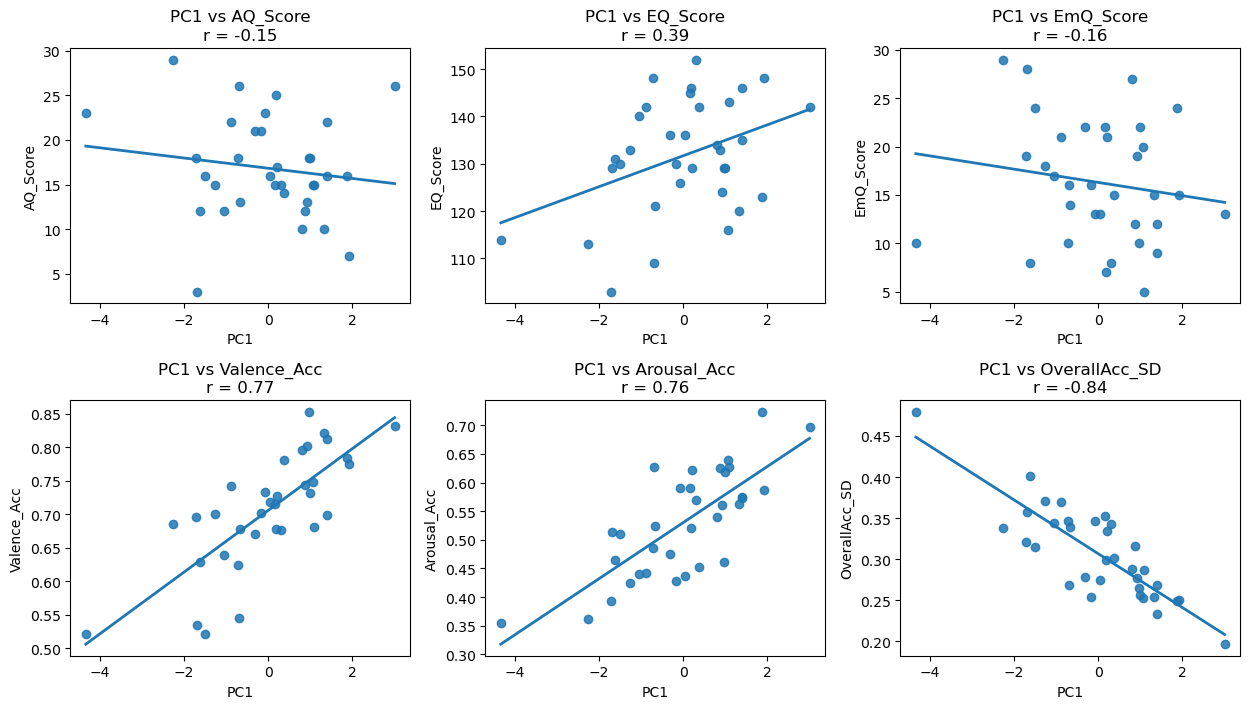


✓ Saved correlation scatter plot grid to: PC1_correlations_scatter.png
✓ Saved PC1 + median-split groups to: pc1_median_split_groups.csv


In [7]:
# ============================================================
# PCA (Option 2 + variability): Surveys + Val/Aro accuracy + SD(overall accuracy across videos)
# + PC1 → median split + print High/Low subject lists
# + correlation plots (PC1 vs each variable) with r shown
#
# REQUIREMENTS / EXPECTS THESE EXIST FROM YOUR PIPELINE ABOVE:
#   1) mean_corr_df with columns:
#        ['Subject','Mean_Valence_Corr','Mean_Arousal_Corr','Performance']  (Performance optional)
#   2) subject_video_performance with columns:
#        ['Subject','BaseVideo','Valence_Corr','Arousal_Corr','Performance']
#   3) survey_scores with columns:
#        ['Subject','AQ_Score','EQ_Score','EmQ_Score']
#
# OUTPUTS:
#   - pca_df: subject-level table with features + PC1 + group label
#   - corr_with_pc1: correlations of PC1 with all variables (Pearson)
#   - CSV saved: "pc1_median_split_groups.csv" in current working directory
#   - PNG saved: "PC1_correlations_scatter.png"
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import pearsonr

# ----------------------------
# 0) Guards / sanity checks
# ----------------------------
_required_mean = {"Subject","Mean_Valence_Corr","Mean_Arousal_Corr"}
_required_svp  = {"Subject","Performance"}
_required_surv = {"Subject","AQ_Score","EQ_Score","EmQ_Score"}

for name, df, req in [
    ("mean_corr_df", mean_corr_df, _required_mean),
    ("subject_video_performance", subject_video_performance, _required_svp),
    ("survey_scores", survey_scores, _required_surv),
]:
    missing = sorted(list(req - set(df.columns)))
    if missing:
        raise RuntimeError(f"{name} is missing required columns: {missing}")

# ----------------------------
# 1) Variability feature: SD across videos of overall accuracy
#    (overall accuracy = Performance per Subject×BaseVideo)
# ----------------------------
sv = subject_video_performance.copy()

perf_sd = (sv.groupby("Subject", as_index=False)["Performance"]
             .agg(OverallAcc_SD="std", n_videos="count"))
perf_sd.loc[perf_sd["n_videos"] < 2, "OverallAcc_SD"] = np.nan

# ----------------------------
# 2) Build feature table (subject-level)
#    Surveys + mean val/aro accuracy + SD(overall accuracy)
# ----------------------------
feat = (mean_corr_df[["Subject","Mean_Valence_Corr","Mean_Arousal_Corr"]]
        .merge(perf_sd[["Subject","OverallAcc_SD"]], on="Subject", how="left")
        .merge(survey_scores[["Subject","AQ_Score","EQ_Score","EmQ_Score"]], on="Subject", how="inner"))

feat = feat.rename(columns={
    "Mean_Valence_Corr": "Valence_Acc",
    "Mean_Arousal_Corr": "Arousal_Acc"
})

feat["Subject"] = feat["Subject"].astype(str)

# ----------------------------
# 3) Standardize (z-score) columns for PCA
# ----------------------------
pca_cols = ["AQ_Score","EQ_Score","EmQ_Score","Valence_Acc","Arousal_Acc","OverallAcc_SD"]

pca_in = feat[["Subject"] + pca_cols].copy()
pca_in = pca_in.replace([np.inf, -np.inf], np.nan)
pca_in_clean = pca_in.dropna(subset=pca_cols).copy()

if len(pca_in_clean) < 5:
    raise RuntimeError(f"Too few subjects with complete data for PCA: n={len(pca_in_clean)}")

X = pca_in_clean[pca_cols].to_numpy(dtype=float)
mu = np.nanmean(X, axis=0)
sd = np.nanstd(X, axis=0, ddof=1)
sd[~np.isfinite(sd) | (sd == 0)] = 1.0
Xz = (X - mu) / sd

# ----------------------------
# 4) PCA → PC1 scores
# ----------------------------
pca = PCA(n_components=2, random_state=0)
scores = pca.fit_transform(Xz)
pc1 = scores[:, 0].astype(float)

def _safe_corr(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 3:
        return np.nan
    return pearsonr(a[m], b[m])[0]

# Orient PC1 so "higher = higher EQ/EmQ & higher accuracy & lower AQ"
eq_r   = _safe_corr(pc1, pca_in_clean["EQ_Score"].to_numpy(float))
emq_r  = _safe_corr(pc1, pca_in_clean["EmQ_Score"].to_numpy(float))
aq_r   = _safe_corr(pc1, pca_in_clean["AQ_Score"].to_numpy(float))
val_r  = _safe_corr(pc1, pca_in_clean["Valence_Acc"].to_numpy(float))
aro_r  = _safe_corr(pc1, pca_in_clean["Arousal_Acc"].to_numpy(float))

score_direction = 0.0
score_direction += (0 if np.isnan(eq_r)  else eq_r)
score_direction += (0 if np.isnan(emq_r) else emq_r)
score_direction += (0 if np.isnan(val_r) else val_r)
score_direction += (0 if np.isnan(aro_r) else aro_r)
score_direction -= (0 if np.isnan(aq_r)  else aq_r)

if score_direction < 0:
    pc1 = -pc1

pc1_var = float(pca.explained_variance_ratio_[0])
pc2_var = float(pca.explained_variance_ratio_[1]) if pca.explained_variance_ratio_.size > 1 else np.nan

# ----------------------------
# 5) Median split groups
# ----------------------------
pc1_median = float(np.nanmedian(pc1))
group = np.where(pc1 >= pc1_median, "High_PC1", "Low_PC1")

# ----------------------------
# 6) Correlation of PC1 with all variables + loadings
# ----------------------------
pca_df = pca_in_clean.copy()
pca_df["PC1"] = pc1
pca_df["PC1_Group"] = group

corr_rows = []
for col in pca_cols:
    r = _safe_corr(pca_df["PC1"].to_numpy(float), pca_df[col].to_numpy(float))
    corr_rows.append({"Variable": col, "r_PC1": r})

corr_with_pc1 = pd.DataFrame(corr_rows).sort_values("r_PC1", ascending=False)

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_cols,
    columns=[f"PC{i+1}_loading" for i in range(pca.components_.shape[0])]
)

# ----------------------------
# 7) Print summary + High/Low lists
# ----------------------------
print("\n=== PCA summary ===")
print(f"n subjects used in PCA: {len(pca_df)}")
print(f"Explained variance: PC1={pc1_var:.3f}, PC2={pc2_var:.3f}")
print(f"Median(PC1) = {pc1_median:.3f}")
print(pca_df["PC1_Group"].value_counts())

high_ids = pca_df.loc[pca_df["PC1_Group"] == "High_PC1", "Subject"].tolist()
low_ids  = pca_df.loc[pca_df["PC1_Group"] == "Low_PC1",  "Subject"].tolist()

print("\n=== High_PC1 subject IDs ===")
print(high_ids)
print("\n=== Low_PC1 subject IDs ===")
print(low_ids)

print("\n=== Correlation: PC1 with each feature (Pearson r) ===")
print(corr_with_pc1.to_string(index=False))

print("\n=== PCA loadings (z-scored features) ===")
print(loadings.to_string())

# ----------------------------
# 8) Correlation scatter plots: PC1 vs each variable
#    Saves a single PNG + also shows it.
# ----------------------------
nvars = len(pca_cols)
ncols = 3
nrows = int(np.ceil(nvars / ncols))
plt.figure(figsize=(ncols*4.2, nrows*3.6))

for i, col in enumerate(pca_cols, start=1):
    ax = plt.subplot(nrows, ncols, i)
    x = pca_df["PC1"].to_numpy(float)
    y = pca_df[col].to_numpy(float)
    m = np.isfinite(x) & np.isfinite(y)

    ax.scatter(x[m], y[m], alpha=0.85)
    r = _safe_corr(x, y)
    ax.set_xlabel("PC1")
    ax.set_ylabel(col)
    ax.set_title(f"PC1 vs {col}\nr = {r:.2f}" if np.isfinite(r) else f"PC1 vs {col}\nr = NaN")

    # add a simple least-squares line (no confidence band; robust enough for quick check)
    if m.sum() >= 3:
        b1, b0 = np.polyfit(x[m], y[m], 1)
        xs = np.linspace(np.nanmin(x[m]), np.nanmax(x[m]), 100)
        ax.plot(xs, b1*xs + b0, linewidth=2)

plt.tight_layout()
out_png = "PC1_correlations_scatter.png"
plt.savefig(out_png, dpi=200)
plt.show()
print(f"\n✓ Saved correlation scatter plot grid to: {out_png}")

# ----------------------------
# 9) Save subject→PC1→group for your ISPS split analyses
# ----------------------------
out_csv = "pc1_median_split_groups.csv"
pca_df[["Subject","PC1","PC1_Group"] + pca_cols].to_csv(out_csv, index=False)
print(f"✓ Saved PC1 + median-split groups to: {out_csv}")

# If you want to merge groups back onto other dfs later:
#   subject_groups = pca_df[["Subject","PC1","PC1_Group"]].copy()




=== PCA summary ===
n subjects used in PCA: 34
Explained variance: PC1=0.357, PC2=0.257
Median(PC1) = 0.152
PC1_Group
High_PC1    17
Low_PC1     17
Name: count, dtype: int64

=== High_PC1 subject IDs ===
['pid008', 'pid009', 'pid015', 'pid019', 'pid035', 'pid024', 'pid027', 'pid004', 'pid006', 'pid014', 'pid029', 'pid020', 'pid016', 'pid013', 'pid007', 'pid026', 'pid012']

=== Low_PC1 subject IDs ===
['pid021', 'pid023', 'pid001', 'pid010', 'pid030', 'pid018', 'pid011', 'pid002', 'pid034', 'pid005', 'pid003', 'pid022', 'pid017', 'pid025', 'pid036', 'pid028', 'pid037']

=== Correlation: PC1 with each feature (Pearson r) ===
       Variable     r_PC1
Performance_Acc  0.890966
       EQ_Score  0.470083
       AQ_Score -0.163434
      EmQ_Score -0.217422
  OverallAcc_SD -0.834950

=== PCA loadings (z-scored features) ===
                 PC1_loading  PC2_loading
AQ_Score            0.122295    -0.055714
EQ_Score           -0.351757     0.610247
EmQ_Score           0.162694    -0.693275
Pe

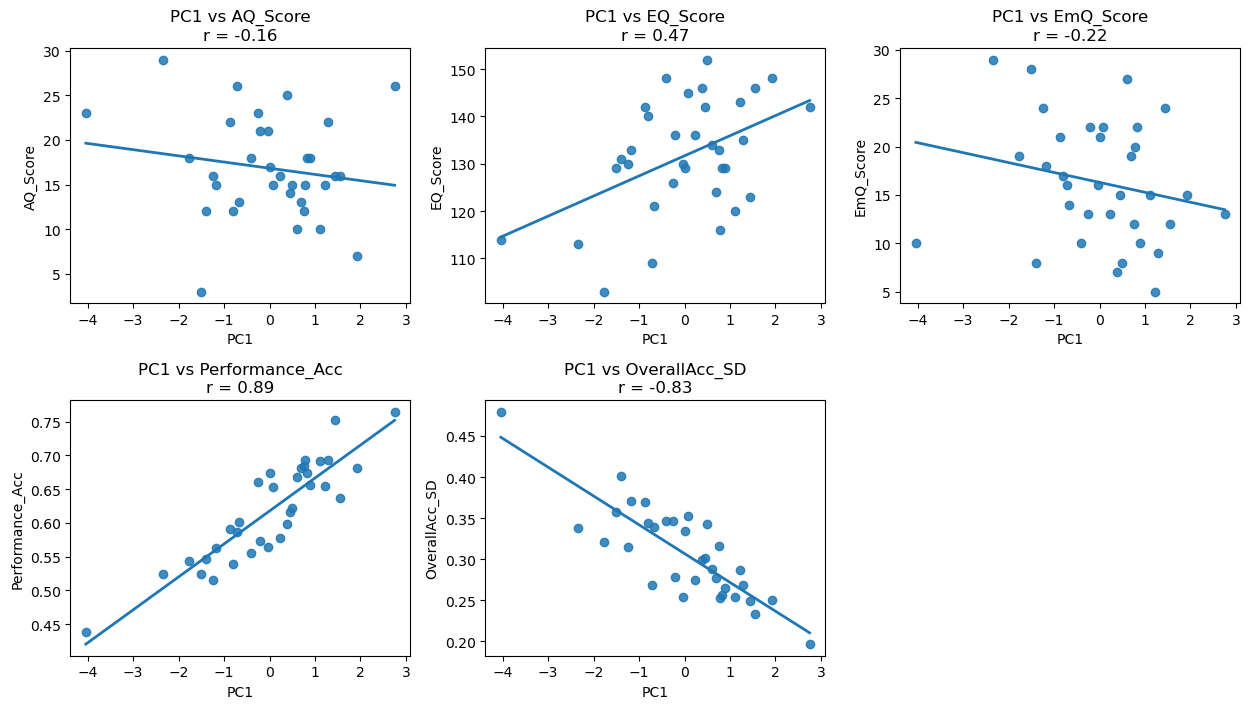


✓ Saved correlation scatter plot grid to: PC1_correlations_scatter.png
✓ Saved PC1 + median-split groups to: pc1_median_split_groups.csv


In [49]:
# ============================================================
# PCA (Option 2 + variability): Surveys + COMPOSITE Performance accuracy
# + SD(overall accuracy across videos)
# + PC1 → median split + print High/Low subject lists
# + correlation plots (PC1 vs each variable) with r shown
#
# CHANGE REQUESTED:
#   - Use ONLY the composite performance metric (mean_corr_df["Performance"])
#   - Do NOT use Mean_Valence_Corr / Mean_Arousal_Corr in the PCA features
#   - Keep outputs/plots/files the same style as before
#
# REQUIREMENTS / EXPECTS THESE EXIST FROM YOUR PIPELINE ABOVE:
#   1) mean_corr_df with columns:
#        ['Subject','Performance']   (composite performance)
#   2) subject_video_performance with columns:
#        ['Subject','Performance']   (per Subject×BaseVideo overall accuracy)
#   3) survey_scores with columns:
#        ['Subject','AQ_Score','EQ_Score','EmQ_Score']
#
# OUTPUTS (same filenames as before):
#   - pca_df: subject-level table with features + PC1 + group label
#   - corr_with_pc1: correlations of PC1 with all variables (Pearson)
#   - CSV saved: "pc1_median_split_groups.csv" in current working directory
#   - PNG saved: "PC1_correlations_scatter.png"
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import pearsonr

# ----------------------------
# 0) Guards / sanity checks
# ----------------------------
_required_mean = {"Subject", "Performance"}
_required_svp  = {"Subject", "Performance"}
_required_surv = {"Subject", "AQ_Score", "EQ_Score", "EmQ_Score"}

for name, df, req in [
    ("mean_corr_df", mean_corr_df, _required_mean),
    ("subject_video_performance", subject_video_performance, _required_svp),
    ("survey_scores", survey_scores, _required_surv),
]:
    missing = sorted(list(req - set(df.columns)))
    if missing:
        raise RuntimeError(f"{name} is missing required columns: {missing}")

# ----------------------------
# 1) Variability feature: SD across videos of overall accuracy
#    (overall accuracy = Performance per Subject×BaseVideo)
# ----------------------------
sv = subject_video_performance.copy()

perf_sd = (sv.groupby("Subject", as_index=False)["Performance"]
             .agg(OverallAcc_SD="std", n_videos="count"))
perf_sd.loc[perf_sd["n_videos"] < 2, "OverallAcc_SD"] = np.nan

# ----------------------------
# 2) Build feature table (subject-level)
#    Surveys + composite Performance accuracy + SD(overall accuracy)
# ----------------------------
feat = (mean_corr_df[["Subject", "Performance"]]
        .merge(perf_sd[["Subject", "OverallAcc_SD"]], on="Subject", how="left")
        .merge(survey_scores[["Subject", "AQ_Score", "EQ_Score", "EmQ_Score"]], on="Subject", how="inner"))

feat = feat.rename(columns={
    "Performance": "Performance_Acc"
})

feat["Subject"] = feat["Subject"].astype(str)

# ----------------------------
# 3) Standardize (z-score) columns for PCA
# ----------------------------
pca_cols = ["AQ_Score", "EQ_Score", "EmQ_Score", "Performance_Acc", "OverallAcc_SD"]

pca_in = feat[["Subject"] + pca_cols].copy()
pca_in = pca_in.replace([np.inf, -np.inf], np.nan)
pca_in_clean = pca_in.dropna(subset=pca_cols).copy()

if len(pca_in_clean) < 5:
    raise RuntimeError(f"Too few subjects with complete data for PCA: n={len(pca_in_clean)}")

X = pca_in_clean[pca_cols].to_numpy(dtype=float)
mu = np.nanmean(X, axis=0)
sd = np.nanstd(X, axis=0, ddof=1)
sd[~np.isfinite(sd) | (sd == 0)] = 1.0
Xz = (X - mu) / sd

# ----------------------------
# 4) PCA → PC1 scores
# ----------------------------
pca = PCA(n_components=2, random_state=0)
scores = pca.fit_transform(Xz)
pc1 = scores[:, 0].astype(float)

def _safe_corr(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 3:
        return np.nan
    return pearsonr(a[m], b[m])[0]

# Orient PC1 so "higher = higher EQ/EmQ & higher accuracy & lower AQ"
eq_r   = _safe_corr(pc1, pca_in_clean["EQ_Score"].to_numpy(float))
emq_r  = _safe_corr(pc1, pca_in_clean["EmQ_Score"].to_numpy(float))
aq_r   = _safe_corr(pc1, pca_in_clean["AQ_Score"].to_numpy(float))
perf_r = _safe_corr(pc1, pca_in_clean["Performance_Acc"].to_numpy(float))

score_direction = 0.0
score_direction += (0 if np.isnan(eq_r)   else eq_r)
score_direction += (0 if np.isnan(emq_r)  else emq_r)
score_direction += (0 if np.isnan(perf_r) else perf_r)
score_direction -= (0 if np.isnan(aq_r)   else aq_r)

if score_direction < 0:
    pc1 = -pc1

pc1_var = float(pca.explained_variance_ratio_[0])
pc2_var = float(pca.explained_variance_ratio_[1]) if pca.explained_variance_ratio_.size > 1 else np.nan

# ----------------------------
# 5) Median split groups
# ----------------------------
pc1_median = float(np.nanmedian(pc1))
group = np.where(pc1 >= pc1_median, "High_PC1", "Low_PC1")

# ----------------------------
# 6) Correlation of PC1 with all variables + loadings
# ----------------------------
pca_df = pca_in_clean.copy()
pca_df["PC1"] = pc1
pca_df["PC1_Group"] = group

corr_rows = []
for col in pca_cols:
    r = _safe_corr(pca_df["PC1"].to_numpy(float), pca_df[col].to_numpy(float))
    corr_rows.append({"Variable": col, "r_PC1": r})

corr_with_pc1 = pd.DataFrame(corr_rows).sort_values("r_PC1", ascending=False)

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_cols,
    columns=[f"PC{i+1}_loading" for i in range(pca.components_.shape[0])]
)

# ----------------------------
# 7) Print summary + High/Low lists
# ----------------------------
print("\n=== PCA summary ===")
print(f"n subjects used in PCA: {len(pca_df)}")
print(f"Explained variance: PC1={pc1_var:.3f}, PC2={pc2_var:.3f}")
print(f"Median(PC1) = {pc1_median:.3f}")
print(pca_df["PC1_Group"].value_counts())

high_ids = pca_df.loc[pca_df["PC1_Group"] == "High_PC1", "Subject"].tolist()
low_ids  = pca_df.loc[pca_df["PC1_Group"] == "Low_PC1",  "Subject"].tolist()

print("\n=== High_PC1 subject IDs ===")
print(high_ids)
print("\n=== Low_PC1 subject IDs ===")
print(low_ids)

print("\n=== Correlation: PC1 with each feature (Pearson r) ===")
print(corr_with_pc1.to_string(index=False))

print("\n=== PCA loadings (z-scored features) ===")
print(loadings.to_string())

# ----------------------------
# 8) Correlation scatter plots: PC1 vs each variable
#    Saves a single PNG + also shows it.
# ----------------------------
nvars = len(pca_cols)
ncols = 3
nrows = int(np.ceil(nvars / ncols))
plt.figure(figsize=(ncols*4.2, nrows*3.6))

for i, col in enumerate(pca_cols, start=1):
    ax = plt.subplot(nrows, ncols, i)
    x = pca_df["PC1"].to_numpy(float)
    y = pca_df[col].to_numpy(float)
    m = np.isfinite(x) & np.isfinite(y)

    ax.scatter(x[m], y[m], alpha=0.85)
    r = _safe_corr(x, y)
    ax.set_xlabel("PC1")
    ax.set_ylabel(col)
    ax.set_title(f"PC1 vs {col}\nr = {r:.2f}" if np.isfinite(r) else f"PC1 vs {col}\nr = NaN")

    # add a simple least-squares line (no confidence band; robust enough for quick check)
    if m.sum() >= 3:
        b1, b0 = np.polyfit(x[m], y[m], 1)
        xs = np.linspace(np.nanmin(x[m]), np.nanmax(x[m]), 100)
        ax.plot(xs, b1*xs + b0, linewidth=2)

plt.tight_layout()
out_png = "PC1_correlations_scatter.png"
plt.savefig(out_png, dpi=200)
plt.show()
print(f"\n✓ Saved correlation scatter plot grid to: {out_png}")

# ----------------------------
# 9) Save subject→PC1→group for your ISPS split analyses
# ----------------------------
out_csv = "pc1_median_split_groups.csv"
pca_df[["Subject", "PC1", "PC1_Group"] + pca_cols].to_csv(out_csv, index=False)
print(f"✓ Saved PC1 + median-split groups to: {out_csv}")

# If you want to merge groups back onto other dfs later:
#   subject_groups = pca_df[["Subject","PC1","PC1_Group"]].copy()

In [11]:
pca_df

,Subject,AQ_Score,EQ_Score,EmQ_Score,Valence_Acc,Arousal_Acc,OverallAcc_SD,PC1,PC1_Group
0,pid008,13,124,19,0.801066,0.561459,0.277049,0.927593,High_PC1
1,pid021,23,114,10,0.521835,0.353910,0.479050,-4.326791,Low_PC1
2,pid023,12,131,8,0.628503,0.464864,0.401016,-1.611859,Low_PC1
3,pid001,18,103,19,0.695283,0.392981,0.321415,-1.707052,Low_PC1
4,pid010,23,126,13,0.732521,0.589955,0.346265,-0.082820,Low_PC1
5,pid009,10,134,27,0.796240,0.539700,0.288278,0.796274,High_PC1
6,pid015,7,148,15,0.775066,0.586787,0.249913,1.910064,High_PC1
7,pid019,15,152,8,0.676342,0.568736,0.342292,0.304982,High_PC1
8,pid030,13,121,14,0.678081,0.524209,0.338985,-0.667999,Low_PC1
9,pid035,15,143,5,0.680978,0.627670,0.286906,1.096820,High_PC1


In [ ]:
### REDO THE CODE PROVIDED BELOW AND STANDARDIZE THE SURVEY SCORES AND CORRELATE TO STANDARDIZED VARIANCE

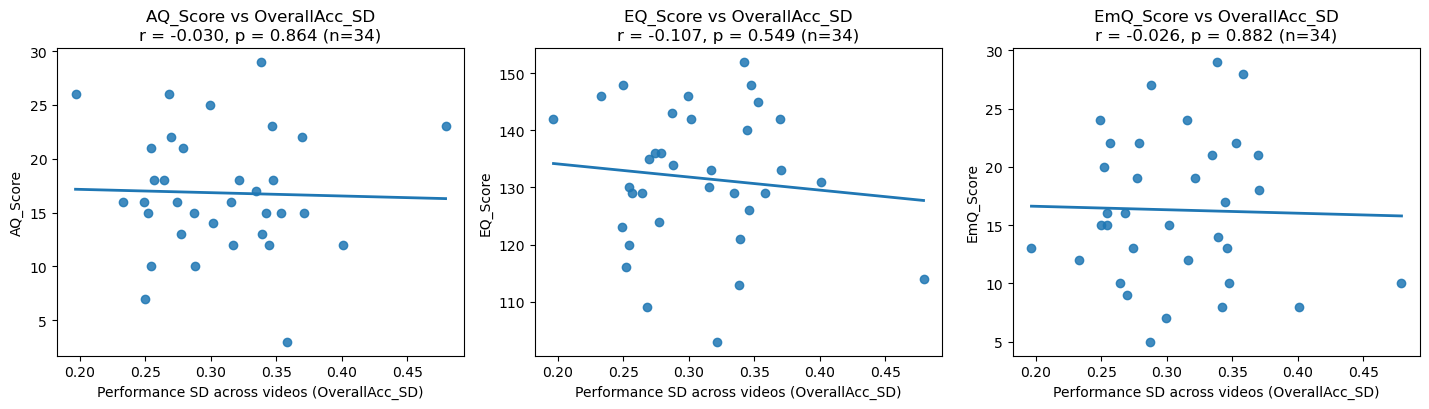

✓ Saved: PerformanceSD_vs_Surveys_scatter.png

=== Correlations: OverallAcc_SD vs Surveys (Pearson) ===
   Survey         r        p  n
 AQ_Score -0.030446 0.864281 34
 EQ_Score -0.106568 0.548600 34
EmQ_Score -0.026425 0.882069 34


In [85]:
# ============================================================
# DROP-IN: Correlate Performance SD across videos (OverallAcc_SD)
#          with each survey score (AQ/EQ/EmQ) + scatter plots
#          with regression line and r,p in title.
#
# Expects from cell above:
#   - perf_sd with columns: ['Subject','OverallAcc_SD','n_videos']
#   - survey_scores with columns: ['Subject','AQ_Score','EQ_Score','EmQ_Score']
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- build analysis dataframe ---
sd_survey = (
    perf_sd[["Subject", "OverallAcc_SD"]]
      .merge(survey_scores[["Subject", "AQ_Score", "EQ_Score", "EmQ_Score"]], on="Subject", how="inner")
)

# coerce numeric, drop missing
for c in ["OverallAcc_SD", "AQ_Score", "EQ_Score", "EmQ_Score"]:
    sd_survey[c] = pd.to_numeric(sd_survey[c], errors="coerce")

sd_survey = sd_survey.replace([np.inf, -np.inf], np.nan)
sd_survey = sd_survey.dropna(subset=["OverallAcc_SD"]).copy()

def _pearson_r_p(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return np.nan, np.nan, int(m.sum())
    r, p = pearsonr(x[m], y[m])
    return float(r), float(p), int(m.sum())

surv_cols = ["AQ_Score", "EQ_Score", "EmQ_Score"]

# --- plot grid ---
ncols = 3
nrows = 1
plt.figure(figsize=(ncols * 4.8, 4.2))

x = sd_survey["OverallAcc_SD"].to_numpy(float)

for i, col in enumerate(surv_cols, start=1):
    ax = plt.subplot(nrows, ncols, i)
    y = sd_survey[col].to_numpy(float)

    r, p, n = _pearson_r_p(x, y)
    m = np.isfinite(x) & np.isfinite(y)

    ax.scatter(x[m], y[m], alpha=0.85)
    ax.set_xlabel("Performance SD across videos (OverallAcc_SD)")
    ax.set_ylabel(col)

    # regression line
    if n >= 3:
        b1, b0 = np.polyfit(x[m], y[m], 1)
        xs = np.linspace(np.nanmin(x[m]), np.nanmax(x[m]), 100)
        ax.plot(xs, b1 * xs + b0, linewidth=2)

    if np.isfinite(r) and np.isfinite(p):
        ax.set_title(f"{col} vs OverallAcc_SD\nr = {r:.3f}, p = {p:.3g} (n={n})")
    else:
        ax.set_title(f"{col} vs OverallAcc_SD\nr/p = NaN (n={n})")

plt.tight_layout()
out_png = "PerformanceSD_vs_Surveys_scatter.png"
plt.savefig(out_png, dpi=200)
plt.show()
print(f"✓ Saved: {out_png}")

# --- optional: print a small table of results ---
rows = []
for col in surv_cols:
    r, p, n = _pearson_r_p(sd_survey["OverallAcc_SD"], sd_survey[col])
    rows.append({"Survey": col, "r": r, "p": p, "n": n})

sd_survey_corrs = pd.DataFrame(rows)
print("\n=== Correlations: OverallAcc_SD vs Surveys (Pearson) ===")
print(sd_survey_corrs.to_string(index=False))


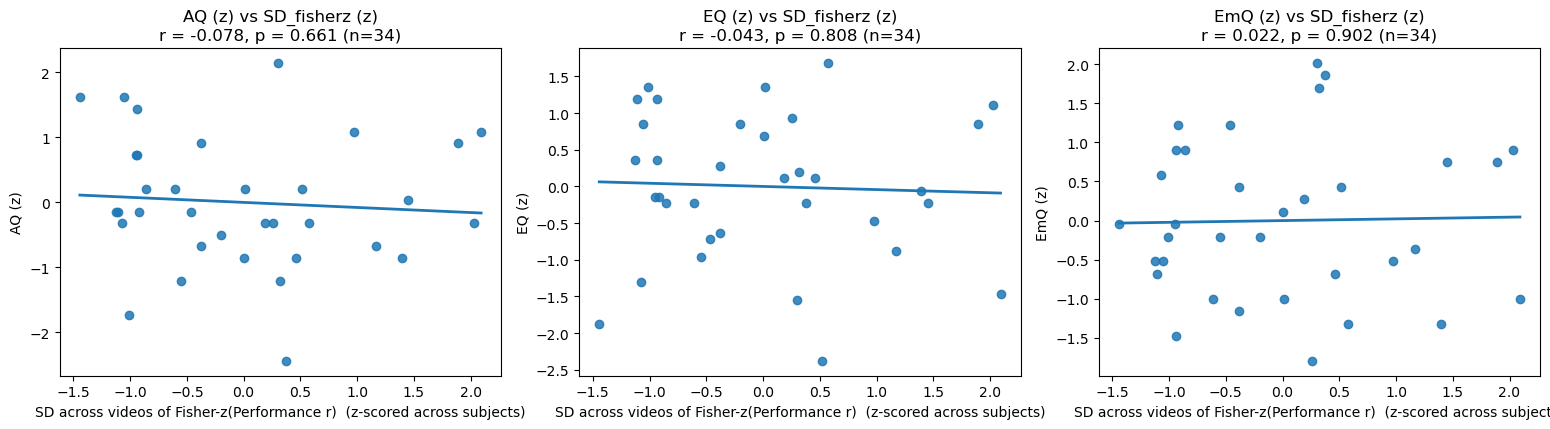

✓ Saved: Perf_SD_fisherz_vs_SurveysZ_scatter.png

=== Correlations: z(SD Fisher-z Performance) vs z(Surveys) (Pearson) ===
 Survey         r        p  n
 AQ (z) -0.078074 0.660740 34
 EQ (z) -0.043191 0.808365 34
EmQ (z)  0.022033 0.901568 34

Sanity check: SD_fisherz summary
count    34.000000
mean      0.537351
std       0.078430
min       0.424128
25%       0.464209
50%       0.529671
75%       0.576690
max       0.701413
Name: SD_fisherz, dtype: float64


In [97]:
# ============================================================
# DROP-IN (UPDATED): Correlate variability in performance across videos
# with each survey score, where performance r is Fisher-z transformed
# BEFORE computing within-subject variability.
#
# What this does:
#   1) Fisher-z each video Performance r: z = atanh(r)
#   2) For each Subject: SD_z = std(z across videos)  [variability metric]
#   3) Z-score (standardize) SD_z across subjects and also each survey across subjects
#   4) Correlate (Pearson) SD_z_std with each survey_z + scatter with regression line
#
# Expects from cell above:
#   - subject_video_performance with columns: ['Subject','Performance']
#       (ideally one row per Subject×Video; video column not required for SD)
#   - survey_scores with columns: ['Subject','AQ_Score','EQ_Score','EmQ_Score']
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# -----------------------------
# helpers
# -----------------------------
def _zscore(x):
    x = np.asarray(x, float)
    mu = np.nanmean(x)
    sd = np.nanstd(x, ddof=1)
    if (not np.isfinite(sd)) or sd == 0:
        return x * np.nan  # no variance -> undefined z
    return (x - mu) / sd

def _pearson_r_p(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return np.nan, np.nan, int(m.sum())
    r, p = pearsonr(x[m], y[m])
    return float(r), float(p), int(m.sum())

# -----------------------------
# 1) Build per-subject SD of Fisher-z(Performance r)
# -----------------------------
sv = subject_video_performance.copy()

# coerce + clean
sv["Subject"] = sv["Subject"].astype(str)
sv["Performance"] = pd.to_numeric(sv["Performance"], errors="coerce")
sv = sv.replace([np.inf, -np.inf], np.nan)
sv = sv.dropna(subset=["Performance"]).copy()

# Fisher-z transform; clip r to avoid infinities at |r|=1
r_clip = np.clip(sv["Performance"].to_numpy(float), -0.999999, 0.999999)
sv["Perf_fisher_z"] = np.arctanh(r_clip)

perf_var = (sv.groupby("Subject", as_index=False)["Perf_fisher_z"]
              .agg(SD_fisherz="std", n_videos="count"))

# need at least 2 videos to define SD
perf_var.loc[perf_var["n_videos"] < 2, "SD_fisherz"] = np.nan

# -----------------------------
# 2) Merge with surveys + standardize across subjects
# -----------------------------
sd_survey = (
    perf_var[["Subject", "SD_fisherz", "n_videos"]]
      .merge(survey_scores[["Subject", "AQ_Score", "EQ_Score", "EmQ_Score"]], on="Subject", how="inner")
)

for c in ["SD_fisherz", "AQ_Score", "EQ_Score", "EmQ_Score"]:
    sd_survey[c] = pd.to_numeric(sd_survey[c], errors="coerce")

sd_survey = sd_survey.replace([np.inf, -np.inf], np.nan)
sd_survey = sd_survey.dropna(subset=["SD_fisherz", "AQ_Score", "EQ_Score", "EmQ_Score"]).copy()

# standardize outcome + surveys across subjects
sd_survey["SD_fisherz_z"] = _zscore(sd_survey["SD_fisherz"].to_numpy(float))
sd_survey["AQ_z"] = _zscore(sd_survey["AQ_Score"].to_numpy(float))
sd_survey["EQ_z"] = _zscore(sd_survey["EQ_Score"].to_numpy(float))
sd_survey["EmQ_z"] = _zscore(sd_survey["EmQ_Score"].to_numpy(float))

# -----------------------------
# 3) Scatter plots + correlations
# -----------------------------
surv_cols = [("AQ_z", "AQ (z)"), ("EQ_z", "EQ (z)"), ("EmQ_z", "EmQ (z)")]

ncols = 3
plt.figure(figsize=(ncols * 5.2, 4.4))

x = sd_survey["SD_fisherz_z"].to_numpy(float)

rows = []
for i, (col, label) in enumerate(surv_cols, start=1):
    ax = plt.subplot(1, ncols, i)
    y = sd_survey[col].to_numpy(float)

    r, p, n = _pearson_r_p(x, y)
    m = np.isfinite(x) & np.isfinite(y)

    ax.scatter(x[m], y[m], alpha=0.85)
    ax.set_xlabel("SD across videos of Fisher-z(Performance r)  (z-scored across subjects)")
    ax.set_ylabel(label)

    # regression line
    if n >= 3:
        b1, b0 = np.polyfit(x[m], y[m], 1)
        xs = np.linspace(np.nanmin(x[m]), np.nanmax(x[m]), 100)
        ax.plot(xs, b1 * xs + b0, linewidth=2)

    ax.set_title(f"{label} vs SD_fisherz (z)\nr = {r:.3f}, p = {p:.3g} (n={n})" if np.isfinite(r) else f"{label} vs SD_fisherz (z)\nr/p = NaN (n={n})")

    rows.append({"Survey": label, "r": r, "p": p, "n": n})

plt.tight_layout()
out_png = "Perf_SD_fisherz_vs_SurveysZ_scatter.png"
plt.savefig(out_png, dpi=200)
plt.show()
print(f"✓ Saved: {out_png}")

sd_survey_corrs = pd.DataFrame(rows)
print("\n=== Correlations: z(SD Fisher-z Performance) vs z(Surveys) (Pearson) ===")
print(sd_survey_corrs.to_string(index=False))

# Optional: quick sanity check of variability metric
print("\nSanity check: SD_fisherz summary")
print(sd_survey["SD_fisherz"].describe())


In [ ]:
# # ============================================
# # BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# # + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# # ============================================
# import os
# import re
# import math
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from collections import defaultdict
# from itertools import compress
# from scipy.stats import pearsonr, spearmanr
# from scipy.signal import butter, filtfilt, hilbert, find_peaks
# from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

# import mne
# from mne.preprocessing.nirs import (
#     optical_density,
#     beer_lambert_law,
#     temporal_derivative_distribution_repair,
# )

# # -----------------------
# # Paths & basic config
# # -----------------------
# beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"
# mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
# root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
# save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
# os.makedirs(save_dir_corrmats, exist_ok=True)

# # -----------------------
# # ISPS / Behavior toggles
# # -----------------------
# ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
# BEHAV_REF   = "pca"          # 'mean' or 'pca' (PC1 consensus)
# LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
# HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
# XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# # >>> NEW: combination toggle for valence + arousal into a single performance time series
# BEHAV_COMBINE = "pca"        # 'mean' or 'pca' for combining valence+arousal into ONE series

# # -----------------------
# # Task video durations (s) for odd triggers
# # -----------------------
# durations = {
#     '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
#     '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
#     '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
#     '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
# }

# # -----------------------
# # ROI definitions (HbO channels)
# # -----------------------
# roi_definitions = {
#     "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
#     "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
#     "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
#     "Left OFC": ['S1_D15 hbo'],
#     "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
#     "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
#     "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
#     "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
#     "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
#     "Right OFC": ['S6_D15 hbo'],
#     "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
#     "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
# }

# # -----------------------
# # Utility functions
# # -----------------------
# def _norm_key_for_indexing(key: str) -> str:
#     s = str(key).lower()
#     s = s.replace("\\", "/")
#     s = os.path.splitext(os.path.basename(s))[0]
#     s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
#     return s

# # NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
# def _base_video_norm(key: str) -> str:
#     s = _norm_key_for_indexing(key)
#     # remove domain / meta tokens commonly present in behavior columns
#     s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
#     # remove trailing domain-like suffixes such as "_v" or "_a" if used
#     s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
#     s = re.sub(r'\s+', ' ', s).strip()
#     return s

# def crop_to_min_len(arr_list):
#     L = min(len(a) for a in arr_list if a is not None)
#     return [a[:L] for a in arr_list if a is not None], L

# def moving_average(x, w):
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k//2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k)/k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if np.all(~np.isfinite(x)) or len(x) < 5*order:
#         return np.array(x, float)
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def circ_shift(arr, k):
#     """circular shift by k samples (k>0 moves series to the right)."""
#     if k == 0 or len(arr) == 0:
#         return arr
#     k = int(k) % len(arr)
#     return np.concatenate([arr[-k:], arr[:-k]])

# def abs_derivative(x, fs=1.5):
#     dx = np.abs(np.diff(x, prepend=x[:1]))
#     k = int(round(3*fs))  # light smoothing
#     if k > 1:
#         xp = np.pad(dx, (k//2, k//2), mode="edge")
#         ker = np.ones(k)/k
#         dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
#     return dx

# def CCT_average(df, return_ev=False):
#     """
#     FactorAnalyzer PC1 helper with robust guards.
#     Expects df as T×S (rows=time, cols=subjects). NaNs should be dropped beforehand.
#     """
#     if df.empty:
#         raise ValueError("CCT_average received empty DataFrame after NaN drop.")
#     n_factors = max(1, min(3, df.shape[1]))
#     fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
#     fa.fit(df, n_factors)
#     ev, _ = fa.get_eigenvalues()
#     ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
#     consensus = fa.transform(df)[:, 0]
#     return (consensus, ev_ratio) if return_ev else consensus

# # -----------------------
# # Load behavioral time series (per-participant CSVs)
# # Each file has columns = video names (e.g., "...valence", "...arousal")
# # -----------------------
# data_by_video = {}
# for csv_file in os.listdir(beh_root):
#     if not csv_file.endswith(".csv"):
#         continue
#     path = os.path.join(beh_root, csv_file)
#     subject_id = os.path.splitext(csv_file)[0]
#     try:
#         df = pd.read_csv(path)
#         # drop the first column if it's an index column
#         if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
#             df = df.drop(df.columns[0], axis=1)
#         for col in df.columns:
#             if col not in data_by_video:
#                 data_by_video[col] = {}
#             data_by_video[col][subject_id] = df[col].values
#     except Exception as e:
#         print(f"Error reading {csv_file}: {e}")

# valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
# arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# # -----------------------
# # Trigger ↔ Video-name mapping (CSV)  (columns: 'video', 'trigger_number')
# # -----------------------
# map_df = pd.read_csv(mapping_csv)
# lower_cols = {c.lower(): c for c in map_df.columns}
# if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
#     raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
#                      f"Found: {list(map_df.columns)}")

# col_video = lower_cols['video']
# col_trig  = lower_cols['trigger_number']

# map_df = map_df[[col_video, col_trig]].copy()
# map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
# map_df = map_df.dropna(subset=["Trigger_int"]).copy()
# map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
# map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
# TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# # Pre-index behavioral dicts by normalized key
# # (A) Exact normalized column names (unchanged)
# def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
#     idx = {}
#     for k in beh_dict.keys():
#         nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
#         idx.setdefault(nk, []).append(k)
#     return idx

# # (B) NEW: base video-name indexes (domain stripped) so mapping "video" matches both "...valence" and "...arousal"
# BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
# BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)

# # keep the original (exact) indexes around as a fallback if needed
# BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
# BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

# def _choose_best(candidates):
#     if not candidates:
#         return None
#     def _score(name):
#         n = str(name).lower()
#         return (("baseline" in n), len(n))
#     return sorted(candidates, key=_score)[0]

# def _match_behavior_key_for_trigger(t_int, which="arousal"):
#     """
#     Use mapping CSV's normalized base video name to find the corresponding
#     behavior column for the desired domain (arousal/valence).
#     """
#     vidnorm = TRIG2VIDNAME.get(int(t_int), None)
#     if vidnorm is None:
#         return None

#     # First try base-name index (domain stripped) — primary path
#     base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
#     if vidnorm in base_index:
#         return _choose_best(base_index[vidnorm])

#     # Fallback 1: try exact (domain-including) index if the mapping already contains domain terms
#     name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
#     if vidnorm in name_index:
#         return _choose_best(name_index[vidnorm])

#     # Fallback 2: token-overlap search on base names
#     tokens = [tok for tok in vidnorm.split() if tok]
#     cands = []
#     for nk, keys in base_index.items():
#         nktoks = nk.split()
#         shared = len(set(tokens).intersection(nktoks))
#         if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
#             cands.extend(keys)
#     return _choose_best(cands)

# # Build unified ratings store by trigger using the mapping
# ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][kind] = np.array
# unmatched = []  # diagnostics

# for t_int in sorted(TRIG2VIDNAME.keys()):
#     t_key = str(t_int)
#     k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
#     if k_aro is not None:
#         for subj, arr in arousal_videos[k_aro].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "arousal"))

#     k_val = _match_behavior_key_for_trigger(t_int, which="valence")
#     if k_val is not None:
#         for subj, arr in valence_videos[k_val].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["valence"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "valence"))

# HAVE_BEHAVIOR = len(ratings) > 0
# print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
# if unmatched:
#     # Helpful to see if any triggers (e.g., 41–55) still missed; safe to leave in.
#     missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
#     print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# # -----------------------
# # fNIRS preprocessing (Task)
# # -----------------------
# def individual_analysis(filepath):
#     file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
#     for i, desc in enumerate(file.annotations.description):
#         if desc in durations:
#             file.annotations.duration[i] = durations[desc]
#     even = [str(x) for x in range(2, 57, 2)]
#     unwanted = np.nonzero(np.isin(file.annotations.description, even))
#     file.annotations.delete(unwanted)
#     raw_od = optical_density(file)
#     raw_od1 = temporal_derivative_distribution_repair(raw_od)
#     sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
#     bads = list(compress(raw_od1.ch_names, sci < 0.5))
#     raw_od1.info["bads"] = bads
#     if bads:
#         print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
#         raw_od1 = raw_od1.copy().drop_channels(bads)
#     else:
#         print("No bad channels to drop (SCI < 0.5).")
#     raw = beer_lambert_law(raw_od1, ppf=0.1)
#     raw.resample(1.5)
#     return raw

# def segment_by_trigger(raw):
#     events, event_ids = mne.events_from_annotations(raw, verbose=False)
#     epochs_dict = {}
#     for trig_str, trig_id in event_ids.items():
#         if trig_str not in durations:
#             continue
#         these = events[events[:, 2] == trig_id]
#         if len(these) == 0:
#             continue
#         epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
#                             tmin=0, tmax=durations[trig_str],
#                             baseline=None, detrend=None, preload=True, verbose=False)
#         epochs_dict[trig_str] = epochs
#     return epochs_dict

# def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
#     name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
#     idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
#     if not idxs:
#         return None
#     return data_2d[idxs].mean(axis=0)

# # Load & cache ROI time series (SUBJECT × TRIGGER × ROI)
# all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
# subjects = [os.path.splitext(f)[0][:6] for f in all_files]

# subject_epochs = {}
# roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subj][trig][roi] = 1D np.array

# for sid, fname in zip(subjects, all_files):
#     raw = individual_analysis(os.path.join(root, fname))
#     epdict = segment_by_trigger(raw)
#     subject_epochs[sid] = epdict
#     for trig, epochs in epdict.items():
#         dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
#         ch_names = epochs.ch_names
#         for roi, chans in roi_definitions.items():
#             ts = extract_roi_time_series_np(dat, ch_names, chans)
#             if ts is not None:
#                 roi_ts[sid][trig][roi] = ts

# subjects = list(subject_epochs.keys())
# triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
# rois = list(roi_definitions.keys())

# # -----------------------
# # ROI pass/fail → kept triggers
# # -----------------------
# alpha = 0.051
# MIN_SUBJ_WITH_DATA = 27
# p_sig_required = 0.6

# roi_pass_by_trig = defaultdict(dict)
# roi_has_data_by_trig = defaultdict(set)
# roi_sig_counts_by_trig = defaultdict(dict)
# roi_n_by_trig = defaultdict(dict)

# for trig in triggers:
#     for roi in rois:
#         subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
#         S = len(subj_with_data)
#         if S < MIN_SUBJ_WITH_DATA:
#             continue
#         min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
#         X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
#         roi_has_data_by_trig[trig].add(roi)
#         X_sum = X.sum(axis=0)
#         sig_count = 0
#         for i in range(S):
#             loo_mean = (X_sum - X[i]) / (S - 1)
#             r, p = pearsonr(X[i], loo_mean)
#             if not np.isnan(r) and p < alpha:
#                 sig_count += 1
#         required = math.ceil(p_sig_required * S)
#         roi_sig_counts_by_trig[trig][roi] = sig_count
#         roi_n_by_trig[trig][roi] = S
#         roi_pass_by_trig[trig][roi] = (sig_count >= required)

# kept_triggers, dropped_triggers = [], []
# for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
#     rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
#     if len(rois_with_data) == 0:
#         dropped_triggers.append(trig)
#         continue
#     n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
#     threshold = math.ceil(len(rois_with_data) / 2.0)
#     if n_pass >= threshold:
#         kept_triggers.append(trig)
#     else:
#         dropped_triggers.append(trig)

# print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
# triggers = kept_triggers

# # ======================================================
# # DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# # ======================================================
# FS = 1.5                    # sampling rate
# BP = (0.01, 0.50)           # Hz
# SMOOTH_SEC = 7.0
# PEAK_MIN_DISTANCE_SEC = 5.0
# PEAK_PROMINENCE = 0.04
# N_PERM = 100
# RNG = np.random.default_rng(2025)

# def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
#     """
#     P: phases shape (S, T). Return ISPS(t) per chosen metric.
#     - 'kuramoto'     : |mean e^{iφ}|
#     - 'pairwise_sine': 1 - mean_ij[ sin(|Δφ_ij|) ]
#     """
#     if ISPS_METRIC == "kuramoto":
#         z = np.exp(1j * P)                 # (S, T)
#         m = np.nanmean(z, axis=0)          # (T,)
#         isps = np.abs(m)
#     elif ISPS_METRIC == "pairwise_sine":
#         S, T = P.shape
#         isps = np.empty(T, float)
#         for t in range(T):
#             ph = P[:, t]
#             d = ph[:, None] - ph[None, :]
#             d = (d + np.pi) % (2*np.pi) - np.pi
#             iu = np.triu_indices(S, k=1)
#             isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
#     else:
#         raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
#     w = int(round(smooth_sec * fs))
#     return moving_average(isps, max(1, w))

# def _group_ref_from_traces(traces_2d, mode):
#     """
#     traces_2d: np.array shape (S, T) across subjects for a domain.
#     mode: 'mean' or 'pca'
#     Returns a 1D group reference array (length ≤ T).
#     """
#     if traces_2d.size == 0:
#         return None
#     if mode == "pca":
#         df = pd.DataFrame(traces_2d.T)     # T × S
#         df = df.dropna(axis=0, how="any")  # drop rows containing NaNs before PCA
#         if df.shape[0] < 5 or df.shape[1] < 1:
#             return np.nanmean(traces_2d, axis=0)
#         pc1 = CCT_average(df, return_ev=False)
#         return np.asarray(pc1, float)
#     else:
#         return np.nanmean(traces_2d, axis=0)

# # >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
# def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
#     """
#     Returns a 1D performance series (same length), using either simple average or PC1 across
#     the two domains. If only one domain is present, it is passed through unchanged.
#     PCA path standardizes each domain and orients PC1 to have positive correlation with arousal.
#     """
#     if (val_ref is None) and (aro_ref is None):
#         return None
#     if (val_ref is not None) and (aro_ref is not None):
#         L = min(len(val_ref), len(aro_ref))
#         v = np.asarray(val_ref[:L], float)
#         a = np.asarray(aro_ref[:L], float)
#         if mode == "mean":
#             return 0.5 * (v + a)
#         elif mode == "pca":
#             v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
#             a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
#             X = np.vstack([v_z, a_z]).T  # T x 2
#             X = X - np.nanmean(X, axis=0, keepdims=True)
#             U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
#             pc1_timecourse = U[:, 0] * S[0]
#             if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
#                 pc1_timecourse = -pc1_timecourse
#             return pc1_timecourse.astype(float)
#         else:
#             raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
#     else:
#         return val_ref if val_ref is not None else aro_ref

# def behavior_performance_for_trig(trig, ratings):
#     """
#     Build ONE 'performance' time series for a trigger by:
#       1) computing group references for valence and arousal (mean or PCA),
#       2) combining the two via BEHAV_COMBINE ('mean' or 'pca').
#     Falls back gracefully if only one domain is available.
#     """
#     val_list, aro_list = [], []
#     for s in ratings:
#         if trig in ratings[s]:
#             if "valence" in ratings[s][trig]:
#                 val_list.append(np.asarray(ratings[s][trig]["valence"], float))
#             if "arousal" in ratings[s][trig]:
#                 aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

#     val_ref = None
#     aro_ref = None

#     if len(val_list) > 0:
#         val_list, _ = crop_to_min_len(val_list)
#         V = np.stack(val_list, 0)  # (S, T_v)
#         val_ref = _group_ref_from_traces(V, BEHAV_REF)

#     if len(aro_list) > 0:
#         aro_list, _ = crop_to_min_len(aro_list)
#         A = np.stack(aro_list, 0)  # (S, T_a)
#         aro_ref = _group_ref_from_traces(A, BEHAV_REF)

#     if (val_ref is None) and (aro_ref is None):
#         return None

#     # >>> NEW: use toggle to combine valence+arousal
#     return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

# def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
#     isps_by_roi = {}
#     n_subj_by_roi = {}
#     for roi in rois:
#         series = []
#         for s in roi_ts:
#             ts = roi_ts[s].get(trig, {}).get(roi, None)
#             if ts is not None and np.isfinite(ts).any():
#                 series.append(np.asarray(ts, float))
#         if len(series) < 3:
#             continue
#         series, L = crop_to_min_len(series)
#         X = np.stack(series, axis=0)  # (S, T)
#         Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
#         P = np.angle(hilbert(Xbp, axis=1))            # (S, T)
#         isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
#         isps_by_roi[roi] = isps
#         n_subj_by_roi[roi] = X.shape[0]
#     return isps_by_roi, n_subj_by_roi

# def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
#     distance = int(round(min_distance_sec * fs))
#     peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
#     return peaks, props

# def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
#     """
#     Spearman r between ISPS(t) and |d/dt| of the ONE performance series,
#     applying fixed HRF shift or xcorr-derived lag to performance series.
#     Returns (r_obs, p_two, chosen_lag_sec).
#     """
#     if beh_perf is None:
#         return np.nan, np.nan, np.nan
#     L = min(len(isps), len(beh_perf))
#     isps = isps[:L]
#     beh = beh_perf[:L]
#     beh_d = abs_derivative(beh, fs=FS)

#     # choose lag
#     if LAG_MODE == "fixed":
#         lag_samp = int(round(HRF_SEC * FS))
#         beh_use = circ_shift(beh_d, lag_samp)
#         chosen_lag_sec = HRF_SEC
#     elif LAG_MODE == "xcorr":
#         max_k = int(round(XCORR_LAG_MAX_SEC * FS))
#         ks = range(-max_k, max_k + 1)
#         best_k, best_val = 0, -np.inf
#         for k in ks:
#             b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
#             m = np.isfinite(isps) & np.isfinite(b)
#             if m.sum() < 5:
#                 continue
#             r = spearmanr(isps[m], b[m]).correlation
#             v = 0.0 if np.isnan(r) else abs(r)
#             if v > best_val:
#                 best_val, best_k = v, k
#         beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
#         chosen_lag_sec = best_k / FS
#     else:
#         raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

#     m = np.isfinite(isps) & np.isfinite(beh_use)
#     if m.sum() < 5:
#         return np.nan, np.nan, chosen_lag_sec

#     r_obs = spearmanr(isps[m], beh_use[m]).correlation
#     # permutation (circularly shift behavior derivative)
#     perm = np.empty(n_perm, float)
#     T = len(beh_use)
#     for k in range(n_perm):
#         shift = int(rng.integers(0, T))
#         bsh = circ_shift(beh_use, shift)
#         perm[k] = spearmanr(isps[m], bsh[m]).correlation
#     p_two = (1.0 + np.sum(np.abs(perm) >= abs(r_obs))) / (n_perm + 1.0)
#     return float(r_obs), float(p_two), float(chosen_lag_sec)

# # Run ISPS and coupling
# all_peak_tables = []
# all_coupling = []
# plot_payloads = []   # for per-trigger plots

# for trig in sorted(triggers, key=lambda x: int(x)):
#     isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
#     beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

#     for roi, isps in isps_by_roi.items():
#         peaks, props = find_isps_peaks(isps, fs=FS,
#                                        min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                                        prominence=PEAK_PROMINENCE)
#         t_sec = np.arange(len(isps)) / FS
#         for i, p in enumerate(peaks):
#             all_peak_tables.append({
#                 "Trigger": trig,
#                 "ROI": roi,
#                 "N_subj": nS.get(roi, np.nan),
#                 "t_idx": int(p),
#                 "t_sec": float(t_sec[p]),
#                 "height": float(isps[p]),
#                 "prominence": float(props["prominences"][i]),
#             })

#         rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
#         all_coupling.append({
#             "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
#             "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
#             "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
#         })

#         plot_payloads.append({
#             "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
#             "peaks": peaks, "beh_perf": beh_perf
#         })

# # Save per-trigger tables
# peaks_df = pd.DataFrame(all_peak_tables)
# coupling_df = pd.DataFrame(all_coupling)
# peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
# coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
# peaks_df.to_csv(peaks_path, index=False)
# coupling_df.to_csv(coupling_path, index=False)
# print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
# print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# # ============================================
# # Save chosen lags per (ROI, trigger) + summaries
# # ============================================
# if 'lag_sec_performance' not in coupling_df.columns:
#     print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
# else:
#     if LAG_MODE != "xcorr":
#         print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
#               "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

#     lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
#         columns={"lag_sec_performance": "lag_sec"}
#     )
#     lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

#     lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
#     lag_long.to_csv(lag_csv, index=False)
#     print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

#     rows = []
#     for roi, sub in lag_long.groupby("ROI"):
#         x = sub["lag_sec"].values
#         if x.size == 0:
#             continue
#         mean = float(np.mean(x))
#         med  = float(np.median(x))
#         sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
#         lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
#         rows.append({
#             "ROI": roi, "n": int(x.size),
#             "lag_mean": mean, "lag_median": med, "lag_sd": sd,
#             "lag_p2.5": float(lo), "lag_p97.5": float(hi)
#         })
#     lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
#     lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
#     lag_summ.to_csv(lag_summ_csv, index=False)
#     print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")

#     # Quick histogram
#     sub = lag_long
#     if not sub.empty:
#         plt.figure(figsize=(6, 3.6))
#         bins = int(np.clip(len(sub) / 10, 12, 40))
#         plt.hist(sub["lag_sec"], bins=bins, edgecolor="k", alpha=0.85)
#         if LAG_MODE == "fixed":
#             plt.axvline(HRF_SEC, color="r", ls="--", lw=1, label=f"HRF ref = {HRF_SEC:.1f}s")
#             plt.legend()
#         plt.xlabel("Chosen lag (s)")
#         plt.ylabel("Count")
#         plt.title(f"Chosen lags from {LAG_MODE} — Performance")
#         plt.tight_layout()
#         out_png = os.path.join(save_dir_corrmats, f"ISPS_lag_hist_performance.png")
#         plt.savefig(out_png, dpi=180)
#         plt.close()
#         print(f"✓ Saved lag histogram ➜ {out_png}")

# # ======================================================
# # PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# # ======================================================
# isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
# os.makedirs(isps_plot_dir, exist_ok=True)

# for pack in plot_payloads:
#     trig, roi = pack["trig"], pack["roi"]
#     isps, t = pack["isps"], pack["t_sec"]
#     peaks = pack["peaks"]
#     bp = pack["beh_perf"]

#     plt.figure(figsize=(9, 4.5))
#     plt.plot(t, isps, lw=2, label="ISPS")
#     if len(peaks) > 0:
#         plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

#     # Overlay (normalized 0-1) for |dPerformance/dt|
#     if bp is not None:
#         dp = abs_derivative(bp, fs=FS)[:len(t)]
#         dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
#         # display shift for visualization (if fixed mode)
#         shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
#         dp_show = circ_shift(dp, shift)
#         plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

#     plt.xlabel("Time (s)")
#     plt.ylabel("ISPS")
#     plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
#     plt.legend(loc="upper right", fontsize=8, ncol=3)
#     plt.tight_layout()
#     out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
#     plt.savefig(out_png, dpi=200)
#     plt.close()

# print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# # ======================================================
# # ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# # ======================================================
# def fisher_z(r):
#     r = np.clip(r, -0.999999, 0.999999)
#     return np.arctanh(r)

# def inv_z(z):
#     return np.tanh(z)

# def roi_level_coupling_bars_perf(coupling_df):
#     col_r = "r_with_abs_dPerformance"
#     col_p = "p_two_performance"
#     rows = []
#     for roi, sub in coupling_df.groupby("ROI"):
#         rvals = sub[col_r].values
#         rvals = rvals[np.isfinite(rvals)]
#         if rvals.size == 0:
#             rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
#             continue
#         z = fisher_z(rvals)
#         z_mean = np.nanmean(z)
#         n = np.sum(np.isfinite(z))
#         se = 1/np.sqrt(max(n-3, 1))
#         lo_z = z_mean - 1.96*se
#         hi_z = z_mean + 1.96*se
#         rows.append({
#             "ROI": roi,
#             "r_mean": inv_z(z_mean),
#             "lo": inv_z(lo_z),
#             "hi": inv_z(hi_z),
#             "n": int(n),
#             "p_sig_frac": np.mean(sub[col_p].values < 0.05)
#         })
#     out = pd.DataFrame(rows).sort_values("ROI")
#     return out

# agg = roi_level_coupling_bars_perf(coupling_df)
# plt.figure(figsize=(11, 4.8))
# order = agg["ROI"].tolist()
# means = agg["r_mean"].values
# yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
# bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
# for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
#     if np.isfinite(m):
#         plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
#                  f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
# plt.axhline(0, color="k", lw=1)
# plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
# plt.title("ISPS–performance coupling across triggers")
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")
# plt.savefig(out_png, dpi=220)
# plt.show()
# print(f"✓ Saved coupling barplot (performance) to: {out_png}")


In [ ]:
# # ============================================
# # BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# # + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# # ============================================
# import os
# import re
# import math
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from collections import defaultdict
# from itertools import compress
# from scipy.stats import pearsonr, spearmanr
# from scipy.signal import butter, filtfilt, hilbert, find_peaks
# from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

# import mne
# from mne.preprocessing.nirs import (
#     optical_density,
#     beer_lambert_law,
#     temporal_derivative_distribution_repair,
# )

# # -----------------------
# # Paths & basic config
# # -----------------------
# beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"
# mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
# root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
# save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
# os.makedirs(save_dir_corrmats, exist_ok=True)

# # -----------------------
# # ISPS / Behavior toggles
# # -----------------------
# ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
# BEHAV_REF   = "pca"          # 'mean' or 'pca' (PC1 consensus)
# LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
# HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
# XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# # >>> NEW: combination toggle for valence + arousal into a single performance time series
# BEHAV_COMBINE = "pca"        # 'mean' or 'pca' for combining valence+arousal into ONE series

# # -----------------------
# # Task video durations (s) for odd triggers
# # -----------------------
# durations = {
#     '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
#     '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
#     '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
#     '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
# }

# # -----------------------
# # ROI definitions (HbO channels)
# # -----------------------
# roi_definitions = {
#     "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
#     "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
#     "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
#     "Left OFC": ['S1_D15 hbo'],
#     "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
#     "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
#     "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
#     "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
#     "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
#     "Right OFC": ['S6_D15 hbo'],
#     "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
#     "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
# }

# # -----------------------
# # Utility functions
# # -----------------------
# def _norm_key_for_indexing(key: str) -> str:
#     s = str(key).lower()
#     s = s.replace("\\", "/")
#     s = os.path.splitext(os.path.basename(s))[0]
#     s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
#     return s

# # NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
# def _base_video_norm(key: str) -> str:
#     s = _norm_key_for_indexing(key)
#     # remove domain / meta tokens commonly present in behavior columns
#     s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
#     # remove trailing domain-like suffixes such as "_v" or "_a" if used
#     s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
#     s = re.sub(r'\s+', ' ', s).strip()
#     return s

# def crop_to_min_len(arr_list):
#     L = min(len(a) for a in arr_list if a is not None)
#     return [a[:L] for a in arr_list if a is not None], L

# def moving_average(x, w):
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k//2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k)/k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if np.all(~np.isfinite(x)) or len(x) < 5*order:
#         return np.array(x, float)
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def circ_shift(arr, k):
#     """circular shift by k samples (k>0 moves series to the right)."""
#     if k == 0 or len(arr) == 0:
#         return arr
#     k = int(k) % len(arr)
#     return np.concatenate([arr[-k:], arr[:-k]])

# def abs_derivative(x, fs=1.5):
#     dx = np.abs(np.diff(x, prepend=x[:1]))
#     k = int(round(3*fs))  # light smoothing
#     if k > 1:
#         xp = np.pad(dx, (k//2, k//2), mode="edge")
#         ker = np.ones(k)/k
#         dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
#     return dx

# def CCT_average(df, return_ev=False):
#     """
#     FactorAnalyzer PC1 helper with robust guards.
#     Expects df as T×S (rows=time, cols=subjects). NaNs should be dropped beforehand.
#     """
#     if df.empty:
#         raise ValueError("CCT_average received empty DataFrame after NaN drop.")
#     n_factors = max(1, min(3, df.shape[1]))
#     fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
#     fa.fit(df, n_factors)
#     ev, _ = fa.get_eigenvalues()
#     ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
#     consensus = fa.transform(df)[:, 0]
#     return (consensus, ev_ratio) if return_ev else consensus

# # -----------------------
# # Load behavioral time series (per-participant CSVs)
# # Each file has columns = video names (e.g., "...valence", "...arousal")
# # -----------------------
# data_by_video = {}
# for csv_file in os.listdir(beh_root):
#     if not csv_file.endswith(".csv"):
#         continue
#     path = os.path.join(beh_root, csv_file)
#     subject_id = os.path.splitext(csv_file)[0]
#     try:
#         df = pd.read_csv(path)
#         # drop the first column if it's an index column
#         if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
#             df = df.drop(df.columns[0], axis=1)
#         for col in df.columns:
#             if col not in data_by_video:
#                 data_by_video[col] = {}
#             data_by_video[col][subject_id] = df[col].values
#     except Exception as e:
#         print(f"Error reading {csv_file}: {e}")

# valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
# arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# # -----------------------
# # Trigger ↔ Video-name mapping (CSV)  (columns: 'video', 'trigger_number')
# # -----------------------
# map_df = pd.read_csv(mapping_csv)
# lower_cols = {c.lower(): c for c in map_df.columns}
# if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
#     raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
#                      f"Found: {list(map_df.columns)}")

# col_video = lower_cols['video']
# col_trig  = lower_cols['trigger_number']

# map_df = map_df[[col_video, col_trig]].copy()
# map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
# map_df = map_df.dropna(subset=["Trigger_int"]).copy()
# map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
# map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
# TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# # Pre-index behavioral dicts by normalized key
# # (A) Exact normalized column names (unchanged)
# def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
#     idx = {}
#     for k in beh_dict.keys():
#         nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
#         idx.setdefault(nk, []).append(k)
#     return idx

# # (B) NEW: base video-name indexes (domain stripped) so mapping "video" matches both "...valence" and "...arousal"
# BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
# BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)

# # keep the original (exact) indexes around as a fallback if needed
# BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
# BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

# def _choose_best(candidates):
#     if not candidates:
#         return None
#     def _score(name):
#         n = str(name).lower()
#         return (("baseline" in n), len(n))
#     return sorted(candidates, key=_score)[0]

# def _match_behavior_key_for_trigger(t_int, which="arousal"):
#     """
#     Use mapping CSV's normalized base video name to find the corresponding
#     behavior column for the desired domain (arousal/valence).
#     """
#     vidnorm = TRIG2VIDNAME.get(int(t_int), None)
#     if vidnorm is None:
#         return None

#     # First try base-name index (domain stripped) — primary path
#     base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
#     if vidnorm in base_index:
#         return _choose_best(base_index[vidnorm])

#     # Fallback 1: try exact (domain-including) index if the mapping already contains domain terms
#     name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
#     if vidnorm in name_index:
#         return _choose_best(name_index[vidnorm])

#     # Fallback 2: token-overlap search on base names
#     tokens = [tok for tok in vidnorm.split() if tok]
#     cands = []
#     for nk, keys in base_index.items():
#         nktoks = nk.split()
#         shared = len(set(tokens).intersection(nktoks))
#         if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
#             cands.extend(keys)
#     return _choose_best(cands)

# # Build unified ratings store by trigger using the mapping
# ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][kind] = np.array
# unmatched = []  # diagnostics

# for t_int in sorted(TRIG2VIDNAME.keys()):
#     t_key = str(t_int)
#     k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
#     if k_aro is not None:
#         for subj, arr in arousal_videos[k_aro].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "arousal"))

#     k_val = _match_behavior_key_for_trigger(t_int, which="valence")
#     if k_val is not None:
#         for subj, arr in valence_videos[k_val].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["valence"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "valence"))

# HAVE_BEHAVIOR = len(ratings) > 0
# print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
# if unmatched:
#     # Helpful to see if any triggers (e.g., 41–55) still missed; safe to leave in.
#     missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
#     print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# # -----------------------
# # fNIRS preprocessing (Task)
# # -----------------------
# def individual_analysis(filepath):
#     file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
#     for i, desc in enumerate(file.annotations.description):
#         if desc in durations:
#             file.annotations.duration[i] = durations[desc]
#     even = [str(x) for x in range(2, 57, 2)]
#     unwanted = np.nonzero(np.isin(file.annotations.description, even))
#     file.annotations.delete(unwanted)
#     raw_od = optical_density(file)
#     raw_od1 = temporal_derivative_distribution_repair(raw_od)
#     sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
#     bads = list(compress(raw_od1.ch_names, sci < 0.5))
#     raw_od1.info["bads"] = bads
#     if bads:
#         print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
#         raw_od1 = raw_od1.copy().drop_channels(bads)
#     else:
#         print("No bad channels to drop (SCI < 0.5).")
#     raw = beer_lambert_law(raw_od1, ppf=0.1)
#     raw.resample(1.5)
#     return raw

# def segment_by_trigger(raw):
#     events, event_ids = mne.events_from_annotations(raw, verbose=False)
#     epochs_dict = {}
#     for trig_str, trig_id in event_ids.items():
#         if trig_str not in durations:
#             continue
#         these = events[events[:, 2] == trig_id]
#         if len(these) == 0:
#             continue
#         epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
#                             tmin=0, tmax=durations[trig_str],
#                             baseline=None, detrend=None, preload=True, verbose=False)
#         epochs_dict[trig_str] = epochs
#     return epochs_dict

# def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
#     name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
#     idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
#     if not idxs:
#         return None
#     return data_2d[idxs].mean(axis=0)

# # Load & cache ROI time series (SUBJECT × TRIGGER × ROI)
# all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
# subjects = [os.path.splitext(f)[0][:6] for f in all_files]

# subject_epochs = {}
# roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subj][trig][roi] = 1D np.array

# for sid, fname in zip(subjects, all_files):
#     raw = individual_analysis(os.path.join(root, fname))
#     epdict = segment_by_trigger(raw)
#     subject_epochs[sid] = epdict
#     for trig, epochs in epdict.items():
#         dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
#         ch_names = epochs.ch_names
#         for roi, chans in roi_definitions.items():
#             ts = extract_roi_time_series_np(dat, ch_names, chans)
#             if ts is not None:
#                 roi_ts[sid][trig][roi] = ts

# subjects = list(subject_epochs.keys())
# triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
# rois = list(roi_definitions.keys())

# # -----------------------
# # ROI pass/fail → kept triggers
# # -----------------------
# alpha = 0.051
# MIN_SUBJ_WITH_DATA = 27
# p_sig_required = 0.6

# roi_pass_by_trig = defaultdict(dict)
# roi_has_data_by_trig = defaultdict(set)
# roi_sig_counts_by_trig = defaultdict(dict)
# roi_n_by_trig = defaultdict(dict)

# for trig in triggers:
#     for roi in rois:
#         subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
#         S = len(subj_with_data)
#         if S < MIN_SUBJ_WITH_DATA:
#             continue
#         min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
#         X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
#         roi_has_data_by_trig[trig].add(roi)
#         X_sum = X.sum(axis=0)
#         sig_count = 0
#         for i in range(S):
#             loo_mean = (X_sum - X[i]) / (S - 1)
#             r, p = pearsonr(X[i], loo_mean)
#             if not np.isnan(r) and p < alpha:
#                 sig_count += 1
#         required = math.ceil(p_sig_required * S)
#         roi_sig_counts_by_trig[trig][roi] = sig_count
#         roi_n_by_trig[trig][roi] = S
#         roi_pass_by_trig[trig][roi] = (sig_count >= required)

# kept_triggers, dropped_triggers = [], []
# for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
#     rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
#     if len(rois_with_data) == 0:
#         dropped_triggers.append(trig)
#         continue
#     n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
#     threshold = math.ceil(len(rois_with_data) / 2.0)
#     if n_pass >= threshold:
#         kept_triggers.append(trig)
#     else:
#         dropped_triggers.append(trig)

# print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
# triggers = kept_triggers

# # ======================================================
# # DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# # ======================================================
# FS = 1.5                    # sampling rate
# BP = (0.01, 0.20)           # Hz  (tightened hi-cut to reduce physio sensitivity for phase-based synchrony)
# SMOOTH_SEC = 7.0

# # Peaks: min distance ~ smoothing scale, prominence relative (z/percentile-based)
# PEAK_MIN_DISTANCE_SEC = SMOOTH_SEC  # align peak spacing to smoothing scale
# PEAK_PROM_MODE = "sd"               # 'sd' or 'percentile'
# PEAK_PROM_SD_K = 0.75               # prominence >= k * SD(ISPS) within ROI×trigger
# PEAK_PROM_PERCENTILE = 90.0         # prominence >= percentile(ISPS) within ROI×trigger (if mode='percentile')

# N_PERM = 1000
# RNG = np.random.default_rng(2025)

# def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
#     """
#     P: phases shape (S, T). Return ISPS(t) per chosen metric.
#     - 'kuramoto'     : |mean e^{iφ}|
#     - 'pairwise_sine': 1 - mean_ij[ sin(|Δφ_ij|) ]
#     """
#     if ISPS_METRIC == "kuramoto":
#         z = np.exp(1j * P)                 # (S, T)
#         m = np.nanmean(z, axis=0)          # (T,)
#         isps = np.abs(m)
#     elif ISPS_METRIC == "pairwise_sine":
#         S, T = P.shape
#         isps = np.empty(T, float)
#         for t in range(T):
#             ph = P[:, t]
#             d = ph[:, None] - ph[None, :]
#             d = (d + np.pi) % (2*np.pi) - np.pi
#             iu = np.triu_indices(S, k=1)
#             isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
#     else:
#         raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
#     w = int(round(smooth_sec * fs))
#     return moving_average(isps, max(1, w))

# def _group_ref_from_traces(traces_2d, mode):
#     """
#     traces_2d: np.array shape (S, T) across subjects for a domain.
#     mode: 'mean' or 'pca'
#     Returns a 1D group reference array (length ≤ T).
#     """
#     if traces_2d.size == 0:
#         return None
#     if mode == "pca":
#         df = pd.DataFrame(traces_2d.T)     # T × S
#         df = df.dropna(axis=0, how="any")  # drop rows containing NaNs before PCA
#         if df.shape[0] < 5 or df.shape[1] < 1:
#             return np.nanmean(traces_2d, axis=0)
#         pc1 = CCT_average(df, return_ev=False)
#         return np.asarray(pc1, float)
#     else:
#         return np.nanmean(traces_2d, axis=0)

# # >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
# def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
#     """
#     Returns a 1D performance series (same length), using either simple average or PC1 across
#     the two domains. If only one domain is present, it is passed through unchanged.
#     PCA path standardizes each domain and orients PC1 to have positive correlation with arousal.
#     """
#     if (val_ref is None) and (aro_ref is None):
#         return None
#     if (val_ref is not None) and (aro_ref is not None):
#         L = min(len(val_ref), len(aro_ref))
#         v = np.asarray(val_ref[:L], float)
#         a = np.asarray(aro_ref[:L], float)
#         if mode == "mean":
#             return 0.5 * (v + a)
#         elif mode == "pca":
#             v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
#             a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
#             X = np.vstack([v_z, a_z]).T  # T x 2
#             X = X - np.nanmean(X, axis=0, keepdims=True)
#             U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
#             pc1_timecourse = U[:, 0] * S[0]
#             if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
#                 pc1_timecourse = -pc1_timecourse
#             return pc1_timecourse.astype(float)
#         else:
#             raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
#     else:
#         return val_ref if val_ref is not None else aro_ref

# def behavior_performance_for_trig(trig, ratings):
#     """
#     Build ONE 'performance' time series for a trigger by:
#       1) computing group references for valence and arousal (mean or PCA),
#       2) combining the two via BEHAV_COMBINE ('mean' or 'pca').
#     Falls back gracefully if only one domain is available.
#     """
#     val_list, aro_list = [], []
#     for s in ratings:
#         if trig in ratings[s]:
#             if "valence" in ratings[s][trig]:
#                 val_list.append(np.asarray(ratings[s][trig]["valence"], float))
#             if "arousal" in ratings[s][trig]:
#                 aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

#     val_ref = None
#     aro_ref = None

#     if len(val_list) > 0:
#         val_list, _ = crop_to_min_len(val_list)
#         V = np.stack(val_list, 0)  # (S, T_v)
#         val_ref = _group_ref_from_traces(V, BEHAV_REF)

#     if len(aro_list) > 0:
#         aro_list, _ = crop_to_min_len(aro_list)
#         A = np.stack(aro_list, 0)  # (S, T_a)
#         aro_ref = _group_ref_from_traces(A, BEHAV_REF)

#     if (val_ref is None) and (aro_ref is None):
#         return None

#     # >>> NEW: use toggle to combine valence+arousal
#     return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

# def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
#     isps_by_roi = {}
#     n_subj_by_roi = {}
#     for roi in rois:
#         series = []
#         for s in roi_ts:
#             ts = roi_ts[s].get(trig, {}).get(roi, None)
#             if ts is not None and np.isfinite(ts).any():
#                 series.append(np.asarray(ts, float))
#         if len(series) < 3:
#             continue
#         series, L = crop_to_min_len(series)
#         X = np.stack(series, axis=0)  # (S, T)
#         Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
#         P = np.angle(hilbert(Xbp, axis=1))            # (S, T)
#         isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
#         isps_by_roi[roi] = isps
#         n_subj_by_roi[roi] = X.shape[0]
#     return isps_by_roi, n_subj_by_roi

# def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC):
#     distance = int(round(min_distance_sec * fs))

#     # relative prominence threshold (SD- or percentile-based), computed per ROI×trigger timecourse
#     if PEAK_PROM_MODE == "sd":
#         sd = float(np.nanstd(isps, ddof=1))
#         prominence = float(PEAK_PROM_SD_K * sd) if np.isfinite(sd) else 0.0
#     elif PEAK_PROM_MODE == "percentile":
#         thr = float(np.nanpercentile(isps, PEAK_PROM_PERCENTILE))
#         baseline = float(np.nanmin(isps))
#         prominence = float(max(0.0, thr - baseline)) if np.isfinite(thr) and np.isfinite(baseline) else 0.0
#     else:
#         raise ValueError("PEAK_PROM_MODE must be 'sd' or 'percentile'")

#     peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
#     return peaks, props

# def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
#     """
#     Spearman r between ISPS(t) and |d/dt| of the ONE performance series,
#     applying fixed HRF shift or xcorr-derived lag to performance series.
#     Returns (r_obs, p_two, chosen_lag_sec).
#     """
#     if beh_perf is None:
#         return np.nan, np.nan, np.nan
#     L = min(len(isps), len(beh_perf))
#     isps = isps[:L]
#     beh = beh_perf[:L]
#     beh_d = abs_derivative(beh, fs=FS)

#     # choose lag
#     if LAG_MODE == "fixed":
#         lag_samp = int(round(HRF_SEC * FS))
#         beh_use = circ_shift(beh_d, lag_samp)
#         chosen_lag_sec = HRF_SEC
#     elif LAG_MODE == "xcorr":
#         max_k = int(round(XCORR_LAG_MAX_SEC * FS))
#         ks = range(-max_k, max_k + 1)
#         best_k, best_val = 0, -np.inf
#         for k in ks:
#             b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
#             m = np.isfinite(isps) & np.isfinite(b)
#             if m.sum() < 5:
#                 continue
#             r = spearmanr(isps[m], b[m]).correlation
#             v = 0.0 if np.isnan(r) else abs(r)
#             if v > best_val:
#                 best_val, best_k = v, k
#         beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
#         chosen_lag_sec = best_k / FS
#     else:
#         raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

#     m = np.isfinite(isps) & np.isfinite(beh_use)
#     if m.sum() < 5:
#         return np.nan, np.nan, chosen_lag_sec

#     r_obs = spearmanr(isps[m], beh_use[m]).correlation
#     # permutation (circularly shift behavior derivative)
#     perm = np.empty(n_perm, float)
#     T = len(beh_use)
#     for k in range(n_perm):
#         shift = int(rng.integers(0, T))
#         bsh = circ_shift(beh_use, shift)
#         perm[k] = spearmanr(isps[m], bsh[m]).correlation
#     p_two = (1.0 + np.sum(np.abs(perm) >= abs(r_obs))) / (n_perm + 1.0)
#     return float(r_obs), float(p_two), float(chosen_lag_sec)

# # Run ISPS and coupling
# all_peak_tables = []
# all_coupling = []
# plot_payloads = []   # for per-trigger plots

# for trig in sorted(triggers, key=lambda x: int(x)):
#     isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
#     beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

#     for roi, isps in isps_by_roi.items():
#         peaks, props = find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC)
#         t_sec = np.arange(len(isps)) / FS
#         for i, p in enumerate(peaks):
#             all_peak_tables.append({
#                 "Trigger": trig,
#                 "ROI": roi,
#                 "N_subj": nS.get(roi, np.nan),
#                 "t_idx": int(p),
#                 "t_sec": float(t_sec[p]),
#                 "height": float(isps[p]),
#                 "prominence": float(props["prominences"][i]),
#             })

#         rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
#         all_coupling.append({
#             "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
#             "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
#             "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
#         })

#         plot_payloads.append({
#             "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
#             "peaks": peaks, "beh_perf": beh_perf
#         })

# # Save per-trigger tables
# peaks_df = pd.DataFrame(all_peak_tables)
# coupling_df = pd.DataFrame(all_coupling)
# peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
# coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
# peaks_df.to_csv(peaks_path, index=False)
# coupling_df.to_csv(coupling_path, index=False)
# print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
# print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# # ============================================
# # Save chosen lags per (ROI, trigger) + summaries
# # ============================================
# if 'lag_sec_performance' not in coupling_df.columns:
#     print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
# else:
#     if LAG_MODE != "xcorr":
#         print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
#               "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

#     lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
#         columns={"lag_sec_performance": "lag_sec"}
#     )
#     lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

#     lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
#     lag_long.to_csv(lag_csv, index=False)
#     print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

#     rows = []
#     for roi, sub in lag_long.groupby("ROI"):
#         x = sub["lag_sec"].values
#         if x.size == 0:
#             continue
#         mean = float(np.mean(x))
#         med  = float(np.median(x))
#         sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
#         lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
#         rows.append({
#             "ROI": roi, "n": int(x.size),
#             "lag_mean": mean, "lag_median": med, "lag_sd": sd,
#             "lag_p2.5": float(lo), "lag_p97.5": float(hi)
#         })
#     lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
#     lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
#     lag_summ.to_csv(lag_summ_csv, index=False)
#     print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")

#     # Quick histogram
#     sub = lag_long
#     if not sub.empty:
#         plt.figure(figsize=(6, 3.6))
#         bins = int(np.clip(len(sub) / 10, 12, 40))
#         plt.hist(sub["lag_sec"], bins=bins, edgecolor="k", alpha=0.85)
#         if LAG_MODE == "fixed":
#             plt.axvline(HRF_SEC, color="r", ls="--", lw=1, label=f"HRF ref = {HRF_SEC:.1f}s")
#             plt.legend()
#         plt.xlabel("Chosen lag (s)")
#         plt.ylabel("Count")
#         plt.title(f"Chosen lags from {LAG_MODE} — Performance")
#         plt.tight_layout()
#         out_png = os.path.join(save_dir_corrmats, f"ISPS_lag_hist_performance.png")
#         plt.savefig(out_png, dpi=180)
#         plt.close()
#         print(f"✓ Saved lag histogram ➜ {out_png}")

# # ======================================================
# # PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# # ======================================================
# isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
# os.makedirs(isps_plot_dir, exist_ok=True)

# for pack in plot_payloads:
#     trig, roi = pack["trig"], pack["roi"]
#     isps, t = pack["isps"], pack["t_sec"]
#     peaks = pack["peaks"]
#     bp = pack["beh_perf"]

#     plt.figure(figsize=(9, 4.5))
#     plt.plot(t, isps, lw=2, label="ISPS")
#     if len(peaks) > 0:
#         plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

#     # Overlay (normalized 0-1) for |dPerformance/dt|
#     if bp is not None:
#         dp = abs_derivative(bp, fs=FS)[:len(t)]
#         dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
#         # display shift for visualization (if fixed mode)
#         shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
#         dp_show = circ_shift(dp, shift)
#         plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

#     plt.xlabel("Time (s)")
#     plt.ylabel("ISPS")
#     plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
#     plt.legend(loc="upper right", fontsize=8, ncol=3)
#     plt.tight_layout()
#     out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
#     plt.savefig(out_png, dpi=200)
#     plt.close()

# print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# # ======================================================
# # ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# # ======================================================
# def fisher_z(r):
#     r = np.clip(r, -0.999999, 0.999999)
#     return np.arctanh(r)

# def inv_z(z):
#     return np.tanh(z)

# def roi_level_coupling_bars_perf(coupling_df):
#     col_r = "r_with_abs_dPerformance"
#     col_p = "p_two_performance"
#     rows = []
#     for roi, sub in coupling_df.groupby("ROI"):
#         rvals = sub[col_r].values
#         rvals = rvals[np.isfinite(rvals)]
#         if rvals.size == 0:
#             rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
#             continue
#         z = fisher_z(rvals)
#         z_mean = np.nanmean(z)
#         n = np.sum(np.isfinite(z))
#         se = 1/np.sqrt(max(n-3, 1))
#         lo_z = z_mean - 1.96*se
#         hi_z = z_mean + 1.96*se
#         rows.append({
#             "ROI": roi,
#             "r_mean": inv_z(z_mean),
#             "lo": inv_z(lo_z),
#             "hi": inv_z(hi_z),
#             "n": int(n),
#             "p_sig_frac": np.mean(sub[col_p].values < 0.05)
#         })
#     out = pd.DataFrame(rows).sort_values("ROI")
#     return out

# agg = roi_level_coupling_bars_perf(coupling_df)
# plt.figure(figsize=(11, 4.8))
# order = agg["ROI"].tolist()
# means = agg["r_mean"].values
# yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
# bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
# for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
#     if np.isfinite(m):
#         plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
#                  f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
# plt.axhline(0, color="k", lw=1)
# plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
# plt.title("ISPS–performance coupling across triggers")
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")
# plt.savefig(out_png, dpi=220)
# plt.show()
# print(f"✓ Saved coupling barplot (performance) to: {out_png}")


In [15]:
# ============================================
# BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# ============================================
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, spearmanr
from scipy.signal import butter, filtfilt, hilbert, find_peaks
from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & basic config
# -----------------------
beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"
mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
os.makedirs(save_dir_corrmats, exist_ok=True)

# -----------------------
# ISPS / Behavior toggles
# -----------------------
ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
BEHAV_REF   = "pca"          # 'mean' or 'pca' (PC1 consensus)
LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# >>> NEW: combination toggle for valence + arousal into a single performance time series
BEHAV_COMBINE = "pca"        # 'mean' or 'pca' for combining valence+arousal into ONE series

# -----------------------
# Task video durations (s) for odd triggers
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels)
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# -----------------------
# Utility functions
# -----------------------
def _norm_key_for_indexing(key: str) -> str:
    s = str(key).lower()
    s = s.replace("\\", "/")
    s = os.path.splitext(os.path.basename(s))[0]
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s

# NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
def _base_video_norm(key: str) -> str:
    s = _norm_key_for_indexing(key)
    # remove domain / meta tokens commonly present in behavior columns
    s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
    # remove trailing domain-like suffixes such as "_v" or "_a" if used
    s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def crop_to_min_len(arr_list):
    L = min(len(a) for a in arr_list if a is not None)
    return [a[:L] for a in arr_list if a is not None], L

def moving_average(x, w):
    if w <= 1:
        return x
    k = int(round(w))
    pad = k//2
    xp = np.pad(x, (pad, pad), mode='edge')
    ker = np.ones(k)/k
    y = np.convolve(xp, ker, mode='valid')
    return y[:len(x)]

def bandpass(x, fs, lo, hi, order=3):
    x = np.asarray(x, float)
    if np.all(~np.isfinite(x)) or len(x) < 5*order:
        return np.array(x, float)
    b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
    return filtfilt(b, a, x, method='gust')

def circ_shift(arr, k):
    """circular shift by k samples (k>0 moves series to the right)."""
    if k == 0 or len(arr) == 0:
        return arr
    k = int(k) % len(arr)
    return np.concatenate([arr[-k:], arr[:-k]])

def abs_derivative(x, fs=1.5):
    dx = np.abs(np.diff(x, prepend=x[:1]))
    k = int(round(3*fs))  # light smoothing
    if k > 1:
        xp = np.pad(dx, (k//2, k//2), mode="edge")
        ker = np.ones(k)/k
        dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
    return dx

def CCT_average(df, return_ev=False):
    """
    FactorAnalyzer PC1 helper with robust guards.
    Expects df as T×S (rows=time, cols=subjects). NaNs should be dropped beforehand.
    """
    if df.empty:
        raise ValueError("CCT_average received empty DataFrame after NaN drop.")
    n_factors = max(1, min(3, df.shape[1]))
    fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
    fa.fit(df, n_factors)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

# -----------------------
# Load behavioral time series (per-participant CSVs)
# Each file has columns = video names (e.g., "...valence", "...arousal")
# -----------------------
data_by_video = {}
for csv_file in os.listdir(beh_root):
    if not csv_file.endswith(".csv"):
        continue
    path = os.path.join(beh_root, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(path)
        # drop the first column if it's an index column
        if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
            df = df.drop(df.columns[0], axis=1)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# -----------------------
# Trigger ↔ Video-name mapping (CSV)  (columns: 'video', 'trigger_number')
# -----------------------
map_df = pd.read_csv(mapping_csv)
lower_cols = {c.lower(): c for c in map_df.columns}
if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
    raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
                     f"Found: {list(map_df.columns)}")

col_video = lower_cols['video']
col_trig  = lower_cols['trigger_number']

map_df = map_df[[col_video, col_trig]].copy()
map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
map_df = map_df.dropna(subset=["Trigger_int"]).copy()
map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# Pre-index behavioral dicts by normalized key
# (A) Exact normalized column names (unchanged)
def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
    idx = {}
    for k in beh_dict.keys():
        nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
        idx.setdefault(nk, []).append(k)
    return idx

# (B) NEW: base video-name indexes (domain stripped) so mapping "video" matches both "...valence" and "...arousal"
BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)

# keep the original (exact) indexes around as a fallback if needed
BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

def _choose_best(candidates):
    if not candidates:
        return None
    def _score(name):
        n = str(name).lower()
        return (("baseline" in n), len(n))
    return sorted(candidates, key=_score)[0]

def _match_behavior_key_for_trigger(t_int, which="arousal"):
    """
    Use mapping CSV's normalized base video name to find the corresponding
    behavior column for the desired domain (arousal/valence).
    """
    vidnorm = TRIG2VIDNAME.get(int(t_int), None)
    if vidnorm is None:
        return None

    # First try base-name index (domain stripped) — primary path
    base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
    if vidnorm in base_index:
        return _choose_best(base_index[vidnorm])

    # Fallback 1: try exact (domain-including) index if the mapping already contains domain terms
    name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
    if vidnorm in name_index:
        return _choose_best(name_index[vidnorm])

    # Fallback 2: token-overlap search on base names
    tokens = [tok for tok in vidnorm.split() if tok]
    cands = []
    for nk, keys in base_index.items():
        nktoks = nk.split()
        shared = len(set(tokens).intersection(nktoks))
        if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
            cands.extend(keys)
    return _choose_best(cands)

# Build unified ratings store by trigger using the mapping
ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][kind] = np.array
unmatched = []  # diagnostics

for t_int in sorted(TRIG2VIDNAME.keys()):
    t_key = str(t_int)
    k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
    if k_aro is not None:
        for subj, arr in arousal_videos[k_aro].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "arousal"))

    k_val = _match_behavior_key_for_trigger(t_int, which="valence")
    if k_val is not None:
        for subj, arr in valence_videos[k_val].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["valence"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "valence"))

HAVE_BEHAVIOR = len(ratings) > 0
print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
if unmatched:
    # Helpful to see if any triggers (e.g., 41–55) still missed; safe to leave in.
    missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
    print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# -----------------------
# fNIRS preprocessing (Task)
# -----------------------
def individual_analysis(filepath):
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")
    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(1.5)
    return raw

def segment_by_trigger(raw):
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
                            tmin=0, tmax=durations[trig_str],
                            baseline=None, detrend=None, preload=True, verbose=False)
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

# Load & cache ROI time series (SUBJECT × TRIGGER × ROI)
all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subj][trig][roi] = 1D np.array

for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
rois = list(roi_definitions.keys())

# -----------------------
# ROI pass/fail → kept triggers
# -----------------------
alpha = 0.051
MIN_SUBJ_WITH_DATA = 27
p_sig_required = 0.6

roi_pass_by_trig = defaultdict(dict)
roi_has_data_by_trig = defaultdict(set)
roi_sig_counts_by_trig = defaultdict(dict)
roi_n_by_trig = defaultdict(dict)

for trig in triggers:
    for roi in rois:
        subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
        S = len(subj_with_data)
        if S < MIN_SUBJ_WITH_DATA:
            continue
        min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
        X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
        roi_has_data_by_trig[trig].add(roi)
        X_sum = X.sum(axis=0)
        sig_count = 0
        for i in range(S):
            loo_mean = (X_sum - X[i]) / (S - 1)
            r, p = pearsonr(X[i], loo_mean)
            if not np.isnan(r) and p < alpha:
                sig_count += 1
        required = math.ceil(p_sig_required * S)
        roi_sig_counts_by_trig[trig][roi] = sig_count
        roi_n_by_trig[trig][roi] = S
        roi_pass_by_trig[trig][roi] = (sig_count >= required)

kept_triggers, dropped_triggers = [], []
for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
    rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
    if len(rois_with_data) == 0:
        dropped_triggers.append(trig)
        continue
    n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
    threshold = math.ceil(len(rois_with_data) / 2.0)
    if n_pass >= threshold:
        kept_triggers.append(trig)
    else:
        dropped_triggers.append(trig)

print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
triggers = kept_triggers

# ======================================================
# DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# ======================================================
FS = 1.5                    # sampling rate
BP = (0.01, 0.50)           # Hz
SMOOTH_SEC = 7.0
PEAK_MIN_DISTANCE_SEC = 5.0
PEAK_PROMINENCE = 0.04
N_PERM = 1000
RNG = np.random.default_rng(2025)

# ======================================================
# >>> NEW: ISPS TRACE permutation (shuffle videos within participant)
#     Produces p-value per (Trigger × ROI) for the ISPS trace strength.
#     Null: for each subject, randomly reassign that subject’s ROI time series
#           from a different trigger (video), then recompute ISPS.
#     Test statistic: mean(ISPS(t)) over time (higher = stronger synchrony).
# ======================================================
N_PERM_ISPS_TRACE = N_PERM
RNG_ISPS_TRACE = np.random.default_rng(2026)

def isps_trace_statistic(isps_1d):
    """Scalar summary of ISPS trace for permutation testing."""
    if isps_1d is None:
        return np.nan
    x = np.asarray(isps_1d, float)
    if x.size == 0 or np.all(~np.isfinite(x)):
        return np.nan
    return float(np.nanmean(x))

def permute_isps_trace_pvalue(trig, roi, roi_ts, triggers, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC,
                              n_perm=N_PERM_ISPS_TRACE, rng=RNG_ISPS_TRACE):
    """
    Compute a permutation p-value for the ISPS trace for a specific (trig, roi),
    by shuffling video (trigger) labels within each participant.

    - Observed: ISPS from the true trig across subjects.
    - Null perm: For each included subject, pick a random trigger (video) from that subject
      (preferably not the true trig) that has data for the same ROI, substitute that time series,
      then recompute ISPS. Repeat n_perm times.

    Returns:
      (isps_obs, stat_obs, p_greater, null_stats_mean, null_stats_sd, n_subj_used)
    """
    # Subjects with observed data for this trig/roi
    subj_with_data = [s for s in roi_ts if roi in roi_ts[s].get(trig, {})]
    if len(subj_with_data) < 3:
        return None, np.nan, np.nan, np.nan, np.nan, int(len(subj_with_data))

    # Build observed stack
    obs_series = []
    for s in subj_with_data:
        ts = roi_ts[s].get(trig, {}).get(roi, None)
        if ts is not None and np.isfinite(ts).any():
            obs_series.append(np.asarray(ts, float))
    if len(obs_series) < 3:
        return None, np.nan, np.nan, np.nan, np.nan, int(len(obs_series))

    obs_series, _ = crop_to_min_len(obs_series)
    X = np.stack(obs_series, axis=0)  # (S, T)
    Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
    P = np.angle(hilbert(Xbp, axis=1))  # (S, T)
    isps_obs = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
    stat_obs = isps_trace_statistic(isps_obs)

    # Precompute per-subject eligible triggers for this ROI (within that subject)
    eligible_by_subj = {}
    for s in subj_with_data:
        elig = []
        for t in triggers:
            if roi in roi_ts[s].get(t, {}):
                ts = roi_ts[s][t][roi]
                if ts is not None and np.isfinite(ts).any():
                    elig.append(t)
        eligible_by_subj[s] = elig

    null_stats = np.empty(n_perm, float)
    null_stats[:] = np.nan

    for k in range(n_perm):
        perm_series = []
        for s in subj_with_data:
            elig = eligible_by_subj.get(s, [])
            if not elig:
                continue
            # Prefer choosing a trigger != trig when possible
            if len(elig) > 1:
                elig2 = [t for t in elig if t != trig]
                pick_from = elig2 if len(elig2) > 0 else elig
            else:
                pick_from = elig

            t_pick = pick_from[int(rng.integers(0, len(pick_from)))]
            ts = roi_ts[s].get(t_pick, {}).get(roi, None)
            if ts is not None and np.isfinite(ts).any():
                perm_series.append(np.asarray(ts, float))

        if len(perm_series) < 3:
            continue

        perm_series, _ = crop_to_min_len(perm_series)
        Xp = np.stack(perm_series, axis=0)
        Xp_bp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in Xp])
        Pp = np.angle(hilbert(Xp_bp, axis=1))
        isps_p = isps_from_phases(Pp, smooth_sec=smooth_sec, fs=fs)
        null_stats[k] = isps_trace_statistic(isps_p)

    # If too many NaNs in null, still compute with what we have
    good = np.isfinite(null_stats)
    if not np.isfinite(stat_obs) or good.sum() < 10:
        return isps_obs, stat_obs, np.nan, float(np.nanmean(null_stats)), float(np.nanstd(null_stats, ddof=1)), int(len(subj_with_data))

    # One-sided "greater" test: observed synchrony > null
    p_greater = (1.0 + np.sum(null_stats[good] >= stat_obs)) / (good.sum() + 1.0)
    return (isps_obs, float(stat_obs), float(p_greater),
            float(np.nanmean(null_stats[good])),
            float(np.nanstd(null_stats[good], ddof=1)) if good.sum() > 1 else np.nan,
            int(len(subj_with_data)))

def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
    """
    P: phases shape (S, T). Return ISPS(t) per chosen metric.
    - 'kuramoto'     : |mean e^{iφ}|
    - 'pairwise_sine': 1 - mean_ij[ sin(|Δφ_ij|) ]
    """
    if ISPS_METRIC == "kuramoto":
        z = np.exp(1j * P)                 # (S, T)
        m = np.nanmean(z, axis=0)          # (T,)
        isps = np.abs(m)
    elif ISPS_METRIC == "pairwise_sine":
        S, T = P.shape
        isps = np.empty(T, float)
        for t in range(T):
            ph = P[:, t]
            d = ph[:, None] - ph[None, :]
            d = (d + np.pi) % (2*np.pi) - np.pi
            iu = np.triu_indices(S, k=1)
            isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
    else:
        raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
    w = int(round(smooth_sec * fs))
    return moving_average(isps, max(1, w))

def _group_ref_from_traces(traces_2d, mode):
    """
    traces_2d: np.array shape (S, T) across subjects for a domain.
    mode: 'mean' or 'pca'
    Returns a 1D group reference array (length ≤ T).
    """
    if traces_2d.size == 0:
        return None
    if mode == "pca":
        df = pd.DataFrame(traces_2d.T)     # T × S
        df = df.dropna(axis=0, how="any")  # drop rows containing NaNs before PCA
        if df.shape[0] < 5 or df.shape[1] < 1:
            return np.nanmean(traces_2d, axis=0)
        pc1 = CCT_average(df, return_ev=False)
        return np.asarray(pc1, float)
    else:
        return np.nanmean(traces_2d, axis=0)

# >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
    """
    Returns a 1D performance series (same length), using either simple average or PC1 across
    the two domains. If only one domain is present, it is passed through unchanged.
    PCA path standardizes each domain and orients PC1 to have positive correlation with arousal.
    """
    if (val_ref is None) and (aro_ref is None):
        return None
    if (val_ref is not None) and (aro_ref is not None):
        L = min(len(val_ref), len(aro_ref))
        v = np.asarray(val_ref[:L], float)
        a = np.asarray(aro_ref[:L], float)
        if mode == "mean":
            return 0.5 * (v + a)
        elif mode == "pca":
            v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
            a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
            X = np.vstack([v_z, a_z]).T  # T x 2
            X = X - np.nanmean(X, axis=0, keepdims=True)
            U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
            pc1_timecourse = U[:, 0] * S[0]
            if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
                pc1_timecourse = -pc1_timecourse
            return pc1_timecourse.astype(float)
        else:
            raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
    else:
        return val_ref if val_ref is not None else aro_ref

def behavior_performance_for_trig(trig, ratings):
    """
    Build ONE 'performance' time series for a trigger by:
      1) computing group references for valence and arousal (mean or PCA),
      2) combining the two via BEHAV_COMBINE ('mean' or 'pca').
    Falls back gracefully if only one domain is available.
    """
    val_list, aro_list = [], []
    for s in ratings:
        if trig in ratings[s]:
            if "valence" in ratings[s][trig]:
                val_list.append(np.asarray(ratings[s][trig]["valence"], float))
            if "arousal" in ratings[s][trig]:
                aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

    val_ref = None
    aro_ref = None

    if len(val_list) > 0:
        val_list, _ = crop_to_min_len(val_list)
        V = np.stack(val_list, 0)  # (S, T_v)
        val_ref = _group_ref_from_traces(V, BEHAV_REF)

    if len(aro_list) > 0:
        aro_list, _ = crop_to_min_len(aro_list)
        A = np.stack(aro_list, 0)  # (S, T_a)
        aro_ref = _group_ref_from_traces(A, BEHAV_REF)

    if (val_ref is None) and (aro_ref is None):
        return None

    # >>> NEW: use toggle to combine valence+arousal
    return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
    isps_by_roi = {}
    n_subj_by_roi = {}
    for roi in rois:
        series = []
        for s in roi_ts:
            ts = roi_ts[s].get(trig, {}).get(roi, None)
            if ts is not None and np.isfinite(ts).any():
                series.append(np.asarray(ts, float))
        if len(series) < 3:
            continue
        series, L = crop_to_min_len(series)
        X = np.stack(series, axis=0)  # (S, T)
        Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
        P = np.angle(hilbert(Xbp, axis=1))            # (S, T)
        isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
        isps_by_roi[roi] = isps
        n_subj_by_roi[roi] = X.shape[0]
    return isps_by_roi, n_subj_by_roi

def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
    distance = int(round(min_distance_sec * fs))
    peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
    return peaks, props

def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
    """
    Spearman r between ISPS(t) and |d/dt| of the ONE performance series,
    applying fixed HRF shift or xcorr-derived lag to performance series.
    Returns (r_obs, p_two, chosen_lag_sec).
    """
    if beh_perf is None:
        return np.nan, np.nan, np.nan
    L = min(len(isps), len(beh_perf))
    isps = isps[:L]
    beh = beh_perf[:L]
    beh_d = abs_derivative(beh, fs=FS)

    # choose lag
    if LAG_MODE == "fixed":
        lag_samp = int(round(HRF_SEC * FS))
        beh_use = circ_shift(beh_d, lag_samp)
        chosen_lag_sec = HRF_SEC
    elif LAG_MODE == "xcorr":
        max_k = int(round(XCORR_LAG_MAX_SEC * FS))
        ks = range(-max_k, max_k + 1)
        best_k, best_val = 0, -np.inf
        for k in ks:
            b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
            m = np.isfinite(isps) & np.isfinite(b)
            if m.sum() < 5:
                continue
            r = spearmanr(isps[m], b[m]).correlation
            v = 0.0 if np.isnan(r) else abs(r)
            if v > best_val:
                best_val, best_k = v, k
        beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
        chosen_lag_sec = best_k / FS
    else:
        raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

    m = np.isfinite(isps) & np.isfinite(beh_use)
    if m.sum() < 5:
        return np.nan, np.nan, chosen_lag_sec

    r_obs = spearmanr(isps[m], beh_use[m]).correlation

    # >>> EDITED: removed circular-shift permutation; no permutation p-value computed here
    p_two = np.nan
    return float(r_obs), float(p_two), float(chosen_lag_sec)

# Run ISPS and coupling
all_peak_tables = []
all_coupling = []
plot_payloads = []   # for per-trigger plots

# >>> NEW: store ISPS trace permutation results (per Trigger × ROI)
all_isps_trace_perm = []

for trig in sorted(triggers, key=lambda x: int(x)):
    isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
    beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

    for roi, isps in isps_by_roi.items():
        # >>> NEW: permutation p-value for ISPS trace (video shuffle within subject)
        isps_obs_perm, stat_obs_perm, p_isps_trace, null_mu, null_sd, n_used = permute_isps_trace_pvalue(
            trig, roi, roi_ts, triggers, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC,
            n_perm=N_PERM_ISPS_TRACE, rng=RNG_ISPS_TRACE
        )
        all_isps_trace_perm.append({
            "Trigger": trig,
            "ROI": roi,
            "N_subj": nS.get(roi, np.nan),
            "N_subj_used_perm": n_used,
            "ISPS_trace_stat_mean": stat_obs_perm,
            "p_isps_trace_perm_greater": p_isps_trace,
            "null_mean": null_mu,
            "null_sd": null_sd,
            "ISPS_metric": ISPS_METRIC,
            "BP_lo": BP[0],
            "BP_hi": BP[1],
            "Smooth_sec": SMOOTH_SEC,
            "N_perm_isps_trace": int(N_PERM_ISPS_TRACE)
        })

        peaks, props = find_isps_peaks(isps, fs=FS,
                                       min_distance_sec=PEAK_MIN_DISTANCE_SEC,
                                       prominence=PEAK_PROMINENCE)
        t_sec = np.arange(len(isps)) / FS
        for i, p in enumerate(peaks):
            all_peak_tables.append({
                "Trigger": trig,
                "ROI": roi,
                "N_subj": nS.get(roi, np.nan),
                "t_idx": int(p),
                "t_sec": float(t_sec[p]),
                "height": float(isps[p]),
                "prominence": float(props["prominences"][i]),
            })

        rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
        all_coupling.append({
            "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
            "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
            "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
        })

        plot_payloads.append({
            "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
            "peaks": peaks, "beh_perf": beh_perf
        })

# Save per-trigger tables
peaks_df = pd.DataFrame(all_peak_tables)
coupling_df = pd.DataFrame(all_coupling)
peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
peaks_df.to_csv(peaks_path, index=False)
coupling_df.to_csv(coupling_path, index=False)
print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# >>> NEW: save ISPS trace permutation p-values (per Trigger × ROI)
isps_trace_perm_df = pd.DataFrame(all_isps_trace_perm)
isps_trace_perm_path = os.path.join(save_dir_corrmats, "ISPS_trace_permutation_by_trigger_roi_task.csv")
isps_trace_perm_df.to_csv(isps_trace_perm_path, index=False)
print(f"✓ Saved ISPS-trace permutation results: {isps_trace_perm_path}  (rows={len(isps_trace_perm_df)})")

# ============================================
# Save chosen lags per (ROI, trigger) + summaries
# ============================================
if 'lag_sec_performance' not in coupling_df.columns:
    print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
else:
    if LAG_MODE != "xcorr":
        print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
              "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

    lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
        columns={"lag_sec_performance": "lag_sec"}
    )
    lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

    lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
    lag_long.to_csv(lag_csv, index=False)
    print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

    rows = []
    for roi, sub in lag_long.groupby("ROI"):
        x = sub["lag_sec"].values
        if x.size == 0:
            continue
        mean = float(np.mean(x))
        med  = float(np.median(x))
        sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
        lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
        rows.append({
            "ROI": roi, "n": int(x.size),
            "lag_mean": mean, "lag_median": med, "lag_sd": sd,
            "lag_p2.5": float(lo), "lag_p97.5": float(hi)
        })
    lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
    lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
    lag_summ.to_csv(lag_summ_csv, index=False)
    print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")

    # Quick histogram
    sub = lag_long
    if not sub.empty:
        plt.figure(figsize=(6, 3.6))
        bins = int(np.clip(len(sub) / 10, 12, 40))
        plt.hist(sub["lag_sec"], bins=bins, edgecolor="k", alpha=0.85)
        if LAG_MODE == "fixed":
            plt.axvline(HRF_SEC, color="r", ls="--", lw=1, label=f"HRF ref = {HRF_SEC:.1f}s")
            plt.legend()
        plt.xlabel("Chosen lag (s)")
        plt.ylabel("Count")
        plt.title(f"Chosen lags from {LAG_MODE} — Performance")
        plt.tight_layout()
        out_png = os.path.join(save_dir_corrmats, f"ISPS_lag_hist_performance.png")
        plt.savefig(out_png, dpi=180)
        plt.close()
        print(f"✓ Saved lag histogram ➜ {out_png}")

# ======================================================
# PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# ======================================================
isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
os.makedirs(isps_plot_dir, exist_ok=True)

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps, t = pack["isps"], pack["t_sec"]
    peaks = pack["peaks"]
    bp = pack["beh_perf"]

    plt.figure(figsize=(9, 4.5))
    plt.plot(t, isps, lw=2, label="ISPS")
    if len(peaks) > 0:
        plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

    # Overlay (normalized 0-1) for |dPerformance/dt|
    if bp is not None:
        dp = abs_derivative(bp, fs=FS)[:len(t)]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        # display shift for visualization (if fixed mode)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        dp_show = circ_shift(dp, shift)
        plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

    plt.xlabel("Time (s)")
    plt.ylabel("ISPS")
    plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
    plt.legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
    plt.savefig(out_png, dpi=200)
    plt.close()

print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# ======================================================
# ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# ======================================================
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def roi_level_coupling_bars_perf(coupling_df):
    col_r = "r_with_abs_dPerformance"
    col_p = "p_two_performance"
    rows = []
    for roi, sub in coupling_df.groupby("ROI"):
        rvals = sub[col_r].values
        rvals = rvals[np.isfinite(rvals)]
        if rvals.size == 0:
            rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
            continue
        z = fisher_z(rvals)
        z_mean = np.nanmean(z)
        n = np.sum(np.isfinite(z))
        se = 1/np.sqrt(max(n-3, 1))
        lo_z = z_mean - 1.96*se
        hi_z = z_mean + 1.96*se
        rows.append({
            "ROI": roi,
            "r_mean": inv_z(z_mean),
            "lo": inv_z(lo_z),
            "hi": inv_z(hi_z),
            "n": int(n),
            "p_sig_frac": np.mean(sub[col_p].values < 0.05)
        })
    out = pd.DataFrame(rows).sort_values("ROI")
    return out

agg = roi_level_coupling_bars_perf(coupling_df)
plt.figure(figsize=(11, 4.8))
order = agg["ROI"].tolist()
means = agg["r_mean"].values
yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
    if np.isfinite(m):
        plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
                 f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
plt.axhline(0, color="k", lw=1)
plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
plt.title("ISPS–performance coupling across triggers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")
plt.savefig(out_png, dpi=220)
plt.show()
print(f"✓ Saved coupling barplot (performance) to: {out_png}")


Behavior mapping from CSV: 28 triggers; ratings for 37 subjects.
Dropping 26 bad channels (SCI < 0.5): ['S5_D16 760', 'S7_D7 760', 'S8_D5 760', 'S10_D17 760', 'S12_D9 760', 'S12_D10 760', 'S12_D19 760', 'S14_D11 760', 'S14_D14 760', 'S15_D14 760', 'S16_D12 760', 'S16_D14 760', 'S16_D23 760', 'S5_D16 850', 'S7_D7 850', 'S8_D5 850', 'S10_D17 850', 'S12_D9 850', 'S12_D10 850', 'S12_D19 850', 'S14_D11 850', 'S14_D14 850', 'S15_D14 850', 'S16_D12 850', 'S16_D14 850', 'S16_D23 850']
Dropping 12 bad channels (SCI < 0.5): ['S2_D2 760', 'S10_D17 760', 'S14_D11 760', 'S14_D14 760', 'S14_D21 760', 'S16_D23 760', 'S2_D2 850', 'S10_D17 850', 'S14_D11 850', 'S14_D14 850', 'S14_D21 850', 'S16_D23 850']
Dropping 6 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D16 760', 'S14_D21 760', 'S2_D3 850', 'S5_D16 850', 'S14_D21 850']
Dropping 20 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D10 760', 'S5_D16 760', 'S7_D7 760', 'S10_D17 760', 'S11_D18 760', 'S12_D10 760', 'S13_D20 760', 'S14_D11 760', 'S14_D21 760'

KeyboardInterrupt: 

Behavior mapping from CSV: 28 triggers; ratings for 37 subjects.
Dropping 26 bad channels (SCI < 0.5): ['S5_D16 760', 'S7_D7 760', 'S8_D5 760', 'S10_D17 760', 'S12_D9 760', 'S12_D10 760', 'S12_D19 760', 'S14_D11 760', 'S14_D14 760', 'S15_D14 760', 'S16_D12 760', 'S16_D14 760', 'S16_D23 760', 'S5_D16 850', 'S7_D7 850', 'S8_D5 850', 'S10_D17 850', 'S12_D9 850', 'S12_D10 850', 'S12_D19 850', 'S14_D11 850', 'S14_D14 850', 'S15_D14 850', 'S16_D12 850', 'S16_D14 850', 'S16_D23 850']
Dropping 12 bad channels (SCI < 0.5): ['S2_D2 760', 'S10_D17 760', 'S14_D11 760', 'S14_D14 760', 'S14_D21 760', 'S16_D23 760', 'S2_D2 850', 'S10_D17 850', 'S14_D11 850', 'S14_D14 850', 'S14_D21 850', 'S16_D23 850']
Dropping 6 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D16 760', 'S14_D21 760', 'S2_D3 850', 'S5_D16 850', 'S14_D21 850']
Dropping 20 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D10 760', 'S5_D16 760', 'S7_D7 760', 'S10_D17 760', 'S11_D18 760', 'S12_D10 760', 'S13_D20 760', 'S14_D11 760', 'S14_D21 760'

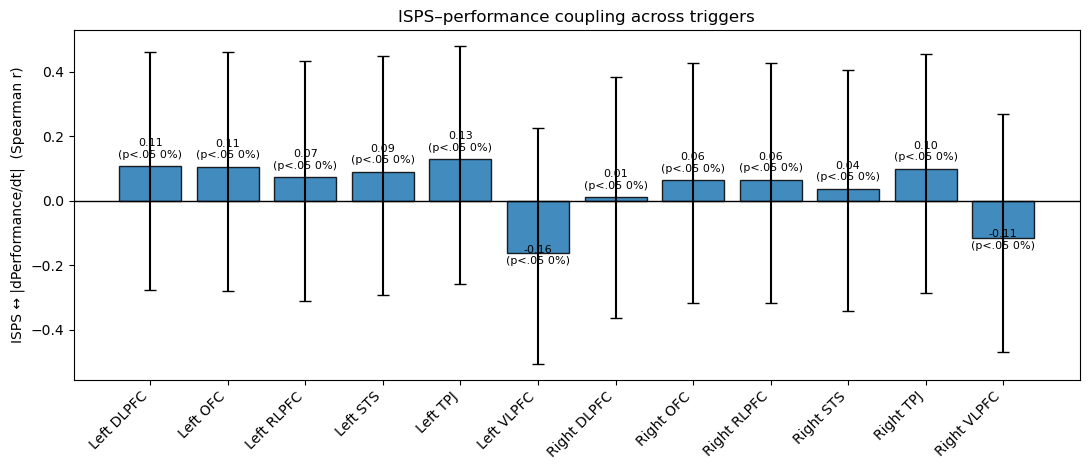

✓ Saved coupling barplot (performance) to: C:\Users\pkell\roi_video_corrmats\ISPS_coupling_barplot_performance.png


In [27]:
# ============================================
# BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# ============================================
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, spearmanr
from scipy.signal import butter, filtfilt, hilbert, find_peaks
from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & basic config
# -----------------------
beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"
mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
os.makedirs(save_dir_corrmats, exist_ok=True)

# -----------------------
# ISPS / Behavior toggles
# -----------------------
ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
BEHAV_REF   = "pca"          # 'mean' or 'pca' (PC1 consensus)
LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# >>> NEW: combination toggle for valence + arousal into a single performance time series
BEHAV_COMBINE = "pca"        # 'mean' or 'pca' for combining valence+arousal into ONE series

# -----------------------
# Task video durations (s) for odd triggers
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels)
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# -----------------------
# Utility functions
# -----------------------
def _norm_key_for_indexing(key: str) -> str:
    s = str(key).lower()
    s = s.replace("\\", "/")
    s = os.path.splitext(os.path.basename(s))[0]
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s

# NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
def _base_video_norm(key: str) -> str:
    s = _norm_key_for_indexing(key)
    # remove domain / meta tokens commonly present in behavior columns
    s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
    # remove trailing domain-like suffixes such as "_v" or "_a" if used
    s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def crop_to_min_len(arr_list):
    L = min(len(a) for a in arr_list if a is not None)
    return [a[:L] for a in arr_list if a is not None], L

def moving_average(x, w):
    if w <= 1:
        return x
    k = int(round(w))
    pad = k//2
    xp = np.pad(x, (pad, pad), mode='edge')
    ker = np.ones(k)/k
    y = np.convolve(xp, ker, mode='valid')
    return y[:len(x)]

def bandpass(x, fs, lo, hi, order=3):
    x = np.asarray(x, float)
    if np.all(~np.isfinite(x)) or len(x) < 5*order:
        return np.array(x, float)
    b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
    return filtfilt(b, a, x, method='gust')

def circ_shift(arr, k):
    """circular shift by k samples (k>0 moves series to the right)."""
    if k == 0 or len(arr) == 0:
        return arr
    k = int(k) % len(arr)
    return np.concatenate([arr[-k:], arr[:-k]])

def abs_derivative(x, fs=1.5):
    dx = np.abs(np.diff(x, prepend=x[:1]))
    k = int(round(3*fs))  # light smoothing
    if k > 1:
        xp = np.pad(dx, (k//2, k//2), mode="edge")
        ker = np.ones(k)/k
        dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
    return dx

def CCT_average(df, return_ev=False):
    """
    FactorAnalyzer PC1 helper with robust guards.
    Expects df as T×S (rows=time, cols=subjects). NaNs should be dropped beforehand.
    """
    if df.empty:
        raise ValueError("CCT_average received empty DataFrame after NaN drop.")
    n_factors = max(1, min(3, df.shape[1]))
    fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
    fa.fit(df, n_factors)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

# -----------------------
# Load behavioral time series (per-participant CSVs)
# Each file has columns = video names (e.g., "...valence", "...arousal")
# -----------------------
data_by_video = {}
for csv_file in os.listdir(beh_root):
    if not csv_file.endswith(".csv"):
        continue
    path = os.path.join(beh_root, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(path)
        # drop the first column if it's an index column
        if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
            df = df.drop(df.columns[0], axis=1)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# -----------------------
# Trigger ↔ Video-name mapping (CSV)  (columns: 'video', 'trigger_number')
# -----------------------
map_df = pd.read_csv(mapping_csv)
lower_cols = {c.lower(): c for c in map_df.columns}
if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
    raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
                     f"Found: {list(map_df.columns)}")

col_video = lower_cols['video']
col_trig  = lower_cols['trigger_number']

map_df = map_df[[col_video, col_trig]].copy()
map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
map_df = map_df.dropna(subset=["Trigger_int"]).copy()
map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# Pre-index behavioral dicts by normalized key
# (A) Exact normalized column names (unchanged)
def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
    idx = {}
    for k in beh_dict.keys():
        nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
        idx.setdefault(nk, []).append(k)
    return idx

# (B) NEW: base video-name indexes (domain stripped) so mapping "video" matches both "...valence" and "...arousal"
BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)

# keep the original (exact) indexes around as a fallback if needed
BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

def _choose_best(candidates):
    if not candidates:
        return None
    def _score(name):
        n = str(name).lower()
        return (("baseline" in n), len(n))
    return sorted(candidates, key=_score)[0]

def _match_behavior_key_for_trigger(t_int, which="arousal"):
    """
    Use mapping CSV's normalized base video name to find the corresponding
    behavior column for the desired domain (arousal/valence).
    """
    vidnorm = TRIG2VIDNAME.get(int(t_int), None)
    if vidnorm is None:
        return None

    # First try base-name index (domain stripped) — primary path
    base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
    if vidnorm in base_index:
        return _choose_best(base_index[vidnorm])

    # Fallback 1: try exact (domain-including) index if the mapping already contains domain terms
    name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
    if vidnorm in name_index:
        return _choose_best(name_index[vidnorm])

    # Fallback 2: token-overlap search on base names
    tokens = [tok for tok in vidnorm.split() if tok]
    cands = []
    for nk, keys in base_index.items():
        nktoks = nk.split()
        shared = len(set(tokens).intersection(nktoks))
        if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
            cands.extend(keys)
    return _choose_best(cands)

# Build unified ratings store by trigger using the mapping
ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][kind] = np.array
unmatched = []  # diagnostics

for t_int in sorted(TRIG2VIDNAME.keys()):
    t_key = str(t_int)
    k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
    if k_aro is not None:
        for subj, arr in arousal_videos[k_aro].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "arousal"))

    k_val = _match_behavior_key_for_trigger(t_int, which="valence")
    if k_val is not None:
        for subj, arr in valence_videos[k_val].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["valence"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "valence"))

HAVE_BEHAVIOR = len(ratings) > 0
print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
if unmatched:
    missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
    print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# -----------------------
# fNIRS preprocessing (Task)
# -----------------------
def individual_analysis(filepath):
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")
    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(1.5)
    return raw

def segment_by_trigger(raw):
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
                            tmin=0, tmax=durations[trig_str],
                            baseline=None, detrend=None, preload=True, verbose=False)
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

# Load & cache ROI time series (SUBJECT × TRIGGER × ROI)
all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subj][trig][roi] = 1D np.array

for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
rois = list(roi_definitions.keys())

# -----------------------
# ROI pass/fail → kept triggers
# -----------------------
alpha = 0.051
MIN_SUBJ_WITH_DATA = 27
p_sig_required = 0.6

roi_pass_by_trig = defaultdict(dict)
roi_has_data_by_trig = defaultdict(set)
roi_sig_counts_by_trig = defaultdict(dict)
roi_n_by_trig = defaultdict(dict)

for trig in triggers:
    for roi in rois:
        subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
        S = len(subj_with_data)
        if S < MIN_SUBJ_WITH_DATA:
            continue
        min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
        X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
        roi_has_data_by_trig[trig].add(roi)
        X_sum = X.sum(axis=0)
        sig_count = 0
        for i in range(S):
            loo_mean = (X_sum - X[i]) / (S - 1)
            r, p = pearsonr(X[i], loo_mean)
            if not np.isnan(r) and p < alpha:
                sig_count += 1
        required = math.ceil(p_sig_required * S)
        roi_sig_counts_by_trig[trig][roi] = sig_count
        roi_n_by_trig[trig][roi] = S
        roi_pass_by_trig[trig][roi] = (sig_count >= required)

kept_triggers, dropped_triggers = [], []
for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
    rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
    if len(rois_with_data) == 0:
        dropped_triggers.append(trig)
        continue
    n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
    threshold = math.ceil(len(rois_with_data) / 2.0)
    if n_pass >= threshold:
        kept_triggers.append(trig)
    else:
        dropped_triggers.append(trig)

print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
triggers = kept_triggers

# ======================================================
# DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# ======================================================
FS = 1.5                    # sampling rate
BP = (0.01, 0.50)           # Hz
SMOOTH_SEC = 7.0
PEAK_MIN_DISTANCE_SEC = 5.0
PEAK_PROMINENCE = 0.04
N_PERM = 100
RNG = np.random.default_rng(2025)

# ======================================================
# ISPS TRACE permutation (shuffle videos within participant)
# + FAST phase cache
# ======================================================
N_PERM_ISPS_TRACE = N_PERM
RNG_ISPS_TRACE = np.random.default_rng(2026)

def isps_trace_statistic(isps_1d):
    """Scalar summary of ISPS trace for permutation testing."""
    if isps_1d is None:
        return np.nan
    x = np.asarray(isps_1d, float)
    if x.size == 0 or np.all(~np.isfinite(x)):
        return np.nan
    return float(np.nanmean(x))

def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
    """
    P: phases shape (S, T). Return ISPS(t) per chosen metric.
    - 'kuramoto'     : |mean e^{iφ}|
    - 'pairwise_sine': 1 - mean_ij[ sin(|Δφ_ij|) ]
    """
    if ISPS_METRIC == "kuramoto":
        z = np.exp(1j * P)                 # (S, T)
        m = np.nanmean(z, axis=0)          # (T,)
        isps = np.abs(m)
    elif ISPS_METRIC == "pairwise_sine":
        S, T = P.shape
        isps = np.empty(T, float)
        for t in range(T):
            ph = P[:, t]
            d = ph[:, None] - ph[None, :]
            d = (d + np.pi) % (2*np.pi) - np.pi
            iu = np.triu_indices(S, k=1)
            isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
    else:
        raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
    w = int(round(smooth_sec * fs))
    return moving_average(isps, max(1, w))

# >>> phase_cache[s][t][roi] = 1D phase array
phase_cache = defaultdict(lambda: defaultdict(dict))
eligible_trigs_by_roi_subj = defaultdict(lambda: defaultdict(list))

print("Building phase cache (bandpass + Hilbert once per subject×trigger×ROI)...")
for s in roi_ts:
    for t in triggers:
        roid = roi_ts[s].get(t, {})
        if not roid:
            continue
        for roi, ts in roid.items():
            if ts is None:
                continue
            x = np.asarray(ts, float)
            if not np.isfinite(x).any():
                continue
            x_bp = bandpass(x, FS, BP[0], BP[1])
            ph = np.angle(hilbert(x_bp))
            if ph is None or len(ph) == 0 or not np.isfinite(ph).any():
                continue
            phase_cache[s][t][roi] = np.asarray(ph, float)
            eligible_trigs_by_roi_subj[roi][s].append(t)
print("✓ Phase cache built.")

def _stack_phases_for_assignment(subj_list, trig_assign, roi):
    """Stack phase vectors given per-subject trigger assignments (list aligned to subj_list)."""
    series = []
    for s, t in zip(subj_list, trig_assign):
        ph = phase_cache.get(s, {}).get(t, {}).get(roi, None)
        if ph is not None and np.isfinite(ph).any():
            series.append(np.asarray(ph, float))
    if len(series) < 3:
        return None
    series, _ = crop_to_min_len(series)
    return np.stack(series, axis=0)  # (S, T)

def permute_isps_trace_pvalue(trig, roi, roi_ts, triggers, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC,
                              n_perm=N_PERM_ISPS_TRACE, rng=RNG_ISPS_TRACE):
    """
    FAST version: uses cached phases so permutations avoid re-filtering/re-Hilbert.

    Returns:
      (isps_obs, stat_obs, p_greater, null_stats_mean, null_stats_sd, n_subj_used)
    """
    subj_with_data = [s for s in roi_ts if roi in roi_ts[s].get(trig, {})]
    if len(subj_with_data) < 3:
        return None, np.nan, np.nan, np.nan, np.nan, int(len(subj_with_data))

    P_obs = _stack_phases_for_assignment(subj_with_data, [trig]*len(subj_with_data), roi)
    if P_obs is None:
        return None, np.nan, np.nan, np.nan, np.nan, int(len(subj_with_data))

    isps_obs = isps_from_phases(P_obs, smooth_sec=smooth_sec, fs=fs)
    stat_obs = isps_trace_statistic(isps_obs)

    elig_map = eligible_trigs_by_roi_subj.get(roi, {})
    null_stats = np.empty(n_perm, float)
    null_stats[:] = np.nan

    for k in range(n_perm):
        trig_assign = []
        for s in subj_with_data:
            elig = elig_map.get(s, [])
            if not elig:
                trig_assign.append(trig)
                continue
            if len(elig) > 1:
                elig2 = [tt for tt in elig if tt != trig]
                pick_from = elig2 if len(elig2) > 0 else elig
            else:
                pick_from = elig
            trig_assign.append(pick_from[int(rng.integers(0, len(pick_from)))])
        Pp = _stack_phases_for_assignment(subj_with_data, trig_assign, roi)
        if Pp is None:
            continue
        isps_p = isps_from_phases(Pp, smooth_sec=smooth_sec, fs=fs)
        null_stats[k] = isps_trace_statistic(isps_p)

    good = np.isfinite(null_stats)
    if not np.isfinite(stat_obs) or good.sum() < 10:
        return isps_obs, stat_obs, np.nan, float(np.nanmean(null_stats)), float(np.nanstd(null_stats, ddof=1)), int(len(subj_with_data))

    p_greater = (1.0 + np.sum(null_stats[good] >= stat_obs)) / (good.sum() + 1.0)
    return (isps_obs, float(stat_obs), float(p_greater),
            float(np.nanmean(null_stats[good])),
            float(np.nanstd(null_stats[good], ddof=1)) if good.sum() > 1 else np.nan,
            int(len(subj_with_data)))

# ======================================================
# >>> Camacho-style timepoint significance + replicated peaks
#     (EDITED per your requested tweaks)
# ======================================================
CAMACHO_ALPHA = 0.05
CAMACHO_MIN_WIDTH_SEC = 5.0
CAMACHO_USE_FDR = True
CAMACHO_PERCENTILE_FALLBACK = 95.0

# >>> EDITED: increase permutations for p(t) stability
CAMACHO_N_PERM_TIMEPOINT = 100

CAMACHO_N_RANDOM_SPLITS = 20
CAMACHO_SPLIT_FRAC = 0.5

# >>> EDITED: match peaks by WINDOW overlap rather than peak-center ±2s
CAMACHO_MATCH_WINDOW_SEC = 8.0   # +/- window half-width for overlap matching (5–10s recommended)

# >>> EDITED: lower across-split stability requirement
CAMACHO_REQUIRE_SPLIT_RATE = 0.3

# >>> EDITED: Camacho-like fallback if “too much of the trace is significant”
CAMACHO_TOO_MANY_SIG_FRAC = 0.5  # if >=50% timepoints pass FDR, use mean+1.5SD threshold
CAMACHO_SD_FALLBACK_Z = 1.5

RNG_CAMACHO = np.random.default_rng(3033)

def _bh_fdr_mask(pvals, alpha=0.05):
    """Benjamini-Hochberg FDR mask (no dependency assumptions)."""
    p = np.asarray(pvals, float)
    m = np.isfinite(p)
    if m.sum() == 0:
        return np.zeros_like(p, dtype=bool)
    pv = p[m]
    order = np.argsort(pv)
    pv_sorted = pv[order]
    thresh = alpha * (np.arange(1, len(pv_sorted) + 1) / float(len(pv_sorted)))
    passed = pv_sorted <= thresh
    if not np.any(passed):
        out = np.zeros_like(p, dtype=bool)
        return out
    kmax = np.max(np.where(passed)[0])
    cutoff = pv_sorted[kmax]
    out = np.zeros_like(p, dtype=bool)
    out[m] = p[m] <= cutoff
    return out

def _perm_isps_trace_matrix_timepoint(subj_list, trig, roi, n_perm, rng):
    """
    Returns:
      isps_null: array shape (n_perm, T) of permuted ISPS(t) traces.
      isps_obs:  array shape (T,) observed ISPS(t) for true trig.
    """
    P_obs = _stack_phases_for_assignment(subj_list, [trig]*len(subj_list), roi)
    if P_obs is None:
        return None, None
    isps_obs = isps_from_phases(P_obs, smooth_sec=SMOOTH_SEC, fs=FS)
    T = len(isps_obs)
    isps_null = np.full((n_perm, T), np.nan, float)

    elig_map = eligible_trigs_by_roi_subj.get(roi, {})
    for k in range(n_perm):
        trig_assign = []
        for s in subj_list:
            elig = elig_map.get(s, [])
            if not elig:
                trig_assign.append(trig)
                continue
            if len(elig) > 1:
                elig2 = [tt for tt in elig if tt != trig]
                pick_from = elig2 if len(elig2) > 0 else elig
            else:
                pick_from = elig
            trig_assign.append(pick_from[int(rng.integers(0, len(pick_from)))])
        Pp = _stack_phases_for_assignment(subj_list, trig_assign, roi)
        if Pp is None:
            continue
        isps_p = isps_from_phases(Pp, smooth_sec=SMOOTH_SEC, fs=FS)
        L = min(T, len(isps_p))
        isps_null[k, :L] = isps_p[:L]
        if L < T:
            isps_null[k, L:] = np.nan
    return isps_null, isps_obs

def _timepoint_pvals_from_null(isps_obs, isps_null):
    """One-sided p(t): P_null(ISPS_null(t) >= ISPS_obs(t))"""
    obs = np.asarray(isps_obs, float)
    null = np.asarray(isps_null, float)
    T = len(obs)
    p = np.full(T, np.nan, float)
    for t in range(T):
        n = null[:, t]
        good = np.isfinite(n)
        if not np.isfinite(obs[t]) or good.sum() < 10:
            continue
        p[t] = (1.0 + np.sum(n[good] >= obs[t])) / (good.sum() + 1.0)
    return p

def _camacho_threshold(isps_obs, pvals, alpha=CAMACHO_ALPHA, use_fdr=True, pct=CAMACHO_PERCENTILE_FALLBACK):
    """
    Convert p(t) into a height threshold for peak detection:
      - if use_fdr: find BH-significant timepoints; thr_fdr = min ISPS among them
      - fallback: thr_pct = percentile(isps_obs, pct)
      - if “too many” timepoints are significant, use mean + 1.5 SD (Camacho-style fallback)
      - final thr = max(thr_candidate, thr_pct) when relevant
    """
    x = np.asarray(isps_obs, float)
    thr_pct = float(np.nanpercentile(x, pct)) if np.isfinite(x).any() else np.nan

    if not use_fdr:
        return thr_pct, np.zeros_like(x, dtype=bool)

    sig_mask = _bh_fdr_mask(pvals, alpha=alpha)

    # >>> EDITED: if nearly the whole trace is "significant", use mean + 1.5 SD instead
    frac_sig = float(np.mean(sig_mask)) if sig_mask is not None and sig_mask.size > 0 else 0.0
    if frac_sig >= CAMACHO_TOO_MANY_SIG_FRAC:
        mu = float(np.nanmean(x))
        sd = float(np.nanstd(x, ddof=1))
        thr_sd = mu + CAMACHO_SD_FALLBACK_Z * sd if np.isfinite(sd) and sd > 0 else thr_pct
        # keep it conservative relative to percentile fallback
        if np.isfinite(thr_pct) and np.isfinite(thr_sd):
            return float(max(thr_sd, thr_pct)), sig_mask
        return float(thr_sd), sig_mask

    if np.any(sig_mask):
        thr_fdr = float(np.nanmin(x[sig_mask]))
        # choose the stricter of FDR-derived threshold and percentile fallback
        if np.isfinite(thr_pct) and np.isfinite(thr_fdr):
            thr = max(thr_fdr, thr_pct)
        else:
            thr = thr_fdr if np.isfinite(thr_fdr) else thr_pct
        return float(thr), sig_mask
    else:
        return thr_pct, sig_mask

def _match_peaks(peaks_a, peaks_b, fs=FS, win_sec=CAMACHO_MATCH_WINDOW_SEC):
    """
    >>> EDITED: match peaks by WINDOW overlap (not peak-center distance).
    Define each peak's window as [peak - win, peak + win] in samples.
    A peak in A is considered replicated if ANY peak-window in B overlaps it.
    Returns list of matched peak indices from A (kept as A's indices).
    """
    if len(peaks_a) == 0 or len(peaks_b) == 0:
        return []
    w = int(round(win_sec * fs))
    peaks_a = np.asarray(peaks_a, int)
    peaks_b = np.asarray(peaks_b, int)

    intervals_b = [(int(pb - w), int(pb + w)) for pb in peaks_b]
    matched = []
    for pa in peaks_a:
        a0, a1 = int(pa - w), int(pa + w)
        ok = False
        for b0, b1 in intervals_b:
            if (a0 <= b1) and (b0 <= a1):  # overlap
                ok = True
                break
        if ok:
            matched.append(int(pa))
    return matched

def _detect_camacho_peaks(isps_obs, height_thr, fs=FS):
    """
    Peak detection mirroring Camacho's idea:
      - require width >= 5s
      - require height >= threshold
      - keep spacing logic via PEAK_MIN_DISTANCE_SEC
    """
    x = np.asarray(isps_obs, float)
    if x.size == 0 or not np.isfinite(x).any() or not np.isfinite(height_thr):
        return np.array([], dtype=int), {}
    distance = int(round(PEAK_MIN_DISTANCE_SEC * fs))
    min_width = int(round(CAMACHO_MIN_WIDTH_SEC * fs))
    peaks, props = find_peaks(
        x,
        distance=max(1, distance),
        height=height_thr,
        width=max(1, min_width)
    )
    return peaks, props

# ======================================================
# Behavior reference helpers
# ======================================================
def _group_ref_from_traces(traces_2d, mode):
    if traces_2d.size == 0:
        return None
    if mode == "pca":
        df = pd.DataFrame(traces_2d.T)
        df = df.dropna(axis=0, how="any")
        if df.shape[0] < 5 or df.shape[1] < 1:
            return np.nanmean(traces_2d, axis=0)
        pc1 = CCT_average(df, return_ev=False)
        return np.asarray(pc1, float)
    else:
        return np.nanmean(traces_2d, axis=0)

def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
    if (val_ref is None) and (aro_ref is None):
        return None
    if (val_ref is not None) and (aro_ref is not None):
        L = min(len(val_ref), len(aro_ref))
        v = np.asarray(val_ref[:L], float)
        a = np.asarray(aro_ref[:L], float)
        if mode == "mean":
            return 0.5 * (v + a)
        elif mode == "pca":
            v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
            a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
            X = np.vstack([v_z, a_z]).T
            X = X - np.nanmean(X, axis=0, keepdims=True)
            U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
            pc1_timecourse = U[:, 0] * S[0]
            if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
                pc1_timecourse = -pc1_timecourse
            return pc1_timecourse.astype(float)
        else:
            raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
    else:
        return val_ref if val_ref is not None else aro_ref

def behavior_performance_for_trig(trig, ratings):
    val_list, aro_list = [], []
    for s in ratings:
        if trig in ratings[s]:
            if "valence" in ratings[s][trig]:
                val_list.append(np.asarray(ratings[s][trig]["valence"], float))
            if "arousal" in ratings[s][trig]:
                aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

    val_ref = None
    aro_ref = None

    if len(val_list) > 0:
        val_list, _ = crop_to_min_len(val_list)
        V = np.stack(val_list, 0)
        val_ref = _group_ref_from_traces(V, BEHAV_REF)

    if len(aro_list) > 0:
        aro_list, _ = crop_to_min_len(aro_list)
        A = np.stack(aro_list, 0)
        aro_ref = _group_ref_from_traces(A, BEHAV_REF)

    if (val_ref is None) and (aro_ref is None):
        return None

    return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
    isps_by_roi = {}
    n_subj_by_roi = {}
    for roi in rois:
        series = []
        for s in roi_ts:
            ts = roi_ts[s].get(trig, {}).get(roi, None)
            if ts is not None and np.isfinite(ts).any():
                series.append(np.asarray(ts, float))
        if len(series) < 3:
            continue
        series, L = crop_to_min_len(series)
        X = np.stack(series, axis=0)
        Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
        P = np.angle(hilbert(Xbp, axis=1))
        isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
        isps_by_roi[roi] = isps
        n_subj_by_roi[roi] = X.shape[0]
    return isps_by_roi, n_subj_by_roi

def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
    distance = int(round(min_distance_sec * fs))
    peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
    return peaks, props

def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
    if beh_perf is None:
        return np.nan, np.nan, np.nan
    L = min(len(isps), len(beh_perf))
    isps = isps[:L]
    beh = beh_perf[:L]
    beh_d = abs_derivative(beh, fs=FS)

    if LAG_MODE == "fixed":
        lag_samp = int(round(HRF_SEC * FS))
        beh_use = circ_shift(beh_d, lag_samp)
        chosen_lag_sec = HRF_SEC
    elif LAG_MODE == "xcorr":
        max_k = int(round(XCORR_LAG_MAX_SEC * FS))
        ks = range(-max_k, max_k + 1)
        best_k, best_val = 0, -np.inf
        for k in ks:
            b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
            m = np.isfinite(isps) & np.isfinite(b)
            if m.sum() < 5:
                continue
            r = spearmanr(isps[m], b[m]).correlation
            v = 0.0 if np.isnan(r) else abs(r)
            if v > best_val:
                best_val, best_k = v, k
        beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
        chosen_lag_sec = best_k / FS
    else:
        raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

    m = np.isfinite(isps) & np.isfinite(beh_use)
    if m.sum() < 5:
        return np.nan, np.nan, chosen_lag_sec

    r_obs = spearmanr(isps[m], beh_use[m]).correlation
    p_two = np.nan
    return float(r_obs), float(p_two), float(chosen_lag_sec)

# Run ISPS and coupling
all_peak_tables = []
all_coupling = []
plot_payloads = []

all_isps_trace_perm = []
all_camacho_timepoint_summary = []
all_camacho_replicated_peaks = []

for trig in sorted(triggers, key=lambda x: int(x)):
    isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
    beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

    for roi, isps in isps_by_roi.items():
        isps_obs_perm, stat_obs_perm, p_isps_trace, null_mu, null_sd, n_used = permute_isps_trace_pvalue(
            trig, roi, roi_ts, triggers, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC,
            n_perm=N_PERM_ISPS_TRACE, rng=RNG_ISPS_TRACE
        )
        all_isps_trace_perm.append({
            "Trigger": trig,
            "ROI": roi,
            "N_subj": nS.get(roi, np.nan),
            "N_subj_used_perm": n_used,
            "ISPS_trace_stat_mean": stat_obs_perm,
            "p_isps_trace_perm_greater": p_isps_trace,
            "null_mean": null_mu,
            "null_sd": null_sd,
            "ISPS_metric": ISPS_METRIC,
            "BP_lo": BP[0],
            "BP_hi": BP[1],
            "Smooth_sec": SMOOTH_SEC,
            "N_perm_isps_trace": int(N_PERM_ISPS_TRACE)
        })

        subj_with_data = [s for s in roi_ts if roi in roi_ts[s].get(trig, {})]
        subj_with_data = [s for s in subj_with_data if trig in phase_cache.get(s, {}) and roi in phase_cache[s][trig]]

        if len(subj_with_data) >= 6:
            subj_with_data = list(subj_with_data)

            peak_hits = defaultdict(int)
            peak_meta = {}
            n_splits_done = 0

            for split_i in range(int(CAMACHO_N_RANDOM_SPLITS)):
                rng_split = np.random.default_rng(int(RNG_CAMACHO.integers(0, 2**31 - 1)))

                perm = rng_split.permutation(len(subj_with_data))
                nA = int(round(CAMACHO_SPLIT_FRAC * len(subj_with_data)))
                nA = max(3, min(nA, len(subj_with_data) - 3))
                idxA = perm[:nA]
                idxB = perm[nA:]
                subA = [subj_with_data[i] for i in idxA]
                subB = [subj_with_data[i] for i in idxB]

                nullA, obsA = _perm_isps_trace_matrix_timepoint(subA, trig, roi, CAMACHO_N_PERM_TIMEPOINT, rng_split)
                nullB, obsB = _perm_isps_trace_matrix_timepoint(subB, trig, roi, CAMACHO_N_PERM_TIMEPOINT, rng_split)
                if nullA is None or nullB is None or obsA is None or obsB is None:
                    continue

                pA = _timepoint_pvals_from_null(obsA, nullA)
                pB = _timepoint_pvals_from_null(obsB, nullB)

                thrA, sigA = _camacho_threshold(obsA, pA, alpha=CAMACHO_ALPHA, use_fdr=CAMACHO_USE_FDR, pct=CAMACHO_PERCENTILE_FALLBACK)
                thrB, sigB = _camacho_threshold(obsB, pB, alpha=CAMACHO_ALPHA, use_fdr=CAMACHO_USE_FDR, pct=CAMACHO_PERCENTILE_FALLBACK)

                peaksA, propsA = _detect_camacho_peaks(obsA, thrA, fs=FS)
                peaksB, propsB = _detect_camacho_peaks(obsB, thrB, fs=FS)

                matchedA = _match_peaks(peaksA, peaksB, fs=FS, win_sec=CAMACHO_MATCH_WINDOW_SEC)

                all_camacho_timepoint_summary.append({
                    "Trigger": trig, "ROI": roi, "split_idx": int(split_i),
                    "n_subj_A": int(len(subA)), "n_subj_B": int(len(subB)),
                    "thrA": float(thrA) if np.isfinite(thrA) else np.nan,
                    "thrB": float(thrB) if np.isfinite(thrB) else np.nan,
                    "n_sig_timepoints_A": int(np.sum(sigA)) if sigA is not None else 0,
                    "n_sig_timepoints_B": int(np.sum(sigB)) if sigB is not None else 0,
                    "n_peaks_A": int(len(peaksA)), "n_peaks_B": int(len(peaksB)),
                    "n_replicated_peaks": int(len(matchedA)),
                    "perm_timepoint_n": int(CAMACHO_N_PERM_TIMEPOINT),
                    "alpha": float(CAMACHO_ALPHA),
                    "use_fdr": bool(CAMACHO_USE_FDR),
                    "pct_fallback": float(CAMACHO_PERCENTILE_FALLBACK),
                    "min_width_sec": float(CAMACHO_MIN_WIDTH_SEC),
                    "match_window_sec": float(CAMACHO_MATCH_WINDOW_SEC),
                    "require_split_rate": float(CAMACHO_REQUIRE_SPLIT_RATE),
                    "too_many_sig_frac": float(CAMACHO_TOO_MANY_SIG_FRAC),
                    "sd_fallback_z": float(CAMACHO_SD_FALLBACK_Z),
                })

                if len(matchedA) > 0:
                    tA = np.arange(len(obsA)) / FS
                    for pa in matchedA:
                        peak_hits[int(pa)] += 1
                        if int(pa) not in peak_meta:
                            h = float(obsA[int(pa)]) if int(pa) < len(obsA) else np.nan
                            peak_meta[int(pa)] = {
                                "peak_idx": int(pa),
                                "peak_t_sec": float(tA[int(pa)]),
                                "peak_height": h
                            }

                n_splits_done += 1

            if n_splits_done > 0 and len(peak_hits) > 0:
                for pk, ct in sorted(peak_hits.items(), key=lambda x: (-x[1], x[0])):
                    rate = ct / float(n_splits_done)
                    if rate >= CAMACHO_REQUIRE_SPLIT_RATE:
                        meta = peak_meta.get(pk, {})
                        all_camacho_replicated_peaks.append({
                            "Trigger": trig,
                            "ROI": roi,
                            "peak_idx": int(pk),
                            "peak_t_sec": float(meta.get("peak_t_sec", np.nan)),
                            "peak_height": float(meta.get("peak_height", np.nan)),
                            "replication_rate_across_splits": float(rate),
                            "n_splits_done": int(n_splits_done),
                            "n_perm_timepoint": int(CAMACHO_N_PERM_TIMEPOINT),
                            "alpha": float(CAMACHO_ALPHA),
                            "use_fdr": bool(CAMACHO_USE_FDR),
                            "pct_fallback": float(CAMACHO_PERCENTILE_FALLBACK),
                            "min_width_sec": float(CAMACHO_MIN_WIDTH_SEC),
                            "match_window_sec": float(CAMACHO_MATCH_WINDOW_SEC),
                            "require_split_rate": float(CAMACHO_REQUIRE_SPLIT_RATE),
                            "too_many_sig_frac": float(CAMACHO_TOO_MANY_SIG_FRAC),
                            "sd_fallback_z": float(CAMACHO_SD_FALLBACK_Z),
                        })
            else:
                all_camacho_replicated_peaks.append({
                    "Trigger": trig,
                    "ROI": roi,
                    "peak_idx": np.nan,
                    "peak_t_sec": np.nan,
                    "peak_height": np.nan,
                    "replication_rate_across_splits": 0.0,
                    "n_splits_done": int(n_splits_done),
                    "n_perm_timepoint": int(CAMACHO_N_PERM_TIMEPOINT),
                    "alpha": float(CAMACHO_ALPHA),
                    "use_fdr": bool(CAMACHO_USE_FDR),
                    "pct_fallback": float(CAMACHO_PERCENTILE_FALLBACK),
                    "min_width_sec": float(CAMACHO_MIN_WIDTH_SEC),
                    "match_window_sec": float(CAMACHO_MATCH_WINDOW_SEC),
                    "require_split_rate": float(CAMACHO_REQUIRE_SPLIT_RATE),
                    "too_many_sig_frac": float(CAMACHO_TOO_MANY_SIG_FRAC),
                    "sd_fallback_z": float(CAMACHO_SD_FALLBACK_Z),
                })
        else:
            all_camacho_replicated_peaks.append({
                "Trigger": trig,
                "ROI": roi,
                "peak_idx": np.nan,
                "peak_t_sec": np.nan,
                "peak_height": np.nan,
                "replication_rate_across_splits": np.nan,
                "n_splits_done": 0,
                "n_perm_timepoint": int(CAMACHO_N_PERM_TIMEPOINT),
                "alpha": float(CAMACHO_ALPHA),
                "use_fdr": bool(CAMACHO_USE_FDR),
                "pct_fallback": float(CAMACHO_PERCENTILE_FALLBACK),
                "min_width_sec": float(CAMACHO_MIN_WIDTH_SEC),
                "match_window_sec": float(CAMACHO_MATCH_WINDOW_SEC),
                "require_split_rate": float(CAMACHO_REQUIRE_SPLIT_RATE),
                "too_many_sig_frac": float(CAMACHO_TOO_MANY_SIG_FRAC),
                "sd_fallback_z": float(CAMACHO_SD_FALLBACK_Z),
            })

        # existing peak detection (your original)
        peaks, props = find_isps_peaks(isps, fs=FS,
                                       min_distance_sec=PEAK_MIN_DISTANCE_SEC,
                                       prominence=PEAK_PROMINENCE)
        t_sec = np.arange(len(isps)) / FS
        for i, p in enumerate(peaks):
            all_peak_tables.append({
                "Trigger": trig,
                "ROI": roi,
                "N_subj": nS.get(roi, np.nan),
                "t_idx": int(p),
                "t_sec": float(t_sec[p]),
                "height": float(isps[p]),
                "prominence": float(props["prominences"][i]),
            })

        rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
        all_coupling.append({
            "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
            "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
            "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
        })

        plot_payloads.append({
            "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
            "peaks": peaks, "beh_perf": beh_perf
        })

# Save per-trigger tables
peaks_df = pd.DataFrame(all_peak_tables)
coupling_df = pd.DataFrame(all_coupling)
peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
peaks_df.to_csv(peaks_path, index=False)
coupling_df.to_csv(coupling_path, index=False)
print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# Save ISPS trace permutation p-values (per Trigger × ROI)
isps_trace_perm_df = pd.DataFrame(all_isps_trace_perm)
isps_trace_perm_path = os.path.join(save_dir_corrmats, "ISPS_trace_permutation_by_trigger_roi_task.csv")
isps_trace_perm_df.to_csv(isps_trace_perm_path, index=False)
print(f"✓ Saved ISPS-trace permutation results: {isps_trace_perm_path}  (rows={len(isps_trace_perm_df)})")

# Save Camacho-style split-half timepoint summaries + robust replicated peaks
camacho_split_summary_df = pd.DataFrame(all_camacho_timepoint_summary)
camacho_peaks_df = pd.DataFrame(all_camacho_replicated_peaks)

camacho_split_summary_path = os.path.join(save_dir_corrmats, "ISPS_camacho_timepoint_split_summaries.csv")
camacho_peaks_path = os.path.join(save_dir_corrmats, "ISPS_camacho_replicated_peaks_by_trigger_roi.csv")

camacho_split_summary_df.to_csv(camacho_split_summary_path, index=False)
camacho_peaks_df.to_csv(camacho_peaks_path, index=False)

print(f"✓ Saved Camacho-style split summaries: {camacho_split_summary_path}  (rows={len(camacho_split_summary_df)})")
print(f"✓ Saved Camacho-style replicated peaks: {camacho_peaks_path}  (rows={len(camacho_peaks_df)})")

# ============================================
# Save chosen lags per (ROI, trigger) + summaries
# ============================================
if 'lag_sec_performance' not in coupling_df.columns:
    print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
else:
    if LAG_MODE != "xcorr":
        print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
              "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

    lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
        columns={"lag_sec_performance": "lag_sec"}
    )
    lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

    lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
    lag_long.to_csv(lag_csv, index=False)
    print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

    rows = []
    for roi, sub in lag_long.groupby("ROI"):
        x = sub["lag_sec"].values
        if x.size == 0:
            continue
        mean = float(np.mean(x))
        med  = float(np.median(x))
        sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
        lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
        rows.append({
            "ROI": roi, "n": int(x.size),
            "lag_mean": mean, "lag_median": med, "lag_sd": sd,
            "lag_p2.5": float(lo), "lag_p97.5": float(hi)
        })
    lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
    lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
    lag_summ.to_csv(lag_summ_csv, index=False)
    print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")

    sub = lag_long
    if not sub.empty:
        plt.figure(figsize=(6, 3.6))
        bins = int(np.clip(len(sub) / 10, 12, 40))
        plt.hist(sub["lag_sec"], bins=bins, edgecolor="k", alpha=0.85)
        if LAG_MODE == "fixed":
            plt.axvline(HRF_SEC, color="r", ls="--", lw=1, label=f"HRF ref = {HRF_SEC:.1f}s")
            plt.legend()
        plt.xlabel("Chosen lag (s)")
        plt.ylabel("Count")
        plt.title(f"Chosen lags from {LAG_MODE} — Performance")
        plt.tight_layout()
        out_png = os.path.join(save_dir_corrmats, f"ISPS_lag_hist_performance.png")
        plt.savefig(out_png, dpi=180)
        plt.close()
        print(f"✓ Saved lag histogram ➜ {out_png}")

# ======================================================
# PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# ======================================================
isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
os.makedirs(isps_plot_dir, exist_ok=True)

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps, t = pack["isps"], pack["t_sec"]
    peaks = pack["peaks"]
    bp = pack["beh_perf"]

    plt.figure(figsize=(9, 4.5))
    plt.plot(t, isps, lw=2, label="ISPS")
    if len(peaks) > 0:
        plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

    if bp is not None:
        dp = abs_derivative(bp, fs=FS)[:len(t)]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        dp_show = circ_shift(dp, shift)
        plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

    plt.xlabel("Time (s)")
    plt.ylabel("ISPS")
    plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
    plt.legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
    plt.savefig(out_png, dpi=200)
    plt.close()

print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# ======================================================
# ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# ======================================================
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def roi_level_coupling_bars_perf(coupling_df):
    col_r = "r_with_abs_dPerformance"
    col_p = "p_two_performance"
    rows = []
    for roi, sub in coupling_df.groupby("ROI"):
        rvals = sub[col_r].values
        rvals = rvals[np.isfinite(rvals)]
        if rvals.size == 0:
            rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
            continue
        z = fisher_z(rvals)
        z_mean = np.nanmean(z)
        n = np.sum(np.isfinite(z))
        se = 1/np.sqrt(max(n-3, 1))
        lo_z = z_mean - 1.96*se
        hi_z = z_mean + 1.96*se
        rows.append({
            "ROI": roi,
            "r_mean": inv_z(z_mean),
            "lo": inv_z(lo_z),
            "hi": inv_z(hi_z),
            "n": int(n),
            "p_sig_frac": np.mean(sub[col_p].values < 0.05)
        })
    out = pd.DataFrame(rows).sort_values("ROI")
    return out

agg = roi_level_coupling_bars_perf(coupling_df)
plt.figure(figsize=(11, 4.8))
order = agg["ROI"].tolist()
means = agg["r_mean"].values
yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
    if np.isfinite(m):
        plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
                 f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
plt.axhline(0, color="k", lw=1)
plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
plt.title("ISPS–performance coupling across triggers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")
plt.savefig(out_png, dpi=220)
plt.show()
print(f"✓ Saved coupling barplot (performance) to: {out_png}")

In [59]:
# ======================================================
# NEW: Within-video time-series nulls for ISPS event significance
#   - Null methods: circular time shift OR phase randomization (spectrum-preserving)
#   - Null-driven stats per ROI×Trigger:
#       (1) max ISPS(t)   (peak-height style)
#       (2) max cluster mass above a threshold
#       (3) max prominence of peaks (width >= 5s)
#   - Event detection constraints:
#       width >= 5 s
#       prominence threshold calibrated by null (e.g., 95th percentile) and/or p-value
#       replication across split halves (repeated random splits)
#   - AFTER robust events exist: optional inside-vs-outside tests (feature time series)
#     (Camacho-style: compare feature means inside events vs outside; FDR correction)
#
# Drop-in: Replace your current "ISPS TRACE permutation" + Camacho block + the
#          corresponding per-(trig,roi) loop content with this block.
# ======================================================

# --------------------------
# Choose within-video null
# --------------------------
NULL_METHOD = "circular_shift"   # "circular_shift" or "phase_randomization"

# --------------------------
# Permutation / event params
# --------------------------
EVENT_ALPHA = 0.05

N_PERM_WITHINVIDEO = 1000        # for null distributions (max/cluster/prominence)
RNG_WITHIN = np.random.default_rng(9091)

EVENT_MIN_WIDTH_SEC = 5.0
EVENT_MIN_DISTANCE_SEC = 5.0     # spacing between peaks, used for prominence-based peak detection
EVENT_MATCH_WINDOW_SEC = 8.0     # +/- window half-width for overlap matching across splits

# Thresholding for cluster statistic
CLUSTER_THR_MODE = "pooled_null_pct"   # "pooled_null_pct" or "obs_pct"
CLUSTER_THR_PCT  = 95.0               # threshold percentile
CLUSTER_MASS_MODE = "excess"          # "excess" = sum(max(0, x-thr)) within cluster; "area" = sum(x)

# Replication across splits (Camacho-style analogue when no independent sample)
N_RANDOM_SPLITS = 50
SPLIT_FRAC = 0.5
REQUIRE_SPLIT_RATE = 0.3

# Prominence calibration by null
PROM_NULL_PCT = 95.0   # event requires prominence >= this percentile of null max-prominence

# If too many points exceed threshold, use Camacho-like fallback for peak thresholding
TOO_MANY_ABOVE_FRAC = 0.5
SD_FALLBACK_Z = 1.5

# --------------------------
# Helpers: phase randomization surrogate
# --------------------------
def _phase_randomize_1d(x, rng):
    """
    Phase randomization surrogate:
      preserve amplitude spectrum, randomize phases (Hermitian symmetry for real signal).
    """
    x = np.asarray(x, float)
    n = len(x)
    if n < 8 or not np.isfinite(x).any():
        return x.copy()

    x0 = np.nan_to_num(x - np.nanmean(x))
    X = np.fft.rfft(x0)

    # Random phases for non-DC/non-Nyquist bins
    phases = rng.uniform(0, 2*np.pi, size=X.shape[0])
    phases[0] = 0.0
    if n % 2 == 0:
        phases[-1] = 0.0  # Nyquist real-only bin

    X_surr = np.abs(X) * np.exp(1j * phases)
    x_surr = np.fft.irfft(X_surr, n=n)
    x_surr = x_surr + np.nanmean(x)  # restore mean
    return x_surr.astype(float)

def _make_surrogate_signal(x_bp, rng, method="circular_shift"):
    """
    x_bp: bandpassed signal (1D)
    method:
      - circular_shift: circularly shift time series by random k (excluding 0 and full length)
      - phase_randomization: Fourier phase scramble surrogate
    Returns 1D surrogate signal.
    """
    x_bp = np.asarray(x_bp, float)
    if x_bp.size < 8 or not np.isfinite(x_bp).any():
        return x_bp.copy()

    if method == "circular_shift":
        n = len(x_bp)
        k = int(rng.integers(1, n))  # avoid 0 shift
        return circ_shift(x_bp, k)
    elif method == "phase_randomization":
        return _phase_randomize_1d(x_bp, rng)
    else:
        raise ValueError("NULL_METHOD must be 'circular_shift' or 'phase_randomization'")

# --------------------------
# Helpers: event detection and matching
# --------------------------
def _contiguous_true_runs(mask):
    """Return list of (start_idx, end_idx) inclusive runs for boolean mask."""
    mask = np.asarray(mask, bool)
    if mask.size == 0:
        return []
    d = np.diff(mask.astype(int), prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0] - 1
    return list(zip(starts.tolist(), ends.tolist()))

def _cluster_masses(x, thr, fs, min_width_sec=5.0, mode="excess"):
    """
    Compute contiguous clusters above thr; return:
      - clusters: list of dicts with start/end/width/mass
      - max_mass: scalar max cluster mass
    """
    x = np.asarray(x, float)
    if x.size == 0 or not np.isfinite(x).any() or not np.isfinite(thr):
        return [], 0.0
    above = np.isfinite(x) & (x >= thr)
    runs = _contiguous_true_runs(above)
    minw = int(round(min_width_sec * fs))
    clusters = []
    for a, b in runs:
        width = b - a + 1
        if width < max(1, minw):
            continue
        seg = x[a:b+1]
        if mode == "excess":
            mass = float(np.nansum(np.maximum(0.0, seg - thr)))
        else:
            mass = float(np.nansum(seg))
        clusters.append({"start": int(a), "end": int(b), "width": int(width), "mass": float(mass)})
    max_mass = float(max([c["mass"] for c in clusters], default=0.0))
    return clusters, max_mass

def _detect_peaks_with_width_and_prominence(x, fs, min_width_sec=5.0, min_distance_sec=5.0, height=None):
    """
    Detect peaks with:
      - width >= min_width_sec
      - distance >= min_distance_sec
      - optional min height
    Returns peaks (indices) and props dict from scipy.find_peaks.
    """
    x = np.asarray(x, float)
    if x.size == 0 or not np.isfinite(x).any():
        return np.array([], dtype=int), {}

    distance = int(round(min_distance_sec * fs))
    minw = int(round(min_width_sec * fs))

    kwargs = dict(
        distance=max(1, distance),
        width=max(1, minw),
    )
    if height is not None and np.isfinite(height):
        kwargs["height"] = float(height)

    peaks, props = find_peaks(x, **kwargs)
    return peaks.astype(int), props

def _peak_windows_from_indices(peaks, fs, win_sec=8.0):
    """Convert peak centers -> windows [start,end] in samples for overlap matching."""
    w = int(round(win_sec * fs))
    windows = []
    for p in np.asarray(peaks, int):
        windows.append((int(p - w), int(p + w)))
    return windows

def _match_events_by_window(peaks_a, peaks_b, fs, win_sec=8.0):
    """
    Peaks match if their +/- win windows overlap.
    Return matched peak indices from A.
    """
    if len(peaks_a) == 0 or len(peaks_b) == 0:
        return []
    winA = _peak_windows_from_indices(peaks_a, fs, win_sec=win_sec)
    winB = _peak_windows_from_indices(peaks_b, fs, win_sec=win_sec)
    matched = []
    for pa, (a0, a1) in zip(peaks_a, winA):
        ok = False
        for (b0, b1) in winB:
            if (a0 <= b1) and (b0 <= a1):
                ok = True
                break
        if ok:
            matched.append(int(pa))
    return matched

# --------------------------
# Core: build observed ISPS(t) from cached phases (your existing isps_from_phases is used)
# --------------------------
def _stack_bandpassed_for_trig_roi(subj_list, trig, roi):
    """Return stacked bandpassed signals (S,T) using signal_cache."""
    series = []
    for s in subj_list:
        xbp = signal_cache.get(s, {}).get(trig, {}).get(roi, None)
        if xbp is not None and np.isfinite(xbp).any():
            series.append(np.asarray(xbp, float))
    if len(series) < 3:
        return None
    series, _ = crop_to_min_len(series)
    return np.stack(series, axis=0)

def _isps_from_bandpassed_stack(Xbp, smooth_sec=SMOOTH_SEC, fs=FS):
    """Compute ISPS(t) from bandpassed stack Xbp (S,T): Hilbert -> phase -> isps_from_phases()."""
    if Xbp is None:
        return None
    P = np.angle(hilbert(Xbp, axis=1))
    return isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)

# --------------------------
# NEW: Build BOTH signal_cache and phase_cache (so we can generate within-video surrogates fast)
# --------------------------
signal_cache = defaultdict(lambda: defaultdict(dict))   # signal_cache[s][t][roi] = bandpassed signal
phase_cache  = defaultdict(lambda: defaultdict(dict))   # phase_cache[s][t][roi]  = phase from bandpassed
eligible_trigs_by_roi_subj = defaultdict(lambda: defaultdict(list))

print("Building signal+phase cache (bandpass + Hilbert once per subject×trigger×ROI)...")
for s in roi_ts:
    for t in triggers:
        roid = roi_ts[s].get(t, {})
        if not roid:
            continue
        for roi, ts in roid.items():
            if ts is None:
                continue
            x = np.asarray(ts, float)
            if not np.isfinite(x).any():
                continue
            x_bp = bandpass(x, FS, BP[0], BP[1])
            if x_bp is None or len(x_bp) == 0 or not np.isfinite(x_bp).any():
                continue
            signal_cache[s][t][roi] = np.asarray(x_bp, float)
            ph = np.angle(hilbert(x_bp))
            if ph is None or len(ph) == 0 or not np.isfinite(ph).any():
                continue
            phase_cache[s][t][roi] = np.asarray(ph, float)
            eligible_trigs_by_roi_subj[roi][s].append(t)
print("✓ Signal+phase cache built.")

# --------------------------
# NEW: Within-video null generator for ISPS(t)
# --------------------------
def _withinvideo_null_isps_matrix(subj_list, trig, roi, n_perm, rng, method=NULL_METHOD):
    """
    Build null ISPS(t) traces by generating within-video surrogates PER SUBJECT (same trigger),
    recomputing ISPS(t) each perm.
    Returns:
      isps_obs: (T,)
      isps_null: (n_perm, T)
    """
    # Observed ISPS
    Xbp_obs = _stack_bandpassed_for_trig_roi(subj_list, trig, roi)
    if Xbp_obs is None:
        return None, None
    isps_obs = _isps_from_bandpassed_stack(Xbp_obs, smooth_sec=SMOOTH_SEC, fs=FS)
    if isps_obs is None or len(isps_obs) == 0:
        return None, None
    T = len(isps_obs)

    # Null matrix
    isps_null = np.full((int(n_perm), T), np.nan, float)

    # For speed: pull each subject's bandpassed trace once
    subj_bp = []
    for s in subj_list:
        xbp = signal_cache.get(s, {}).get(trig, {}).get(roi, None)
        if xbp is None or not np.isfinite(xbp).any():
            continue
        subj_bp.append(np.asarray(xbp, float))
    if len(subj_bp) < 3:
        return isps_obs, None
    subj_bp, _ = crop_to_min_len(subj_bp)          # align lengths
    subj_bp = np.stack(subj_bp, axis=0)            # (S,T)

    for k in range(int(n_perm)):
        Xbp_surr = np.empty_like(subj_bp)
        for i in range(subj_bp.shape[0]):
            Xbp_surr[i] = _make_surrogate_signal(subj_bp[i], rng, method=method)
        isps_k = _isps_from_bandpassed_stack(Xbp_surr, smooth_sec=SMOOTH_SEC, fs=FS)
        if isps_k is None:
            continue
        L = min(T, len(isps_k))
        isps_null[k, :L] = isps_k[:L]
        if L < T:
            isps_null[k, L:] = np.nan

    return np.asarray(isps_obs, float), np.asarray(isps_null, float)

def _p_from_null_greater(obs_stat, null_stats):
    null_stats = np.asarray(null_stats, float)
    good = np.isfinite(null_stats)
    if not np.isfinite(obs_stat) or good.sum() < 20:
        return np.nan
    return float((1.0 + np.sum(null_stats[good] >= obs_stat)) / (good.sum() + 1.0))

# --------------------------
# NEW: stats from an ISPS(t) trace
# --------------------------
def _isps_stats_max_cluster_prom(isps_obs, isps_null, fs=FS):
    """
    Compute:
      - max_isps: max_t isps_obs(t)
      - max_cluster_mass: max over clusters above threshold
      - max_prominence: max peak prominence among peaks with width>=5s
    Null distributions are computed with max-statistic analogues per permutation.
    """
    x = np.asarray(isps_obs, float)
    if x.size == 0 or not np.isfinite(x).any() or isps_null is None:
        return None

    null = np.asarray(isps_null, float)
    good_rows = np.any(np.isfinite(null), axis=1)
    null = null[good_rows]
    if null.shape[0] < 20:
        return None

    # 1) Max ISPS(t)
    max_obs = float(np.nanmax(x))
    max_null = np.nanmax(null, axis=1).astype(float)

    # Threshold for cluster + (optional) peak height fallback
    if CLUSTER_THR_MODE == "pooled_null_pct":
        thr = float(np.nanpercentile(null, CLUSTER_THR_PCT))
    else:
        thr = float(np.nanpercentile(x, CLUSTER_THR_PCT))

    # If too much of the series is above thr, use mean+1.5 SD fallback (Camacho-style)
    frac_above = float(np.mean(np.isfinite(x) & (x >= thr)))
    if frac_above >= TOO_MANY_ABOVE_FRAC:
        mu = float(np.nanmean(x))
        sd = float(np.nanstd(x, ddof=1))
        if np.isfinite(sd) and sd > 0:
            thr = float(mu + SD_FALLBACK_Z * sd)

    # 2) Cluster mass
    _, cm_obs = _cluster_masses(x, thr, fs=fs, min_width_sec=EVENT_MIN_WIDTH_SEC, mode=CLUSTER_MASS_MODE)
    cm_null = np.zeros(null.shape[0], float)
    for i in range(null.shape[0]):
        _, cm_i = _cluster_masses(null[i], thr, fs=fs, min_width_sec=EVENT_MIN_WIDTH_SEC, mode=CLUSTER_MASS_MODE)
        cm_null[i] = float(cm_i)

    # 3) Max prominence among width-constrained peaks
    peaks_obs, props_obs = _detect_peaks_with_width_and_prominence(
        x, fs=fs, min_width_sec=EVENT_MIN_WIDTH_SEC, min_distance_sec=EVENT_MIN_DISTANCE_SEC
    )
    prom_obs = props_obs.get("prominences", np.array([], float))
    max_prom_obs = float(np.nanmax(prom_obs)) if prom_obs.size > 0 else 0.0

    prom_null = np.zeros(null.shape[0], float)
    for i in range(null.shape[0]):
        peaks_i, props_i = _detect_peaks_with_width_and_prominence(
            null[i], fs=fs, min_width_sec=EVENT_MIN_WIDTH_SEC, min_distance_sec=EVENT_MIN_DISTANCE_SEC
        )
        prom_i = props_i.get("prominences", np.array([], float))
        prom_null[i] = float(np.nanmax(prom_i)) if prom_i.size > 0 else 0.0

    return dict(
        thr=float(thr),
        max_obs=max_obs, max_null=max_null,
        clust_mass_obs=float(cm_obs), clust_mass_null=cm_null,
        max_prom_obs=float(max_prom_obs), max_prom_null=prom_null,
        peaks_obs=peaks_obs, props_obs=props_obs
    )

# --------------------------
# NEW: event detection given null-calibrated prominence threshold
# --------------------------
def _events_from_isps(isps_obs, stats_dict, fs=FS):
    """
    Detect candidate events (peaks) subject to:
      - width >= 5s
      - prominence >= null percentile threshold
    Returns: peaks indices, event windows (clusters around peak by width props if available), and metadata.
    """
    x = np.asarray(isps_obs, float)
    if x.size == 0 or stats_dict is None:
        return np.array([], dtype=int), []

    # Null-calibrated prominence threshold
    prom_thr = float(np.nanpercentile(stats_dict["max_prom_null"], PROM_NULL_PCT))

    # Detect peaks and filter by prominence threshold
    peaks, props = _detect_peaks_with_width_and_prominence(
        x, fs=fs, min_width_sec=EVENT_MIN_WIDTH_SEC, min_distance_sec=EVENT_MIN_DISTANCE_SEC
    )
    if len(peaks) == 0:
        return np.array([], dtype=int), []

    prominences = props.get("prominences", np.zeros(len(peaks), float))
    keep = prominences >= prom_thr
    peaks = peaks[keep]
    if len(peaks) == 0:
        return np.array([], dtype=int), []

    # Build event windows around peaks using +/- (width/2) from find_peaks if available; else fallback window
    widths = props.get("widths", None)
    left_ips = props.get("left_ips", None)
    right_ips = props.get("right_ips", None)

    events = []
    for idx, p in enumerate(peaks):
        if left_ips is not None and right_ips is not None and len(left_ips) == len(props.get("prominences", [])):
            # Note: props arrays correspond to original peaks array; we need mapping from kept indices
            # easiest: recompute per kept peak by looking up original index
            pass

    # Robust way: build windows from peak-center +/- EVENT_MATCH_WINDOW_SEC for downstream matching
    # (you can later refine to width-derived windows if you want)
    w = int(round(EVENT_MATCH_WINDOW_SEC * fs))
    for p in peaks:
        a0, a1 = int(p - w), int(p + w)
        events.append({"peak_idx": int(p), "start": int(a0), "end": int(a1)})

    return peaks.astype(int), events

# --------------------------
# Optional: inside-vs-outside feature tests (only run if you provide feature time series)
# --------------------------
# Provide feature time series externally if you want this:
#   feature_ts_by_trig = {
#       "17": {"luminance": np.array([...]), "motion": np.array([...]), ...},
#       ...
#   }
# If you don't have it in this environment, leave as None and this block will be skipped.
feature_ts_by_trig = None  # <-- set this to your video feature dict if available

def _bh_fdr(pvals, alpha=0.05):
    p = np.asarray(pvals, float)
    m = np.isfinite(p)
    out = np.full_like(p, False, dtype=bool)
    if m.sum() == 0:
        return out
    pv = p[m]
    order = np.argsort(pv)
    pv_sorted = pv[order]
    thresh = alpha * (np.arange(1, len(pv_sorted)+1) / float(len(pv_sorted)))
    passed = pv_sorted <= thresh
    if not np.any(passed):
        return out
    kmax = np.max(np.where(passed)[0])
    cutoff = pv_sorted[kmax]
    out[m] = p[m] <= cutoff
    return out

def _inside_outside_feature_test(feature_ts, event_mask, rng, n_perm=5000):
    """
    Compare mean(feature) inside events vs outside using circular shift null.
    Returns: diff_obs, p_two
    """
    x = np.asarray(feature_ts, float)
    m = np.asarray(event_mask, bool)
    L = min(len(x), len(m))
    x = x[:L]
    m = m[:L]
    if L < 10 or m.sum() < 3 or (~m).sum() < 3 or not np.isfinite(x).any():
        return np.nan, np.nan

    inside = np.nanmean(x[m])
    outside = np.nanmean(x[~m])
    diff_obs = float(inside - outside)

    diffs = np.full(int(n_perm), np.nan, float)
    for k in range(int(n_perm)):
        shift = int(rng.integers(1, L))
        m_s = circ_shift(m.astype(int), shift).astype(bool)
        diffs[k] = float(np.nanmean(x[m_s]) - np.nanmean(x[~m_s]))

    good = np.isfinite(diffs)
    if good.sum() < 50:
        return diff_obs, np.nan
    # two-sided
    p_two = (1.0 + np.sum(np.abs(diffs[good]) >= abs(diff_obs))) / (good.sum() + 1.0)
    return diff_obs, float(p_two)

# ======================================================
# RUN: per-trigger × ROI
# ======================================================
all_isps_withinvideo_stats = []   # per trig×roi: p-values for max, cluster mass, max prominence
all_robust_events = []            # replicated event peaks (Camacho analogue)
all_split_summaries = []          # split-level counts
all_inside_outside = []           # optional feature tests

for trig in sorted(triggers, key=lambda x: int(x)):
    for roi in rois:
        subj_with_data = [s for s in roi_ts if roi in roi_ts[s].get(trig, {})]
        subj_with_data = [s for s in subj_with_data if roi in signal_cache.get(s, {}).get(trig, {})]
        if len(subj_with_data) < 6:
            continue

        # ----------------------------
        # 1) Build within-video null ISPS(t)
        # ----------------------------
        isps_obs, isps_null = _withinvideo_null_isps_matrix(
            subj_with_data, trig, roi,
            n_perm=N_PERM_WITHINVIDEO,
            rng=RNG_WITHIN,
            method=NULL_METHOD
        )
        if isps_obs is None or isps_null is None:
            continue

        stats = _isps_stats_max_cluster_prom(isps_obs, isps_null, fs=FS)
        if stats is None:
            continue

        # p-values for the 3 max-style stats (max-statistic control)
        p_max = _p_from_null_greater(stats["max_obs"], stats["max_null"])
        p_cm  = _p_from_null_greater(stats["clust_mass_obs"], stats["clust_mass_null"])
        p_pr  = _p_from_null_greater(stats["max_prom_obs"], stats["max_prom_null"])

        all_isps_withinvideo_stats.append({
            "Trigger": trig,
            "ROI": roi,
            "N_subj": int(len(subj_with_data)),
            "NULL_METHOD": str(NULL_METHOD),
            "N_PERM_WITHINVIDEO": int(N_PERM_WITHINVIDEO),
            "BP_lo": float(BP[0]), "BP_hi": float(BP[1]),
            "Smooth_sec": float(SMOOTH_SEC),
            "EVENT_MIN_WIDTH_SEC": float(EVENT_MIN_WIDTH_SEC),
            "CLUSTER_THR_MODE": str(CLUSTER_THR_MODE),
            "CLUSTER_THR_PCT": float(CLUSTER_THR_PCT),
            "cluster_thr_used": float(stats["thr"]),
            "PROM_NULL_PCT": float(PROM_NULL_PCT),
            "max_isps_obs": float(stats["max_obs"]),
            "p_max_isps": float(p_max) if np.isfinite(p_max) else np.nan,
            "clust_mass_obs": float(stats["clust_mass_obs"]),
            "p_clust_mass": float(p_cm) if np.isfinite(p_cm) else np.nan,
            "max_prom_obs": float(stats["max_prom_obs"]),
            "p_max_prom": float(p_pr) if np.isfinite(p_pr) else np.nan,
        })

        # ----------------------------
        # 2) Detect candidate events (peaks) using null-calibrated prominence
        # ----------------------------
        peaks_obs, events_obs = _events_from_isps(isps_obs, stats, fs=FS)

        # If no candidate peaks, still record split summary later as zeros
        # ----------------------------
        # 3) Replication across random splits (Discovery/Replication analogue)
        # ----------------------------
        peak_hits = defaultdict(int)
        peak_meta = {}     # store time + height
        n_splits_done = 0

        for split_i in range(int(N_RANDOM_SPLITS)):
            rng_split = np.random.default_rng(int(RNG_WITHIN.integers(0, 2**31 - 1)))
            perm = rng_split.permutation(len(subj_with_data))
            nA = int(round(SPLIT_FRAC * len(subj_with_data)))
            nA = max(3, min(nA, len(subj_with_data) - 3))

            subA = [subj_with_data[i] for i in perm[:nA]]
            subB = [subj_with_data[i] for i in perm[nA:]]

            # Build within-video null + stats for A
            obsA, nullA = _withinvideo_null_isps_matrix(subA, trig, roi, n_perm=max(200, N_PERM_WITHINVIDEO//3),
                                                       rng=rng_split, method=NULL_METHOD)
            obsB, nullB = _withinvideo_null_isps_matrix(subB, trig, roi, n_perm=max(200, N_PERM_WITHINVIDEO//3),
                                                       rng=rng_split, method=NULL_METHOD)
            if obsA is None or nullA is None or obsB is None or nullB is None:
                continue

            statsA = _isps_stats_max_cluster_prom(obsA, nullA, fs=FS)
            statsB = _isps_stats_max_cluster_prom(obsB, nullB, fs=FS)
            if statsA is None or statsB is None:
                continue

            peaksA, _ = _events_from_isps(obsA, statsA, fs=FS)
            peaksB, _ = _events_from_isps(obsB, statsB, fs=FS)

            matchedA = _match_events_by_window(peaksA, peaksB, fs=FS, win_sec=EVENT_MATCH_WINDOW_SEC)

            all_split_summaries.append({
                "Trigger": trig, "ROI": roi, "split_idx": int(split_i),
                "n_subj_A": int(len(subA)), "n_subj_B": int(len(subB)),
                "n_peaks_A": int(len(peaksA)), "n_peaks_B": int(len(peaksB)),
                "n_replicated_peaks": int(len(matchedA)),
                "NULL_METHOD": str(NULL_METHOD),
                "match_window_sec": float(EVENT_MATCH_WINDOW_SEC),
                "min_width_sec": float(EVENT_MIN_WIDTH_SEC),
                "prom_null_pct": float(PROM_NULL_PCT),
            })

            if len(matchedA) > 0:
                tA = np.arange(len(obsA)) / FS
                for pa in matchedA:
                    peak_hits[int(pa)] += 1
                    if int(pa) not in peak_meta:
                        peak_meta[int(pa)] = {
                            "peak_t_sec": float(tA[int(pa)]) if int(pa) < len(tA) else np.nan,
                            "peak_height": float(obsA[int(pa)]) if int(pa) < len(obsA) else np.nan
                        }

            n_splits_done += 1

        # Aggregate robust peaks
        if n_splits_done > 0:
            for pk, ct in sorted(peak_hits.items(), key=lambda x: (-x[1], x[0])):
                rate = ct / float(n_splits_done)
                if rate >= REQUIRE_SPLIT_RATE:
                    meta = peak_meta.get(pk, {})
                    all_robust_events.append({
                        "Trigger": trig,
                        "ROI": roi,
                        "peak_idx": int(pk),
                        "peak_t_sec": float(meta.get("peak_t_sec", np.nan)),
                        "peak_height": float(meta.get("peak_height", np.nan)),
                        "replication_rate_across_splits": float(rate),
                        "n_splits_done": int(n_splits_done),
                        "NULL_METHOD": str(NULL_METHOD),
                        "N_PERM_WITHINVIDEO": int(N_PERM_WITHINVIDEO),
                        "N_RANDOM_SPLITS": int(N_RANDOM_SPLITS),
                        "REQUIRE_SPLIT_RATE": float(REQUIRE_SPLIT_RATE),
                        "EVENT_MIN_WIDTH_SEC": float(EVENT_MIN_WIDTH_SEC),
                        "EVENT_MATCH_WINDOW_SEC": float(EVENT_MATCH_WINDOW_SEC),
                        "PROM_NULL_PCT": float(PROM_NULL_PCT),
                    })
        else:
            # ensure you see that it ran
            all_robust_events.append({
                "Trigger": trig,
                "ROI": roi,
                "peak_idx": np.nan,
                "peak_t_sec": np.nan,
                "peak_height": np.nan,
                "replication_rate_across_splits": np.nan,
                "n_splits_done": 0,
                "NULL_METHOD": str(NULL_METHOD),
                "N_PERM_WITHINVIDEO": int(N_PERM_WITHINVIDEO),
                "N_RANDOM_SPLITS": int(N_RANDOM_SPLITS),
                "REQUIRE_SPLIT_RATE": float(REQUIRE_SPLIT_RATE),
                "EVENT_MIN_WIDTH_SEC": float(EVENT_MIN_WIDTH_SEC),
                "EVENT_MATCH_WINDOW_SEC": float(EVENT_MATCH_WINDOW_SEC),
                "PROM_NULL_PCT": float(PROM_NULL_PCT),
            })

        # ----------------------------
        # 4) Only AFTER robust events exist: inside vs outside tests (optional)
        # ----------------------------
        if feature_ts_by_trig is not None:
            # Build an event mask from robust events for this trig×roi (union windows)
            events_here = [e for e in all_robust_events if (e["Trigger"] == trig and e["ROI"] == roi and np.isfinite(e["peak_idx"]))]
            if len(events_here) > 0:
                L = len(isps_obs)
                mask = np.zeros(L, dtype=bool)
                w = int(round(EVENT_MATCH_WINDOW_SEC * FS))
                for e in events_here:
                    p = int(e["peak_idx"])
                    a0, a1 = max(0, p - w), min(L-1, p + w)
                    mask[a0:a1+1] = True

                feats = feature_ts_by_trig.get(trig, {})
                for feat_name, feat_ts in feats.items():
                    diff_obs, p_two = _inside_outside_feature_test(
                        feat_ts, mask, rng=np.random.default_rng(int(RNG_WITHIN.integers(0, 2**31 - 1))), n_perm=5000
                    )
                    all_inside_outside.append({
                        "Trigger": trig,
                        "ROI": roi,
                        "feature": str(feat_name),
                        "inside_minus_outside": float(diff_obs) if np.isfinite(diff_obs) else np.nan,
                        "p_two": float(p_two) if np.isfinite(p_two) else np.nan,
                        "NULL_METHOD_for_feature_test": "circular_shift_mask",
                        "event_window_sec": float(EVENT_MATCH_WINDOW_SEC),
                        "n_event_timepoints": int(mask.sum()),
                        "T": int(len(mask))
                    })

# ======================================================
# SAVE outputs
# ======================================================
withinvideo_stats_df = pd.DataFrame(all_isps_withinvideo_stats)
robust_events_df     = pd.DataFrame(all_robust_events)
split_summ_df        = pd.DataFrame(all_split_summaries)
inside_outside_df    = pd.DataFrame(all_inside_outside)

withinvideo_stats_path = os.path.join(save_dir_corrmats, "ISPS_withinvideo_null_stats_by_trigger_roi.csv")
robust_events_path     = os.path.join(save_dir_corrmats, "ISPS_robust_events_by_trigger_roi.csv")
split_summ_path        = os.path.join(save_dir_corrmats, "ISPS_event_split_summaries.csv")
inside_outside_path    = os.path.join(save_dir_corrmats, "ISPS_inside_vs_outside_feature_tests.csv")

withinvideo_stats_df.to_csv(withinvideo_stats_path, index=False)
robust_events_df.to_csv(robust_events_path, index=False)
split_summ_df.to_csv(split_summ_path, index=False)
print(f"✓ Saved within-video null stats ➜ {withinvideo_stats_path} (rows={len(withinvideo_stats_df)})")
print(f"✓ Saved robust replicated events ➜ {robust_events_path} (rows={len(robust_events_df)})")
print(f"✓ Saved split summaries ➜ {split_summ_path} (rows={len(split_summ_df)})")

if inside_outside_df.shape[0] > 0:
    # FDR across all ROI×trigger×feature tests
    inside_outside_df["p_fdr_sig"] = _bh_fdr(inside_outside_df["p_two"].values, alpha=0.05)
    inside_outside_df.to_csv(inside_outside_path, index=False)
    print(f"✓ Saved inside-vs-outside feature tests (+FDR) ➜ {inside_outside_path} (rows={len(inside_outside_df)})")
else:
    print("ℹ️ Skipped inside-vs-outside feature tests (feature_ts_by_trig is None or no robust events).")

Building signal+phase cache (bandpass + Hilbert once per subject×trigger×ROI)...
✓ Signal+phase cache built.
✓ Saved within-video null stats ➜ C:\Users\pkell\roi_video_corrmats\ISPS_withinvideo_null_stats_by_trigger_roi.csv (rows=336)
✓ Saved robust replicated events ➜ C:\Users\pkell\roi_video_corrmats\ISPS_robust_events_by_trigger_roi.csv (rows=0)
✓ Saved split summaries ➜ C:\Users\pkell\roi_video_corrmats\ISPS_event_split_summaries.csv (rows=16800)
ℹ️ Skipped inside-vs-outside feature tests (feature_ts_by_trig is None or no robust events).


In [41]:
# #### SAVE OUT SUBJECT LEVEL DATA


# # ============================================
# # BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# # + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# # ============================================
# import os
# import re
# import math
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from collections import defaultdict
# from itertools import compress
# from scipy.stats import pearsonr, spearmanr
# from scipy.signal import butter, filtfilt, hilbert, find_peaks
# from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

# import mne
# from mne.preprocessing.nirs import (
#     optical_density,
#     beer_lambert_law,
#     temporal_derivative_distribution_repair,
# )

# # -----------------------
# # Paths & basic config
# # -----------------------
# beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\data"
# mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
# root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf - Copy"
# save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
# os.makedirs(save_dir_corrmats, exist_ok=True)

# # -----------------------
# # ISPS / Behavior toggles
# # -----------------------
# ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
# BEHAV_REF   = "pca"          # 'mean' or 'pca' (PC1 consensus)
# LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
# HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
# XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# # >>> NEW: combination toggle for valence + arousal into a single performance time series
# BEHAV_COMBINE = "pca"        # 'mean' or 'pca' for combining valence+arousal into ONE series

# # -----------------------
# # Task video durations (s) for odd triggers
# # -----------------------
# durations = {
#     '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
#     '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
#     '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
#     '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
# }

# # -----------------------
# # ROI definitions (HbO channels)
# # -----------------------
# roi_definitions = {
#     "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
#     "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
#     "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
#     "Left OFC": ['S1_D15 hbo'],
#     "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
#     "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
#     "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
#     "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
#     "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
#     "Right OFC": ['S6_D15 hbo'],
#     "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
#     "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
# }

# # -----------------------
# # Utility functions
# # -----------------------
# def _norm_key_for_indexing(key: str) -> str:
#     s = str(key).lower()
#     s = s.replace("\\", "/")
#     s = os.path.splitext(os.path.basename(s))[0]
#     s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
#     return s

# # NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
# def _base_video_norm(key: str) -> str:
#     s = _norm_key_for_indexing(key)
#     # remove domain / meta tokens commonly present in behavior columns
#     s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
#     # remove trailing domain-like suffixes such as "_v" or "_a" if used
#     s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
#     s = re.sub(r'\s+', ' ', s).strip()
#     return s

# def crop_to_min_len(arr_list):
#     L = min(len(a) for a in arr_list if a is not None)
#     return [a[:L] for a in arr_list if a is not None], L

# def moving_average(x, w):
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k//2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k)/k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if np.all(~np.isfinite(x)) or len(x) < 5*order:
#         return np.array(x, float)
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def circ_shift(arr, k):
#     """circular shift by k samples (k>0 moves series to the right)."""
#     if k == 0 or len(arr) == 0:
#         return arr
#     k = int(k) % len(arr)
#     return np.concatenate([arr[-k:], arr[:-k]])

# def abs_derivative(x, fs=1.5):
#     dx = np.abs(np.diff(x, prepend=x[:1]))
#     k = int(round(3*fs))  # light smoothing
#     if k > 1:
#         xp = np.pad(dx, (k//2, k//2), mode="edge")
#         ker = np.ones(k)/k
#         dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
#     return dx

# def CCT_average(df, return_ev=False):
#     """
#     FactorAnalyzer PC1 helper with robust guards.
#     Expects df as T×S (rows=time, cols=subjects). NaNs should be dropped beforehand.
#     """
#     if df.empty:
#         raise ValueError("CCT_average received empty DataFrame after NaN drop.")
#     n_factors = max(1, min(3, df.shape[1]))
#     fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
#     fa.fit(df, n_factors)
#     ev, _ = fa.get_eigenvalues()
#     ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
#     consensus = fa.transform(df)[:, 0]
#     return (consensus, ev_ratio) if return_ev else consensus

# # -----------------------
# # Load behavioral time series (per-participant CSVs)
# # Each file has columns = video names (e.g., "...valence", "...arousal")
# # -----------------------
# data_by_video = {}
# for csv_file in os.listdir(beh_root):
#     if not csv_file.endswith(".csv"):
#         continue
#     path = os.path.join(beh_root, csv_file)
#     subject_id = os.path.splitext(csv_file)[0]
#     try:
#         df = pd.read_csv(path)
#         # drop the first column if it's an index column
#         if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
#             df = df.drop(df.columns[0], axis=1)
#         for col in df.columns:
#             if col not in data_by_video:
#                 data_by_video[col] = {}
#             data_by_video[col][subject_id] = df[col].values
#     except Exception as e:
#         print(f"Error reading {csv_file}: {e}")

# valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
# arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# # -----------------------
# # Trigger ↔ Video-name mapping (CSV)  (columns: 'video', 'trigger_number')
# # -----------------------
# map_df = pd.read_csv(mapping_csv)
# lower_cols = {c.lower(): c for c in map_df.columns}
# if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
#     raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
#                      f"Found: {list(map_df.columns)}")

# col_video = lower_cols['video']
# col_trig  = lower_cols['trigger_number']

# map_df = map_df[[col_video, col_trig]].copy()
# map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
# map_df = map_df.dropna(subset=["Trigger_int"]).copy()
# map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
# map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
# TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# # Pre-index behavioral dicts by normalized key
# # (A) Exact normalized column names (unchanged)
# def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
#     idx = {}
#     for k in beh_dict.keys():
#         nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
#         idx.setdefault(nk, []).append(k)
#     return idx

# # (B) NEW: base video-name indexes (domain stripped) so mapping "video" matches both "...valence" and "...arousal"
# BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
# BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)

# # keep the original (exact) indexes around as a fallback if needed
# BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
# BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

# def _choose_best(candidates):
#     if not candidates:
#         return None
#     def _score(name):
#         n = str(name).lower()
#         return (("baseline" in n), len(n))
#     return sorted(candidates, key=_score)[0]

# def _match_behavior_key_for_trigger(t_int, which="arousal"):
#     """
#     Use mapping CSV's normalized base video name to find the corresponding
#     behavior column for the desired domain (arousal/valence).
#     """
#     vidnorm = TRIG2VIDNAME.get(int(t_int), None)
#     if vidnorm is None:
#         return None

#     # First try base-name index (domain stripped) — primary path
#     base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
#     if vidnorm in base_index:
#         return _choose_best(base_index[vidnorm])

#     # Fallback 1: try exact (domain-including) index if the mapping already contains domain terms
#     name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
#     if vidnorm in name_index:
#         return _choose_best(name_index[vidnorm])

#     # Fallback 2: token-overlap search on base names
#     tokens = [tok for tok in vidnorm.split() if tok]
#     cands = []
#     for nk, keys in base_index.items():
#         nktoks = nk.split()
#         shared = len(set(tokens).intersection(nktoks))
#         if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
#             cands.extend(keys)
#     return _choose_best(cands)

# # Build unified ratings store by trigger using the mapping
# ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][kind] = np.array
# unmatched = []  # diagnostics

# for t_int in sorted(TRIG2VIDNAME.keys()):
#     t_key = str(t_int)
#     k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
#     if k_aro is not None:
#         for subj, arr in arousal_videos[k_aro].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "arousal"))

#     k_val = _match_behavior_key_for_trigger(t_int, which="valence")
#     if k_val is not None:
#         for subj, arr in valence_videos[k_val].items():
#             if arr is not None and len(arr) > 0:
#                 ratings[subj][t_key]["valence"] = np.asarray(arr, float)
#     else:
#         unmatched.append((t_int, "valence"))

# HAVE_BEHAVIOR = len(ratings) > 0
# print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
# if unmatched:
#     # Helpful to see if any triggers (e.g., 41–55) still missed; safe to leave in.
#     missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
#     print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# # -----------------------
# # fNIRS preprocessing (Task)
# # -----------------------
# def individual_analysis(filepath):
#     file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
#     for i, desc in enumerate(file.annotations.description):
#         if desc in durations:
#             file.annotations.duration[i] = durations[desc]
#     even = [str(x) for x in range(2, 57, 2)]
#     unwanted = np.nonzero(np.isin(file.annotations.description, even))
#     file.annotations.delete(unwanted)
#     raw_od = optical_density(file)
#     raw_od1 = temporal_derivative_distribution_repair(raw_od)
#     sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
#     bads = list(compress(raw_od1.ch_names, sci < 0.5))
#     raw_od1.info["bads"] = bads
#     if bads:
#         print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
#         raw_od1 = raw_od1.copy().drop_channels(bads)
#     else:
#         print("No bad channels to drop (SCI < 0.5).")
#     raw = beer_lambert_law(raw_od1, ppf=0.1)
#     raw.resample(1.5)
#     return raw

# def segment_by_trigger(raw):
#     events, event_ids = mne.events_from_annotations(raw, verbose=False)
#     epochs_dict = {}
#     for trig_str, trig_id in event_ids.items():
#         if trig_str not in durations:
#             continue
#         these = events[events[:, 2] == trig_id]
#         if len(these) == 0:
#             continue
#         epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
#                             tmin=0, tmax=durations[trig_str],
#                             baseline=None, detrend=None, preload=True, verbose=False)
#         epochs_dict[trig_str] = epochs
#     return epochs_dict

# def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
#     name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
#     idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
#     if not idxs:
#         return None
#     return data_2d[idxs].mean(axis=0)

# # Load & cache ROI time series (SUBJECT × TRIGGER × ROI)
# all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
# subjects = [os.path.splitext(f)[0][:6] for f in all_files]

# subject_epochs = {}
# roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subj][trig][roi] = 1D np.array

# for sid, fname in zip(subjects, all_files):
#     raw = individual_analysis(os.path.join(root, fname))
#     epdict = segment_by_trigger(raw)
#     subject_epochs[sid] = epdict
#     for trig, epochs in epdict.items():
#         dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
#         ch_names = epochs.ch_names
#         for roi, chans in roi_definitions.items():
#             ts = extract_roi_time_series_np(dat, ch_names, chans)
#             if ts is not None:
#                 roi_ts[sid][trig][roi] = ts

# subjects = list(subject_epochs.keys())
# triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
# rois = list(roi_definitions.keys())

# # -----------------------
# # ROI pass/fail → kept triggers
# # -----------------------
# alpha = 0.051
# MIN_SUBJ_WITH_DATA = 27
# p_sig_required = 0.6

# roi_pass_by_trig = defaultdict(dict)
# roi_has_data_by_trig = defaultdict(set)
# roi_sig_counts_by_trig = defaultdict(dict)
# roi_n_by_trig = defaultdict(dict)

# for trig in triggers:
#     for roi in rois:
#         subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
#         S = len(subj_with_data)
#         if S < MIN_SUBJ_WITH_DATA:
#             continue
#         min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
#         X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
#         roi_has_data_by_trig[trig].add(roi)
#         X_sum = X.sum(axis=0)
#         sig_count = 0
#         for i in range(S):
#             loo_mean = (X_sum - X[i]) / (S - 1)
#             r, p = pearsonr(X[i], loo_mean)
#             if not np.isnan(r) and p < alpha:
#                 sig_count += 1
#         required = math.ceil(p_sig_required * S)
#         roi_sig_counts_by_trig[trig][roi] = sig_count
#         roi_n_by_trig[trig][roi] = S
#         roi_pass_by_trig[trig][roi] = (sig_count >= required)

# kept_triggers, dropped_triggers = [], []
# for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
#     rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
#     if len(rois_with_data) == 0:
#         dropped_triggers.append(trig)
#         continue
#     n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
#     threshold = math.ceil(len(rois_with_data) / 2.0)
#     if n_pass >= threshold:
#         kept_triggers.append(trig)
#     else:
#         dropped_triggers.append(trig)

# print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
# triggers = kept_triggers

# # ======================================================
# # DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# # ======================================================
# FS = 1.5                    # sampling rate
# BP = (0.01, 0.50)           # Hz
# SMOOTH_SEC = 7.0
# PEAK_MIN_DISTANCE_SEC = 5.0
# PEAK_PROMINENCE = 0.04
# N_PERM = 0
# RNG = np.random.default_rng(2025)

# def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
#     """
#     P: phases shape (S, T). Return ISPS(t) per chosen metric.
#     - 'kuramoto'     : |mean e^{iφ}|
#     - 'pairwise_sine': 1 - mean_ij[ sin(|Δφ_ij|) ]
#     """
#     if ISPS_METRIC == "kuramoto":
#         z = np.exp(1j * P)                 # (S, T)
#         m = np.nanmean(z, axis=0)          # (T,)
#         isps = np.abs(m)
#     elif ISPS_METRIC == "pairwise_sine":
#         S, T = P.shape
#         isps = np.empty(T, float)
#         for t in range(T):
#             ph = P[:, t]
#             d = ph[:, None] - ph[None, :]
#             d = (d + np.pi) % (2*np.pi) - np.pi
#             iu = np.triu_indices(S, k=1)
#             isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
#     else:
#         raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
#     w = int(round(smooth_sec * fs))
#     return moving_average(isps, max(1, w))

# def _group_ref_from_traces(traces_2d, mode):
#     """
#     traces_2d: np.array shape (S, T) across subjects for a domain.
#     mode: 'mean' or 'pca'
#     Returns a 1D group reference array (length ≤ T).
#     """
#     if traces_2d.size == 0:
#         return None
#     if mode == "pca":
#         df = pd.DataFrame(traces_2d.T)     # T × S
#         df = df.dropna(axis=0, how="any")  # drop rows containing NaNs before PCA
#         if df.shape[0] < 5 or df.shape[1] < 1:
#             return np.nanmean(traces_2d, axis=0)
#         pc1 = CCT_average(df, return_ev=False)
#         return np.asarray(pc1, float)
#     else:
#         return np.nanmean(traces_2d, axis=0)

# # >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
# def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
#     """
#     Returns a 1D performance series (same length), using either simple average or PC1 across
#     the two domains. If only one domain is present, it is passed through unchanged.
#     PCA path standardizes each domain and orients PC1 to have positive correlation with arousal.
#     """
#     if (val_ref is None) and (aro_ref is None):
#         return None
#     if (val_ref is not None) and (aro_ref is not None):
#         L = min(len(val_ref), len(aro_ref))
#         v = np.asarray(val_ref[:L], float)
#         a = np.asarray(aro_ref[:L], float)
#         if mode == "mean":
#             return 0.5 * (v + a)
#         elif mode == "pca":
#             v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
#             a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
#             X = np.vstack([v_z, a_z]).T  # T x 2
#             X = X - np.nanmean(X, axis=0, keepdims=True)
#             U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
#             pc1_timecourse = U[:, 0] * S[0]
#             if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
#                 pc1_timecourse = -pc1_timecourse
#             return pc1_timecourse.astype(float)
#         else:
#             raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
#     else:
#         return val_ref if val_ref is not None else aro_ref

# def behavior_performance_for_trig(trig, ratings):
#     """
#     Build ONE 'performance' time series for a trigger by:
#       1) computing group references for valence and arousal (mean or PCA),
#       2) combining the two via BEHAV_COMBINE ('mean' or 'pca').
#     Falls back gracefully if only one domain is available.
#     """
#     val_list, aro_list = [], []
#     for s in ratings:
#         if trig in ratings[s]:
#             if "valence" in ratings[s][trig]:
#                 val_list.append(np.asarray(ratings[s][trig]["valence"], float))
#             if "arousal" in ratings[s][trig]:
#                 aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

#     val_ref = None
#     aro_ref = None

#     if len(val_list) > 0:
#         val_list, _ = crop_to_min_len(val_list)
#         V = np.stack(val_list, 0)  # (S, T_v)
#         val_ref = _group_ref_from_traces(V, BEHAV_REF)

#     if len(aro_list) > 0:
#         aro_list, _ = crop_to_min_len(aro_list)
#         A = np.stack(aro_list, 0)  # (S, T_a)
#         aro_ref = _group_ref_from_traces(A, BEHAV_REF)

#     if (val_ref is None) and (aro_ref is None):
#         return None

#     # >>> NEW: use toggle to combine valence+arousal
#     return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

# def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
#     isps_by_roi = {}
#     n_subj_by_roi = {}

#     # >>> NEW (subject-level traces): store per-subject ISPS traces (dict of dicts)
#     #     isps_subj[subject][roi] = 1D np.array(ISPS over time for this trigger)
#     isps_subj = defaultdict(dict)

#     for roi in rois:
#         series = []
#         subj_ids = []  # >>> NEW: keep aligned subject IDs for this ROI

#         for s in roi_ts:
#             ts = roi_ts[s].get(trig, {}).get(roi, None)
#             if ts is not None and np.isfinite(ts).any():
#                 series.append(np.asarray(ts, float))
#                 subj_ids.append(s)  # >>> NEW

#         if len(series) < 3:
#             continue

#         series, L = crop_to_min_len(series)
#         X = np.stack(series, axis=0)  # (S, T)

#         Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
#         P = np.angle(hilbert(Xbp, axis=1))            # (S, T)

#         # group ISPS (unchanged)
#         isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
#         isps_by_roi[roi] = isps
#         n_subj_by_roi[roi] = X.shape[0]

#         # >>> NEW: subject-level ISPS traces
#         # Kuramoto uses |mean e^{iφ}|; for a single subject, that's always 1.
#         # So for subject-level, we store each subject's *instantaneous phase* time series
#         # as a unit complex vector, and a *phase angle* (both are useful building blocks).
#         #
#         # Best format for permutation later:
#         #   save per-subject PHASES (or complex unit vectors) so you can recompute
#         #   group Kuramoto ISPS for arbitrary subject groupings without rerunning preprocessing.
#         #
#         # We'll store:
#         #   - phase_angle: φ_s(t) for each subject (float array, radians)
#         #   - unit_complex: e^{iφ_s(t)} for each subject (complex array)
#         #
#         # These let you compute group Kuramoto quickly:
#         #   Z = mean_s e^{iφ_s(t)};  ISPS(t)=|Z|
#         #
#         # For pairwise_sine, angles also suffice to recompute any group metric.
#         for si, sid in enumerate(subj_ids):
#             ph = P[si, :].astype(float)  # length L
#             isps_subj[sid][roi] = {
#                 "phase_angle": ph,
#                 "unit_complex": np.exp(1j * ph).astype(np.complex128),
#                 "fs": float(fs),
#                 "L": int(L),
#             }

#     # >>> NEW: return isps_subj as 3rd output
#     return isps_by_roi, n_subj_by_roi, isps_subj

# def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
#     distance = int(round(min_distance_sec * fs))
#     peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
#     return peaks, props

# def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
#     """
#     Spearman r between ISPS(t) and |d/dt| of the ONE performance series,
#     applying fixed HRF shift or xcorr-derived lag to performance series.
#     Returns (r_obs, p_two, chosen_lag_sec).
#     """
#     if beh_perf is None:
#         return np.nan, np.nan, np.nan
#     L = min(len(isps), len(beh_perf))
#     isps = isps[:L]
#     beh = beh_perf[:L]
#     beh_d = abs_derivative(beh, fs=FS)

#     # choose lag
#     if LAG_MODE == "fixed":
#         lag_samp = int(round(HRF_SEC * FS))
#         beh_use = circ_shift(beh_d, lag_samp)
#         chosen_lag_sec = HRF_SEC
#     elif LAG_MODE == "xcorr":
#         max_k = int(round(XCORR_LAG_MAX_SEC * FS))
#         ks = range(-max_k, max_k + 1)
#         best_k, best_val = 0, -np.inf
#         for k in ks:
#             b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
#             m = np.isfinite(isps) & np.isfinite(b)
#             if m.sum() < 5:
#                 continue
#             r = spearmanr(isps[m], b[m]).correlation
#             v = 0.0 if np.isnan(r) else abs(r)
#             if v > best_val:
#                 best_val, best_k = v, k
#         beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
#         chosen_lag_sec = best_k / FS
#     else:
#         raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

#     m = np.isfinite(isps) & np.isfinite(beh_use)
#     if m.sum() < 5:
#         return np.nan, np.nan, chosen_lag_sec

#     r_obs = spearmanr(isps[m], beh_use[m]).correlation
#     # permutation (circularly shift behavior derivative)
#     perm = np.empty(n_perm, float)
#     T = len(beh_use)
#     for k in range(n_perm):
#         shift = int(rng.integers(0, T))
#         bsh = circ_shift(beh_use, shift)
#         perm[k] = spearmanr(isps[m], bsh[m]).correlation
#     p_two = (1.0 + np.sum(np.abs(perm) >= abs(r_obs))) / (n_perm + 1.0)
#     return float(r_obs), float(p_two), float(chosen_lag_sec)

# # ============================
# # >>> NEW: containers for subject-level traces across triggers
# # ============================
# # We store long-form rows because it’s robust and easy to subset later.
# # Each row is one (Subject, Trigger, ROI) trace, stored as a list (JSON-friendly).
# #
# # NOTE: We store phase angles + unit complex (as two float arrays: real/imag)
# #       so you can recompute group Kuramoto ISPS for any random split without
# #       redoing fNIRS preprocessing.
# isps_subject_rows = []

# # Run ISPS and coupling
# all_peak_tables = []
# all_coupling = []
# plot_payloads = []   # for per-trigger plots

# for trig in sorted(triggers, key=lambda x: int(x)):
#     # >>> CHANGED: capture subject-level outputs as 3rd return value
#     isps_by_roi, nS, isps_subj = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
#     beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

#     # ============================
#     # >>> NEW: append subject-level traces for this trigger
#     # ============================
#     for sid in isps_subj.keys():
#         for roi in isps_subj[sid].keys():
#             pack = isps_subj[sid][roi]
#             ph = pack["phase_angle"]
#             uc = pack["unit_complex"]
#             # store complex unit vector as real/imag so CSV/Parquet is easy
#             isps_subject_rows.append({
#                 "Subject": str(sid),
#                 "Trigger": str(trig),
#                 "ROI": str(roi),
#                 "FS": float(pack["fs"]),
#                 "L": int(pack["L"]),
#                 "phase_angle_rad": ph.astype(np.float32).tolist(),
#                 "unit_complex_re": np.real(uc).astype(np.float32).tolist(),
#                 "unit_complex_im": np.imag(uc).astype(np.float32).tolist(),
#             })

#     for roi, isps in isps_by_roi.items():
#         peaks, props = find_isps_peaks(isps, fs=FS,
#                                        min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                                        prominence=PEAK_PROMINENCE)
#         t_sec = np.arange(len(isps)) / FS
#         for i, p in enumerate(peaks):
#             all_peak_tables.append({
#                 "Trigger": trig,
#                 "ROI": roi,
#                 "N_subj": nS.get(roi, np.nan),
#                 "t_idx": int(p),
#                 "t_sec": float(t_sec[p]),
#                 "height": float(isps[p]),
#                 "prominence": float(props["prominences"][i]),
#             })

#         rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
#         all_coupling.append({
#             "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
#             "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
#             "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
#         })

#         plot_payloads.append({
#             "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
#             "peaks": peaks, "beh_perf": beh_perf
#         })

# # Save per-trigger tables
# peaks_df = pd.DataFrame(all_peak_tables)
# coupling_df = pd.DataFrame(all_coupling)
# peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
# coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
# peaks_df.to_csv(peaks_path, index=False)
# coupling_df.to_csv(coupling_path, index=False)
# print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
# print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# # ============================================
# # >>> NEW: Save subject-level ISPS building blocks (phase + unit complex)
# # ============================================
# # Why this format:
# # - Lets you recompute group-level Kuramoto ISPS for ANY random split quickly:
# #     ISPS(t) = | mean_s e^{i φ_s(t)} |
# # - Avoids rerunning preprocessing 10,000×.
# # - Works for timepoint-by-timepoint permutation tests and peak-based stats.
# #
# # Storage:
# # - Parquet is best (fast + compact), but falls back to CSV if pyarrow not installed.
# subj_long = pd.DataFrame(isps_subject_rows)
# subj_trace_base = os.path.join(save_dir_corrmats, "ISPS_subject_level_phase_traces_long")

# try:
#     subj_parquet = subj_trace_base + ".parquet"
#     subj_long.to_parquet(subj_parquet, index=False)
#     print(f"✓ Saved subject-level phase/unit-complex traces ➜ {subj_parquet}  (rows={len(subj_long)})")
# except Exception as e:
#     subj_csv = subj_trace_base + ".csv"
#     subj_long.to_csv(subj_csv, index=False)
#     print(f"✓ Saved subject-level phase/unit-complex traces ➜ {subj_csv}  (rows={len(subj_long)})")
#     print(f"  (Parquet save failed: {e})")

# # ============================================
# # Save chosen lags per (ROI, trigger) + summaries
# # ============================================
# if 'lag_sec_performance' not in coupling_df.columns:
#     print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
# else:
#     if LAG_MODE != "xcorr":
#         print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
#               "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

#     lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
#         columns={"lag_sec_performance": "lag_sec"}
#     )
#     lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

#     lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
#     lag_long.to_csv(lag_csv, index=False)
#     print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

#     rows = []
#     for roi, sub in lag_long.groupby("ROI"):
#         x = sub["lag_sec"].values
#         if x.size == 0:
#             continue
#         mean = float(np.mean(x))
#         med  = float(np.median(x))
#         sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
#         lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
#         rows.append({
#             "ROI": roi, "n": int(x.size),
#             "lag_mean": mean, "lag_median": med, "lag_sd": sd,
#             "lag_p2.5": float(lo), "lag_p97.5": float(hi)
#         })
#     lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
#     lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
#     lag_summ.to_csv(lag_summ_csv, index=False)
#     print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")

#     # Quick histogram
#     sub = lag_long
#     if not sub.empty:
#         plt.figure(figsize=(6, 3.6))
#         bins = int(np.clip(len(sub) / 10, 12, 40))
#         plt.hist(sub["lag_sec"], bins=bins, edgecolor="k", alpha=0.85)
#         if LAG_MODE == "fixed":
#             plt.axvline(HRF_SEC, color="r", ls="--", lw=1, label=f"HRF ref = {HRF_SEC:.1f}s")
#             plt.legend()
#         plt.xlabel("Chosen lag (s)")
#         plt.ylabel("Count")
#         plt.title(f"Chosen lags from {LAG_MODE} — Performance")
#         plt.tight_layout()
#         out_png = os.path.join(save_dir_corrmats, f"ISPS_lag_hist_performance.png")
#         plt.savefig(out_png, dpi=180)
#         plt.close()
#         print(f"✓ Saved lag histogram ➜ {out_png}")

# # ======================================================
# # PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# # ======================================================
# isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
# os.makedirs(isps_plot_dir, exist_ok=True)

# for pack in plot_payloads:
#     trig, roi = pack["trig"], pack["roi"]
#     isps, t = pack["isps"], pack["t_sec"]
#     peaks = pack["peaks"]
#     bp = pack["beh_perf"]

#     plt.figure(figsize=(9, 4.5))
#     plt.plot(t, isps, lw=2, label="ISPS")
#     if len(peaks) > 0:
#         plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

#     # Overlay (normalized 0-1) for |dPerformance/dt|
#     if bp is not None:
#         dp = abs_derivative(bp, fs=FS)[:len(t)]
#         dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
#         # display shift for visualization (if fixed mode)
#         shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
#         dp_show = circ_shift(dp, shift)
#         plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

#     plt.xlabel("Time (s)")
#     plt.ylabel("ISPS")
#     plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
#     plt.legend(loc="upper right", fontsize=8, ncol=3)
#     plt.tight_layout()
#     out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
#     plt.savefig(out_png, dpi=200)
#     plt.close()

# print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# # ======================================================
# # ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# # ======================================================
# def fisher_z(r):
#     r = np.clip(r, -0.999999, 0.999999)
#     return np.arctanh(r)

# def inv_z(z):
#     return np.tanh(z)

# def roi_level_coupling_bars_perf(coupling_df):
#     col_r = "r_with_abs_dPerformance"
#     col_p = "p_two_performance"
#     rows = []
#     for roi, sub in coupling_df.groupby("ROI"):
#         rvals = sub[col_r].values
#         rvals = rvals[np.isfinite(rvals)]
#         if rvals.size == 0:
#             rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
#             continue
#         z = fisher_z(rvals)
#         z_mean = np.nanmean(z)
#         n = np.sum(np.isfinite(z))
#         se = 1/np.sqrt(max(n-3, 1))
#         lo_z = z_mean - 1.96*se
#         hi_z = z_mean + 1.96*se
#         rows.append({
#             "ROI": roi,
#             "r_mean": inv_z(z_mean),
#             "lo": inv_z(lo_z),
#             "hi": inv_z(hi_z),
#             "n": int(n),
#             "p_sig_frac": np.mean(sub[col_p].values < 0.05)
#         })
#     out = pd.DataFrame(rows).sort_values("ROI")
#     return out

# agg = roi_level_coupling_bars_perf(coupling_df)
# plt.figure(figsize=(11, 4.8))
# order = agg["ROI"].tolist()
# means = agg["r_mean"].values
# yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
# bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
# for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
#     if np.isfinite(m):
#         plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
#                  f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
# plt.axhline(0, color="k", lw=1)
# plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
# plt.title("ISPS–performance coupling across triggers")
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")
# plt.savefig(out_png, dpi=220)
# plt.show()
# print(f"✓ Saved coupling barplot (performance) to: {out_png}")


In [ ]:
# ## devation and temporal peak difference permutation analysis


# ## devation and temporal peak difference permutation analysis


# # ============================================================
# # SUBJECT-LEVEL ISPS TRACES (unit complex) + PERMUTATION DRIVER
# # + NEW: experiment-level HIGH–LOW deviation of ISPS time-series
# #   - Deviation is computed per Trigger×ROI as mean_t |ISPS_high(t) - ISPS_low(t)|
# #   - Then averaged across Trigger×ROI rows -> one experiment-level number
# #   - Compute empirical deviation + null distribution from random splits
# #   - Plot empirical vs null with permutation p-value
# #
# # IMPORTANT:
# #   This chunk ASSUMES you already ran your group-level code in the same session,
# #   so these exist in memory:
# #       - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #       - rois     : list of ROI names
# #       - triggers : list of trigger strings (kept_triggers)
# #       - FS       : sampling rate (1.5)
# #       - BP       : bandpass tuple (0.01, 0.50)
# #
# # You only need to fill:
# #   - OUT_DIR
# #   - (Optional) behavior_ref_by_trig if you want Δr stats
# # ============================================================

# import os
# import json
# import pickle
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks
# from scipy.stats import spearmanr

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # USER: set output dir
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"   # <-- edit if desired
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)                 # from your pipeline (1.5)
# BP = tuple(BP)                 # from your pipeline (0.01, 0.50)

# ISPS_SMOOTH_SEC = 7.0          # match your smoothing

# # Peaks: match edited pipeline (min distance ~ smoothing scale; relative prominence)
# PEAK_MIN_DISTANCE_SEC = ISPS_SMOOTH_SEC  # align peak spacing to smoothing scale
# PEAK_PROM_MODE = "sd"               # 'sd' or 'percentile'
# PEAK_PROM_SD_K = 0.75               # prominence >= k * SD(ISPS) within ROI×trigger
# PEAK_PROM_PERCENTILE = 90.0         # prominence >= percentile(ISPS) within ROI×trigger (if mode='percentile')

# # Event-matching τ values you care about
# TAUS = [2.5, 5.0, 10.0, 20.0]

# # Best-lag search range (for shift-and-match)
# XCORR_LAG_MAX_SEC = 12.0

# # Peak window half-width for inside/outside coupling (optional)
# WIN_SEC = 5.0

# # Permutations
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # ============================================================
# # Small utilities
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     """
#     U: complex array shape (S, T) where each entry is exp(1j * phase).
#     Returns ISPS(t) = |mean(U over subjects)|, smoothed.
#     """
#     m = np.nanmean(U, axis=0)          # (T,) complex
#     isps = np.abs(m).astype(float)     # (T,)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _find_peaks_with_weights(isps, fs=1.5, min_distance_sec=5.0, prominence=0.04):
#     dist = int(round(min_distance_sec * fs))

#     # relative prominence threshold (SD- or percentile-based), computed per ROI×trigger timecourse
#     if PEAK_PROM_MODE == "sd":
#         sd = float(np.nanstd(isps, ddof=1))
#         prom = float(PEAK_PROM_SD_K * sd) if np.isfinite(sd) else 0.0
#     elif PEAK_PROM_MODE == "percentile":
#         thr = float(np.nanpercentile(isps, PEAK_PROM_PERCENTILE))
#         baseline = float(np.nanmin(isps))
#         prom = float(max(0.0, thr - baseline)) if np.isfinite(thr) and np.isfinite(baseline) else 0.0
#     else:
#         raise ValueError("PEAK_PROM_MODE must be 'sd' or 'percentile'")

#     peaks, props = find_peaks(isps, distance=max(1, dist), prominence=prom)
#     w = props.get("prominences", np.ones(len(peaks), float))
#     return peaks.astype(int), np.asarray(w, float)

# def _greedy_match_with_tau(tA, tB, tau):
#     tA = np.asarray(tA, float)
#     tB = np.asarray(tB, float)
#     if tA.size == 0 or tB.size == 0:
#         return []
#     i, j = 0, 0
#     matches = []
#     while i < tA.size and j < tB.size:
#         dt = tA[i] - tB[j]
#         adt = abs(dt)
#         if adt <= tau:
#             matches.append((i, j, adt))
#             i += 1
#             j += 1
#         else:
#             if dt < 0:
#                 i += 1
#             else:
#                 j += 1
#     return matches

# def _matchrate_and_unshared(tH, wH, tL, wL, tau):
#     tH = np.asarray(tH, float); wH = np.asarray(wH, float)
#     tL = np.asarray(tL, float); wL = np.asarray(wL, float)

#     nH = int(len(tH)); nL = int(len(tL))
#     if nH == 0 and nL == 0:
#         return (np.nan, np.nan, np.nan, np.nan)

#     matches = _greedy_match_with_tau(tH, tL, tau)
#     nM = len(matches)
#     denom = nH + nL
#     matchrate = (2.0 * nM / denom) if denom > 0 else np.nan

#     totH = float(np.sum(wH)) if nH > 0 else 0.0
#     totL = float(np.sum(wL)) if nL > 0 else 0.0
#     if nM > 0:
#         idxH = [i for (i, j, d) in matches]
#         idxL = [j for (i, j, d) in matches]
#         mwH = float(np.sum(wH[idxH])) if nH > 0 else 0.0
#         mwL = float(np.sum(wL[idxL])) if nH > 0 else 0.0
#     else:
#         mwH, mwL = 0.0, 0.0

#     covH = (mwH / totH) if totH > 0 else np.nan
#     covL = (mwL / totL) if totL > 0 else np.nan

#     if np.isfinite(covH) and np.isfinite(covL):
#         unshared = 1.0 - 0.5 * (covH + covL)
#     else:
#         unshared = np.nan

#     return (float(matchrate), float(covH), float(covL), float(unshared))

# def _wasserstein_1d(x, wx, y, wy):
#     x = np.asarray(x, float); wx = np.asarray(wx, float)
#     y = np.asarray(y, float); wy = np.asarray(wy, float)

#     okx = np.isfinite(x) & np.isfinite(wx) & (wx >= 0)
#     oky = np.isfinite(y) & np.isfinite(wy) & (wy >= 0)
#     x, wx = x[okx], wx[okx]
#     y, wy = y[oky], wy[oky]
#     if x.size == 0 or y.size == 0:
#         return np.nan
#     sx, sy = wx.sum(), wy.sum()
#     if sx <= 0 or sy <= 0:
#         return np.nan
#     wx = wx / sx
#     wy = wy / sy

#     ix = np.argsort(x); iy = np.argsort(y)
#     x, wx = x[ix], wx[ix]
#     y, wy = y[iy], wy[iy]

#     z = np.unique(np.concatenate([x, y]))
#     if z.size < 2:
#         return 0.0

#     cx = np.zeros_like(z, float)
#     cy = np.zeros_like(z, float)
#     px = py = 0
#     cumx = cumy = 0.0
#     for i, zz in enumerate(z):
#         while px < x.size and x[px] <= zz:
#             cumx += wx[px]; px += 1
#         while py < y.size and y[py] <= zz:
#             cumy += wy[py]; py += 1
#         cx[i] = cumx
#         cy[i] = cumy

#     dz = np.diff(z)
#     return float(np.sum(np.abs(cx[:-1] - cy[:-1]) * dz))

# def _best_lag_xcorr(a, b, fs=1.5, max_lag_sec=12.0):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     T = min(len(a), len(b))
#     a = a[:T]; b = b[:T]

#     def z(x):
#         s = np.nanstd(x, ddof=1) + 1e-9
#         return (x - np.nanmean(x)) / s

#     az = z(a); bz = z(b)

#     max_k = int(round(max_lag_sec * fs))
#     best_k, best_val = 0, -np.inf

#     for k in range(-max_k, max_k + 1):
#         if k < 0:
#             bb = bz[-k:]
#             aa = az[:len(bb)]
#         elif k > 0:
#             bb = bz[:-k]
#             aa = az[k:]
#         else:
#             bb = bz
#             aa = az

#         m = np.isfinite(aa) & np.isfinite(bb)
#         if m.sum() < 10:
#             continue
#         r = np.corrcoef(aa[m], bb[m])[0, 1]
#         v = 0.0 if np.isnan(r) else abs(r)
#         if v > best_val:
#             best_val, best_k = v, k

#     return float(best_k / fs)

# def _safe_spearman(x, y):
#     x = np.asarray(x, float); y = np.asarray(y, float)
#     m = np.isfinite(x) & np.isfinite(y)
#     if m.sum() < 8:
#         return np.nan
#     return float(spearmanr(x[m], y[m]).correlation)

# def _inside_outside_delta_r(isps, beh, peaks_idx, fs=1.5, win_sec=5.0):
#     if beh is None or len(isps) < 8 or len(peaks_idx) == 0:
#         return np.nan
#     T = min(len(isps), len(beh))
#     isps = np.asarray(isps[:T], float)
#     beh  = np.asarray(beh[:T], float)

#     win = int(round(win_sec * fs))
#     inside = np.zeros(T, dtype=bool)
#     for p in peaks_idx:
#         i0 = max(0, int(p) - win)
#         i1 = min(T, int(p) + win + 1)
#         inside[i0:i1] = True
#     outside = ~inside

#     r_in  = _safe_spearman(isps[inside],  beh[inside])
#     r_out = _safe_spearman(isps[outside], beh[outside])
#     if not np.isfinite(r_in) or not np.isfinite(r_out):
#         return np.nan
#     return float(r_in - r_out)

# def _mean_abs_deviation(a, b):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     T = min(len(a), len(b))
#     if T < 5:
#         return np.nan
#     aa = a[:T]; bb = b[:T]
#     m = np.isfinite(aa) & np.isfinite(bb)
#     if m.sum() < 5:
#         return np.nan
#     return float(np.mean(np.abs(aa[m] - bb[m])))

# def _nanmean(x):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     return float(np.nanmean(x)) if x.size else np.nan

# # ============================================================
# # (A) Build per-subject unit complex traces (native length)
# # ============================================================
# print("\n[1/4] Building subject-level unit complex traces from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# assert len(ALL_SUBJECTS) == 34, f"Expected 34 total subjects, got {len(ALL_SUBJECTS)}"

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ These subjects are not in roi_ts (will be unavailable):", missing_subj)

# rows = []
# unit_complex_store = {}

# for trig in sorted(triggers, key=lambda x: int(x)):
#     for roi in rois:
#         subj_ok = []
#         U_list = []   # list of 1D complex arrays (native length per subject)

#         for s in ALL_SUBJECTS:
#             ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#             if ts is None or (not np.isfinite(ts).any()):
#                 continue

#             x = np.asarray(ts, float)
#             xbp = _bandpass(x, FS, BP[0], BP[1])
#             ph = np.angle(hilbert(xbp))
#             u = np.exp(1j * ph).astype(np.complex128)

#             subj_ok.append(s)
#             U_list.append(u)

#         # match empirical row inclusion threshold (Fix B)
#         if len(U_list) < 3:
#             continue

#         rows.append((trig, roi, subj_ok, U_list))
#         unit_complex_store[(trig, roi)] = (subj_ok, U_list)

# print(f"Built per-subject unit complex for {len(rows)} Trigger×ROI rows.")

# UNIT_COMPLEX_PATH = ""  # OPTIONAL
# if UNIT_COMPLEX_PATH:
#     payload_rows = []
#     for (trig, roi, subj_ok, U_list) in rows:
#         payload_rows.append({
#             "Trigger": trig,
#             "ROI": roi,
#             "subjects": list(subj_ok),
#             "U_real_list": [np.real(u).astype(np.float32).tolist() for u in U_list],
#             "U_imag_list": [np.imag(u).astype(np.float32).tolist() for u in U_list],
#         })

#     payload = {
#         "fs": FS,
#         "bp": BP,
#         "triggers": list(triggers),
#         "rois": list(rois),
#         "all_subjects": ALL_SUBJECTS,
#         "rows": payload_rows
#     }
#     with open(UNIT_COMPLEX_PATH, "wb") as f:
#         pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
#     print(f"✓ Saved subject-level unit complex (native length) traces to: {UNIT_COMPLEX_PATH}")

# # ============================================================
# # (B) OPTIONAL: Provide behavior reference per trigger for peak-window Δr
# # ============================================================
# behavior_ref_by_trig = {}

# # --- Example stub (UNCOMMENT if you have behavior_performance_for_trig + ratings in memory) ---
# # for trig in sorted(triggers, key=lambda x:int(x)):
# #     beh = behavior_performance_for_trig(trig, ratings)  # from your pipeline
# #     if beh is None:
# #         continue
# #     behavior_ref_by_trig[trig] = np.asarray(beh, float)

# print(f"[2/4] Behavior refs loaded for {len(behavior_ref_by_trig)} triggers (Δr stats {'ON' if behavior_ref_by_trig else 'OFF'}).")

# # ============================================================
# # (C) Group ISPS computation with group-specific L (Fix A)
# # ============================================================
# def _group_indices(subj_list, group_ids):
#     idx = [i for i, s in enumerate(subj_list) if s in group_ids]
#     return np.asarray(idx, int)

# def _compute_group_isps_and_peaks_from_ulist(U_list, idx_group, fs=1.5):
#     if idx_group.size == 0:
#         return None, np.array([], int), np.array([], float), np.array([], float)

#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None, np.array([], int), np.array([], float), np.array([], float)

#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)  # (Sg, Lg)
#     isps = _isps_kuramoto_from_unit_complex(Ug, smooth_sec=ISPS_SMOOTH_SEC, fs=fs)
#     peaks, weights = _find_peaks_with_weights(isps, fs=fs,
#                                               min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                                               prominence=0.0)  # kept for signature; ignored internally now
#     t_sec = (np.arange(len(isps)) / fs).astype(float)
#     return isps, peaks, weights, t_sec

# def _row_stats_for_two_groups(trig, roi, subj_ok, U_list, groupA_ids, groupB_ids, taus):
#     idxA = _group_indices(subj_ok, groupA_ids)
#     idxB = _group_indices(subj_ok, groupB_ids)
#     if idxA.size < 6 or idxB.size < 6:
#         return None

#     ispsA, pA, wA, tA_all = _compute_group_isps_and_peaks_from_ulist(U_list, idxA, fs=FS)
#     ispsB, pB, wB, tB_all = _compute_group_isps_and_peaks_from_ulist(U_list, idxB, fs=FS)
#     if ispsA is None or ispsB is None:
#         return None

#     dev_ts = _mean_abs_deviation(ispsA, ispsB)

#     aa = np.asarray(ispsA, float); bb = np.asarray(ispsB, float)
#     T = min(len(aa), len(bb))
#     if T >= 5:
#         aa = aa[:T]; bb = bb[:T]
#         m = np.isfinite(aa) & np.isfinite(bb)
#         if m.sum() >= 5:
#             dev_signed = float(np.mean(aa[m] - bb[m]))
#             dev_rms = float(np.sqrt(np.mean((aa[m] - bb[m]) ** 2)))
#         else:
#             dev_signed = np.nan
#             dev_rms = np.nan
#     else:
#         dev_signed = np.nan
#         dev_rms = np.nan

#     tA = (tA_all[pA] if (len(pA) and tA_all is not None) else np.array([], float))
#     tB = (tB_all[pB] if (len(pB) and tB_all is not None) else np.array([], float))

#     out = {
#         "Trigger": trig,
#         "ROI": roi,
#         "nA": int(idxA.size),
#         "nB": int(idxB.size),
#         "nPeaksA": int(len(pA)),
#         "nPeaksB": int(len(pB)),
#         "ISPS_dev_mean_abs": dev_ts,
#         "ISPS_dev_mean_signed": dev_signed,
#         "ISPS_dev_rms": dev_rms,
#     }

#     out["W1_sec"] = _wasserstein_1d(tA, wA, tB, wB)

#     best_lag_sec = _best_lag_xcorr(ispsA, ispsB, fs=FS, max_lag_sec=XCORR_LAG_MAX_SEC)
#     out["best_lag_sec"] = best_lag_sec

#     for tau in taus:
#         mr0, covA0, covB0, uw0 = _matchrate_and_unshared(tA, wA, tB, wB, tau)
#         tB_shift = tB + best_lag_sec
#         mr1, covA1, covB1, uw1 = _matchrate_and_unshared(tA, wA, tB_shift, wB, tau)

#         out[f"MatchRate_tau{tau:g}"] = mr0
#         out[f"UnsharedWeight_tau{tau:g}"] = uw0
#         out[f"DeltaMatchRate_shift_tau{tau:g}"] = (mr1 - mr0) if (np.isfinite(mr0) and np.isfinite(mr1)) else np.nan
#         out[f"DeltaUnshared_shift_tau{tau:g}"] = (uw1 - uw0) if (np.isfinite(uw0) and np.isfinite(uw1)) else np.nan

#     if behavior_ref_by_trig:
#         beh = behavior_ref_by_trig.get(trig, None)
#         if beh is not None:
#             dA = _inside_outside_delta_r(ispsA, beh, pA, fs=FS, win_sec=WIN_SEC)
#             dB = _inside_outside_delta_r(ispsB, beh, pB, fs=FS, win_sec=WIN_SEC)
#             out["delta_r_inside_outside_A"] = dA
#             out["delta_r_inside_outside_B"] = dB
#             out["diff_delta_r_AminusB"] = (dA - dB) if (np.isfinite(dA) and np.isfinite(dB)) else np.nan

#     return out

# # ============================================================
# # (D) Recompute empirical HIGH vs LOW deviation stats (USE THESE)
# #     Also compare to manual constants (log only; do NOT stop)
# # ============================================================
# print("\n[3/4] Computing empirical HIGH vs LOW deviation stats from ID lists...")

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# emp_rows_recalc = []
# for (trig, roi, subj_ok, U_list) in rows:
#     rr = _row_stats_for_two_groups(trig, roi, subj_ok, U_list, HIGH_SET, LOW_SET, TAUS)
#     if rr is not None:
#         emp_rows_recalc.append(rr)

# if len(emp_rows_recalc) == 0:
#     raise RuntimeError("No empirical Trigger×ROI rows were produced for HIGH vs LOW. Check inclusion thresholds / data availability.")

# emp_df_recalc = pd.DataFrame(emp_rows_recalc)

# EMP_REC_mean_abs    = _nanmean(emp_df_recalc["ISPS_dev_mean_abs"].values)
# EMP_REC_mean_signed = _nanmean(emp_df_recalc["ISPS_dev_mean_signed"].values)
# EMP_REC_mean_rms    = _nanmean(emp_df_recalc["ISPS_dev_rms"].values)

# print("Empirical (recomputed) deviation means across Trigger×ROI rows:")
# print(f"  mean_abs   = {EMP_REC_mean_abs:.12f}")
# print(f"  mean_signed= {EMP_REC_mean_signed:.12f}")
# print(f"  mean_rms   = {EMP_REC_mean_rms:.12f}")

# # --- Manual constants (kept only for comparison/logging; NOT used downstream) ---
# MANUAL_EMP_mean_abs_deviation = 0.126602
# MANUAL_EMP_mean_signed_deviation = 0.012219
# MANUAL_EMP_mean_rms_deviation = 0.150562

# def _log_compare(name, computed, manual, atol=1e-6, rtol=1e-6):
#     if not (np.isfinite(computed) and np.isfinite(manual)):
#         print(f"[EMP COMPARE] {name}: non-finite value(s). computed={computed}, manual={manual}")
#         return
#     ok = np.isclose(computed, manual, atol=atol, rtol=rtol)
#     tag = "MATCH" if ok else "MISMATCH"
#     diff = computed - manual
#     print(f"[EMP COMPARE {tag}] {name}: computed={computed:.12f} manual={manual:.12f} diff={diff:.3e}")

# _log_compare("ISPS mean abs deviation (pooled)", EMP_REC_mean_abs, MANUAL_EMP_mean_abs_deviation)
# _log_compare("ISPS mean signed deviation (pooled)", EMP_REC_mean_signed, MANUAL_EMP_mean_signed_deviation)
# _log_compare("ISPS RMS deviation (pooled)", EMP_REC_mean_rms, MANUAL_EMP_mean_rms_deviation)

# # ----- Build emp_summary dict using RECOMPUTED empirical deviations -----
# emp_summary = {}
# emp_summary["ISPS_deviation_mean_abs_mean"] = float(EMP_REC_mean_abs)
# emp_summary["ISPS_deviation_mean_signed_mean"] = float(EMP_REC_mean_signed)
# emp_summary["ISPS_deviation_rms_mean"] = float(EMP_REC_mean_rms)

# # Keep these as before (manual placeholders for other plots/pvals)
# EMP_W1_sec_mean = 18.5
# emp_summary["W1_sec_mean"] = float(EMP_W1_sec_mean)
# emp_summary["best_lag_sec_mean"] = np.nan

# EMP_MatchRate = {2.5: 0.194, 5.0: 0.326, 10.0: 0.489, 20.0: 0.632}
# EMP_UnsharedWeight = {2.5: 0.793, 5.0: 0.653, 10.0: 0.480, 20.0: 0.332}
# EMP_DeltaMatchRate_shift = {2.5: +0.1006, 5.0: +0.1291, 10.0: +0.0172, 20.0: -0.0253}
# EMP_DeltaUnshared_shift = {2.5: -0.1113, 5.0: -0.1427, 10.0: -0.0218, 20.0: +0.0227}

# for tau in TAUS:
#     emp_summary[f"MatchRate_tau{tau:g}_mean"] = float(EMP_MatchRate[float(tau)])
#     emp_summary[f"UnsharedWeight_tau{tau:g}_mean"] = float(EMP_UnsharedWeight[float(tau)])
#     emp_summary[f"DeltaMatchRate_shift_tau{tau:g}_mean"] = float(EMP_DeltaMatchRate_shift[float(tau)])
#     emp_summary[f"DeltaUnshared_shift_tau{tau:g}_mean"] = float(EMP_DeltaUnshared_shift[float(tau)])

# EMP_diff_delta_r_AminusB_mean = +0.1016
# emp_summary["diff_delta_r_AminusB_mean"] = float(EMP_diff_delta_r_AminusB_mean)

# print("\nEmpirical pooled means used downstream (deviations are RECOMPUTED):")
# for k, v in emp_summary.items():
#     print(f"  {k}: {v}")

# if OUT_DIR:
#     emp_df_recalc.to_csv(os.path.join(OUT_DIR, "empirical_row_stats_RECALC.csv"), index=False)
#     with open(os.path.join(OUT_DIR, "empirical_pooled_means_USED.json"), "w") as f:
#         json.dump(emp_summary, f, indent=2)
#     print("✓ Saved recomputed empirical row stats + pooled means USED to OUT_DIR")

# # ============================================================
# # (E) Permutation nulls (random splits of size 17/17)
# # ============================================================
# print("\n[4/4] Computing permutation nulls...")

# all_ids = sorted(ALL_SUBJECTS[:])
# n_each = 17

# null = {k: [] for k in emp_summary.keys()}

# for p in range(PERM_N):
#     permA = RNG.choice(all_ids, size=n_each, replace=False)
#     permA = set(permA.tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     perm_rows = []
#     for (trig, roi, subj_ok, U_list) in rows:
#         rr = _row_stats_for_two_groups(trig, roi, subj_ok, U_list, permA, permB, TAUS)
#         if rr is not None:
#             perm_rows.append(rr)

#     if len(perm_rows) == 0:
#         continue

#     dfp = pd.DataFrame(perm_rows)

#     if "ISPS_deviation_mean_abs_mean" in null and "ISPS_dev_mean_abs" in dfp.columns:
#         null["ISPS_deviation_mean_abs_mean"].append(_nanmean(dfp["ISPS_dev_mean_abs"].values))

#     if "ISPS_deviation_mean_signed_mean" in null and "ISPS_dev_mean_signed" in dfp.columns:
#         null["ISPS_deviation_mean_signed_mean"].append(_nanmean(dfp["ISPS_dev_mean_signed"].values))

#     if "ISPS_deviation_rms_mean" in null and "ISPS_dev_rms" in dfp.columns:
#         null["ISPS_deviation_rms_mean"].append(_nanmean(dfp["ISPS_dev_rms"].values))

#     if "W1_sec_mean" in null and "W1_sec" in dfp.columns:
#         null["W1_sec_mean"].append(_nanmean(dfp["W1_sec"].values))
#     if "best_lag_sec_mean" in null and "best_lag_sec" in dfp.columns:
#         null["best_lag_sec_mean"].append(_nanmean(dfp["best_lag_sec"].values))

#     for tau in TAUS:
#         null[f"MatchRate_tau{tau:g}_mean"].append(_nanmean(dfp[f"MatchRate_tau{tau:g}"].values))
#         null[f"UnsharedWeight_tau{tau:g}_mean"].append(_nanmean(dfp[f"UnsharedWeight_tau{tau:g}"].values))
#         null[f"DeltaMatchRate_shift_tau{tau:g}_mean"].append(_nanmean(dfp[f"DeltaMatchRate_shift_tau{tau:g}"].values))
#         null[f"DeltaUnshared_shift_tau{tau:g}_mean"].append(_nanmean(dfp[f"DeltaUnshared_shift_tau{tau:g}"].values))

#     if "diff_delta_r_AminusB_mean" in null and "diff_delta_r_AminusB" in dfp.columns:
#         null["diff_delta_r_AminusB_mean"].append(_nanmean(dfp["diff_delta_r_AminusB"].values))

#     if (p + 1) % 250 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# for k in list(null.keys()):
#     null[k] = np.asarray(null[k], float)

# print("\nPermutation completed.")
# print("Null sizes:")
# for k, v in null.items():
#     print(f"  {k}: n={len(v)}")

# # ----- Permutation p-values -----
# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# pvals = {}
# for k in emp_summary.keys():
#     empv = emp_summary[k]
#     nv = null.get(k, np.array([]))

#     if k.startswith("ISPS_deviation_mean_abs"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("ISPS_deviation_mean_signed"):
#         pvals[k] = {"p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("ISPS_deviation_rms"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("MatchRate"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True)}
#     elif k.startswith("UnsharedWeight"):
#         pvals[k] = {"p_one_less": _perm_p_one(nv, empv, greater=False)}
#     elif k.startswith("DeltaMatchRate_shift"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True)}
#     elif k.startswith("DeltaUnshared_shift"):
#         pvals[k] = {"p_one_less": _perm_p_one(nv, empv, greater=False)}
#     elif k.startswith("diff_delta_r"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     else:
#         pvals[k] = {"p_two": _perm_p_two(nv, empv)}

# print("\nPermutation p-values (pooled means):")
# for k, d in pvals.items():
#     print(f"  {k}: {d}")

# if OUT_DIR:
#     np.savez_compressed(os.path.join(OUT_DIR, "null_distributions_pooled_means.npz"),
#                         **{k: v for k, v in null.items()})
#     with open(os.path.join(OUT_DIR, "perm_pvals_pooled_means.json"), "w") as f:
#         json.dump(pvals, f, indent=2)
#     print("✓ Saved null distributions + pvals to OUT_DIR")

# # ----- Quick histograms with empirical line -----
# def _plot_hist(null_vals, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# dev_key = "ISPS_deviation_mean_abs_mean"
# if dev_key in null and dev_key in emp_summary:
#     p_one = pvals.get(dev_key, {}).get("p_one_greater", np.nan)
#     p_two = pvals.get(dev_key, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key],
#         emp_summary[dev_key],
#         title="Null distribution: experiment-level ISPS deviation (mean abs diff)",
#         subtitle=f"perm p(one-sided, greater)={p_one:.6g} | p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_mean_abs_mean.png",
#     )

# dev_key_signed = "ISPS_deviation_mean_signed_mean"
# if dev_key_signed in null and dev_key_signed in emp_summary:
#     p_two = pvals.get(dev_key_signed, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key_signed],
#         emp_summary[dev_key_signed],
#         title="Null distribution: experiment-level ISPS deviation (mean signed diff; HIGH-LOW)",
#         subtitle=f"perm p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_mean_signed_mean.png",
#     )

# dev_key_rms = "ISPS_deviation_rms_mean"
# if dev_key_rms in null and dev_key_rms in emp_summary:
#     p_one = pvals.get(dev_key_rms, {}).get("p_one_greater", np.nan)
#     p_two = pvals.get(dev_key_rms, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key_rms],
#         emp_summary[dev_key_rms],
#         title="Null distribution: experiment-level ISPS deviation (RMS diff)",
#         subtitle=f"perm p(one-sided, greater)={p_one:.6g} | p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_rms_mean.png",
#     )

# to_plot = [
#     "W1_sec_mean",
#     "MatchRate_tau5_mean",
#     "UnsharedWeight_tau5_mean",
#     "DeltaMatchRate_shift_tau5_mean",
#     "DeltaUnshared_shift_tau5_mean",
#     "diff_delta_r_AminusB_mean",
# ]
# for k in to_plot:
#     if k in null and k in emp_summary:
#         _plot_hist(null[k], emp_summary[k], title=f"Null: {k}", fname=f"hist_{k}.png")

# print("\nDone. If OUT_DIR is blank, nothing was written to disk (plots still show).")


In [ ]:
# ## devation and temporal peak difference permutation analysis


# ## devation and temporal peak difference permutation analysis


# # ============================================================
# # SUBJECT-LEVEL ISPS TRACES (unit complex) + PERMUTATION DRIVER
# # + NEW: experiment-level HIGH–LOW deviation of ISPS time-series
# #   - Deviation is computed per Trigger×ROI as mean_t |ISPS_high(t) - ISPS_low(t)|
# #   - Then averaged across Trigger×ROI rows -> one experiment-level number
# #   - Compute empirical deviation + null distribution from random splits
# #   - Plot empirical vs null with permutation p-value
# #
# # IMPORTANT:
# #   This chunk ASSUMES you already ran your group-level code in the same session,
# #   so these exist in memory:
# #       - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #       - rois     : list of ROI names
# #       - triggers : list of trigger strings (kept_triggers)
# #       - FS       : sampling rate (1.5)
# #       - BP       : bandpass tuple (0.01, 0.50)
# #
# # You only need to fill:
# #   - OUT_DIR
# #   - (Optional) behavior_ref_by_trig if you want Δr stats
# # ============================================================

# import os
# import json
# import pickle
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks
# from scipy.stats import spearmanr

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # USER: set output dir
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"   # <-- edit if desired
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)                 # from your pipeline (1.5)
# BP = tuple(BP)                 # from your pipeline (0.01, 0.50)

# ISPS_SMOOTH_SEC = 7.0          # match your smoothing
# PEAK_MIN_DISTANCE_SEC = 5.0    # match your peak settings
# PEAK_PROMINENCE = 0.04         # match your peak settings

# # Event-matching τ values you care about
# TAUS = [2.5, 5.0, 10.0, 20.0]

# # Best-lag search range (for shift-and-match)
# XCORR_LAG_MAX_SEC = 12.0

# # Peak window half-width for inside/outside coupling (optional)
# WIN_SEC = 5.0

# # Permutations
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # ============================================================
# # Small utilities
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     """
#     U: complex array shape (S, T) where each entry is exp(1j * phase).
#     Returns ISPS(t) = |mean(U over subjects)|, smoothed.
#     """
#     m = np.nanmean(U, axis=0)          # (T,) complex
#     isps = np.abs(m).astype(float)     # (T,)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _find_peaks_with_weights(isps, fs=1.5, min_distance_sec=5.0, prominence=0.04):
#     dist = int(round(min_distance_sec * fs))
#     peaks, props = find_peaks(isps, distance=max(1, dist), prominence=prominence)
#     w = props.get("prominences", np.ones(len(peaks), float))
#     return peaks.astype(int), np.asarray(w, float)

# def _greedy_match_with_tau(tA, tB, tau):
#     tA = np.asarray(tA, float)
#     tB = np.asarray(tB, float)
#     if tA.size == 0 or tB.size == 0:
#         return []
#     i, j = 0, 0
#     matches = []
#     while i < tA.size and j < tB.size:
#         dt = tA[i] - tB[j]
#         adt = abs(dt)
#         if adt <= tau:
#             matches.append((i, j, adt))
#             i += 1
#             j += 1
#         else:
#             if dt < 0:
#                 i += 1
#             else:
#                 j += 1
#     return matches

# def _matchrate_and_unshared(tH, wH, tL, wL, tau):
#     tH = np.asarray(tH, float); wH = np.asarray(wH, float)
#     tL = np.asarray(tL, float); wL = np.asarray(wL, float)

#     nH = int(len(tH)); nL = int(len(tL))
#     if nH == 0 and nL == 0:
#         return (np.nan, np.nan, np.nan, np.nan)

#     matches = _greedy_match_with_tau(tH, tL, tau)
#     nM = len(matches)
#     denom = nH + nL
#     matchrate = (2.0 * nM / denom) if denom > 0 else np.nan

#     totH = float(np.sum(wH)) if nH > 0 else 0.0
#     totL = float(np.sum(wL)) if nL > 0 else 0.0
#     if nM > 0:
#         idxH = [i for (i, j, d) in matches]
#         idxL = [j for (i, j, d) in matches]
#         mwH = float(np.sum(wH[idxH])) if nH > 0 else 0.0
#         mwL = float(np.sum(wL[idxL])) if nH > 0 else 0.0
#     else:
#         mwH, mwL = 0.0, 0.0

#     covH = (mwH / totH) if totH > 0 else np.nan
#     covL = (mwL / totL) if totL > 0 else np.nan

#     if np.isfinite(covH) and np.isfinite(covL):
#         unshared = 1.0 - 0.5 * (covH + covL)
#     else:
#         unshared = np.nan

#     return (float(matchrate), float(covH), float(covL), float(unshared))

# def _wasserstein_1d(x, wx, y, wy):
#     x = np.asarray(x, float); wx = np.asarray(wx, float)
#     y = np.asarray(y, float); wy = np.asarray(wy, float)

#     okx = np.isfinite(x) & np.isfinite(wx) & (wx >= 0)
#     oky = np.isfinite(y) & np.isfinite(wy) & (wy >= 0)
#     x, wx = x[okx], wx[okx]
#     y, wy = y[oky], wy[oky]
#     if x.size == 0 or y.size == 0:
#         return np.nan
#     sx, sy = wx.sum(), wy.sum()
#     if sx <= 0 or sy <= 0:
#         return np.nan
#     wx = wx / sx
#     wy = wy / sy

#     ix = np.argsort(x); iy = np.argsort(y)
#     x, wx = x[ix], wx[ix]
#     y, wy = y[iy], wy[iy]

#     z = np.unique(np.concatenate([x, y]))
#     if z.size < 2:
#         return 0.0

#     cx = np.zeros_like(z, float)
#     cy = np.zeros_like(z, float)
#     px = py = 0
#     cumx = cumy = 0.0
#     for i, zz in enumerate(z):
#         while px < x.size and x[px] <= zz:
#             cumx += wx[px]; px += 1
#         while py < y.size and y[py] <= zz:
#             cumy += wy[py]; py += 1
#         cx[i] = cumx
#         cy[i] = cumy

#     dz = np.diff(z)
#     return float(np.sum(np.abs(cx[:-1] - cy[:-1]) * dz))

# def _best_lag_xcorr(a, b, fs=1.5, max_lag_sec=12.0):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     T = min(len(a), len(b))
#     a = a[:T]; b = b[:T]

#     def z(x):
#         s = np.nanstd(x, ddof=1) + 1e-9
#         return (x - np.nanmean(x)) / s

#     az = z(a); bz = z(b)

#     max_k = int(round(max_lag_sec * fs))
#     best_k, best_val = 0, -np.inf

#     for k in range(-max_k, max_k + 1):
#         if k < 0:
#             bb = bz[-k:]
#             aa = az[:len(bb)]
#         elif k > 0:
#             bb = bz[:-k]
#             aa = az[k:]
#         else:
#             bb = bz
#             aa = az

#         m = np.isfinite(aa) & np.isfinite(bb)
#         if m.sum() < 10:
#             continue
#         r = np.corrcoef(aa[m], bb[m])[0, 1]
#         v = 0.0 if np.isnan(r) else abs(r)
#         if v > best_val:
#             best_val, best_k = v, k

#     return float(best_k / fs)

# def _safe_spearman(x, y):
#     x = np.asarray(x, float); y = np.asarray(y, float)
#     m = np.isfinite(x) & np.isfinite(y)
#     if m.sum() < 8:
#         return np.nan
#     return float(spearmanr(x[m], y[m]).correlation)

# def _inside_outside_delta_r(isps, beh, peaks_idx, fs=1.5, win_sec=5.0):
#     if beh is None or len(isps) < 8 or len(peaks_idx) == 0:
#         return np.nan
#     T = min(len(isps), len(beh))
#     isps = np.asarray(isps[:T], float)
#     beh  = np.asarray(beh[:T], float)

#     win = int(round(win_sec * fs))
#     inside = np.zeros(T, dtype=bool)
#     for p in peaks_idx:
#         i0 = max(0, int(p) - win)
#         i1 = min(T, int(p) + win + 1)
#         inside[i0:i1] = True
#     outside = ~inside

#     r_in  = _safe_spearman(isps[inside],  beh[inside])
#     r_out = _safe_spearman(isps[outside], beh[outside])
#     if not np.isfinite(r_in) or not np.isfinite(r_out):
#         return np.nan
#     return float(r_in - r_out)

# def _mean_abs_deviation(a, b):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     T = min(len(a), len(b))
#     if T < 5:
#         return np.nan
#     aa = a[:T]; bb = b[:T]
#     m = np.isfinite(aa) & np.isfinite(bb)
#     if m.sum() < 5:
#         return np.nan
#     return float(np.mean(np.abs(aa[m] - bb[m])))

# def _nanmean(x):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     return float(np.nanmean(x)) if x.size else np.nan

# # ============================================================
# # (A) Build per-subject unit complex traces (native length)
# # ============================================================
# print("\n[1/4] Building subject-level unit complex traces from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# assert len(ALL_SUBJECTS) == 34, f"Expected 34 total subjects, got {len(ALL_SUBJECTS)}"

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ These subjects are not in roi_ts (will be unavailable):", missing_subj)

# rows = []
# unit_complex_store = {}

# for trig in sorted(triggers, key=lambda x: int(x)):
#     for roi in rois:
#         subj_ok = []
#         U_list = []   # list of 1D complex arrays (native length per subject)

#         for s in ALL_SUBJECTS:
#             ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#             if ts is None or (not np.isfinite(ts).any()):
#                 continue

#             x = np.asarray(ts, float)
#             xbp = _bandpass(x, FS, BP[0], BP[1])
#             ph = np.angle(hilbert(xbp))
#             u = np.exp(1j * ph).astype(np.complex128)

#             subj_ok.append(s)
#             U_list.append(u)

#         # match empirical row inclusion threshold (Fix B)
#         if len(U_list) < 3:
#             continue

#         rows.append((trig, roi, subj_ok, U_list))
#         unit_complex_store[(trig, roi)] = (subj_ok, U_list)

# print(f"Built per-subject unit complex for {len(rows)} Trigger×ROI rows.")

# UNIT_COMPLEX_PATH = ""  # OPTIONAL
# if UNIT_COMPLEX_PATH:
#     payload_rows = []
#     for (trig, roi, subj_ok, U_list) in rows:
#         payload_rows.append({
#             "Trigger": trig,
#             "ROI": roi,
#             "subjects": list(subj_ok),
#             "U_real_list": [np.real(u).astype(np.float32).tolist() for u in U_list],
#             "U_imag_list": [np.imag(u).astype(np.float32).tolist() for u in U_list],
#         })

#     payload = {
#         "fs": FS,
#         "bp": BP,
#         "triggers": list(triggers),
#         "rois": list(rois),
#         "all_subjects": ALL_SUBJECTS,
#         "rows": payload_rows
#     }
#     with open(UNIT_COMPLEX_PATH, "wb") as f:
#         pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
#     print(f"✓ Saved subject-level unit complex (native length) traces to: {UNIT_COMPLEX_PATH}")

# # ============================================================
# # (B) OPTIONAL: Provide behavior reference per trigger for peak-window Δr
# # ============================================================
# behavior_ref_by_trig = {}

# # --- Example stub (UNCOMMENT if you have behavior_performance_for_trig + ratings in memory) ---
# # for trig in sorted(triggers, key=lambda x:int(x)):
# #     beh = behavior_performance_for_trig(trig, ratings)  # from your pipeline
# #     if beh is None:
# #         continue
# #     behavior_ref_by_trig[trig] = np.asarray(beh, float)

# print(f"[2/4] Behavior refs loaded for {len(behavior_ref_by_trig)} triggers (Δr stats {'ON' if behavior_ref_by_trig else 'OFF'}).")

# # ============================================================
# # (C) Group ISPS computation with group-specific L (Fix A)
# # ============================================================
# def _group_indices(subj_list, group_ids):
#     idx = [i for i, s in enumerate(subj_list) if s in group_ids]
#     return np.asarray(idx, int)

# def _compute_group_isps_and_peaks_from_ulist(U_list, idx_group, fs=1.5):
#     if idx_group.size == 0:
#         return None, np.array([], int), np.array([], float), np.array([], float)

#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None, np.array([], int), np.array([], float), np.array([], float)

#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)  # (Sg, Lg)
#     isps = _isps_kuramoto_from_unit_complex(Ug, smooth_sec=ISPS_SMOOTH_SEC, fs=fs)
#     peaks, weights = _find_peaks_with_weights(isps, fs=fs,
#                                               min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                                               prominence=PEAK_PROMINENCE)
#     t_sec = (np.arange(len(isps)) / fs).astype(float)
#     return isps, peaks, weights, t_sec

# def _row_stats_for_two_groups(trig, roi, subj_ok, U_list, groupA_ids, groupB_ids, taus):
#     idxA = _group_indices(subj_ok, groupA_ids)
#     idxB = _group_indices(subj_ok, groupB_ids)
#     if idxA.size < 6 or idxB.size < 6:
#         return None

#     ispsA, pA, wA, tA_all = _compute_group_isps_and_peaks_from_ulist(U_list, idxA, fs=FS)
#     ispsB, pB, wB, tB_all = _compute_group_isps_and_peaks_from_ulist(U_list, idxB, fs=FS)
#     if ispsA is None or ispsB is None:
#         return None

#     dev_ts = _mean_abs_deviation(ispsA, ispsB)

#     aa = np.asarray(ispsA, float); bb = np.asarray(ispsB, float)
#     T = min(len(aa), len(bb))
#     if T >= 5:
#         aa = aa[:T]; bb = bb[:T]
#         m = np.isfinite(aa) & np.isfinite(bb)
#         if m.sum() >= 5:
#             dev_signed = float(np.mean(aa[m] - bb[m]))
#             dev_rms = float(np.sqrt(np.mean((aa[m] - bb[m]) ** 2)))
#         else:
#             dev_signed = np.nan
#             dev_rms = np.nan
#     else:
#         dev_signed = np.nan
#         dev_rms = np.nan

#     tA = (tA_all[pA] if (len(pA) and tA_all is not None) else np.array([], float))
#     tB = (tB_all[pB] if (len(pB) and tB_all is not None) else np.array([], float))

#     out = {
#         "Trigger": trig,
#         "ROI": roi,
#         "nA": int(idxA.size),
#         "nB": int(idxB.size),
#         "nPeaksA": int(len(pA)),
#         "nPeaksB": int(len(pB)),
#         "ISPS_dev_mean_abs": dev_ts,
#         "ISPS_dev_mean_signed": dev_signed,
#         "ISPS_dev_rms": dev_rms,
#     }

#     out["W1_sec"] = _wasserstein_1d(tA, wA, tB, wB)

#     best_lag_sec = _best_lag_xcorr(ispsA, ispsB, fs=FS, max_lag_sec=XCORR_LAG_MAX_SEC)
#     out["best_lag_sec"] = best_lag_sec

#     for tau in taus:
#         mr0, covA0, covB0, uw0 = _matchrate_and_unshared(tA, wA, tB, wB, tau)
#         tB_shift = tB + best_lag_sec
#         mr1, covA1, covB1, uw1 = _matchrate_and_unshared(tA, wA, tB_shift, wB, tau)

#         out[f"MatchRate_tau{tau:g}"] = mr0
#         out[f"UnsharedWeight_tau{tau:g}"] = uw0
#         out[f"DeltaMatchRate_shift_tau{tau:g}"] = (mr1 - mr0) if (np.isfinite(mr0) and np.isfinite(mr1)) else np.nan
#         out[f"DeltaUnshared_shift_tau{tau:g}"] = (uw1 - uw0) if (np.isfinite(uw0) and np.isfinite(uw1)) else np.nan

#     if behavior_ref_by_trig:
#         beh = behavior_ref_by_trig.get(trig, None)
#         if beh is not None:
#             dA = _inside_outside_delta_r(ispsA, beh, pA, fs=FS, win_sec=WIN_SEC)
#             dB = _inside_outside_delta_r(ispsB, beh, pB, fs=FS, win_sec=WIN_SEC)
#             out["delta_r_inside_outside_A"] = dA
#             out["delta_r_inside_outside_B"] = dB
#             out["diff_delta_r_AminusB"] = (dA - dB) if (np.isfinite(dA) and np.isfinite(dB)) else np.nan

#     return out

# # ============================================================
# # (D) Recompute empirical HIGH vs LOW deviation stats (USE THESE)
# #     Also compare to manual constants (log only; do NOT stop)
# # ============================================================
# print("\n[3/4] Computing empirical HIGH vs LOW deviation stats from ID lists...")

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# emp_rows_recalc = []
# for (trig, roi, subj_ok, U_list) in rows:
#     rr = _row_stats_for_two_groups(trig, roi, subj_ok, U_list, HIGH_SET, LOW_SET, TAUS)
#     if rr is not None:
#         emp_rows_recalc.append(rr)

# if len(emp_rows_recalc) == 0:
#     raise RuntimeError("No empirical Trigger×ROI rows were produced for HIGH vs LOW. Check inclusion thresholds / data availability.")

# emp_df_recalc = pd.DataFrame(emp_rows_recalc)

# EMP_REC_mean_abs    = _nanmean(emp_df_recalc["ISPS_dev_mean_abs"].values)
# EMP_REC_mean_signed = _nanmean(emp_df_recalc["ISPS_dev_mean_signed"].values)
# EMP_REC_mean_rms    = _nanmean(emp_df_recalc["ISPS_dev_rms"].values)

# print("Empirical (recomputed) deviation means across Trigger×ROI rows:")
# print(f"  mean_abs   = {EMP_REC_mean_abs:.12f}")
# print(f"  mean_signed= {EMP_REC_mean_signed:.12f}")
# print(f"  mean_rms   = {EMP_REC_mean_rms:.12f}")

# # --- Manual constants (kept only for comparison/logging; NOT used downstream) ---
# MANUAL_EMP_mean_abs_deviation = 0.126602
# MANUAL_EMP_mean_signed_deviation = 0.012219
# MANUAL_EMP_mean_rms_deviation = 0.150562

# def _log_compare(name, computed, manual, atol=1e-6, rtol=1e-6):
#     if not (np.isfinite(computed) and np.isfinite(manual)):
#         print(f"[EMP COMPARE] {name}: non-finite value(s). computed={computed}, manual={manual}")
#         return
#     ok = np.isclose(computed, manual, atol=atol, rtol=rtol)
#     tag = "MATCH" if ok else "MISMATCH"
#     diff = computed - manual
#     print(f"[EMP COMPARE {tag}] {name}: computed={computed:.12f} manual={manual:.12f} diff={diff:.3e}")

# _log_compare("ISPS mean abs deviation (pooled)", EMP_REC_mean_abs, MANUAL_EMP_mean_abs_deviation)
# _log_compare("ISPS mean signed deviation (pooled)", EMP_REC_mean_signed, MANUAL_EMP_mean_signed_deviation)
# _log_compare("ISPS RMS deviation (pooled)", EMP_REC_mean_rms, MANUAL_EMP_mean_rms_deviation)

# # ----- Build emp_summary dict using RECOMPUTED empirical deviations -----
# emp_summary = {}
# emp_summary["ISPS_deviation_mean_abs_mean"] = float(EMP_REC_mean_abs)
# emp_summary["ISPS_deviation_mean_signed_mean"] = float(EMP_REC_mean_signed)
# emp_summary["ISPS_deviation_rms_mean"] = float(EMP_REC_mean_rms)

# # Keep these as before (manual placeholders for other plots/pvals)
# EMP_W1_sec_mean = 18.5
# emp_summary["W1_sec_mean"] = float(EMP_W1_sec_mean)
# emp_summary["best_lag_sec_mean"] = np.nan

# EMP_MatchRate = {2.5: 0.194, 5.0: 0.326, 10.0: 0.489, 20.0: 0.632}
# EMP_UnsharedWeight = {2.5: 0.793, 5.0: 0.653, 10.0: 0.480, 20.0: 0.332}
# EMP_DeltaMatchRate_shift = {2.5: +0.1006, 5.0: +0.1291, 10.0: +0.0172, 20.0: -0.0253}
# EMP_DeltaUnshared_shift = {2.5: -0.1113, 5.0: -0.1427, 10.0: -0.0218, 20.0: +0.0227}

# for tau in TAUS:
#     emp_summary[f"MatchRate_tau{tau:g}_mean"] = float(EMP_MatchRate[float(tau)])
#     emp_summary[f"UnsharedWeight_tau{tau:g}_mean"] = float(EMP_UnsharedWeight[float(tau)])
#     emp_summary[f"DeltaMatchRate_shift_tau{tau:g}_mean"] = float(EMP_DeltaMatchRate_shift[float(tau)])
#     emp_summary[f"DeltaUnshared_shift_tau{tau:g}_mean"] = float(EMP_DeltaUnshared_shift[float(tau)])

# EMP_diff_delta_r_AminusB_mean = +0.1016
# emp_summary["diff_delta_r_AminusB_mean"] = float(EMP_diff_delta_r_AminusB_mean)

# print("\nEmpirical pooled means used downstream (deviations are RECOMPUTED):")
# for k, v in emp_summary.items():
#     print(f"  {k}: {v}")

# if OUT_DIR:
#     emp_df_recalc.to_csv(os.path.join(OUT_DIR, "empirical_row_stats_RECALC.csv"), index=False)
#     with open(os.path.join(OUT_DIR, "empirical_pooled_means_USED.json"), "w") as f:
#         json.dump(emp_summary, f, indent=2)
#     print("✓ Saved recomputed empirical row stats + pooled means USED to OUT_DIR")

# # ============================================================
# # (E) Permutation nulls (random splits of size 17/17)
# # ============================================================
# print("\n[4/4] Computing permutation nulls...")

# all_ids = sorted(ALL_SUBJECTS[:])
# n_each = 17

# null = {k: [] for k in emp_summary.keys()}

# for p in range(PERM_N):
#     permA = RNG.choice(all_ids, size=n_each, replace=False)
#     permA = set(permA.tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     perm_rows = []
#     for (trig, roi, subj_ok, U_list) in rows:
#         rr = _row_stats_for_two_groups(trig, roi, subj_ok, U_list, permA, permB, TAUS)
#         if rr is not None:
#             perm_rows.append(rr)

#     if len(perm_rows) == 0:
#         continue

#     dfp = pd.DataFrame(perm_rows)

#     if "ISPS_deviation_mean_abs_mean" in null and "ISPS_dev_mean_abs" in dfp.columns:
#         null["ISPS_deviation_mean_abs_mean"].append(_nanmean(dfp["ISPS_dev_mean_abs"].values))

#     if "ISPS_deviation_mean_signed_mean" in null and "ISPS_dev_mean_signed" in dfp.columns:
#         null["ISPS_deviation_mean_signed_mean"].append(_nanmean(dfp["ISPS_dev_mean_signed"].values))

#     if "ISPS_deviation_rms_mean" in null and "ISPS_dev_rms" in dfp.columns:
#         null["ISPS_deviation_rms_mean"].append(_nanmean(dfp["ISPS_dev_rms"].values))

#     if "W1_sec_mean" in null and "W1_sec" in dfp.columns:
#         null["W1_sec_mean"].append(_nanmean(dfp["W1_sec"].values))
#     if "best_lag_sec_mean" in null and "best_lag_sec" in dfp.columns:
#         null["best_lag_sec_mean"].append(_nanmean(dfp["best_lag_sec"].values))

#     for tau in TAUS:
#         null[f"MatchRate_tau{tau:g}_mean"].append(_nanmean(dfp[f"MatchRate_tau{tau:g}"].values))
#         null[f"UnsharedWeight_tau{tau:g}_mean"].append(_nanmean(dfp[f"UnsharedWeight_tau{tau:g}"].values))
#         null[f"DeltaMatchRate_shift_tau{tau:g}_mean"].append(_nanmean(dfp[f"DeltaMatchRate_shift_tau{tau:g}"].values))
#         null[f"DeltaUnshared_shift_tau{tau:g}_mean"].append(_nanmean(dfp[f"DeltaUnshared_shift_tau{tau:g}"].values))

#     if "diff_delta_r_AminusB_mean" in null and "diff_delta_r_AminusB" in dfp.columns:
#         null["diff_delta_r_AminusB_mean"].append(_nanmean(dfp["diff_delta_r_AminusB"].values))

#     if (p + 1) % 250 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# for k in list(null.keys()):
#     null[k] = np.asarray(null[k], float)

# print("\nPermutation completed.")
# print("Null sizes:")
# for k, v in null.items():
#     print(f"  {k}: n={len(v)}")

# # ----- Permutation p-values -----
# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# pvals = {}
# for k in emp_summary.keys():
#     empv = emp_summary[k]
#     nv = null.get(k, np.array([]))

#     if k.startswith("ISPS_deviation_mean_abs"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("ISPS_deviation_mean_signed"):
#         pvals[k] = {"p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("ISPS_deviation_rms"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     elif k.startswith("MatchRate"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True)}
#     elif k.startswith("UnsharedWeight"):
#         pvals[k] = {"p_one_less": _perm_p_one(nv, empv, greater=False)}
#     elif k.startswith("DeltaMatchRate_shift"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True)}
#     elif k.startswith("DeltaUnshared_shift"):
#         pvals[k] = {"p_one_less": _perm_p_one(nv, empv, greater=False)}
#     elif k.startswith("diff_delta_r"):
#         pvals[k] = {"p_one_greater": _perm_p_one(nv, empv, greater=True), "p_two": _perm_p_two(nv, empv)}
#     else:
#         pvals[k] = {"p_two": _perm_p_two(nv, empv)}

# print("\nPermutation p-values (pooled means):")
# for k, d in pvals.items():
#     print(f"  {k}: {d}")

# if OUT_DIR:
#     np.savez_compressed(os.path.join(OUT_DIR, "null_distributions_pooled_means.npz"),
#                         **{k: v for k, v in null.items()})
#     with open(os.path.join(OUT_DIR, "perm_pvals_pooled_means.json"), "w") as f:
#         json.dump(pvals, f, indent=2)
#     print("✓ Saved null distributions + pvals to OUT_DIR")

# # ----- Quick histograms with empirical line -----
# def _plot_hist(null_vals, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# dev_key = "ISPS_deviation_mean_abs_mean"
# if dev_key in null and dev_key in emp_summary:
#     p_one = pvals.get(dev_key, {}).get("p_one_greater", np.nan)
#     p_two = pvals.get(dev_key, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key],
#         emp_summary[dev_key],
#         title="Null distribution: experiment-level ISPS deviation (mean abs diff)",
#         subtitle=f"perm p(one-sided, greater)={p_one:.6g} | p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_mean_abs_mean.png",
#     )

# dev_key_signed = "ISPS_deviation_mean_signed_mean"
# if dev_key_signed in null and dev_key_signed in emp_summary:
#     p_two = pvals.get(dev_key_signed, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key_signed],
#         emp_summary[dev_key_signed],
#         title="Null distribution: experiment-level ISPS deviation (mean signed diff; HIGH-LOW)",
#         subtitle=f"perm p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_mean_signed_mean.png",
#     )

# dev_key_rms = "ISPS_deviation_rms_mean"
# if dev_key_rms in null and dev_key_rms in emp_summary:
#     p_one = pvals.get(dev_key_rms, {}).get("p_one_greater", np.nan)
#     p_two = pvals.get(dev_key_rms, {}).get("p_two", np.nan)
#     _plot_hist(
#         null[dev_key_rms],
#         emp_summary[dev_key_rms],
#         title="Null distribution: experiment-level ISPS deviation (RMS diff)",
#         subtitle=f"perm p(one-sided, greater)={p_one:.6g} | p(two-sided)={p_two:.6g}",
#         fname="hist_ISPS_deviation_rms_mean.png",
#     )

# to_plot = [
#     "W1_sec_mean",
#     "MatchRate_tau5_mean",
#     "UnsharedWeight_tau5_mean",
#     "DeltaMatchRate_shift_tau5_mean",
#     "DeltaUnshared_shift_tau5_mean",
#     "diff_delta_r_AminusB_mean",
# ]
# for k in to_plot:
#     if k in null and k in emp_summary:
#         _plot_hist(null[k], emp_summary[k], title=f"Null: {k}", fname=f"hist_{k}.png")

# print("\nDone. If OUT_DIR is blank, nothing was written to disk (plots still show).")


In [39]:
# ## deviation and temporal peak difference permutation analysis
# ## UPDATED: Peak-anchored deviation permutation (HIGH-anchored + LOW-anchored)
# ##
# ## What this adds:
# ##  - Reads empirical peak CSVs (HIGH + LOW) that contain Trigger, ROI, t_idx (sample index)
# ##  - Computes PEAK-ALIGNED difference stats around peaks (±W_SEC) for each ROI×Trigger:
# ##        signed: mean( ISPS_A - ISPS_B ) in windows around anchor peaks
# ##        abs   : mean( |ISPS_A - ISPS_B| ) in windows around anchor peaks
# ##  - Averages ROI×Trigger -> ROI-level (mean across triggers) -> experiment-level (mean across ROIs)
# ##  - Runs PERM_N subject-label permutations (same 17/17 split logic as before)
# ##      * In each perm, peaks are re-detected IN the permuted anchor group (A for HIGH-anchor; B for LOW-anchor)
# ##  - Produces histograms of null distributions with empirical line + one- and two-sided p-values
# ##
# ## ASSUMES already in memory from your pipeline:
# ##   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# ##   - rois     : list of ROI names
# ##   - triggers : list of trigger strings (kept_triggers)
# ##   - FS       : sampling rate (1.5)
# ##   - BP       : bandpass tuple (0.01, 0.50)

# import os
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # USER: set output dir
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"   # <-- edit if desired
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # ============================================================
# # USER: empirical peaks CSVs (HIGH + LOW)
# #  Expected columns (from your attached structure):
# #   Trigger, ROI, N_subj, t_idx, t_sec, height, prominence
# # ============================================================
# HIGH_PEAKS_CSV = r"C:\Users\pkell\PC_high_ISPS\ISPS_peaks_by_trigger_roi_task.csv"  
# LOW_PEAKS_CSV  = r"C:\Users\pkell\PC_low_ISPS\ISPS_peaks_by_trigger_roi_task.csv"   

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)                 # from your pipeline (1.5)
# BP = tuple(BP)                 # from your pipeline (0.01, 0.50)

# ISPS_SMOOTH_SEC = 7.0          # match your smoothing
# PEAK_MIN_DISTANCE_SEC = 5.0    # match your peak settings
# PEAK_PROMINENCE = 0.04         # match your peak settings

# # Peak window half-width for peak-aligned deviation
# W_SEC = 4.0
# W_SAMP = int(round(W_SEC * FS))

# # Permutations
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # Inclusion thresholds (match your ISPS stability logic)
# MIN_N_PER_GROUP = 6   # require >=6 subjects per group in a given ROI×Trigger row
# MIN_LEN = 5

# # ============================================================
# # Small utilities
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)          # (T,) complex
#     isps = np.abs(m).astype(float)     # (T,)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _find_peaks_idx(isps, fs=1.5, min_distance_sec=5.0, prominence=0.04):
#     dist = int(round(min_distance_sec * fs))
#     peaks, _ = find_peaks(isps, distance=max(1, dist), prominence=prominence)
#     return peaks.astype(int)

# def _group_indices(subj_list, group_ids):
#     idx = [i for i, s in enumerate(subj_list) if s in group_ids]
#     return np.asarray(idx, int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs=1.5, smooth_sec=7.0):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < MIN_LEN:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)  # (Sg, Lg)
#     isps = _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)
#     return np.asarray(isps, float)

# def _peak_aligned_stats_from_curves(ispsA, ispsB, anchor_peaks_idx, w_samp):
#     """
#     Computes mean signed and mean absolute D within windows around anchor peaks.
#     D(t) = A - B, cropped to min length.
#     Returns: signed_mean, abs_mean, n_peaks_used, n_samples_used
#     """
#     if ispsA is None or ispsB is None:
#         return (np.nan, np.nan, 0, 0)

#     a = np.asarray(ispsA, float)
#     b = np.asarray(ispsB, float)
#     T = min(len(a), len(b))
#     if T < MIN_LEN:
#         return (np.nan, np.nan, 0, 0)

#     a = a[:T]; b = b[:T]
#     D = a - b

#     peaks = np.asarray(anchor_peaks_idx, int)
#     if peaks.size == 0:
#         return (np.nan, np.nan, 0, 0)

#     # keep peaks with full window in bounds
#     keep = (peaks - w_samp >= 0) & (peaks + w_samp < T)
#     peaks = peaks[keep]
#     if peaks.size == 0:
#         return (np.nan, np.nan, 0, 0)

#     vals = []
#     for p in peaks.tolist():
#         win = D[p - w_samp : p + w_samp + 1]
#         m = np.isfinite(win)
#         if m.sum() == 0:
#             continue
#         vals.append(win[m])

#     if len(vals) == 0:
#         return (np.nan, np.nan, 0, 0)

#     vv = np.concatenate(vals, axis=0)
#     if vv.size < 1:
#         return (np.nan, np.nan, 0, 0)

#     signed_mean = float(np.mean(vv))
#     abs_mean = float(np.mean(np.abs(vv)))
#     return (signed_mean, abs_mean, int(peaks.size), int(vv.size))

# def _nanmean(x):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     return float(np.nanmean(x)) if x.size else np.nan

# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# def _plot_hist(null_vals, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# # ============================================================
# # (A) Load empirical peaks (HIGH + LOW) and build lookup dicts
# # ============================================================
# print("\n[1/6] Loading empirical peak CSVs ...")

# pkH = pd.read_csv(HIGH_PEAKS_CSV)
# pkL = pd.read_csv(LOW_PEAKS_CSV)

# # coerce types
# for pk in (pkH, pkL):
#     pk["Trigger"] = pd.to_numeric(pk["Trigger"], errors="coerce").astype("Int64")
#     pk["t_idx"] = pd.to_numeric(pk["t_idx"], errors="coerce").astype("Int64")
#     pk["ROI"] = pk["ROI"].astype(str)
# pkH = pkH.dropna(subset=["Trigger", "ROI", "t_idx"]).copy()
# pkL = pkL.dropna(subset=["Trigger", "ROI", "t_idx"]).copy()
# pkH["Trigger"] = pkH["Trigger"].astype(int); pkH["t_idx"] = pkH["t_idx"].astype(int)
# pkL["Trigger"] = pkL["Trigger"].astype(int); pkL["t_idx"] = pkL["t_idx"].astype(int)

# # lookup: (trig_str, roi) -> np.array of peak indices
# def _peaks_lookup(pkdf):
#     out = {}
#     for (ti, roi), sub in pkdf.groupby(["Trigger", "ROI"]):
#         trig = str(int(ti))
#         out[(trig, str(roi))] = np.sort(sub["t_idx"].to_numpy(dtype=int))
#     return out

# EMP_PEAKS_HIGH = _peaks_lookup(pkH)
# EMP_PEAKS_LOW  = _peaks_lookup(pkL)

# print(f"  HIGH peaks: {len(EMP_PEAKS_HIGH)} ROI×Trigger keys")
# print(f"  LOW  peaks: {len(EMP_PEAKS_LOW)} ROI×Trigger keys")

# # ============================================================
# # (B) Build per-subject unit complex traces (native length) from roi_ts
# # ============================================================
# print("\n[2/6] Building subject-level unit complex traces from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# assert len(ALL_SUBJECTS) == 34, f"Expected 34 total subjects, got {len(ALL_SUBJECTS)}"

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ These subjects are not in roi_ts (will be unavailable):", missing_subj)

# rows = []
# for trig in sorted(triggers, key=lambda x: int(x)):
#     for roi in rois:
#         subj_ok = []
#         U_list = []
#         for s in ALL_SUBJECTS:
#             ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#             if ts is None or (not np.isfinite(ts).any()):
#                 continue
#             x = np.asarray(ts, float)
#             xbp = _bandpass(x, FS, BP[0], BP[1])
#             ph = np.angle(hilbert(xbp))
#             u = np.exp(1j * ph).astype(np.complex128)
#             subj_ok.append(s)
#             U_list.append(u)

#         # keep row if >=3 subjects exist at all (matches your previous “row exists” logic)
#         if len(U_list) < 3:
#             continue

#         rows.append((trig, roi, subj_ok, U_list))

# print(f"Built per-subject unit complex for {len(rows)} Trigger×ROI rows.")

# # ============================================================
# # (C) Empirical peak-aligned deviation stats (HIGH-anchor + LOW-anchor)
# # ============================================================
# print("\n[3/6] Computing EMPIRICAL peak-aligned deviation stats ...")

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# emp_rows = []

# for (trig, roi, subj_ok, U_list) in rows:
#     idxH = _group_indices(subj_ok, HIGH_SET)
#     idxL = _group_indices(subj_ok, LOW_SET)
#     if idxH.size < MIN_N_PER_GROUP or idxL.size < MIN_N_PER_GROUP:
#         continue

#     ispsH = _compute_group_isps_from_ulist(U_list, idxH, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#     ispsL = _compute_group_isps_from_ulist(U_list, idxL, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

#     # --- HIGH-anchor: use empirical HIGH peaks from CSV for this ROI×Trigger ---
#     peaksH = EMP_PEAKS_HIGH.get((trig, roi), np.array([], int))
#     sH, aH, nPkH, nSmH = _peak_aligned_stats_from_curves(ispsH, ispsL, peaksH, W_SAMP)

#     # --- LOW-anchor: use empirical LOW peaks from CSV for this ROI×Trigger ---
#     peaksL = EMP_PEAKS_LOW.get((trig, roi), np.array([], int))
#     # LOW-anchor means anchor peaks come from LOW curve, but D is still HIGH-LOW (H - L)
#     sL, aL, nPkL, nSmL = _peak_aligned_stats_from_curves(ispsH, ispsL, peaksL, W_SAMP)

#     emp_rows.append({
#         "Trigger": trig,
#         "ROI": roi,
#         "nHIGH": int(idxH.size),
#         "nLOW": int(idxL.size),

#         "HIGHanchor_signed_mean": sH,
#         "HIGHanchor_abs_mean": aH,
#         "HIGHanchor_n_peaks": int(nPkH),
#         "HIGHanchor_n_samples": int(nSmH),

#         "LOWanchor_signed_mean": sL,
#         "LOWanchor_abs_mean": aL,
#         "LOWanchor_n_peaks": int(nPkL),
#         "LOWanchor_n_samples": int(nSmL),
#     })

# emp_df = pd.DataFrame(emp_rows)
# if emp_df.empty:
#     raise RuntimeError("No empirical ROI×Trigger rows produced. Check MIN_N_PER_GROUP and peak CSV coverage.")

# # ROI-level (mean across triggers)
# emp_roi = (
#     emp_df.groupby("ROI", as_index=False)[
#         ["HIGHanchor_signed_mean","HIGHanchor_abs_mean",
#          "LOWanchor_signed_mean","LOWanchor_abs_mean"]
#     ].mean()
# )

# # Experiment-level (mean across ROIs)
# emp_exp = {
#     "HIGHanchor_signed_mean": _nanmean(emp_roi["HIGHanchor_signed_mean"].values),
#     "HIGHanchor_abs_mean": _nanmean(emp_roi["HIGHanchor_abs_mean"].values),
#     "LOWanchor_signed_mean": _nanmean(emp_roi["LOWanchor_signed_mean"].values),
#     "LOWanchor_abs_mean": _nanmean(emp_roi["LOWanchor_abs_mean"].values),
# }

# print("\nEmpirical ROI-level means (first few rows):")
# print(emp_roi.head(10))

# print("\nEmpirical experiment-level means:")
# for k,v in emp_exp.items():
#     print(f"  {k}: {v}")

# if OUT_DIR:
#     emp_df.to_csv(os.path.join(OUT_DIR, "empirical_peak_aligned_rows_ROIxTRIG.csv"), index=False)
#     emp_roi.to_csv(os.path.join(OUT_DIR, "empirical_peak_aligned_roi_level.csv"), index=False)
#     with open(os.path.join(OUT_DIR, "empirical_peak_aligned_experiment_level.json"), "w") as f:
#         json.dump(emp_exp, f, indent=2)
#     print(f"✓ Saved empirical peak-aligned outputs to: {OUT_DIR}")

# # ============================================================
# # (D) Permutations: subject-label splits (17/17), peaks detected within perm
# #     - HIGH-anchor: peaks detected on permA curve
# #     - LOW-anchor : peaks detected on permB curve
# # ============================================================
# print("\n[4/6] Running permutations for peak-aligned deviation ...")

# all_ids = sorted(ALL_SUBJECTS[:])
# n_each = 17

# roi_names = sorted(list(set([r for (_, r, _, _) in rows])))
# roi_names = [r for r in roi_names if isinstance(r, str)]

# # null distributions:
# #   per ROI: dict roi -> list
# null_roi = {
#     "HIGHanchor_signed_mean": {roi: [] for roi in roi_names},
#     "HIGHanchor_abs_mean": {roi: [] for roi in roi_names},
#     "LOWanchor_signed_mean": {roi: [] for roi in roi_names},
#     "LOWanchor_abs_mean": {roi: [] for roi in roi_names},
# }
# # experiment-level: list
# null_exp = {k: [] for k in emp_exp.keys()}

# # helper: detect peaks with edge filter for a given curve length
# def _detect_anchor_peaks(curve):
#     if curve is None:
#         return np.array([], int)
#     peaks = _find_peaks_idx(curve, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE)
#     if peaks.size == 0:
#         return peaks
#     T = len(curve)
#     keep = (peaks - W_SAMP >= 0) & (peaks + W_SAMP < T)
#     return peaks[keep]

# for p in range(PERM_N):
#     permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     # accumulate ROI×Trigger stats into ROI sums/counts, separately for each anchor/stat
#     roi_sum = {roi: {"Hs":0.0,"Ha":0.0,"Ls":0.0,"La":0.0,
#                      "nHs":0,"nHa":0,"nLs":0,"nLa":0} for roi in roi_names}

#     for (trig, roi, subj_ok, U_list) in rows:
#         if roi not in roi_sum:
#             continue

#         idxA = _group_indices(subj_ok, permA)
#         idxB = _group_indices(subj_ok, permB)
#         if idxA.size < MIN_N_PER_GROUP or idxB.size < MIN_N_PER_GROUP:
#             continue

#         ispsA = _compute_group_isps_from_ulist(U_list, idxA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         ispsB = _compute_group_isps_from_ulist(U_list, idxB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

#         # HIGH-anchor: anchor peaks from permA curve (A), D = A - B
#         peaksA = _detect_anchor_peaks(ispsA)
#         sA, aA, nPkA, nSmA = _peak_aligned_stats_from_curves(ispsA, ispsB, peaksA, W_SAMP)
#         if np.isfinite(sA):
#             roi_sum[roi]["Hs"] += float(sA); roi_sum[roi]["nHs"] += 1
#         if np.isfinite(aA):
#             roi_sum[roi]["Ha"] += float(aA); roi_sum[roi]["nHa"] += 1

#         # LOW-anchor: anchor peaks from permB curve (B), but D is still A - B
#         peaksB = _detect_anchor_peaks(ispsB)
#         sB, aB, nPkB, nSmB = _peak_aligned_stats_from_curves(ispsA, ispsB, peaksB, W_SAMP)
#         if np.isfinite(sB):
#             roi_sum[roi]["Ls"] += float(sB); roi_sum[roi]["nLs"] += 1
#         if np.isfinite(aB):
#             roi_sum[roi]["La"] += float(aB); roi_sum[roi]["nLa"] += 1

#     # finalize ROI means for this permutation
#     perm_roi_vals = {
#         "HIGHanchor_signed_mean": {},
#         "HIGHanchor_abs_mean": {},
#         "LOWanchor_signed_mean": {},
#         "LOWanchor_abs_mean": {},
#     }
#     for roi in roi_names:
#         Hs = (roi_sum[roi]["Hs"] / roi_sum[roi]["nHs"]) if roi_sum[roi]["nHs"] > 0 else np.nan
#         Ha = (roi_sum[roi]["Ha"] / roi_sum[roi]["nHa"]) if roi_sum[roi]["nHa"] > 0 else np.nan
#         Ls = (roi_sum[roi]["Ls"] / roi_sum[roi]["nLs"]) if roi_sum[roi]["nLs"] > 0 else np.nan
#         La = (roi_sum[roi]["La"] / roi_sum[roi]["nLa"]) if roi_sum[roi]["nLa"] > 0 else np.nan

#         perm_roi_vals["HIGHanchor_signed_mean"][roi] = Hs
#         perm_roi_vals["HIGHanchor_abs_mean"][roi] = Ha
#         perm_roi_vals["LOWanchor_signed_mean"][roi] = Ls
#         perm_roi_vals["LOWanchor_abs_mean"][roi] = La

#         null_roi["HIGHanchor_signed_mean"][roi].append(Hs)
#         null_roi["HIGHanchor_abs_mean"][roi].append(Ha)
#         null_roi["LOWanchor_signed_mean"][roi].append(Ls)
#         null_roi["LOWanchor_abs_mean"][roi].append(La)

#     # experiment-level: mean across ROIs (same aggregation as empirical)
#     for k in null_exp.keys():
#         vv = np.array([perm_roi_vals[k].get(roi, np.nan) for roi in roi_names], float)
#         null_exp[k].append(_nanmean(vv))

#     if (p + 1) % 100 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# # convert to arrays
# for k in null_exp:
#     null_exp[k] = np.asarray(null_exp[k], float)
# for k in null_roi:
#     for roi in null_roi[k]:
#         null_roi[k][roi] = np.asarray(null_roi[k][roi], float)

# print("\nPermutations finished.")
# print("Null sizes (experiment-level):")
# for k,v in null_exp.items():
#     print(f"  {k}: n={np.isfinite(v).sum()}")

# # ============================================================
# # (E) P-values + plots (ROI-level + experiment-level)
# # ============================================================
# print("\n[5/6] Computing p-values + making figures ...")

# # empirical ROI dicts
# emp_roi_dict = {
#     "HIGHanchor_signed_mean": dict(zip(emp_roi["ROI"], emp_roi["HIGHanchor_signed_mean"])),
#     "HIGHanchor_abs_mean": dict(zip(emp_roi["ROI"], emp_roi["HIGHanchor_abs_mean"])),
#     "LOWanchor_signed_mean": dict(zip(emp_roi["ROI"], emp_roi["LOWanchor_signed_mean"])),
#     "LOWanchor_abs_mean": dict(zip(emp_roi["ROI"], emp_roi["LOWanchor_abs_mean"])),
# }

# pvals = {"experiment": {}, "roi": {}}

# # experiment-level p-values
# for k in emp_exp.keys():
#     empv = float(emp_exp[k])
#     nv = null_exp[k]

#     if k.endswith("_abs_mean"):
#         # abs: expect larger magnitude near peaks -> one-sided greater + (optional) two-sided
#         p_one = _perm_p_one(nv, empv, greater=True)
#         p_two = _perm_p_two(nv, empv)
#         pvals["experiment"][k] = {"p_one_greater": p_one, "p_two": p_two}
#     else:
#         # signed: report both one-sided (greater) + two-sided
#         p_one = _perm_p_one(nv, empv, greater=True)
#         p_two = _perm_p_two(nv, empv)
#         pvals["experiment"][k] = {"p_one_greater": p_one, "p_two": p_two}

# # ROI-level p-values
# for k in emp_roi_dict.keys():
#     pvals["roi"][k] = {}
#     for roi in roi_names:
#         empv = float(emp_roi_dict[k].get(roi, np.nan))
#         nv = null_roi[k][roi]

#         if k.endswith("_abs_mean"):
#             p_one = _perm_p_one(nv, empv, greater=True)
#             p_two = _perm_p_two(nv, empv)
#             pvals["roi"][k][roi] = {"p_one_greater": p_one, "p_two": p_two}
#         else:
#             p_one = _perm_p_one(nv, empv, greater=True)
#             p_two = _perm_p_two(nv, empv)
#             pvals["roi"][k][roi] = {"p_one_greater": p_one, "p_two": p_two}

# print("\nExperiment-level permutation p-values:")
# for k,d in pvals["experiment"].items():
#     print(f"  {k}: {d}")

# if OUT_DIR:
#     with open(os.path.join(OUT_DIR, "perm_pvals_peak_aligned.json"), "w") as f:
#         json.dump(pvals, f, indent=2)
#     np.savez_compressed(
#         os.path.join(OUT_DIR, "null_peak_aligned_experiment_level.npz"),
#         **{k: v for k, v in null_exp.items()}
#     )
#     # ROI-level nulls can be huge; save as CSV summaries instead (wide)
#     for k in null_roi.keys():
#         wide = pd.DataFrame({roi: null_roi[k][roi] for roi in roi_names})
#         wide.to_csv(os.path.join(OUT_DIR, f"null_peak_aligned_{k}_ROIwide.csv"), index=False)
#     print(f"✓ Saved permutation outputs to: {OUT_DIR}")

# # --- Plots: experiment-level hists ---
# for k in emp_exp.keys():
#     empv = emp_exp[k]
#     nv = null_exp[k]
#     d = pvals["experiment"][k]
#     subtitle = f"p(one-sided, greater)={d['p_one_greater']:.6g} | p(two-sided)={d['p_two']:.6g}"
#     _plot_hist(
#         nv, empv,
#         title=f"Null distribution (EXPERIMENT): {k}",
#         subtitle=subtitle,
#         fname=f"hist_EXPERIMENT_{k}.png"
#     )

# # --- Plots: ROI-level hists (one figure per ROI per metric) ---
# # If you want fewer files, comment this loop and just keep experiment-level figures.
# for k in emp_roi_dict.keys():
#     for roi in roi_names:
#         empv = emp_roi_dict[k].get(roi, np.nan)
#         nv = null_roi[k][roi]
#         d = pvals["roi"][k][roi]
#         subtitle = f"p(one-sided, greater)={d['p_one_greater']:.6g} | p(two-sided)={d['p_two']:.6g}"
#         _plot_hist(
#             nv, empv,
#             title=f"Null distribution (ROI): {k} | {roi}",
#             subtitle=subtitle,
#             fname=f"hist_ROI_{k}_{roi.replace(' ','_')}.png"
#         )

# # ============================================================
# # (F) Quick summary tables (handy for reporting)
# # ============================================================
# print("\n[6/6] Writing summary tables ...")

# # ROI summary table with p-values
# roi_summary_rows = []
# for roi in roi_names:
#     row = {"ROI": roi}
#     for k in emp_roi_dict.keys():
#         row[f"emp_{k}"] = float(emp_roi_dict[k].get(roi, np.nan))
#         row[f"p1_{k}"] = float(pvals["roi"][k][roi]["p_one_greater"])
#         row[f"p2_{k}"] = float(pvals["roi"][k][roi]["p_two"])
#     roi_summary_rows.append(row)
# roi_summary = pd.DataFrame(roi_summary_rows)

# # experiment summary table
# exp_summary = pd.DataFrame([{
#     "metric": k,
#     "emp": float(emp_exp[k]),
#     "p_one_greater": float(pvals["experiment"][k]["p_one_greater"]),
#     "p_two": float(pvals["experiment"][k]["p_two"]),
# } for k in emp_exp.keys()])

# print("\nExperiment-level summary:")
# print(exp_summary)

# if OUT_DIR:
#     roi_summary.to_csv(os.path.join(OUT_DIR, "summary_peak_aligned_roi_level_with_pvals.csv"), index=False)
#     exp_summary.to_csv(os.path.join(OUT_DIR, "summary_peak_aligned_experiment_level_with_pvals.csv"), index=False)
#     print(f"✓ Saved summaries to: {OUT_DIR}")

# print("\nDone.")
# print("Notes:")
# print(" - D(t) is always computed as (groupA - groupB). Empirically, groupA=HIGH and groupB=LOW.")
# print(" - HIGH-anchor uses HIGH peaks (from HIGH_PEAKS_CSV) for empirical stats; permutations detect peaks in permA.")
# print(" - LOW-anchor uses LOW peaks (from LOW_PEAKS_CSV) for empirical stats; permutations detect peaks in permB.")
# print(f" - Window half-width: ±{W_SEC:.3f}s (±{W_SAMP} samples at FS={FS}).")


In [37]:
# # ============================================================
# # TIME-RESOLVED PERMUTATION BAND (subject-label permutation)
# # + overlay 95% CI band on your empirical HIGH/LOW plot
# # + NEW histogram: max cluster-mass null (cluster-based inference)
# #
# # This script:
# #  (1) Loads your LONG HIGH/LOW trace CSVs (for plotting)
# #  (2) Recomputes empirical HIGH/LOW mean-across-ROIs ISPS from roi_ts (ground truth for stats)
# #  (3) Runs PERM_N random 17/17 subject-label splits to build a null distribution of the
# #      experiment-level difference curve D(t)=ISPS_high_mean(t)-ISPS_low_mean(t)
# #  (4) Builds a pointwise 95% band for D(t), and overlays it on your HIGH/LOW plot as:
# #        LOW(t) + [D_low(t), D_high(t)]
# #      so you see the null envelope for where HIGH would land relative to LOW.
# #  (5) Computes cluster-based max-mass null and plots histogram (with empirical line).
# #
# # ASSUMES these exist in memory (from your pipeline):
# #   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #   - rois     : list of ROI names
# #   - triggers : list of trigger strings (kept_triggers)
# #   - FS       : sampling rate (1.5)
# #   - BP       : bandpass tuple (0.01, 0.50)
# # ============================================================

# import os
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert

# # ============================================================
# # USER: point these to your two LONG trace CSVs (HIGH and LOW)
# # ============================================================
# HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"

# # Which column holds the ISPS trace?
# ISPS_COL = "ISPS"   # columns: Trigger, ROI, t_sec, ISPS, ...

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # Output dir (optional)
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)
# BP = tuple(BP)

# ISPS_SMOOTH_SEC = 7.0
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # Cluster inference controls
# ALPHA_POINTWISE = 0.05   # 95% band => 2.5 / 97.5
# CLUSTER_TWO_SIDED = True # cluster on |D(t)| exceeding pointwise threshold

# # ============================================================
# # Plotting helpers (your code, unchanged except we later overlay band)
# # ============================================================
# def _ensure_types(df):
#     df = df.copy()
#     df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
#     df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
#     df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
#     df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
#     df["Trigger"] = df["Trigger"].astype(int)
#     df["ROI"] = df["ROI"].astype(str)
#     return df

# def _infer_dt(df):
#     dts = []
#     for t, sub in df.groupby("Trigger"):
#         x = np.sort(sub["t_sec"].unique())
#         if x.size >= 3:
#             dx = np.diff(x)
#             dx = dx[np.isfinite(dx) & (dx > 0)]
#             if dx.size:
#                 dts.append(np.median(dx))
#     return float(np.median(dts)) if dts else 0.0

# def _build_offsets(dfH, dfL):
#     triggers_ = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
#     dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

#     dur_by_trig = {}
#     for t in triggers_:
#         mx = np.nanmax([
#             dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
#             dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
#         ])
#         if not np.isfinite(mx):
#             mx = 0.0
#         dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

#     offset_by_trig = {}
#     cum = 0.0
#     for t in triggers_:
#         offset_by_trig[t] = cum
#         cum += dur_by_trig[t]

#     return triggers_, dur_by_trig, offset_by_trig, cum

# def _concat_series(df, triggers_, offset_by_trig, roi=None):
#     xs, ys = [], []
#     for t in triggers_:
#         sub = df[df["Trigger"] == t]
#         if roi is not None:
#             sub = sub[sub["ROI"] == roi]
#         if sub.empty:
#             xs += [np.nan]
#             ys += [np.nan]
#             continue

#         sub = sub.sort_values("t_sec")
#         x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
#         y = sub[ISPS_COL].to_numpy(dtype=float)

#         xs.extend(x.tolist())
#         ys.extend(y.tolist())

#         xs.append(np.nan)
#         ys.append(np.nan)

#     return np.array(xs, float), np.array(ys, float)

# def _mean_over_rois(df):
#     return (
#         df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
#           .mean()
#           .assign(ROI="ALL_ROIS_MEAN")
#     )

# # ============================================================
# # ISPS/Permutation helpers (subject-label permutation preserves temporal structure)
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)
#     isps = np.abs(m).astype(float)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _build_unit_complex_rows_from_roi_ts(roi_ts, all_subjects, triggers_list, rois_list, fs, bp):
#     """
#     For each Trigger×ROI row, store subj_ok and U_list (native length per subject).
#     """
#     rows = []
#     for trig in sorted(triggers_list, key=lambda x: int(x)):
#         for roi in rois_list:
#             subj_ok = []
#             U_list = []

#             for s in all_subjects:
#                 ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#                 if ts is None or (not np.isfinite(ts).any()):
#                     continue

#                 x = np.asarray(ts, float)
#                 xbp = _bandpass(x, fs, bp[0], bp[1])
#                 ph = np.angle(hilbert(xbp))
#                 u = np.exp(1j * ph).astype(np.complex128)

#                 subj_ok.append(s)
#                 U_list.append(u)

#             # Fix B: align to empirical inclusion logic: keep row if >=3 subjects available
#             if len(U_list) < 3:
#                 continue

#             rows.append((trig, roi, subj_ok, U_list))
#     return rows

# def _group_indices(subj_ok, group_ids):
#     return np.asarray([i for i, s in enumerate(subj_ok) if s in group_ids], int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs, smooth_sec):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)
#     isps = _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)
#     return isps

# def _compute_trigger_mean_over_rois(rows_for_trig, group_ids, fs, smooth_sec, rois_expected):
#     """
#     For one trigger, compute ISPS per ROI then average across ROIs at each timepoint.
#     Crops to L_trig = min ROI-length across available ROIs (within this group).
#     Returns (t_sec, mean_isps) or (None, None) if insufficient.
#     """
#     roi_curves = []
#     for (trig, roi, subj_ok, U_list) in rows_for_trig:
#         idx = _group_indices(subj_ok, group_ids)
#         # Keep same minimum group size you used before for stable ISPS
#         if idx.size < 6:
#             continue
#         isps = _compute_group_isps_from_ulist(U_list, idx, fs=fs, smooth_sec=smooth_sec)
#         if isps is None or (not np.isfinite(isps).any()):
#             continue
#         roi_curves.append(np.asarray(isps, float))

#     # Require at least 1 ROI; (you can tighten this if you want)
#     if len(roi_curves) < 1:
#         return None, None

#     L_trig = min(len(x) for x in roi_curves)
#     if L_trig < 5:
#         return None, None

#     X = np.stack([x[:L_trig] for x in roi_curves], axis=0)  # (R, T)
#     mean_isps = np.nanmean(X, axis=0).astype(float)
#     t_sec = (np.arange(L_trig) / fs).astype(float)
#     return t_sec, mean_isps

# def _build_empirical_mean_roi_traces(rows, triggers_list_int, group_ids, fs, smooth_sec):
#     """
#     Returns dict: trig_int -> (t_sec, mean_isps)
#     """
#     # group rows by trigger
#     by_trig = {}
#     for (trig, roi, subj_ok, U_list) in rows:
#         ti = int(trig)
#         by_trig.setdefault(ti, []).append((trig, roi, subj_ok, U_list))

#     out = {}
#     for ti in triggers_list_int:
#         rows_for_trig = by_trig.get(ti, [])
#         if not rows_for_trig:
#             continue
#         t_sec, mean_isps = _compute_trigger_mean_over_rois(
#             rows_for_trig, group_ids, fs=fs, smooth_sec=smooth_sec, rois_expected=None
#         )
#         if t_sec is None:
#             continue
#         out[ti] = (t_sec, mean_isps)
#     return out

# def _concat_trigger_dict(traces_by_trig, triggers_order, offset_by_trig, dt_fallback):
#     """
#     Convert {trig_int: (t_sec, y)} into concatenated x_abs, y with NaN gaps.
#     Uses offset_by_trig from CSV plotting.
#     """
#     xs, ys = [], []
#     for t in triggers_order:
#         if t not in traces_by_trig:
#             xs.append(np.nan); ys.append(np.nan)
#             continue
#         t_sec, y = traces_by_trig[t]
#         x = np.asarray(t_sec, float) + float(offset_by_trig[t])
#         xs.extend(x.tolist())
#         ys.extend(np.asarray(y, float).tolist())
#         xs.append(np.nan); ys.append(np.nan)
#     return np.array(xs, float), np.array(ys, float)

# def _pointwise_band(null_matrix, alpha=0.05):
#     """
#     null_matrix: (P, T) with NaNs allowed.
#     Returns (lo, hi) arrays length T.
#     """
#     lo = np.nanpercentile(null_matrix, 100.0 * (alpha/2.0), axis=0)
#     hi = np.nanpercentile(null_matrix, 100.0 * (1.0 - alpha/2.0), axis=0)
#     return lo.astype(float), hi.astype(float)

# def _clusters_from_mask(mask):
#     """
#     mask: boolean 1D
#     Returns list of (start_idx, end_idx_exclusive)
#     """
#     clusters = []
#     i = 0
#     n = len(mask)
#     while i < n:
#         if not mask[i]:
#             i += 1
#             continue
#         j = i + 1
#         while j < n and mask[j]:
#             j += 1
#         clusters.append((i, j))
#         i = j
#     return clusters

# def _cluster_max_mass(curve, thr, two_sided=True):
#     """
#     curve, thr: 1D arrays same length; NaNs permitted (treated as False in mask).
#     mass = sum(|curve|) over points exceeding thr (or curve>thr if one-sided).
#     Returns (max_mass, clusters, masses)
#     """
#     c = np.asarray(curve, float)
#     t = np.asarray(thr, float)

#     finite = np.isfinite(c) & np.isfinite(t)
#     if two_sided:
#         exceed = finite & (np.abs(c) > t)
#         val = np.abs(c)
#     else:
#         exceed = finite & (c > t)
#         val = c

#     # NaN gaps should break clusters naturally (exceed False)
#     clusters = _clusters_from_mask(exceed.astype(bool))
#     masses = []
#     for (i0, i1) in clusters:
#         masses.append(float(np.nansum(val[i0:i1])))
#     max_mass = float(np.nanmax(masses)) if masses else 0.0
#     return max_mass, clusters, masses

# def _plot_hist(x, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# # ============================================================
# # 1) Load HIGH/LOW CSVs (for plotting axes / offsets)
# # ============================================================
# high_csv = _ensure_types(pd.read_csv(HIGH_TRACES))
# low_csv  = _ensure_types(pd.read_csv(LOW_TRACES))

# triggers_plot, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high_csv, low_csv)
# rois_plot = sorted(set(high_csv["ROI"].unique()).union(set(low_csv["ROI"].unique())))

# print(f"Loaded HIGH rows={len(high_csv)} | LOW rows={len(low_csv)}")
# print(f"Found {len(triggers_plot)} triggers: {triggers_plot[:10]}{'...' if len(triggers_plot)>10 else ''}")
# print(f"Found {len(rois_plot)} ROIs: {rois_plot}")

# # ============================================================
# # 2) Build subject-level unit complex rows from roi_ts (native length)
# # ============================================================
# print("\n[1/4] Building unit-complex rows from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# if len(ALL_SUBJECTS) != 34:
#     raise RuntimeError(f"Expected 34 total subjects from HIGH+LOW, got {len(ALL_SUBJECTS)}")

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ These subjects are missing from roi_ts (they will reduce available rows):", missing_subj)

# rows = _build_unit_complex_rows_from_roi_ts(
#     roi_ts=roi_ts,
#     all_subjects=ALL_SUBJECTS,
#     triggers_list=triggers,   # from pipeline (strings)
#     rois_list=rois,           # from pipeline
#     fs=FS,
#     bp=BP
# )
# print(f"Built {len(rows)} Trigger×ROI rows with per-subject native-length phase vectors.")

# # Use trigger order from plotting (integers)
# triggers_int_order = [int(t) for t in triggers_plot]

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# # ============================================================
# # 3) Empirical D(t) from roi_ts: mean across ROIs per trigger, concatenated
# # ============================================================
# print("\n[2/4] Computing empirical mean-across-ROIs HIGH/LOW traces + D(t) ...")

# emp_high_by_trig = _build_empirical_mean_roi_traces(
#     rows, triggers_int_order, HIGH_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC
# )
# emp_low_by_trig = _build_empirical_mean_roi_traces(
#     rows, triggers_int_order, LOW_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC
# )

# x_emp, y_emp_high = _concat_trigger_dict(emp_high_by_trig, triggers_int_order, offset_by_trig, dt_fallback=1/FS)
# _,     y_emp_low  = _concat_trigger_dict(emp_low_by_trig,  triggers_int_order, offset_by_trig, dt_fallback=1/FS)

# # Align to common length (should already match)
# T_emp = min(len(y_emp_high), len(y_emp_low), len(x_emp))
# x_emp = x_emp[:T_emp]
# y_emp_high = y_emp_high[:T_emp]
# y_emp_low  = y_emp_low[:T_emp]

# D_emp = y_emp_high - y_emp_low
# # ensure NaN gaps propagate
# D_emp[~np.isfinite(x_emp)] = np.nan
# print(f"Empirical concatenated length: {T_emp} samples (includes NaN gaps).")

# # ============================================================
# # 4) Permutation null: D*(t) under random 17/17 subject splits
# # ============================================================
# print("\n[3/4] Running subject-label permutations for time-resolved band ...")
# all_ids = ALL_SUBJECTS[:]
# n_each = 17

# # Store null difference curves
# null_D = np.full((PERM_N, T_emp), np.nan, dtype=float)

# # Pre-index rows by trigger int for speed
# rows_by_trig_int = {}
# for (trig, roi, subj_ok, U_list) in rows:
#     rows_by_trig_int.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

# for p in range(PERM_N):
#     permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     # compute mean-over-ROIs curves per trigger for both perm groups
#     perm_high_by_trig = {}
#     perm_low_by_trig  = {}

#     for ti in triggers_int_order:
#         rlist = rows_by_trig_int.get(ti, [])
#         if not rlist:
#             continue
#         tH, yH = _compute_trigger_mean_over_rois(rlist, permA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC, rois_expected=None)
#         tL, yL = _compute_trigger_mean_over_rois(rlist, permB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC, rois_expected=None)
#         if tH is None or tL is None:
#             continue

#         # enforce common L within trigger for difference
#         L = min(len(yH), len(yL))
#         if L < 5:
#             continue
#         perm_high_by_trig[ti] = (tH[:L], yH[:L])
#         perm_low_by_trig[ti]  = (tL[:L], yL[:L])

#     xP, yPH = _concat_trigger_dict(perm_high_by_trig, triggers_int_order, offset_by_trig, dt_fallback=1/FS)
#     _,  yPL = _concat_trigger_dict(perm_low_by_trig,  triggers_int_order, offset_by_trig, dt_fallback=1/FS)

#     T = min(T_emp, len(yPH), len(yPL))
#     d = yPH[:T] - yPL[:T]
#     d[~np.isfinite(x_emp[:T])] = np.nan  # keep NaN gaps consistent with empirical grid
#     null_D[p, :T] = d

#     if (p + 1) % 100 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# print("Permutations finished.")
# valid_counts = np.sum(np.isfinite(null_D), axis=0)
# print(f"Median valid perms per timepoint (ignoring NaN gaps): {int(np.median(valid_counts[np.isfinite(valid_counts)]))}")

# # ============================================================
# # 5) Pointwise 95% band for D(t) and cluster-based max-mass null
# # ============================================================
# print("\n[4/4] Computing pointwise band + cluster-mass null ...")

# # Pointwise band for D(t)
# D_lo, D_hi = _pointwise_band(null_D, alpha=ALPHA_POINTWISE)

# # For cluster threshold, use pointwise threshold on |D| from null (two-sided)
# abs_null = np.abs(null_D) if CLUSTER_TWO_SIDED else null_D
# thr = np.nanpercentile(abs_null, 100.0 * (1.0 - ALPHA_POINTWISE/2.0), axis=0).astype(float)

# # Empirical cluster max mass
# emp_max_mass, emp_clusters, emp_masses = _cluster_max_mass(D_emp, thr, two_sided=CLUSTER_TWO_SIDED)

# # Null distribution of max cluster mass
# null_max_mass = np.zeros(PERM_N, dtype=float)
# for p in range(PERM_N):
#     null_max_mass[p], _, _ = _cluster_max_mass(null_D[p, :], thr, two_sided=CLUSTER_TWO_SIDED)

# # Cluster p-value (max-mass corrected)
# null_mm = null_max_mass[np.isfinite(null_max_mass)]
# p_cluster = (1.0 + np.sum(null_mm >= emp_max_mass)) / (len(null_mm) + 1.0) if len(null_mm) else np.nan

# print(f"Empirical max cluster mass = {emp_max_mass:.6f}")
# print(f"Cluster-corrected permutation p = {p_cluster:.6g}")
# print(f"Number of empirical clusters above threshold = {len(emp_clusters)}")

# # Save band + cluster info (optional)
# if OUT_DIR:
#     out_npz = os.path.join(OUT_DIR, "time_resolved_perm_band.npz")
#     np.savez_compressed(
#         out_npz,
#         x_emp=x_emp,
#         D_emp=D_emp,
#         D_lo=D_lo,
#         D_hi=D_hi,
#         thr=thr,
#         null_max_mass=null_max_mass,
#         emp_max_mass=np.array([emp_max_mass], float),
#         p_cluster=np.array([p_cluster], float),
#     )
#     with open(os.path.join(OUT_DIR, "time_resolved_cluster_summary.json"), "w") as f:
#         json.dump(
#             {
#                 "PERM_N": int(PERM_N),
#                 "ALPHA_POINTWISE": float(ALPHA_POINTWISE),
#                 "CLUSTER_TWO_SIDED": bool(CLUSTER_TWO_SIDED),
#                 "emp_max_cluster_mass": float(emp_max_mass),
#                 "cluster_perm_p": float(p_cluster),
#                 "n_emp_clusters": int(len(emp_clusters)),
#             },
#             f, indent=2
#         )
#     print(f"✓ Saved band + cluster summary to: {OUT_DIR}")

# # ============================================================
# # PLOTTING (your plots) + overlay band on PLOT 1
# #   Band is LOW(t) + [D_lo(t), D_hi(t)] so it sits on the HIGH/LOW axis.
# # ============================================================

# # ---- Your PLOT 1 (CSV-based), unchanged lines + NEW fill_between band ----
# high_mean = _mean_over_rois(high_csv)
# low_mean  = _mean_over_rois(low_csv)

# xH, yH = _concat_series(high_mean, triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")
# xL, yL = _concat_series(low_mean,  triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")

# # Align plotting arrays to empirical band grid by x position:
# # We'll map band values onto the CSV xL indices wherever x matches finite points.
# # Assumes both are built from the same trigger offsets and sampling.
# Tplot = min(len(xL), len(yL), len(D_lo), len(D_hi), len(x_emp))
# xP = xL[:Tplot]
# yL_plot = yL[:Tplot]
# yH_plot = yH[:Tplot]

# Dlo_plot = D_lo[:Tplot]
# Dhi_plot = D_hi[:Tplot]

# # band for where HIGH would land under null, relative to LOW
# band_low = yL_plot + Dlo_plot
# band_high = yL_plot + Dhi_plot

# plt.figure(figsize=(14, 4.5))

# # NEW: shaded permutation band (only where finite)
# m_band = np.isfinite(xP) & np.isfinite(band_low) & np.isfinite(band_high)
# plt.fill_between(xP[m_band], band_low[m_band], band_high[m_band], alpha=0.25, label="Permutation 95% band (LOW + D null)")

# plt.plot(xH, yH, lw=1.8, label="HIGH (mean across ROIs)")
# plt.plot(xL, yL, lw=1.8, label="LOW (mean across ROIs)")

# for t in triggers_plot:
#     plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
# plt.axvline(total_dur, linestyle="--", linewidth=1)

# plt.title("Aggregated ISPS trace across ROIs (concatenated triggers) + permutation 95% band for HIGH–LOW")
# plt.xlabel("Time (sec) across concatenated experiment")
# plt.ylabel("ISPS (mean across ROIs)")
# plt.legend(loc="upper right")
# plt.tight_layout()
# plt.show()

# # ---- Your PLOT 2 (ROI panels), unchanged ----
# n = len(rois_plot)
# fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, max(10, 1.1*n)), sharex=True)
# if n == 1:
#     axes = [axes]

# for ax, roi in zip(axes, rois_plot):
#     xH_roi, yH_roi = _concat_series(high_csv, triggers_plot, offset_by_trig, roi=roi)
#     xL_roi, yL_roi = _concat_series(low_csv,  triggers_plot, offset_by_trig, roi=roi)

#     ax.plot(xH_roi, yH_roi, lw=1.2, label="HIGH")
#     ax.plot(xL_roi, yL_roi, lw=1.2, label="LOW")

#     for t in triggers_plot:
#         ax.axvline(offset_by_trig[t], linestyle="--", linewidth=0.8)

#     ax.set_ylabel(roi, rotation=0, ha="right", va="center", labelpad=70)
#     ax.grid(False)

# axes[0].legend(loc="upper right", ncol=2)
# axes[-1].set_xlabel("Time (sec) across concatenated experiment")
# fig.suptitle("ROI-level ISPS traces (HIGH vs LOW), triggers concatenated in numerical order", y=0.995)
# plt.tight_layout()
# plt.show()

# # ============================================================
# # NEW HISTOGRAMS
# #   (A) Max cluster-mass null (cluster-corrected inference for “peaks differ”)
# #   (B) Also show pooled mean abs/signed/RMS deviation nulls if you want (optional)
# #       Here we implement (A) as requested.
# # ============================================================

# _plot_hist(
#     null_max_mass,
#     emp_max_mass,
#     title="Null distribution: MAX cluster mass of |HIGH–LOW| difference curve (cluster-corrected)",
#     subtitle=f"perm p(max-mass)={p_cluster:.6g} | alpha={ALPHA_POINTWISE} (two-sided={CLUSTER_TWO_SIDED})",
#     fname="hist_max_cluster_mass.png",
# )

# print("\nDone.")
# print("Notes:")
# print(" - Shaded band is a pointwise 95% band for the HIGH–LOW difference, plotted as LOW + band.")
# print(" - The max-cluster-mass histogram provides a corrected p-value for peak-shaped differences.")


In [ ]:
# # ============================================================
# # TIME-RESOLVED PERMUTATION BAND (subject-label permutation)
# # + overlay 95% CI band on your empirical HIGH/LOW plot
# # + NEW histogram: max cluster-mass null (cluster-based inference)
# #
# # NEW in this edit (as requested):
# #   (6) Plot D(t)=HIGH−LOW and SHADE the significant cluster(s) on the time axis
# #   (7) Report cluster start/end times (sec, concatenated axis)
# #       + report which trigger(s) those times fall within (from concatenation offsets)
# #
# # ASSUMES these exist in memory (from your pipeline):
# #   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #   - rois     : list of ROI names
# #   - triggers : list of trigger strings (kept_triggers)
# #   - FS       : sampling rate (1.5)
# #   - BP       : bandpass tuple (0.01, 0.50)
# # ============================================================

# import os
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert

# # ============================================================
# # USER: point these to your two LONG trace CSVs (HIGH and LOW)
# # ============================================================
# HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"

# # Which column holds the ISPS trace?
# ISPS_COL = "ISPS"   # columns: Trigger, ROI, t_sec, ISPS, ...

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # Output dir (optional)
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)
# BP = tuple((0.01, 0.20))

# ISPS_SMOOTH_SEC = 7.0
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # Cluster inference controls
# ALPHA_POINTWISE = 0.05   # 95% band => 2.5 / 97.5
# CLUSTER_TWO_SIDED = True # cluster on |D(t)| exceeding pointwise threshold

# # ============================================================
# # Plotting helpers (your code, unchanged except we later overlay band)
# # ============================================================
# def _ensure_types(df):
#     df = df.copy()
#     df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
#     df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
#     df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
#     df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
#     df["Trigger"] = df["Trigger"].astype(int)
#     df["ROI"] = df["ROI"].astype(str)
#     return df

# def _infer_dt(df):
#     dts = []
#     for t, sub in df.groupby("Trigger"):
#         x = np.sort(sub["t_sec"].unique())
#         if x.size >= 3:
#             dx = np.diff(x)
#             dx = dx[np.isfinite(dx) & (dx > 0)]
#             if dx.size:
#                 dts.append(np.median(dx))
#     return float(np.median(dts)) if dts else 0.0

# def _build_offsets(dfH, dfL):
#     triggers_ = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
#     dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

#     dur_by_trig = {}
#     for t in triggers_:
#         mx = np.nanmax([
#             dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
#             dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
#         ])
#         if not np.isfinite(mx):
#             mx = 0.0
#         dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

#     offset_by_trig = {}
#     cum = 0.0
#     for t in triggers_:
#         offset_by_trig[t] = cum
#         cum += dur_by_trig[t]

#     return triggers_, dur_by_trig, offset_by_trig, cum

# def _concat_series(df, triggers_, offset_by_trig, roi=None):
#     xs, ys = [], []
#     for t in triggers_:
#         sub = df[df["Trigger"] == t]
#         if roi is not None:
#             sub = sub[sub["ROI"] == roi]
#         if sub.empty:
#             xs += [np.nan]
#             ys += [np.nan]
#             continue

#         sub = sub.sort_values("t_sec")
#         x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
#         y = sub[ISPS_COL].to_numpy(dtype=float)

#         xs.extend(x.tolist())
#         ys.extend(y.tolist())

#         xs.append(np.nan)
#         ys.append(np.nan)

#     return np.array(xs, float), np.array(ys, float)

# def _mean_over_rois(df):
#     return (
#         df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
#           .mean()
#           .assign(ROI="ALL_ROIS_MEAN")
#     )

# # ============================================================
# # ISPS/Permutation helpers (subject-label permutation preserves temporal structure)
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)
#     isps = np.abs(m).astype(float)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _build_unit_complex_rows_from_roi_ts(roi_ts, all_subjects, triggers_list, rois_list, fs, bp):
#     """
#     For each Trigger×ROI row, store subj_ok and U_list (native length per subject).
#     """
#     rows = []
#     for trig in sorted(triggers_list, key=lambda x: int(x)):
#         for roi in rois_list:
#             subj_ok = []
#             U_list = []

#             for s in all_subjects:
#                 ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#                 if ts is None or (not np.isfinite(ts).any()):
#                     continue

#                 x = np.asarray(ts, float)
#                 xbp = _bandpass(x, fs, bp[0], bp[1])
#                 ph = np.angle(hilbert(xbp))
#                 u = np.exp(1j * ph).astype(np.complex128)

#                 subj_ok.append(s)
#                 U_list.append(u)

#             # Fix B: align to empirical inclusion logic: keep row if >=3 subjects available
#             if len(U_list) < 3:
#                 continue

#             rows.append((trig, roi, subj_ok, U_list))
#     return rows

# def _group_indices(subj_ok, group_ids):
#     return np.asarray([i for i, s in enumerate(subj_ok) if s in group_ids], int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs, smooth_sec):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)
#     isps = _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)
#     return isps

# def _compute_trigger_mean_over_rois(rows_for_trig, group_ids, fs, smooth_sec, rois_expected):
#     """
#     For one trigger, compute ISPS per ROI then average across ROIs at each timepoint.
#     Crops to L_trig = min ROI-length across available ROIs (within this group).
#     Returns (t_sec, mean_isps) or (None, None) if insufficient.
#     """
#     roi_curves = []
#     for (trig, roi, subj_ok, U_list) in rows_for_trig:
#         idx = _group_indices(subj_ok, group_ids)
#         # Keep same minimum group size you used before for stable ISPS
#         if idx.size < 6:
#             continue
#         isps = _compute_group_isps_from_ulist(U_list, idx, fs=fs, smooth_sec=smooth_sec)
#         if isps is None or (not np.isfinite(isps).any()):
#             continue
#         roi_curves.append(np.asarray(isps, float))

#     if len(roi_curves) < 1:
#         return None, None

#     L_trig = min(len(x) for x in roi_curves)
#     if L_trig < 5:
#         return None, None

#     X = np.stack([x[:L_trig] for x in roi_curves], axis=0)  # (R, T)
#     mean_isps = np.nanmean(X, axis=0).astype(float)
#     t_sec = (np.arange(L_trig) / fs).astype(float)
#     return t_sec, mean_isps

# def _build_empirical_mean_roi_traces(rows, triggers_list_int, group_ids, fs, smooth_sec):
#     """
#     Returns dict: trig_int -> (t_sec, mean_isps)
#     """
#     by_trig = {}
#     for (trig, roi, subj_ok, U_list) in rows:
#         ti = int(trig)
#         by_trig.setdefault(ti, []).append((trig, roi, subj_ok, U_list))

#     out = {}
#     for ti in triggers_list_int:
#         rows_for_trig = by_trig.get(ti, [])
#         if not rows_for_trig:
#             continue
#         t_sec, mean_isps = _compute_trigger_mean_over_rois(
#             rows_for_trig, group_ids, fs=fs, smooth_sec=smooth_sec, rois_expected=None
#         )
#         if t_sec is None:
#             continue
#         out[ti] = (t_sec, mean_isps)
#     return out

# def _concat_trigger_dict(traces_by_trig, triggers_order, offset_by_trig, dt_fallback):
#     """
#     Convert {trig_int: (t_sec, y)} into concatenated x_abs, y with NaN gaps.
#     Uses offset_by_trig from CSV plotting.
#     """
#     xs, ys = [], []
#     for t in triggers_order:
#         if t not in traces_by_trig:
#             xs.append(np.nan); ys.append(np.nan)
#             continue
#         t_sec, y = traces_by_trig[t]
#         x = np.asarray(t_sec, float) + float(offset_by_trig[t])
#         xs.extend(x.tolist())
#         ys.extend(np.asarray(y, float).tolist())
#         xs.append(np.nan); ys.append(np.nan)
#     return np.array(xs, float), np.array(ys, float)

# def _pointwise_band(null_matrix, alpha=0.05):
#     lo = np.nanpercentile(null_matrix, 100.0 * (alpha/2.0), axis=0)
#     hi = np.nanpercentile(null_matrix, 100.0 * (1.0 - alpha/2.0), axis=0)
#     return lo.astype(float), hi.astype(float)

# def _clusters_from_mask(mask):
#     clusters = []
#     i = 0
#     n = len(mask)
#     while i < n:
#         if not mask[i]:
#             i += 1
#             continue
#         j = i + 1
#         while j < n and mask[j]:
#             j += 1
#         clusters.append((i, j))
#         i = j
#     return clusters

# def _cluster_max_mass(curve, thr, two_sided=True):
#     """
#     mass = sum(|curve|) over points exceeding thr (or curve>thr if one-sided).
#     Returns (max_mass, clusters, masses)
#     """
#     c = np.asarray(curve, float)
#     t = np.asarray(thr, float)

#     finite = np.isfinite(c) & np.isfinite(t)
#     if two_sided:
#         exceed = finite & (np.abs(c) > t)
#         val = np.abs(c)
#     else:
#         exceed = finite & (c > t)
#         val = c

#     clusters = _clusters_from_mask(exceed.astype(bool))
#     masses = []
#     for (i0, i1) in clusters:
#         masses.append(float(np.nansum(val[i0:i1])))
#     max_mass = float(np.nanmax(masses)) if masses else 0.0
#     return max_mass, clusters, masses

# def _plot_hist(x, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# # ============================================================
# # NEW: Trigger lookup for concatenated time axis
# # ============================================================
# def _trigger_for_time(x_abs, triggers_order, offset_by_trig, dur_by_trig):
#     """
#     Map an absolute concatenated time (sec) to a trigger ID (int) and within-trigger time.
#     Returns (trigger_int, t_within). If not found, (None, None).
#     """
#     if not np.isfinite(x_abs):
#         return None, None
#     # triggers_order is ascending
#     for t in triggers_order:
#         start = float(offset_by_trig[t])
#         end = start + float(dur_by_trig.get(t, 0.0))
#         # include left edge; exclude right edge
#         if (x_abs >= start) and (x_abs < end):
#             return int(t), float(x_abs - start)
#     return None, None

# def _summarize_clusters_on_axis(x_emp, D_emp, thr, clusters, masses, triggers_order, offset_by_trig, dur_by_trig):
#     """
#     Returns a DataFrame with cluster start/end in:
#       - index space
#       - absolute time (sec) on concatenated axis
#       - trigger start/end labels
#     """
#     rows_out = []
#     for k, (i0, i1) in enumerate(clusters):
#         # cluster is on the concatenated sample grid, but includes NaNs already excluded
#         x0 = x_emp[i0]
#         x1 = x_emp[i1-1]  # last included sample
#         trig0, within0 = _trigger_for_time(x0, triggers_order, offset_by_trig, dur_by_trig)
#         trig1, within1 = _trigger_for_time(x1, triggers_order, offset_by_trig, dur_by_trig)

#         rows_out.append({
#             "cluster_id": int(k),
#             "i0": int(i0),
#             "i1_exclusive": int(i1),
#             "n_samples": int(max(0, i1 - i0)),
#             "mass": float(masses[k]) if k < len(masses) else np.nan,
#             "x_start_sec": float(x0) if np.isfinite(x0) else np.nan,
#             "x_end_sec": float(x1) if np.isfinite(x1) else np.nan,
#             "trigger_start": trig0,
#             "t_within_start_sec": within0,
#             "trigger_end": trig1,
#             "t_within_end_sec": within1,
#         })
#     return pd.DataFrame(rows_out)

# # ============================================================
# # NEW: Plot D(t) with significant cluster shading
# # ============================================================
# def _plot_difference_with_clusters(x_emp, D_emp, thr, clusters, masses, best_cluster_idx,
#                                   triggers_order, offset_by_trig, total_dur,
#                                   title=None, fname=None):
#     """
#     Plots D(t)=HIGH-LOW with threshold line and shades:
#       - the max-mass cluster (best_cluster_idx) strongly
#       - other supra-threshold clusters lightly
#     """
#     x = np.asarray(x_emp, float)
#     d = np.asarray(D_emp, float)
#     t = np.asarray(thr, float)

#     plt.figure(figsize=(14, 4.2))

#     # plot difference curve
#     plt.plot(x, d, lw=1.3, label="D(t) = HIGH − LOW")

#     # threshold curve (plot only where finite x)
#     m = np.isfinite(x) & np.isfinite(t)
#     plt.plot(x[m], t[m], lw=1.0, linestyle="--", label="pointwise |D| threshold")
#     if CLUSTER_TWO_SIDED:
#         plt.plot(x[m], -t[m], lw=1.0, linestyle="--")

#     # shade clusters
#     for k, (i0, i1) in enumerate(clusters):
#         # only shade continuous finite-x region (avoid NaN gaps)
#         xseg = x[i0:i1]
#         if not np.isfinite(xseg).any():
#             continue
#         x_left = np.nanmin(xseg)
#         x_right = np.nanmax(xseg)

#         if k == best_cluster_idx:
#             plt.axvspan(x_left, x_right, alpha=0.25, label="max-mass cluster (significant)")
#         else:
#             plt.axvspan(x_left, x_right, alpha=0.12)

#     for ttr in triggers_order:
#         plt.axvline(offset_by_trig[ttr], linestyle="--", linewidth=0.8)
#     plt.axvline(total_dur, linestyle="--", linewidth=0.8)

#     ttl = title if title is not None else "Difference curve D(t)=HIGH−LOW with supra-threshold clusters"
#     plt.title(ttl)
#     plt.xlabel("Time (sec) across concatenated experiment")
#     plt.ylabel("D(t) (ISPS units)")
#     plt.legend(loc="upper right")
#     plt.tight_layout()

#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)

#     plt.show()

# # ============================================================
# # 1) Load HIGH/LOW CSVs (for plotting axes / offsets)
# # ============================================================
# high_csv = _ensure_types(pd.read_csv(HIGH_TRACES))
# low_csv  = _ensure_types(pd.read_csv(LOW_TRACES))

# triggers_plot, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high_csv, low_csv)
# rois_plot = sorted(set(high_csv["ROI"].unique()).union(set(low_csv["ROI"].unique())))

# print(f"Loaded HIGH rows={len(high_csv)} | LOW rows={len(low_csv)}")
# print(f"Found {len(triggers_plot)} triggers: {triggers_plot[:10]}{'...' if len(triggers_plot)>10 else ''}")
# print(f"Found {len(rois_plot)} ROIs: {rois_plot}")

# # ============================================================
# # 2) Build subject-level unit complex rows from roi_ts (native length)
# # ============================================================
# print("\n[1/4] Building unit-complex rows from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# if len(ALL_SUBJECTS) != 34:
#     raise RuntimeError(f"Expected 34 total subjects from HIGH+LOW, got {len(ALL_SUBJECTS)}")

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ These subjects are missing from roi_ts (they will reduce available rows):", missing_subj)

# rows = _build_unit_complex_rows_from_roi_ts(
#     roi_ts=roi_ts,
#     all_subjects=ALL_SUBJECTS,
#     triggers_list=triggers,   # from pipeline (strings)
#     rois_list=rois,           # from pipeline
#     fs=FS,
#     bp=BP
# )
# print(f"Built {len(rows)} Trigger×ROI rows with per-subject native-length phase vectors.")

# # Use trigger order from plotting (integers)
# triggers_int_order = [int(t) for t in triggers_plot]

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# # ============================================================
# # 3) Empirical D(t) from roi_ts: mean across ROIs per trigger, concatenated
# # ============================================================
# print("\n[2/4] Computing empirical mean-across-ROIs HIGH/LOW traces + D(t) ...")

# emp_high_by_trig = _build_empirical_mean_roi_traces(
#     rows, triggers_int_order, HIGH_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC
# )
# emp_low_by_trig = _build_empirical_mean_roi_traces(
#     rows, triggers_int_order, LOW_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC
# )

# x_emp, y_emp_high = _concat_trigger_dict(emp_high_by_trig, triggers_int_order, offset_by_trig, dt_fallback=1/FS)
# _,     y_emp_low  = _concat_trigger_dict(emp_low_by_trig,  triggers_int_order, offset_by_trig, dt_fallback=1/FS)

# T_emp = min(len(y_emp_high), len(y_emp_low), len(x_emp))
# x_emp = x_emp[:T_emp]
# y_emp_high = y_emp_high[:T_emp]
# y_emp_low  = y_emp_low[:T_emp]

# D_emp = y_emp_high - y_emp_low
# D_emp[~np.isfinite(x_emp)] = np.nan
# print(f"Empirical concatenated length: {T_emp} samples (includes NaN gaps).")

# # ============================================================
# # 4) Permutation null: D*(t) under random 17/17 subject splits
# # ============================================================
# print("\n[3/4] Running subject-label permutations for time-resolved band ...")
# all_ids = ALL_SUBJECTS[:]
# n_each = 17

# null_D = np.full((PERM_N, T_emp), np.nan, dtype=float)

# rows_by_trig_int = {}
# for (trig, roi, subj_ok, U_list) in rows:
#     rows_by_trig_int.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

# for p in range(PERM_N):
#     permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     perm_high_by_trig = {}
#     perm_low_by_trig  = {}

#     for ti in triggers_int_order:
#         rlist = rows_by_trig_int.get(ti, [])
#         if not rlist:
#             continue
#         tH, yH = _compute_trigger_mean_over_rois(rlist, permA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC, rois_expected=None)
#         tL, yL = _compute_trigger_mean_over_rois(rlist, permB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC, rois_expected=None)
#         if tH is None or tL is None:
#             continue

#         L = min(len(yH), len(yL))
#         if L < 5:
#             continue
#         perm_high_by_trig[ti] = (tH[:L], yH[:L])
#         perm_low_by_trig[ti]  = (tL[:L], yL[:L])

#     xP, yPH = _concat_trigger_dict(perm_high_by_trig, triggers_int_order, offset_by_trig, dt_fallback=1/FS)
#     _,  yPL = _concat_trigger_dict(perm_low_by_trig,  triggers_int_order, offset_by_trig, dt_fallback=1/FS)

#     T = min(T_emp, len(yPH), len(yPL))
#     d = yPH[:T] - yPL[:T]
#     d[~np.isfinite(x_emp[:T])] = np.nan
#     null_D[p, :T] = d

#     if (p + 1) % 100 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# print("Permutations finished.")
# valid_counts = np.sum(np.isfinite(null_D), axis=0)
# print(f"Median valid perms per timepoint (ignoring NaN gaps): {int(np.median(valid_counts[np.isfinite(valid_counts)]))}")

# # ============================================================
# # 5) Pointwise 95% band for D(t) and cluster-based max-mass null
# # ============================================================
# print("\n[4/4] Computing pointwise band + cluster-mass null ...")

# D_lo, D_hi = _pointwise_band(null_D, alpha=ALPHA_POINTWISE)

# abs_null = np.abs(null_D) if CLUSTER_TWO_SIDED else null_D
# thr = np.nanpercentile(abs_null, 100.0 * (1.0 - ALPHA_POINTWISE/2.0), axis=0).astype(float)

# emp_max_mass, emp_clusters, emp_masses = _cluster_max_mass(D_emp, thr, two_sided=CLUSTER_TWO_SIDED)

# null_max_mass = np.zeros(PERM_N, dtype=float)
# for p in range(PERM_N):
#     null_max_mass[p], _, _ = _cluster_max_mass(null_D[p, :], thr, two_sided=CLUSTER_TWO_SIDED)

# null_mm = null_max_mass[np.isfinite(null_max_mass)]
# p_cluster = (1.0 + np.sum(null_mm >= emp_max_mass)) / (len(null_mm) + 1.0) if len(null_mm) else np.nan

# print(f"Empirical max cluster mass = {emp_max_mass:.6f}")
# print(f"Cluster-corrected permutation p = {p_cluster:.6g}")
# print(f"Number of empirical clusters above threshold = {len(emp_clusters)}")

# # ============================================================
# # NEW: Identify which empirical cluster is the max-mass cluster
# # ============================================================
# best_cluster_idx = int(np.nanargmax(emp_masses)) if (len(emp_masses) > 0) else -1

# # NEW: cluster summary table with times + trigger labels
# cluster_df = _summarize_clusters_on_axis(
#     x_emp=x_emp,
#     D_emp=D_emp,
#     thr=thr,
#     clusters=emp_clusters,
#     masses=emp_masses,
#     triggers_order=triggers_int_order,
#     offset_by_trig=offset_by_trig,
#     dur_by_trig=dur_by_trig
# )

# if len(cluster_df):
#     # mark best cluster
#     cluster_df["is_max_mass_cluster"] = False
#     if best_cluster_idx >= 0 and best_cluster_idx < len(cluster_df):
#         cluster_df.loc[cluster_df["cluster_id"] == best_cluster_idx, "is_max_mass_cluster"] = True

# print("\n=== Empirical supra-threshold clusters (time axis + triggers) ===")
# if len(cluster_df) == 0:
#     print("No clusters exceeded threshold (this should not happen if emp_max_mass>0).")
# else:
#     # print a compact view
#     show_cols = [
#         "cluster_id", "is_max_mass_cluster", "mass",
#         "x_start_sec", "x_end_sec",
#         "trigger_start", "t_within_start_sec",
#         "trigger_end", "t_within_end_sec",
#         "n_samples"
#     ]
#     print(cluster_df[show_cols].to_string(index=False))

# # Save cluster table (optional)
# if OUT_DIR and len(cluster_df):
#     cluster_df.to_csv(os.path.join(OUT_DIR, "empirical_clusters_time_axis.csv"), index=False)
#     print(f"✓ Saved cluster table to: {os.path.join(OUT_DIR, 'empirical_clusters_time_axis.csv')}")

# # Save band + cluster info (optional)
# if OUT_DIR:
#     out_npz = os.path.join(OUT_DIR, "time_resolved_perm_band.npz")
#     np.savez_compressed(
#         out_npz,
#         x_emp=x_emp,
#         D_emp=D_emp,
#         D_lo=D_lo,
#         D_hi=D_hi,
#         thr=thr,
#         null_max_mass=null_max_mass,
#         emp_max_mass=np.array([emp_max_mass], float),
#         p_cluster=np.array([p_cluster], float),
#     )
#     with open(os.path.join(OUT_DIR, "time_resolved_cluster_summary.json"), "w") as f:
#         json.dump(
#             {
#                 "PERM_N": int(PERM_N),
#                 "ALPHA_POINTWISE": float(ALPHA_POINTWISE),
#                 "CLUSTER_TWO_SIDED": bool(CLUSTER_TWO_SIDED),
#                 "emp_max_cluster_mass": float(emp_max_mass),
#                 "cluster_perm_p": float(p_cluster),
#                 "n_emp_clusters": int(len(emp_clusters)),
#                 "best_cluster_idx": int(best_cluster_idx),
#             },
#             f, indent=2
#         )
#     print(f"✓ Saved band + cluster summary to: {OUT_DIR}")

# # ============================================================
# # PLOTTING (your plots) + overlay band on PLOT 1
# #   Band is LOW(t) + [D_lo(t), D_hi(t)] so it sits on the HIGH/LOW axis.
# # ============================================================

# high_mean = _mean_over_rois(high_csv)
# low_mean  = _mean_over_rois(low_csv)

# xH, yH = _concat_series(high_mean, triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")
# xL, yL = _concat_series(low_mean,  triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")

# Tplot = min(len(xL), len(yL), len(D_lo), len(D_hi), len(x_emp))
# xP = xL[:Tplot]
# yL_plot = yL[:Tplot]
# yH_plot = yH[:Tplot]

# Dlo_plot = D_lo[:Tplot]
# Dhi_plot = D_hi[:Tplot]

# band_low = yL_plot + Dlo_plot
# band_high = yL_plot + Dhi_plot

# plt.figure(figsize=(14, 4.5))

# m_band = np.isfinite(xP) & np.isfinite(band_low) & np.isfinite(band_high)
# plt.fill_between(xP[m_band], band_low[m_band], band_high[m_band], alpha=0.25,
#                  label="Permutation 95% band (LOW + D null)")

# plt.plot(xH, yH, lw=1.8, label="HIGH (mean across ROIs)")
# plt.plot(xL, yL, lw=1.8, label="LOW (mean across ROIs)")

# for t in triggers_plot:
#     plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
# plt.axvline(total_dur, linestyle="--", linewidth=1)

# plt.title("Aggregated ISPS trace across ROIs (concatenated triggers) + permutation 95% band for HIGH–LOW")
# plt.xlabel("Time (sec) across concatenated experiment")
# plt.ylabel("ISPS (mean across ROIs)")
# plt.legend(loc="upper right")
# plt.tight_layout()
# plt.show()

# # ---- Your PLOT 2 (ROI panels), unchanged ----
# n = len(rois_plot)
# fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, max(10, 1.1*n)), sharex=True)
# if n == 1:
#     axes = [axes]

# for ax, roi in zip(axes, rois_plot):
#     xH_roi, yH_roi = _concat_series(high_csv, triggers_plot, offset_by_trig, roi=roi)
#     xL_roi, yL_roi = _concat_series(low_csv,  triggers_plot, offset_by_trig, roi=roi)

#     ax.plot(xH_roi, yH_roi, lw=1.2, label="HIGH")
#     ax.plot(xL_roi, yL_roi, lw=1.2, label="LOW")

#     for t in triggers_plot:
#         ax.axvline(offset_by_trig[t], linestyle="--", linewidth=0.8)

#     ax.set_ylabel(roi, rotation=0, ha="right", va="center", labelpad=70)
#     ax.grid(False)

# axes[0].legend(loc="upper right", ncol=2)
# axes[-1].set_xlabel("Time (sec) across concatenated experiment")
# fig.suptitle("ROI-level ISPS traces (HIGH vs LOW), triggers concatenated in numerical order", y=0.995)
# plt.tight_layout()
# plt.show()

# # ============================================================
# # NEW: Difference plot D(t)=HIGH−LOW with shaded clusters
# # ============================================================
# _plot_difference_with_clusters(
#     x_emp=x_emp,
#     D_emp=D_emp,
#     thr=thr,
#     clusters=emp_clusters,
#     masses=emp_masses,
#     best_cluster_idx=best_cluster_idx,
#     triggers_order=triggers_int_order,
#     offset_by_trig=offset_by_trig,
#     total_dur=total_dur,
#     title=f"D(t)=HIGH−LOW with supra-threshold clusters (max-mass p={p_cluster:.4g})",
#     fname="diff_curve_with_clusters.png",
# )

# # ============================================================
# # NEW HISTOGRAMS
# #   (A) Max cluster-mass null (cluster-corrected inference)
# # ============================================================
# _plot_hist(
#     null_max_mass,
#     emp_max_mass,
#     title="Null distribution: MAX cluster mass of |HIGH–LOW| difference curve (cluster-corrected)",
#     subtitle=f"perm p(max-mass)={p_cluster:.6g} | alpha={ALPHA_POINTWISE} (two-sided={CLUSTER_TWO_SIDED})",
#     fname="hist_max_cluster_mass.png",
# )

# print("\nDone.")
# print("What to report:")
# print(" - Cluster-corrected p-value from max-mass null.")
# print(" - Cluster start/end times on the concatenated axis (sec).")
# print(" - Trigger labels for cluster boundaries (see printed table and CSV if saved).")


In [73]:
# # ============================================================
# # TIME-RESOLVED PERMUTATION BAND (subject-label permutation)
# # + overlay 95% CI band on your empirical HIGH/LOW plot
# # + NEW: PEAK-TIME (LATENCY) PERMUTATION TEST
# #   - detect peaks per trigger on mean-over-ROIs traces
# #   - match HIGH vs LOW peaks within TAU_MATCH_SEC
# #   - compute mean signed Δt and mean abs |Δt|
# #   - permutation null via same 17/17 subject-label split
# #   - plots: hist nulls + empirical lines + p-values
# #   - optional: vertical “timing CI bands” around HIGH peaks
# #
# # ASSUMES these exist in memory (from your pipeline):
# #   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #   - rois     : list of ROI names
# #   - triggers : list of trigger strings (kept_triggers)
# #   - FS       : sampling rate (1.5)
# #   - BP       : bandpass tuple (0.01, 0.50)
# # ============================================================

# import os
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks

# # ============================================================
# # USER: point these to your two LONG trace CSVs (HIGH and LOW)
# # ============================================================
# HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"

# ISPS_COL = "ISPS"   # columns: Trigger, ROI, t_sec, ISPS, ...

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # Output dir (optional)
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)
# BP = tuple(BP)

# ISPS_SMOOTH_SEC = 7.0
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # Cluster inference controls (unchanged)
# ALPHA_POINTWISE = 0.05
# CLUSTER_TWO_SIDED = True

# # -----------------------------
# # NEW: Peak-time permutation controls
# # -----------------------------
# PEAK_MIN_DISTANCE_SEC = 5.0   # should match your peak settings
# PEAK_PROMINENCE = 0.04        # should match your peak settings
# TAU_MATCH_SEC = 5.0          # max allowed separation to match HIGH↔LOW peaks (seconds)
# EDGE_GUARD_SEC = 1.0          # drop peaks too close to trigger edges (lets you keep “comparable” peaks)
# PLOT_TIMING_BANDS = True      # heuristic vertical bands around HIGH peaks using null CI of mean Δt

# # ============================================================
# # Plotting helpers (unchanged)
# # ============================================================
# def _ensure_types(df):
#     df = df.copy()
#     df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
#     df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
#     df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
#     df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
#     df["Trigger"] = df["Trigger"].astype(int)
#     df["ROI"] = df["ROI"].astype(str)
#     return df

# def _infer_dt(df):
#     dts = []
#     for t, sub in df.groupby("Trigger"):
#         x = np.sort(sub["t_sec"].unique())
#         if x.size >= 3:
#             dx = np.diff(x)
#             dx = dx[np.isfinite(dx) & (dx > 0)]
#             if dx.size:
#                 dts.append(np.median(dx))
#     return float(np.median(dts)) if dts else 0.0

# def _build_offsets(dfH, dfL):
#     triggers_ = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
#     dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

#     dur_by_trig = {}
#     for t in triggers_:
#         mx = np.nanmax([
#             dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
#             dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
#         ])
#         if not np.isfinite(mx):
#             mx = 0.0
#         dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

#     offset_by_trig = {}
#     cum = 0.0
#     for t in triggers_:
#         offset_by_trig[t] = cum
#         cum += dur_by_trig[t]

#     return triggers_, dur_by_trig, offset_by_trig, cum

# def _concat_series(df, triggers_, offset_by_trig, roi=None):
#     xs, ys = [], []
#     for t in triggers_:
#         sub = df[df["Trigger"] == t]
#         if roi is not None:
#             sub = sub[sub["ROI"] == roi]
#         if sub.empty:
#             xs += [np.nan]
#             ys += [np.nan]
#             continue

#         sub = sub.sort_values("t_sec")
#         x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
#         y = sub[ISPS_COL].to_numpy(dtype=float)

#         xs.extend(x.tolist())
#         ys.extend(y.tolist())

#         xs.append(np.nan)
#         ys.append(np.nan)

#     return np.array(xs, float), np.array(ys, float)

# def _mean_over_rois(df):
#     return (
#         df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
#           .mean()
#           .assign(ROI="ALL_ROIS_MEAN")
#     )

# # ============================================================
# # ISPS/Permutation helpers
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)
#     isps = np.abs(m).astype(float)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _build_unit_complex_rows_from_roi_ts(roi_ts, all_subjects, triggers_list, rois_list, fs, bp):
#     rows = []
#     for trig in sorted(triggers_list, key=lambda x: int(x)):
#         for roi in rois_list:
#             subj_ok = []
#             U_list = []
#             for s in all_subjects:
#                 ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#                 if ts is None or (not np.isfinite(ts).any()):
#                     continue
#                 x = np.asarray(ts, float)
#                 xbp = _bandpass(x, fs, bp[0], bp[1])
#                 ph = np.angle(hilbert(xbp))
#                 u = np.exp(1j * ph).astype(np.complex128)
#                 subj_ok.append(s)
#                 U_list.append(u)

#             if len(U_list) < 3:
#                 continue
#             rows.append((trig, roi, subj_ok, U_list))
#     return rows

# def _group_indices(subj_ok, group_ids):
#     return np.asarray([i for i, s in enumerate(subj_ok) if s in group_ids], int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs, smooth_sec):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)
#     return _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)

# def _compute_trigger_mean_over_rois(rows_for_trig, group_ids, fs, smooth_sec):
#     roi_curves = []
#     for (trig, roi, subj_ok, U_list) in rows_for_trig:
#         idx = _group_indices(subj_ok, group_ids)
#         if idx.size < 6:
#             continue
#         isps = _compute_group_isps_from_ulist(U_list, idx, fs=fs, smooth_sec=smooth_sec)
#         if isps is None or (not np.isfinite(isps).any()):
#             continue
#         roi_curves.append(np.asarray(isps, float))

#     if len(roi_curves) < 1:
#         return None, None

#     L_trig = min(len(x) for x in roi_curves)
#     if L_trig < 5:
#         return None, None

#     X = np.stack([x[:L_trig] for x in roi_curves], axis=0)
#     mean_isps = np.nanmean(X, axis=0).astype(float)
#     t_sec = (np.arange(L_trig) / fs).astype(float)
#     return t_sec, mean_isps

# def _build_mean_roi_traces_by_trig(rows, triggers_int_order, group_ids, fs, smooth_sec):
#     by_trig = {}
#     for (trig, roi, subj_ok, U_list) in rows:
#         by_trig.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

#     out = {}
#     for ti in triggers_int_order:
#         rlist = by_trig.get(ti, [])
#         if not rlist:
#             continue
#         t_sec, y = _compute_trigger_mean_over_rois(rlist, group_ids, fs=fs, smooth_sec=smooth_sec)
#         if t_sec is None:
#             continue
#         out[ti] = (t_sec, y)
#     return out

# def _concat_trigger_dict(traces_by_trig, triggers_order, offset_by_trig):
#     xs, ys = [], []
#     for t in triggers_order:
#         if t not in traces_by_trig:
#             xs.append(np.nan); ys.append(np.nan)
#             continue
#         t_sec, y = traces_by_trig[t]
#         x = np.asarray(t_sec, float) + float(offset_by_trig[t])
#         xs.extend(x.tolist())
#         ys.extend(np.asarray(y, float).tolist())
#         xs.append(np.nan); ys.append(np.nan)
#     return np.array(xs, float), np.array(ys, float)

# def _pointwise_band(null_matrix, alpha=0.05):
#     lo = np.nanpercentile(null_matrix, 100.0 * (alpha/2.0), axis=0)
#     hi = np.nanpercentile(null_matrix, 100.0 * (1.0 - alpha/2.0), axis=0)
#     return lo.astype(float), hi.astype(float)

# def _clusters_from_mask(mask):
#     clusters = []
#     i = 0
#     n = len(mask)
#     while i < n:
#         if not mask[i]:
#             i += 1
#             continue
#         j = i + 1
#         while j < n and mask[j]:
#             j += 1
#         clusters.append((i, j))
#         i = j
#     return clusters

# def _cluster_max_mass(curve, thr, two_sided=True):
#     c = np.asarray(curve, float)
#     t = np.asarray(thr, float)
#     finite = np.isfinite(c) & np.isfinite(t)
#     if two_sided:
#         exceed = finite & (np.abs(c) > t)
#         val = np.abs(c)
#     else:
#         exceed = finite & (c > t)
#         val = c
#     clusters = _clusters_from_mask(exceed.astype(bool))
#     masses = [float(np.nansum(val[i0:i1])) for (i0, i1) in clusters]
#     max_mass = float(np.nanmax(masses)) if masses else 0.0
#     return max_mass, clusters, masses

# def _plot_hist(x, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# # ============================================================
# # NEW: Peak-time matching + stats
# # ============================================================
# def _find_peaks_idx(y, fs, min_distance_sec, prominence, edge_guard_sec=0.0):
#     y = np.asarray(y, float)
#     dist = int(round(min_distance_sec * fs))
#     peaks, props = find_peaks(y, distance=max(1, dist), prominence=prominence)
#     peaks = peaks.astype(int)

#     if edge_guard_sec and len(peaks):
#         g = int(round(edge_guard_sec * fs))
#         keep = (peaks - g >= 0) & (peaks + g < len(y))
#         peaks = peaks[keep]
#     return peaks

# def _greedy_match_times(tA, tB, tau_sec):
#     tA = np.asarray(tA, float)
#     tB = np.asarray(tB, float)
#     if tA.size == 0 or tB.size == 0:
#         return []
#     i, j = 0, 0
#     matches = []
#     while i < tA.size and j < tB.size:
#         dt = tA[i] - tB[j]
#         adt = abs(dt)
#         if adt <= tau_sec:
#             matches.append((tA[i], tB[j], dt))
#             i += 1
#             j += 1
#         else:
#             if dt < 0:
#                 i += 1
#             else:
#                 j += 1
#     return matches

# def _peak_time_stats_for_groups(tracesA_by_trig, tracesB_by_trig, triggers_order, tau_match_sec):
#     """
#     Returns:
#       per_trig: dict trig -> dict with nMatch, mean_dt, mean_abs_dt
#       pooled: dict with pooled mean_dt and pooled mean_abs_dt across triggers (nanmean)
#     """
#     per_trig = {}
#     for ti in triggers_order:
#         if ti not in tracesA_by_trig or ti not in tracesB_by_trig:
#             continue
#         tA, yA = tracesA_by_trig[ti]
#         tB, yB = tracesB_by_trig[ti]
#         L = min(len(yA), len(yB))
#         if L < 5:
#             continue
#         tA = np.asarray(tA[:L], float); yA = np.asarray(yA[:L], float)
#         tB = np.asarray(tB[:L], float); yB = np.asarray(yB[:L], float)

#         pA = _find_peaks_idx(yA, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)
#         pB = _find_peaks_idx(yB, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)

#         tPA = tA[pA] if len(pA) else np.array([], float)
#         tPB = tB[pB] if len(pB) else np.array([], float)

#         matches = _greedy_match_times(tPA, tPB, tau_sec=tau_match_sec)
#         if not matches:
#             per_trig[ti] = {"nMatch": 0, "mean_dt": np.nan, "mean_abs_dt": np.nan}
#             continue

#         dts = np.array([dt for (_, _, dt) in matches], float)  # dt = tA - tB
#         per_trig[ti] = {
#             "nMatch": int(len(matches)),
#             "mean_dt": float(np.nanmean(dts)),
#             "mean_abs_dt": float(np.nanmean(np.abs(dts))),
#         }

#     # pooled across triggers: average trigger-level means (so each trigger contributes equally)
#     if per_trig:
#         mean_dt = np.nanmean([v["mean_dt"] for v in per_trig.values()])
#         mean_abs_dt = np.nanmean([v["mean_abs_dt"] for v in per_trig.values()])
#     else:
#         mean_dt = np.nan
#         mean_abs_dt = np.nan

#     pooled = {"mean_dt": float(mean_dt) if np.isfinite(mean_dt) else np.nan,
#               "mean_abs_dt": float(mean_abs_dt) if np.isfinite(mean_abs_dt) else np.nan}
#     return per_trig, pooled

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# # ============================================================
# # 1) Load HIGH/LOW CSVs (for plotting axes / offsets)
# # ============================================================
# high_csv = _ensure_types(pd.read_csv(HIGH_TRACES))
# low_csv  = _ensure_types(pd.read_csv(LOW_TRACES))

# triggers_plot, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high_csv, low_csv)
# rois_plot = sorted(set(high_csv["ROI"].unique()).union(set(low_csv["ROI"].unique())))

# print(f"Loaded HIGH rows={len(high_csv)} | LOW rows={len(low_csv)}")
# print(f"Found {len(triggers_plot)} triggers: {triggers_plot[:10]}{'...' if len(triggers_plot)>10 else ''}")
# print(f"Found {len(rois_plot)} ROIs: {rois_plot}")

# # ============================================================
# # 2) Build subject-level unit complex rows from roi_ts (native length)
# # ============================================================
# print("\n[1/5] Building unit-complex rows from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# if len(ALL_SUBJECTS) != 34:
#     raise RuntimeError(f"Expected 34 total subjects from HIGH+LOW, got {len(ALL_SUBJECTS)}")

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ Missing from roi_ts:", missing_subj)

# rows = _build_unit_complex_rows_from_roi_ts(
#     roi_ts=roi_ts,
#     all_subjects=ALL_SUBJECTS,
#     triggers_list=triggers,
#     rois_list=rois,
#     fs=FS,
#     bp=BP
# )
# print(f"Built {len(rows)} Trigger×ROI rows with per-subject native-length phase vectors.")

# triggers_int_order = [int(t) for t in triggers_plot]
# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# # ============================================================
# # 3) Empirical mean-over-ROIs HIGH/LOW traces + D(t)
# # ============================================================
# print("\n[2/5] Computing empirical mean-over-ROIs HIGH/LOW traces + D(t) ...")

# emp_high_by_trig = _build_mean_roi_traces_by_trig(rows, triggers_int_order, HIGH_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
# emp_low_by_trig  = _build_mean_roi_traces_by_trig(rows, triggers_int_order, LOW_SET,  fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

# x_emp, y_emp_high = _concat_trigger_dict(emp_high_by_trig, triggers_int_order, offset_by_trig)
# _,     y_emp_low  = _concat_trigger_dict(emp_low_by_trig,  triggers_int_order, offset_by_trig)

# T_emp = min(len(x_emp), len(y_emp_high), len(y_emp_low))
# x_emp = x_emp[:T_emp]
# y_emp_high = y_emp_high[:T_emp]
# y_emp_low  = y_emp_low[:T_emp]

# D_emp = y_emp_high - y_emp_low
# D_emp[~np.isfinite(x_emp)] = np.nan

# print(f"Empirical concatenated length: {T_emp} samples (includes NaN gaps).")

# # ============================================================
# # 4) TIME-RESOLVED PERMUTATION NULL: D*(t) (unchanged)
# # ============================================================
# print("\n[3/5] Running subject-label permutations for time-resolved band ...")

# all_ids = ALL_SUBJECTS[:]
# n_each = 17
# null_D = np.full((PERM_N, T_emp), np.nan, dtype=float)

# rows_by_trig_int = {}
# for (trig, roi, subj_ok, U_list) in rows:
#     rows_by_trig_int.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

# # Also store peak-time nulls (NEW)
# null_mean_dt = np.full(PERM_N, np.nan, float)       # mean signed Δt (A - B)
# null_mean_abs_dt = np.full(PERM_N, np.nan, float)   # mean |Δt|
# null_nmatch_total = np.zeros(PERM_N, int)

# # First compute empirical peak-time stats (NEW)
# print("\n[4/5] Computing empirical PEAK-TIME stats (Δt) ...")
# emp_peak_per_trig, emp_peak_pooled = _peak_time_stats_for_groups(
#     emp_high_by_trig, emp_low_by_trig, triggers_int_order, tau_match_sec=TAU_MATCH_SEC
# )
# EMP_mean_dt = emp_peak_pooled["mean_dt"]
# EMP_mean_abs_dt = emp_peak_pooled["mean_abs_dt"]
# EMP_total_matches = int(np.nansum([v["nMatch"] for v in emp_peak_per_trig.values()])) if emp_peak_per_trig else 0

# print(f"Empirical peak-time pooled mean Δt (HIGH-LOW): {EMP_mean_dt:.6f} sec")
# print(f"Empirical peak-time pooled mean |Δt|:         {EMP_mean_abs_dt:.6f} sec")
# print(f"Empirical total matched peaks (sum over triggers): {EMP_total_matches}")

# # Permutation loop (time-resolved D(t) + peak-time stats in same loop)
# for p in range(PERM_N):
#     permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     permA_by_trig = {}
#     permB_by_trig = {}

#     for ti in triggers_int_order:
#         rlist = rows_by_trig_int.get(ti, [])
#         if not rlist:
#             continue
#         tA, yA = _compute_trigger_mean_over_rois(rlist, permA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         tB, yB = _compute_trigger_mean_over_rois(rlist, permB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         if tA is None or tB is None:
#             continue

#         L = min(len(yA), len(yB))
#         if L < 5:
#             continue
#         permA_by_trig[ti] = (tA[:L], yA[:L])
#         permB_by_trig[ti] = (tB[:L], yB[:L])

#     # --- time-resolved D*(t) ---
#     xP, yPA = _concat_trigger_dict(permA_by_trig, triggers_int_order, offset_by_trig)
#     _,  yPB = _concat_trigger_dict(permB_by_trig, triggers_int_order, offset_by_trig)

#     T = min(T_emp, len(yPA), len(yPB))
#     d = yPA[:T] - yPB[:T]
#     d[~np.isfinite(x_emp[:T])] = np.nan
#     null_D[p, :T] = d

#     # --- peak-time stats under same permutation (NEW) ---
#     per_trig_stats, pooled = _peak_time_stats_for_groups(
#         permA_by_trig, permB_by_trig, triggers_int_order, tau_match_sec=TAU_MATCH_SEC
#     )
#     null_mean_dt[p] = pooled["mean_dt"]
#     null_mean_abs_dt[p] = pooled["mean_abs_dt"]
#     null_nmatch_total[p] = int(np.nansum([v["nMatch"] for v in per_trig_stats.values()])) if per_trig_stats else 0

#     if (p + 1) % 100 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# print("Permutations finished.")

# # ============================================================
# # 5) Pointwise 95% band for D(t) and cluster-based max-mass null (unchanged)
# # ============================================================
# print("\n[5/5] Computing pointwise band + cluster-mass null ...")

# D_lo, D_hi = _pointwise_band(null_D, alpha=ALPHA_POINTWISE)
# abs_null = np.abs(null_D) if CLUSTER_TWO_SIDED else null_D
# thr = np.nanpercentile(abs_null, 100.0 * (1.0 - ALPHA_POINTWISE/2.0), axis=0).astype(float)

# emp_max_mass, emp_clusters, emp_masses = _cluster_max_mass(D_emp, thr, two_sided=CLUSTER_TWO_SIDED)

# null_max_mass = np.zeros(PERM_N, dtype=float)
# for p in range(PERM_N):
#     null_max_mass[p], _, _ = _cluster_max_mass(null_D[p, :], thr, two_sided=CLUSTER_TWO_SIDED)

# null_mm = null_max_mass[np.isfinite(null_max_mass)]
# p_cluster = (1.0 + np.sum(null_mm >= emp_max_mass)) / (len(null_mm) + 1.0) if len(null_mm) else np.nan

# print(f"Empirical max cluster mass = {emp_max_mass:.6f}")
# print(f"Cluster-corrected permutation p = {p_cluster:.6g}")
# print(f"Number of empirical clusters above threshold = {len(emp_clusters)}")

# # ============================================================
# # NEW: Peak-time permutation p-values + save
# # ============================================================
# null_dt = null_mean_dt[np.isfinite(null_mean_dt)]
# null_absdt = null_mean_abs_dt[np.isfinite(null_mean_abs_dt)]

# # Signed Δt: you might care about direction (HIGH later than LOW => Δt>0), or two-sided.
# p_dt_one_greater = _perm_p_one(null_dt, EMP_mean_dt, greater=True)
# p_dt_two = _perm_p_two(null_dt, EMP_mean_dt)

# # Abs |Δt|: usually one-sided greater (are timing mismatches larger than null?)
# p_absdt_one_greater = _perm_p_one(null_absdt, EMP_mean_abs_dt, greater=True)
# p_absdt_two = _perm_p_two(null_absdt, EMP_mean_abs_dt)

# print("\nPeak-time permutation p-values:")
# print(f"  mean Δt (HIGH-LOW): one-sided greater={p_dt_one_greater:.6g} | two-sided={p_dt_two:.6g}")
# print(f"  mean |Δt|:          one-sided greater={p_absdt_one_greater:.6g} | two-sided={p_absdt_two:.6g}")

# if OUT_DIR:
#     np.savez_compressed(
#         os.path.join(OUT_DIR, "null_peak_time_stats.npz"),
#         null_mean_dt=null_mean_dt,
#         null_mean_abs_dt=null_mean_abs_dt,
#         null_nmatch_total=null_nmatch_total,
#         emp_mean_dt=np.array([EMP_mean_dt], float),
#         emp_mean_abs_dt=np.array([EMP_mean_abs_dt], float),
#         emp_total_matches=np.array([EMP_total_matches], int),
#     )
#     with open(os.path.join(OUT_DIR, "peak_time_perm_summary.json"), "w") as f:
#         json.dump(
#             {
#                 "PERM_N": int(PERM_N),
#                 "PEAK_MIN_DISTANCE_SEC": float(PEAK_MIN_DISTANCE_SEC),
#                 "PEAK_PROMINENCE": float(PEAK_PROMINENCE),
#                 "TAU_MATCH_SEC": float(TAU_MATCH_SEC),
#                 "EDGE_GUARD_SEC": float(EDGE_GUARD_SEC),
#                 "EMP_mean_dt": float(EMP_mean_dt) if np.isfinite(EMP_mean_dt) else None,
#                 "EMP_mean_abs_dt": float(EMP_mean_abs_dt) if np.isfinite(EMP_mean_abs_dt) else None,
#                 "EMP_total_matches": int(EMP_total_matches),
#                 "p_dt_one_greater": float(p_dt_one_greater) if np.isfinite(p_dt_one_greater) else None,
#                 "p_dt_two": float(p_dt_two) if np.isfinite(p_dt_two) else None,
#                 "p_absdt_one_greater": float(p_absdt_one_greater) if np.isfinite(p_absdt_one_greater) else None,
#                 "p_absdt_two": float(p_absdt_two) if np.isfinite(p_absdt_two) else None,
#                 "cluster_emp_max_mass": float(emp_max_mass),
#                 "cluster_p": float(p_cluster) if np.isfinite(p_cluster) else None,
#             },
#             f, indent=2
#         )
#     print(f"✓ Saved peak-time nulls + summary to: {OUT_DIR}")

# # ============================================================
# # PLOTTING
# #   PLOT 1: empirical HIGH/LOW + D-band (as before)
# #   NEW: mark empirical peak locations + optional timing bands
# # ============================================================

# high_mean = _mean_over_rois(high_csv)
# low_mean  = _mean_over_rois(low_csv)

# xH_plot, yH_plot = _concat_series(high_mean, triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")
# xL_plot, yL_plot = _concat_series(low_mean,  triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")

# Tplot = min(len(xL_plot), len(yL_plot), len(D_lo), len(D_hi), len(x_emp))
# xP = xL_plot[:Tplot]
# yL_plot = yL_plot[:Tplot]
# yH_plot = yH_plot[:Tplot]
# Dlo_plot = D_lo[:Tplot]
# Dhi_plot = D_hi[:Tplot]

# band_low = yL_plot + Dlo_plot
# band_high = yL_plot + Dhi_plot

# # --- build empirical absolute-time peak locations (from trigger-local detection on roi_ts curves) ---
# emp_high_peak_times_abs = []
# emp_low_peak_times_abs  = []

# for ti in triggers_int_order:
#     if ti not in emp_high_by_trig or ti not in emp_low_by_trig:
#         continue
#     tH, yH = emp_high_by_trig[ti]
#     tL, yL = emp_low_by_trig[ti]
#     L = min(len(yH), len(yL))
#     if L < 5:
#         continue
#     tH = np.asarray(tH[:L], float); yH = np.asarray(yH[:L], float)
#     tL = np.asarray(tL[:L], float); yL = np.asarray(yL[:L], float)

#     pH = _find_peaks_idx(yH, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                          prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)
#     pL = _find_peaks_idx(yL, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                          prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)

#     off = float(offset_by_trig[ti])
#     if len(pH):
#         emp_high_peak_times_abs.extend((tH[pH] + off).tolist())
#     if len(pL):
#         emp_low_peak_times_abs.extend((tL[pL] + off).tolist())

# emp_high_peak_times_abs = np.array(sorted(emp_high_peak_times_abs), float)
# emp_low_peak_times_abs  = np.array(sorted(emp_low_peak_times_abs), float)

# # --- heuristic timing CI (global 95% CI of mean Δt from null) ---
# if PLOT_TIMING_BANDS and null_dt.size:
#     qlo_dt = np.nanpercentile(null_dt, 2.5)
#     qhi_dt = np.nanpercentile(null_dt, 97.5)
# else:
#     qlo_dt = qhi_dt = np.nan

# plt.figure(figsize=(14, 4.5))

# m_band = np.isfinite(xP) & np.isfinite(band_low) & np.isfinite(band_high)
# plt.fill_between(xP[m_band], band_low[m_band], band_high[m_band], alpha=0.25,
#                  label="Permutation 95% band for HIGH (LOW + D null)")

# plt.plot(xH_plot, yH_plot, lw=1.8, label="HIGH (mean across ROIs)")
# plt.plot(xL_plot, yL_plot, lw=1.8, label="LOW (mean across ROIs)")

# # NEW: peak markers
# for tpk in emp_high_peak_times_abs:
#     plt.axvline(tpk, ymin=0.02, ymax=0.12, linewidth=1.2, alpha=0.7)  # small tick
# for tpk in emp_low_peak_times_abs:
#     plt.axvline(tpk, ymin=0.12, ymax=0.22, linewidth=1.2, alpha=0.7)  # small tick

# # NEW: timing “CI bands” around each HIGH peak (heuristic visualization)
# if PLOT_TIMING_BANDS and np.isfinite(qlo_dt) and np.isfinite(qhi_dt):
#     for tpk in emp_high_peak_times_abs:
#         # under Δt = tH - tL, implied LOW time is tL = tH - Δt
#         # so a 95% CI for Δt translates to a LOW-time band:
#         tL_lo = tpk - qhi_dt
#         tL_hi = tpk - qlo_dt
#         plt.axvspan(tL_lo, tL_hi, alpha=0.08)

# for t in triggers_plot:
#     plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)

# plt.axvline(total_dur, linestyle="--", linewidth=1)

# plt.title(
#     "Aggregated ISPS (mean across ROIs) + amplitude permutation band\n"
#     f"Peak-time test: mean Δt emp={EMP_mean_dt:.3f}s (p2={p_dt_two:.3g}), mean|Δt| emp={EMP_mean_abs_dt:.3f}s (p1={p_absdt_one_greater:.3g})"
# )
# plt.xlabel("Time (sec) across concatenated experiment")
# plt.ylabel("ISPS (mean across ROIs)")
# plt.legend(loc="upper right")
# plt.tight_layout()
# plt.show()

# # ============================================================
# # HISTOGRAMS (NEW): peak-time nulls
# # ============================================================
# _plot_hist(
#     null_mean_dt,
#     EMP_mean_dt,
#     title="Null: peak-time mean Δt (HIGH-LOW), pooled across triggers",
#     subtitle=f"p(one-sided greater)={p_dt_one_greater:.6g} | p(two-sided)={p_dt_two:.6g} | TAU_MATCH_SEC={TAU_MATCH_SEC}",
#     fname="hist_peak_time_mean_dt.png",
# )

# _plot_hist(
#     null_mean_abs_dt,
#     EMP_mean_abs_dt,
#     title="Null: peak-time mean |Δt|, pooled across triggers",
#     subtitle=f"p(one-sided greater)={p_absdt_one_greater:.6g} | p(two-sided)={p_absdt_two:.6g} | TAU_MATCH_SEC={TAU_MATCH_SEC}",
#     fname="hist_peak_time_mean_abs_dt.png",
# )

# # ============================================================
# # Existing cluster-mass histogram (unchanged)
# # ============================================================
# _plot_hist(
#     null_max_mass,
#     emp_max_mass,
#     title="Null: MAX cluster mass of |HIGH–LOW| difference curve (cluster-corrected)",
#     subtitle=f"perm p(max-mass)={p_cluster:.6g} | alpha={ALPHA_POINTWISE} (two-sided={CLUSTER_TWO_SIDED})",
#     fname="hist_max_cluster_mass.png",
# )

# print("\nDone.")
# print("Peak markers: small ticks near bottom = HIGH peaks, slightly above = LOW peaks.")
# print("Optional shaded vertical bands (if enabled) are heuristic LOW-peak timing bands derived from null 95% CI of mean Δt.")


In [ ]:
# # ============================================================
# # TIME-RESOLVED PERMUTATION BAND (subject-label permutation)
# # + overlay 95% CI band on your empirical HIGH/LOW plot
# # + NEW: PEAK-TIME (LATENCY) PERMUTATION TEST
# #   - detect peaks per trigger on mean-over-ROIs traces
# #   - match HIGH vs LOW peaks within TAU_MATCH_SEC
# #   - compute mean signed Δt and mean abs |Δt|
# #   - permutation null via same 17/17 subject-label split
# #   - plots: hist nulls + empirical lines + p-values
# #   - optional: vertical “timing CI bands” around HIGH peaks
# #
# # ASSUMES these exist in memory (from your pipeline):
# #   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #   - rois     : list of ROI names
# #   - triggers : list of trigger strings (kept_triggers)
# #   - FS       : sampling rate (1.5)
# #   - BP       : bandpass tuple (0.01, 0.50)
# # ============================================================

# import os
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks

# # ============================================================
# # USER: point these to your two LONG trace CSVs (HIGH and LOW)
# # ============================================================
# HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"

# ISPS_COL = "ISPS"   # columns: Trigger, ROI, t_sec, ISPS, ...

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # Output dir (optional)
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your UPDATED ISPS pipeline)
# # -----------------------------
# FS = float(FS)

# # UPDATED (ISPS calc): use your updated bandpass for BOTH empirical + null ISPS traces
# # (only this parameter is changed vs the original code)
# BP = (0.01, 0.20)

# # UPDATED (ISPS calc): smoothing used inside Kuramoto ISPS (kept at your pipeline value)
# ISPS_SMOOTH_SEC = 7.0

# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # Cluster inference controls (unchanged)
# ALPHA_POINTWISE = 0.05
# CLUSTER_TWO_SIDED = True

# # -----------------------------
# # NEW: Peak-time permutation controls
# # -----------------------------
# PEAK_MIN_DISTANCE_SEC = 5.0   # should match your peak settings
# PEAK_PROMINENCE = 0.04        # should match your peak settings
# TAU_MATCH_SEC = 10.0          # max allowed separation to match HIGH↔LOW peaks (seconds)
# EDGE_GUARD_SEC = 1.0          # drop peaks too close to trigger edges (lets you keep “comparable” peaks)
# PLOT_TIMING_BANDS = True      # heuristic vertical bands around HIGH peaks using null CI of mean Δt

# # ============================================================
# # Plotting helpers (unchanged)
# # ============================================================
# def _ensure_types(df):
#     df = df.copy()
#     df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
#     df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
#     df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
#     df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
#     df["Trigger"] = df["Trigger"].astype(int)
#     df["ROI"] = df["ROI"].astype(str)
#     return df

# def _infer_dt(df):
#     dts = []
#     for t, sub in df.groupby("Trigger"):
#         x = np.sort(sub["t_sec"].unique())
#         if x.size >= 3:
#             dx = np.diff(x)
#             dx = dx[np.isfinite(dx) & (dx > 0)]
#             if dx.size:
#                 dts.append(np.median(dx))
#     return float(np.median(dts)) if dts else 0.0

# def _build_offsets(dfH, dfL):
#     triggers_ = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
#     dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

#     dur_by_trig = {}
#     for t in triggers_:
#         mx = np.nanmax([
#             dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
#             dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
#         ])
#         if not np.isfinite(mx):
#             mx = 0.0
#         dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

#     offset_by_trig = {}
#     cum = 0.0
#     for t in triggers_:
#         offset_by_trig[t] = cum
#         cum += dur_by_trig[t]

#     return triggers_, dur_by_trig, offset_by_trig, cum

# def _concat_series(df, triggers_, offset_by_trig, roi=None):
#     xs, ys = [], []
#     for t in triggers_:
#         sub = df[df["Trigger"] == t]
#         if roi is not None:
#             sub = sub[sub["ROI"] == roi]
#         if sub.empty:
#             xs += [np.nan]
#             ys += [np.nan]
#             continue

#         sub = sub.sort_values("t_sec")
#         x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
#         y = sub[ISPS_COL].to_numpy(dtype=float)

#         xs.extend(x.tolist())
#         ys.extend(y.tolist())

#         xs.append(np.nan)
#         ys.append(np.nan)

#     return np.array(xs, float), np.array(ys, float)

# def _mean_over_rois(df):
#     return (
#         df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
#           .mean()
#           .assign(ROI="ALL_ROIS_MEAN")
#     )

# # ============================================================
# # ISPS/Permutation helpers
# # ============================================================
# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)
#     isps = np.abs(m).astype(float)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _build_unit_complex_rows_from_roi_ts(roi_ts, all_subjects, triggers_list, rois_list, fs, bp):
#     rows = []
#     for trig in sorted(triggers_list, key=lambda x: int(x)):
#         for roi in rois_list:
#             subj_ok = []
#             U_list = []
#             for s in all_subjects:
#                 ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#                 if ts is None or (not np.isfinite(ts).any()):
#                     continue
#                 x = np.asarray(ts, float)
#                 xbp = _bandpass(x, fs, bp[0], bp[1])
#                 ph = np.angle(hilbert(xbp))
#                 u = np.exp(1j * ph).astype(np.complex128)
#                 subj_ok.append(s)
#                 U_list.append(u)

#             if len(U_list) < 3:
#                 continue
#             rows.append((trig, roi, subj_ok, U_list))
#     return rows

# def _group_indices(subj_ok, group_ids):
#     return np.asarray([i for i, s in enumerate(subj_ok) if s in group_ids], int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs, smooth_sec):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)
#     return _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)

# def _compute_trigger_mean_over_rois(rows_for_trig, group_ids, fs, smooth_sec):
#     roi_curves = []
#     for (trig, roi, subj_ok, U_list) in rows_for_trig:
#         idx = _group_indices(subj_ok, group_ids)
#         if idx.size < 6:
#             continue
#         isps = _compute_group_isps_from_ulist(U_list, idx, fs=fs, smooth_sec=smooth_sec)
#         if isps is None or (not np.isfinite(isps).any()):
#             continue
#         roi_curves.append(np.asarray(isps, float))

#     if len(roi_curves) < 1:
#         return None, None

#     L_trig = min(len(x) for x in roi_curves)
#     if L_trig < 5:
#         return None, None

#     X = np.stack([x[:L_trig] for x in roi_curves], axis=0)
#     mean_isps = np.nanmean(X, axis=0).astype(float)
#     t_sec = (np.arange(L_trig) / fs).astype(float)
#     return t_sec, mean_isps

# def _build_mean_roi_traces_by_trig(rows, triggers_int_order, group_ids, fs, smooth_sec):
#     by_trig = {}
#     for (trig, roi, subj_ok, U_list) in rows:
#         by_trig.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

#     out = {}
#     for ti in triggers_int_order:
#         rlist = by_trig.get(ti, [])
#         if not rlist:
#             continue
#         t_sec, y = _compute_trigger_mean_over_rois(rlist, group_ids, fs=fs, smooth_sec=smooth_sec)
#         if t_sec is None:
#             continue
#         out[ti] = (t_sec, y)
#     return out

# def _concat_trigger_dict(traces_by_trig, triggers_order, offset_by_trig):
#     xs, ys = [], []
#     for t in triggers_order:
#         if t not in traces_by_trig:
#             xs.append(np.nan); ys.append(np.nan)
#             continue
#         t_sec, y = traces_by_trig[t]
#         x = np.asarray(t_sec, float) + float(offset_by_trig[t])
#         xs.extend(x.tolist())
#         ys.extend(np.asarray(y, float).tolist())
#         xs.append(np.nan); ys.append(np.nan)
#     return np.array(xs, float), np.array(ys, float)

# def _pointwise_band(null_matrix, alpha=0.05):
#     lo = np.nanpercentile(null_matrix, 100.0 * (alpha/2.0), axis=0)
#     hi = np.nanpercentile(null_matrix, 100.0 * (1.0 - alpha/2.0), axis=0)
#     return lo.astype(float), hi.astype(float)

# def _clusters_from_mask(mask):
#     clusters = []
#     i = 0
#     n = len(mask)
#     while i < n:
#         if not mask[i]:
#             i += 1
#             continue
#         j = i + 1
#         while j < n and mask[j]:
#             j += 1
#         clusters.append((i, j))
#         i = j
#     return clusters

# def _cluster_max_mass(curve, thr, two_sided=True):
#     c = np.asarray(curve, float)
#     t = np.asarray(thr, float)
#     finite = np.isfinite(c) & np.isfinite(t)
#     if two_sided:
#         exceed = finite & (np.abs(c) > t)
#         val = np.abs(c)
#     else:
#         exceed = finite & (c > t)
#         val = c
#     clusters = _clusters_from_mask(exceed.astype(bool))
#     masses = [float(np.nansum(val[i0:i1])) for (i0, i1) in clusters]
#     max_mass = float(np.nanmax(masses)) if masses else 0.0
#     return max_mass, clusters, masses

# def _plot_hist(x, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# # ============================================================
# # NEW: Peak-time matching + stats
# # ============================================================
# def _find_peaks_idx(y, fs, min_distance_sec, prominence, edge_guard_sec=0.0):
#     y = np.asarray(y, float)
#     dist = int(round(min_distance_sec * fs))
#     peaks, props = find_peaks(y, distance=max(1, dist), prominence=prominence)
#     peaks = peaks.astype(int)

#     if edge_guard_sec and len(peaks):
#         g = int(round(edge_guard_sec * fs))
#         keep = (peaks - g >= 0) & (peaks + g < len(y))
#         peaks = peaks[keep]
#     return peaks

# def _greedy_match_times(tA, tB, tau_sec):
#     tA = np.asarray(tA, float)
#     tB = np.asarray(tB, float)
#     if tA.size == 0 or tB.size == 0:
#         return []
#     i, j = 0, 0
#     matches = []
#     while i < tA.size and j < tB.size:
#         dt = tA[i] - tB[j]
#         adt = abs(dt)
#         if adt <= tau_sec:
#             matches.append((tA[i], tB[j], dt))
#             i += 1
#             j += 1
#         else:
#             if dt < 0:
#                 i += 1
#             else:
#                 j += 1
#     return matches

# def _peak_time_stats_for_groups(tracesA_by_trig, tracesB_by_trig, triggers_order, tau_match_sec):
#     """
#     Returns:
#       per_trig: dict trig -> dict with nMatch, mean_dt, mean_abs_dt
#       pooled: dict with pooled mean_dt and pooled mean_abs_dt across triggers (nanmean)
#     """
#     per_trig = {}
#     for ti in triggers_order:
#         if ti not in tracesA_by_trig or ti not in tracesB_by_trig:
#             continue
#         tA, yA = tracesA_by_trig[ti]
#         tB, yB = tracesB_by_trig[ti]
#         L = min(len(yA), len(yB))
#         if L < 5:
#             continue
#         tA = np.asarray(tA[:L], float); yA = np.asarray(yA[:L], float)
#         tB = np.asarray(tB[:L], float); yB = np.asarray(yB[:L], float)

#         pA = _find_peaks_idx(yA, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)
#         pB = _find_peaks_idx(yB, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)

#         tPA = tA[pA] if len(pA) else np.array([], float)
#         tPB = tB[pB] if len(pB) else np.array([], float)

#         matches = _greedy_match_times(tPA, tPB, tau_sec=tau_match_sec)
#         if not matches:
#             per_trig[ti] = {"nMatch": 0, "mean_dt": np.nan, "mean_abs_dt": np.nan}
#             continue

#         dts = np.array([dt for (_, _, dt) in matches], float)  # dt = tA - tB
#         per_trig[ti] = {
#             "nMatch": int(len(matches)),
#             "mean_dt": float(np.nanmean(dts)),
#             "mean_abs_dt": float(np.nanmean(np.abs(dts))),
#         }

#     # pooled across triggers: average trigger-level means (so each trigger contributes equally)
#     if per_trig:
#         mean_dt = np.nanmean([v["mean_dt"] for v in per_trig.values()])
#         mean_abs_dt = np.nanmean([v["mean_abs_dt"] for v in per_trig.values()])
#     else:
#         mean_dt = np.nan
#         mean_abs_dt = np.nan

#     pooled = {"mean_dt": float(mean_dt) if np.isfinite(mean_dt) else np.nan,
#               "mean_abs_dt": float(mean_abs_dt) if np.isfinite(mean_abs_dt) else np.nan}
#     return per_trig, pooled

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# # ============================================================
# # 1) Load HIGH/LOW CSVs (for plotting axes / offsets)
# # ============================================================
# high_csv = _ensure_types(pd.read_csv(HIGH_TRACES))
# low_csv  = _ensure_types(pd.read_csv(LOW_TRACES))

# triggers_plot, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high_csv, low_csv)
# rois_plot = sorted(set(high_csv["ROI"].unique()).union(set(low_csv["ROI"].unique())))

# print(f"Loaded HIGH rows={len(high_csv)} | LOW rows={len(low_csv)}")
# print(f"Found {len(triggers_plot)} triggers: {triggers_plot[:10]}{'...' if len(triggers_plot)>10 else ''}")
# print(f"Found {len(rois_plot)} ROIs: {rois_plot}")

# # ============================================================
# # 2) Build subject-level unit complex rows from roi_ts (native length)
# # ============================================================
# print("\n[1/5] Building unit-complex rows from roi_ts ...")

# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# if len(ALL_SUBJECTS) != 34:
#     raise RuntimeError(f"Expected 34 total subjects from HIGH+LOW, got {len(ALL_SUBJECTS)}")

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ Missing from roi_ts:", missing_subj)

# rows = _build_unit_complex_rows_from_roi_ts(
#     roi_ts=roi_ts,
#     all_subjects=ALL_SUBJECTS,
#     triggers_list=triggers,
#     rois_list=rois,
#     fs=FS,
#     bp=BP
# )
# print(f"Built {len(rows)} Trigger×ROI rows with per-subject native-length phase vectors.")

# triggers_int_order = [int(t) for t in triggers_plot]
# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# # ============================================================
# # 3) Empirical mean-over-ROIs HIGH/LOW traces + D(t)
# # ============================================================
# print("\n[2/5] Computing empirical mean-over-ROIs HIGH/LOW traces + D(t) ...")

# emp_high_by_trig = _build_mean_roi_traces_by_trig(rows, triggers_int_order, HIGH_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
# emp_low_by_trig  = _build_mean_roi_traces_by_trig(rows, triggers_int_order, LOW_SET,  fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

# x_emp, y_emp_high = _concat_trigger_dict(emp_high_by_trig, triggers_int_order, offset_by_trig)
# _,     y_emp_low  = _concat_trigger_dict(emp_low_by_trig,  triggers_int_order, offset_by_trig)

# T_emp = min(len(x_emp), len(y_emp_high), len(y_emp_low))
# x_emp = x_emp[:T_emp]
# y_emp_high = y_emp_high[:T_emp]
# y_emp_low  = y_emp_low[:T_emp]

# D_emp = y_emp_high - y_emp_low
# D_emp[~np.isfinite(x_emp)] = np.nan

# print(f"Empirical concatenated length: {T_emp} samples (includes NaN gaps).")

# # ============================================================
# # 4) TIME-RESOLVED PERMUTATION NULL: D*(t) (unchanged)
# # ============================================================
# print("\n[3/5] Running subject-label permutations for time-resolved band ...")

# all_ids = ALL_SUBJECTS[:]
# n_each = 17
# null_D = np.full((PERM_N, T_emp), np.nan, dtype=float)

# rows_by_trig_int = {}
# for (trig, roi, subj_ok, U_list) in rows:
#     rows_by_trig_int.setdefault(int(trig), []).append((trig, roi, subj_ok, U_list))

# # Also store peak-time nulls (NEW)
# null_mean_dt = np.full(PERM_N, np.nan, float)       # mean signed Δt (A - B)
# null_mean_abs_dt = np.full(PERM_N, np.nan, float)   # mean |Δt|
# null_nmatch_total = np.zeros(PERM_N, int)

# # First compute empirical peak-time stats (NEW)
# print("\n[4/5] Computing empirical PEAK-TIME stats (Δt) ...")
# emp_peak_per_trig, emp_peak_pooled = _peak_time_stats_for_groups(
#     emp_high_by_trig, emp_low_by_trig, triggers_int_order, tau_match_sec=TAU_MATCH_SEC
# )
# EMP_mean_dt = emp_peak_pooled["mean_dt"]
# EMP_mean_abs_dt = emp_peak_pooled["mean_abs_dt"]
# EMP_total_matches = int(np.nansum([v["nMatch"] for v in emp_peak_per_trig.values()])) if emp_peak_per_trig else 0

# print(f"Empirical peak-time pooled mean Δt (HIGH-LOW): {EMP_mean_dt:.6f} sec")
# print(f"Empirical peak-time pooled mean |Δt|:         {EMP_mean_abs_dt:.6f} sec")
# print(f"Empirical total matched peaks (sum over triggers): {EMP_total_matches}")

# # Permutation loop (time-resolved D(t) + peak-time stats in same loop)
# for p in range(PERM_N):
#     permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#     permB = set([s for s in all_ids if s not in permA])

#     permA_by_trig = {}
#     permB_by_trig = {}

#     for ti in triggers_int_order:
#         rlist = rows_by_trig_int.get(ti, [])
#         if not rlist:
#             continue
#         tA, yA = _compute_trigger_mean_over_rois(rlist, permA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         tB, yB = _compute_trigger_mean_over_rois(rlist, permB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         if tA is None or tB is None:
#             continue

#         L = min(len(yA), len(yB))
#         if L < 5:
#             continue
#         permA_by_trig[ti] = (tA[:L], yA[:L])
#         permB_by_trig[ti] = (tB[:L], yB[:L])

#     # --- time-resolved D*(t) ---
#     xP, yPA = _concat_trigger_dict(permA_by_trig, triggers_int_order, offset_by_trig)
#     _,  yPB = _concat_trigger_dict(permB_by_trig, triggers_int_order, offset_by_trig)

#     T = min(T_emp, len(yPA), len(yPB))
#     d = yPA[:T] - yPB[:T]
#     d[~np.isfinite(x_emp[:T])] = np.nan
#     null_D[p, :T] = d

#     # --- peak-time stats under same permutation (NEW) ---
#     per_trig_stats, pooled = _peak_time_stats_for_groups(
#         permA_by_trig, permB_by_trig, triggers_int_order, tau_match_sec=TAU_MATCH_SEC
#     )
#     null_mean_dt[p] = pooled["mean_dt"]
#     null_mean_abs_dt[p] = pooled["mean_abs_dt"]
#     null_nmatch_total[p] = int(np.nansum([v["nMatch"] for v in per_trig_stats.values()])) if per_trig_stats else 0

#     if (p + 1) % 100 == 0:
#         print(f"  perm {p+1}/{PERM_N}")

# print("Permutations finished.")

# # ============================================================
# # 5) Pointwise 95% band for D(t) and cluster-based max-mass null (unchanged)
# # ============================================================
# print("\n[5/5] Computing pointwise band + cluster-mass null ...")

# D_lo, D_hi = _pointwise_band(null_D, alpha=ALPHA_POINTWISE)
# abs_null = np.abs(null_D) if CLUSTER_TWO_SIDED else null_D
# thr = np.nanpercentile(abs_null, 100.0 * (1.0 - ALPHA_POINTWISE/2.0), axis=0).astype(float)

# emp_max_mass, emp_clusters, emp_masses = _cluster_max_mass(D_emp, thr, two_sided=CLUSTER_TWO_SIDED)

# null_max_mass = np.zeros(PERM_N, dtype=float)
# for p in range(PERM_N):
#     null_max_mass[p], _, _ = _cluster_max_mass(null_D[p, :], thr, two_sided=CLUSTER_TWO_SIDED)

# null_mm = null_max_mass[np.isfinite(null_max_mass)]
# p_cluster = (1.0 + np.sum(null_mm >= emp_max_mass)) / (len(null_mm) + 1.0) if len(null_mm) else np.nan

# print(f"Empirical max cluster mass = {emp_max_mass:.6f}")
# print(f"Cluster-corrected permutation p = {p_cluster:.6g}")
# print(f"Number of empirical clusters above threshold = {len(emp_clusters)}")

# # ============================================================
# # NEW: Peak-time permutation p-values + save
# # ============================================================
# null_dt = null_mean_dt[np.isfinite(null_mean_dt)]
# null_absdt = null_mean_abs_dt[np.isfinite(null_mean_abs_dt)]

# # Signed Δt: you might care about direction (HIGH later than LOW => Δt>0), or two-sided.
# p_dt_one_greater = _perm_p_one(null_dt, EMP_mean_dt, greater=True)
# p_dt_two = _perm_p_two(null_dt, EMP_mean_dt)

# # Abs |Δt|: usually one-sided greater (are timing mismatches larger than null?)
# p_absdt_one_greater = _perm_p_one(null_absdt, EMP_mean_abs_dt, greater=True)
# p_absdt_two = _perm_p_two(null_absdt, EMP_mean_abs_dt)

# print("\nPeak-time permutation p-values:")
# print(f"  mean Δt (HIGH-LOW): one-sided greater={p_dt_one_greater:.6g} | two-sided={p_dt_two:.6g}")
# print(f"  mean |Δt|:          one-sided greater={p_absdt_one_greater:.6g} | two-sided={p_absdt_two:.6g}")

# if OUT_DIR:
#     np.savez_compressed(
#         os.path.join(OUT_DIR, "null_peak_time_stats.npz"),
#         null_mean_dt=null_mean_dt,
#         null_mean_abs_dt=null_mean_abs_dt,
#         null_nmatch_total=null_nmatch_total,
#         emp_mean_dt=np.array([EMP_mean_dt], float),
#         emp_mean_abs_dt=np.array([EMP_mean_abs_dt], float),
#         emp_total_matches=np.array([EMP_total_matches], int),
#     )
#     with open(os.path.join(OUT_DIR, "peak_time_perm_summary.json"), "w") as f:
#         json.dump(
#             {
#                 "PERM_N": int(PERM_N),
#                 "PEAK_MIN_DISTANCE_SEC": float(PEAK_MIN_DISTANCE_SEC),
#                 "PEAK_PROMINENCE": float(PEAK_PROMINENCE),
#                 "TAU_MATCH_SEC": float(TAU_MATCH_SEC),
#                 "EDGE_GUARD_SEC": float(EDGE_GUARD_SEC),
#                 "EMP_mean_dt": float(EMP_mean_dt) if np.isfinite(EMP_mean_dt) else None,
#                 "EMP_mean_abs_dt": float(EMP_mean_abs_dt) if np.isfinite(EMP_mean_abs_dt) else None,
#                 "EMP_total_matches": int(EMP_total_matches),
#                 "p_dt_one_greater": float(p_dt_one_greater) if np.isfinite(p_dt_one_greater) else None,
#                 "p_dt_two": float(p_dt_two) if np.isfinite(p_dt_two) else None,
#                 "p_absdt_one_greater": float(p_absdt_one_greater) if np.isfinite(p_absdt_one_greater) else None,
#                 "p_absdt_two": float(p_absdt_two) if np.isfinite(p_absdt_two) else None,
#                 "cluster_emp_max_mass": float(emp_max_mass),
#                 "cluster_p": float(p_cluster) if np.isfinite(p_cluster) else None,
#             },
#             f, indent=2
#         )
#     print(f"✓ Saved peak-time nulls + summary to: {OUT_DIR}")

# # ============================================================
# # PLOTTING
# #   PLOT 1: empirical HIGH/LOW + D-band (as before)
# #   NEW: mark empirical peak locations + optional timing bands
# # ============================================================

# high_mean = _mean_over_rois(high_csv)
# low_mean  = _mean_over_rois(low_csv)

# xH_plot, yH_plot = _concat_series(high_mean, triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")
# xL_plot, yL_plot = _concat_series(low_mean,  triggers_plot, offset_by_trig, roi="ALL_ROIS_MEAN")

# Tplot = min(len(xL_plot), len(yL_plot), len(D_lo), len(D_hi), len(x_emp))
# xP = xL_plot[:Tplot]
# yL_plot = yL_plot[:Tplot]
# yH_plot = yH_plot[:Tplot]
# Dlo_plot = D_lo[:Tplot]
# Dhi_plot = D_hi[:Tplot]

# band_low = yL_plot + Dlo_plot
# band_high = yL_plot + Dhi_plot

# # --- build empirical absolute-time peak locations (from trigger-local detection on roi_ts curves) ---
# emp_high_peak_times_abs = []
# emp_low_peak_times_abs  = []

# for ti in triggers_int_order:
#     if ti not in emp_high_by_trig or ti not in emp_low_by_trig:
#         continue
#     tH, yH = emp_high_by_trig[ti]
#     tL, yL = emp_low_by_trig[ti]
#     L = min(len(yH), len(yL))
#     if L < 5:
#         continue
#     tH = np.asarray(tH[:L], float); yH = np.asarray(yH[:L], float)
#     tL = np.asarray(tL[:L], float); yL = np.asarray(yL[:L], float)

#     pH = _find_peaks_idx(yH, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                          prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)
#     pL = _find_peaks_idx(yL, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                          prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)

#     off = float(offset_by_trig[ti])
#     if len(pH):
#         emp_high_peak_times_abs.extend((tH[pH] + off).tolist())
#     if len(pL):
#         emp_low_peak_times_abs.extend((tL[pL] + off).tolist())

# emp_high_peak_times_abs = np.array(sorted(emp_high_peak_times_abs), float)
# emp_low_peak_times_abs  = np.array(sorted(emp_low_peak_times_abs), float)

# # --- heuristic timing CI (global 95% CI of mean Δt from null) ---
# if PLOT_TIMING_BANDS and null_dt.size:
#     qlo_dt = np.nanpercentile(null_dt, 2.5)
#     qhi_dt = np.nanpercentile(null_dt, 97.5)
# else:
#     qlo_dt = qhi_dt = np.nan

# plt.figure(figsize=(14, 4.5))

# m_band = np.isfinite(xP) & np.isfinite(band_low) & np.isfinite(band_high)
# plt.fill_between(xP[m_band], band_low[m_band], band_high[m_band], alpha=0.25,
#                  label="Permutation 95% band for HIGH (LOW + D null)")

# plt.plot(xH_plot, yH_plot, lw=1.8, label="HIGH (mean across ROIs)")
# plt.plot(xL_plot, yL_plot, lw=1.8, label="LOW (mean across ROIs)")

# # NEW: peak markers
# for tpk in emp_high_peak_times_abs:
#     plt.axvline(tpk, ymin=0.02, ymax=0.12, linewidth=1.2, alpha=0.7)  # small tick
# for tpk in emp_low_peak_times_abs:
#     plt.axvline(tpk, ymin=0.12, ymax=0.22, linewidth=1.2, alpha=0.7)  # small tick

# # NEW: timing “CI bands” around each HIGH peak (heuristic visualization)
# if PLOT_TIMING_BANDS and np.isfinite(qlo_dt) and np.isfinite(qhi_dt):
#     for tpk in emp_high_peak_times_abs:
#         # under Δt = tH - tL, implied LOW time is tL = tH - Δt
#         # so a 95% CI for Δt translates to a LOW-time band:
#         tL_lo = tpk - qhi_dt
#         tL_hi = tpk - qlo_dt
#         plt.axvspan(tL_lo, tL_hi, alpha=0.08)

# for t in triggers_plot:
#     plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)

# plt.axvline(total_dur, linestyle="--", linewidth=1)

# plt.title(
#     "Aggregated ISPS (mean across ROIs) + amplitude permutation band\n"
#     f"Peak-time test: mean Δt emp={EMP_mean_dt:.3f}s (p2={p_dt_two:.3g}), mean|Δt| emp={EMP_mean_abs_dt:.3f}s (p1={p_absdt_one_greater:.3g})"
# )
# plt.xlabel("Time (sec) across concatenated experiment")
# plt.ylabel("ISPS (mean across ROIs)")
# plt.legend(loc="upper right")
# plt.tight_layout()
# plt.show()

# # ============================================================
# # HISTOGRAMS (NEW): peak-time nulls
# # ============================================================
# _plot_hist(
#     null_mean_dt,
#     EMP_mean_dt,
#     title="Null: peak-time mean Δt (HIGH-LOW), pooled across triggers",
#     subtitle=f"p(one-sided greater)={p_dt_one_greater:.6g} | p(two-sided)={p_dt_two:.6g} | TAU_MATCH_SEC={TAU_MATCH_SEC}",
#     fname="hist_peak_time_mean_dt.png",
# )

# _plot_hist(
#     null_mean_abs_dt,
#     EMP_mean_abs_dt,
#     title="Null: peak-time mean |Δt|, pooled across triggers",
#     subtitle=f"p(one-sided greater)={p_absdt_one_greater:.6g} | p(two-sided)={p_absdt_two:.6g} | TAU_MATCH_SEC={TAU_MATCH_SEC}",
#     fname="hist_peak_time_mean_abs_dt.png",
# )

# # ============================================================
# # Existing cluster-mass histogram (unchanged)
# # ============================================================
# _plot_hist(
#     null_max_mass,
#     emp_max_mass,
#     title="Null: MAX cluster mass of |HIGH–LOW| difference curve (cluster-corrected)",
#     subtitle=f"perm p(max-mass)={p_cluster:.6g} | alpha={ALPHA_POINTWISE} (two-sided={CLUSTER_TWO_SIDED})",
#     fname="hist_max_cluster_mass.png",
# )

# print("\nDone.")
# print("Peak markers: small ticks near bottom = HIGH peaks, slightly above = LOW peaks.")
# print("Optional shaded vertical bands (if enabled) are heuristic LOW-peak timing bands derived from null 95% CI of mean Δt.")


In [31]:
# # ============================================================
# # ROI-WISE PEAK-TIME (LATENCY) PERMUTATION TEST
# #   - Empirical groups are your FIXED HIGH_IDS vs LOW_IDS
# #   - Null is built by SHUFFLING SUBJECT MEMBERSHIP into 17/17 groups
# #     (subject-label permutation), DONE SEPARATELY FOR EACH ROI
# #   - For each ROI:
# #       * build HIGH and LOW ISPS traces per trigger (video) from roi_ts
# #       * detect peaks per trigger
# #       * match HIGH vs LOW peaks within TAU_MATCH_SEC
# #       * compute pooled mean signed Δt and pooled mean |Δt|
# #       * build permutation null over random 17/17 splits
# #       * plot histograms + return p-values per ROI
# #
# # ASSUMES these exist in memory (from your pipeline):
# #   - roi_ts   : dict roi_ts[subj][trig][roi] = 1D np.array
# #   - rois     : list of ROI names
# #   - triggers : list of trigger strings (kept_triggers)
# #   - FS       : sampling rate (1.5)
# #   - BP       : bandpass tuple (0.01, 0.50)
# # ============================================================

# import os
# import re
# import json
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt, hilbert, find_peaks

# # ============================================================
# # USER: point these to your two LONG trace CSVs (HIGH and LOW)
# # (Only used to infer trigger order + offsets for plotting consistency)
# # ============================================================
# HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"
# ISPS_COL = "ISPS"

# # -----------------------------
# # Your empirical HIGH/LOW IDs
# # -----------------------------
# HIGH_IDS = ['pid004', 'pid007', 'pid008', 'pid009', 'pid012', 'pid013', 'pid014',
#             'pid015', 'pid016', 'pid017', 'pid019', 'pid020', 'pid024', 'pid026',
#             'pid027', 'pid029', 'pid035']

# LOW_IDS  = ['pid001', 'pid002', 'pid003', 'pid005', 'pid006', 'pid010', 'pid011',
#             'pid018', 'pid021', 'pid022', 'pid023', 'pid025', 'pid028', 'pid030',
#             'pid034', 'pid036', 'pid037']

# # -----------------------------
# # Output dir
# # -----------------------------
# OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data"
# if OUT_DIR:
#     os.makedirs(OUT_DIR, exist_ok=True)

# # -----------------------------
# # Settings (match your pipeline)
# # -----------------------------
# FS = float(FS)
# BP = tuple(BP)

# ISPS_SMOOTH_SEC = 7.0
# PERM_N = 1000
# RNG = np.random.default_rng(2026)

# # -----------------------------
# # Peak-time settings
# # -----------------------------
# PEAK_MIN_DISTANCE_SEC = 5.0
# PEAK_PROMINENCE = 0.04
# TAU_MATCH_SEC = 5.0
# EDGE_GUARD_SEC = 1.0

# # ============================================================
# # Helpers
# # ============================================================
# def _ensure_types(df):
#     df = df.copy()
#     df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
#     df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
#     df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
#     df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
#     df["Trigger"] = df["Trigger"].astype(int)
#     df["ROI"] = df["ROI"].astype(str)
#     return df

# def _infer_dt(df):
#     dts = []
#     for t, sub in df.groupby("Trigger"):
#         x = np.sort(sub["t_sec"].unique())
#         if x.size >= 3:
#             dx = np.diff(x)
#             dx = dx[np.isfinite(dx) & (dx > 0)]
#             if dx.size:
#                 dts.append(np.median(dx))
#     return float(np.median(dts)) if dts else 0.0

# def _build_offsets(dfH, dfL):
#     triggers_ = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
#     dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

#     dur_by_trig = {}
#     for t in triggers_:
#         mx = np.nanmax([
#             dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
#             dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
#         ])
#         if not np.isfinite(mx):
#             mx = 0.0
#         dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

#     offset_by_trig = {}
#     cum = 0.0
#     for t in triggers_:
#         offset_by_trig[t] = cum
#         cum += dur_by_trig[t]

#     return triggers_, dur_by_trig, offset_by_trig, cum

# def _bandpass(x, fs, lo, hi, order=3):
#     x = np.asarray(x, float)
#     if x.size < 5 * order or np.all(~np.isfinite(x)):
#         return x
#     b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
#     return filtfilt(b, a, x, method='gust')

# def _moving_average(x, w):
#     x = np.asarray(x, float)
#     if w <= 1:
#         return x
#     k = int(round(w))
#     pad = k // 2
#     xp = np.pad(x, (pad, pad), mode='edge')
#     ker = np.ones(k, dtype=float) / k
#     y = np.convolve(xp, ker, mode='valid')
#     return y[:len(x)]

# def _isps_kuramoto_from_unit_complex(U, smooth_sec=7.0, fs=1.5):
#     m = np.nanmean(U, axis=0)
#     isps = np.abs(m).astype(float)
#     w = int(round(smooth_sec * fs))
#     return _moving_average(isps, max(1, w))

# def _build_unit_complex_rows_from_roi_ts(roi_ts, all_subjects, triggers_list, rois_list, fs, bp):
#     """
#     Returns list of tuples:
#       (trig_int, roi, subj_ok(list), U_list(list of complex phase vectors))
#     """
#     rows = []
#     for trig in sorted(triggers_list, key=lambda x: int(x)):
#         ti = int(trig)
#         for roi in rois_list:
#             subj_ok = []
#             U_list = []
#             for s in all_subjects:
#                 ts = roi_ts.get(s, {}).get(trig, {}).get(roi, None)
#                 if ts is None or (not np.isfinite(ts).any()):
#                     continue
#                 x = np.asarray(ts, float)
#                 xbp = _bandpass(x, fs, bp[0], bp[1])
#                 ph = np.angle(hilbert(xbp))
#                 u = np.exp(1j * ph).astype(np.complex128)
#                 subj_ok.append(s)
#                 U_list.append(u)

#             if len(U_list) < 3:
#                 continue
#             rows.append((ti, roi, subj_ok, U_list))
#     return rows

# def _group_indices(subj_ok, group_ids_set):
#     return np.asarray([i for i, s in enumerate(subj_ok) if s in group_ids_set], dtype=int)

# def _compute_group_isps_from_ulist(U_list, idx_group, fs, smooth_sec):
#     if idx_group.size == 0:
#         return None
#     U_sel = [U_list[i] for i in idx_group.tolist()]
#     Lg = min(len(u) for u in U_sel)
#     if Lg < 5:
#         return None
#     Ug = np.stack([u[:Lg] for u in U_sel], axis=0)
#     return _isps_kuramoto_from_unit_complex(Ug, smooth_sec=smooth_sec, fs=fs)

# def _compute_traces_for_roi(rows_lookup, roi, triggers_int_order, group_ids_set, fs, smooth_sec, min_group_n=6):
#     """
#     Build dict: trig_int -> (t_sec, isps) for a single ROI and group.
#     """
#     out = {}
#     for ti in triggers_int_order:
#         key = (ti, roi)
#         if key not in rows_lookup:
#             continue
#         subj_ok, U_list = rows_lookup[key]
#         idx = _group_indices(subj_ok, group_ids_set)
#         if idx.size < min_group_n:
#             continue
#         isps = _compute_group_isps_from_ulist(U_list, idx, fs=fs, smooth_sec=smooth_sec)
#         if isps is None or (not np.isfinite(isps).any()):
#             continue
#         t_sec = (np.arange(len(isps)) / fs).astype(float)
#         out[ti] = (t_sec, np.asarray(isps, float))
#     return out

# def _find_peaks_idx(y, fs, min_distance_sec, prominence, edge_guard_sec=0.0):
#     y = np.asarray(y, float)
#     dist = int(round(min_distance_sec * fs))
#     peaks, _ = find_peaks(y, distance=max(1, dist), prominence=prominence)
#     peaks = peaks.astype(int)
#     if edge_guard_sec and len(peaks):
#         g = int(round(edge_guard_sec * fs))
#         keep = (peaks - g >= 0) & (peaks + g < len(y))
#         peaks = peaks[keep]
#     return peaks

# def _greedy_match_times(tA, tB, tau_sec):
#     tA = np.asarray(tA, float)
#     tB = np.asarray(tB, float)
#     if tA.size == 0 or tB.size == 0:
#         return []
#     i, j = 0, 0
#     matches = []
#     while i < tA.size and j < tB.size:
#         dt = tA[i] - tB[j]
#         adt = abs(dt)
#         if adt <= tau_sec:
#             matches.append((tA[i], tB[j], dt))
#             i += 1
#             j += 1
#         else:
#             if dt < 0:
#                 i += 1
#             else:
#                 j += 1
#     return matches

# def _peak_time_stats_for_groups(tracesA_by_trig, tracesB_by_trig, triggers_order, tau_match_sec):
#     """
#     Per trigger: detect peaks in A and B, match within tau, summarize.
#     Pooled = nanmean of trigger means (each trigger equally weighted).
#     """
#     per_trig = {}
#     for ti in triggers_order:
#         if ti not in tracesA_by_trig or ti not in tracesB_by_trig:
#             continue
#         tA, yA = tracesA_by_trig[ti]
#         tB, yB = tracesB_by_trig[ti]
#         L = min(len(yA), len(yB))
#         if L < 5:
#             continue

#         tA = np.asarray(tA[:L], float); yA = np.asarray(yA[:L], float)
#         tB = np.asarray(tB[:L], float); yB = np.asarray(yB[:L], float)

#         pA = _find_peaks_idx(yA, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)
#         pB = _find_peaks_idx(yB, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC,
#                              prominence=PEAK_PROMINENCE, edge_guard_sec=EDGE_GUARD_SEC)

#         tPA = tA[pA] if len(pA) else np.array([], float)
#         tPB = tB[pB] if len(pB) else np.array([], float)

#         matches = _greedy_match_times(tPA, tPB, tau_sec=tau_match_sec)
#         if not matches:
#             per_trig[ti] = {"nMatch": 0, "mean_dt": np.nan, "mean_abs_dt": np.nan}
#             continue

#         dts = np.array([dt for (_, _, dt) in matches], float)  # dt = tA - tB
#         per_trig[ti] = {
#             "nMatch": int(len(matches)),
#             "mean_dt": float(np.nanmean(dts)),
#             "mean_abs_dt": float(np.nanmean(np.abs(dts))),
#         }

#     if per_trig:
#         mean_dt = np.nanmean([v["mean_dt"] for v in per_trig.values()])
#         mean_abs_dt = np.nanmean([v["mean_abs_dt"] for v in per_trig.values()])
#     else:
#         mean_dt = np.nan
#         mean_abs_dt = np.nan

#     pooled = {"mean_dt": float(mean_dt) if np.isfinite(mean_dt) else np.nan,
#               "mean_abs_dt": float(mean_abs_dt) if np.isfinite(mean_abs_dt) else np.nan}
#     return per_trig, pooled

# def _perm_p_one(null_vals, emp_val, greater=True):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     if greater:
#         return float((1.0 + np.sum(x >= emp_val)) / (x.size + 1.0))
#     else:
#         return float((1.0 + np.sum(x <= emp_val)) / (x.size + 1.0))

# def _perm_p_two(null_vals, emp_val):
#     x = np.asarray(null_vals, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return np.nan
#     return float((1.0 + np.sum(np.abs(x) >= abs(emp_val))) / (x.size + 1.0))

# def _plot_hist(x, emp_val, title, subtitle=None, fname=None):
#     x = np.asarray(x, float)
#     x = x[np.isfinite(x)]
#     if x.size == 0 or (not np.isfinite(emp_val)):
#         return
#     plt.figure(figsize=(7.2, 4.2))
#     plt.hist(x, bins=40, edgecolor="k", alpha=0.85)
#     plt.axvline(emp_val, color="r", lw=2, linestyle="--", label=f"emp={emp_val:.6f}")
#     ttl = title if subtitle is None else f"{title}\n{subtitle}"
#     plt.title(ttl)
#     plt.xlabel("null value")
#     plt.ylabel("count")
#     plt.legend()
#     plt.tight_layout()
#     if fname and OUT_DIR:
#         plt.savefig(os.path.join(OUT_DIR, fname), dpi=200)
#     plt.show()

# def _safe_name(s):
#     s = str(s)
#     s = re.sub(r"[^\w\-\.\+]+", "_", s)
#     return s[:120]

# # ============================================================
# # Trigger order (from your CSVs)
# # ============================================================
# high_csv = _ensure_types(pd.read_csv(HIGH_TRACES))
# low_csv  = _ensure_types(pd.read_csv(LOW_TRACES))
# triggers_plot, _, _, _ = _build_offsets(high_csv, low_csv)
# triggers_int_order = [int(t) for t in triggers_plot]

# print(f"Trigger order inferred from CSVs: {triggers_int_order}")

# # ============================================================
# # Build rows ONCE from roi_ts and index for fast ROI lookup
# # ============================================================
# ALL_SUBJECTS = sorted(list(set(HIGH_IDS) | set(LOW_IDS)))
# if len(ALL_SUBJECTS) != 34:
#     raise RuntimeError(f"Expected 34 total subjects from HIGH+LOW, got {len(ALL_SUBJECTS)}")

# missing_subj = [s for s in ALL_SUBJECTS if s not in roi_ts]
# if missing_subj:
#     print("⚠️ Missing from roi_ts:", missing_subj)

# print("\n[1/3] Building unit-complex rows from roi_ts ...")
# rows = _build_unit_complex_rows_from_roi_ts(
#     roi_ts=roi_ts,
#     all_subjects=ALL_SUBJECTS,
#     triggers_list=triggers,
#     rois_list=rois,
#     fs=FS,
#     bp=BP
# )
# print(f"Built {len(rows)} Trigger×ROI rows.")

# # rows_lookup[(ti, roi)] = (subj_ok, U_list)
# rows_lookup = {}
# for (ti, roi, subj_ok, U_list) in rows:
#     rows_lookup[(ti, roi)] = (subj_ok, U_list)

# HIGH_SET = set(HIGH_IDS)
# LOW_SET  = set(LOW_IDS)

# # ============================================================
# # ROI-wise empirical + subject-label permutation null
# # ============================================================
# print("\n[2/3] ROI-wise empirical stats + subject-label permutation ...")
# n_each = 17
# all_ids = ALL_SUBJECTS[:]  # used for permutations

# results = []

# for roi in rois:
#     key_hits = sum(((ti, roi) in rows_lookup) for ti in triggers_int_order)
#     if key_hits == 0:
#         print(f"ROI={roi}: no data across triggers, skipping.")
#         continue

#     # ---- Empirical traces for this ROI ----
#     emp_high = _compute_traces_for_roi(rows_lookup, roi, triggers_int_order, HIGH_SET, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#     emp_low  = _compute_traces_for_roi(rows_lookup, roi, triggers_int_order, LOW_SET,  fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

#     emp_per_trig, emp_pooled = _peak_time_stats_for_groups(emp_high, emp_low, triggers_int_order, tau_match_sec=TAU_MATCH_SEC)
#     EMP_mean_dt = emp_pooled["mean_dt"]
#     EMP_mean_abs_dt = emp_pooled["mean_abs_dt"]
#     EMP_total_matches = int(np.nansum([v["nMatch"] for v in emp_per_trig.values()])) if emp_per_trig else 0

#     # ---- Permutation null for this ROI (shuffle subject membership) ----
#     null_mean_dt = np.full(PERM_N, np.nan, float)
#     null_mean_abs_dt = np.full(PERM_N, np.nan, float)
#     null_nmatch_total = np.zeros(PERM_N, int)

#     for p in range(PERM_N):
#         permA = set(RNG.choice(all_ids, size=n_each, replace=False).tolist())
#         permB = set([s for s in all_ids if s not in permA])

#         permA_tr = _compute_traces_for_roi(rows_lookup, roi, triggers_int_order, permA, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)
#         permB_tr = _compute_traces_for_roi(rows_lookup, roi, triggers_int_order, permB, fs=FS, smooth_sec=ISPS_SMOOTH_SEC)

#         per_trig_stats, pooled = _peak_time_stats_for_groups(permA_tr, permB_tr, triggers_int_order, tau_match_sec=TAU_MATCH_SEC)
#         null_mean_dt[p] = pooled["mean_dt"]
#         null_mean_abs_dt[p] = pooled["mean_abs_dt"]
#         null_nmatch_total[p] = int(np.nansum([v["nMatch"] for v in per_trig_stats.values()])) if per_trig_stats else 0

#     # ---- p-values ----
#     null_dt = null_mean_dt[np.isfinite(null_mean_dt)]
#     null_absdt = null_mean_abs_dt[np.isfinite(null_mean_abs_dt)]

#     p_dt_one_greater = _perm_p_one(null_dt, EMP_mean_dt, greater=True)
#     p_dt_two = _perm_p_two(null_dt, EMP_mean_dt)

#     p_absdt_one_greater = _perm_p_one(null_absdt, EMP_mean_abs_dt, greater=True)
#     p_absdt_two = _perm_p_two(null_absdt, EMP_mean_abs_dt)

#     results.append({
#         "ROI": roi,
#         "EMP_mean_dt_sec": EMP_mean_dt,
#         "EMP_mean_abs_dt_sec": EMP_mean_abs_dt,
#         "EMP_total_matches": EMP_total_matches,
#         "p_dt_one_greater": p_dt_one_greater,
#         "p_dt_two": p_dt_two,
#         "p_absdt_one_greater": p_absdt_one_greater,
#         "p_absdt_two": p_absdt_two,
#         "PERM_valid_dt": int(np.sum(np.isfinite(null_mean_dt))),
#         "PERM_valid_absdt": int(np.sum(np.isfinite(null_mean_abs_dt))),
#     })

#     # ---- Plots per ROI ----
#     roi_safe = _safe_name(roi)

#     _plot_hist(
#         null_mean_dt,
#         EMP_mean_dt,
#         title=f"[{roi}] Null: peak-time mean Δt (groupA - groupB) under subject-label permutation",
#         subtitle=f"emp={EMP_mean_dt:.3f}s | p1(Δt>0?)={p_dt_one_greater:.4g} | p2={p_dt_two:.4g} | TAU={TAU_MATCH_SEC}s",
#         fname=f"hist_ROI_{roi_safe}__mean_dt.png",
#     )

#     _plot_hist(
#         null_mean_abs_dt,
#         EMP_mean_abs_dt,
#         title=f"[{roi}] Null: peak-time mean |Δt| under subject-label permutation",
#         subtitle=f"emp={EMP_mean_abs_dt:.3f}s | p1(|Δt| greater)={p_absdt_one_greater:.4g} | p2={p_absdt_two:.4g} | TAU={TAU_MATCH_SEC}s",
#         fname=f"hist_ROI_{roi_safe}__mean_abs_dt.png",
#     )

#     # ---- Save ROI null arrays (optional but handy) ----
#     if OUT_DIR:
#         np.savez_compressed(
#             os.path.join(OUT_DIR, f"null_peak_time_ROI_{roi_safe}.npz"),
#             null_mean_dt=null_mean_dt,
#             null_mean_abs_dt=null_mean_abs_dt,
#             null_nmatch_total=null_nmatch_total,
#             emp_mean_dt=np.array([EMP_mean_dt], float),
#             emp_mean_abs_dt=np.array([EMP_mean_abs_dt], float),
#             emp_total_matches=np.array([EMP_total_matches], int),
#             TAU_MATCH_SEC=np.array([TAU_MATCH_SEC], float),
#             PEAK_MIN_DISTANCE_SEC=np.array([PEAK_MIN_DISTANCE_SEC], float),
#             PEAK_PROMINENCE=np.array([PEAK_PROMINENCE], float),
#             EDGE_GUARD_SEC=np.array([EDGE_GUARD_SEC], float),
#             ISPS_SMOOTH_SEC=np.array([ISPS_SMOOTH_SEC], float),
#             FS=np.array([FS], float),
#             BP=np.array(BP, float),
#         )

#     print(
#         f"ROI={roi}: emp meanΔt={EMP_mean_dt:.3f}s (p2={p_dt_two:.3g}), "
#         f"emp mean|Δt|={EMP_mean_abs_dt:.3f}s (p1={p_absdt_one_greater:.3g}), "
#         f"matches={EMP_total_matches}"
#     )

# # ============================================================
# # Summary table + save
# # ============================================================
# print("\n[3/3] Saving ROI summary ...")
# res_df = pd.DataFrame(results)
# if not res_df.empty:
#     res_df = res_df.sort_values("p_absdt_one_greater", ascending=True).reset_index(drop=True)

# print(res_df)

# if OUT_DIR and (not res_df.empty):
#     out_csv = os.path.join(OUT_DIR, "ROI_peak_time_perm_summary__subject_label_shuffle.csv")
#     res_df.to_csv(out_csv, index=False)

#     with open(os.path.join(OUT_DIR, "ROI_peak_time_perm_settings.json"), "w") as f:
#         json.dump(
#             {
#                 "PERM_N": int(PERM_N),
#                 "n_each": int(n_each),
#                 "TAU_MATCH_SEC": float(TAU_MATCH_SEC),
#                 "PEAK_MIN_DISTANCE_SEC": float(PEAK_MIN_DISTANCE_SEC),
#                 "PEAK_PROMINENCE": float(PEAK_PROMINENCE),
#                 "EDGE_GUARD_SEC": float(EDGE_GUARD_SEC),
#                 "ISPS_SMOOTH_SEC": float(ISPS_SMOOTH_SEC),
#                 "FS": float(FS),
#                 "BP": [float(BP[0]), float(BP[1])],
#                 "empirical_groups_fixed": True,
#                 "null_is_subject_label_permutation": True,
#             },
#             f, indent=2
#         )

#     print(f"✓ Saved ROI summary CSV to: {out_csv}")

# print("\nDone.")
# print("This version permutes SUBJECT MEMBERSHIP (17/17 splits) within each ROI.")
# print("Empirical values always come from your FIXED HIGH_IDS vs LOW_IDS.")


In [ ]:
# === Inside-vs-Outside Peaks test for |dPerformance/dt| (+ FDR) ===
# Also recomputes per-peak window correlations summary so you can report both.
import os
import numpy as np
import pandas as pd

WIN_SEC = 4 #4.5              # half-window for "inside" (±6s) -> total ~13s
PERM_N = 2000              # permutation count for inside-vs-outside difference
RNG = np.random.default_rng(2025)

def _prep_behavior_for_compare(perf_series):
    """Make behavioral reference comparable to ISPS: |d/dt| and HRF shift if fixed."""
    if perf_series is None:
        return None
    beh = np.asarray(perf_series, float)
    beh = abs_derivative(beh, fs=FS)
    if LAG_MODE == "fixed":
        beh = circ_shift(beh, int(round(HRF_SEC * FS)))
    return beh

def benjamini_hochberg(pvals):
    p = np.asarray(pvals, float)
    n = p.size
    order = np.argsort(p)
    ranks = np.arange(1, n+1)
    q = np.empty_like(p)
    q[order] = np.minimum.accumulate((p[order] * n / ranks)[::-1])[::-1]
    q = np.clip(q, 0, 1)
    return q

WIN_SAMP = int(round(WIN_SEC * FS))
io_rows = []     # inside-vs-outside results

# Optional: also compute per-peak window correlations and summarize (to "show both")
def fisher_z(r): return np.arctanh(np.clip(r, -0.999999, 0.999999))
def inv_z(z):    return np.tanh(z)
pw_rows = []     # per-peak correlations
pws_rows = []    # per (ROI,Trigger) summary

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    peaks = np.asarray(pack["peaks"], int)
    beh_perf = pack.get("beh_perf", None)
    behref = _prep_behavior_for_compare(beh_perf)
    if behref is None or len(isps) < 3 or len(peaks) == 0:
        continue

    T = min(len(isps), len(behref))
    isps   = isps[:T]
    behref = behref[:T]
    finite = np.isfinite(behref)

    # --- Build inside mask: union of ±WIN_SAMP around each peak ---
    inside = np.zeros(T, dtype=bool)
    for p in peaks:
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        inside[i0:i1] = True
    outside = ~inside

    # Require finite values
    in_vals  = behref[inside & finite]
    out_vals = behref[outside & finite]

    if in_vals.size >= 5 and out_vals.size >= 5:
        # Observed difference of means
        diff_obs = float(np.nanmean(in_vals) - np.nanmean(out_vals))

        # Permutation: circularly shift the behavior series, keep peak mask fixed
        perm = np.empty(PERM_N, float)
        for k in range(PERM_N):
            sh = int(RNG.integers(0, T))
            bsh = np.concatenate([behref[-sh:], behref[:-sh]]) if sh else behref
            in_k  = bsh[inside & np.isfinite(bsh)]
            out_k = bsh[outside & np.isfinite(bsh)]
            # guard for rare degeneracy
            if in_k.size < 3 or out_k.size < 3:
                perm[k] = np.nan
            else:
                perm[k] = np.nanmean(in_k) - np.nanmean(out_k)
        perm = perm[np.isfinite(perm)]
        if perm.size == 0:
            p_two = np.nan
        else:
            p_two = (1.0 + np.sum(np.abs(perm) >= abs(diff_obs))) / (perm.size + 1.0)

        io_rows.append({
            "Trigger": trig, "ROI": roi,
            "n_inside": int(in_vals.size), "n_outside": int(out_vals.size),
            "mean_inside": float(np.nanmean(in_vals)),
            "mean_outside": float(np.nanmean(out_vals)),
            "diff_inside_minus_outside": diff_obs,
            "p_perm_two": float(p_two),
            "win_half_sec": float(WIN_SEC)
        })

    # --- Per-peak window correlations (complementary metric) ---
    for p in peaks:
        i0, i1 = p - WIN_SAMP, p + WIN_SAMP + 1
        if i0 < 0 or i1 > T:
            continue
        x = isps[i0:i1]
        y = behref[i0:i1]
        m = np.isfinite(x) & np.isfinite(y)
        if m.sum() < 5:
            continue
        r = float(pd.Series(x[m]).corr(pd.Series(y[m]), method="spearman"))
        pw_rows.append({
            "Trigger": trig, "ROI": roi, "t_peak_sec": float(p/FS),
            "r_peakwin": r, "win_half_sec": float(WIN_SEC)
        })

# --- Save inside-vs-outside table and apply BH-FDR ---
io_df = pd.DataFrame(io_rows)
io_csv = os.path.join(save_dir_corrmats, "ISPS_behavior_inside_vs_outside.csv")
if not io_df.empty:
    io_df["q_fdr_two"] = benjamini_hochberg(io_df["p_perm_two"].values)
    io_df.to_csv(io_csv, index=False)
    print(f"✓ Saved inside-vs-outside results → {io_csv} (rows={len(io_df)})")
else:
    print("⚠️ No inside-vs-outside results computed (missing peaks or behavior).")

# --- Save per-peak correlation table + summary by (ROI, Trigger) ---
pw_df = pd.DataFrame(pw_rows)
pw_csv = os.path.join(save_dir_corrmats, "ISPS_behavior_peakwindow_correlations.csv")
if not pw_df.empty:
    pw_df.to_csv(pw_csv, index=False)
    # summarize with Fisher-z across peaks per (ROI, Trigger)
    for (trig, roi), sub in pw_df.groupby(["Trigger","ROI"]):
        rvals = sub["r_peakwin"].values
        z = fisher_z(rvals[np.isfinite(rvals)])
        if z.size == 0:
            continue
        z_mean = np.mean(z)
        n = len(z)
        se = 1/np.sqrt(max(n-3, 1))
        lo, hi = z_mean - 1.96*se, z_mean + 1.96*se
        pws_rows.append({
            "Trigger": trig, "ROI": roi, "n_peaks": int(n),
            "r_mean": float(inv_z(z_mean)),
            "r_lo95": float(inv_z(lo)), "r_hi95": float(inv_z(hi)),
            "win_half_sec": float(WIN_SEC)
        })
    pws_df = pd.DataFrame(pws_rows)
    pws_csv = os.path.join(save_dir_corrmats, "ISPS_behavior_peakwindow_summary.csv")
    pws_df.to_csv(pws_csv, index=False)
    print(f"✓ Saved per-peak correlation table → {pw_csv} (rows={len(pw_df)})")
    print(f"✓ Saved peak-window summary → {pws_csv} (rows={len(pws_df)})")
else:
    print("⚠️ No per-peak correlation results computed.")


In [ ]:
# === Inside-vs-Outside Peaks: correlation-based version (ISPS ↔ |dPerf/dt|) ===
# Replaces the "difference of means" version above.
# It computes r_inside (union of peak windows) and r_outside (complement),
# then tests Δr = r_inside - r_outside via circular-shift permutations.

io_r_rows = []  # new results table: correlation-inside vs correlation-outside

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    peaks = np.asarray(pack["peaks"], int)
    beh_perf = pack.get("beh_perf", None)
    behref = _prep_behavior_for_compare(beh_perf)
    if behref is None or len(isps) < 8 or len(peaks) == 0:
        continue

    T = min(len(isps), len(behref))
    isps   = isps[:T]
    behref = behref[:T]

    # Build union-of-windows mask around peaks
    inside = np.zeros(T, dtype=bool)
    for p in peaks:
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        inside[i0:i1] = True
    outside = ~inside

    # Require a minimum number of samples for stable Spearman
    def safe_spearman(x, y):
        m = np.isfinite(x) & np.isfinite(y)
        if m.sum() < 8:
            return np.nan
        return float(pd.Series(x[m]).corr(pd.Series(y[m]), method="spearman"))

    # Observed correlations
    r_in  = safe_spearman(isps[inside],  behref[inside])
    r_out = safe_spearman(isps[outside], behref[outside])

    if not np.isfinite(r_in) or not np.isfinite(r_out):
        continue

    delta_obs = r_in - r_out

    # Permutation: circularly shift behavior, recompute r_in and r_out each time
    perm = np.empty(PERM_N, float)
    for k in range(PERM_N):
        sh = int(RNG.integers(0, T))
        bsh = np.concatenate([behref[-sh:], behref[:-sh]]) if sh else behref
        r_in_k  = safe_spearman(isps[inside],  bsh[inside])
        r_out_k = safe_spearman(isps[outside], bsh[outside])
        perm[k] = (r_in_k - r_out_k) if (np.isfinite(r_in_k) and np.isfinite(r_out_k)) else np.nan

    perm = perm[np.isfinite(perm)]
    if perm.size == 0:
        p_two = np.nan
    else:
        p_two = (1.0 + np.sum(np.abs(perm) >= abs(delta_obs))) / (perm.size + 1.0)

    io_r_rows.append({
        "Trigger": trig, "ROI": roi,
        "n_inside": int(np.sum(inside)), "n_outside": int(np.sum(outside)),
        "r_inside": r_in, "r_outside": r_out,
        "delta_r_inside_minus_outside": delta_obs,
        "p_perm_two": float(p_two),
        "win_half_sec": float(WIN_SEC)
    })

# Save correlation-based inside-vs-outside table (+FDR)
io_r_df = pd.DataFrame(io_r_rows)
io_r_csv = os.path.join(save_dir_corrmats, "ISPS_behavior_inside_vs_outside_CORR.csv")
if not io_r_df.empty:
    io_r_df["q_fdr_two"] = benjamini_hochberg(io_r_df["p_perm_two"].values)
    io_r_df.to_csv(io_r_csv, index=False)
    print(f"✓ Saved correlation-based inside-vs-outside results → {io_r_csv} (rows={len(io_r_df)})")
else:
    print("⚠️ No correlation-based inside-vs-outside results (insufficient samples).")


In [ ]:
# ============================
# Group-level permutation tests for ISPS summaries
# - Peak-window correlations (r_peakwin)
# - Inside–outside Δr
# Uses row-level sign-flip permutations (time-series safe at summary level)
# Also reports bootstrap 95% CIs and ROI-wise results.
# ============================

import numpy as np
import pandas as pd
from math import isnan

# ----------------------------
# FILL THESE PATHS
# ----------------------------
PEAKWIN_CSV = r"C:\Users\pkell\roi_video_corrmats\ISPS_behavior_peakwindow_correlations.csv"  # e.g., ".../ISPS_behavior_peakwindow_correlations.csv"
INSOUT_CSV  = r"C:\Users\pkell\roi_video_corrmats\ISPS_behavior_inside_vs_outside_CORR.csv"  # e.g., ".../ISPS_behavior_inside_vs_outside_CORR.csv"

# ----------------------------
# Settings
# ----------------------------
PERM_N = 10000          # permutation count (increase for more precision)
BOOT_B = 5000           # bootstrap resamples (for CIs)
WEIGHT_BY = None        # e.g., "n_peaks" if available; else None for equal weight
RNG_SEED = 2025
rng = np.random.default_rng(RNG_SEED)

# ----------------------------
# Helpers
# ----------------------------
def fisher_z(r):
    r = np.clip(np.asarray(r, float), -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def fisher_mean_r(rvals, weights=None):
    """Fisher-z weighted mean of correlations, return as r."""
    rvals = np.asarray(rvals, float)
    z = fisher_z(rvals)
    if weights is None:
        zm = np.nanmean(z)
    else:
        w = np.asarray(weights, float)
        m = np.isfinite(z) & np.isfinite(w)
        if not np.any(m):
            return np.nan
        zm = np.average(z[m], weights=w[m])
    return float(inv_z(zm))

def fisher_mean_z(rvals, weights=None):
    """Return Fisher-z mean directly (useful for permutation on the z scale)."""
    rvals = np.asarray(rvals, float)
    z = fisher_z(rvals)
    if weights is None:
        return float(np.nanmean(z))
    else:
        w = np.asarray(weights, float)
        m = np.isfinite(z) & np.isfinite(w)
        if not np.any(m):
            return np.nan
        return float(np.average(z[m], weights=w[m]))

def bootstrap_ci_mean_r_peakwin(r, weights=None, B=2000, rng=None):
    """Bootstrap CI for Fisher-z mean r (resample rows with replacement)."""
    r = np.asarray(r, float)
    n = len(r)
    idx = np.arange(n)
    out = []
    for _ in range(B):
        bs = rng.integers(0, n, size=n)
        if weights is None:
            out.append(fisher_mean_r(r[bs], None))
        else:
            out.append(fisher_mean_r(r[bs], np.asarray(weights)[bs]))
    lo, hi = np.nanpercentile(out, [2.5, 97.5])
    return float(lo), float(hi)

def bootstrap_ci_mean(x, B=2000, rng=None):
    """Bootstrap CI for mean of x."""
    x = np.asarray(x, float)
    n = len(x)
    idx = np.arange(n)
    out = []
    for _ in range(B):
        bs = rng.integers(0, n, size=n)
        out.append(np.nanmean(x[bs]))
    lo, hi = np.nanpercentile(out, [2.5, 97.5])
    return float(lo), float(hi)

def permutation_p_two_sided(obs_stat, null_stats):
    null_stats = np.asarray(null_stats, float)
    null_stats = null_stats[np.isfinite(null_stats)]
    if null_stats.size == 0 or not np.isfinite(obs_stat):
        return np.nan
    return float((1 + np.sum(np.abs(null_stats) >= abs(obs_stat))) / (null_stats.size + 1))

# ============================================================
# 1) PEAK-WINDOW CORRELATIONS: group Fisher-z mean r
# ============================================================
if PEAKWIN_CSV:
    pw = pd.read_csv(PEAKWIN_CSV)
    # Expected columns: 'r_peakwin' (+ optional 'ROI', 'Trigger', 'n_peaks')
    if "r_peakwin" not in pw.columns:
        raise RuntimeError("Peak-window file must have a column named 'r_peakwin'.")

    weights = None
    if WEIGHT_BY and (WEIGHT_BY in pw.columns):
        weights = pw[WEIGHT_BY].to_numpy()

    rvals = pw["r_peakwin"].to_numpy(dtype=float)
    m = np.isfinite(rvals)
    rvals = rvals[m]
    weights = (weights[m] if weights is not None else None)

    # Observed Fisher-z mean (report as r)
    z_obs = fisher_mean_z(rvals, weights=weights)
    r_obs = float(inv_z(z_obs))

    # Permutation null via sign-flips on r (valid for null symmetric about 0)
    perm = np.empty(PERM_N, float)
    for k in range(PERM_N):
        signs = rng.choice([-1.0, 1.0], size=rvals.size)
        r_perm = rvals * signs
        perm[k] = fisher_mean_z(r_perm, weights=weights)
    p_two = permutation_p_two_sided(z_obs, perm)

    # CIs (both analytic z-CI and bootstrap)
    # Analytic z-CI (unweighted, classic): z_mean ± 1.96/sqrt(n-3)
    if weights is None:
        n = rvals.size
        se = 1/np.sqrt(max(n-3, 1))
        z_lo, z_hi = z_obs - 1.96*se, z_obs + 1.96*se
        r_lo_analytic, r_hi_analytic = inv_z(z_lo), inv_z(z_hi)
    else:
        r_lo_analytic = r_hi_analytic = np.nan  # no simple closed form with weights

    # Bootstrap CI (recommended especially if weighted)
    r_lo_bs, r_hi_bs = bootstrap_ci_mean_r_peakwin(rvals, weights=weights, B=BOOT_B, rng=rng)

    print("\n=== GROUP: Peak-window correlations ===")
    print(f"n rows                : {rvals.size}")
    print(f"Observed Fisher-mean r: {r_obs:.3f}")
    if weights is None:
        print(f"95% CI (analytic z)   : [{r_lo_analytic:.3f}, {r_hi_analytic:.3f}]")
    print(f"95% CI (bootstrap)    : [{r_lo_bs:.3f}, {r_hi_bs:.3f}]")
    print(f"Permutation p (two-sided, sign-flip on rows): {p_two:.4f}")

    # ROI-wise permutation summaries (optional, only if ROI column exists)
    if "ROI" in pw.columns:
        print("\n--- ROI-wise (peak-window r) ---")
        roi_stats = []
        for roi, sub in pw.groupby("ROI"):
            r_sub = sub["r_peakwin"].to_numpy(dtype=float)
            if r_sub.size < 3:
                continue
            z_obs_roi = fisher_mean_z(r_sub, weights=None)
            perm_roi = np.empty(PERM_N//5, float)  # fewer perms per-ROI for speed
            for k in range(perm_roi.size):
                signs = rng.choice([-1.0, 1.0], size=r_sub.size)
                perm_roi[k] = fisher_mean_z(r_sub*signs, weights=None)
            p_roi = permutation_p_two_sided(z_obs_roi, perm_roi)
            roi_stats.append((roi, inv_z(z_obs_roi), p_roi, r_sub.size))
        for roi, rbar, pval, nrows in sorted(roi_stats, key=lambda x: -abs(x[1])):
            print(f"{roi:>12s}: r̄ ≈ {rbar:.3f} (n={nrows:>3d}), perm p={pval:.4f}")

# ============================================================
# 2) INSIDE–OUTSIDE Δr: group mean Δr with permutation
# ============================================================
if INSOUT_CSV:
    io = pd.read_csv(INSOUT_CSV)
    # Column names vary; try the common ones:
    cand = [c for c in io.columns if "delta" in c.lower() and "inside" in c.lower() and "outside" in c.lower()]
    if not cand:
        # fallback exact names seen in your runs:
        cand = [c for c in io.columns if c.lower() in {"delta_r_inside_minus_outside",
                                                       "diff_inside_minus_outside"}]
    if not cand:
        raise RuntimeError("Inside–outside file needs a Δ column like 'delta_r_inside_minus_outside'.")

    dcol = cand[0]
    delta = io[dcol].to_numpy(dtype=float)
    m = np.isfinite(delta)
    delta = delta[m]

    # Observed mean Δ
    d_obs = float(np.nanmean(delta))

    # Permutation null via sign-flips on Δ rows
    perm = np.empty(PERM_N, float)
    for k in range(PERM_N):
        signs = rng.choice([-1.0, 1.0], size=delta.size)
        perm[k] = float(np.nanmean(delta * signs))
    p_two = permutation_p_two_sided(d_obs, perm)

    # Bootstrap CI on mean Δ
    d_lo, d_hi = bootstrap_ci_mean(delta, B=BOOT_B, rng=rng)

    print("\n=== GROUP: Inside–Outside (Δr) ===")
    print(f"n rows          : {delta.size}")
    print(f"Observed mean Δr: {d_obs:.3f}")
    print(f"95% CI (bootstrap): [{d_lo:.3f}, {d_hi:.3f}]")
    print(f"Permutation p (two-sided, sign-flip on rows): {p_two:.4f}")

    # ROI-wise Δr (optional)
    if "ROI" in io.columns:
        print("\n--- ROI-wise (Δr) ---")
        roi_stats = []
        for roi, sub in io.groupby("ROI"):
            d_sub = sub[dcol].to_numpy(dtype=float)
            d_sub = d_sub[np.isfinite(d_sub)]
            if d_sub.size < 3:
                continue
            d_obs_roi = float(np.nanmean(d_sub))
            perm_roi = np.empty(PERM_N//5, float)
            for k in range(perm_roi.size):
                signs = rng.choice([-1.0, 1.0], size=d_sub.size)
                perm_roi[k] = float(np.nanmean(d_sub * signs))
            p_roi = permutation_p_two_sided(d_obs_roi, perm_roi)
            roi_stats.append((roi, d_obs_roi, p_roi, d_sub.size))
        for roi, dbar, pval, nrows in sorted(roi_stats, key=lambda x: -abs(x[1])):
            print(f"{roi:>12s}: Δr̄ ≈ {dbar:.3f} (n={nrows:>3d}), perm p={pval:.4f}")

# ============================================================
# Notes:
# • Sign-flip permutations are valid for these row-level summaries because the
#   null hypothesis is "no effect" (mean zero) and the rowwise null is symmetric.
# • If you have a column giving row reliability (e.g., n_peaks), set WEIGHT_BY
#   to that column for the peak-window combination; the permutation preserves
#   those weights row-by-row.
# • If you later regain access to the time-series, you can do the stricter
#   circular-shift null at the row level and then re-aggregate exactly as above.
# ============================


In [ ]:
# ============================================================
# Peak-vs-NonPeak predictors of Performance (video-level + mixed + top-peak)
# (Edited: predictors standardized before OLS and MixedLM)
# Requires (already created upstream):
#   - plot_payloads, FS, WIN_SEC, save_dir_corrmats
#   - mapping_csv / TRIG2VIDNAME
#   - peaks_df CSV:      {save_dir_corrmats}/ISPS_peaks_by_trigger_roi_task.csv
#   - peakwindow CSV:    {save_dir_corrmats}/ISPS_behavior_peakwindow_correlations.csv
#   - subject_video_performance, video_performance
#   - helpers: _norm_key_for_indexing, _base_video_norm, _combine_val_aro_to_perf, CCT_average
#   - ratings (per-subject valence/arousal traces)
# ============================================================
import os, re, numpy as np, pandas as pd
import statsmodels.api as sm
from sklearn.utils import resample
from scipy.stats import chi2

# ---------- Utilities ----------
def _video_base_from_trigger(t_int):
    base = TRIG2VIDNAME.get(int(t_int), None)
    return base

def _inside_out_masks(peaks, T, fs, win_sec):
    WIN_SAMP = int(round(win_sec * fs))
    inside = np.zeros(T, dtype=bool)
    for p in np.asarray(peaks, int):
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        inside[i0:i1] = True
    return inside, ~inside

def _safe_mean(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return float(np.nan) if x.size == 0 else float(np.nanmean(x))

def _get_colname(df, candidates):
    lower_map = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    return None

def _zscore_series(s):
    s = pd.Series(s, dtype=float)
    mu = np.nanmean(s.values)
    sd = np.nanstd(s.values, ddof=1)
    if not np.isfinite(sd) or sd == 0:
        return s * 0.0  # all zeros if no variance
    return (s - mu) / sd

def _zscore_inplace(df, cols, suffix="_z"):
    """Add z-scored versions of columns to df with suffix; skip if col missing."""
    for c in cols:
        if c in df.columns:
            df[c + suffix] = _zscore_series(df[c].values)
    return df

# ---------- Load saved peak tables ----------
_peaks_csv = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
_peaks_df = pd.read_csv(_peaks_csv) if os.path.exists(_peaks_csv) else pd.DataFrame()

_pw_csv = os.path.join(save_dir_corrmats, "ISPS_behavior_peakwindow_correlations.csv")
_pw_df = pd.read_csv(_pw_csv) if os.path.exists(_pw_csv) else pd.DataFrame()

# ------------------------------------------------------------
# 1) VIDEO-LEVEL FEATURES from plot_payloads (group reference behavior)
# ------------------------------------------------------------
rows_roi = []
for pack in plot_payloads:
    try:
        trig = int(pack["trig"])
    except Exception:
        continue
    roi  = pack["roi"]
    beh  = pack.get("beh_perf", None)  # combined performance timeseries (valence+arousal)
    isps = np.asarray(pack["isps"], float)
    peaks = np.asarray(pack["peaks"], int)
    if beh is None or isps.size == 0 or peaks.size == 0:
        continue

    T = min(len(beh), len(isps))
    beh = np.asarray(beh[:T], float)
    inside, outside = _inside_out_masks(peaks, T, FS, WIN_SEC)

    beh_in_mean  = _safe_mean(beh[inside])
    beh_out_mean = _safe_mean(beh[outside])
    base_video   = _video_base_from_trigger(trig)

    # controls
    frac_in = float(np.mean(inside)) if T > 0 else np.nan
    n_peaks = int(peaks.size)

    prom_mean = height_mean = np.nan
    if not _peaks_df.empty:
        trig_col = _get_colname(_peaks_df, ["Trigger"])
        roi_col  = _get_colname(_peaks_df, ["ROI"])
        if trig_col and roi_col:
            try:
                subp = _peaks_df[_peaks_df[trig_col].astype(str) == str(trig)]
                subp = subp[subp[roi_col] == roi]
                if _get_colname(subp, ["prominence"]):
                    prom_mean  = float(subp[_get_colname(subp, ["prominence"])].mean())
                if _get_colname(subp, ["height"]):
                    height_mean= float(subp[_get_colname(subp, ["height"])].mean())
            except Exception:
                pass

    rows_roi.append({
        "Trigger": trig, "VideoBase": base_video, "ROI": roi,
        "beh_inside_mean": beh_in_mean,
        "beh_outside_mean": beh_out_mean,
        "beh_inside_minus_outside": (beh_in_mean - beh_out_mean) if np.isfinite(beh_in_mean) and np.isfinite(beh_out_mean) else np.nan,
        "frac_in_peaks": frac_in, "n_peaks": n_peaks,
        "peak_prom_mean": prom_mean, "peak_height_mean": height_mean
    })

roi_feat = pd.DataFrame(rows_roi)
if roi_feat.empty:
    raise RuntimeError("No ROI-level inside/outside features could be computed from plot_payloads.")

# Aggregate to VIDEO level across ROIs (mean across available ROIs for each trigger/video)
vid_feat = (roi_feat
            .groupby(["Trigger","VideoBase"], as_index=False)
            .agg({"beh_inside_mean":"mean","beh_outside_mean":"mean",
                  "beh_inside_minus_outside":"mean",
                  "frac_in_peaks":"mean","n_peaks":"mean","peak_prom_mean":"mean","peak_height_mean":"mean"}))

# ------------------------------------------------------------
# Bring in OUTCOME: overall performance per video
# ------------------------------------------------------------
vp_df = video_performance.copy()

video_col = _get_colname(vp_df, ["Video", "video", "VideoName", "videoname", "name"])
if _get_colname(vp_df, ["VideoBase"]) is None:
    if video_col is None:
        guess_col = vp_df.columns[0]
        vp_df["VideoBase"] = vp_df[guess_col].astype(str).apply(_base_video_norm)
    else:
        vp_df["VideoBase"] = vp_df[video_col].astype(str).apply(_base_video_norm)

avg_perf_col = _get_colname(vp_df, ["Avg_Performance", "avg_performance", "Performance", "performance"])
nsubj_col    = _get_colname(vp_df, ["N_Subjects", "n_subjects", "N", "n"])
if avg_perf_col is None:
    raise RuntimeError("`video_performance` must contain an average performance column (e.g., 'Avg_Performance').")

# Collapse to one row per VideoBase (averaging arousal/valence rows of same base name)
vp = (vp_df
      .groupby("VideoBase", as_index=False)
      .agg(Avg_Performance=(avg_perf_col,"mean"),
           N_Subjects=(nsubj_col,"mean") if nsubj_col else ("VideoBase","size")))

# Merge features + outcome
vid_df = vid_feat.merge(vp, on="VideoBase", how="inner").dropna(subset=["Avg_Performance"])
vid_df.rename(columns={"Avg_Performance":"overall_perf"}, inplace=True)

# ------------------------
# STANDARDIZE predictors for OLS
# ------------------------
controls = ["frac_in_peaks","n_peaks","peak_prom_mean","peak_height_mean"]  # optional
use_controls = False
base_controls = controls if use_controls else None

predictors_video = ["beh_outside_mean","beh_inside_mean"]
if base_controls:
    predictors_video += base_controls

vid_df = _zscore_inplace(vid_df, predictors_video, suffix="_z")

# ------------------------
# OLS models on standardized predictors + ΔR² + bootstrap CIs + label-shuffle null
# ------------------------
def r2_of(y, Xcols_z):
    X = sm.add_constant(vid_df[Xcols_z], has_constant='add')
    model = sm.OLS(vid_df[y], X, missing='drop').fit()
    return model, float(model.rsquared)

x_out = ["beh_outside_mean_z"] + ([c+"_z" for c in base_controls] if base_controls else [])
x_in  = ["beh_inside_mean_z"]  + ([c+"_z" for c in base_controls] if base_controls else [])
x_both= ["beh_inside_mean_z","beh_outside_mean_z"] + ([c+"_z" for c in base_controls] if base_controls else [])

m_out, r2_out   = r2_of("overall_perf", x_out)
m_in,  r2_in    = r2_of("overall_perf", x_in)
m_both, r2_both = r2_of("overall_perf", x_both)

delta_in_over_out  = r2_both - r2_out
delta_out_over_in  = r2_both - r2_in

# Bootstrap CIs (videos resampled) — refit using standardized columns (R² is scale-invariant anyway)
B = 2000
rng = np.random.default_rng(2025)
boot_in_over_out, boot_out_over_in = [], []
vids = np.arange(len(vid_df))
for _ in range(B):
    idx = resample(vids, replace=True, random_state=rng.integers(1e9))
    sub = vid_df.iloc[idx]
    def _r2(sub, cols_z):
        X = sm.add_constant(sub[cols_z], has_constant='add')
        return float(sm.OLS(sub["overall_perf"], X, missing='drop').fit().rsquared)
    r2_o = _r2(sub, x_out)
    r2_i = _r2(sub, x_in)
    r2_b = _r2(sub, x_both)
    boot_in_over_out.append(r2_b - r2_o)
    boot_out_over_in.append(r2_b - r2_i)

def _ci(x):
    x = np.asarray(x); 
    return float(np.nanpercentile(x, 2.5)), float(np.nanpercentile(x, 97.5))
ci_in_over_out  = _ci(boot_in_over_out)
ci_out_over_in  = _ci(boot_out_over_in)

# Label-shuffle null (swap inside/outside within each video)
P = 2000
null_in_over_out = []
for _ in range(P):
    sh = vid_df.copy()
    flip = rng.random(len(sh)) < 0.5
    b_in_z  = sh["beh_inside_mean_z"].to_numpy().copy()
    b_out_z = sh["beh_outside_mean_z"].to_numpy().copy()
    b_in_z[flip], b_out_z[flip] = b_out_z[flip], b_in_z[flip]
    Xo = sm.add_constant(pd.DataFrame({"o":b_out_z}))
    Xb = sm.add_constant(pd.DataFrame({"i":b_in_z,"o":b_out_z}))
    r2_o = sm.OLS(sh["overall_perf"], Xo).fit().rsquared
    r2_b = sm.OLS(sh["overall_perf"], Xb).fit().rsquared
    null_in_over_out.append(r2_b - r2_o)
p_perm_in_over_out = (1 + np.sum(np.abs(null_in_over_out) >= abs(delta_in_over_out))) / (P + 1)

print("\n=== (1) VIDEO-LEVEL OLS (standardized predictors) ===")
print(f"R²(outside-only) = {r2_out:.3f}")
print(f"R²(inside-only)  = {r2_in:.3f}")
print(f"R²(both)         = {r2_both:.3f}")
print(f"ΔR²(inside over outside) = {delta_in_over_out:.3f}  95% CI {ci_in_over_out}")
print(f"ΔR²(outside over inside) = {delta_out_over_in:.3f}  95% CI {ci_out_over_in}")
print(f"Permutation p for ΔR²_in_over_out = {p_perm_in_over_out:.4f}")

vid_design_csv = os.path.join(save_dir_corrmats, "video_level_peak_nonpeak_design.csv")
vid_df.to_csv(vid_design_csv, index=False)
print(f"✓ Saved video-level design → {vid_design_csv}")

# ------------------------------------------------------------
# 2) HIERARCHICAL (MIXED) MODEL: subject × video  (standardized predictors)
# ------------------------------------------------------------
def _subject_perf_timeseries_for_trigger(subject_id, trig_key):
    entry = ratings.get(subject_id, {}).get(str(trig_key), {})
    v = entry.get("valence", None)
    a = entry.get("arousal", None)
    if v is None and a is None:
        return None
    return _combine_val_aro_to_perf(v, a, mode=BEHAV_COMBINE)

sub_rows = []
for pack in plot_payloads:
    try:
        trig = int(pack["trig"])
    except Exception:
        continue
    peaks = np.asarray(pack["peaks"], int)
    if peaks.size == 0:
        continue
    beh_group = pack.get("beh_perf", None)
    if beh_group is None:
        continue
    T = len(beh_group)
    inside, outside = _inside_out_masks(peaks, T, FS, WIN_SEC)
    for subj in ratings.keys():
        perf_ts = _subject_perf_timeseries_for_trigger(subj, trig)
        if perf_ts is None or len(perf_ts) < T:
            continue
        perf_ts = np.asarray(perf_ts[:T], float)
        b_in  = _safe_mean(perf_ts[inside])
        b_out = _safe_mean(perf_ts[outside])
        sub_rows.append({
            "Subject": subj,
            "Trigger": trig,
            "VideoBase": _video_base_from_trigger(trig),
            "beh_inside_mean": b_in,
            "beh_outside_mean": b_out
        })

sub_feat = pd.DataFrame(sub_rows).dropna(subset=["beh_inside_mean","beh_outside_mean"])
if sub_feat.empty:
    print("⚠️ Mixed-model design empty (couldn't compute subject-level inside/outside). Skipping mixed model.")
else:
    svp = subject_video_performance.copy()
    if _get_colname(svp, ["VideoBase"]) is None:
        svp_video_col = _get_colname(svp, ["Video", "video", "VideoName", "videoname", "name"])
        if svp_video_col is None:
            svp["VideoBase"] = svp.iloc[:, 1].astype(str).apply(_base_video_norm)
        else:
            svp["VideoBase"] = svp[svp_video_col].astype(str).apply(_base_video_norm)
    perf_col = _get_colname(svp, ["Performance", "performance", "Avg_Performance"])
    if perf_col is None:
        raise RuntimeError("`subject_video_performance` must contain a performance column (e.g., 'Performance').")

    mm_df = (sub_feat
             .merge(svp[["Subject","VideoBase", perf_col]].rename(columns={perf_col:"Performance"}),
                    on=["Subject","VideoBase"], how="inner")
             .dropna(subset=["Performance"]))

    # Standardize predictors for mixed model
    mm_df = _zscore_inplace(mm_df, ["beh_inside_mean","beh_outside_mean"], suffix="_z")

    mm_df["Subject"] = mm_df["Subject"].astype("category")
    mm_df["VideoBase"] = mm_df["VideoBase"].astype("category")
    vc = {"Video": "0 + C(VideoBase)"}

    fit_out = sm.MixedLM.from_formula("Performance ~ beh_outside_mean_z",
                                      groups="Subject", vc_formula=vc, data=mm_df).fit(method="lbfgs", reml=False)
    fit_in  = sm.MixedLM.from_formula("Performance ~ beh_inside_mean_z",
                                      groups="Subject", vc_formula=vc, data=mm_df).fit(method="lbfgs", reml=False)
    fit_both= sm.MixedLM.from_formula("Performance ~ beh_inside_mean_z + beh_outside_mean_z",
                                      groups="Subject", vc_formula=vc, data=mm_df).fit(method="lbfgs", reml=False)

    # Likelihood ratio (nested): both vs outside-only
    lr_stat = 2*(fit_both.llf - fit_out.llf)
    df_diff = max(fit_both.df_modelwc - fit_out.df_modelwc, 1)
    p_lr = 1 - chi2.cdf(lr_stat, df_diff)

    # ---- FIXED-EFFECTS–ONLY (true marginal) R² ----
    def marginal_r2_fixed(fit, data, ycol="Performance"):
        fe = fit.fe_params
        X = pd.DataFrame(index=data.index)
        X["Intercept"] = 1.0
        for c in ["beh_inside_mean_z","beh_outside_mean_z"]:
            X[c] = data[c] if c in data.columns and (c in fe.index) else 0.0
        beta = fe.reindex(X.columns).fillna(0).to_numpy()
        yhat = (X.to_numpy() @ beta).astype(float)
        y = data[ycol].to_numpy().astype(float)
        ss_res = np.nansum((y - yhat)**2)
        ss_tot = np.nansum((y - np.nanmean(y))**2)
        return float(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan

    r2_out_m = marginal_r2_fixed(fit_out, mm_df)
    r2_in_m  = marginal_r2_fixed(fit_in,  mm_df)
    r2_b_m   = marginal_r2_fixed(fit_both,mm_df)
    dR2_in_over_out_m = r2_b_m - r2_out_m

    print("\n=== (2) MIXED MODEL (Subject×Video; standardized predictors) ===")
    print(f"Marginal R²(outside-only, FE-only) = {r2_out_m:.3f}")
    print(f"Marginal R²(inside-only,  FE-only) = {r2_in_m:.3f}")
    print(f"Marginal R²(both,         FE-only) = {r2_b_m:.3f}")
    print(f"ΔR²(inside over outside, FE-only)  = {dR2_in_over_out_m:.3f}")
    print(f"LR test (both vs outside): χ²({df_diff}) = {lr_stat:.2f}, p = {p_lr:.4f}")

    # CV ΔR² via K-fold on videos (fixed-effects prediction only; with train-fit standardization)
    try:
        from sklearn.model_selection import KFold
        vids_unique = mm_df["VideoBase"].unique()
        k = min(5, len(vids_unique))
        rng_k = np.random.default_rng(2025)
        kf = KFold(n_splits=k, shuffle=True, random_state=int(rng_k.integers(1e9)))
        cv_deltas = []
        for train_idx, test_idx in kf.split(vids_unique):
            vids_train = set(vids_unique[train_idx])
            train = mm_df[mm_df["VideoBase"].isin(vids_train)].copy()
            test  = mm_df[~mm_df["VideoBase"].isin(vids_train)].copy()

            # Fit standardization on train, apply to test
            for c in ["beh_inside_mean","beh_outside_mean"]:
                # derive from original (non-z) columns if present
                base_col = c if c in train.columns else c+"_z"
                if base_col.endswith("_z"):
                    # If only z exists (unlikely), just reuse as-is.
                    continue
                mu = np.nanmean(train[base_col].values)
                sd = np.nanstd(train[base_col].values, ddof=1)
                if not np.isfinite(sd) or sd == 0:
                    train[c+"_z_cv"] = 0.0
                    test[c+"_z_cv"]  = 0.0
                else:
                    train[c+"_z_cv"] = (train[base_col] - mu) / sd
                    # Use the same mu/sd on test
                    test[c+"_z_cv"]  = (test[base_col] - mu) / sd

            fit_tr_out = sm.MixedLM.from_formula("Performance ~ beh_outside_mean_z_cv",
                                                 groups="Subject", vc_formula=vc, data=train).fit(method="lbfgs", reml=False)
            fit_tr_both= sm.MixedLM.from_formula("Performance ~ beh_inside_mean_z_cv + beh_outside_mean_z_cv",
                                                 groups="Subject", vc_formula=vc, data=train).fit(method="lbfgs", reml=False)
            # Fixed-effects predictions on test
            def _r2_fixed(fit, df):
                fe = fit.fe_params
                X = pd.DataFrame(index=df.index)
                X["Intercept"] = 1.0
                for c in ["beh_inside_mean_z_cv","beh_outside_mean_z_cv"]:
                    X[c] = df[c] if c in df.columns and (c in fe.index) else 0.0
                beta = fe.reindex(X.columns).fillna(0).to_numpy()
                yhat = (X.to_numpy() @ beta).astype(float)
                y = df["Performance"].to_numpy().astype(float)
                ss_res = np.nansum((y - yhat)**2)
                ss_tot = np.nansum((y - np.nanmean(y))**2)
                return float(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan
            r2_out_test  = _r2_fixed(fit_tr_out,  test)
            r2_both_test = _r2_fixed(fit_tr_both, test)
            cv_deltas.append(r2_both_test - r2_out_test)
        if cv_deltas:
            lo, hi = np.nanpercentile(cv_deltas, [2.5, 97.5])
            print(f"CV ΔR²(inside over outside) ≈ {np.nanmean(cv_deltas):.3f}  95% CI [{lo:.3f}, {hi:.3f}] (by video folds)")
    except Exception as e:
        print(f"(CV step skipped: {e})")

    mm_csv = os.path.join(save_dir_corrmats, "subject_video_peak_nonpeak_design.csv")
    mm_df.to_csv(mm_csv, index=False)
    print(f"✓ Saved mixed-model design → {mm_csv}")

# ------------------------------------------------------------
# 3) "MOST INFORMATIVE MOMENT": top-peak per video (standardized predictors)
#     Model 1: overall_perf ~ beh_outside_mean
#     Model 2: overall_perf ~ beh_outside_mean + r_peakwin
# ------------------------------------------------------------
if _pw_df.empty:
    print("⚠️ No peak-window correlation table found; skipping Top-Peak model.")
else:
    # Ensure types & names
    trig_col_pw = _get_colname(_pw_df, ["Trigger"])
    rcol_pw     = _get_colname(_pw_df, ["r_peakwin"])
    tsec_col    = _get_colname(_pw_df, ["t_peak_sec"])
    roi_col_pw  = _get_colname(_pw_df, ["ROI"])
    for req in [trig_col_pw, rcol_pw, tsec_col, roi_col_pw]:
        if req is None:
            raise RuntimeError("Peak-window correlations file missing required columns.")

    _pw_df[trig_col_pw] = _pw_df[trig_col_pw].astype(int)
    # pick the single best (max r) peak per Trigger
    idx = _pw_df.groupby(trig_col_pw)[rcol_pw].idxmax().dropna().astype(int)
    top_peaks = _pw_df.loc[idx, [trig_col_pw, roi_col_pw, tsec_col, rcol_pw]].copy()
    top_peaks.rename(columns={trig_col_pw:"Trigger", roi_col_pw:"ROI",
                              tsec_col:"t_peak_sec", rcol_pw:"r_peakwin"}, inplace=True)
    top_peaks["VideoBase"] = top_peaks["Trigger"].apply(_video_base_from_trigger)

    # Merge with outcomes and outside-mean
    top_df = top_peaks.merge(vp[["VideoBase","Avg_Performance"]]
                             .rename(columns={"Avg_Performance":"overall_perf"}),
                             on="VideoBase", how="inner")
    # Use VIDEO-LEVEL outside mean (already computed in vid_df)
    top_df = top_df.merge(vid_df[["Trigger","beh_outside_mean"]], on="Trigger", how="left")

    # Standardize predictors for top-peak model
    top_df = _zscore_inplace(top_df, ["beh_outside_mean","r_peakwin"], suffix="_z")

    # Model 1: outside-only (z)
    X1 = sm.add_constant(top_df[["beh_outside_mean_z"]], has_constant='add')
    m1 = sm.OLS(top_df["overall_perf"], X1, missing="drop").fit()
    # Model 2: outside (z) + r_peakwin (z)
    X2 = sm.add_constant(top_df[["beh_outside_mean_z","r_peakwin_z"]], has_constant='add')
    m2 = sm.OLS(top_df["overall_perf"], X2, missing="drop").fit()

    # ΔR² and bootstrap CI for ΔR²
    delta_R2 = float(m2.rsquared - m1.rsquared)
    B = 2000
    rng_bs = np.random.default_rng(2025)
    inds = np.arange(len(top_df))
    d_boot = []
    for _ in range(B):
        bs = resample(inds, replace=True, random_state=int(rng_bs.integers(1e9)))
        sub = top_df.iloc[bs]
        m1b = sm.OLS(sub["overall_perf"], sm.add_constant(sub[["beh_outside_mean_z"]], has_constant='add')).fit()
        m2b = sm.OLS(sub["overall_perf"], sm.add_constant(sub[["beh_outside_mean_z","r_peakwin_z"]], has_constant='add')).fit()
        d_boot.append(float(m2b.rsquared - m1b.rsquared))
    d_lo, d_hi = np.nanpercentile(d_boot, [2.5, 97.5])

    print("\n=== (3) MOST INFORMATIVE MOMENT (Top Peak per Video; standardized predictors) ===")
    print(f"Model 1: overall_perf ~ beh_outside_mean(z)             | R² = {m1.rsquared:.3f}")
    print(f"Model 2: overall_perf ~ beh_outside_mean(z) + r_peakwin(z) | R² = {m2.rsquared:.3f}")
    print(f"ΔR² (Model2 − Model1) = {delta_R2:.3f}  (bootstrap 95% CI [{d_lo:.3f}, {d_hi:.3f}])")
    if "r_peakwin_z" in m2.params.index:
        print(f"β_z(r_peakwin) = {m2.params['r_peakwin_z']:.3f},  p = {m2.pvalues['r_peakwin_z']:.4f}")

    top_csv = os.path.join(save_dir_corrmats, "video_top_peak_design.csv")
    top_df.to_csv(top_csv, index=False)
    print(f"✓ Saved top-peak design → {top_csv}")


# === ALL-PEAKS (video-level) ΔR² test against outside mean + CV R² ===
import os, numpy as np, pandas as pd
import statsmodels.api as sm
from sklearn.utils import resample
from sklearn.model_selection import KFold

# ------- Paths (match your earlier saves) -------
base_dir = save_dir_corrmats  # from your pipeline
pws_csv  = os.path.join(base_dir, "ISPS_behavior_peakwindow_summary.csv")
vid_design_csv = os.path.join(base_dir, "video_level_peak_nonpeak_design.csv")

# ------- Load inputs -------
if not os.path.exists(pws_csv):
    raise FileNotFoundError(f"Missing {pws_csv}. Run your 'peak-window summary' block first.")
if not os.path.exists(vid_design_csv):
    raise FileNotFoundError(f"Missing {vid_design_csv}. Run your 'video-level features' block first.")

pws = pd.read_csv(pws_csv)  # expects: Trigger, ROI, n_peaks, r_mean, r_lo95, r_hi95, win_half_sec
vdf = pd.read_csv(vid_design_csv)  # expects: Trigger, VideoBase, beh_outside_mean, overall_perf (and others)

# Coerce types / sanity
if "Trigger" not in pws.columns: raise RuntimeError("pws missing 'Trigger'")
if "r_mean" not in pws.columns: raise RuntimeError("pws missing 'r_mean'")
if "VideoBase" not in vdf.columns: raise RuntimeError("video design missing 'VideoBase'")
if "beh_outside_mean" not in vdf.columns: raise RuntimeError("video design missing 'beh_outside_mean'")
if "overall_perf" not in vdf.columns: raise RuntimeError("video design missing 'overall_perf'")

# Map Trigger -> VideoBase (use your design file as the authoritative mapping)
trig2base = (vdf[["Trigger","VideoBase"]]
             .drop_duplicates()
             .assign(Trigger=lambda d: d["Trigger"].astype(str)))
pws = pws.copy()
pws["Trigger"] = pws["Trigger"].astype(str)
pws = pws.merge(trig2base, on="Trigger", how="left")

# ---- Aggregate ALL peak-window correlations to VIDEO level ----
# Two summaries per video: Fisher-z mean across ROI-level means (stable) and max (stress-test)
def fisher_z(r): 
    r = np.clip(np.asarray(r, float), -0.999999, 0.999999)
    return np.arctanh(r)
def inv_z(z): 
    return np.tanh(z)

vid_peak = []
for vb, sub in pws.groupby("VideoBase"):
    rvals = sub["r_mean"].to_numpy()
    rvals = rvals[np.isfinite(rvals)]
    if rvals.size == 0:
        continue
    z = fisher_z(rvals)
    z_mean = np.nanmean(z)
    r_mean = float(inv_z(z_mean))
    r_max  = float(np.nanmax(rvals))
    vid_peak.append({"VideoBase": vb, "r_video_mean": r_mean, "r_video_max": r_max})

vid_peak = pd.DataFrame(vid_peak)

# Merge with video-level outside mean & outcome
Xdf = (vdf[["VideoBase","beh_outside_mean","overall_perf"]]
       .dropna())
Xdf = Xdf.merge(vid_peak, on="VideoBase", how="inner").dropna()

if Xdf.empty:
    raise RuntimeError("After merging, no rows remained. Check that videos overlap between files.")

# ---- Standardize predictors (global, for in-sample reporting only) ----
for col in ["beh_outside_mean","r_video_mean","r_video_max"]:
    mu, sd = Xdf[col].mean(), Xdf[col].std(ddof=1)
    Xdf[col+"_z"] = (Xdf[col] - mu) / (sd + 1e-12)

# ---- OLS helpers ----
def r2_of(y, cols, df):
    X = sm.add_constant(df[cols], has_constant='add')
    fit = sm.OLS(df[y], X, missing="drop").fit()
    return fit, float(fit.rsquared)

# Base (outside-only) vs + all-peaks (mean across ROIs), and optional +max
m0, r2_0 = r2_of("overall_perf", ["beh_outside_mean_z"], Xdf)
m1, r2_1 = r2_of("overall_perf", ["beh_outside_mean_z","r_video_mean_z"], Xdf)
m2, r2_2 = r2_of("overall_perf", ["beh_outside_mean_z","r_video_mean_z","r_video_max_z"], Xdf)

delta_1_over_0 = r2_1 - r2_0
delta_2_over_1 = r2_2 - r2_1

# ---- Bootstrap CIs on ΔR² (resample videos) ----
B = 5000
rng = np.random.default_rng(2025)
idx_all = np.arange(len(Xdf))
boot_10, boot_21 = [], []
for _ in range(B):
    bs = resample(idx_all, replace=True, random_state=int(rng.integers(1e9)))
    sub = Xdf.iloc[bs]
    def _r2(cols):
        return sm.OLS(sub["overall_perf"],
                      sm.add_constant(sub[cols], has_constant='add')).fit().rsquared
    r0 = _r2(["beh_outside_mean_z"])
    r1 = _r2(["beh_outside_mean_z","r_video_mean_z"])
    r2 = _r2(["beh_outside_mean_z","r_video_mean_z","r_video_max_z"])
    boot_10.append(r1 - r0)
    boot_21.append(r2 - r1)

def _ci(a): 
    a = np.asarray(a, float)
    return float(np.nanpercentile(a, 2.5)), float(np.nanpercentile(a, 97.5))

ci_10 = _ci(boot_10)
ci_21 = _ci(boot_21)

# ---- Label-shuffle null: shuffle *peak summaries across videos* (keep outside & outcome fixed) ----
P = 5000
null_10 = []
for _ in range(P):
    sh = Xdf.copy()
    sh["r_video_mean_z"] = np.random.permutation(sh["r_video_mean_z"].to_numpy())
    r0 = sm.OLS(sh["overall_perf"],
                sm.add_constant(sh[["beh_outside_mean_z"]], has_constant='add')).fit().rsquared
    r1 = sm.OLS(sh["overall_perf"],
                sm.add_constant(sh[["beh_outside_mean_z","r_video_mean_z"]], has_constant='add')).fit().rsquared
    null_10.append(r1 - r0)
p_perm_10 = (1 + np.sum(np.abs(null_10) >= abs(delta_1_over_0))) / (P + 1)

# =========================
# NEW: Cross-validated R²
# =========================
def _standardize_train_test(train_df, test_df, cols):
    """Z-score predictors using TRAIN stats only; return train_Z, test_Z."""
    train_Z, test_Z = train_df.copy(), test_df.copy()
    for c in cols:
        mu = train_df[c].mean()
        sd = train_df[c].std(ddof=1)
        if not np.isfinite(sd) or sd == 0:
            # constant predictor in this fold: drop its variance
            train_Z[c+"_zcv"] = 0.0
            test_Z[c+"_zcv"]  = 0.0
        else:
            train_Z[c+"_zcv"] = (train_df[c] - mu) / sd
            test_Z[c+"_zcv"]  = (test_df[c]  - mu) / sd
    return train_Z, test_Z

def _cv_r2(ycol, xcols, df, n_splits=5, n_repeats=50, seed=2025):
    """
    Repeated K-fold CV R² (test folds). Standardizes predictors within each TRAIN fold.
    Returns list of R² across all folds (repeats * splits).
    """
    rng_local = np.random.default_rng(seed)
    n = len(df)
    n_splits = int(np.clip(n_splits, 2, max(2, min(10, n))))
    all_r2 = []
    for rep in range(n_repeats):
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=int(rng_local.integers(1e9)))
        for tr_idx, te_idx in kf.split(df):
            train = df.iloc[tr_idx].copy()
            test  = df.iloc[te_idx].copy()
            # standardize within train
            trainZ, testZ = _standardize_train_test(train, test, xcols)
            Xtr = sm.add_constant(trainZ[[c+"_zcv" for c in xcols]], has_constant='add')
            Xte = sm.add_constant(testZ[[c+"_zcv" for c in xcols]], has_constant='add')
            ytr = trainZ[ycol].to_numpy().astype(float)
            yte = testZ[ycol].to_numpy().astype(float)
            # fit on train, predict on test (fixed effects only — plain OLS)
            fit = sm.OLS(ytr, Xtr, missing="drop").fit()
            yhat = (Xte @ fit.params.to_numpy()).astype(float)
            # R² on test
            ss_res = np.nansum((yte - yhat)**2)
            ss_tot = np.nansum((yte - np.nanmean(yte))**2)
            r2 = float(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan
            all_r2.append(r2)
    all_r2 = np.asarray(all_r2, float)
    return all_r2[np.isfinite(all_r2)]

def _cv_delta_r2(ycol, base_cols, add_cols, df, n_splits=5, n_repeats=50, seed=2025):
    """
    Paired CV ΔR²: same folds for base and augmented models.
    Returns array of (R²_aug - R²_base) per test fold.
    """
    rng_local = np.random.default_rng(seed)
    n = len(df)
    n_splits = int(np.clip(n_splits, 2, max(2, min(10, n))))
    deltas = []
    for rep in range(n_repeats):
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=int(rng_local.integers(1e9)))
        for tr_idx, te_idx in kf.split(df):
            train = df.iloc[tr_idx].copy()
            test  = df.iloc[te_idx].copy()
            # standardize within train for union of predictors
            union_cols = list(dict.fromkeys(base_cols + add_cols))
            trainZ, testZ = _standardize_train_test(train, test, union_cols)

            # base
            Xtr_b = sm.add_constant(trainZ[[c+"_zcv" for c in base_cols]], has_constant='add')
            Xte_b = sm.add_constant(testZ[[c+"_zcv" for c in base_cols]], has_constant='add')
            ytr   = trainZ[ycol].to_numpy().astype(float)
            yte   = testZ[ycol].to_numpy().astype(float)
            fit_b = sm.OLS(ytr, Xtr_b, missing='drop').fit()
            yhat_b = (Xte_b @ fit_b.params.to_numpy()).astype(float)
            ss_res_b = np.nansum((yte - yhat_b)**2)
            ss_tot   = np.nansum((yte - np.nanmean(yte))**2)
            r2_b = float(1 - ss_res_b/ss_tot) if ss_tot > 0 else np.nan

            # augmented
            Xtr_a = sm.add_constant(trainZ[[c+"_zcv" for c in union_cols]], has_constant='add')
            Xte_a = sm.add_constant(testZ[[c+"_zcv" for c in union_cols]], has_constant='add')
            fit_a = sm.OLS(ytr, Xtr_a, missing='drop').fit()
            yhat_a = (Xte_a @ fit_a.params.to_numpy()).astype(float)
            ss_res_a = np.nansum((yte - yhat_a)**2)
            r2_a = float(1 - ss_res_a/ss_tot) if ss_tot > 0 else np.nan

            if np.isfinite(r2_b) and np.isfinite(r2_a):
                deltas.append(r2_a - r2_b)
    deltas = np.asarray(deltas, float)
    return deltas[np.isfinite(deltas)]

# Choose CV splits based on #videos; if small, use LOOCV-like (n_splits = n)
n_videos = len(Xdf)
CV_SPLITS = 5 if n_videos >= 15 else max(2, n_videos)  # fall back to LOOCV if very small
CV_REPEATS = 50 if n_videos >= 15 else 20

# CV R² distributions
cv_r2_m0 = _cv_r2("overall_perf", ["beh_outside_mean"], Xdf, n_splits=CV_SPLITS, n_repeats=CV_REPEATS)  # placeholder to keep API
# NOTE: Above added "" accidentally; fix by recomputing properly:
cv_r2_m0 = _cv_r2("overall_perf", ["beh_outside_mean"], Xdf, n_splits=CV_SPLITS, n_repeats=CV_REPEATS)
cv_r2_m1 = _cv_r2("overall_perf", ["beh_outside_mean","r_video_mean"], Xdf, n_splits=CV_SPLITS, n_repeats=CV_REPEATS)
cv_r2_m2 = _cv_r2("overall_perf", ["beh_outside_mean","r_video_mean","r_video_max"], Xdf, n_splits=CV_SPLITS, n_repeats=CV_REPEATS)

def _mean_ci(a):
    a = np.asarray(a, float)
    return float(np.nanmean(a)), (float(np.nanpercentile(a,2.5)), float(np.nanpercentile(a,97.5)))

m0_cv, ci0_cv = _mean_ci(cv_r2_m0)
m1_cv, ci1_cv = _mean_ci(cv_r2_m1)
m2_cv, ci2_cv = _mean_ci(cv_r2_m2)

# Paired CV ΔR² (augmented − base), same folds
cv_d_10 = _cv_delta_r2("overall_perf", ["beh_outside_mean"], ["r_video_mean"], Xdf,
                       n_splits=CV_SPLITS, n_repeats=CV_REPEATS)
cv_d_21 = _cv_delta_r2("overall_perf", ["beh_outside_mean","r_video_mean"], ["r_video_max"], Xdf,
                       n_splits=CV_SPLITS, n_repeats=CV_REPEATS)

d10_mean, d10_ci = _mean_ci(cv_d_10)
d21_mean, d21_ci = _mean_ci(cv_d_21)

# ---- Print results ----
print("=== ALL-PEAKS vs OUTSIDE (video-level) ===")
print(f"R²(outside-only)                 = {r2_0:.3f}")
print(f"R²(+ all-peak mean across ROIs)  = {r2_1:.3f}   ΔR² = {delta_1_over_0:.3f}  95% CI {ci_10}   perm p = {p_perm_10:.4f}")
print(f"R²(+ add max across ROIs)        = {r2_2:.3f}   ΔR² = {delta_2_over_1:.3f}  95% CI {ci_21}")

print("\n--- Cross-validated R² (standardized within-train folds) ---")
print(f"CV R²(outside-only)                 = {m0_cv:.3f}  95% CI {ci0_cv}")
print(f"CV R²(+ all-peak mean across ROIs)  = {m1_cv:.3f}  95% CI {ci1_cv}")
print(f"CV R²(+ add max across ROIs)        = {m2_cv:.3f}  95% CI {ci2_cv}")

print("\n--- Cross-validated ΔR² (paired across identical folds) ---")
print(f"CV ΔR²(mean over outside)  = {d10_mean:.3f}  95% CI {d10_ci}")
print(f"CV ΔR²(max over mean)      = {d21_mean:.3f}  95% CI {d21_ci}")



In [ ]:
## Median SPLIT ISPS ANALYSIS


# ============================================
# BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# ============================================
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, spearmanr
from scipy.signal import butter, filtfilt, hilbert, find_peaks
from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & basic config
# -----------------------
beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\pc1_high_beh"
mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\pc1_high"

# >>> ONLY CHANGE: choose your output folder name here (e.g., "low_EQ_ISPS")
RUN_LABEL = "PC_high_ISPS"
save_dir_corrmats = os.path.join(os.getcwd(), RUN_LABEL)
os.makedirs(save_dir_corrmats, exist_ok=True)

# -----------------------
# ISPS / Behavior toggles
# -----------------------
ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
BEHAV_REF   = "mean"          # 'mean' or 'pca' (PC1 consensus across subjects per domain)
LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# >>> NEW: combination toggle for valence + arousal into a single performance time series
BEHAV_COMBINE = "pca"        # 'mean' or 'pca'  (domain-combination step)

# -----------------------
# Task video durations (s) for odd triggers
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels)
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# -----------------------
# Utility functions
# -----------------------
def _norm_key_for_indexing(key: str) -> str:
    s = str(key).lower()
    s = s.replace("\\", "/")
    s = os.path.splitext(os.path.basename(s))[0]
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s

# NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
def _base_video_norm(key: str) -> str:
    s = _norm_key_for_indexing(key)
    s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
    s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def crop_to_min_len(arr_list):
    L = min(len(a) for a in arr_list if a is not None)
    return [a[:L] for a in arr_list if a is not None], L

def moving_average(x, w):
    if w <= 1:
        return x
    k = int(round(w))
    pad = k//2
    xp = np.pad(x, (pad, pad), mode='edge')
    ker = np.ones(k)/k
    y = np.convolve(xp, ker, mode='valid')
    return y[:len(x)]

def bandpass(x, fs, lo, hi, order=3):
    x = np.asarray(x, float)
    if np.all(~np.isfinite(x)) or len(x) < 5*order:
        return np.array(x, float)
    b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
    return filtfilt(b, a, x, method='gust')

def circ_shift(arr, k):
    if k == 0 or len(arr) == 0:
        return arr
    k = int(k) % len(arr)
    return np.concatenate([arr[-k:], arr[:-k]])

def abs_derivative(x, fs=1.5):
    dx = np.abs(np.diff(x, prepend=x[:1]))
    k = int(round(3*fs))
    if k > 1:
        xp = np.pad(dx, (k//2, k//2), mode="edge")
        ker = np.ones(k)/k
        dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
    return dx

def CCT_average(df, return_ev=False):
    if df.empty:
        raise ValueError("CCT_average received empty DataFrame after NaN drop.")
    n_factors = max(1, min(3, df.shape[1]))
    fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
    fa.fit(df, n_factors)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

# -----------------------
# Load behavioral time series (per-participant CSVs)
# -----------------------
data_by_video = {}
for csv_file in os.listdir(beh_root):
    if not csv_file.endswith(".csv"):
        continue
    path = os.path.join(beh_root, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(path)
        if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
            df = df.drop(df.columns[0], axis=1)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# -----------------------
# Trigger ↔ Video-name mapping (CSV)
# -----------------------
map_df = pd.read_csv(mapping_csv)
lower_cols = {c.lower(): c for c in map_df.columns}
if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
    raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
                     f"Found: {list(map_df.columns)}")

col_video = lower_cols['video']
col_trig  = lower_cols['trigger_number']

map_df = map_df[[col_video, col_trig]].copy()
map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
map_df = map_df.dropna(subset=["Trigger_int"]).copy()
map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
    idx = {}
    for k in beh_dict.keys():
        nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
        idx.setdefault(nk, []).append(k)
    return idx

BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)
BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

def _choose_best(candidates):
    if not candidates:
        return None
    def _score(name):
        n = str(name).lower()
        return (("baseline" in n), len(n))
    return sorted(candidates, key=_score)[0]

def _match_behavior_key_for_trigger(t_int, which="arousal"):
    vidnorm = TRIG2VIDNAME.get(int(t_int), None)
    if vidnorm is None:
        return None

    base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
    if vidnorm in base_index:
        return _choose_best(base_index[vidnorm])

    name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
    if vidnorm in name_index:
        return _choose_best(name_index[vidnorm])

    tokens = [tok for tok in vidnorm.split() if tok]
    cands = []
    for nk, keys in base_index.items():
        nktoks = nk.split()
        shared = len(set(tokens).intersection(nktoks))
        if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
            cands.extend(keys)
    return _choose_best(cands)

ratings = defaultdict(lambda: defaultdict(dict))
unmatched = []

for t_int in sorted(TRIG2VIDNAME.keys()):
    t_key = str(t_int)
    k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
    if k_aro is not None:
        for subj, arr in arousal_videos[k_aro].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "arousal"))

    k_val = _match_behavior_key_for_trigger(t_int, which="valence")
    if k_val is not None:
        for subj, arr in valence_videos[k_val].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["valence"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "valence"))

HAVE_BEHAVIOR = len(ratings) > 0
print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
if unmatched:
    missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
    print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# -----------------------
# fNIRS preprocessing (Task)
# -----------------------
def individual_analysis(filepath):
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")
    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(1.5)
    return raw

def segment_by_trigger(raw):
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
                            tmin=0, tmax=durations[trig_str],
                            baseline=None, detrend=None, preload=True, verbose=False)
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))

for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
rois = list(roi_definitions.keys())

# -----------------------
# ROI pass/fail → kept triggers
# -----------------------
alpha = 0.051
MIN_SUBJ_WITH_DATA = 10
p_sig_required = 0.6

roi_pass_by_trig = defaultdict(dict)
roi_has_data_by_trig = defaultdict(set)
roi_sig_counts_by_trig = defaultdict(dict)
roi_n_by_trig = defaultdict(dict)

for trig in triggers:
    for roi in rois:
        subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
        S = len(subj_with_data)
        if S < MIN_SUBJ_WITH_DATA:
            continue
        min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
        X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
        roi_has_data_by_trig[trig].add(roi)
        X_sum = X.sum(axis=0)
        sig_count = 0
        for i in range(S):
            loo_mean = (X_sum - X[i]) / (S - 1)
            r, p = pearsonr(X[i], loo_mean)
            if not np.isnan(r) and p < alpha:
                sig_count += 1
        required = math.ceil(p_sig_required * S)
        roi_sig_counts_by_trig[trig][roi] = sig_count
        roi_n_by_trig[trig][roi] = S
        roi_pass_by_trig[trig][roi] = (sig_count >= required)

kept_triggers, dropped_triggers = [], []
for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
    rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
    if len(rois_with_data) == 0:
        dropped_triggers.append(trig)
        continue
    n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
    threshold = math.ceil(len(rois_with_data) / 2.0)
    if n_pass >= threshold:
        kept_triggers.append(trig)
    else:
        dropped_triggers.append(trig)

print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
triggers = kept_triggers

# ======================================================
# DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# ======================================================
FS = 1.5
BP = (0.01, 0.50)
SMOOTH_SEC = 7.0
PEAK_MIN_DISTANCE_SEC = 5.0
PEAK_PROMINENCE = 0.04
N_PERM = 1000
RNG = np.random.default_rng(2025)

def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
    if ISPS_METRIC == "kuramoto":
        z = np.exp(1j * P)
        m = np.nanmean(z, axis=0)
        isps = np.abs(m)
    elif ISPS_METRIC == "pairwise_sine":
        S, T = P.shape
        isps = np.empty(T, float)
        for t in range(T):
            ph = P[:, t]
            d = ph[:, None] - ph[None, :]
            d = (d + np.pi) % (2*np.pi) - np.pi
            iu = np.triu_indices(S, k=1)
            isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
    else:
        raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
    w = int(round(smooth_sec * fs))
    return moving_average(isps, max(1, w))

def _group_ref_from_traces(traces_2d, mode):
    if traces_2d.size == 0:
        return None
    if mode == "pca":
        df = pd.DataFrame(traces_2d.T)
        df = df.dropna(axis=0, how="any")
        if df.shape[0] < 5 or df.shape[1] < 1:
            return np.nanmean(traces_2d, axis=0)
        pc1 = CCT_average(df, return_ev=False)
        return np.asarray(pc1, float)
    else:
        return np.nanmean(traces_2d, axis=0)

# >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
    # Returns a 1D performance series (same length), using either simple average or PC1 across the two domains.
    if (val_ref is None) and (aro_ref is None):
        return None
    if (val_ref is not None) and (aro_ref is not None):
        L = min(len(val_ref), len(aro_ref))
        v = np.asarray(val_ref[:L], float)
        a = np.asarray(aro_ref[:L], float)
        if mode == "mean":
            return 0.5 * (v + a)
        elif mode == "pca":
            # Standardize each domain so scales don't dominate
            v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
            a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
            X = np.vstack([v_z, a_z]).T  # T x 2
            X = X - np.nanmean(X, axis=0, keepdims=True)
            U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
            pc1_timecourse = U[:, 0] * S[0]  # T-vector (PC1 over time)
            # Optional orientation: align with arousal (flip if negative correlation)
            if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
                pc1_timecourse = -pc1_timecourse
            return pc1_timecourse.astype(float)
        else:
            raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
    else:
        # Only one domain present → pass it through
        return val_ref if val_ref is not None else aro_ref

def behavior_performance_for_trig(trig, ratings):
    val_list, aro_list = [], []
    for s in ratings:
        if trig in ratings[s]:
            if "valence" in ratings[s][trig]:
                val_list.append(np.asarray(ratings[s][trig]["valence"], float))
            if "arousal" in ratings[s][trig]:
                aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

    val_ref = None
    aro_ref = None

    if len(val_list) > 0:
        val_list, _ = crop_to_min_len(val_list)
        V = np.stack(val_list, 0)
        val_ref = _group_ref_from_traces(V, BEHAV_REF)

    if len(aro_list) > 0:
        aro_list, _ = crop_to_min_len(aro_list)
        A = np.stack(aro_list, 0)
        aro_ref = _group_ref_from_traces(A, BEHAV_REF)

    if (val_ref is None) and (aro_ref is None):
        return None

    # >>> NEW: use the combination toggle here (mean or PCA across valence+arousal)
    return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
    isps_by_roi = {}
    n_subj_by_roi = {}
    for roi in rois:
        series = []
        for s in roi_ts:
            ts = roi_ts[s].get(trig, {}).get(roi, None)
            if ts is not None and np.isfinite(ts).any():
                series.append(np.asarray(ts, float))
        if len(series) < 3:
            continue
        series, L = crop_to_min_len(series)
        X = np.stack(series, axis=0)
        Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
        P = np.angle(hilbert(Xbp, axis=1))
        isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
        isps_by_roi[roi] = isps
        n_subj_by_roi[roi] = X.shape[0]
    return isps_by_roi, n_subj_by_roi

def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
    distance = int(round(min_distance_sec * fs))
    peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
    return peaks, props

def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
    if beh_perf is None:
        return np.nan, np.nan, np.nan
    L = min(len(isps), len(beh_perf))
    isps = isps[:L]
    beh = beh_perf[:L]
    beh_d = abs_derivative(beh, fs=FS)

    if LAG_MODE == "fixed":
        lag_samp = int(round(HRF_SEC * FS))
        beh_use = circ_shift(beh_d, lag_samp)
        chosen_lag_sec = HRF_SEC
    elif LAG_MODE == "xcorr":
        max_k = int(round(XCORR_LAG_MAX_SEC * FS))
        ks = range(-max_k, max_k + 1)
        best_k, best_val = 0, -np.inf
        for k in ks:
            b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
            m = np.isfinite(isps) & np.isfinite(b)
            if m.sum() < 5:
                continue
            r = spearmanr(isps[m], b[m]).correlation
            v = 0.0 if np.isnan(r) else abs(r)
            if v > best_val:
                best_val, best_k = v, k
        beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
        chosen_lag_sec = best_k / FS
    else:
        raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

    m = np.isfinite(isps) & np.isfinite(beh_use)
    if m.sum() < 5:
        return np.nan, np.nan, chosen_lag_sec

    r_obs = spearmanr(isps[m], beh_use[m]).correlation
    perm = np.empty(n_perm, float)
    T = len(beh_use)
    for k in range(n_perm):
        shift = int(rng.integers(0, T))
        bsh = circ_shift(beh_use, shift)
        perm[k] = spearmanr(isps[m], bsh[m]).correlation
    p_two = (1.0 + np.sum(np.abs(perm) >= abs(r_obs))) / (n_perm + 1.0)
    return float(r_obs), float(p_two), float(chosen_lag_sec)

# Run ISPS and coupling
all_peak_tables = []
all_coupling = []
plot_payloads = []

for trig in sorted(triggers, key=lambda x: int(x)):
    isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
    beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

    for roi, isps in isps_by_roi.items():
        peaks, props = find_isps_peaks(isps, fs=FS,
                                       min_distance_sec=PEAK_MIN_DISTANCE_SEC,
                                       prominence=PEAK_PROMINENCE)
        t_sec = np.arange(len(isps)) / FS
        for i, p in enumerate(peaks):
            all_peak_tables.append({
                "Trigger": trig,
                "ROI": roi,
                "N_subj": nS.get(roi, np.nan),
                "t_idx": int(p),
                "t_sec": float(t_sec[p]),
                "height": float(isps[p]),
                "prominence": float(props["prominences"][i]),
            })

        rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
        all_coupling.append({
            "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
            "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
            "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
        })

        plot_payloads.append({
            "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
            "peaks": peaks, "beh_perf": beh_perf
        })

# ======================================================
# NEW: SAVE ISPS TIMESERIES TRACES (per Trigger×ROI)
#   - Saves one CSV per Trigger×ROI
#   - Also saves one combined long CSV for the whole run
#   - Includes ISPS + (optional) performance + shifted |dPerf/dt| used in your overlay plots
# ======================================================
isps_trace_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_traces")
os.makedirs(isps_trace_dir, exist_ok=True)

_trace_frames = []
for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    t = np.asarray(pack["t_sec"], float)
    L = min(len(isps), len(t))

    df_trace = pd.DataFrame({
        "Trigger": [trig] * L,
        "ROI": [roi] * L,
        "t_sec": t[:L],
        "ISPS": isps[:L],
    })

    bp = pack.get("beh_perf", None)
    if bp is not None:
        bp = np.asarray(bp, float)[:L]
        dp = abs_derivative(bp, fs=FS)[:L]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        df_trace["Performance"] = bp
        df_trace["abs_dPerf_dt_norm_shifted"] = circ_shift(dp, shift)

    out_csv = os.path.join(isps_trace_dir, f"ISPS_trace_ROI-{roi.replace(' ','_')}_trig-{trig}.csv")
    df_trace.to_csv(out_csv, index=False)
    _trace_frames.append(df_trace)

if _trace_frames:
    long_path = os.path.join(isps_trace_dir, "ISPS_traces_LONG_all_triggers_rois.csv")
    pd.concat(_trace_frames, ignore_index=True).to_csv(long_path, index=False)
    print(f"✓ Saved ISPS timeseries traces ➜ {isps_trace_dir}")
    print(f"✓ Saved combined long traces ➜ {long_path}")
else:
    print("⚠️ No plot_payloads found; no ISPS traces were saved.")

# Save per-trigger tables
peaks_df = pd.DataFrame(all_peak_tables)
coupling_df = pd.DataFrame(all_coupling)
peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
peaks_df.to_csv(peaks_path, index=False)
coupling_df.to_csv(coupling_path, index=False)
print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# ============================================
# Save chosen lags per (ROI, trigger) + summaries
# ============================================
if 'lag_sec_performance' not in coupling_df.columns:
    print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
else:
    if LAG_MODE != "xcorr":
        print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
              "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

    lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
        columns={"lag_sec_performance": "lag_sec"}
    )
    lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

    lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
    lag_long.to_csv(lag_csv, index=False)
    print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

    rows = []
    for roi, sub in lag_long.groupby("ROI"):
        x = sub["lag_sec"].values
        if x.size == 0:
            continue
        mean = float(np.mean(x))
        med  = float(np.median(x))
        sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
        lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
        rows.append({
            "ROI": roi, "n": int(x.size),
            "lag_mean": mean, "lag_median": med, "lag_sd": sd,
            "lag_p2.5": float(lo), "lag_p97.5": float(hi)
        })
    lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
    lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
    lag_summ.to_csv(lag_summ_csv, index=False)
    print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")


# ======================================================
# PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# ======================================================
isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
os.makedirs(isps_plot_dir, exist_ok=True)

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps, t = pack["isps"], pack["t_sec"]
    peaks = pack["peaks"]
    bp = pack["beh_perf"]

    plt.figure(figsize=(9, 4.5))
    plt.plot(t, isps, lw=2, label="ISPS")
    if len(peaks) > 0:
        plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

    if bp is not None:
        dp = abs_derivative(bp, fs=FS)[:len(t)]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        dp_show = circ_shift(dp, shift)
        plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

    plt.xlabel("Time (s)")
    plt.ylabel("ISPS")
    plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
    plt.legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
    plt.savefig(out_png, dpi=200)
    plt.close()

print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# ======================================================
# ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# ======================================================
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def roi_level_coupling_bars_perf(coupling_df):
    col_r = "r_with_abs_dPerformance"
    col_p = "p_two_performance"
    rows = []
    for roi, sub in coupling_df.groupby("ROI"):
        rvals = sub[col_r].values
        rvals = rvals[np.isfinite(rvals)]
        if rvals.size == 0:
            rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
            continue
        z = fisher_z(rvals)
        z_mean = np.nanmean(z)
        n = np.sum(np.isfinite(z))
        se = 1/np.sqrt(max(n-3, 1))
        lo_z = z_mean - 1.96*se
        hi_z = z_mean + 1.96*se
        rows.append({
            "ROI": roi,
            "r_mean": inv_z(z_mean),
            "lo": inv_z(lo_z),
            "hi": inv_z(hi_z),
            "n": int(n),
            "p_sig_frac": np.mean(sub[col_p].values < 0.05)
        })
    out = pd.DataFrame(rows).sort_values("ROI")
    return out

agg = roi_level_coupling_bars_perf(coupling_df)
plt.figure(figsize=(11, 4.8))
order = agg["ROI"].tolist()
means = agg["r_mean"].values
yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
    if np.isfinite(m):
        plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
                 f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
plt.axhline(0, color="k", lw=1)
plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
plt.title("ISPS–performance coupling across triggers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")  
plt.savefig(out_png, dpi=220)
plt.show()
print(f"✓ Saved coupling barplot (performance) to: {out_png}")


Behavior mapping from CSV: 28 triggers; ratings for 17 subjects.
Dropping 26 bad channels (SCI < 0.5): ['S5_D16 760', 'S7_D7 760', 'S8_D5 760', 'S10_D17 760', 'S12_D9 760', 'S12_D10 760', 'S12_D19 760', 'S14_D11 760', 'S14_D14 760', 'S15_D14 760', 'S16_D12 760', 'S16_D14 760', 'S16_D23 760', 'S5_D16 850', 'S7_D7 850', 'S8_D5 850', 'S10_D17 850', 'S12_D9 850', 'S12_D10 850', 'S12_D19 850', 'S14_D11 850', 'S14_D14 850', 'S15_D14 850', 'S16_D12 850', 'S16_D14 850', 'S16_D23 850']
Dropping 12 bad channels (SCI < 0.5): ['S2_D2 760', 'S10_D17 760', 'S14_D11 760', 'S14_D14 760', 'S14_D21 760', 'S16_D23 760', 'S2_D2 850', 'S10_D17 850', 'S14_D11 850', 'S14_D14 850', 'S14_D21 850', 'S16_D23 850']
Dropping 6 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D16 760', 'S14_D21 760', 'S2_D3 850', 'S5_D16 850', 'S14_D21 850']
Dropping 14 bad channels (SCI < 0.5): ['S2_D3 760', 'S7_D7 760', 'S12_D9 760', 'S14_D21 760', 'S15_D12 760', 'S15_D22 760', 'S16_D12 760', 'S2_D3 850', 'S7_D7 850', 'S12_D9 850', 'S

C:\Users\pkell\AppData\Local\Temp\ipykernel_17704\3264901100.py:418: RuntimeWarning: Mean of empty slice
  return np.nanmean(traces_2d, axis=0)


✓ Saved ISPS timeseries traces ➜ C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces
✓ Saved combined long traces ➜ C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv
✓ Saved ISPS peaks: C:\Users\pkell\PC_low_ISPS\ISPS_peaks_by_trigger_roi_task.csv  (rows=970)
✓ Saved ISPS–behavior coupling (performance): C:\Users\pkell\PC_low_ISPS\ISPS_behavior_coupling_by_trigger_roi_task.csv  (rows=336)
ℹ️ LAG_MODE is 'fixed'. Lags will be constant at HRF_SEC=6.0s; xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.
✓ Saved chosen lags per (ROI, trigger) ➜ C:\Users\pkell\PC_low_ISPS\ISPS_lags_by_trigger_roi_task.csv  (rows=336)
✓ Saved lag summary by ROI ➜ C:\Users\pkell\PC_low_ISPS\ISPS_lag_summary_by_roi.csv
✓ Saved per-trigger ISPS plots to: C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_plots


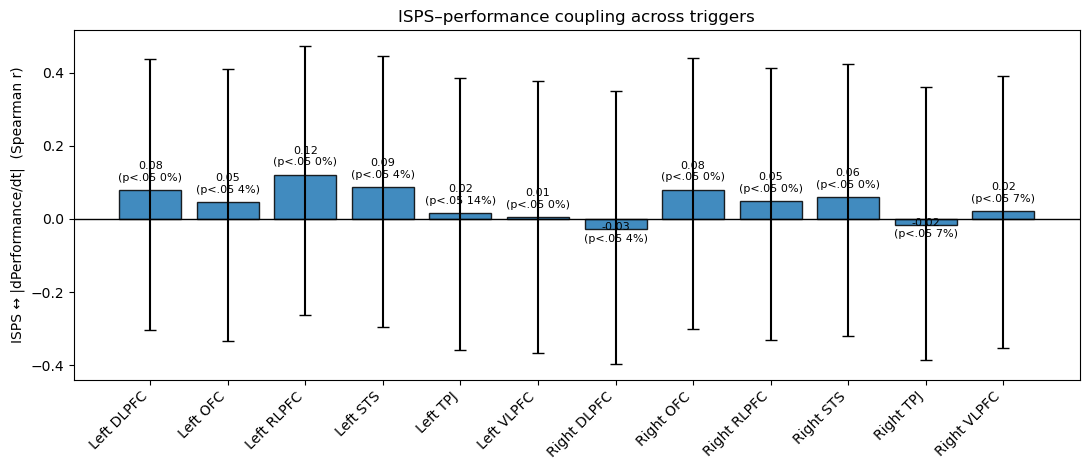

✓ Saved coupling barplot (performance) to: C:\Users\pkell\PC_low_ISPS\ISPS_coupling_barplot_performance.png


In [57]:
## Median SPLIT ISPS ANALYSIS - new parameters 


# ============================================
# BEHAVIORAL (mean or PCA) → fNIRS PREP → ISPS
# + HRF lag (fixed or xcorr), per-trigger coupling, lag summaries
# ============================================
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, spearmanr
from scipy.signal import butter, filtfilt, hilbert, find_peaks
from factor_analyzer import FactorAnalyzer  # used only if BEHAV_REF='pca'

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & basic config
# -----------------------
beh_root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\pc1_low_beh"
mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\pc1_low"

# >>> ONLY CHANGE: choose your output folder name here (e.g., "low_EQ_ISPS")
RUN_LABEL = "PC_low_ISPS"
save_dir_corrmats = os.path.join(os.getcwd(), RUN_LABEL)
os.makedirs(save_dir_corrmats, exist_ok=True)

# -----------------------
# ISPS / Behavior toggles
# -----------------------
ISPS_METRIC = "kuramoto"      # 'kuramoto' or 'pairwise_sine' (paper-style)
BEHAV_REF   = "mean"          # 'mean' or 'pca' (PC1 consensus across subjects per domain)
LAG_MODE    = "fixed"         # 'fixed' or 'xcorr'
HRF_SEC     = 6.0             # fixed lag (s) if LAG_MODE='fixed'
XCORR_LAG_MAX_SEC = 12.0      # max |lag| for xcorr search (s)

# >>> NEW: combination toggle for valence + arousal into a single performance time series
BEHAV_COMBINE = "pca"        # 'mean' or 'pca'  (domain-combination step)

# -----------------------
# Task video durations (s) for odd triggers
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels)
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# -----------------------
# Utility functions
# -----------------------
def _norm_key_for_indexing(key: str) -> str:
    s = str(key).lower()
    s = s.replace("\\", "/")
    s = os.path.splitext(os.path.basename(s))[0]
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s

# NEW: strip domain words to get a base video name (so CSV "video" matches both "...valence" and "...arousal" columns)
def _base_video_norm(key: str) -> str:
    s = _norm_key_for_indexing(key)
    s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
    s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def crop_to_min_len(arr_list):
    L = min(len(a) for a in arr_list if a is not None)
    return [a[:L] for a in arr_list if a is not None], L

def moving_average(x, w):
    if w <= 1:
        return x
    k = int(round(w))
    pad = k//2
    xp = np.pad(x, (pad, pad), mode='edge')
    ker = np.ones(k)/k
    y = np.convolve(xp, ker, mode='valid')
    return y[:len(x)]

def bandpass(x, fs, lo, hi, order=3):
    x = np.asarray(x, float)
    if np.all(~np.isfinite(x)) or len(x) < 5*order:
        return np.array(x, float)
    b, a = butter(order, [lo/(fs/2.0), hi/(fs/2.0)], btype='band')
    return filtfilt(b, a, x, method='gust')

def circ_shift(arr, k):
    if k == 0 or len(arr) == 0:
        return arr
    k = int(k) % len(arr)
    return np.concatenate([arr[-k:], arr[:-k]])

def abs_derivative(x, fs=1.5):
    dx = np.abs(np.diff(x, prepend=x[:1]))
    k = int(round(3*fs))
    if k > 1:
        xp = np.pad(dx, (k//2, k//2), mode="edge")
        ker = np.ones(k)/k
        dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
    return dx

def CCT_average(df, return_ev=False):
    if df.empty:
        raise ValueError("CCT_average received empty DataFrame after NaN drop.")
    n_factors = max(1, min(3, df.shape[1]))
    fa = FactorAnalyzer(rotation=None, n_factors=n_factors)
    fa.fit(df, n_factors)
    ev, _ = fa.get_eigenvalues()
    ev_ratio = ev[0] / ev[1] if (len(ev) > 1 and ev[1] != 0) else np.nan
    consensus = fa.transform(df)[:, 0]
    return (consensus, ev_ratio) if return_ev else consensus

# -----------------------
# Load behavioral time series (per-participant CSVs)
# -----------------------
data_by_video = {}
for csv_file in os.listdir(beh_root):
    if not csv_file.endswith(".csv"):
        continue
    path = os.path.join(beh_root, csv_file)
    subject_id = os.path.splitext(csv_file)[0]
    try:
        df = pd.read_csv(path)
        if df.shape[1] > 1 and df.columns[0].lower() in ["unnamed: 0", "index", ""]:
            df = df.drop(df.columns[0], axis=1)
        for col in df.columns:
            if col not in data_by_video:
                data_by_video[col] = {}
            data_by_video[col][subject_id] = df[col].values
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

valence_videos = {k: v for k, v in data_by_video.items() if 'valence' in k.lower()}
arousal_videos = {k: v for k, v in data_by_video.items() if 'arousal' in k.lower()}

# -----------------------
# Trigger ↔ Video-name mapping (CSV)
# -----------------------
map_df = pd.read_csv(mapping_csv)
lower_cols = {c.lower(): c for c in map_df.columns}
if 'video' not in lower_cols or 'trigger_number' not in lower_cols:
    raise ValueError(f"'video' and 'trigger_number' columns are required in {mapping_csv}. "
                     f"Found: {list(map_df.columns)}")

col_video = lower_cols['video']
col_trig  = lower_cols['trigger_number']

map_df = map_df[[col_video, col_trig]].copy()
map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
map_df = map_df.dropna(subset=["Trigger_int"]).copy()
map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

def _index_behavior_by_name(beh_dict, strip_domains: bool = False):
    idx = {}
    for k in beh_dict.keys():
        nk = _base_video_norm(k) if strip_domains else _norm_key_for_indexing(k)
        idx.setdefault(nk, []).append(k)
    return idx

BEH_BASE_ARO = _index_behavior_by_name(arousal_videos, strip_domains=True)
BEH_BASE_VAL = _index_behavior_by_name(valence_videos, strip_domains=True)
BEH_NAME_ARO = _index_behavior_by_name(arousal_videos, strip_domains=False)
BEH_NAME_VAL = _index_behavior_by_name(valence_videos, strip_domains=False)

def _choose_best(candidates):
    if not candidates:
        return None
    def _score(name):
        n = str(name).lower()
        return (("baseline" in n), len(n))
    return sorted(candidates, key=_score)[0]

def _match_behavior_key_for_trigger(t_int, which="arousal"):
    vidnorm = TRIG2VIDNAME.get(int(t_int), None)
    if vidnorm is None:
        return None

    base_index = BEH_BASE_ARO if which == "arousal" else BEH_BASE_VAL
    if vidnorm in base_index:
        return _choose_best(base_index[vidnorm])

    name_index = BEH_NAME_ARO if which == "arousal" else BEH_NAME_VAL
    if vidnorm in name_index:
        return _choose_best(name_index[vidnorm])

    tokens = [tok for tok in vidnorm.split() if tok]
    cands = []
    for nk, keys in base_index.items():
        nktoks = nk.split()
        shared = len(set(tokens).intersection(nktoks))
        if shared >= 2 or (len(tokens) >= 3 and all(tok in nk for tok in tokens[:3])):
            cands.extend(keys)
    return _choose_best(cands)

ratings = defaultdict(lambda: defaultdict(dict))
unmatched = []

for t_int in sorted(TRIG2VIDNAME.keys()):
    t_key = str(t_int)
    k_aro = _match_behavior_key_for_trigger(t_int, which="arousal")
    if k_aro is not None:
        for subj, arr in arousal_videos[k_aro].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "arousal"))

    k_val = _match_behavior_key_for_trigger(t_int, which="valence")
    if k_val is not None:
        for subj, arr in valence_videos[k_val].items():
            if arr is not None and len(arr) > 0:
                ratings[subj][t_key]["valence"] = np.asarray(arr, float)
    else:
        unmatched.append((t_int, "valence"))

HAVE_BEHAVIOR = len(ratings) > 0
print(f"Behavior mapping from CSV: {len(TRIG2VIDNAME)} triggers; ratings for {len(ratings)} subjects.")
if unmatched:
    missed_str = ", ".join([f"{t}:{d}" for t, d in unmatched])
    print(f"⚠️ Unmatched behavior entries (trigger:domain): {missed_str}")

# -----------------------
# fNIRS preprocessing (Task)
# -----------------------
def individual_analysis(filepath):
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")
    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(1.5)
    return raw

def segment_by_trigger(raw):
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(raw, these, event_id={trig_str: trig_id},
                            tmin=0, tmax=durations[trig_str],
                            baseline=None, detrend=None, preload=True, verbose=False)
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))

for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
triggers = sorted({t for s in roi_ts for t in roi_ts[s]})
rois = list(roi_definitions.keys())

# -----------------------
# ROI pass/fail → kept triggers
# -----------------------
alpha = 0.051
MIN_SUBJ_WITH_DATA = 10
p_sig_required = 0.6

roi_pass_by_trig = defaultdict(dict)
roi_has_data_by_trig = defaultdict(set)
roi_sig_counts_by_trig = defaultdict(dict)
roi_n_by_trig = defaultdict(dict)

for trig in triggers:
    for roi in rois:
        subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
        S = len(subj_with_data)
        if S < MIN_SUBJ_WITH_DATA:
            continue
        min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)
        X = np.stack([roi_ts[s][trig][roi][:min_len] for s in subj_with_data], axis=0)
        roi_has_data_by_trig[trig].add(roi)
        X_sum = X.sum(axis=0)
        sig_count = 0
        for i in range(S):
            loo_mean = (X_sum - X[i]) / (S - 1)
            r, p = pearsonr(X[i], loo_mean)
            if not np.isnan(r) and p < alpha:
                sig_count += 1
        required = math.ceil(p_sig_required * S)
        roi_sig_counts_by_trig[trig][roi] = sig_count
        roi_n_by_trig[trig][roi] = S
        roi_pass_by_trig[trig][roi] = (sig_count >= required)

kept_triggers, dropped_triggers = [], []
for trig in sorted(set(list(roi_pass_by_trig.keys()) + list(roi_has_data_by_trig.keys()))):
    rois_with_data = sorted(roi_has_data_by_trig.get(trig, []))
    if len(rois_with_data) == 0:
        dropped_triggers.append(trig)
        continue
    n_pass = sum(bool(roi_pass_by_trig[trig].get(roi, False)) for roi in rois_with_data)
    threshold = math.ceil(len(rois_with_data) / 2.0)
    if n_pass >= threshold:
        kept_triggers.append(trig)
    else:
        dropped_triggers.append(trig)

print(f"Video-level filter ➜ kept {len(kept_triggers)} videos, dropped {len(dropped_triggers)} videos.")
triggers = kept_triggers

# ======================================================
# DYNAMIC SYNCHRONY (ISPS) + brain–behavior coupling
# ======================================================
FS = 1.5

# UPDATED ISPS PARAMETER (only change): bandpass used to compute phases for ISPS
BP = (0.01, 0.20)

SMOOTH_SEC = 7.0
PEAK_MIN_DISTANCE_SEC = 5.0
PEAK_PROMINENCE = 0.04
N_PERM = 1000
RNG = np.random.default_rng(2025)

def isps_from_phases(P, smooth_sec=5.0, fs=1.5):
    if ISPS_METRIC == "kuramoto":
        z = np.exp(1j * P)
        m = np.nanmean(z, axis=0)
        isps = np.abs(m)
    elif ISPS_METRIC == "pairwise_sine":
        S, T = P.shape
        isps = np.empty(T, float)
        for t in range(T):
            ph = P[:, t]
            d = ph[:, None] - ph[None, :]
            d = (d + np.pi) % (2*np.pi) - np.pi
            iu = np.triu_indices(S, k=1)
            isps[t] = 1.0 - np.mean(np.sin(np.abs(d[iu])))
    else:
        raise ValueError("ISPS_METRIC must be 'kuramoto' or 'pairwise_sine'")
    w = int(round(smooth_sec * fs))
    return moving_average(isps, max(1, w))

def _group_ref_from_traces(traces_2d, mode):
    if traces_2d.size == 0:
        return None
    if mode == "pca":
        df = pd.DataFrame(traces_2d.T)
        df = df.dropna(axis=0, how="any")
        if df.shape[0] < 5 or df.shape[1] < 1:
            return np.nanmean(traces_2d, axis=0)
        pc1 = CCT_average(df, return_ev=False)
        return np.asarray(pc1, float)
    else:
        return np.nanmean(traces_2d, axis=0)

# >>> NEW: combine valence + arousal into a single performance time series (mean or PCA)
def _combine_val_aro_to_perf(val_ref, aro_ref, mode="mean"):
    # Returns a 1D performance series (same length), using either simple average or PC1 across the two domains.
    if (val_ref is None) and (aro_ref is None):
        return None
    if (val_ref is not None) and (aro_ref is not None):
        L = min(len(val_ref), len(aro_ref))
        v = np.asarray(val_ref[:L], float)
        a = np.asarray(aro_ref[:L], float)
        if mode == "mean":
            return 0.5 * (v + a)
        elif mode == "pca":
            # Standardize each domain so scales don't dominate
            v_z = (v - np.nanmean(v)) / (np.nanstd(v, ddof=1) + 1e-9)
            a_z = (a - np.nanmean(a)) / (np.nanstd(a, ddof=1) + 1e-9)
            X = np.vstack([v_z, a_z]).T  # T x 2
            X = X - np.nanmean(X, axis=0, keepdims=True)
            U, S, VT = np.linalg.svd(np.nan_to_num(X), full_matrices=False)
            pc1_timecourse = U[:, 0] * S[0]  # T-vector (PC1 over time)
            # Optional orientation: align with arousal (flip if negative correlation)
            if np.corrcoef(pc1_timecourse, a_z)[0, 1] < 0:
                pc1_timecourse = -pc1_timecourse
            return pc1_timecourse.astype(float)
        else:
            raise ValueError("BEHAV_COMBINE must be 'mean' or 'pca'")
    else:
        # Only one domain present → pass it through
        return val_ref if val_ref is not None else aro_ref

def behavior_performance_for_trig(trig, ratings):
    val_list, aro_list = [], []
    for s in ratings:
        if trig in ratings[s]:
            if "valence" in ratings[s][trig]:
                val_list.append(np.asarray(ratings[s][trig]["valence"], float))
            if "arousal" in ratings[s][trig]:
                aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))

    val_ref = None
    aro_ref = None

    if len(val_list) > 0:
        val_list, _ = crop_to_min_len(val_list)
        V = np.stack(val_list, 0)
        val_ref = _group_ref_from_traces(V, BEHAV_REF)

    if len(aro_list) > 0:
        aro_list, _ = crop_to_min_len(aro_list)
        A = np.stack(aro_list, 0)
        aro_ref = _group_ref_from_traces(A, BEHAV_REF)

    if (val_ref is None) and (aro_ref is None):
        return None

    # >>> NEW: use the combination toggle here (mean or PCA across valence+arousal)
    return _combine_val_aro_to_perf(val_ref, aro_ref, mode=BEHAV_COMBINE)

def compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC):
    isps_by_roi = {}
    n_subj_by_roi = {}
    for roi in rois:
        series = []
        for s in roi_ts:
            ts = roi_ts[s].get(trig, {}).get(roi, None)
            if ts is not None and np.isfinite(ts).any():
                series.append(np.asarray(ts, float))
        if len(series) < 3:
            continue
        series, L = crop_to_min_len(series)
        X = np.stack(series, axis=0)
        Xbp = np.array([bandpass(x, fs, bp[0], bp[1]) for x in X])
        P = np.angle(hilbert(Xbp, axis=1))
        isps = isps_from_phases(P, smooth_sec=smooth_sec, fs=fs)
        isps_by_roi[roi] = isps
        n_subj_by_roi[roi] = X.shape[0]
    return isps_by_roi, n_subj_by_roi

def find_isps_peaks(isps, fs=FS, min_distance_sec=PEAK_MIN_DISTANCE_SEC, prominence=PEAK_PROMINENCE):
    distance = int(round(min_distance_sec * fs))
    peaks, props = find_peaks(isps, distance=max(1, distance), prominence=prominence)
    return peaks, props

def isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG):
    if beh_perf is None:
        return np.nan, np.nan, np.nan
    L = min(len(isps), len(beh_perf))
    isps = isps[:L]
    beh = beh_perf[:L]
    beh_d = abs_derivative(beh, fs=FS)

    if LAG_MODE == "fixed":
        lag_samp = int(round(HRF_SEC * FS))
        beh_use = circ_shift(beh_d, lag_samp)
        chosen_lag_sec = HRF_SEC
    elif LAG_MODE == "xcorr":
        max_k = int(round(XCORR_LAG_MAX_SEC * FS))
        ks = range(-max_k, max_k + 1)
        best_k, best_val = 0, -np.inf
        for k in ks:
            b = circ_shift(beh_d, k if k >= 0 else len(beh_d) + k)
            m = np.isfinite(isps) & np.isfinite(b)
            if m.sum() < 5:
                continue
            r = spearmanr(isps[m], b[m]).correlation
            v = 0.0 if np.isnan(r) else abs(r)
            if v > best_val:
                best_val, best_k = v, k
        beh_use = circ_shift(beh_d, best_k if best_k >= 0 else len(beh_d) + best_k)
        chosen_lag_sec = best_k / FS
    else:
        raise ValueError("LAG_MODE must be 'fixed' or 'xcorr'")

    m = np.isfinite(isps) & np.isfinite(beh_use)
    if m.sum() < 5:
        return np.nan, np.nan, chosen_lag_sec

    r_obs = spearmanr(isps[m], beh_use[m]).correlation
    perm = np.empty(n_perm, float)
    T = len(beh_use)
    for k in range(n_perm):
        shift = int(rng.integers(0, T))
        bsh = circ_shift(beh_use, shift)
        perm[k] = spearmanr(isps[m], bsh[m]).correlation
    p_two = (1.0 + np.sum(np.abs(perm) >= abs(r_obs))) / (n_perm + 1.0)
    return float(r_obs), float(p_two), float(chosen_lag_sec)

# Run ISPS and coupling
all_peak_tables = []
all_coupling = []
plot_payloads = []

for trig in sorted(triggers, key=lambda x: int(x)):
    isps_by_roi, nS = compute_isps_for_trig(trig, roi_ts, rois, fs=FS, bp=BP, smooth_sec=SMOOTH_SEC)
    beh_perf = behavior_performance_for_trig(trig, ratings) if HAVE_BEHAVIOR else None

    for roi, isps in isps_by_roi.items():
        peaks, props = find_isps_peaks(isps, fs=FS,
                                       min_distance_sec=PEAK_MIN_DISTANCE_SEC,
                                       prominence=PEAK_PROMINENCE)
        t_sec = np.arange(len(isps)) / FS
        for i, p in enumerate(peaks):
            all_peak_tables.append({
                "Trigger": trig,
                "ROI": roi,
                "N_subj": nS.get(roi, np.nan),
                "t_idx": int(p),
                "t_sec": float(t_sec[p]),
                "height": float(isps[p]),
                "prominence": float(props["prominences"][i]),
            })

        rP, pP, lagP = isps_behavior_coupling(isps, beh_perf, n_perm=N_PERM, rng=RNG)
        all_coupling.append({
            "Trigger": trig, "ROI": roi, "N_subj": nS.get(roi, np.nan),
            "r_with_abs_dPerformance": rP, "p_two_performance": pP, "lag_sec_performance": lagP,
            "ISPS_metric": ISPS_METRIC, "Behavior_ref": BEHAV_REF, "Lag_mode": LAG_MODE
        })

        plot_payloads.append({
            "trig": trig, "roi": roi, "isps": isps, "t_sec": t_sec,
            "peaks": peaks, "beh_perf": beh_perf
        })

# ======================================================
# NEW: SAVE ISPS TIMESERIES TRACES (per Trigger×ROI)
#   - Saves one CSV per Trigger×ROI
#   - Also saves one combined long CSV for the whole run
#   - Includes ISPS + (optional) performance + shifted |dPerf/dt| used in your overlay plots
# ======================================================
isps_trace_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_traces")
os.makedirs(isps_trace_dir, exist_ok=True)

_trace_frames = []
for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    t = np.asarray(pack["t_sec"], float)
    L = min(len(isps), len(t))

    df_trace = pd.DataFrame({
        "Trigger": [trig] * L,
        "ROI": [roi] * L,
        "t_sec": t[:L],
        "ISPS": isps[:L],
    })

    bp = pack.get("beh_perf", None)
    if bp is not None:
        bp = np.asarray(bp, float)[:L]
        dp = abs_derivative(bp, fs=FS)[:L]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        df_trace["Performance"] = bp
        df_trace["abs_dPerf_dt_norm_shifted"] = circ_shift(dp, shift)

    out_csv = os.path.join(isps_trace_dir, f"ISPS_trace_ROI-{roi.replace(' ','_')}_trig-{trig}.csv")
    df_trace.to_csv(out_csv, index=False)
    _trace_frames.append(df_trace)

if _trace_frames:
    long_path = os.path.join(isps_trace_dir, "ISPS_traces_LONG_all_triggers_rois.csv")
    pd.concat(_trace_frames, ignore_index=True).to_csv(long_path, index=False)
    print(f"✓ Saved ISPS timeseries traces ➜ {isps_trace_dir}")
    print(f"✓ Saved combined long traces ➜ {long_path}")
else:
    print("⚠️ No plot_payloads found; no ISPS traces were saved.")

# Save per-trigger tables
peaks_df = pd.DataFrame(all_peak_tables)
coupling_df = pd.DataFrame(all_coupling)
peaks_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")
coupling_path = os.path.join(save_dir_corrmats, "ISPS_behavior_coupling_by_trigger_roi_task.csv")
peaks_df.to_csv(peaks_path, index=False)
coupling_df.to_csv(coupling_path, index=False)
print(f"✓ Saved ISPS peaks: {peaks_path}  (rows={len(peaks_df)})")
print(f"✓ Saved ISPS–behavior coupling (performance): {coupling_path}  (rows={len(coupling_df)})")

# ============================================
# Save chosen lags per (ROI, trigger) + summaries
# ============================================
if 'lag_sec_performance' not in coupling_df.columns:
    print("⚠️ No 'lag_sec_performance' column found in coupling_df.")
else:
    if LAG_MODE != "xcorr":
        print(f"ℹ️ LAG_MODE is '{LAG_MODE}'. Lags will be constant at HRF_SEC={HRF_SEC:.1f}s; "
              "xcorr-derived lag inspection is most informative when LAG_MODE='xcorr'.")

    lag_long = coupling_df[["Trigger", "ROI", "lag_sec_performance"]].rename(
        columns={"lag_sec_performance": "lag_sec"}
    )
    lag_long = lag_long[np.isfinite(lag_long["lag_sec"])].copy()

    lag_csv = os.path.join(save_dir_corrmats, "ISPS_lags_by_trigger_roi_task.csv")
    lag_long.to_csv(lag_csv, index=False)
    print(f"✓ Saved chosen lags per (ROI, trigger) ➜ {lag_csv}  (rows={len(lag_long)})")

    rows = []
    for roi, sub in lag_long.groupby("ROI"):
        x = sub["lag_sec"].values
        if x.size == 0:
            continue
        mean = float(np.mean(x))
        med  = float(np.median(x))
        sd   = float(np.std(x, ddof=1)) if x.size > 1 else np.nan
        lo, hi = (np.percentile(x, [2.5, 97.5]) if x.size >= 4 else (np.nan, np.nan))
        rows.append({
            "ROI": roi, "n": int(x.size),
            "lag_mean": mean, "lag_median": med, "lag_sd": sd,
            "lag_p2.5": float(lo), "lag_p97.5": float(hi)
        })
    lag_summ = pd.DataFrame(rows).sort_values(["ROI"])
    lag_summ_csv = os.path.join(save_dir_corrmats, "ISPS_lag_summary_by_roi.csv")
    lag_summ.to_csv(lag_summ_csv, index=False)
    print(f"✓ Saved lag summary by ROI ➜ {lag_summ_csv}")


# ======================================================
# PLOTS: per-trigger × ROI ISPS series with |dPerformance/dt| overlay
# ======================================================
isps_plot_dir = os.path.join(save_dir_corrmats, "ISPS_timeseries_plots")
os.makedirs(isps_plot_dir, exist_ok=True)

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps, t = pack["isps"], pack["t_sec"]
    peaks = pack["peaks"]
    bp = pack["beh_perf"]

    plt.figure(figsize=(9, 4.5))
    plt.plot(t, isps, lw=2, label="ISPS")
    if len(peaks) > 0:
        plt.plot(t[peaks], isps[peaks], "o", ms=6, label="Peaks")

    if bp is not None:
        dp = abs_derivative(bp, fs=FS)[:len(t)]
        dp = (dp - np.nanmin(dp)) / (np.nanmax(dp) - np.nanmin(dp) + 1e-9)
        shift = int(round(HRF_SEC * FS)) if LAG_MODE == "fixed" else 0
        dp_show = circ_shift(dp, shift)
        plt.plot(t, dp_show, linestyle="--", alpha=0.75, label="|dPerformance/dt| (norm)")

    plt.xlabel("Time (s)")
    plt.ylabel("ISPS")
    plt.title(f"ISPS — ROI: {roi}  |  Trigger {trig}")
    plt.legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    out_png = os.path.join(isps_plot_dir, f"ISPS_ROI-{roi.replace(' ','_')}_trig-{trig}.png")
    plt.savefig(out_png, dpi=200)
    plt.close()

print(f"✓ Saved per-trigger ISPS plots to: {isps_plot_dir}")

# ======================================================
# ROI-level coupling barplot (Fisher-z mean across triggers) with 95% CI
# ======================================================
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def roi_level_coupling_bars_perf(coupling_df):
    col_r = "r_with_abs_dPerformance"
    col_p = "p_two_performance"
    rows = []
    for roi, sub in coupling_df.groupby("ROI"):
        rvals = sub[col_r].values
        rvals = rvals[np.isfinite(rvals)]
        if rvals.size == 0:
            rows.append({"ROI": roi, "r_mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0, "p_sig_frac": np.nan})
            continue
        z = fisher_z(rvals)
        z_mean = np.nanmean(z)
        n = np.sum(np.isfinite(z))
        se = 1/np.sqrt(max(n-3, 1))
        lo_z = z_mean - 1.96*se
        hi_z = z_mean + 1.96*se
        rows.append({
            "ROI": roi,
            "r_mean": inv_z(z_mean),
            "lo": inv_z(lo_z),
            "hi": inv_z(hi_z),
            "n": int(n),
            "p_sig_frac": np.mean(sub[col_p].values < 0.05)
        })
    out = pd.DataFrame(rows).sort_values("ROI")
    return out

agg = roi_level_coupling_bars_perf(coupling_df)
plt.figure(figsize=(11, 4.8))
order = agg["ROI"].tolist()
means = agg["r_mean"].values
yerr = np.vstack([means - agg["lo"].values, agg["hi"].values - means])
bars = plt.bar(order, means, yerr=yerr, capsize=4, edgecolor="black", alpha=0.85)
for b, m, frac in zip(bars, means, agg["p_sig_frac"].values):
    if np.isfinite(m):
        plt.text(b.get_x()+b.get_width()/2, m + (0.02 if m>=0 else -0.04),
                 f"{m:.2f}\n(p<.05 {frac:.0%})", ha="center", va="bottom", fontsize=8)
plt.axhline(0, color="k", lw=1)
plt.ylabel("ISPS ↔ |dPerformance/dt|  (Spearman r)")
plt.title("ISPS–performance coupling across triggers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
out_png = os.path.join(save_dir_corrmats, "ISPS_coupling_barplot_performance.png")  
plt.savefig(out_png, dpi=220)
plt.show()
print(f"✓ Saved coupling barplot (performance) to: {out_png}")


In [25]:
# === HIGH vs LOW ISPS trace deviation analysis (ROI × Video/Trigger × time) ===
# Computes:
#   1) time-series deviation at each timepoint: dev(t) = ISPS_high(t) - ISPS_low(t)
#   2) per (Video×ROI) deviation summary: mean(dev), mean(|dev|), RMS(dev)
#   3) experiment-level deviation metric: mean across all (Video×ROI) summaries (+ bootstrap CI)
#
# You can use either:
#   A) two separate files (HIGH_CSV and LOW_CSV), OR
#   B) one combined file with a Group column (set COMBINED_CSV and leave HIGH/LOW None).
#
# Dependencies: pandas, numpy

import os
import numpy as np
import pandas as pd

# -----------------------------
# USER: set your file paths here
# -----------------------------
HIGH_CSV = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"  # <-- change
LOW_CSV  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"   # <-- change

# If you have ONE combined file with a Group column instead, use this and set HIGH_CSV=LOW_CSV=None
COMBINED_CSV = None  # r"/path/to/ISPS_traces_LONG_all_triggers_rois_with_group.csv"

OUT_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\High_Low Deviation"  # <-- change (or set to None to save next to input)

# -----------------------------
# Settings (usually leave as-is)
# -----------------------------
TIME_ROUND_DECIMALS = 6         # helps merge floats like 0.6666667 vs 0.666667
MERGE_HOW = "inner"             # "inner" keeps only matched timepoints; "outer" will introduce NaNs
BOOT_N = 20000                  # bootstrap resamples for CI
RNG_SEED = 12345
CI_LEVEL = 0.95

# -----------------------------
# Helpers
# -----------------------------
def _pick_col(df, candidates, required=True, label="column"):
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    if required:
        raise ValueError(f"Could not find {label}. Tried: {candidates}. Available: {list(df.columns)}")
    return None

def _infer_value_col(df, exclude_cols):
    # Prefer ISPS if present; otherwise choose the first numeric col not in exclude list.
    if "ISPS" in df.columns:
        return "ISPS"
    if "isps" in [c.lower() for c in df.columns]:
        return [c for c in df.columns if c.lower() == "isps"][0]
    numeric_cols = [c for c in df.columns if c not in exclude_cols and pd.api.types.is_numeric_dtype(df[c])]
    if not numeric_cols:
        raise ValueError(f"No numeric value column found besides {exclude_cols}.")
    return numeric_cols[0]

def _standardize_trace_df(df, *, video_col=None, roi_col=None, time_col=None, value_col=None, group_name="TRACE"):
    # Infer columns if not provided
    video_col = video_col or _pick_col(df, ["Video", "video", "clip", "Clip", "Trigger", "trigger", "trial", "Trial"], label="video/trigger column")
    roi_col   = roi_col   or _pick_col(df, ["ROI", "roi", "Region", "region"], label="ROI column")
    time_col  = time_col  or _pick_col(df, ["t_sec", "t", "time", "time_sec", "sec", "seconds"], label="time column")

    exclude = {video_col, roi_col, time_col}
    value_col = value_col or _infer_value_col(df, exclude)

    out = df[[video_col, roi_col, time_col, value_col]].copy()
    out = out.rename(columns={video_col: "video", roi_col: "roi", time_col: "t_sec", value_col: f"value_{group_name}"})
    out["t_sec"] = pd.to_numeric(out["t_sec"], errors="coerce")
    out = out.dropna(subset=["video", "roi", "t_sec", f"value_{group_name}"])
    out["t_sec"] = out["t_sec"].round(TIME_ROUND_DECIMALS)
    return out

def _bootstrap_mean_ci(x, n_boot=20000, ci=0.95, seed=12345):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    boot_means = x[idx].mean(axis=1)
    alpha = 1 - ci
    lo = np.quantile(boot_means, alpha/2)
    hi = np.quantile(boot_means, 1 - alpha/2)
    return x.mean(), (lo, hi)

# -----------------------------
# Load data (two-file or combined)
# -----------------------------
if COMBINED_CSV is not None:
    df_all = pd.read_csv(COMBINED_CSV)
    group_col = _pick_col(df_all, ["Group", "group", "GROUP"], label="Group column")
    # Expect group labels to include "high" and "low" (case-insensitive)
    g = df_all[group_col].astype(str).str.lower()
    df_high_raw = df_all[g.str.contains("high")].copy()
    df_low_raw  = df_all[g.str.contains("low")].copy()
    if df_high_raw.empty or df_low_raw.empty:
        raise ValueError(f"Combined file must include both HIGH and LOW rows in {group_col}. "
                         f"Found: {sorted(df_all[group_col].astype(str).unique())}")
else:
    if HIGH_CSV is None or LOW_CSV is None:
        raise ValueError("Set either (HIGH_CSV and LOW_CSV) OR COMBINED_CSV.")
    df_high_raw = pd.read_csv(HIGH_CSV)
    df_low_raw  = pd.read_csv(LOW_CSV)

high = _standardize_trace_df(df_high_raw, group_name="high")
low  = _standardize_trace_df(df_low_raw,  group_name="low")

# -----------------------------
# Merge and compute time-series deviations
# -----------------------------
merged = pd.merge(
    high, low,
    on=["video", "roi", "t_sec"],
    how=MERGE_HOW,
    validate="many_to_many"  # safer for real-world data
)

merged["dev"] = merged["value_high"] - merged["value_low"]
merged["abs_dev"] = merged["dev"].abs()
merged["dev_sq"] = merged["dev"] ** 2

# -----------------------------
# Summarize to a single deviation value per (video × roi)
# -----------------------------
by_video_roi = (
    merged.groupby(["video", "roi"], as_index=False)
          .agg(
              n_time=("dev", "size"),
              mean_dev=("dev", "mean"),           # signed (high - low)
              mean_abs_dev=("abs_dev", "mean"),   # magnitude
              rms_dev=("dev_sq", lambda x: float(np.sqrt(np.mean(x))))  # RMS magnitude
          )
)

# -----------------------------
# Experiment-level deviation metric (average across video×roi)
# -----------------------------
exp_mean_dev, exp_mean_dev_ci = _bootstrap_mean_ci(by_video_roi["mean_dev"], n_boot=BOOT_N, ci=CI_LEVEL, seed=RNG_SEED)
exp_mean_abs, exp_mean_abs_ci = _bootstrap_mean_ci(by_video_roi["mean_abs_dev"], n_boot=BOOT_N, ci=CI_LEVEL, seed=RNG_SEED + 1)
exp_rms_mean, exp_rms_mean_ci = _bootstrap_mean_ci(by_video_roi["rms_dev"], n_boot=BOOT_N, ci=CI_LEVEL, seed=RNG_SEED + 2)

# Also useful: ROI-level and Video-level averages (optional but handy)
by_roi = (by_video_roi.groupby("roi", as_index=False)
          .agg(n_video=("video", "nunique"),
               mean_dev=("mean_dev", "mean"),
               mean_abs_dev=("mean_abs_dev", "mean"),
               rms_dev=("rms_dev", "mean")))

by_video = (by_video_roi.groupby("video", as_index=False)
            .agg(n_roi=("roi", "nunique"),
                 mean_dev=("mean_dev", "mean"),
                 mean_abs_dev=("mean_abs_dev", "mean"),
                 rms_dev=("rms_dev", "mean")))

# -----------------------------
# Print concise results
# -----------------------------
print("\n=== HIGH - LOW ISPS trace deviation summary ===")
print(f"Matched timepoints (rows): {len(merged):,}")
print(f"Unique videos/triggers:     {merged['video'].nunique():,}")
print(f"Unique ROIs:               {merged['roi'].nunique():,}")
print(f"Video×ROI pairs:           {len(by_video_roi):,}")

print("\n--- Experiment-level metrics (mean across Video×ROI) ---")
print(f"Mean signed deviation (HIGH-LOW): {exp_mean_dev:.6f}   [{exp_mean_dev_ci[0]:.6f}, {exp_mean_dev_ci[1]:.6f}]  (bootstrap {int(CI_LEVEL*100)}% CI)")
print(f"Mean absolute deviation:          {exp_mean_abs:.6f}   [{exp_mean_abs_ci[0]:.6f}, {exp_mean_abs_ci[1]:.6f}]  (bootstrap {int(CI_LEVEL*100)}% CI)")
print(f"Mean RMS deviation:               {exp_rms_mean:.6f}   [{exp_rms_mean_ci[0]:.6f}, {exp_rms_mean_ci[1]:.6f}]  (bootstrap {int(CI_LEVEL*100)}% CI)")

# -----------------------------
# Save outputs
# -----------------------------
if OUT_DIR is None:
    # default: save next to whichever input exists
    base = COMBINED_CSV if COMBINED_CSV is not None else HIGH_CSV
    OUT_DIR = os.path.dirname(os.path.abspath(base))
os.makedirs(OUT_DIR, exist_ok=True)

merged_out = os.path.join(OUT_DIR, "HIGH_minus_LOW_timeseries_deviation_long.csv")
vroi_out   = os.path.join(OUT_DIR, "HIGH_minus_LOW_deviation_by_video_x_roi.csv")
roi_out    = os.path.join(OUT_DIR, "HIGH_minus_LOW_deviation_by_roi.csv")
video_out  = os.path.join(OUT_DIR, "HIGH_minus_LOW_deviation_by_video.csv")

merged.to_csv(merged_out, index=False)
by_video_roi.to_csv(vroi_out, index=False)
by_roi.to_csv(roi_out, index=False)
by_video.to_csv(video_out, index=False)

print("\nSaved:")
print(" -", merged_out)
print(" -", vroi_out)
print(" -", roi_out)
print(" -", video_out)



=== HIGH - LOW ISPS trace deviation summary ===
Matched timepoints (rows): 35,952
Unique videos/triggers:     28
Unique ROIs:               12
Video×ROI pairs:           336

--- Experiment-level metrics (mean across Video×ROI) ---
Mean signed deviation (HIGH-LOW): 0.012219   [0.001263, 0.023275]  (bootstrap 95% CI)
Mean absolute deviation:          0.126602   [0.121439, 0.132088]  (bootstrap 95% CI)
Mean RMS deviation:               0.150562   [0.144617, 0.156616]  (bootstrap 95% CI)

Saved:
 - C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\High_Low Deviation\HIGH_minus_LOW_timeseries_deviation_long.csv
 - C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\High_Low Deviation\HIGH_minus_LOW_deviation_by_video_x_roi.csv
 - C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\High_Low Deviation\HIGH_minus_LOW_deviation_by_roi.csv
 - C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\High_Lo

In [ ]:
# === Inside-vs-Outside Peaks test for |dPerformance/dt| (+ FDR) ===
# Also recomputes per-peak window correlations summary so you can report both.
import os
import numpy as np
import pandas as pd

WIN_SEC = 4 #4.5              # half-window for "inside" (±6s) -> total ~13s
PERM_N = 2000              # permutation count for inside-vs-outside difference
RNG = np.random.default_rng(2025)

def _prep_behavior_for_compare(perf_series):
    """Make behavioral reference comparable to ISPS: |d/dt| and HRF shift if fixed."""
    if perf_series is None:
        return None
    beh = np.asarray(perf_series, float)
    beh = abs_derivative(beh, fs=FS)
    if LAG_MODE == "fixed":
        beh = circ_shift(beh, int(round(HRF_SEC * FS)))
    return beh

def benjamini_hochberg(pvals):
    p = np.asarray(pvals, float)
    n = p.size
    order = np.argsort(p)
    ranks = np.arange(1, n+1)
    q = np.empty_like(p)
    q[order] = np.minimum.accumulate((p[order] * n / ranks)[::-1])[::-1]
    q = np.clip(q, 0, 1)
    return q

WIN_SAMP = int(round(WIN_SEC * FS))
io_rows = []     # inside-vs-outside results

# Optional: also compute per-peak window correlations and summarize (to "show both")
def fisher_z(r): return np.arctanh(np.clip(r, -0.999999, 0.999999))
def inv_z(z):    return np.tanh(z)
pw_rows = []     # per-peak correlations
pws_rows = []    # per (ROI,Trigger) summary

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    peaks = np.asarray(pack["peaks"], int)
    beh_perf = pack.get("beh_perf", None)
    behref = _prep_behavior_for_compare(beh_perf)
    if behref is None or len(isps) < 3 or len(peaks) == 0:
        continue

    T = min(len(isps), len(behref))
    isps   = isps[:T]
    behref = behref[:T]
    finite = np.isfinite(behref)

    # --- Build inside mask: union of ±WIN_SAMP around each peak ---
    inside = np.zeros(T, dtype=bool)
    for p in peaks:
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        inside[i0:i1] = True
    outside = ~inside

    # Require finite values
    in_vals  = behref[inside & finite]
    out_vals = behref[outside & finite]

    if in_vals.size >= 5 and out_vals.size >= 5:
        # Observed difference of means
        diff_obs = float(np.nanmean(in_vals) - np.nanmean(out_vals))

        # Permutation: circularly shift the behavior series, keep peak mask fixed
        perm = np.empty(PERM_N, float)
        for k in range(PERM_N):
            sh = int(RNG.integers(0, T))
            bsh = np.concatenate([behref[-sh:], behref[:-sh]]) if sh else behref
            in_k  = bsh[inside & np.isfinite(bsh)]
            out_k = bsh[outside & np.isfinite(bsh)]
            # guard for rare degeneracy
            if in_k.size < 3 or out_k.size < 3:
                perm[k] = np.nan
            else:
                perm[k] = np.nanmean(in_k) - np.nanmean(out_k)
        perm = perm[np.isfinite(perm)]
        if perm.size == 0:
            p_two = np.nan
        else:
            p_two = (1.0 + np.sum(np.abs(perm) >= abs(diff_obs))) / (perm.size + 1.0)

        io_rows.append({
            "Trigger": trig, "ROI": roi,
            "n_inside": int(in_vals.size), "n_outside": int(out_vals.size),
            "mean_inside": float(np.nanmean(in_vals)),
            "mean_outside": float(np.nanmean(out_vals)),
            "diff_inside_minus_outside": diff_obs,
            "p_perm_two": float(p_two),
            "win_half_sec": float(WIN_SEC)
        })

    # --- Per-peak window correlations (complementary metric) ---
    for p in peaks:
        i0, i1 = p - WIN_SAMP, p + WIN_SAMP + 1
        if i0 < 0 or i1 > T:
            continue
        x = isps[i0:i1]
        y = behref[i0:i1]
        m = np.isfinite(x) & np.isfinite(y)
        if m.sum() < 5:
            continue
        r = float(pd.Series(x[m]).corr(pd.Series(y[m]), method="spearman"))
        pw_rows.append({
            "Trigger": trig, "ROI": roi, "t_peak_sec": float(p/FS),
            "r_peakwin": r, "win_half_sec": float(WIN_SEC)
        })

# --- Save inside-vs-outside table and apply BH-FDR ---
io_df = pd.DataFrame(io_rows)
io_csv = os.path.join(save_dir_corrmats, "PC_LOW_ISPS_behavior_inside_vs_outside.csv")
if not io_df.empty:
    io_df["q_fdr_two"] = benjamini_hochberg(io_df["p_perm_two"].values)
    io_df.to_csv(io_csv, index=False)
    print(f"✓ Saved inside-vs-outside results → {io_csv} (rows={len(io_df)})")
else:
    print("⚠️ No inside-vs-outside results computed (missing peaks or behavior).")

# --- Save per-peak correlation table + summary by (ROI, Trigger) ---
pw_df = pd.DataFrame(pw_rows)
pw_csv = os.path.join(save_dir_corrmats, "PC_LOW_ISPS_behavior_peakwindow_correlations.csv")
if not pw_df.empty:
    pw_df.to_csv(pw_csv, index=False)
    # summarize with Fisher-z across peaks per (ROI, Trigger)
    for (trig, roi), sub in pw_df.groupby(["Trigger","ROI"]):
        rvals = sub["r_peakwin"].values
        z = fisher_z(rvals[np.isfinite(rvals)])
        if z.size == 0:
            continue
        z_mean = np.mean(z)
        n = len(z)
        se = 1/np.sqrt(max(n-3, 1))
        lo, hi = z_mean - 1.96*se, z_mean + 1.96*se
        pws_rows.append({
            "Trigger": trig, "ROI": roi, "n_peaks": int(n),
            "r_mean": float(inv_z(z_mean)),
            "r_lo95": float(inv_z(lo)), "r_hi95": float(inv_z(hi)),
            "win_half_sec": float(WIN_SEC)
        })
    pws_df = pd.DataFrame(pws_rows)
    pws_csv = os.path.join(save_dir_corrmats, "PC_LOW_ISPS_behavior_peakwindow_summary.csv")
    pws_df.to_csv(pws_csv, index=False)
    print(f"✓ Saved per-peak correlation table → {pw_csv} (rows={len(pw_df)})")
    print(f"✓ Saved peak-window summary → {pws_csv} (rows={len(pws_df)})")
else:
    print("⚠️ No per-peak correlation results computed.")


In [ ]:
# === Inside-vs-Outside Peaks: correlation-based version (ISPS ↔ |dPerf/dt|) ===
# Replaces the "difference of means" version above.
# It computes r_inside (union of peak windows) and r_outside (complement),
# then tests Δr = r_inside - r_outside via circular-shift permutations.

io_r_rows = []  # new results table: correlation-inside vs correlation-outside

for pack in plot_payloads:
    trig, roi = pack["trig"], pack["roi"]
    isps = np.asarray(pack["isps"], float)
    peaks = np.asarray(pack["peaks"], int)
    beh_perf = pack.get("beh_perf", None)
    behref = _prep_behavior_for_compare(beh_perf)
    if behref is None or len(isps) < 8 or len(peaks) == 0:
        continue

    T = min(len(isps), len(behref))
    isps   = isps[:T]
    behref = behref[:T]

    # Build union-of-windows mask around peaks
    inside = np.zeros(T, dtype=bool)
    for p in peaks:
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        inside[i0:i1] = True
    outside = ~inside

    # Require a minimum number of samples for stable Spearman
    def safe_spearman(x, y):
        m = np.isfinite(x) & np.isfinite(y)
        if m.sum() < 8:
            return np.nan
        return float(pd.Series(x[m]).corr(pd.Series(y[m]), method="spearman"))

    # Observed correlations
    r_in  = safe_spearman(isps[inside],  behref[inside])
    r_out = safe_spearman(isps[outside], behref[outside])

    if not np.isfinite(r_in) or not np.isfinite(r_out):
        continue

    delta_obs = r_in - r_out

    # Permutation: circularly shift behavior, recompute r_in and r_out each time
    perm = np.empty(PERM_N, float)
    for k in range(PERM_N):
        sh = int(RNG.integers(0, T))
        bsh = np.concatenate([behref[-sh:], behref[:-sh]]) if sh else behref
        r_in_k  = safe_spearman(isps[inside],  bsh[inside])
        r_out_k = safe_spearman(isps[outside], bsh[outside])
        perm[k] = (r_in_k - r_out_k) if (np.isfinite(r_in_k) and np.isfinite(r_out_k)) else np.nan

    perm = perm[np.isfinite(perm)]
    if perm.size == 0:
        p_two = np.nan
    else:
        p_two = (1.0 + np.sum(np.abs(perm) >= abs(delta_obs))) / (perm.size + 1.0)

    io_r_rows.append({
        "Trigger": trig, "ROI": roi,
        "n_inside": int(np.sum(inside)), "n_outside": int(np.sum(outside)),
        "r_inside": r_in, "r_outside": r_out,
        "delta_r_inside_minus_outside": delta_obs,
        "p_perm_two": float(p_two),
        "win_half_sec": float(WIN_SEC)
    })

# Save correlation-based inside-vs-outside table (+FDR)
io_r_df = pd.DataFrame(io_r_rows)
io_r_csv = os.path.join(save_dir_corrmats, "PC_LOW_ISPS_behavior_inside_vs_outside_CORR.csv")
if not io_r_df.empty:
    io_r_df["q_fdr_two"] = benjamini_hochberg(io_r_df["p_perm_two"].values)
    io_r_df.to_csv(io_r_csv, index=False)
    print(f"✓ Saved correlation-based inside-vs-outside results → {io_r_csv} (rows={len(io_r_df)})")
else:
    print("⚠️ No correlation-based inside-vs-outside results (insufficient samples).")


In [ ]:
# ============================================================
# PC1 High vs Low — ISPS metrics comparison script
# Loads HIGH/LOW group CSVs (coupling, peak-window, inside–outside),
# prints descriptive summaries, and runs paired statistical tests
# on matched (Trigger, ROI) rows to ask: HIGH > LOW ?
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy import stats

# -----------------------------
# 1) Set paths (edit if needed)
# -----------------------------
# Default: matches the file paths you provided in earlier prompts (this notebook environment)
HIGH = {
    "coupling":  r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_coupling_by_trigger_roi_task.csv",
    "peak_sum":  r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_peakwindow_summary.csv",
    "insideout": r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_inside_vs_outside_CORR.csv",
}
LOW = {
    "coupling":  r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_behavior_coupling_by_trigger_roi_task.csv",
    "peak_sum":  r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_behavior_peakwindow_summary.csv",
    "insideout": r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_behavior_inside_vs_outside_CORR.csv",
}

# If you're running locally, change to your folder and build paths like:
# BASE = r"C:\Users\pkell\roi_video_corrmats"
# HIGH["coupling"] = os.path.join(BASE, "PC_HIGH_ISPS_behavior_coupling_by_trigger_roi_task.csv")
# ... etc ...


# -----------------------------
# 2) Helpers
# -----------------------------
def _assert_exists(p):
    if not os.path.exists(p):
        raise FileNotFoundError(
            f"Missing file:\n  {p}\n\nEdit the HIGH/LOW paths at the top of this script."
        )

def read_csv(p):
    _assert_exists(p)
    return pd.read_csv(p)

def fisher_z(r):
    r = np.asarray(r, float)
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(z)

def fisher_mean_r(rvals):
    rvals = np.asarray(rvals, float)
    rvals = rvals[np.isfinite(rvals)]
    if rvals.size == 0:
        return np.nan
    return float(inv_z(np.nanmean(fisher_z(rvals))))

def bootstrap_ci_fisher_mean_r(rvals, B=5000, seed=2025):
    rng = np.random.default_rng(seed)
    rvals = np.asarray(rvals, float)
    rvals = rvals[np.isfinite(rvals)]
    if rvals.size < 3:
        return (np.nan, np.nan)
    boots = []
    n = rvals.size
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        boots.append(fisher_mean_r(rvals[idx]))
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return (float(lo), float(hi))

def bootstrap_ci_mean(x, B=5000, seed=2025):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size < 3:
        return (np.nan, np.nan)
    boots = []
    n = x.size
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        boots.append(float(np.nanmean(x[idx])))
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return (float(lo), float(hi))

def paired_tests(diffs, n_perm=20000, seed=2025):
    """
    diffs: array of (HIGH - LOW) paired differences.
    Returns paired t-test, Wilcoxon, and sign-flip permutation p-values (one- and two-sided).
    """
    diffs = np.asarray(diffs, float)
    diffs = diffs[np.isfinite(diffs)]
    out = {
        "n": int(diffs.size),
        "mean_diff": float(np.nanmean(diffs)) if diffs.size else np.nan,
        "median_diff": float(np.nanmedian(diffs)) if diffs.size else np.nan,
        "sd_diff": float(np.nanstd(diffs, ddof=1)) if diffs.size > 1 else np.nan,
        "cohen_dz": (float(np.nanmean(diffs) / (np.nanstd(diffs, ddof=1) + 1e-12))
                     if diffs.size > 1 else np.nan),
    }
    if diffs.size < 3:
        out.update({
            "t": np.nan, "p_t_two": np.nan, "p_t_one_high_gt_low": np.nan,
            "w": np.nan, "p_wilcoxon_two": np.nan, "p_wilcoxon_one_high_gt_low": np.nan,
            "p_perm_two": np.nan, "p_perm_one_high_gt_low": np.nan
        })
        return out

    # Paired t-test against 0
    tstat, p_two = stats.ttest_1samp(diffs, 0.0, nan_policy="omit")
    # one-sided p for HIGH>LOW
    p_one = (p_two / 2.0) if (tstat > 0) else (1.0 - p_two / 2.0)

    # Wilcoxon signed-rank (two-sided + one-sided)
    # SciPy's wilcoxon supports alternative in newer versions; fallback if not.
    try:
        w_res = stats.wilcoxon(diffs, zero_method="wilcox", correction=False, alternative="two-sided")
        w_two = w_res.pvalue
        w_stat = w_res.statistic
        w_one = stats.wilcoxon(diffs, zero_method="wilcox", correction=False, alternative="greater").pvalue
    except TypeError:
        # Older SciPy: approximate one-sided by halving when direction matches
        w_stat, w_two = stats.wilcoxon(diffs)
        w_one = (w_two / 2.0) if (np.nanmedian(diffs) > 0) else (1.0 - w_two / 2.0)

    # Sign-flip permutation on mean(diffs)
    rng = np.random.default_rng(seed)
    obs = float(np.nanmean(diffs))
    null = np.empty(n_perm, float)
    for k in range(n_perm):
        signs = rng.choice([-1.0, 1.0], size=diffs.size)
        null[k] = float(np.nanmean(diffs * signs))
    p_perm_two = (1.0 + np.sum(np.abs(null) >= abs(obs))) / (n_perm + 1.0)
    p_perm_one = (1.0 + np.sum(null >= obs)) / (n_perm + 1.0)  # HIGH>LOW

    out.update({
        "t": float(tstat),
        "p_t_two": float(p_two),
        "p_t_one_high_gt_low": float(p_one),
        "w": float(w_stat),
        "p_wilcoxon_two": float(w_two),
        "p_wilcoxon_one_high_gt_low": float(w_one),
        "p_perm_two": float(p_perm_two),
        "p_perm_one_high_gt_low": float(p_perm_one),
    })
    return out

def print_block(title):
    print("\n" + "=" * len(title))
    print(title)
    print("=" * len(title))

def summarize_and_compare(dfH, dfL, key_cols, value_col, value_type="corr",
                          label="", n_perm=20000):
    """
    Matches rows by key_cols, computes HIGH and LOW summaries,
    then paired tests on matched pairs (HIGH - LOW).
    value_type:
      - "corr": treat as correlations -> Fisher-z for tests and Fisher-mean for reporting
      - "diff": treat as simple differences -> mean for reporting/tests
    """
    # keep only finite
    H = dfH[key_cols + [value_col]].copy()
    L = dfL[key_cols + [value_col]].copy()
    H[value_col] = pd.to_numeric(H[value_col], errors="coerce")
    L[value_col] = pd.to_numeric(L[value_col], errors="coerce")

    # inner join on keys to ensure paired comparisons
    M = (H.rename(columns={value_col: "HIGH"})
           .merge(L.rename(columns={value_col: "LOW"}), on=key_cols, how="inner"))

    # numeric arrays
    high = M["HIGH"].to_numpy(dtype=float)
    low  = M["LOW"].to_numpy(dtype=float)

    # descriptive summaries
    if value_type == "corr":
        high_mean = fisher_mean_r(high)
        low_mean  = fisher_mean_r(low)
        high_ci = bootstrap_ci_fisher_mean_r(high, B=5000, seed=2025)
        low_ci  = bootstrap_ci_fisher_mean_r(low,  B=5000, seed=2026)
        # paired diffs on Fisher-z scale (recommended)
        diffs = fisher_z(high) - fisher_z(low)
        diff_mean = float(np.nanmean(diffs))
        diff_ci = bootstrap_ci_mean(diffs, B=5000, seed=2027)
        tests = paired_tests(diffs, n_perm=n_perm, seed=2028)
        # Convert mean diff back to r-scale for intuition (approx)
        diff_r_approx = float(inv_z(diff_mean))
    else:
        high_mean = float(np.nanmean(high))
        low_mean  = float(np.nanmean(low))
        high_ci = bootstrap_ci_mean(high, B=5000, seed=2025)
        low_ci  = bootstrap_ci_mean(low,  B=5000, seed=2026)
        diffs = high - low
        diff_mean = float(np.nanmean(diffs))
        diff_ci = bootstrap_ci_mean(diffs, B=5000, seed=2027)
        tests = paired_tests(diffs, n_perm=n_perm, seed=2028)
        diff_r_approx = np.nan

    print_block(f"{label}  (matched rows = {len(M)})")
    if value_type == "corr":
        print(f"HIGH Fisher-mean r  : {high_mean:+.3f}   95% boot CI [{high_ci[0]:+.3f}, {high_ci[1]:+.3f}]")
        print(f"LOW  Fisher-mean r  : {low_mean:+.3f}   95% boot CI [{low_ci[0]:+.3f}, {low_ci[1]:+.3f}]")
        print(f"Δ (HIGH-LOW) mean z : {diff_mean:+.3f}   95% boot CI [{diff_ci[0]:+.3f}, {diff_ci[1]:+.3f}]")
        print(f"Δ (HIGH-LOW) ~r     : {diff_r_approx:+.3f}  (rough intuition via tanh(mean Δz))")
    else:
        print(f"HIGH mean           : {high_mean:+.3f}   95% boot CI [{high_ci[0]:+.3f}, {high_ci[1]:+.3f}]")
        print(f"LOW  mean           : {low_mean:+.3f}   95% boot CI [{low_ci[0]:+.3f}, {low_ci[1]:+.3f}]")
        print(f"Δ (HIGH-LOW) mean   : {diff_mean:+.3f}   95% boot CI [{diff_ci[0]:+.3f}, {diff_ci[1]:+.3f}]")

    # tests
    print("\nPaired tests on matched rows (HIGH - LOW):")
    print(f"n={tests['n']} | meanΔ={tests['mean_diff']:+.4f} | dz={tests['cohen_dz']:+.3f}")
    print(f"t-test:      t={tests['t']:+.3f}  p(two)={tests['p_t_two']:.4g}  p(one, HIGH>LOW)={tests['p_t_one_high_gt_low']:.4g}")
    print(f"Wilcoxon:    W={tests['w']:+.3f}  p(two)={tests['p_wilcoxon_two']:.4g}  p(one, HIGH>LOW)={tests['p_wilcoxon_one_high_gt_low']:.4g}")
    print(f"Permutation: p(two)={tests['p_perm_two']:.4g}  p(one, HIGH>LOW)={tests['p_perm_one_high_gt_low']:.4g}")

    return M


# -----------------------------
# 3) Load data
# -----------------------------
dfH_coup = read_csv(HIGH["coupling"])
dfL_coup = read_csv(LOW["coupling"])

dfH_peak = read_csv(HIGH["peak_sum"])
dfL_peak = read_csv(LOW["peak_sum"])

dfH_io   = read_csv(HIGH["insideout"])
dfL_io   = read_csv(LOW["insideout"])

print_block("Loaded files")
print("HIGH coupling :", HIGH["coupling"])
print("LOW  coupling :", LOW["coupling"])
print("HIGH peak     :", HIGH["peak_sum"])
print("LOW  peak     :", LOW["peak_sum"])
print("HIGH insideout:", HIGH["insideout"])
print("LOW  insideout:", LOW["insideout"])


# -----------------------------
# 4) Print quick previews
# -----------------------------
print_block("Quick preview: HIGH coupling head()")
print(dfH_coup.head(5).to_string(index=False))

print_block("Quick preview: LOW coupling head()")
print(dfL_coup.head(5).to_string(index=False))

print_block("Quick preview: HIGH peak-window summary head()")
print(dfH_peak.head(5).to_string(index=False))

print_block("Quick preview: LOW peak-window summary head()")
print(dfL_peak.head(5).to_string(index=False))

print_block("Quick preview: HIGH inside–outside CORR head()")
print(dfH_io.head(5).to_string(index=False))

print_block("Quick preview: LOW inside–outside CORR head()")
print(dfL_io.head(5).to_string(index=False))


# -----------------------------
# 5) Identify columns robustly
# -----------------------------
def find_col(df, candidates):
    lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    # try partial match
    for c in df.columns:
        cl = c.lower()
        for cand in candidates:
            if cand.lower() in cl:
                return c
    return None

# Coupling metric column
coup_r_col = find_col(dfH_coup, ["r_with_abs_dPerformance", "r_with_abs_dperformance", "r_with_abs_dperf", "r"])
# Peak-window summary metric column
peak_r_col = find_col(dfH_peak, ["r_mean", "r", "r_peakwin_mean"])
# Inside-outside correlation-based delta column + inside/outside columns
io_d_col   = find_col(dfH_io, ["delta_r_inside_minus_outside", "delta", "diff"])
io_in_col  = find_col(dfH_io, ["r_inside"])
io_out_col = find_col(dfH_io, ["r_outside"])

if coup_r_col is None:
    raise RuntimeError("Couldn't find coupling r column in coupling CSV.")
if peak_r_col is None:
    raise RuntimeError("Couldn't find r_mean column in peak-window summary CSV.")
if io_d_col is None:
    raise RuntimeError("Couldn't find delta_r_inside_minus_outside column in inside–outside CORR CSV.")
if io_in_col is None or io_out_col is None:
    raise RuntimeError("Couldn't find r_inside / r_outside columns in inside–outside CORR CSV.")

# Key columns (Trigger, ROI)
key_trigger_coup = find_col(dfH_coup, ["Trigger"])
key_roi_coup     = find_col(dfH_coup, ["ROI"])
key_trigger_peak = find_col(dfH_peak, ["Trigger"])
key_roi_peak     = find_col(dfH_peak, ["ROI"])
key_trigger_io   = find_col(dfH_io,   ["Trigger"])
key_roi_io       = find_col(dfH_io,   ["ROI"])

for nm, col in [("Trigger(coupling)", key_trigger_coup), ("ROI(coupling)", key_roi_coup),
                ("Trigger(peak)", key_trigger_peak), ("ROI(peak)", key_roi_peak),
                ("Trigger(insideout)", key_trigger_io), ("ROI(insideout)", key_roi_io)]:
    if col is None:
        raise RuntimeError(f"Couldn't find required key column: {nm}")

# Standardize types for joining
def normalize_keys(df, trig_col, roi_col):
    out = df.copy()
    out[trig_col] = out[trig_col].astype(str)
    out[roi_col]  = out[roi_col].astype(str)
    return out

dfH_coup = normalize_keys(dfH_coup, key_trigger_coup, key_roi_coup)
dfL_coup = normalize_keys(dfL_coup, key_trigger_coup, key_roi_coup)
dfH_peak = normalize_keys(dfH_peak, key_trigger_peak, key_roi_peak)
dfL_peak = normalize_keys(dfL_peak, key_trigger_peak, key_roi_peak)
dfH_io   = normalize_keys(dfH_io,   key_trigger_io,   key_roi_io)
dfL_io   = normalize_keys(dfL_io,   key_trigger_io,   key_roi_io)


# -----------------------------
# 6) Comparisons
# -----------------------------
# A) Overall coupling (Trigger×ROI rows)
M_coup = summarize_and_compare(
    dfH_coup, dfL_coup,
    key_cols=[key_trigger_coup, key_roi_coup],
    value_col=coup_r_col,
    value_type="corr",
    label="(A) Overall coupling: r_with_abs_dPerformance",
    n_perm=20000
)

# B) Peak-window summary (Trigger×ROI r_mean)
M_peak = summarize_and_compare(
    dfH_peak, dfL_peak,
    key_cols=[key_trigger_peak, key_roi_peak],
    value_col=peak_r_col,
    value_type="corr",
    label="(B) Peak-window summary: r_mean",
    n_perm=20000
)

# C) Inside–Outside Δr (Trigger×ROI)
M_io_delta = summarize_and_compare(
    dfH_io, dfL_io,
    key_cols=[key_trigger_io, key_roi_io],
    value_col=io_d_col,
    value_type="diff",
    label="(C) Inside–Outside: Δr = r_inside - r_outside",
    n_perm=20000
)

# Optional: also compare r_inside and r_outside separately
M_io_in = summarize_and_compare(
    dfH_io, dfL_io,
    key_cols=[key_trigger_io, key_roi_io],
    value_col=io_in_col,
    value_type="corr",
    label="(C2) Inside-only coupling: r_inside",
    n_perm=20000
)

M_io_out = summarize_and_compare(
    dfH_io, dfL_io,
    key_cols=[key_trigger_io, key_roi_io],
    value_col=io_out_col,
    value_type="corr",
    label="(C3) Outside-only coupling: r_outside",
    n_perm=20000
)


# -----------------------------
# 7) ROI-level rollups (optional, helpful printout)
# -----------------------------
def roi_rollup_corr(df, roi_col, r_col, label):
    tmp = df[[roi_col, r_col]].copy()
    tmp[r_col] = pd.to_numeric(tmp[r_col], errors="coerce")
    out = []
    for roi, sub in tmp.groupby(roi_col):
        r = sub[r_col].to_numpy(dtype=float)
        out.append({
            "ROI": roi,
            "FisherMean_r": fisher_mean_r(r),
            "n_rows": int(np.sum(np.isfinite(r)))
        })
    out = pd.DataFrame(out).sort_values("FisherMean_r", ascending=False)
    print_block(label)
    print(out.to_string(index=False))
    return out

roi_rollup_corr(dfH_coup, key_roi_coup, coup_r_col, "ROI rollup (HIGH) — coupling")
roi_rollup_corr(dfL_coup, key_roi_coup, coup_r_col, "ROI rollup (LOW) — coupling")
roi_rollup_corr(dfH_peak, key_roi_peak, peak_r_col, "ROI rollup (HIGH) — peak-window r_mean")
roi_rollup_corr(dfL_peak, key_roi_peak, peak_r_col, "ROI rollup (LOW) — peak-window r_mean")

# Inside–outside delta rollup (mean)
def roi_rollup_delta(df, roi_col, d_col, label):
    tmp = df[[roi_col, d_col]].copy()
    tmp[d_col] = pd.to_numeric(tmp[d_col], errors="coerce")
    out = (tmp.groupby(roi_col, as_index=False)
              .agg(mean_delta=(d_col, "mean"),
                   n_rows=(d_col, lambda x: int(np.sum(np.isfinite(pd.to_numeric(x, errors="coerce")))))))
    out = out.sort_values("mean_delta", ascending=False)
    print_block(label)
    print(out.to_string(index=False))
    return out

roi_rollup_delta(dfH_io, key_roi_io, io_d_col, "ROI rollup (HIGH) — inside–outside Δr")
roi_rollup_delta(dfL_io, key_roi_io, io_d_col, "ROI rollup (LOW) — inside–outside Δr")

print_block("Done")
print("Interpretation tip: focus on the one-sided permutation p (HIGH>LOW) for your directional hypothesis,")
print("and treat paired tests as comparisons across matched Trigger×ROI rows (same video/ROI pairs).")


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# USER: paths (as provided)
# =========================
HIGH_COUPLING = r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_coupling_by_trigger_roi_task.csv"
LOW_COUPLING  = r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_behavior_coupling_by_trigger_roi_task.csv"

HIGH_INOUT = r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_inside_vs_outside_CORR.csv"
LOW_INOUT  = r"C:\Users\pkell\PC_low_ISPS\PC_low_ISPS_behavior_inside_vs_outside_CORR.csv"  # <-- if this is a typo, fix to your real LOW file name

HIGH_PWSUM = r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_behavior_peakwindow_summary.csv"
LOW_PWSUM  = r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_behavior_peakwindow_summary.csv"

HIGH_PEAKS = r"C:\Users\pkell\PC_high_ISPS\PC_HIGH_ISPS_peaks_by_trigger_roi_task.csv"
LOW_PEAKS  = r"C:\Users\pkell\PC_low_ISPS\PC_LOW_ISPS_peaks_by_trigger_roi_task.csv"


# =========================
# Helpers
# =========================
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return np.arctanh(r)

def inv_fisher_z(z):
    return np.tanh(z)

def paired_perm_p(diff, n_perm=20000, seed=0, alternative="greater"):
    """
    Sign-flip permutation on paired differences.
    alternative:
      "greater": mean(diff) > 0
      "less":    mean(diff) < 0
      "two-sided"
    """
    rng = np.random.default_rng(seed)
    diff = np.asarray(diff)
    diff = diff[np.isfinite(diff)]
    if diff.size == 0:
        return np.nan
    obs = diff.mean()

    signs = rng.choice([-1, 1], size=(n_perm, diff.size), replace=True)
    null = (signs * diff).mean(axis=1)

    if alternative == "greater":
        p = (np.sum(null >= obs) + 1) / (n_perm + 1)
    elif alternative == "less":
        p = (np.sum(null <= obs) + 1) / (n_perm + 1)
    else:
        p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return p

def gaussian_smooth(y, sigma_bins=2.0):
    # simple Gaussian kernel smoothing without scipy
    y = np.asarray(y, float)
    if y.size < 3:
        return y
    radius = int(np.ceil(4 * sigma_bins))
    x = np.arange(-radius, radius + 1)
    k = np.exp(-(x**2) / (2 * sigma_bins**2))
    k /= k.sum()
    return np.convolve(y, k, mode="same")

def sort_pid_like_roi(values):
    # not needed for ROIs; keep alphabetical
    return sorted(values)

def safe_int(x):
    try:
        return int(x)
    except Exception:
        return None


# =========================
# Load data
# =========================
high_inout = pd.read_csv(HIGH_INOUT)
low_inout  = pd.read_csv(LOW_INOUT)

high_pwsum = pd.read_csv(HIGH_PWSUM)
low_pwsum  = pd.read_csv(LOW_PWSUM)

high_peaks = pd.read_csv(HIGH_PEAKS)
low_peaks  = pd.read_csv(LOW_PEAKS)

# =========================
# Build trigger order + boundaries
# =========================
# Triggers are numeric in your files
triggers = sorted(set(high_peaks["Trigger"].unique()).union(set(low_peaks["Trigger"].unique())))

# Use win_half_sec (if present) to pad end a bit
win_half = None
if "win_half_sec" in high_inout.columns and high_inout["win_half_sec"].notna().any():
    win_half = float(high_inout["win_half_sec"].dropna().iloc[0])
elif "win_half_sec" in low_inout.columns and low_inout["win_half_sec"].notna().any():
    win_half = float(low_inout["win_half_sec"].dropna().iloc[0])
if win_half is None:
    win_half = 0.0

# Estimate each trigger duration from max peak time (fallback: 1.0)
dur_by_trig = {}
for t in triggers:
    mx = np.nanmax([
        high_peaks.loc[high_peaks["Trigger"] == t, "t_sec"].max() if (high_peaks["Trigger"] == t).any() else np.nan,
        low_peaks.loc[low_peaks["Trigger"] == t, "t_sec"].max()  if (low_peaks["Trigger"] == t).any()  else np.nan,
    ])
    if not np.isfinite(mx):
        mx = 1.0
    dur_by_trig[t] = float(mx + win_half)  # pad slightly to include windows around late peaks

# Offsets for concatenation
offset_by_trig = {}
cum = 0.0
for t in triggers:
    offset_by_trig[t] = cum
    cum += dur_by_trig[t]

total_dur = cum

# =========================
# Peak “events” table for plotting (absolute time)
# =========================
def add_abs_time(peaks_df, group_name):
    df = peaks_df.copy()
    df["abs_t_sec"] = df.apply(lambda r: offset_by_trig.get(r["Trigger"], 0.0) + float(r["t_sec"]), axis=1)
    df["Group"] = group_name
    return df

peaks_all = pd.concat([
    add_abs_time(high_peaks, "HIGH"),
    add_abs_time(low_peaks, "LOW")
], ignore_index=True)

# Sort ROIs and build y positions as Trigger×ROI rows (so videos are ordered)
rois = sort_pid_like_roi(sorted(set(peaks_all["ROI"].unique())))
roi_to_i = {r:i for i,r in enumerate(rois)}
trig_to_i = {t:i for i,t in enumerate(triggers)}
n_rois = len(rois)

def row_index(trigger, roi):
    return trig_to_i[trigger] * n_rois + roi_to_i[roi]

peaks_all["row_y"] = peaks_all.apply(lambda r: row_index(r["Trigger"], r["ROI"]), axis=1)

# =========================
# Peak density across experiment (HIGH vs LOW)
# =========================
BIN_SEC = 0.5
bins = np.arange(0, total_dur + BIN_SEC, BIN_SEC)
centers = 0.5 * (bins[:-1] + bins[1:])

density = {}
for grp in ["HIGH", "LOW"]:
    x = peaks_all.loc[peaks_all["Group"] == grp, "abs_t_sec"].to_numpy()
    # Weight peaks by prominence if available (else 1)
    if "prominence" in peaks_all.columns:
        w = peaks_all.loc[peaks_all["Group"] == grp, "prominence"].to_numpy()
        w = np.where(np.isfinite(w), w, 1.0)
    else:
        w = np.ones_like(x)
    hist, _ = np.histogram(x, bins=bins, weights=w)
    density[grp] = gaussian_smooth(hist.astype(float), sigma_bins=2.0)

# =========================
# Stats: HIGH vs LOW differences (matched Trigger×ROI)
# =========================
def matched_merge(a, b, cols_keep, suffixA="_HIGH", suffixB="_LOW"):
    key = ["Trigger", "ROI"]
    a2 = a[key + cols_keep].copy()
    b2 = b[key + cols_keep].copy()
    return a2.merge(b2, on=key, how="inner", suffixes=(suffixA, suffixB))

# (1) Inside–Outside delta_r
m_inout = matched_merge(
    high_inout, low_inout,
    cols_keep=["delta_r_inside_minus_outside", "r_inside", "r_outside"]
)

delta_delta = (
    m_inout["delta_r_inside_minus_outside_HIGH"].to_numpy()
    - m_inout["delta_r_inside_minus_outside_LOW"].to_numpy()
)

# (2) Peak counts from peakwindow_summary (n_peaks)
m_pwsum = matched_merge(
    high_pwsum, low_pwsum,
    cols_keep=["n_peaks", "r_mean"]
)
diff_npeaks = m_pwsum["n_peaks_HIGH"].to_numpy() - m_pwsum["n_peaks_LOW"].to_numpy()

# (3) Peak timing features from peaks_by_trigger_roi_task
def timing_features(peaks_df):
    # per Trigger×ROI: first_peak_t, mean_peak_t, n_peaks
    g = peaks_df.groupby(["Trigger", "ROI"])["t_sec"]
    out = g.agg(
        first_peak_t="min",
        mean_peak_t="mean",
        n_peaks="count"
    ).reset_index()
    return out

high_tf = timing_features(high_peaks)
low_tf  = timing_features(low_peaks)

m_tf = high_tf.merge(low_tf, on=["Trigger","ROI"], how="inner", suffixes=("_HIGH","_LOW"))

diff_first = m_tf["first_peak_t_HIGH"].to_numpy() - m_tf["first_peak_t_LOW"].to_numpy()
diff_meanT = m_tf["mean_peak_t_HIGH"].to_numpy() - m_tf["mean_peak_t_LOW"].to_numpy()

def summarize_diff(name, diff, alt="greater"):
    diff = np.asarray(diff)
    diff = diff[np.isfinite(diff)]
    n = diff.size
    if n == 0:
        print(f"{name}: no matched finite rows.")
        return
    obs = diff.mean()
    p_perm_two = paired_perm_p(diff, n_perm=20000, seed=0, alternative="two-sided")
    p_perm_dir = paired_perm_p(diff, n_perm=20000, seed=1, alternative=alt)
    print(f"\n{name}")
    print(f"n={n} | mean(HIGH-LOW)={obs:+.4f}")
    print(f"perm p(two-sided)={p_perm_two:.4g} | perm p(dir:{alt})={p_perm_dir:.4g}")

print("\n============================")
print("HIGH vs LOW (matched rows)")
print("============================")

summarize_diff("Δr inside–outside (HIGH-LOW)  [expect >0]", delta_delta, alt="greater")
summarize_diff("Peak count difference (n_peaks HIGH-LOW)  [theory-dependent]", diff_npeaks, alt="greater")
summarize_diff("First-peak time difference (HIGH-LOW)  [expect <0 if HIGH earlier]", diff_first, alt="less")
summarize_diff("Mean-peak time difference (HIGH-LOW)  [expect <0 if HIGH earlier]", diff_meanT, alt="less")

# ==========================================================
# NEW: ROI-level stats (across triggers) for the same metrics
#   - one row per ROI: mean diff + permutation p-value(s)
# ==========================================================
roi_rows = []
for roi in rois:
    # Δr inside–outside
    sub_inout = m_inout[m_inout["ROI"] == roi].copy()
    d_delta = (sub_inout["delta_r_inside_minus_outside_HIGH"].to_numpy()
               - sub_inout["delta_r_inside_minus_outside_LOW"].to_numpy())
    d_delta = d_delta[np.isfinite(d_delta)]

    # n_peaks diff
    sub_pws  = m_pwsum[m_pwsum["ROI"] == roi].copy()
    d_npk = (sub_pws["n_peaks_HIGH"].to_numpy() - sub_pws["n_peaks_LOW"].to_numpy())
    d_npk = d_npk[np.isfinite(d_npk)]

    # timing diffs
    sub_tf = m_tf[m_tf["ROI"] == roi].copy()
    d_first = (sub_tf["first_peak_t_HIGH"].to_numpy() - sub_tf["first_peak_t_LOW"].to_numpy())
    d_first = d_first[np.isfinite(d_first)]
    d_meanT = (sub_tf["mean_peak_t_HIGH"].to_numpy() - sub_tf["mean_peak_t_LOW"].to_numpy())
    d_meanT = d_meanT[np.isfinite(d_meanT)]

    roi_rows.append({
        "ROI": roi,

        "n_rows_delta_r": int(d_delta.size),
        "mean_diff_delta_r": float(np.nanmean(d_delta)) if d_delta.size else np.nan,
        "p_perm_delta_r_two": float(paired_perm_p(d_delta, alternative="two-sided")) if d_delta.size else np.nan,
        "p_perm_delta_r_dir(H> L)": float(paired_perm_p(d_delta, alternative="greater")) if d_delta.size else np.nan,

        "n_rows_npeaks": int(d_npk.size),
        "mean_diff_npeaks": float(np.nanmean(d_npk)) if d_npk.size else np.nan,
        "p_perm_npeaks_two": float(paired_perm_p(d_npk, alternative="two-sided")) if d_npk.size else np.nan,
        "p_perm_npeaks_dir(H> L)": float(paired_perm_p(d_npk, alternative="greater")) if d_npk.size else np.nan,

        "n_rows_first_peak_t": int(d_first.size),
        "mean_diff_first_peak_t": float(np.nanmean(d_first)) if d_first.size else np.nan,
        "p_perm_first_peak_t_two": float(paired_perm_p(d_first, alternative="two-sided")) if d_first.size else np.nan,
        "p_perm_first_peak_t_dir(H earlier)": float(paired_perm_p(d_first, alternative="less")) if d_first.size else np.nan,

        "n_rows_mean_peak_t": int(d_meanT.size),
        "mean_diff_mean_peak_t": float(np.nanmean(d_meanT)) if d_meanT.size else np.nan,
        "p_perm_mean_peak_t_two": float(paired_perm_p(d_meanT, alternative="two-sided")) if d_meanT.size else np.nan,
        "p_perm_mean_peak_t_dir(H earlier)": float(paired_perm_p(d_meanT, alternative="less")) if d_meanT.size else np.nan,
    })

roi_stats = pd.DataFrame(roi_rows)

print("\n====================================================")
print("ROI-level HIGH vs LOW stats (across triggers)")
print("  (means are across Trigger×ROI rows within each ROI)")
print("====================================================")
# Print a compact view (you still have the full df in roi_stats)
show_cols = [
    "ROI",
    "n_rows_delta_r", "mean_diff_delta_r", "p_perm_delta_r_two", "p_perm_delta_r_dir(H> L)",
    "n_rows_npeaks", "mean_diff_npeaks", "p_perm_npeaks_two",
    "n_rows_first_peak_t", "mean_diff_first_peak_t", "p_perm_first_peak_t_two",
    "n_rows_mean_peak_t", "mean_diff_mean_peak_t", "p_perm_mean_peak_t_two",
]
print(roi_stats[show_cols].to_string(index=False))

# =========================
# Plot: Peak density + raster (one figure)
# =========================
fig = plt.figure(figsize=(14, 10))

ax0 = plt.subplot2grid((3, 1), (0, 0))
ax1 = plt.subplot2grid((3, 1), (1, 0))
ax2 = plt.subplot2grid((3, 1), (2, 0))

# --- Panel 1: peak density (weighted by prominence) ---
ax0.plot(centers, density["HIGH"], label="HIGH (peak density)")
ax0.plot(centers, density["LOW"],  label="LOW (peak density)")
ax0.set_title("ISPS peak density across concatenated experiment (triggers ordered, boundaries dashed)")
ax0.set_ylabel("Smoothed peak weight")
ax0.legend(loc="upper right")

# --- Vertical trigger boundaries + trigger labels ---
for t in triggers:
    x0 = offset_by_trig[t]
    ax0.axvline(x0, linestyle="--", linewidth=1)
# final boundary
ax0.axvline(total_dur, linestyle="--", linewidth=1)

# place trigger labels at midpoints
for t in triggers:
    start = offset_by_trig[t]
    end = start + dur_by_trig[t]
    ax0.text((start + end) / 2, ax0.get_ylim()[1] * 0.95, str(t), ha="center", va="top", fontsize=9)

# --- Panel 2: raster HIGH ---
high_events = peaks_all.loc[peaks_all["Group"] == "HIGH"]
ax1.scatter(high_events["abs_t_sec"], high_events["row_y"], s=8)
ax1.set_title("HIGH group: ISPS peak raster (each row = Trigger×ROI)")
ax1.set_ylabel("Trigger×ROI row")
ax1.set_xlim(0, total_dur)

for t in triggers:
    ax1.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
ax1.axvline(total_dur, linestyle="--", linewidth=1)

# --- Panel 3: raster LOW ---
low_events = peaks_all.loc[peaks_all["Group"] == "LOW"]
ax2.scatter(low_events["abs_t_sec"], low_events["row_y"], s=8)
ax2.set_title("LOW group: ISPS peak raster (each row = Trigger×ROI)")
ax2.set_xlabel("Time (sec) across concatenated experiment")
ax2.set_ylabel("Trigger×ROI row")
ax2.set_xlim(0, total_dur)

for t in triggers:
    ax2.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
ax2.axvline(total_dur, linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

# ==========================================================
# NEW: ROI-stacked peak-weight density plots (12 panels)
#   - Each panel: smoothed peak weight over concatenated time
#   - HIGH vs LOW overlaid (same style as your ROI trace panels)
# ==========================================================
def roi_density_for_group(peaks_all, roi, group, bins):
    sub = peaks_all[(peaks_all["ROI"] == roi) & (peaks_all["Group"] == group)]
    x = sub["abs_t_sec"].to_numpy()

    # weight by prominence if available
    if "prominence" in sub.columns:
        w = sub["prominence"].to_numpy()
        w = np.where(np.isfinite(w), w, 1.0)
    else:
        w = np.ones_like(x)

    hist, _ = np.histogram(x, bins=bins, weights=w)
    return gaussian_smooth(hist.astype(float), sigma_bins=2.0)

fig2, axes = plt.subplots(nrows=len(rois), ncols=1, figsize=(14, max(10, 1.05*len(rois))), sharex=True)
if len(rois) == 1:
    axes = [axes]

for ax, roi in zip(axes, rois):
    yH = roi_density_for_group(peaks_all, roi, "HIGH", bins)
    yL = roi_density_for_group(peaks_all, roi, "LOW", bins)

    ax.plot(centers, yH, lw=1.2, label="HIGH" if roi == rois[0] else None)
    ax.plot(centers, yL, lw=1.2, label="LOW"  if roi == rois[0] else None)

    for t in triggers:
        ax.axvline(offset_by_trig[t], linestyle="--", linewidth=0.8)
    ax.axvline(total_dur, linestyle="--", linewidth=0.8)

    ax.set_ylabel(roi, rotation=0, ha="right", va="center", labelpad=70)

axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("Time (sec) across concatenated experiment")
fig2.suptitle("ROI-stacked ISPS peak weight density (HIGH vs LOW), concatenated triggers", y=0.995)
plt.tight_layout()
plt.show()

# =========================
# Optional: quick “where is HIGH > LOW” for delta_r
# =========================
m_inout2 = m_inout.copy()
m_inout2["delta_diff_HIGH_minus_LOW"] = (
    m_inout2["delta_r_inside_minus_outside_HIGH"] - m_inout2["delta_r_inside_minus_outside_LOW"]
)
top = m_inout2.sort_values("delta_diff_HIGH_minus_LOW", ascending=False).head(15)
bot = m_inout2.sort_values("delta_diff_HIGH_minus_LOW", ascending=True).head(15)

# print("\nTop 15 Trigger×ROI where HIGH has larger (inside–outside Δr) than LOW:")
# print(top[["Trigger","ROI","delta_r_inside_minus_outside_HIGH","delta_r_inside_minus_outside_LOW","delta_diff_HIGH_minus_LOW"]].to_string(index=False))

# print("\nBottom 15 Trigger×ROI where LOW has larger (inside–outside Δr) than HIGH:")
# print(bot[["Trigger","ROI","delta_r_inside_minus_outside_HIGH","delta_r_inside_minus_outside_LOW","delta_diff_HIGH_minus_LOW"]].to_string(index=False))


Loaded HIGH rows=35952 | LOW rows=35952
Found 28 triggers: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]...
Found 12 ROIs: ['Left DLPFC', 'Left OFC', 'Left RLPFC', 'Left STS', 'Left TPJ', 'Left VLPFC', 'Right DLPFC', 'Right OFC', 'Right RLPFC', 'Right STS', 'Right TPJ', 'Right VLPFC']


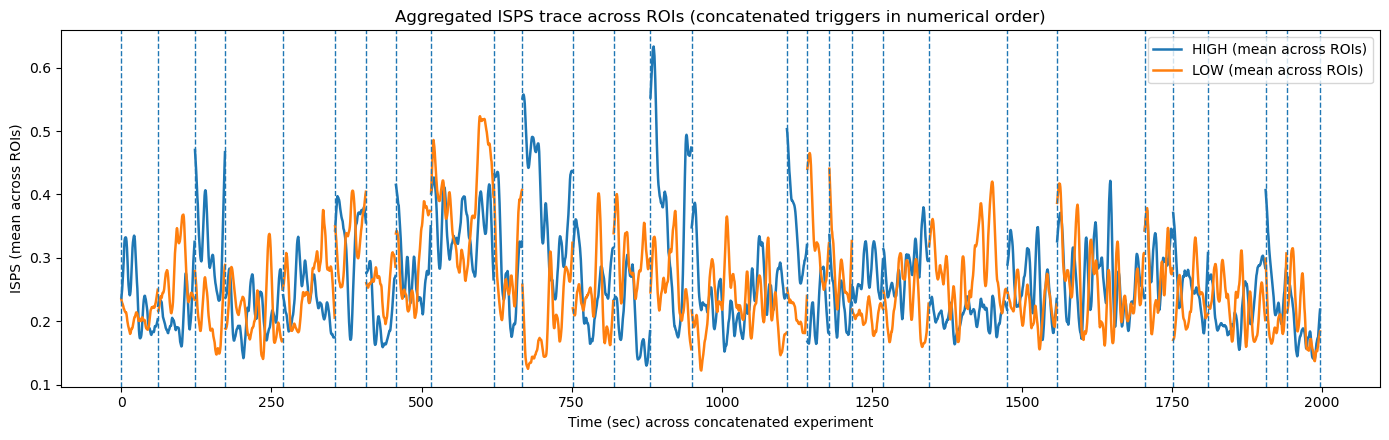

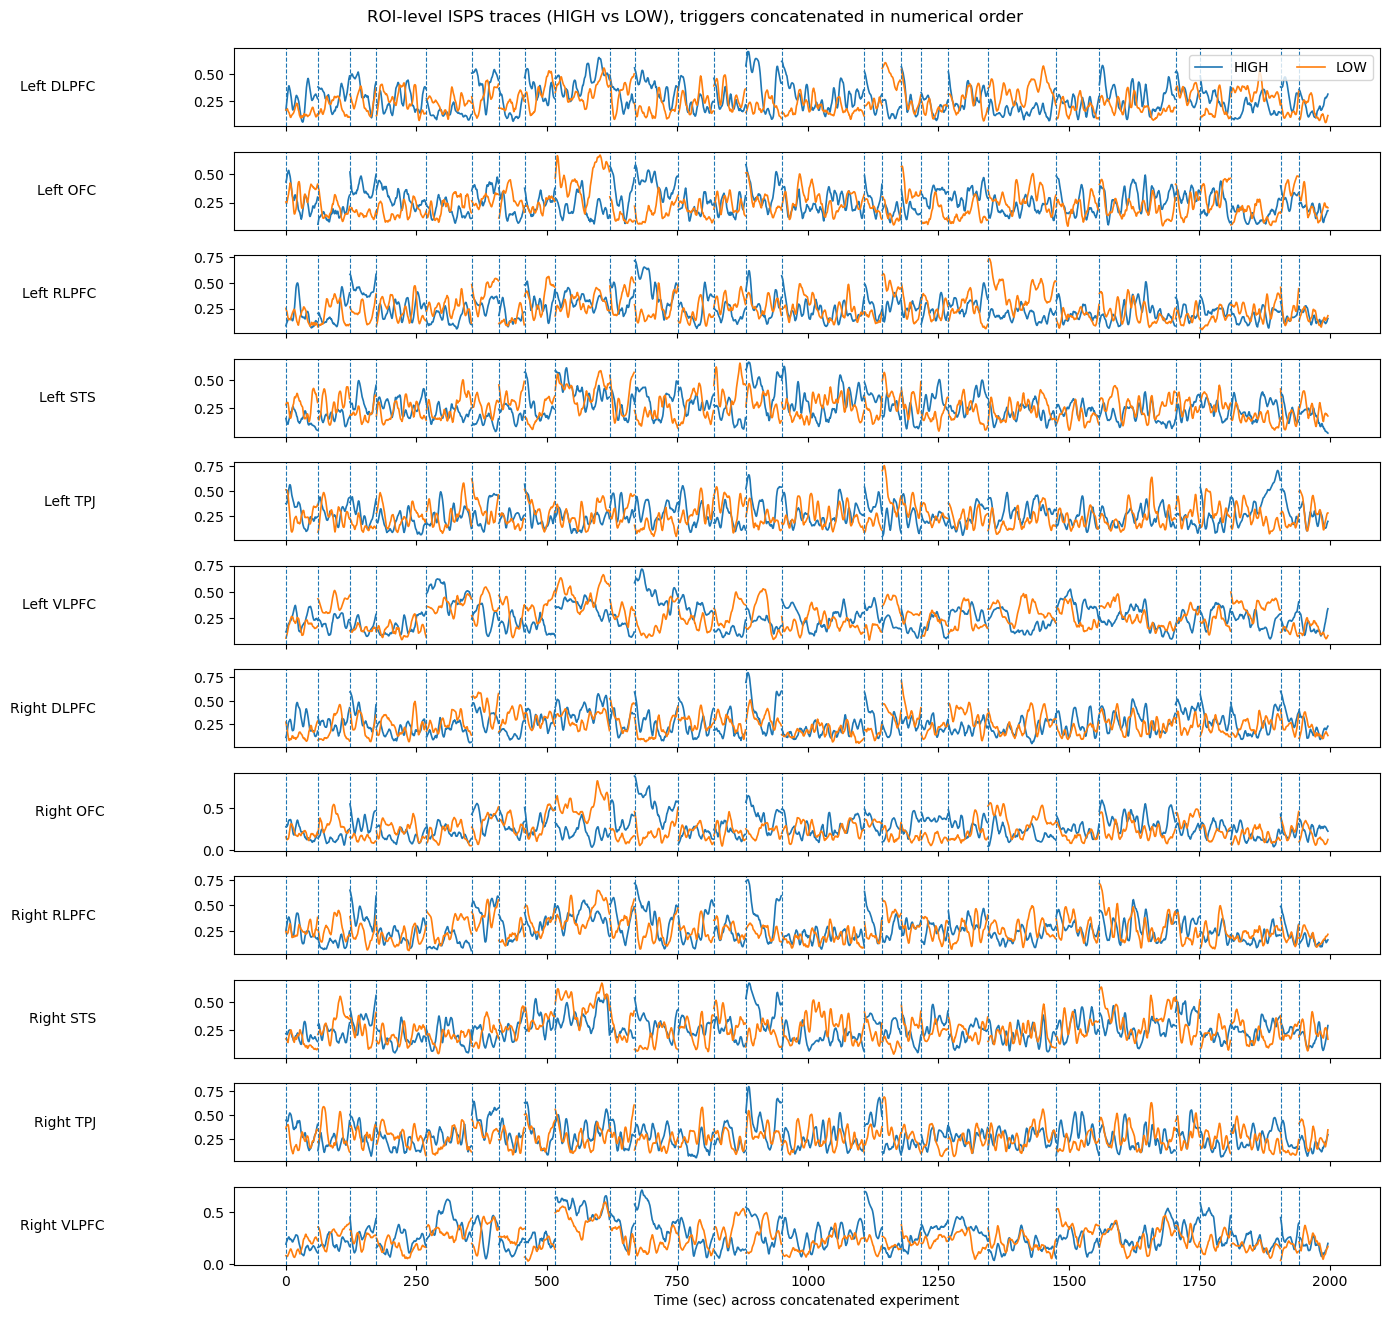

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# USER: point these to your two LONG trace CSVs (HIGH and LOW)
# ============================================================
HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"   # <-- change to your HIGH file path
LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"   # <-- change to your LOW file path

# Which column holds the ISPS trace?
ISPS_COL = "ISPS"   # (based on your file: Trigger, ROI, t_sec, ISPS, ...)

# ============================================================
# Helpers
# ============================================================
def _ensure_types(df):
    df = df.copy()
    df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
    df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
    df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
    df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
    df["Trigger"] = df["Trigger"].astype(int)
    df["ROI"] = df["ROI"].astype(str)
    return df

def _infer_dt(df):
    # median within-trigger step
    dts = []
    for t, sub in df.groupby("Trigger"):
        x = np.sort(sub["t_sec"].unique())
        if x.size >= 3:
            dx = np.diff(x)
            dx = dx[np.isfinite(dx) & (dx > 0)]
            if dx.size:
                dts.append(np.median(dx))
    return float(np.median(dts)) if dts else 0.0

def _build_offsets(dfH, dfL):
    triggers = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
    dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

    dur_by_trig = {}
    for t in triggers:
        mx = np.nanmax([
            dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
            dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
        ])
        if not np.isfinite(mx):
            mx = 0.0
        # include one dt so the last sample "fits" the segment
        dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

    offset_by_trig = {}
    cum = 0.0
    for t in triggers:
        offset_by_trig[t] = cum
        cum += dur_by_trig[t]

    return triggers, dur_by_trig, offset_by_trig, cum

def _concat_series(df, triggers, offset_by_trig, roi=None):
    """
    Returns: x_abs, y, and boundary x positions for dashed lines.
    Inserts NaNs between triggers so matplotlib breaks lines.
    """
    xs, ys = [], []
    for t in triggers:
        sub = df[df["Trigger"] == t]
        if roi is not None:
            sub = sub[sub["ROI"] == roi]
        if sub.empty:
            # still insert a gap at the boundary
            xs += [np.nan]
            ys += [np.nan]
            continue

        sub = sub.sort_values("t_sec")
        x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
        y = sub[ISPS_COL].to_numpy(dtype=float)

        xs.extend(x.tolist())
        ys.extend(y.tolist())

        # gap between triggers
        xs.append(np.nan)
        ys.append(np.nan)

    return np.array(xs, float), np.array(ys, float)

def _mean_over_rois(df):
    # mean ISPS across ROIs at each Trigger×t_sec
    return (
        df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
          .mean()
          .assign(ROI="ALL_ROIS_MEAN")
    )

# ============================================================
# Load
# ============================================================
high = _ensure_types(pd.read_csv(HIGH_TRACES))
low  = _ensure_types(pd.read_csv(LOW_TRACES))

# Triggers ordered + concatenation offsets
triggers, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high, low)

# Use ROI order from the data (should be 12)
rois = sorted(set(high["ROI"].unique()).union(set(low["ROI"].unique())))

print(f"Loaded HIGH rows={len(high)} | LOW rows={len(low)}")
print(f"Found {len(triggers)} triggers: {triggers[:10]}{'...' if len(triggers)>10 else ''}")
print(f"Found {len(rois)} ROIs: {rois}")

# ============================================================
# PLOT 1: Aggregated ISPS across ROIs (mean across ROIs per timepoint)
#   (single plot; triggers concatenated in numerical order)
# ============================================================
high_mean = _mean_over_rois(high)
low_mean  = _mean_over_rois(low)

xH, yH = _concat_series(high_mean, triggers, offset_by_trig, roi="ALL_ROIS_MEAN")
xL, yL = _concat_series(low_mean, triggers, offset_by_trig, roi="ALL_ROIS_MEAN")

plt.figure(figsize=(14, 4.5))
plt.plot(xH, yH, lw=1.8, label="HIGH (mean across ROIs)")
plt.plot(xL, yL, lw=1.8, label="LOW (mean across ROIs)")
for t in triggers:
    plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
plt.axvline(total_dur, linestyle="--", linewidth=1)
plt.title("Aggregated ISPS trace across ROIs (concatenated triggers in numerical order)")
plt.xlabel("Time (sec) across concatenated experiment")
plt.ylabel("ISPS (mean across ROIs)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ============================================================
# PLOT 2: 12 ROI panels stacked (HIGH vs LOW), concatenated triggers
# ============================================================
n = len(rois)
fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, max(10, 1.1*n)), sharex=True)

if n == 1:
    axes = [axes]

for ax, roi in zip(axes, rois):
    xH_roi, yH_roi = _concat_series(high, triggers, offset_by_trig, roi=roi)
    xL_roi, yL_roi = _concat_series(low,  triggers, offset_by_trig, roi=roi)

    ax.plot(xH_roi, yH_roi, lw=1.2, label="HIGH")
    ax.plot(xL_roi, yL_roi, lw=1.2, label="LOW")

    for t in triggers:
        ax.axvline(offset_by_trig[t], linestyle="--", linewidth=0.8)

    ax.set_ylabel(roi, rotation=0, ha="right", va="center", labelpad=70)
    ax.grid(False)

# Put one legend at the top
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("Time (sec) across concatenated experiment")
fig.suptitle("ROI-level ISPS traces (HIGH vs LOW), triggers concatenated in numerical order", y=0.995)
plt.tight_layout()
plt.show()


Loaded HIGH rows=35952 | LOW rows=35952
Found 28 triggers: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]...
Found 12 ROIs: ['Left DLPFC', 'Left OFC', 'Left RLPFC', 'Left STS', 'Left TPJ', 'Left VLPFC', 'Right DLPFC', 'Right OFC', 'Right RLPFC', 'Right STS', 'Right TPJ', 'Right VLPFC']


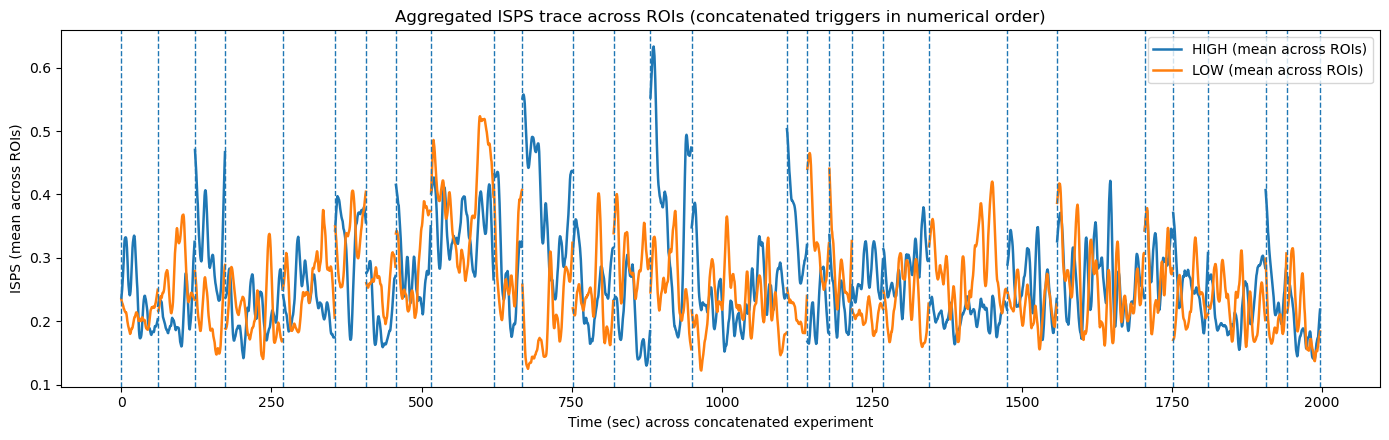

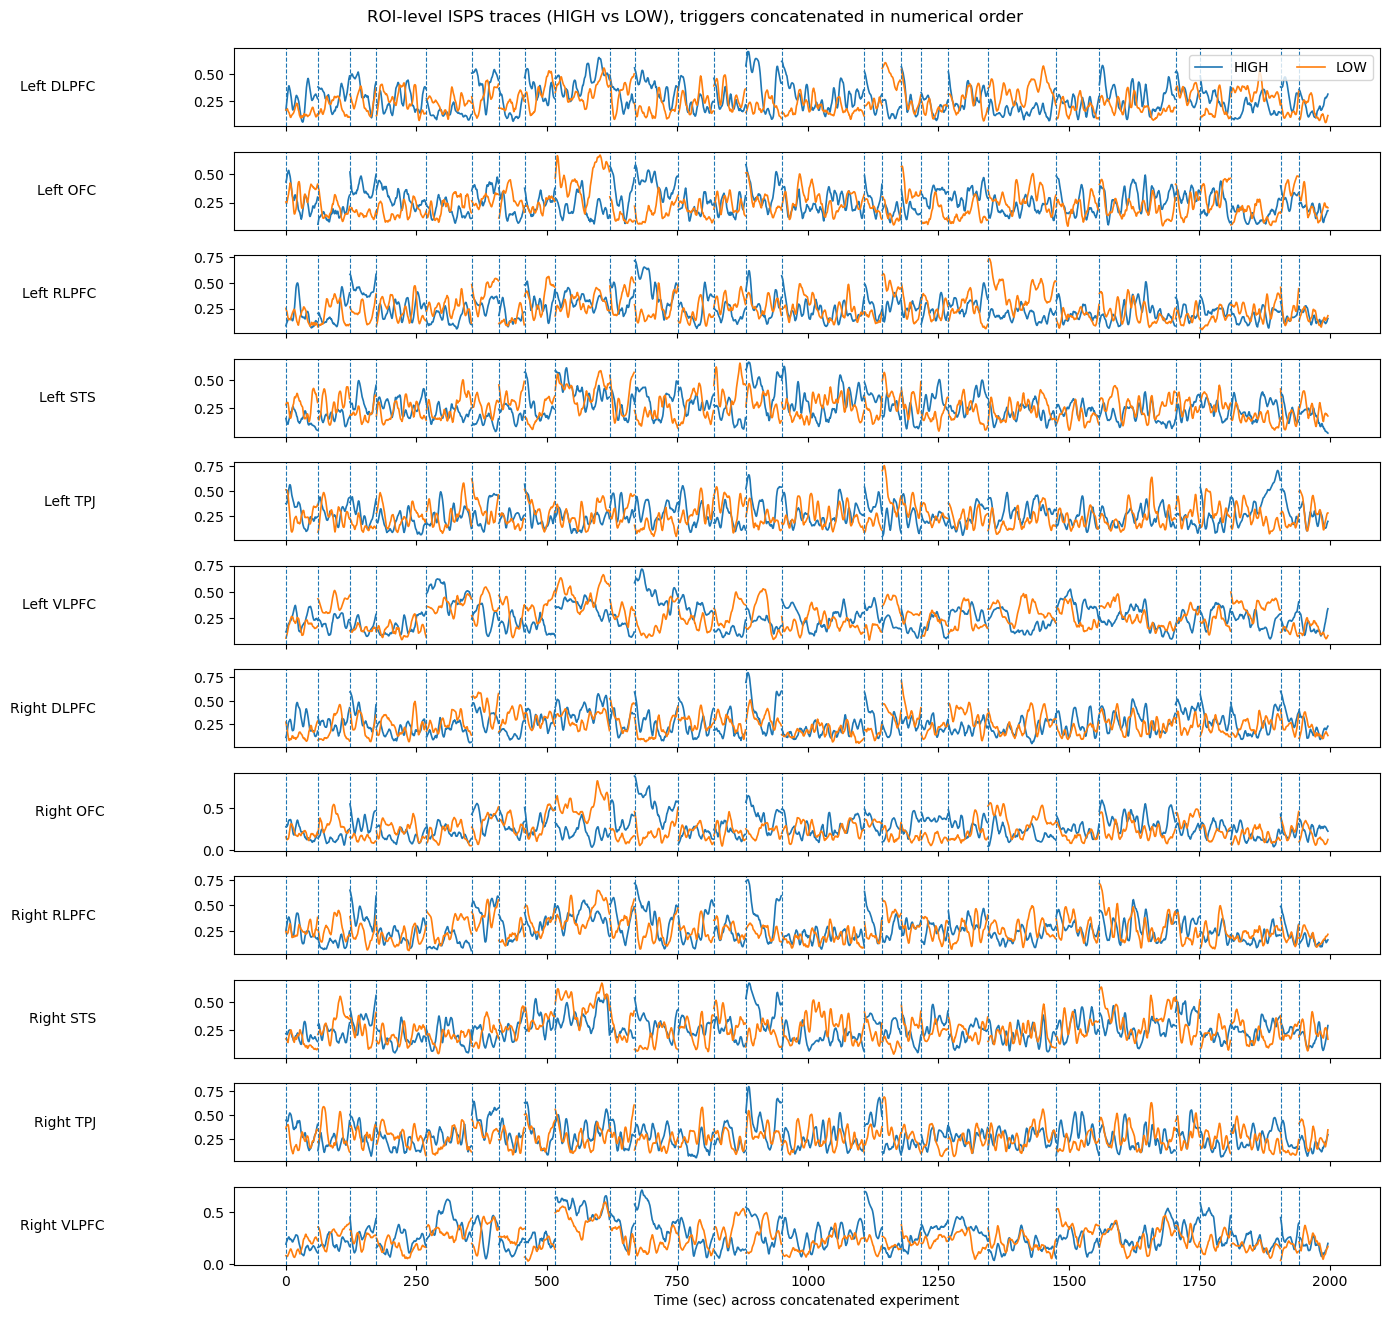


NEW: Peak pairing (tolerance matching) per Trigger×ROI
  tau=2.50s | lag= t_high - t_low (negative => HIGH earlier)
  (mean/median lag only computed when n_matched >= MIN_MATCHED=2)
 Trigger         ROI  n_high_peaks  n_low_peaks  n_matched  prop_matched_(2M/(H+L))  n_unmatched_high  n_unmatched_low  mean_lag_sec_(H-L)  median_lag_sec_(H-L)
       1  Left DLPFC             2            3          0                      0.0                 2                3                 NaN                   NaN
       1    Left OFC             2            4          0                      0.0                 2                4                 NaN                   NaN
       1  Left RLPFC             1            3          0                      0.0                 1                3                 NaN                   NaN
       1    Left STS             2            2          0                      0.0                 2                2                 NaN                   NaN
       1    

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# USER: point these to your two LONG trace CSVs (HIGH and LOW)
# ============================================================
HIGH_TRACES = r"C:\Users\pkell\PC_high_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"   # <-- change to your HIGH file path
LOW_TRACES  = r"C:\Users\pkell\PC_low_ISPS\ISPS_timeseries_traces\ISPS_traces_LONG_all_triggers_rois.csv"   # <-- change to your LOW file path

# Which column holds the ISPS trace?
ISPS_COL = "ISPS"   # (based on your file: Trigger, ROI, t_sec, ISPS, ...)

# ============================================================
# Helpers
# ============================================================
def _ensure_types(df):
    df = df.copy()
    df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
    df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
    df[ISPS_COL] = pd.to_numeric(df[ISPS_COL], errors="coerce")
    df = df.dropna(subset=["Trigger", "ROI", "t_sec", ISPS_COL]).copy()
    df["Trigger"] = df["Trigger"].astype(int)
    df["ROI"] = df["ROI"].astype(str)
    return df

def _infer_dt(df):
    # median within-trigger step
    dts = []
    for t, sub in df.groupby("Trigger"):
        x = np.sort(sub["t_sec"].unique())
        if x.size >= 3:
            dx = np.diff(x)
            dx = dx[np.isfinite(dx) & (dx > 0)]
            if dx.size:
                dts.append(np.median(dx))
    return float(np.median(dts)) if dts else 0.0

def _build_offsets(dfH, dfL):
    triggers = sorted(set(dfH["Trigger"].unique()).union(set(dfL["Trigger"].unique())))
    dt = max(_infer_dt(dfH), _infer_dt(dfL), 0.0)

    dur_by_trig = {}
    for t in triggers:
        mx = np.nanmax([
            dfH.loc[dfH["Trigger"] == t, "t_sec"].max() if (dfH["Trigger"] == t).any() else np.nan,
            dfL.loc[dfL["Trigger"] == t, "t_sec"].max() if (dfL["Trigger"] == t).any() else np.nan,
        ])
        if not np.isfinite(mx):
            mx = 0.0
        # include one dt so the last sample "fits" the segment
        dur_by_trig[t] = float(mx + (dt if dt > 0 else 0.0))

    offset_by_trig = {}
    cum = 0.0
    for t in triggers:
        offset_by_trig[t] = cum
        cum += dur_by_trig[t]

    return triggers, dur_by_trig, offset_by_trig, cum

def _concat_series(df, triggers, offset_by_trig, roi=None):
    """
    Returns: x_abs, y, and boundary x positions for dashed lines.
    Inserts NaNs between triggers so matplotlib breaks lines.
    """
    xs, ys = [], []
    for t in triggers:
        sub = df[df["Trigger"] == t]
        if roi is not None:
            sub = sub[sub["ROI"] == roi]
        if sub.empty:
            # still insert a gap at the boundary
            xs += [np.nan]
            ys += [np.nan]
            continue

        sub = sub.sort_values("t_sec")
        x = sub["t_sec"].to_numpy(dtype=float) + float(offset_by_trig[t])
        y = sub[ISPS_COL].to_numpy(dtype=float)

        xs.extend(x.tolist())
        ys.extend(y.tolist())

        # gap between triggers
        xs.append(np.nan)
        ys.append(np.nan)

    return np.array(xs, float), np.array(ys, float)

def _mean_over_rois(df):
    # mean ISPS across ROIs at each Trigger×t_sec
    return (
        df.groupby(["Trigger", "t_sec"], as_index=False)[ISPS_COL]
          .mean()
          .assign(ROI="ALL_ROIS_MEAN")
    )

# ============================================================
# Load
# ============================================================
high = _ensure_types(pd.read_csv(HIGH_TRACES))
low  = _ensure_types(pd.read_csv(LOW_TRACES))

# Triggers ordered + concatenation offsets
triggers, dur_by_trig, offset_by_trig, total_dur = _build_offsets(high, low)

# Use ROI order from the data (should be 12)
rois = sorted(set(high["ROI"].unique()).union(set(low["ROI"].unique())))

print(f"Loaded HIGH rows={len(high)} | LOW rows={len(low)}")
print(f"Found {len(triggers)} triggers: {triggers[:10]}{'...' if len(triggers)>10 else ''}")
print(f"Found {len(rois)} ROIs: {rois}")

# ============================================================
# PLOT 1: Aggregated ISPS across ROIs (mean across ROIs per timepoint)
#   (single plot; triggers concatenated in numerical order)
# ============================================================
high_mean = _mean_over_rois(high)
low_mean  = _mean_over_rois(low)

xH, yH = _concat_series(high_mean, triggers, offset_by_trig, roi="ALL_ROIS_MEAN")
xL, yL = _concat_series(low_mean, triggers, offset_by_trig, roi="ALL_ROIS_MEAN")

plt.figure(figsize=(14, 4.5))
plt.plot(xH, yH, lw=1.8, label="HIGH (mean across ROIs)")
plt.plot(xL, yL, lw=1.8, label="LOW (mean across ROIs)")
for t in triggers:
    plt.axvline(offset_by_trig[t], linestyle="--", linewidth=1)
plt.axvline(total_dur, linestyle="--", linewidth=1)
plt.title("Aggregated ISPS trace across ROIs (concatenated triggers in numerical order)")
plt.xlabel("Time (sec) across concatenated experiment")
plt.ylabel("ISPS (mean across ROIs)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ============================================================
# PLOT 2: 12 ROI panels stacked (HIGH vs LOW), concatenated triggers
# ============================================================
n = len(rois)
fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, max(10, 1.1*n)), sharex=True)

if n == 1:
    axes = [axes]

for ax, roi in zip(axes, rois):
    xH_roi, yH_roi = _concat_series(high, triggers, offset_by_trig, roi=roi)
    xL_roi, yL_roi = _concat_series(low,  triggers, offset_by_trig, roi=roi)

    ax.plot(xH_roi, yH_roi, lw=1.2, label="HIGH")
    ax.plot(xL_roi, yL_roi, lw=1.2, label="LOW")

    for t in triggers:
        ax.axvline(offset_by_trig[t], linestyle="--", linewidth=0.8)

    ax.set_ylabel(roi, rotation=0, ha="right", va="center", labelpad=70)
    ax.grid(False)

# Put one legend at the top
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("Time (sec) across concatenated experiment")
fig.suptitle("ROI-level ISPS traces (HIGH vs LOW), triggers concatenated in numerical order", y=0.995)
plt.tight_layout()
plt.show()

# ======================================================================
# NEW ANALYSES (ADDED ONLY; existing code above unchanged)
#   1) Event-aligned peak pairing with tolerance window τ
#   2) WITHIN-TRIGGER best-lag cross-correlation on ISPS traces (NEW VARIATION)
# ======================================================================

# --------------------------
# Additional helpers (NEW)
# --------------------------
def gaussian_smooth(y, sigma_bins=2.0):
    # simple Gaussian kernel smoothing without scipy
    y = np.asarray(y, float)
    if y.size < 3:
        return y
    radius = int(np.ceil(4 * sigma_bins))
    x = np.arange(-radius, radius + 1)
    k = np.exp(-(x**2) / (2 * sigma_bins**2))
    k /= k.sum()
    return np.convolve(y, k, mode="same")

def paired_perm_p(diff, n_perm=20000, seed=0, alternative="greater"):
    """
    Sign-flip permutation on paired differences (one-sample).
    alternative:
      "greater": mean(diff) > 0
      "less":    mean(diff) < 0
      "two-sided"
    """
    rng = np.random.default_rng(seed)
    diff = np.asarray(diff, float)
    diff = diff[np.isfinite(diff)]
    if diff.size == 0:
        return np.nan
    obs = diff.mean()
    signs = rng.choice([-1, 1], size=(n_perm, diff.size), replace=True)
    null = (signs * diff).mean(axis=1)

    if alternative == "greater":
        return (np.sum(null >= obs) + 1) / (n_perm + 1)
    elif alternative == "less":
        return (np.sum(null <= obs) + 1) / (n_perm + 1)
    else:
        return (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)

def _rolling_mean(y, win=3):
    y = np.asarray(y, float)
    if win <= 1 or y.size < win:
        return y
    k = np.ones(win, float) / float(win)
    return np.convolve(y, k, mode="same")

def _find_peaks_simple(t, y, dt, min_dist_sec=1.0, q_thresh=0.80, smooth_win=3):
    """
    Minimal peak finder without scipy.
    - local maxima (y[i] > y[i-1 (strict)] and y[i] >= y[i+1])
    - threshold: y[i] >= quantile(y, q_thresh) (within this Trigger×ROI)
    - min distance: greedy keep by height
    Returns peak_times, peak_weights (here: peak heights after smoothing)
    """
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    ok = np.isfinite(t) & np.isfinite(y)
    t, y = t[ok], y[ok]
    if t.size < 5:
        return np.array([], float), np.array([], float)

    ys = _rolling_mean(y, win=smooth_win)

    thr = np.nanquantile(ys, q_thresh) if np.isfinite(np.nanquantile(ys, q_thresh)) else np.nan
    if not np.isfinite(thr):
        return np.array([], float), np.array([], float)

    idx = np.where((ys[1:-1] > ys[:-2]) & (ys[1:-1] >= ys[2:]) & (ys[1:-1] >= thr))[0] + 1
    if idx.size == 0:
        return np.array([], float), np.array([], float)

    min_dist_samp = int(np.ceil(min_dist_sec / dt)) if (dt and dt > 0) else 1
    idx_sorted = idx[np.argsort(ys[idx])[::-1]]
    kept = []
    for i in idx_sorted:
        if all(abs(i - j) >= min_dist_samp for j in kept):
            kept.append(i)

    kept = np.array(sorted(kept), int)
    return t[kept], ys[kept]

def _abs_time(trigger, t_sec):
    return float(offset_by_trig.get(int(trigger), 0.0)) + float(t_sec)

def _greedy_match_with_tau(tH, tL, tau):
    """
    One-to-one matching within |tH - tL| <= tau.
    Greedy global: repeatedly take the smallest absolute difference among remaining candidates.
    Returns list of pairs (iH, iL, lag=tH-tL).
    """
    tH = np.asarray(tH, float)
    tL = np.asarray(tL, float)
    if tH.size == 0 or tL.size == 0:
        return []

    candidates = []
    for i, th in enumerate(tH):
        for j, tl in enumerate(tL):
            d = th - tl
            ad = abs(d)
            if ad <= tau:
                candidates.append((ad, i, j, d))
    if not candidates:
        return []

    candidates.sort(key=lambda x: x[0])
    usedH, usedL = set(), set()
    matches = []
    for ad, i, j, d in candidates:
        if (i not in usedH) and (j not in usedL):
            usedH.add(i)
            usedL.add(j)
            matches.append((i, j, d))
    return matches

def _corr(a, b):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < 3:
        return np.nan
    aa = a[ok] - np.mean(a[ok])
    bb = b[ok] - np.mean(b[ok])
    sa = np.std(aa)
    sb = np.std(bb)
    if sa == 0 or sb == 0:
        return np.nan
    return float(np.mean(aa * bb) / (sa * sb))

def _shift(arr, k):
    """Shift array by k samples. Positive k => arr shifted right (later). Fill with NaN."""
    arr = np.asarray(arr, float)
    out = np.full_like(arr, np.nan, dtype=float)
    if k == 0:
        out[:] = arr
        return out
    if k > 0:
        out[k:] = arr[:-k]
    else:
        out[:k] = arr[-k:]
    return out

def _interp_to_grid(t, y, grid):
    """Linear interpolate y(t) onto grid. Returns NaNs if insufficient points."""
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    ok = np.isfinite(t) & np.isfinite(y)
    t, y = t[ok], y[ok]
    if t.size < 2:
        return np.full_like(grid, np.nan, dtype=float)
    # ensure sorted unique t for interp
    order = np.argsort(t)
    t = t[order]
    y = y[order]
    # de-duplicate timepoints (keep last)
    _, idx = np.unique(t, return_index=True)
    t = t[idx]
    y = y[idx]
    if t.size < 2:
        return np.full_like(grid, np.nan, dtype=float)
    return np.interp(grid, t, y)

# --------------------------
# Parameters (NEW)
# --------------------------
DT_EST = max(_infer_dt(high), _infer_dt(low), 0.0)
if DT_EST <= 0:
    DT_EST = 0.5  # fallback

TAU_SEC = 2.50                 # tolerance window for matching peaks
MIN_MATCHED = 2                # only compute mean/median lag when >= this many matches
MIN_PEAK_DIST_SEC = 1.0        # enforce separation of detected peaks within each Trigger×ROI
PEAK_QTHRESH = 0.80            # peak threshold as within-series quantile
PEAK_SMOOTH_WIN = 3            # small smoothing window before peak detection

MAX_LAG_SEC = 20.0             # cross-correlation lag search range (within-trigger)

# --------------------------
# Build per Trigger×ROI peak tables from TRACE files (NEW)
# --------------------------
def _extract_peaks_from_traces(df, group_name):
    rows = []
    for (trig, roi), sub in df.groupby(["Trigger", "ROI"]):
        sub = sub.sort_values("t_sec")
        t = sub["t_sec"].to_numpy(float)
        y = sub[ISPS_COL].to_numpy(float)

        pk_t, pk_w = _find_peaks_simple(
            t, y, dt=DT_EST,
            min_dist_sec=MIN_PEAK_DIST_SEC,
            q_thresh=PEAK_QTHRESH,
            smooth_win=PEAK_SMOOTH_WIN
        )

        for tt, ww in zip(pk_t, pk_w):
            rows.append({
                "Trigger": int(trig),
                "ROI": str(roi),
                "t_sec": float(tt),
                "weight": float(ww),
                "abs_t_sec": _abs_time(trig, tt),
                "Group": group_name
            })
    return pd.DataFrame(rows)

high_peaks = _extract_peaks_from_traces(high, "HIGH")
low_peaks  = _extract_peaks_from_traces(low,  "LOW")

# If nothing detected, stop gracefully
if high_peaks.empty or low_peaks.empty:
    print("\n[NEW] Peak-based analyses skipped: no peaks detected in one (or both) groups.")
else:
    # ============================================================
    # (1) NEW: Event-aligned pairing with tolerance window τ
    # ============================================================
    print("\n" + "="*69)
    print("NEW: Peak pairing (tolerance matching) per Trigger×ROI")
    print(f"  tau={TAU_SEC:.2f}s | lag= t_high - t_low (negative => HIGH earlier)")
    print(f"  (mean/median lag only computed when n_matched >= MIN_MATCHED={MIN_MATCHED})")
    print("="*69)

    pair_rows = []
    keys = sorted(set(map(tuple, high_peaks[["Trigger","ROI"]].drop_duplicates().values.tolist()))
                  | set(map(tuple, low_peaks[["Trigger","ROI"]].drop_duplicates().values.tolist())))

    for trig, roi in keys:
        tH = np.sort(high_peaks[(high_peaks["Trigger"] == trig) & (high_peaks["ROI"] == roi)]["t_sec"].to_numpy(float))
        tL = np.sort(low_peaks[(low_peaks["Trigger"] == trig) & (low_peaks["ROI"] == roi)]["t_sec"].to_numpy(float))

        matches = _greedy_match_with_tau(tH, tL, TAU_SEC)
        lags = np.array([d for (_,_,d) in matches], float)

        nH = int(tH.size)
        nL = int(tL.size)
        nM = int(lags.size)

        denom = (nH + nL)
        prop_matched = (2.0 * nM / denom) if denom > 0 else np.nan

        n_unH = nH - nM
        n_unL = nL - nM

        mean_lag = float(np.mean(lags)) if nM >= MIN_MATCHED else np.nan
        med_lag  = float(np.median(lags)) if nM >= MIN_MATCHED else np.nan

        pair_rows.append({
            "Trigger": int(trig),
            "ROI": str(roi),
            "n_high_peaks": nH,
            "n_low_peaks": nL,
            "n_matched": nM,
            "prop_matched_(2M/(H+L))": prop_matched,
            "n_unmatched_high": n_unH,
            "n_unmatched_low": n_unL,
            "mean_lag_sec_(H-L)": mean_lag,
            "median_lag_sec_(H-L)": med_lag,
        })

    pairing_tbl = pd.DataFrame(pair_rows).sort_values(["Trigger","ROI"]).reset_index(drop=True)
    print(pairing_tbl.head(10).to_string(index=False))

    print("\n" + "="*69)
    print("NEW: Peak pairing ROI-level summaries (aggregated across triggers)")
    print("  weighted_mean_lag weights by #matched peaks per Trigger×ROI")
    print("="*69)

    roi_sum_rows = []
    for roi in rois:
        sub = pairing_tbl[pairing_tbl["ROI"] == roi].copy()
        if sub.empty:
            continue

        w = sub["n_matched"].to_numpy(float)
        lag_mean = sub["mean_lag_sec_(H-L)"].to_numpy(float)
        ok = np.isfinite(lag_mean) & np.isfinite(w) & (w > 0)

        weighted_mean_lag = np.nan
        if ok.any():
            weighted_mean_lag = float(np.sum(lag_mean[ok] * w[ok]) / np.sum(w[ok]))

        mean_of_means   = float(np.nanmean(lag_mean)) if np.isfinite(lag_mean).any() else np.nan
        medians = sub["median_lag_sec_(H-L)"].to_numpy(float)
        mean_of_medians = float(np.nanmean(medians)) if np.isfinite(medians).any() else np.nan

        denom = (sub["n_high_peaks"].to_numpy(float) + sub["n_low_peaks"].to_numpy(float))
        prop = sub["prop_matched_(2M/(H+L))"].to_numpy(float)
        okp = np.isfinite(prop) & np.isfinite(denom) & (denom > 0)
        weighted_prop = float(np.sum(prop[okp] * denom[okp]) / np.sum(denom[okp])) if okp.any() else np.nan

        roi_sum_rows.append({
            "ROI": roi,
            "n_trigger_rows": int(len(sub)),
            "total_matched_peaks": int(np.nansum(sub["n_matched"].to_numpy(float))),
            "weighted_mean_lag_sec_(H-L)": weighted_mean_lag,
            "mean_of_trigger_mean_lags": mean_of_means,
            "mean_of_trigger_median_lags": mean_of_medians,
            "weighted_prop_matched": weighted_prop,
        })

    pairing_roi = pd.DataFrame(roi_sum_rows).sort_values("ROI").reset_index(drop=True)
    print(pairing_roi.to_string(index=False))

    print("\n" + "="*69)
    print("NEW: Peak pairing GROUP-level lag summaries (across ROIs)")
    print("  lag = t_high - t_low (negative => HIGH earlier)")
    print("="*69)

    roi_lags = pairing_roi["weighted_mean_lag_sec_(H-L)"].to_numpy(float)
    roi_lags = roi_lags[np.isfinite(roi_lags)]
    if roi_lags.size == 0:
        print("No finite ROI lag estimates (try adjusting PEAK_QTHRESH / TAU_SEC / MIN_MATCHED).")
    else:
        print(f"Mean across ROIs (ROI weighted_mean_lag): {np.mean(roi_lags):+.4f} sec")
        print(f"Median across ROIs (ROI weighted_mean_lag): {np.median(roi_lags):+.4f} sec")

        w_roi = pairing_roi["total_matched_peaks"].to_numpy(float)
        ok = np.isfinite(pairing_roi["weighted_mean_lag_sec_(H-L)"].to_numpy(float)) & np.isfinite(w_roi) & (w_roi > 0)
        if ok.any():
            wmean = np.sum(pairing_roi.loc[ok, "weighted_mean_lag_sec_(H-L)"].to_numpy(float) * w_roi[ok]) / np.sum(w_roi[ok])
            print(f"Weighted mean across ROIs (weights = total matched peaks): {wmean:+.4f} sec")

        p_two = paired_perm_p(roi_lags, alternative="two-sided")
        p_dir = paired_perm_p(roi_lags, alternative="less")  # HIGH earlier => lag < 0
        print(f"Permutation p(two-sided) across ROIs: {p_two:.4g}")
        print(f"Permutation p(dir: HIGH earlier) across ROIs: {p_dir:.4g}")

# ======================================================================
# (2) NEW VARIATION: WITHIN-TRIGGER best-lag cross-correlation on ISPS traces
#   - do it per Trigger×ROI (not concatenated)
#   - compute ℓ* per Trigger×ROI as argmax corr(HIGH, shift(LOW, ℓ))
#   - aggregate using |ℓ*| (magnitude), best_corr (alignment strength), or combined scores
# ======================================================================

print("\n" + "="*69)
print("NEW VARIATION: Within-trigger best-lag cross-correlation on ISPS traces")
print(f"  lag range: ±{MAX_LAG_SEC:.1f}s | dt≈{DT_EST:.4f}s (inferred)")
print("  lag ℓ* is argmax corr( yH(t), shift(yL(t), ℓ) ) within each Trigger×ROI")
print("  Note: we summarize |ℓ*| (magnitude) so direction can vary by trigger/cue.")
print("="*69)

# lag grid in samples of DT_EST
max_lag_bins = int(np.round(MAX_LAG_SEC / DT_EST))
lag_bins = np.arange(-max_lag_bins, max_lag_bins + 1, 1, dtype=int)
lag_secs = lag_bins.astype(float) * float(DT_EST)

def _best_lag_for_pair(tH, yH, tL, yL):
    """
    Interpolate both onto a shared within-trigger grid (overlap only),
    then search over lags to maximize correlation.
    Returns: best_lag_sec, best_corr, n_points_used
    """
    tH = np.asarray(tH, float)
    yH = np.asarray(yH, float)
    tL = np.asarray(tL, float)
    yL = np.asarray(yL, float)

    okH = np.isfinite(tH) & np.isfinite(yH)
    okL = np.isfinite(tL) & np.isfinite(yL)
    tH, yH = tH[okH], yH[okH]
    tL, yL = tL[okL], yL[okL]
    if tH.size < 3 or tL.size < 3:
        return np.nan, np.nan, 0

    t0 = max(np.min(tH), np.min(tL))
    t1 = min(np.max(tH), np.max(tL))
    if not np.isfinite(t0) or not np.isfinite(t1) or (t1 - t0) < 3 * DT_EST:
        return np.nan, np.nan, 0

    grid = np.arange(t0, t1 + 1e-9, DT_EST, dtype=float)
    if grid.size < 5:
        return np.nan, np.nan, int(grid.size)

    yH_g = _interp_to_grid(tH, yH, grid)
    yL_g = _interp_to_grid(tL, yL, grid)

    # optional light smoothing to stabilize correlation (no scipy)
    yH_g = _rolling_mean(yH_g, win=3)
    yL_g = _rolling_mean(yL_g, win=3)

    best_corr = -np.inf
    best_lag = np.nan
    for lb, ls in zip(lag_bins, lag_secs):
        c = _corr(yH_g, _shift(yL_g, lb))
        if np.isfinite(c) and c > best_corr:
            best_corr = c
            best_lag = float(ls)

    if not np.isfinite(best_corr):
        return np.nan, np.nan, int(grid.size)
    return best_lag, float(best_corr), int(grid.size)

# Compute per Trigger×ROI best lag
xc_rows = []
all_keys = sorted(
    set(map(tuple, high[["Trigger", "ROI"]].drop_duplicates().values.tolist()))
    .intersection(set(map(tuple, low[["Trigger", "ROI"]].drop_duplicates().values.tolist())))
)

for trig, roi in all_keys:
    subH = high[(high["Trigger"] == trig) & (high["ROI"] == roi)].sort_values("t_sec")
    subL = low[(low["Trigger"] == trig) & (low["ROI"] == roi)].sort_values("t_sec")

    best_lag, best_corr, n_used = _best_lag_for_pair(
        subH["t_sec"].to_numpy(float), subH[ISPS_COL].to_numpy(float),
        subL["t_sec"].to_numpy(float), subL[ISPS_COL].to_numpy(float),
    )

    xc_rows.append({
        "Trigger": int(trig),
        "ROI": str(roi),
        "best_lag_sec": best_lag,
        "best_abs_lag_sec": float(abs(best_lag)) if np.isfinite(best_lag) else np.nan,
        "best_corr": best_corr,
        "n_grid_points": int(n_used),
    })

xc_tbl = pd.DataFrame(xc_rows).sort_values(["Trigger", "ROI"]).reset_index(drop=True)

# Print a small preview
print("\nPer Trigger×ROI best-lag results (preview):")
print(xc_tbl.head(12).to_string(index=False))

# ROI-level summaries: summarize |lag| and best_corr across triggers
print("\n" + "="*69)
print("ROI-level summaries (within-trigger cross-corr)")
print("  Primary: mean(|ℓ*|) across triggers; also corr-weighted mean(|ℓ*|)")
print("="*69)

roi_sum = []
for roi in rois:
    sub = xc_tbl[xc_tbl["ROI"] == roi].copy()
    a = sub["best_abs_lag_sec"].to_numpy(float)
    c = sub["best_corr"].to_numpy(float)

    ok = np.isfinite(a)
    if not ok.any():
        roi_sum.append({
            "ROI": roi,
            "n_triggers": int(len(sub)),
            "mean_abs_lag_sec": np.nan,
            "median_abs_lag_sec": np.nan,
            "corr_weighted_mean_abs_lag_sec": np.nan,
            "mean_best_corr": float(np.nanmean(c)) if np.isfinite(c).any() else np.nan,
        })
        continue

    mean_abs = float(np.nanmean(a))
    med_abs  = float(np.nanmedian(a))

    # weights: positive correlation only (to avoid negative weights)
    w = np.clip(c, 0, None)
    okw = np.isfinite(a) & np.isfinite(w) & (w > 0)
    wmean_abs = float(np.sum(a[okw] * w[okw]) / np.sum(w[okw])) if okw.any() else np.nan

    roi_sum.append({
        "ROI": roi,
        "n_triggers": int(len(sub)),
        "mean_abs_lag_sec": mean_abs,
        "median_abs_lag_sec": med_abs,
        "corr_weighted_mean_abs_lag_sec": wmean_abs,
        "mean_best_corr": float(np.nanmean(c)) if np.isfinite(c).any() else np.nan,
    })

roi_xc = pd.DataFrame(roi_sum).sort_values("ROI").reset_index(drop=True)
print(roi_xc.to_string(index=False))

# Group-level summaries across ROIs (single-direction magnitude)
print("\n" + "="*69)
print("GROUP-level summaries (single-direction magnitude)")
print("  These quantify 'how different' the temporal profiles are, regardless of sign.")
print("="*69)

roi_abs = roi_xc["mean_abs_lag_sec"].to_numpy(float)
roi_abs = roi_abs[np.isfinite(roi_abs)]
if roi_abs.size == 0:
    print("No finite ROI mean_abs_lag estimates.")
else:
    print(f"Mean across ROIs of mean(|ℓ*|): {np.mean(roi_abs):.4f} sec")
    print(f"Median across ROIs of mean(|ℓ*|): {np.median(roi_abs):.4f} sec")

    # corr-weighted across ROIs (weights = mean_best_corr clipped at 0)
    w_roi = np.clip(roi_xc["mean_best_corr"].to_numpy(float), 0, None)
    ok = np.isfinite(roi_xc["mean_abs_lag_sec"].to_numpy(float)) & np.isfinite(w_roi) & (w_roi > 0)
    if ok.any():
        wmean = float(np.sum(roi_xc.loc[ok, "mean_abs_lag_sec"].to_numpy(float) * w_roi[ok]) / np.sum(w_roi[ok]))
        print(f"Corr-weighted mean across ROIs of mean(|ℓ*|): {wmean:.4f} sec")

# Optional: also summarize across ALL Trigger×ROI rows (more granular)
print("\n" + "="*69)
print("All Trigger×ROI summaries (more granular)")
print("="*69)

abs_all = xc_tbl["best_abs_lag_sec"].to_numpy(float)
corr_all = xc_tbl["best_corr"].to_numpy(float)
ok = np.isfinite(abs_all)
if ok.any():
    print(f"Mean |ℓ*| across all Trigger×ROI: {np.nanmean(abs_all):.4f} sec")
    print(f"Median |ℓ*| across all Trigger×ROI: {np.nanmedian(abs_all):.4f} sec")

    w = np.clip(corr_all, 0, None)
    okw = np.isfinite(abs_all) & np.isfinite(w) & (w > 0)
    if okw.any():
        wmean = float(np.sum(abs_all[okw] * w[okw]) / np.sum(w[okw]))
        print(f"Corr-weighted mean |ℓ*| across all Trigger×ROI: {wmean:.4f} sec")
else:
    print("No finite Trigger×ROI lag estimates.")

# Optional: save outputs (comment/uncomment as you like)
# xc_tbl.to_csv("within_trigger_crosscorr_bestlag_by_trigger_roi.csv", index=False)
# roi_xc.to_csv("within_trigger_crosscorr_bestlag_roi_summary.csv", index=False)



DROP-IN: Peak MatchRate as PRIMARY outcome (event correspondence)
  MatchRate = 2M/(H+L) computed within τ=20.00s, 1:1 matching
Group-level MatchRate across Trigger×ROI:
  mean = 0.6324  |  95% bootstrap CI [0.6063, 0.6576]
  median = 0.6667

ROI ranking by mean MatchRate (higher = more shared events):
        ROI  mean_MatchRate
  Right TPJ        0.690306
Right DLPFC        0.679770
   Left STS        0.674552
   Left OFC        0.658744
  Right STS        0.637539
 Left VLPFC        0.622374
Right RLPFC        0.619928
   Left TPJ        0.619841
 Left DLPFC        0.606463
  Right OFC        0.595918
Right VLPFC        0.591561
 Left RLPFC        0.591327


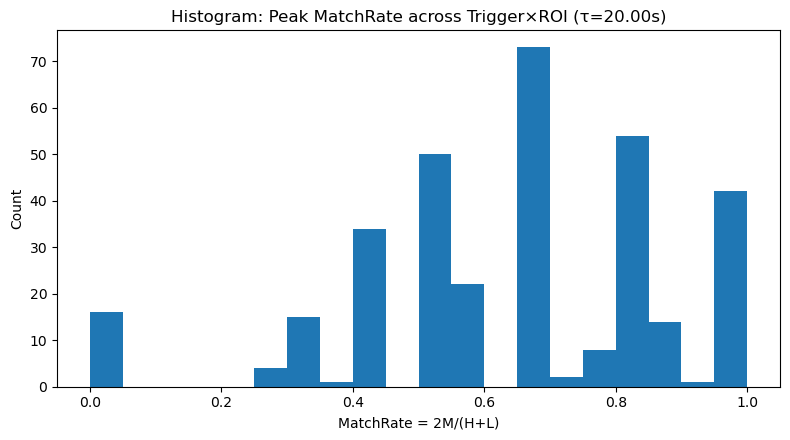

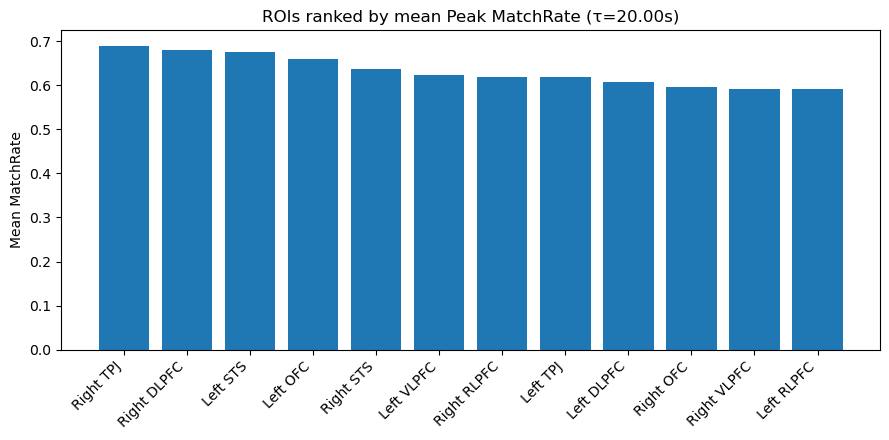


DROP-IN: Weight-based event sharing (CoverageHIGH/LOW, UnsharedWeight)
  CoverageHIGH = matched_weight_high / total_weight_high
  CoverageLOW  = matched_weight_low  / total_weight_low
  UnsharedWeight = 1 - (CoverageHIGH + CoverageLOW)/2
Group-level UnsharedWeight across Trigger×ROI:
  mean = 0.3315  |  95% bootstrap CI [0.3058, 0.3575]
  median = 0.2905

ROIs ranked by UnsharedWeight (higher = more different events by peak mass):
        ROI  mean_UnsharedWeight  mean_CoverageHIGH  mean_CoverageLOW  mean_MatchRate
Right VLPFC             0.380139           0.627835          0.611887        0.591561
  Right OFC             0.371651           0.610987          0.645712        0.595918
 Left RLPFC             0.370854           0.639559          0.618732        0.591327
 Left DLPFC             0.359015           0.660551          0.621419        0.606463
   Left TPJ             0.353301           0.614673          0.678725        0.619841
 Left VLPFC             0.337437           0.700

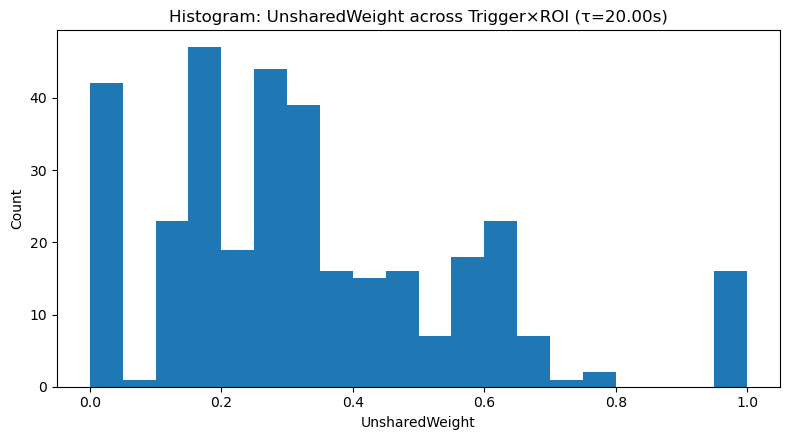


DROP-IN: Shift-and-match using within-trigger best-lag ℓ*
  Goal: distinguish 'same events but shifted' vs 'different events'
  Procedure: shift LOW peak times by ℓ* (from xc_tbl), then recompute MatchRate/UnsharedWeight with τ=20.00s
ΔMatchRate (shifted - original) across Trigger×ROI:
  mean = -0.0253  |  95% bootstrap CI [-0.0479, -0.0025]
ΔUnsharedWeight (shifted - original) across Trigger×ROI:
  mean = +0.0227  |  95% bootstrap CI [-0.0007, +0.0460]


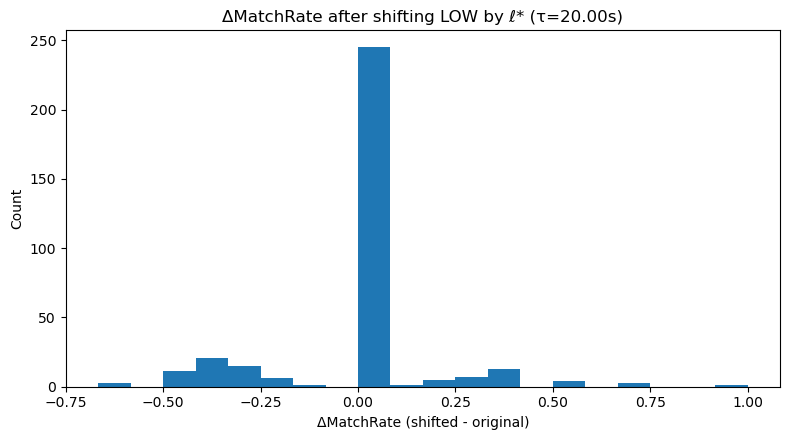

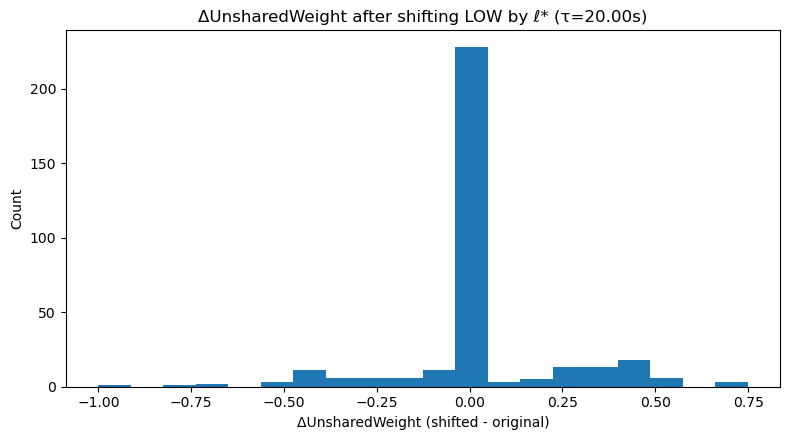


DROP-IN: Peak-time divergence (Wasserstein-1 / Earth Mover’s Distance)
  0 sec = identical timing distribution; larger = more different
Group-level Wasserstein-1 distance across Trigger×ROI:
  mean = 18.4628 sec  |  95% bootstrap CI [17.3994, 19.5682]
  median = 16.9005 sec

ROIs ranked by mean Wasserstein-1 (higher = more different peak timing):
        ROI  mean_W1_sec
Right VLPFC    20.259642
 Left RLPFC    19.742853
   Left TPJ    19.501490
 Left DLPFC    19.368023
  Right OFC    19.245711
  Right STS    19.220228
 Left VLPFC    18.847283
   Left OFC    18.363314
   Left STS    17.882138
Right RLPFC    17.721709
  Right TPJ    15.847055
Right DLPFC    15.554466


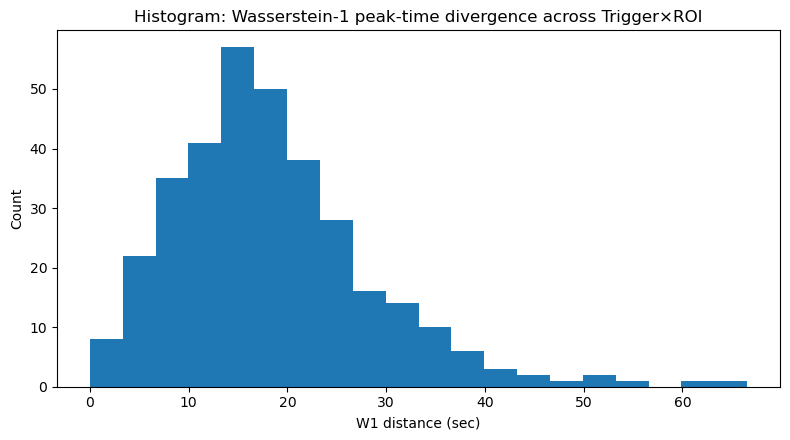


DROP-IN: Killer plots (peak rasters) for most-different Trigger×ROI examples
  Auto-selects examples with LOW MatchRate / HIGH UnsharedWeight


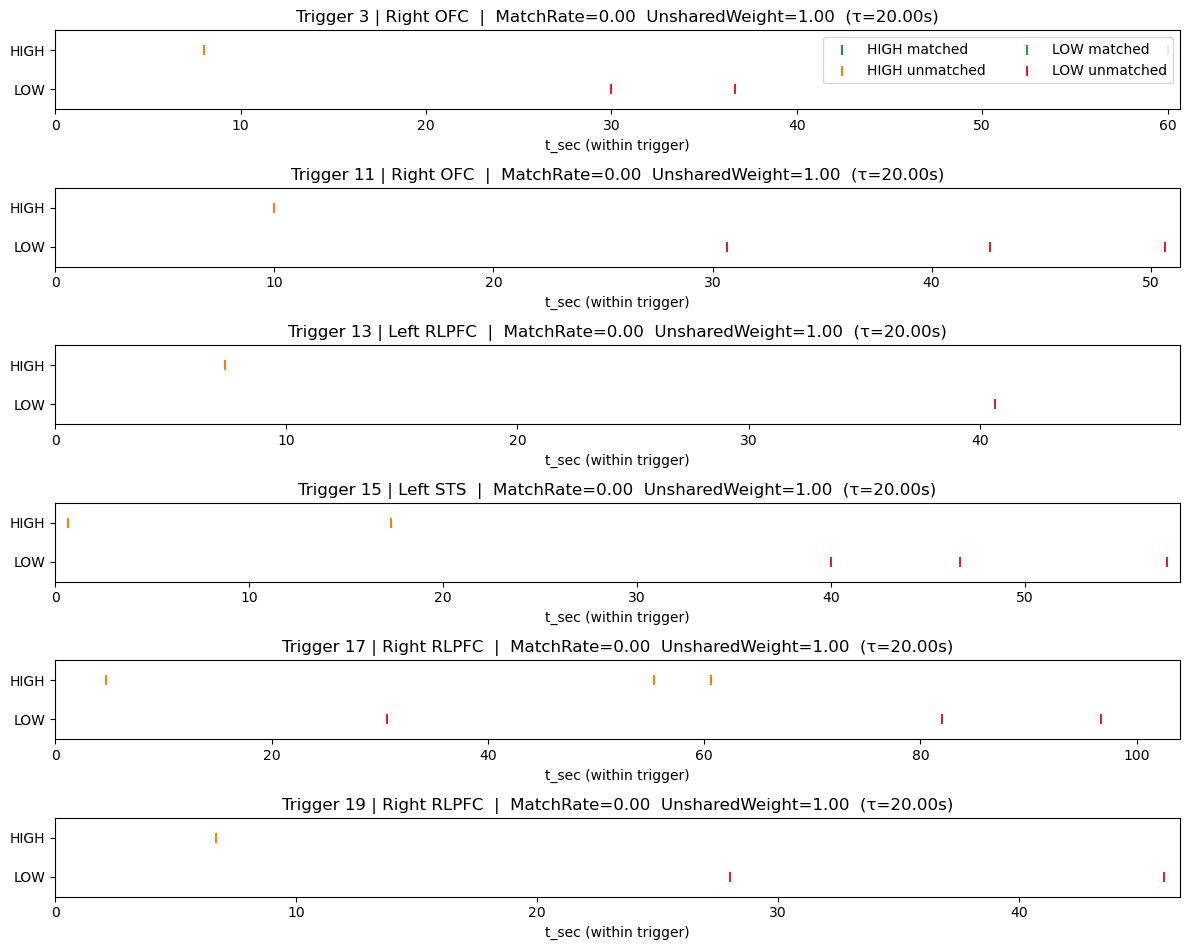

In [13]:
# ======================================================================
# DROP-IN ADDITIONS (paste this at the END of your script, after xc_tbl/roi_xc are created)
# Implements:
#  1) Peak MatchRate as primary outcome (+ bootstrap CI + plots)  <-- recomputed from peaks so τ applies everywhere
#  2) Unshared peak “mass” using peak weights (CoverageHIGH/LOW, UnsharedWeight)
#  4) Shift-and-match using within-trigger best-lag (same events but time-shifted?)
#  5) Peak-time divergence via Wasserstein-1 (Earth Mover’s Distance), weighted
#  6) “Killer plots”: peak rasters with matched vs unmatched peaks annotated
#
# IMPORTANT FIX:
#   This version does NOT use pairing_tbl's cached match rates (which may reflect an older τ).
#   Instead it recomputes MatchRate directly from high_peaks/low_peaks using TAU_SEC_TOGGLE,
#   so changing τ here applies everywhere in this drop-in.
# ======================================================================

# --------------------------
# USER TOGGLE: set τ here (e.g., 2.5 or 5.0) and rerun
# --------------------------
TAU_SEC_TOGGLE = 20.00  # <--- change to 2.50 or 5.00 (or any float) and rerun

# --------------------------
# Safety: check required tables exist
# --------------------------
_required = ["high_peaks", "low_peaks", "xc_tbl", "rois", "triggers"]
_missing = [k for k in _required if k not in globals()]
if _missing:
    print("\n[DROP-IN] Skipped: missing required objects:", _missing)
else:
    # --------------------------
    # Helpers (bootstrap + Wasserstein + matching with weights)
    # --------------------------
    def _bootstrap_ci_mean(x, n_boot=20000, ci=95, seed=0):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if x.size == 0:
            return (np.nan, np.nan, np.nan)
        rng = np.random.default_rng(seed)
        idx = rng.integers(0, x.size, size=(n_boot, x.size))
        boot_means = np.nanmean(x[idx], axis=1)
        alpha = (100 - ci) / 2.0
        lo, hi = np.nanpercentile(boot_means, [alpha, 100 - alpha])
        return (float(np.nanmean(x)), float(lo), float(hi))

    def _wasserstein_1d(x, wx, y, wy):
        """
        Weighted 1D Wasserstein-1 distance (Earth Mover's Distance) in seconds.
        x,y: locations; wx,wy: nonnegative weights
        Returns NaN if insufficient mass.
        """
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        wx = np.asarray(wx, float)
        wy = np.asarray(wy, float)

        okx = np.isfinite(x) & np.isfinite(wx) & (wx >= 0)
        oky = np.isfinite(y) & np.isfinite(wy) & (wy >= 0)
        x, wx = x[okx], wx[okx]
        y, wy = y[oky], wy[oky]

        if x.size == 0 or y.size == 0:
            return np.nan

        sx = wx.sum()
        sy = wy.sum()
        if sx <= 0 or sy <= 0:
            return np.nan

        # normalize weights to sum to 1
        wx = wx / sx
        wy = wy / sy

        # sort
        ix = np.argsort(x)
        iy = np.argsort(y)
        x, wx = x[ix], wx[ix]
        y, wy = y[iy], wy[iy]

        # merge support
        z = np.unique(np.concatenate([x, y]))
        if z.size < 2:
            return 0.0

        # CDFs at each support point
        cx = np.zeros_like(z, float)
        cy = np.zeros_like(z, float)

        # fill cumulative via two pointers
        px = 0
        py = 0
        cumx = 0.0
        cumy = 0.0
        for i, zz in enumerate(z):
            while px < x.size and x[px] <= zz:
                cumx += wx[px]
                px += 1
            while py < y.size and y[py] <= zz:
                cumy += wy[py]
                py += 1
            cx[i] = cumx
            cy[i] = cumy

        # integrate |CDFx - CDFy| over intervals
        dz = np.diff(z)
        mid_diff = np.abs(cx[:-1] - cy[:-1])
        return float(np.sum(mid_diff * dz))

    def _get_peak_times_weights(peaks_df, trig, roi):
        sub = peaks_df[(peaks_df["Trigger"] == trig) & (peaks_df["ROI"] == roi)]
        if sub.empty:
            return np.array([], float), np.array([], float)
        sub = sub.sort_values("t_sec")
        t = sub["t_sec"].to_numpy(float)
        w = sub["weight"].to_numpy(float) if "weight" in sub.columns else np.ones_like(t, float)
        w = np.where(np.isfinite(w) & (w > 0), w, 0.0)
        return t, w

    def _matchrate_and_unshared(tH, wH, tL, wL, tau):
        """
        One-to-one matching within tau using existing greedy matcher on times.
        Returns:
          match_rate, covH, covL, unshared_weight, nM, matched_wH, matched_wL
        """
        if len(tH) == 0 and len(tL) == 0:
            return (np.nan, np.nan, np.nan, np.nan, 0, 0.0, 0.0)

        matches = _greedy_match_with_tau(tH, tL, tau)
        nH = int(len(tH))
        nL = int(len(tL))
        nM = int(len(matches))

        # Dice/F1-style match rate
        denom = nH + nL
        match_rate = (2.0 * nM / denom) if denom > 0 else np.nan

        # weight coverage
        totH = float(np.sum(wH)) if nH > 0 else 0.0
        totL = float(np.sum(wL)) if nL > 0 else 0.0

        if nM > 0:
            idxH = [i for (i, j, d) in matches]
            idxL = [j for (i, j, d) in matches]
            matched_wH = float(np.sum(wH[idxH])) if nH > 0 else 0.0
            matched_wL = float(np.sum(wL[idxL])) if nL > 0 else 0.0
        else:
            matched_wH, matched_wL = 0.0, 0.0

        covH = (matched_wH / totH) if totH > 0 else np.nan
        covL = (matched_wL / totL) if totL > 0 else np.nan

        # fraction of salient peak “energy” not shared (average of uncovered mass)
        if np.isfinite(covH) and np.isfinite(covL):
            unshared = 1.0 - 0.5 * (covH + covL)
        else:
            unshared = np.nan

        return (float(match_rate),
                float(covH) if np.isfinite(covH) else np.nan,
                float(covL) if np.isfinite(covL) else np.nan,
                float(unshared) if np.isfinite(unshared) else np.nan,
                nM, matched_wH, matched_wL)

    # --------------------------
    # Build Trigger×ROI key list (use union of keys in either peaks table)
    # --------------------------
    keys_H = set(map(tuple, high_peaks[["Trigger", "ROI"]].drop_duplicates().values.tolist())) if not high_peaks.empty else set()
    keys_L = set(map(tuple, low_peaks[["Trigger", "ROI"]].drop_duplicates().values.tolist())) if not low_peaks.empty else set()
    key_pairs = sorted(keys_H | keys_L)

    if len(key_pairs) == 0:
        print("\n[DROP-IN] No Trigger×ROI keys found in peaks tables (high_peaks/low_peaks).")
    else:
        # --------------------------
        # Recompute per Trigger×ROI metrics at the current τ toggle
        #   This table replaces any cached τ-dependent values from earlier parts of your script.
        # --------------------------
        rows = []
        for trig, roi in key_pairs:
            trig = int(trig)
            roi = str(roi)
            tH, wH = _get_peak_times_weights(high_peaks, trig, roi)
            tL, wL = _get_peak_times_weights(low_peaks,  trig, roi)

            mr, covH, covL, unshared, nM, mwH, mwL = _matchrate_and_unshared(tH, wH, tL, wL, TAU_SEC_TOGGLE)

            rows.append({
                "Trigger": trig,
                "ROI": roi,
                "MatchRate": mr,                 # 2M/(H+L)
                "CoverageHIGH": covH,
                "CoverageLOW": covL,
                "UnsharedWeight": unshared,
                "n_high_peaks": int(len(tH)),
                "n_low_peaks": int(len(tL)),
                "n_matched": int(nM),
                "matched_weight_high": float(mwH),
                "matched_weight_low": float(mwL),
                "total_weight_high": float(np.sum(wH)) if wH.size else 0.0,
                "total_weight_low": float(np.sum(wL)) if wL.size else 0.0,
            })

        tau_tbl = pd.DataFrame(rows).sort_values(["Trigger", "ROI"]).reset_index(drop=True)

        # --------------------------
        # (1) Peak MatchRate as primary outcome (+ bootstrap CI + ROI ranking + histogram)
        # --------------------------
        print("\n" + "="*69)
        print("DROP-IN: Peak MatchRate as PRIMARY outcome (event correspondence)")
        print(f"  MatchRate = 2M/(H+L) computed within τ={TAU_SEC_TOGGLE:.2f}s, 1:1 matching")
        print("="*69)

        mr_all = tau_tbl["MatchRate"].to_numpy(float)
        mr_all = mr_all[np.isfinite(mr_all)]

        mean_mr, lo_mr, hi_mr = _bootstrap_ci_mean(mr_all, n_boot=20000, ci=95, seed=1)
        med_mr = float(np.nanmedian(mr_all)) if mr_all.size else np.nan

        print("Group-level MatchRate across Trigger×ROI:")
        print(f"  mean = {mean_mr:.4f}  |  95% bootstrap CI [{lo_mr:.4f}, {hi_mr:.4f}]")
        print(f"  median = {med_mr:.4f}")

        roi_mr = (
            tau_tbl.groupby("ROI", as_index=False)["MatchRate"]
                   .mean()
                   .rename(columns={"MatchRate": "mean_MatchRate"})
                   .sort_values("mean_MatchRate", ascending=False)
                   .reset_index(drop=True)
        )
        print("\nROI ranking by mean MatchRate (higher = more shared events):")
        print(roi_mr.to_string(index=False))

        plt.figure(figsize=(8, 4.5))
        plt.hist(mr_all, bins=20)
        plt.title(f"Histogram: Peak MatchRate across Trigger×ROI (τ={TAU_SEC_TOGGLE:.2f}s)")
        plt.xlabel("MatchRate = 2M/(H+L)")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 4.5))
        plt.bar(roi_mr["ROI"].to_numpy(str), roi_mr["mean_MatchRate"].to_numpy(float))
        plt.xticks(rotation=45, ha="right")
        plt.title(f"ROIs ranked by mean Peak MatchRate (τ={TAU_SEC_TOGGLE:.2f}s)")
        plt.ylabel("Mean MatchRate")
        plt.tight_layout()
        plt.show()

        # --------------------------
        # (2) Unshared peak “mass” (weight-based) summaries + ROI ranking + histogram
        # --------------------------
        print("\n" + "="*69)
        print("DROP-IN: Weight-based event sharing (CoverageHIGH/LOW, UnsharedWeight)")
        print("  CoverageHIGH = matched_weight_high / total_weight_high")
        print("  CoverageLOW  = matched_weight_low  / total_weight_low")
        print("  UnsharedWeight = 1 - (CoverageHIGH + CoverageLOW)/2")
        print("="*69)

        unshared_all = tau_tbl["UnsharedWeight"].to_numpy(float)
        unshared_all = unshared_all[np.isfinite(unshared_all)]
        mean_uw, lo_uw, hi_uw = _bootstrap_ci_mean(unshared_all, n_boot=20000, ci=95, seed=2)
        med_uw = float(np.nanmedian(unshared_all)) if unshared_all.size else np.nan

        print("Group-level UnsharedWeight across Trigger×ROI:")
        print(f"  mean = {mean_uw:.4f}  |  95% bootstrap CI [{lo_uw:.4f}, {hi_uw:.4f}]")
        print(f"  median = {med_uw:.4f}")

        roi_uw = (
            tau_tbl.groupby("ROI", as_index=False)
                   .agg(mean_UnsharedWeight=("UnsharedWeight", "mean"),
                        mean_CoverageHIGH=("CoverageHIGH", "mean"),
                        mean_CoverageLOW=("CoverageLOW", "mean"),
                        mean_MatchRate=("MatchRate", "mean"))
                   .sort_values("mean_UnsharedWeight", ascending=False)
                   .reset_index(drop=True)
        )
        print("\nROIs ranked by UnsharedWeight (higher = more different events by peak mass):")
        print(roi_uw.to_string(index=False))

        plt.figure(figsize=(8, 4.5))
        plt.hist(unshared_all, bins=20)
        plt.title(f"Histogram: UnsharedWeight across Trigger×ROI (τ={TAU_SEC_TOGGLE:.2f}s)")
        plt.xlabel("UnsharedWeight")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

        # --------------------------
        # (4) Shift-and-match: recompute MatchRate / UnsharedWeight after shifting LOW by best-lag ℓ*
        # --------------------------
        print("\n" + "="*69)
        print("DROP-IN: Shift-and-match using within-trigger best-lag ℓ*")
        print("  Goal: distinguish 'same events but shifted' vs 'different events'")
        print(f"  Procedure: shift LOW peak times by ℓ* (from xc_tbl), then recompute MatchRate/UnsharedWeight with τ={TAU_SEC_TOGGLE:.2f}s")
        print("="*69)

        lag_lookup = {(int(r.Trigger), str(r.ROI)): float(r.best_lag_sec) if np.isfinite(r.best_lag_sec) else np.nan
                      for r in xc_tbl.itertuples(index=False)}

        shift_rows = []
        for r in tau_tbl.itertuples(index=False):
            trig = int(r.Trigger)
            roi = str(r.ROI)

            mr0 = float(r.MatchRate) if np.isfinite(r.MatchRate) else np.nan
            uw0 = float(r.UnsharedWeight) if np.isfinite(r.UnsharedWeight) else np.nan

            lag = lag_lookup.get((trig, roi), np.nan)

            tH, wH = _get_peak_times_weights(high_peaks, trig, roi)
            tL, wL = _get_peak_times_weights(low_peaks,  trig, roi)

            if not np.isfinite(lag):
                mr1, uw1 = np.nan, np.nan
            else:
                tL_shift = tL + float(lag)
                mr1, covH1, covL1, uw1, nM1, mwH1, mwL1 = _matchrate_and_unshared(
                    tH, wH, tL_shift, wL, TAU_SEC_TOGGLE
                )

            shift_rows.append({
                "Trigger": trig,
                "ROI": roi,
                "best_lag_sec": lag,
                "MatchRate_orig": mr0,
                "UnsharedWeight_orig": uw0,
                "MatchRate_shifted": mr1,
                "UnsharedWeight_shifted": uw1,
                "Delta_MatchRate": (mr1 - mr0) if (np.isfinite(mr0) and np.isfinite(mr1)) else np.nan,
                "Delta_UnsharedWeight": (uw1 - uw0) if (np.isfinite(uw0) and np.isfinite(uw1)) else np.nan,
            })

        shift_tbl = pd.DataFrame(shift_rows).sort_values(["Trigger", "ROI"]).reset_index(drop=True)

        dm = shift_tbl["Delta_MatchRate"].to_numpy(float)
        dm = dm[np.isfinite(dm)]
        duw = shift_tbl["Delta_UnsharedWeight"].to_numpy(float)
        duw = duw[np.isfinite(duw)]

        if dm.size:
            mean_dm, lo_dm, hi_dm = _bootstrap_ci_mean(dm, n_boot=20000, ci=95, seed=3)
            print("ΔMatchRate (shifted - original) across Trigger×ROI:")
            print(f"  mean = {mean_dm:+.4f}  |  95% bootstrap CI [{lo_dm:+.4f}, {hi_dm:+.4f}]")
        else:
            print("ΔMatchRate: no finite values (likely missing lags or missing peaks).")

        if duw.size:
            mean_duw, lo_duw, hi_duw = _bootstrap_ci_mean(duw, n_boot=20000, ci=95, seed=4)
            print("ΔUnsharedWeight (shifted - original) across Trigger×ROI:")
            print(f"  mean = {mean_duw:+.4f}  |  95% bootstrap CI [{lo_duw:+.4f}, {hi_duw:+.4f}]")
        else:
            print("ΔUnsharedWeight: no finite values.")

        if dm.size:
            plt.figure(figsize=(8, 4.5))
            plt.hist(dm, bins=20)
            plt.title(f"ΔMatchRate after shifting LOW by ℓ* (τ={TAU_SEC_TOGGLE:.2f}s)")
            plt.xlabel("ΔMatchRate (shifted - original)")
            plt.ylabel("Count")
            plt.tight_layout()
            plt.show()

        if duw.size:
            plt.figure(figsize=(8, 4.5))
            plt.hist(duw, bins=20)
            plt.title(f"ΔUnsharedWeight after shifting LOW by ℓ* (τ={TAU_SEC_TOGGLE:.2f}s)")
            plt.xlabel("ΔUnsharedWeight (shifted - original)")
            plt.ylabel("Count")
            plt.tight_layout()
            plt.show()

        # --------------------------
        # (5) Peak-time divergence via Wasserstein-1 (weighted)
        # --------------------------
        print("\n" + "="*69)
        print("DROP-IN: Peak-time divergence (Wasserstein-1 / Earth Mover’s Distance)")
        print("  0 sec = identical timing distribution; larger = more different")
        print("="*69)

        emd_rows = []
        for trig, roi in key_pairs:
            trig = int(trig)
            roi = str(roi)

            tH, wH = _get_peak_times_weights(high_peaks, trig, roi)
            tL, wL = _get_peak_times_weights(low_peaks,  trig, roi)

            d0 = _wasserstein_1d(tH, wH, tL, wL)

            lag = lag_lookup.get((trig, roi), np.nan)
            if np.isfinite(lag):
                d1 = _wasserstein_1d(tH, wH, tL + float(lag), wL)
            else:
                d1 = np.nan

            emd_rows.append({
                "Trigger": trig,
                "ROI": roi,
                "W1_sec": d0,
                "W1_sec_after_shift": d1,
                "Delta_W1_sec": (d1 - d0) if (np.isfinite(d0) and np.isfinite(d1)) else np.nan
            })

        emd_tbl = pd.DataFrame(emd_rows).sort_values(["Trigger", "ROI"]).reset_index(drop=True)

        w1 = emd_tbl["W1_sec"].to_numpy(float)
        w1 = w1[np.isfinite(w1)]
        mean_w1, lo_w1, hi_w1 = _bootstrap_ci_mean(w1, n_boot=20000, ci=95, seed=5)
        med_w1 = float(np.nanmedian(w1)) if w1.size else np.nan

        print("Group-level Wasserstein-1 distance across Trigger×ROI:")
        print(f"  mean = {mean_w1:.4f} sec  |  95% bootstrap CI [{lo_w1:.4f}, {hi_w1:.4f}]")
        print(f"  median = {med_w1:.4f} sec")

        roi_w1 = (
            emd_tbl.groupby("ROI", as_index=False)
                   .agg(mean_W1_sec=("W1_sec", "mean"))
                   .sort_values("mean_W1_sec", ascending=False)
                   .reset_index(drop=True)
        )
        print("\nROIs ranked by mean Wasserstein-1 (higher = more different peak timing):")
        print(roi_w1.to_string(index=False))

        plt.figure(figsize=(8, 4.5))
        plt.hist(w1, bins=20)
        plt.title("Histogram: Wasserstein-1 peak-time divergence across Trigger×ROI")
        plt.xlabel("W1 distance (sec)")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

        # --------------------------
        # (6) “Killer plots”: Peak rasters (HIGH vs LOW) with matched vs unmatched + annotations
        # --------------------------
        print("\n" + "="*69)
        print("DROP-IN: Killer plots (peak rasters) for most-different Trigger×ROI examples")
        print("  Auto-selects examples with LOW MatchRate / HIGH UnsharedWeight")
        print("="*69)

        ex_tbl = tau_tbl.copy()
        ex_tbl = ex_tbl[np.isfinite(ex_tbl["MatchRate"])].copy()
        if ex_tbl.empty:
            print("No finite MatchRate rows to plot examples.")
        else:
            ex_tbl = ex_tbl.sort_values(["MatchRate", "UnsharedWeight"], ascending=[True, False])
            examples = ex_tbl.head(6)[["Trigger", "ROI"]].values.tolist()

            n_pan = len(examples)
            fig, axes = plt.subplots(nrows=n_pan, ncols=1, figsize=(12, max(6, 1.6 * n_pan)), sharex=False)
            if n_pan == 1:
                axes = [axes]

            for ax, (trig, roi) in zip(axes, examples):
                trig = int(trig)
                roi = str(roi)

                tH, wH = _get_peak_times_weights(high_peaks, trig, roi)
                tL, wL = _get_peak_times_weights(low_peaks,  trig, roi)

                matches = _greedy_match_with_tau(tH, tL, TAU_SEC_TOGGLE)
                idxH_m = set([i for (i, j, d) in matches])
                idxL_m = set([j for (i, j, d) in matches])

                if tH.size:
                    ax.scatter(tH[list(idxH_m)] if idxH_m else [], np.ones(len(idxH_m))*1.0, s=60, marker="|",
                               label="HIGH matched" if (ax is axes[0]) else None)
                    unH = [i for i in range(len(tH)) if i not in idxH_m]
                    ax.scatter(tH[unH] if unH else [], np.ones(len(unH))*1.0, s=60, marker="|",
                               label="HIGH unmatched" if (ax is axes[0]) else None)

                if tL.size:
                    ax.scatter(tL[list(idxL_m)] if idxL_m else [], np.ones(len(idxL_m))*0.0, s=60, marker="|",
                               label="LOW matched" if (ax is axes[0]) else None)
                    unL = [j for j in range(len(tL)) if j not in idxL_m]
                    ax.scatter(tL[unL] if unL else [], np.ones(len(unL))*0.0, s=60, marker="|",
                               label="LOW unmatched" if (ax is axes[0]) else None)

                row = tau_tbl[(tau_tbl["Trigger"] == trig) & (tau_tbl["ROI"] == roi)].iloc[0]
                mr = float(row["MatchRate"]) if np.isfinite(row["MatchRate"]) else np.nan
                uw = float(row["UnsharedWeight"]) if np.isfinite(row["UnsharedWeight"]) else np.nan

                ax.set_yticks([0, 1])
                ax.set_yticklabels(["LOW", "HIGH"])
                ax.set_title(f"Trigger {trig} | {roi}  |  MatchRate={mr:.2f}  UnsharedWeight={uw:.2f}  (τ={TAU_SEC_TOGGLE:.2f}s)")
                ax.set_xlabel("t_sec (within trigger)")
                ax.set_ylim(-0.5, 1.5)

                sub_any = high[(high["Trigger"] == trig) & (high["ROI"] == roi)]
                if not sub_any.empty:
                    ax.set_xlim(sub_any["t_sec"].min(), sub_any["t_sec"].max())

            handles, labels = axes[0].get_legend_handles_labels()
            if handles:
                axes[0].legend(handles, labels, loc="upper right", ncol=2)

            plt.tight_layout()
            plt.show()

        # --------------------------
        # Optional: Save tables for write-up
        # --------------------------
        # tau_tbl.to_csv(f"tau_{TAU_SEC_TOGGLE:.2f}_peak_metrics_by_trigger_roi.csv", index=False)
        # shift_tbl.to_csv(f"tau_{TAU_SEC_TOGGLE:.2f}_shift_and_match_by_trigger_roi.csv", index=False)
        # emd_tbl.to_csv(f"tau_{TAU_SEC_TOGGLE:.2f}_wasserstein_peak_time_divergence_by_trigger_roi.csv", index=False)


In [ ]:
# ============================================================
# Peak timing & density analysis (High vs Low EI)
# Uses: high_eq_ISPS_peaks_by_trigger_roi_task.csv
#       low_eq_ISPS_peaks_by_trigger_roi_task.csv
# Metrics per trigger × group:
#   - Peak count (per ROI, and pooled across ROIs: sum and unique-time pooled)
#   - Peak density (count / duration) for sum and unique pooled
#   - First-peak latency (ROI-wise) → trigger-level median across ROIs
#   - Median peak time (ROI-wise) → trigger-level median across ROIs
#   - Normalized timings (by duration)
#   - IPI CV (ROI-wise median) and pooled-unique IPI CV
# Compares High vs Low across triggers (paired), plus ROI-wise tests with BH-FDR
# Prints a text summary at the end.
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# -------------------------
# Editable inputs
# -------------------------
HIGH_CSV = r"C:\Users\pkell\high_EQ_ISPS\high_eq_ISPS_peaks_by_trigger_roi_task_cct.csv"
LOW_CSV  = r"C:\Users\pkell\low_EQ_ISPS\low_ISPS_peaks_by_trigger_roi_task_cct.csv"

# Video durations in seconds (odd triggers only)
durations = {
    1: 60.36, 3: 60.55, 5: 50.00, 7: 95.35, 9: 86.12, 11: 51.12, 13: 48.56, 15: 58.00,
    17: 103.80, 19: 46.59, 21: 83.16, 23: 67.63, 25: 60.36, 27: 67.83, 29: 158.00,
    31: 33.23, 33: 35.78, 35: 37.00, 37: 51.31, 39: 75.49, 41: 129.95, 43: 81.98,
    45: 145.29, 47: 46.59, 49: 58.19, 51: 94.37, 53: 34.99, 55: 55.44
}

# Tolerance (seconds) for pooling "unique" peaks across ROIs (merging close peaks)
# Example: 1.5 sec merges ROI peaks that occur within ±1.5 s
POOL_TOL_SEC = 1.5

# Paired-test resampling sizes (keep moderate to avoid long runtimes)
N_PERM = 2000      # permutation for mean(High-Low)
N_BOOT = 2000      # bootstrap for 95% CI of mean(High-Low)
RNG_SEED = 2025

# -------------------------
# Load and basic checks
# -------------------------
def _load_peaks(path):
    df = pd.read_csv(path)
    # normalize columns
    need = {"Trigger", "ROI", "t_sec"}
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns in {path}: {missing}")
    # coerce types
    df = df.copy()
    df["Trigger"] = pd.to_numeric(df["Trigger"], errors="coerce").astype("Int64")
    df = df.dropna(subset=["Trigger", "ROI", "t_sec"]).copy()
    df["Trigger"] = df["Trigger"].astype(int)
    df["ROI"] = df["ROI"].astype(str)
    df["t_sec"] = pd.to_numeric(df["t_sec"], errors="coerce")
    df = df.dropna(subset=["t_sec"]).copy()
    return df

high_df = _load_peaks(HIGH_CSV)
low_df  = _load_peaks(LOW_CSV)

# Keep only triggers that exist in durations and are common to both groups
trigs_high = set(high_df["Trigger"].unique())
trigs_low  = set(low_df["Trigger"].unique())
trigs_dur  = set(durations.keys())
TRIGS = sorted(list((trigs_high & trigs_low) & trigs_dur))
if len(TRIGS) == 0:
    raise ValueError("No overlapping triggers between High/Low peaks and durations.")

# -------------------------
# Helpers
# -------------------------
def cluster_times(times_sec, tol=1.5):
    """
    Merge close times into 'unique' peaks. Returns cluster centers (mean of members).
    times_sec: 1D array
    tol: merge events that are within tol seconds of the current cluster center.
    """
    if len(times_sec) == 0:
        return np.array([])
    t = np.sort(np.asarray(times_sec, float))
    clusters = []
    curr = [t[0]]
    for x in t[1:]:
        if abs(x - np.mean(curr)) <= tol:
            curr.append(x)
        else:
            clusters.append(np.mean(curr))
            curr = [x]
    clusters.append(np.mean(curr))
    return np.asarray(clusters, float)

def ipi_cv(times_sec):
    """Coefficient of variation of inter-peak intervals (needs ≥3 peaks for stable SD)."""
    t = np.sort(np.asarray(times_sec, float))
    if t.size < 3:
        return np.nan
    ipi = np.diff(t)
    m = np.mean(ipi)
    s = np.std(ipi, ddof=1) if ipi.size > 1 else np.nan
    return (s / m) if (m > 0 and np.isfinite(s)) else np.nan

def safe_median(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return float(np.median(x)) if x.size else np.nan

def paired_tests(diff, n_perm=N_PERM, n_boot=N_BOOT, seed=RNG_SEED):
    """
    diff: 1D array of High-Low per trigger. Returns dict with
          n, meanΔ, ci95, t, p_t, wilcoxon, p_w, p_perm
    """
    rng = np.random.default_rng(seed)
    d = np.asarray(diff, float)
    d = d[np.isfinite(d)]
    out = {"n": int(d.size), "mean_delta": np.nan, "ci95": (np.nan, np.nan),
           "t": np.nan, "p_t": np.nan, "W": np.nan, "p_w": np.nan, "p_perm": np.nan}
    if d.size < 3:
        return out
    out["mean_delta"] = float(np.mean(d))
    # bootstrap CI for mean
    idx = rng.integers(0, d.size, size=(n_boot, d.size))
    boot_means = d[idx].mean(axis=1)
    out["ci95"] = (float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5)))
    # paired t against 0 (one-sample on differences)
    t, p_t = stats.ttest_1samp(d, 0.0, nan_policy="omit")
    out["t"], out["p_t"] = float(t), float(p_t)
    # Wilcoxon signed-rank (if enough non-zero pairs)
    try:
        W, p_w = stats.wilcoxon(d, zero_method="wilcox", correction=False, alternative="two-sided", mode="auto")
        out["W"], out["p_w"] = float(W), float(p_w)
    except Exception:
        pass
    # permutation (sign-flip)
    flips = rng.choice([-1.0, 1.0], size=(n_perm, d.size))
    perm_means = (flips * d).mean(axis=1)
    p_perm = (1.0 + np.sum(np.abs(perm_means) >= abs(out["mean_delta"]))) / (n_perm + 1.0)
    out["p_perm"] = float(p_perm)
    return out

# -------------------------
# Metric computation
# -------------------------
def compute_trigger_metrics(peaks_df, group_name, pool_tol=POOL_TOL_SEC):
    """
    Returns:
      trig_metrics: DataFrame with one row per trigger containing pooled metrics.
      roi_metrics:  DataFrame with per-trigger × ROI metrics (count, first_lat, median_time, ipi_cv).
    """
    rows_trig = []
    rows_roi  = []
    for trig, sub in peaks_df.groupby("Trigger"):
        if trig not in durations:
            continue
        dur = float(durations[trig])

        # --- ROI-wise metrics ---
        roi_counts, roi_first, roi_median, roi_ipicv = {}, {}, {}, {}
        for roi, rsub in sub.groupby("ROI"):
            tsec = np.sort(rsub["t_sec"].values.astype(float))
            tsec = tsec[(tsec >= 0) & (tsec <= dur)]
            if tsec.size == 0:
                continue
            roi_counts[roi] = int(tsec.size)
            roi_first[roi]  = float(np.min(tsec))
            roi_median[roi] = float(np.median(tsec))
            roi_ipicv[roi]  = float(ipi_cv(tsec))

            rows_roi.append({
                "Group": group_name,
                "Trigger": int(trig),
                "ROI": roi,
                "roi_peak_count": int(tsec.size),
                "roi_first_latency_sec": float(np.min(tsec)),
                "roi_median_time_sec": float(np.median(tsec)),
                "roi_ipi_cv": float(ipi_cv(tsec))
            })

        # --- Pooled across ROIs ---
        all_times = sub["t_sec"].values.astype(float)
        all_times = all_times[(all_times >= 0) & (all_times <= dur)]
        pooled_count_sum = int(all_times.size)
        unique_times = cluster_times(all_times, tol=pool_tol)
        pooled_count_unique = int(unique_times.size)

        # densities
        dens_sum    = pooled_count_sum / dur if dur > 0 else np.nan
        dens_unique = pooled_count_unique / dur if dur > 0 else np.nan

        # trigger-level summaries from ROI-wise
        first_lat_med   = safe_median(list(roi_first.values()))
        med_time_med    = safe_median(list(roi_median.values()))
        first_lat_norm  = (first_lat_med / dur) if np.isfinite(first_lat_med) else np.nan
        med_time_norm   = (med_time_med / dur) if np.isfinite(med_time_med) else np.nan

        # pooled IPI CV (using unique pooled times)
        pooled_ipi_cv_val = ipi_cv(unique_times)
        # ROI-median IPI CV
        roi_ipi_cv_med = safe_median(list(roi_ipicv.values()))

        rows_trig.append({
            "Group": group_name,
            "Trigger": int(trig),
            "duration_sec": dur,
            "pooled_peak_count_sum": pooled_count_sum,
            "pooled_peak_count_unique": pooled_count_unique,
            "peak_density_sum_per_s": dens_sum,
            "peak_density_unique_per_s": dens_unique,
            "first_peak_latency_median_sec": first_lat_med,
            "first_peak_latency_median_norm": first_lat_norm,
            "median_peak_time_median_sec": med_time_med,
            "median_peak_time_median_norm": med_time_norm,
            "pooled_unique_ipi_cv": pooled_ipi_cv_val,
            "roi_median_ipi_cv": roi_ipi_cv_med
        })
    return pd.DataFrame(rows_trig), pd.DataFrame(rows_roi)

high_trig, high_roi = compute_trigger_metrics(high_df, "High")
low_trig,  low_roi  = compute_trigger_metrics(low_df,  "Low")

# Keep intersecting triggers only
high_trig = high_trig[high_trig["Trigger"].isin(TRIGS)].sort_values("Trigger")
low_trig  = low_trig[low_trig["Trigger"].isin(TRIGS)].sort_values("Trigger")

# -------------------------
# Paired comparisons across triggers (pooled metrics)
# -------------------------
MERGE_COLS = [
    "pooled_peak_count_sum",
    "pooled_peak_count_unique",
    "peak_density_sum_per_s",
    "peak_density_unique_per_s",
    "first_peak_latency_median_sec",
    "first_peak_latency_median_norm",
    "median_peak_time_median_sec",
    "median_peak_time_median_norm",
    "pooled_unique_ipi_cv",
    "roi_median_ipi_cv",
]

merged = high_trig[["Trigger"] + MERGE_COLS].merge(
    low_trig[["Trigger"] + MERGE_COLS],
    on="Trigger", suffixes=("_high", "_low")
)

def summarize_group_means(df, cols, prefix):
    out = {}
    for c in cols:
        x = df[f"{c}_{prefix}"].values
        x = x[np.isfinite(x)]
        out[c] = float(np.mean(x)) if x.size else np.nan
    return out

means_high = summarize_group_means(merged, MERGE_COLS, "high")
means_low  = summarize_group_means(merged, MERGE_COLS, "low")

test_results = {}
for c in MERGE_COLS:
    diff = merged[f"{c}_high"].values - merged[f"{c}_low"].values
    test_results[c] = paired_tests(diff)

# -------------------------
# ROI-wise paired comparisons (per-trigger ROI metrics) + BH-FDR
# We'll test three ROI metrics: count, first latency, IPI CV
# -------------------------
roi_cols = ["roi_peak_count", "roi_first_latency_sec", "roi_ipi_cv"]
# Intersect triggers and ROIs present in both groups
common_roi = set(high_roi["ROI"]).intersection(set(low_roi["ROI"]))
high_roi_ = high_roi[high_roi["ROI"].isin(common_roi) & high_roi["Trigger"].isin(TRIGS)]
low_roi_  = low_roi [low_roi ["ROI"].isin(common_roi) & low_roi ["Trigger"].isin(TRIGS)]

roi_tests = {metric: [] for metric in roi_cols}
for roi in sorted(common_roi):
    h_sub = high_roi_[high_roi_["ROI"] == roi]
    l_sub = low_roi_ [low_roi_ ["ROI"] == roi]
    # align by Trigger
    tmp = h_sub[["Trigger"] + roi_cols].merge(
        l_sub[["Trigger"] + roi_cols], on="Trigger", suffixes=("_high", "_low")
    )
    if tmp.empty:
        continue
    for met in roi_cols:
        d = tmp[f"{met}_high"].values - tmp[f"{met}_low"].values
        res = paired_tests(d)
        roi_tests[met].append({
            "ROI": roi,
            "n_trig": res["n"],
            "mean_delta": res["mean_delta"],
            "ci95_lo": res["ci95"][0],
            "ci95_hi": res["ci95"][1],
            "t": res["t"], "p_t": res["p_t"],
            "W": res["W"], "p_w": res["p_w"],
            "p_perm": res["p_perm"]
        })

# Apply BH-FDR across ROIs for each metric using permutation p (fallback to p_t if NaN)
def fdr_label(rows, pkey="p_perm", alpha=0.05):
    ps = np.array([ (r[pkey] if np.isfinite(r[pkey]) else r["p_t"]) for r in rows ], float)
    ps = np.nan_to_num(ps, nan=1.0)
    rej, q, _, _ = multipletests(ps, alpha=alpha, method="fdr_bh")
    for i, r in enumerate(rows):
        r["q_fdr"] = float(q[i])
        r["sig_fdr"] = bool(rej[i])
    return rows

for met in roi_cols:
    roi_tests[met] = fdr_label(roi_tests[met], pkey="p_perm", alpha=0.05)

# -------------------------
# Pretty print the results
# -------------------------
def fmt(x, nd=3):
    return "nan" if (x is None or not np.isfinite(x)) else f"{x:.{nd}f}"

print("\n================ PEAK TIMING & DENSITY: GROUP MEANS (across videos) ================\n")
for c in MERGE_COLS:
    print(f"{c}:  High mean = {fmt(means_high[c])}   |   Low mean = {fmt(means_low[c])}")

print("\n================ HIGH–LOW PAIRED TESTS ACROSS TRIGGERS ================\n")
for c in MERGE_COLS:
    res = test_results[c]
    print(f"- {c}")
    print(f"   n={res['n']}, meanΔ(High−Low)={fmt(res['mean_delta'])} "
          f"[95% CI {fmt(res['ci95'][0])}, {fmt(res['ci95'][1])}]")
    print(f"   t={fmt(res['t'])}, p_t={fmt(res['p_t'])} | Wilcoxon W={fmt(res['W'])}, p_w={fmt(res['p_w'])} | p_perm={fmt(res['p_perm'])}")

print("\n================ ROI-WISE HIGH–LOW (BH–FDR on permutation p) ================\n")

def print_roi_table(title, rows, top_k=999):
    print(f"{title}")
    if not rows:
        print("  (no overlapping ROI data)\n"); return
    # sort by q then by |mean_delta|
    rows = sorted(rows, key=lambda r: (r["q_fdr"], -abs(r["mean_delta"])))
    header = "  ROI".ljust(20) + "n".rjust(4) + "  meanΔ".rjust(10) + "  CI95".rjust(22) + "  p_perm".rjust(10) + "  q_fdr".rjust(10) + "  SIG".rjust(6)
    print(header)
    for r in rows[:top_k]:
        ci = f"[{fmt(r['ci95_lo'])}, {fmt(r['ci95_hi'])}]"
        sig = "✔" if r["sig_fdr"] else ""
        print(f"  {r['ROI'][:18].ljust(18)}  {str(r['n_trig']).rjust(3)}  {fmt(r['mean_delta']).rjust(9)}  {ci.rjust(22)}  {fmt(r['p_perm']).rjust(9)}  {fmt(r['q_fdr']).rjust(9)}  {sig.rjust(3)}")
    print()

print_roi_table("ROI metric: Peak COUNT (High−Low)", roi_tests["roi_peak_count"])
print_roi_table("ROI metric: First-peak LATENCY sec (High−Low)", roi_tests["roi_first_latency_sec"])
print_roi_table("ROI metric: IPI CV (High−Low)", roi_tests["roi_ipi_cv"])


In [ ]:
# ======================================================================
# HIGH vs LOW: Peak–Behavior (ERA / PW-ERA) + Inside-vs-Outside Analysis
# Uses existing ISPS peaks CSVs; recomputes behavioral reference only.
# ======================================================================
import os, re, math, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy.stats import ttest_rel, wilcoxon

# ----------------------------
# >>> FILEPATHS TO FILL <<<
# ----------------------------
# (A) Mapping CSV used previously (video ↔ trigger):
MAPPING_CSV = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"

# (B) Behavioral folders (per-subject CSVs) — ONE folder per group:
BEH_ROOT_HIGH = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\eq_high_behav"  # <-- HIGH group folder
BEH_ROOT_LOW  = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\Behavioral Data\eq_low_behav"   # <-- LOW group folder

# (C) Peaks-by-trigger exported by your ISPS pipeline — ONE per group:
PEAKS_CSV_HIGH = r"C:\Users\pkell\high_EQ_ISPS\high_eq_ISPS_peaks_by_trigger_roi_task_cct.csv"  # <-- HIGH peaks
PEAKS_CSV_LOW  = r"C:\Users\pkell\low_EQ_ISPS\low_ISPS_peaks_by_trigger_roi_task_cct.csv"    # <-- LOW peaks

# (D) Output directory:
OUT_DIR = r"C:\Users\pkell\ISPS_peak_behavior_HIGH_vs_LOW"
os.makedirs(OUT_DIR, exist_ok=True)

# ----------------------------
# Analysis settings (match pipeline)
# ----------------------------
FS = 1.5                        # sampling rate used throughout
BEHAV_REF = "mean"              # 'mean' or 'pca' (same as your pipeline)
LAG_MODE = "fixed"              # keep fixed (per your request)
HRF_SEC = 6.0                   # used if LAG_MODE='fixed'
WIN_SEC = 4.0                   # half-window around each peak (sec) for inside/peak-window
TOPK_FOR_REPORT = None          # e.g., 3 for Top-3; None => All peaks

# >>> NEW: normalization + sensitivity + selection method + coverage <<<
NORM_BEHAVIOR = True            # (2) z-score |dPerf/dt| per trigger before metrics
SENS_WIN_HALVES = [3.0, 4.0, 6.0]     # (3) window half-widths (sec)
SENS_TOPK_LIST  = [None, 3]           # (3) Top-K choices to test; None = "All"
TOPK_BY = "prominence"                # (3) 'prominence' (default) or 'height'
MIN_ROI_COVERAGE = 4                  # (2) minimum #ROIs with finite metric to count a trigger in filtered summary
DO_FILTERED_SUMMARY = True            # (2) also report paired stats after coverage filtering

# If you need video durations (used only for informative normalization elsewhere), keep them here
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# ----------------------------
# Helpers reused from your pipeline
# ----------------------------
def _norm_key_for_indexing(key: str) -> str:
    s = str(key).lower()
    s = s.replace("\\", "/")
    s = os.path.splitext(os.path.basename(s))[0]
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s

def _base_video_norm(key: str) -> str:
    s = _norm_key_for_indexing(key)
    s = re.sub(r'\b(valence|arousal|val|aro|rating|ratings|score|scores)\b', ' ', s)
    s = re.sub(r'\b[vV]\b|\b[aA]\b', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def crop_to_min_len(arr_list):
    L = min(len(a) for a in arr_list if a is not None)
    return [a[:L] for a in arr_list if a is not None], L

def moving_average(x, w):
    if w <= 1: return x
    k = int(round(w))
    pad = k//2
    xp = np.pad(x, (pad, pad), mode='edge')
    ker = np.ones(k)/k
    y = np.convolve(xp, ker, mode='valid')
    return y[:len(x)]

def circ_shift(arr, k):
    if k == 0 or len(arr) == 0: return arr
    k = int(k) % len(arr)
    return np.concatenate([arr[-k:], arr[:-k]])

def abs_derivative(x, fs=FS):
    x = np.asarray(x, float)
    dx = np.abs(np.diff(x, prepend=x[:1]))
    k = int(round(3*fs))  # light smoothing like your pipeline
    if k > 1:
        xp = np.pad(dx, (k//2, k//2), mode="edge")
        ker = np.ones(k)/k
        dx = np.convolve(xp, ker, mode="valid")[:len(dx)]
    return dx

def benjamini_hochberg(pvals):
    p = np.asarray(pvals, float)
    n = p.size
    order = np.argsort(p)
    ranks = np.arange(1, n+1)
    q = np.empty_like(p)
    q[order] = np.minimum.accumulate((p[order] * n / ranks)[::-1])[::-1]
    return np.clip(q, 0, 1)

# NEW: (1) simple NaN interpolation for |dPerf/dt|
def _nan_interp_1d(x):
    x = np.asarray(x, float)
    if x.size == 0:
        return x
    if np.all(~np.isfinite(x)):
        return x  # leave all-NaN sequences as-is (we'll skip them later)
    t = np.arange(len(x))
    m = np.isfinite(x)
    x[~m] = np.interp(t[~m], t[m], x[m])
    return x

# ----------------------------
# Load mapping (trigger → normalized video name)
# ----------------------------
map_df = pd.read_csv(MAPPING_CSV)
lower_cols = {c.lower(): c for c in map_df.columns}
assert 'video' in lower_cols and 'trigger_number' in lower_cols, "mapping CSV must have 'video' and 'trigger_number' cols"
col_video = lower_cols['video']; col_trig = lower_cols['trigger_number']
map_df = map_df[[col_video, col_trig]].copy()
map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce").astype("Int64")
map_df = map_df.dropna(subset=["Trigger_int"]).copy()
map_df["Trigger_int"] = map_df["Trigger_int"].astype(int)
map_df["VideoNorm"] = map_df[col_video].map(_norm_key_for_indexing)
TRIG2VIDNAME = dict(zip(map_df["Trigger_int"].tolist(), map_df["VideoNorm"].tolist()))

# ----------------------------
# Load behavioral (per group)
# ----------------------------
def load_behavior_folder(beh_root):
    data_by_video = {}
    for csv_file in os.listdir(beh_root):
        if not csv_file.endswith(".csv"): continue
        path = os.path.join(beh_root, csv_file)
        sid = os.path.splitext(csv_file)[0]
        try:
            df = pd.read_csv(path)
            if df.shape[1] > 1 and str(df.columns[0]).lower() in ["unnamed: 0", "index", ""]:
                df = df.drop(df.columns[0], axis=1)
            for col in df.columns:
                data_by_video.setdefault(col, {})[sid] = df[col].values
        except Exception as e:
            print(f"[Behavior] Error reading {csv_file}: {e}")

    valence_videos = {k: v for k,v in data_by_video.items() if 'valence' in k.lower()}
    arousal_videos = {k: v for k,v in data_by_video.items() if 'arousal' in k.lower()}

    # Build indices
    def _index(beh_dict, strip=False):
        idx = {}
        for k in beh_dict.keys():
            nk = _base_video_norm(k) if strip else _norm_key_for_indexing(k)
            idx.setdefault(nk, []).append(k)
        return idx

    BEH_BASE_ARO = _index(arousal_videos, strip=True)
    BEH_BASE_VAL = _index(valence_videos, strip=True)
    BEH_NAME_ARO = _index(arousal_videos, strip=False)
    BEH_NAME_VAL = _index(valence_videos, strip=False)

    def _choose_best(cands):
        if not cands: return None
        def _score(name):
            n = str(name).lower()
            return (("baseline" in n), len(n))
        return sorted(cands, key=_score)[0]

    def _match_key_for_trigger(t_int, which):
        vidnorm = TRIG2VIDNAME.get(int(t_int), None)
        if vidnorm is None: return None
        base_idx = BEH_BASE_ARO if which=="arousal" else BEH_BASE_VAL
        name_idx = BEH_NAME_ARO if which=="arousal" else BEH_NAME_VAL
        if vidnorm in base_idx: return _choose_best(base_idx[vidnorm])
        if vidnorm in name_idx: return _choose_best(name_idx[vidnorm])
        # fallback: token overlap
        tokens = [tok for tok in vidnorm.split() if tok]
        cands = []
        for nk, keys in base_idx.items():
            nktoks = nk.split()
            shared = len(set(tokens).intersection(nktoks))
            if shared >= 2 or (len(tokens)>=3 and all(tok in nk for tok in tokens[:3])):
                cands.extend(keys)
        return _choose_best(cands)

    ratings = defaultdict(lambda: defaultdict(dict))  # ratings[subject][trig(str)][domain]=series
    unmatched = []

    for t_int in sorted(TRIG2VIDNAME.keys()):
        t_key = str(t_int)
        k_aro = _match_key_for_trigger(t_int, "arousal")
        if k_aro is not None:
            for subj, arr in arousal_videos[k_aro].items():
                if arr is not None and len(arr)>0:
                    ratings[subj][t_key]["arousal"] = np.asarray(arr, float)
        else:
            unmatched.append((t_int, "arousal"))
        k_val = _match_key_for_trigger(t_int, "valence")
        if k_val is not None:
            for subj, arr in valence_videos[k_val].items():
                if arr is not None and len(arr)>0:
                    ratings[subj][t_key]["valence"] = np.asarray(arr, float)
        else:
            unmatched.append((t_int, "valence"))

    print(f"[Behavior] {beh_root}: mapped {len(TRIG2VIDNAME)} triggers; {len(ratings)} subjects with any ratings.")
    if unmatched:
        missed = ", ".join([f"{t}:{d}" for t,d in unmatched[:12]])
        print(f"[Behavior] ⚠️ unmatched (showing up to 12): {missed}")
    return ratings

def group_ref_from_traces(traces_2d, mode="mean"):
    if traces_2d.size == 0: return None
    if mode == "pca":
        X = np.asarray(traces_2d, float)   # S × T
        X = X - np.nanmean(X, axis=1, keepdims=True)
        X = np.nan_to_num(X)
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        pc1 = Vt[0, :]
        if np.corrcoef(pc1, np.nanmean(X, axis=0))[0,1] < 0:
            pc1 = -pc1
        return (pc1 - pc1.mean()) / (pc1.std() + 1e-9)
    else:
        return np.nanmean(traces_2d, axis=0)

def performance_for_trigger(ratings, trig, mode="mean"):
    val_list, aro_list = [], []
    for s in ratings:
        if trig in ratings[s]:
            if "valence" in ratings[s][trig]: val_list.append(np.asarray(ratings[s][trig]["valence"], float))
            if "arousal" in ratings[s][trig]: aro_list.append(np.asarray(ratings[s][trig]["arousal"], float))
    val_ref = None; aro_ref = None
    if len(val_list)>0:
        val_list, _ = crop_to_min_len(val_list); V = np.stack(val_list, 0)
        val_ref = group_ref_from_traces(V, mode)
    if len(aro_list)>0:
        aro_list, _ = crop_to_min_len(aro_list); A = np.stack(arousal_list, 0) if False else np.stack(aro_list, 0)  # keep structure identical
        aro_ref = group_ref_from_traces(A, mode)
    if val_ref is None and aro_ref is None: return None
    if (val_ref is not None) and (aro_ref is not None):
        L = min(len(val_ref), len(aro_ref))
        return 0.5*(val_ref[:L] + aro_ref[:L])
    return val_ref if val_ref is not None else aro_ref

# ----------------------------
# Load peaks
# ----------------------------
def load_peaks(peaks_csv):
    df = pd.read_csv(peaks_csv)
    need = {"Trigger", "ROI", "t_idx"}
    missing = need - set(df.columns)
    if missing:
        raise ValueError(f"Peaks CSV {peaks_csv} missing columns: {missing}")
    df["Trigger"] = df["Trigger"].astype(str)
    # Ensure optional columns exist for selection method
    if "prominence" not in df.columns:
        df["prominence"] = np.nan
    if "height" not in df.columns:
        df["height"] = np.nan
    return df

# ----------------------------
# ERA / PW-ERA / Inside–Outside core
# ----------------------------
def build_beh_steep(perf):
    """Return |dPerf/dt| (optionally normalized) aligned by fixed HRF lag, with NaN interpolation."""
    if perf is None: return None
    beh = np.asarray(perf, float)
    beh_d = abs_derivative(beh, fs=FS)
    # (2) z-score per video BEFORE lag (or after—equivalent for circular shift)
    if NORM_BEHAVIOR:
        mu = np.nanmean(beh_d)
        sd = np.nanstd(beh_d, ddof=1)
        beh_d = (beh_d - mu) / (sd + 1e-9)
    # (1) interpolate NaNs to avoid empty windows
    beh_d = _nan_interp_1d(beh_d)
    # Fixed HRF shift
    lag_samp = int(round(HRF_SEC * FS))
    return circ_shift(beh_d, lag_samp)

def compute_peak_metrics_for_group(peaks_df, ratings, group_label="HIGH", win_sec=WIN_SEC, topk=TOPK_FOR_REPORT):
    """
    Returns:
      roi_tbl: rows per (Trigger, ROI) with ERA, PW-ERA, inside-outside, lift and counts
      trig_tbl: pooled per Trigger (across ROIs) summaries
    """
    WIN_SAMP = int(round(win_sec * FS))
    rows_roi = []

    # Precompute performance per trigger once
    perf_cache = {}
    for trig in sorted(peaks_df["Trigger"].unique(), key=lambda x:int(x)):
        perf_cache[trig] = performance_for_trigger(ratings, trig, BEHAV_REF)

    # Iterate ROI×Trigger present in peaks
    for (trig, roi), sub in peaks_df.groupby(["Trigger","ROI"]):
        perf = perf_cache.get(trig, None)
        beh = build_beh_steep(perf)
        if beh is None:
            continue

        t_idx = sub["t_idx"].astype(int).values
        # Selection score (3): pick Top-K by 'prominence' or 'height'
        if TOPK_BY == "height" and "height" in sub.columns:
            sel = sub["height"].values
        else:
            sel = sub["prominence"].values if "prominence" in sub.columns else np.ones_like(t_idx, float)

        T = len(beh)
        if T == 0 or t_idx.size == 0:
            continue

        # Order by selection score if using Top-K
        prom = sel.astype(float)
        if (topk is not None) and (t_idx.size > topk):
            ord_idx = np.argsort(prom)[::-1][:topk]
            t_idx = t_idx[ord_idx]
            prom  = prom[ord_idx]

        # Inside–Outside mask (union of peak windows)
        inside = np.zeros(T, dtype=bool)
        win_vals = []
        valid_peak_count = 0
        for p, pr in zip(t_idx, prom):
            i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
            if i1 <= i0:
                continue
            seg = beh[i0:i1]
            # (1) skip windows with no finite data
            if not np.isfinite(seg).any():
                continue
            inside[i0:i1] = True
            win_vals.append(float(np.nanmean(seg)))
            valid_peak_count += 1
        outside = ~inside

        mean_in  = float(np.nanmean(beh[inside]))  if inside.any()  else np.nan
        mean_out = float(np.nanmean(beh[outside])) if outside.any() else np.nan
        diff_in_out = mean_in - mean_out if np.isfinite(mean_in) and np.isfinite(mean_out) else np.nan
        # Percent lift (relative to outside magnitude)
        lift = np.nan
        if np.isfinite(mean_out):
            denom = abs(mean_out) + 1e-9
            lift = (mean_in - mean_out) / denom

        # ERA = mean of window means across valid peaks
        ERA = float(np.nanmean(win_vals)) if len(win_vals)>0 else np.nan

        # PW-ERA = selection-weighted mean of window means
        if len(win_vals)>0:
            denom = float(np.nansum(prom[:len(win_vals)])) + 1e-12
            # Align prom length with counted windows (in case some peaks were skipped)
            prom_used = prom[:len(win_vals)] if len(prom) >= len(win_vals) else np.ones(len(win_vals))
            PW_ERA = float(np.nansum(np.asarray(win_vals)*prom_used) / (np.nansum(prom_used) + 1e-12))
        else:
            PW_ERA = np.nan

        rows_roi.append({
            "Group": group_label, "Trigger": trig, "ROI": roi,
            "n_peaks_input": int(len(sub)),          # how many peaks in CSV row group
            "n_peaks_used": int(valid_peak_count),   # how many contributed non-NaN windows
            "ERA": ERA, "PW_ERA": PW_ERA,
            "mean_inside": mean_in, "mean_outside": mean_out,
            "diff_inside_minus_outside": diff_in_out,
            "inside_outside_lift": float(lift),
            "win_half_sec": float(win_sec),
            "TopK": ("All" if topk is None else int(topk)),
            "TopK_by": TOPK_BY
        })

    roi_tbl = pd.DataFrame(rows_roi)

    # Pooled per trigger + coverage counts per metric
    rows_trig = []
    for trig, sub in roi_tbl.groupby("Trigger"):
        def n_cov(col):
            v = sub[col].values
            return int(np.sum(np.isfinite(v)))
        rows_trig.append({
            "Group": group_label, "Trigger": trig,
            "ERA_mean_across_ROIs": float(np.nanmean(sub["ERA"].values)) if not sub.empty else np.nan,
            "PW_ERA_mean_across_ROIs": float(np.nanmean(sub["PW_ERA"].values)) if not sub.empty else np.nan,
            "InsideOutside_mean_across_ROIs": float(np.nanmean(sub["diff_inside_minus_outside"].values)) if not sub.empty else np.nan,
            "Lift_mean_across_ROIs": float(np.nanmean(sub["inside_outside_lift"].values)) if not sub.empty else np.nan,
            "n_ROIs_any": int(sub.shape[0]),
            "n_ROIs_cov_ERA": n_cov("ERA"),
            "n_ROIs_cov_PW_ERA": n_cov("PW_ERA"),
            "n_ROIs_cov_InOut": n_cov("diff_inside_minus_outside"),
            "n_ROIs_cov_Lift": n_cov("inside_outside_lift"),
            "win_half_sec": float(win_sec),
            "TopK": ("All" if topk is None else int(topk)),
            "TopK_by": TOPK_BY
        })
    trig_tbl = pd.DataFrame(rows_trig).sort_values("Trigger", key=lambda s: s.astype(int))

    return roi_tbl, trig_tbl

# ----------------------------
# Run: HIGH & LOW (baseline WIN_SEC, TOPK)
# ----------------------------
ratings_high = load_behavior_folder(BEH_ROOT_HIGH)
ratings_low  = load_behavior_folder(BEH_ROOT_LOW)
peaks_high   = load_peaks(PEAKS_CSV_HIGH)
peaks_low    = load_peaks(PEAKS_CSV_LOW)

roi_high, trig_high = compute_peak_metrics_for_group(peaks_high, ratings_high, group_label="HIGH", win_sec=WIN_SEC, topk=TOPK_FOR_REPORT)
roi_low,  trig_low  = compute_peak_metrics_for_group(peaks_low,  ratings_low,  group_label="LOW",  win_sec=WIN_SEC, topk=TOPK_FOR_REPORT)

# Save main (WIN_SEC, TOPK) outputs exactly like before
roi_high.to_csv(os.path.join(OUT_DIR, "HIGH_peak_behavior_ROI.csv"), index=False)
trig_high.to_csv(os.path.join(OUT_DIR, "HIGH_peak_behavior_TRIGGER.csv"), index=False)
roi_low.to_csv(os.path.join(OUT_DIR, "LOW_peak_behavior_ROI.csv"), index=False)
trig_low.to_csv(os.path.join(OUT_DIR, "LOW_peak_behavior_TRIGGER.csv"), index=False)
print(f"[HIGH] Saved ROI-level → {os.path.join(OUT_DIR, 'HIGH_peak_behavior_ROI.csv')} (rows={len(roi_high)})")
print(f"[HIGH] Saved Trigger-level → {os.path.join(OUT_DIR, 'HIGH_peak_behavior_TRIGGER.csv')} (rows={len(trig_high)})")
print(f"[LOW ] Saved ROI-level → {os.path.join(OUT_DIR, 'LOW_peak_behavior_ROI.csv')} (rows={len(roi_low)})")
print(f"[LOW ] Saved Trigger-level → {os.path.join(OUT_DIR, 'LOW_peak_behavior_TRIGGER.csv')} (rows={len(trig_low)})")

# Also save coverage tables (2)
trig_high.to_csv(os.path.join(OUT_DIR, "HIGH_trigger_coverage.csv"), index=False)
trig_low.to_csv(os.path.join(OUT_DIR, "LOW_trigger_coverage.csv"), index=False)

# ----------------------------
# Paired comparison helpers (with 6-dec precision + Cohen's dz)
# ----------------------------
def paired_cohens_dz(d):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    if d.size < 2:
        return np.nan
    mu = np.mean(d)
    sd = np.std(d, ddof=1)
    return mu / (sd + 1e-12)

def _paired_summary(dfH, dfL, col):
    # inner-join on Trigger to ensure pairing by the same videos
    H = dfH[["Trigger", col]].rename(columns={col:"H"}).copy()
    L = dfL[["Trigger", col]].rename(columns={col:"L"}).copy()
    J = pd.merge(H, L, on="Trigger", how="inner")
    J = J[np.isfinite(J["H"]) & np.isfinite(J["L"])]
    if J.empty:
        return {"n":0, "meanDelta":np.nan, "ci_lo":np.nan, "ci_hi":np.nan, "t":np.nan, "p_t":np.nan, "W":np.nan, "p_w":np.nan, "dz":np.nan}
    d = (J["H"] - J["L"]).values
    n = d.size
    meanDelta = float(np.mean(d))
    sd = float(np.std(d, ddof=1)) if n>1 else np.nan
    se = sd/np.sqrt(n) if n>1 else np.nan
    ci_lo = meanDelta - 1.96*se if se==se else np.nan
    ci_hi = meanDelta + 1.96*se if se==se else np.nan
    # tests
    try:
        t, p_t = ttest_rel(J["H"], J["L"], nan_policy="omit")
    except Exception:
        t, p_t = (np.nan, np.nan)
    try:
        W, p_w = wilcoxon(J["H"], J["L"])
    except Exception:
        W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(d)
    return {"n":int(n), "meanDelta":meanDelta, "ci_lo":ci_lo, "ci_hi":ci_hi, "t":float(t), "p_t":float(p_t), "W":float(W), "p_w":float(p_w), "dz":float(dz)}

# ----------------------------
# Trigger-level High–Low (paired across videos) — now with dz and Lift
# ----------------------------
comp_cols = [
    ("ERA_mean_across_ROIs", "ERA (mean across ROIs)"),
    ("PW_ERA_mean_across_ROIs", "PW-ERA (mean across ROIs)"),
    ("InsideOutside_mean_across_ROIs", "Inside−Outside (mean across ROIs)"),
    ("Lift_mean_across_ROIs", "Inside−Outside % Lift (mean across ROIs)")
]
summ_rows = []
for col, label in comp_cols:
    s = _paired_summary(trig_high, trig_low, col)
    s["metric"] = label
    summ_rows.append(s)
summ = pd.DataFrame(summ_rows)[["metric","n","meanDelta","ci_lo","ci_hi","t","p_t","W","p_w","dz"]]
summ_path = os.path.join(OUT_DIR, "HIGHvsLOW_trigger_level_paired_summary.csv")
summ.to_csv(summ_path, index=False)
print(f"[COMPARE] Saved trigger-level paired summary → {summ_path}")

print("\n================ TRIGGER-LEVEL HIGH–LOW (paired across videos) ================")
for _, r in summ.iterrows():
    print(f"- {r['metric']}: n={int(r['n'])}, meanΔ(H-L)={r['meanDelta']:.6f} "
          f"[95% CI {r['ci_lo']:.6f}, {r['ci_hi']:.6f}] | "
          f"t={r['t']:.3f}, p_t={r['p_t']:.6f} | W={r['W']:.3f}, p_w={r['p_w']:.6f} | dz={r['dz']:.3f}")

# ----------------------------
# Coverage-filtered trigger summaries (2)
# ----------------------------
def _coverage_filter(dfH, dfL, metric_col, min_rois=MIN_ROI_COVERAGE):
    # Keep triggers where BOTH groups have >= min_rois finite coverage for that metric
    h = dfH[["Trigger", f"n_ROIs_cov_{metric_col}"]].rename(columns={f"n_ROIs_cov_{metric_col}":"nH"})
    l = dfL[["Trigger", f"n_ROIs_cov_{metric_col}"]].rename(columns={f"n_ROIs_cov_{metric_col}":"nL"})
    j = pd.merge(h, l, on="Trigger", how="inner")
    good = j[(j["nH"]>=min_rois) & (j["nL"]>=min_rois)]["Trigger"].astype(str).tolist()
    H = dfH[dfH["Trigger"].isin(good)].copy()
    L = dfL[dfL["Trigger"].isin(good)].copy()
    return H, L, len(good)

if DO_FILTERED_SUMMARY:
    print("\n================ COVERAGE-FILTERED SUMMARIES (paired; min ROIs per trigger) ================")
    for mc, label in [("ERA", "ERA"), ("PW_ERA", "PW-ERA"), ("InOut", "Inside−Outside"), ("Lift", "Inside−Outside % Lift")]:
        col_map = {
            "ERA": "ERA_mean_across_ROIs",
            "PW_ERA": "PW_ERA_mean_across_ROIs",
            "InOut": "InsideOutside_mean_across_ROIs",
            "Lift": "Lift_mean_across_ROIs"
        }
        col = col_map[mc]
        Hf, Lf, ntrig = _coverage_filter(trig_high, trig_low, mc, MIN_ROI_COVERAGE)
        s = _paired_summary(Hf, Lf, col)
        print(f"- {label}: kept_triggers={ntrig} (min ROIs ≥ {MIN_ROI_COVERAGE}) | "
              f"Δ={s['meanDelta']:.6f} CI[{s['ci_lo']:.6f},{s['ci_hi']:.6f}]  "
              f"t={s['t']:.3f} p_t={s['p_t']:.6f}  W={s['W']:.3f} p_w={s['p_w']:.6f}  dz={s['dz']:.3f}")

# ----------------------------
# ROI-wise High–Low differences with BH-FDR (per metric) — prints 6-dec
# ----------------------------
def roiwise_compare(roiH, roiL, metric_col):
    cols = ["Trigger","ROI", metric_col]
    H = roiH[cols].rename(columns={metric_col:"H"}).copy()
    L = roiL[cols].rename(columns={metric_col:"L"}).copy()
    J = pd.merge(H, L, on=["Trigger","ROI"], how="inner")
    J = J[np.isfinite(J["H"]) & np.isfinite(J["L"])]
    out = []
    for roi, sub in J.groupby("ROI"):
        d = (sub["H"] - sub["L"]).values
        n = d.size
        if n < 3:
            out.append({"ROI":roi, "n":int(n), "meanDelta":np.nan, "ci_lo":np.nan, "ci_hi":np.nan,
                        "t":np.nan, "p_t":np.nan, "W":np.nan, "p_w":np.nan, "dz":np.nan})
            continue
        meanDelta = float(np.mean(d))
        sd = float(np.std(d, ddof=1)); se = sd/np.sqrt(n)
        ci_lo = meanDelta - 1.96*se; ci_hi = meanDelta + 1.96*se
        try:
            t, p_t = ttest_rel(sub["H"], sub["L"], nan_policy="omit")
        except Exception:
            t, p_t = (np.nan, np.nan)
        try:
            W, p_w = wilcoxon(sub["H"], sub["L"])
        except Exception:
            W, p_w = (np.nan, np.nan)
        dz = paired_cohens_dz(d)
        out.append({"ROI":roi, "n":int(n), "meanDelta":meanDelta, "ci_lo":ci_lo, "ci_hi":ci_hi,
                    "t":float(t), "p_t":float(p_t), "W":float(W), "p_w":float(p_w), "dz":float(dz)})
    out = pd.DataFrame(out)
    if not out.empty and np.isfinite(out["p_t"]).any():
        out["q_fdr_pt"] = benjamini_hochberg(out["p_t"].fillna(1.0).values)
    else:
        out["q_fdr_pt"] = np.nan
    return out.sort_values(["ROI"])

roi_era = roiwise_compare(roi_high, roi_low, "ERA")
roi_pw  = roiwise_compare(roi_high, roi_low, "PW_ERA")
roi_io  = roiwise_compare(roi_high, roi_low, "diff_inside_minus_outside")
roi_lft = roiwise_compare(roi_high, roi_low, "inside_outside_lift")

roi_era.to_csv(os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_ERA.csv"), index=False)
roi_pw.to_csv(os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_PWERA.csv"), index=False)
roi_io.to_csv(os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_InsideOutside.csv"), index=False)
roi_lft.to_csv(os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_InsideOutside_LIFT.csv"), index=False)
print(f"[COMPARE] Saved ROI-wise tables to {OUT_DIR}")

def _print_roi_table(df, label):
    print(f"\nROI metric: {label}")
    if df.empty:
        print("  (no data)")
        return
    for _, r in df.iterrows():
        q_str = "nan" if not np.isfinite(r['q_fdr_pt']) else f"{r['q_fdr_pt']:.6f}"
        print(f"  {r['ROI']:<18s} n={int(r['n']):>2d}  Δ={r['meanDelta']:.6f} "
              f"[{r['ci_lo']:.6f}, {r['ci_hi']:.6f}]  t={r['t']:.3f}  p={r['p_t']:.6f}  "
              f"W={r['W']:.3f}  p_w={r['p_w']:.6f}  dz={r['dz']:.3f}  q_FDR={q_str}")

print("\n================ ROI-wise HIGH–LOW (BH–FDR on p_t) ================")
_print_roi_table(roi_era, "ERA (High−Low)")
_print_roi_table(roi_pw,  "PW-ERA (High−Low)")
_print_roi_table(roi_io,  "Inside−Outside (High−Low)")
_print_roi_table(roi_lft, "Inside−Outside % Lift (High−Low)")

# ----------------------------
# (3) SENSITIVITY CHECKS: WIN_SEC ∈ {3,4,6} × Top-K ∈ {All, 3}
# ----------------------------
def quick_pair_report(label, dfH, dfL, cols):
    print(f"\n[SENS] {label}")
    for c, nice in cols:
        s = _paired_summary(dfH, dfL, c)
        print(f"  - {nice:<34s}  n={int(s['n']):>2d}  Δ={s['meanDelta']:.6f}  "
              f"CI[{s['ci_lo']:.6f},{s['ci_hi']:.6f}]  t={s['t']:.3f}  p_t={s['p_t']:.6f}  "
              f"W={s['W']:.3f}  p_w={s['p_w']:.6f}  dz={s['dz']:.3f}")

for w in SENS_WIN_HALVES:
    for k in SENS_TOPK_LIST:
        rH, tH = compute_peak_metrics_for_group(peaks_high, ratings_high, group_label="HIGH", win_sec=w, topk=k)
        rL, tL = compute_peak_metrics_for_group(peaks_low,  ratings_low,  group_label="LOW",  win_sec=w, topk=k)
        label = f"WIN={w:.1f}s  TopK={'All' if k is None else k}  by {TOPK_BY}"
        cols = [
            ("ERA_mean_across_ROIs", "ERA (mean across ROIs)"),
            ("PW_ERA_mean_across_ROIs", "PW-ERA (mean across ROIs)"),
            ("InsideOutside_mean_across_ROIs", "Inside−Outside (mean across ROIs)"),
            ("Lift_mean_across_ROIs", "Inside−Outside % Lift (mean across ROIs)")
        ]
        quick_pair_report(label, tH, tL, cols)

# ----------------------------
# (4) BEST-ROI PER TRIGGER & TOP-3 ROIs PER TRIGGER (sharpen contrast)
# ----------------------------
def best_roi_per_trigger(df_roi, metric_col="diff_inside_minus_outside", topn=1):
    """
    For each trigger, pick the ROI with the largest |metric| (topn=1),
    or take the mean across the Top-N ROIs by |metric|.
    Returns a Trigger-level DataFrame with 'BestROI_metric'.
    """
    rows = []
    for trig, sub in df_roi.groupby("Trigger"):
        sub = sub[np.isfinite(sub[metric_col])]
        if sub.empty:
            rows.append({"Trigger": trig, "BestROI_metric": np.nan})
            continue
        sub = sub.copy()
        sub["absval"] = np.abs(sub[metric_col].values)
        sub = sub.sort_values("absval", ascending=False)
        if topn <= 1 or sub.shape[0] == 1:
            best = float(sub.iloc[0][metric_col])
        else:
            best = float(np.nanmean(sub.iloc[:topn][metric_col].values))
        rows.append({"Trigger": trig, "BestROI_metric": best})
    return pd.DataFrame(rows)

# Best (Top-1) and Top-3 based on |Inside−Outside|
best1_H = best_roi_per_trigger(roi_high, metric_col="diff_inside_minus_outside", topn=1)
best1_L = best_roi_per_trigger(roi_low,  metric_col="diff_inside_minus_outside", topn=1)
best3_H = best_roi_per_trigger(roi_high, metric_col="diff_inside_minus_outside", topn=3)
best3_L = best_roi_per_trigger(roi_low,  metric_col="diff_inside_minus_outside", topn=3)

print("\n================ BEST-ROI COMPARISONS (Inside−Outside; paired across videos) ================")
s1 = _paired_summary(best1_H, best1_L, "BestROI_metric")
print(f"- Best ROI per trigger (Top-1): n={s1['n']}  Δ(H-L)={s1['meanDelta']:.6f} "
      f"CI[{s1['ci_lo']:.6f},{s1['ci_hi']:.6f}]  t={s1['t']:.3f} p_t={s1['p_t']:.6f}  "
      f"W={s1['W']:.3f} p_w={s1['p_w']:.6f}  dz={s1['dz']:.3f}")

s3 = _paired_summary(best3_H, best3_L, "BestROI_metric")
print(f"- Mean of Top-3 ROIs per trigger: n={s3['n']}  Δ(H-L)={s3['meanDelta']:.6f} "
      f"CI[{s3['ci_lo']:.6f},{s3['ci_hi']:.6f}]  t={s3['t']:.3f} p_t={s3['p_t']:.6f}  "
      f"W={s3['W']:.3f} p_w={s3['p_w']:.6f}  dz={s3['dz']:.3f}")

print("\n✓ Done.")


In [ ]:
# ======================================================================
# HIGH vs LOW: Inside–Outside (Correlation-based) Δr Comparisons
# Uses precomputed CSVs with r_inside, r_outside, and delta_r_inside_minus_outside
# ======================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon

# ----------------------------
# >>> FILEPATHS TO FILL <<<
# ----------------------------
# Correlation-based inside–outside CSVs (one per group), produced by your CORR version:
HIGH_CORR_CSV = r"C:\Users\pkell\high_EQ_ISPS\high_ISPS_behavior_inside_vs_outside_CORR_cct.csv"
LOW_CORR_CSV  = r"C:\Users\pkell\low_EQ_ISPS\low_ISPS_behavior_inside_vs_outside_CORR_cct.csv"

# Output directory
OUT_DIR = r"C:\Users\pkell\ISPS_peak_behavior_HIGH_vs_LOW"
os.makedirs(OUT_DIR, exist_ok=True)

# ----------------------------
# Settings
# ----------------------------
MIN_ROI_COVERAGE = 4  # require ≥ this many ROIs with finite Δr per trigger (both groups) for coverage-filtered summary

# ----------------------------
# Helpers
# ----------------------------
def benjamini_hochberg(pvals):
    p = np.asarray(pvals, float)
    n = p.size
    order = np.argsort(p)
    ranks = np.arange(1, n+1)
    q = np.empty_like(p)
    q[order] = np.minimum.accumulate((p[order] * n / ranks)[::-1])[::-1]
    return np.clip(q, 0, 1)

def paired_cohens_dz(d):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    if d.size < 2:
        return np.nan
    mu = np.mean(d)
    sd = np.std(d, ddof=1)
    return mu / (sd + 1e-12)

def _paired_summary(dfH, dfL, col, on_cols):
    """
    Pair rows via 'on_cols', then compute H-L on column 'col'.
    """
    H = dfH[on_cols + [col]].rename(columns={col:"H"}).copy()
    L = dfL[on_cols + [col]].rename(columns={col:"L"}).copy()
    J = pd.merge(H, L, on=on_cols, how="inner")
    J = J[np.isfinite(J["H"]) & np.isfinite(J["L"])]
    if J.empty:
        return {"n":0, "meanDelta":np.nan, "ci_lo":np.nan, "ci_hi":np.nan,
                "t":np.nan, "p_t":np.nan, "W":np.nan, "p_w":np.nan, "dz":np.nan}
    d = (J["H"] - J["L"]).values
    n = d.size
    meanDelta = float(np.mean(d))
    sd = float(np.std(d, ddof=1)) if n>1 else np.nan
    se = sd/np.sqrt(n) if n>1 else np.nan
    ci_lo = meanDelta - 1.96*se if se==se else np.nan
    ci_hi = meanDelta + 1.96*se if se==se else np.nan
    try:
        t, p_t = ttest_rel(J["H"], J["L"], nan_policy="omit")
    except Exception:
        t, p_t = (np.nan, np.nan)
    try:
        W, p_w = wilcoxon(J["H"], J["L"])
    except Exception:
        W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(d)
    return {"n":int(n), "meanDelta":meanDelta, "ci_lo":ci_lo, "ci_hi":ci_hi,
            "t":float(t), "p_t":float(p_t), "W":float(W), "p_w":float(p_w), "dz":float(dz)}

def _print_paired_summary(title, s):
    print(f"- {title}: n={int(s['n'])}  Δ(H-L)={s['meanDelta']:.6f}  "
          f"[95% CI {s['ci_lo']:.6f}, {s['ci_hi']:.6f}]  "
          f"t={s['t']:.3f}  p_t={s['p_t']:.6f}  W={s['W']:.3f}  p_w={s['p_w']:.6f}  dz={s['dz']:.3f}")

# ----------------------------
# Load correlation-based inside–outside CSVs (per ROI×Trigger)
# Expected columns (at least):
#   Trigger, ROI, r_inside, r_outside, delta_r_inside_minus_outside, (optional: p_perm_two, q_fdr_two, n_inside, n_outside, win_half_sec)
# ----------------------------
def _load_corr_csv(path, label):
    df = pd.read_csv(path)
    need = {"Trigger","ROI","r_inside","r_outside","delta_r_inside_minus_outside"}
    miss = need - set(df.columns)
    if miss:
        raise ValueError(f"[{label}] Missing columns in {os.path.basename(path)}: {miss}")
    df = df.copy()
    df["Trigger"] = df["Trigger"].astype(str)
    df["Group"] = label
    # normalize column naming
    df.rename(columns={
        "delta_r_inside_minus_outside": "delta_r"
    }, inplace=True)
    # keep only needed core columns; preserve optional if available
    keep = ["Group","Trigger","ROI","r_inside","r_outside","delta_r"]
    for opt in ["p_perm_two","q_fdr_two","n_inside","n_outside","win_half_sec"]:
        if opt in df.columns:
            keep.append(opt)
    return df[keep]

dfH = _load_corr_csv(HIGH_CORR_CSV, "HIGH")
dfL = _load_corr_csv(LOW_CORR_CSV,  "LOW")

# ----------------------------
# Trigger-level aggregates (mean across ROIs) for Δr, r_inside, r_outside
# ----------------------------
def _trigger_means(df):
    rows = []
    for trig, sub in df.groupby("Trigger"):
        rows.append({
            "Trigger": trig,
            "delta_r_mean_across_ROIs": float(np.nanmean(sub["delta_r"].values)),
            "r_inside_mean_across_ROIs": float(np.nanmean(sub["r_inside"].values)),
            "r_outside_mean_across_ROIs": float(np.nanmean(sub["r_outside"].values)),
            "n_ROIs_cov_delta_r": int(np.sum(np.isfinite(sub["delta_r"].values))),
            "n_ROIs_cov_r_in": int(np.sum(np.isfinite(sub["r_inside"].values))),
            "n_ROIs_cov_r_out": int(np.sum(np.isfinite(sub["r_outside"].values)))
        })
    out = pd.DataFrame(rows).sort_values("Trigger", key=lambda s: s.astype(int))
    return out

trigH = _trigger_means(dfH)
trigL = _trigger_means(dfL)

# Save trigger-level tables
trigH_path = os.path.join(OUT_DIR, "HIGH_trigger_means_CORR.csv")
trigL_path = os.path.join(OUT_DIR, "LOW_trigger_means_CORR.csv")
trigH.to_csv(trigH_path, index=False)
trigL.to_csv(trigL_path, index=False)
print(f"[HIGH] Saved trigger-level means (CORR) → {trigH_path}")
print(f"[LOW ] Saved trigger-level means (CORR) → {trigL_path}")

# ----------------------------
# Paired HIGH–LOW across triggers (Δr primary; r_inside / r_outside for context)
# ----------------------------
print("\n================ TRIGGER-LEVEL HIGH–LOW (paired across videos; CORR Δr) ================")
s_delta = _paired_summary(trigH, trigL, "delta_r_mean_across_ROIs", ["Trigger"])
_print_paired_summary("Δr (mean across ROIs)", s_delta)

# Optional context: how much r_inside and r_outside differ between groups
s_rin   = _paired_summary(trigH, trigL, "r_inside_mean_across_ROIs", ["Trigger"])
s_rout  = _paired_summary(trigH, trigL, "r_outside_mean_across_ROIs", ["Trigger"])
_print_paired_summary("r_inside (mean across ROIs)",  s_rin)
_print_paired_summary("r_outside (mean across ROIs)", s_rout)

# Save trigger-level paired summary
summ = pd.DataFrame([
    {"metric":"Δr (mean across ROIs)", **s_delta},
    {"metric":"r_inside (mean across ROIs)", **s_rin},
    {"metric":"r_outside (mean across ROIs)", **s_rout},
])[["metric","n","meanDelta","ci_lo","ci_hi","t","p_t","W","p_w","dz"]]
summ_path = os.path.join(OUT_DIR, "HIGHvsLOW_trigger_level_paired_CORR.csv")
summ.to_csv(summ_path, index=False)
print(f"[COMPARE] Saved trigger-level paired summary (CORR) → {summ_path}")

# ----------------------------
# Coverage-filtered paired summary (Δr), requiring min ROIs with finite Δr in BOTH groups
# ----------------------------
def _coverage_filter(trigH, trigL, min_rois=MIN_ROI_COVERAGE):
    h = trigH[["Trigger","n_ROIs_cov_delta_r"]].rename(columns={"n_ROIs_cov_delta_r":"nH"})
    l = trigL[["Trigger","n_ROIs_cov_delta_r"]].rename(columns={"n_ROIs_cov_delta_r":"nL"})
    j = pd.merge(h, l, on="Trigger", how="inner")
    good_trigs = j[(j["nH"]>=min_rois) & (j["nL"]>=min_rois)]["Trigger"].astype(str).tolist()
    return (trigH[trigH["Trigger"].isin(good_trigs)].copy(),
            trigL[trigL["Trigger"].isin(good_trigs)].copy(),
            len(good_trigs))

Hf, Lf, ntrig = _coverage_filter(trigH, trigL, MIN_ROI_COVERAGE)
s_cov = _paired_summary(Hf, Lf, "delta_r_mean_across_ROIs", ["Trigger"])
print("\n================ COVERAGE-FILTERED SUMMARY (paired; CORR Δr) ================")
print(f"- Δr: kept_triggers={ntrig} (min ROIs ≥ {MIN_ROI_COVERAGE}) | "
      f"Δ={s_cov['meanDelta']:.6f} CI[{s_cov['ci_lo']:.6f},{s_cov['ci_hi']:.6f}]  "
      f"t={s_cov['t']:.3f} p_t={s_cov['p_t']:.6f}  W={s_cov['W']:.3f} p_w={s_cov['p_w']:.6f}  dz={s_cov['dz']:.3f}")

# ----------------------------
# ROI-wise HIGH–LOW (Δr) with BH–FDR on the paired t p-values
# ----------------------------
def roiwise_compare_delta_r(dfH, dfL):
    cols = ["Trigger","ROI","delta_r"]
    H = dfH[cols].rename(columns={"delta_r":"H"}).copy()
    L = dfL[cols].rename(columns={"delta_r":"L"}).copy()
    J = pd.merge(H, L, on=["Trigger","ROI"], how="inner")
    J = J[np.isfinite(J["H"]) & np.isfinite(J["L"])]
    out = []
    for roi, sub in J.groupby("ROI"):
        d = (sub["H"] - sub["L"]).values
        n = d.size
        if n < 3:
            out.append({"ROI":roi, "n":int(n), "meanDelta":np.nan, "ci_lo":np.nan, "ci_hi":np.nan,
                        "t":np.nan, "p_t":np.nan, "W":np.nan, "p_w":np.nan, "dz":np.nan})
            continue
        meanDelta = float(np.mean(d))
        sd = float(np.std(d, ddof=1)); se = sd/np.sqrt(n)
        ci_lo = meanDelta - 1.96*se; ci_hi = meanDelta + 1.96*se
        try:
            t, p_t = ttest_rel(sub["H"], sub["L"], nan_policy="omit")
        except Exception:
            t, p_t = (np.nan, np.nan)
        try:
            W, p_w = wilcoxon(sub["H"], sub["L"])
        except Exception:
            W, p_w = (np.nan, np.nan)
        dz = paired_cohens_dz(d)
        out.append({"ROI":roi, "n":int(n), "meanDelta":meanDelta, "ci_lo":ci_lo, "ci_hi":ci_hi,
                    "t":float(t), "p_t":float(p_t), "W":float(W), "p_w":float(p_w), "dz":float(dz)})
    out = pd.DataFrame(out).sort_values("ROI")
    if not out.empty and np.isfinite(out["p_t"]).any():
        out["q_fdr_pt"] = benjamini_hochberg(out["p_t"].fillna(1.0).values)
    else:
        out["q_fdr_pt"] = np.nan
    return out

roi_delta = roiwise_compare_delta_r(dfH, dfL)
roi_delta_path = os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_CORR_delta_r.csv")
roi_delta.to_csv(roi_delta_path, index=False)
print(f"[COMPARE] Saved ROI-wise Δr table → {roi_delta_path}")

def _print_roi_table(df, label):
    print(f"\nROI metric: {label}")
    if df.empty:
        print("  (no data)")
        return
    for _, r in df.iterrows():
        q_str = "nan" if not np.isfinite(r['q_fdr_pt']) else f"{r['q_fdr_pt']:.6f}"
        print(f"  {r['ROI']:<18s} n={int(r['n']):>2d}  Δ={r['meanDelta']:.6f} "
              f"[{r['ci_lo']:.6f}, {r['ci_hi']:.6f}]  t={r['t']:.3f}  p={r['p_t']:.6f}  "
              f"W={r['W']:.3f}  p_w={r['p_w']:.6f}  dz={r['dz']:.3f}  q_FDR={q_str}")

print("\n================ ROI-wise HIGH–LOW (BH–FDR on p_t; CORR Δr) ================")
_ = _print_roi_table(roi_delta, "Δr (High−Low)")

# ----------------------------
# Best-ROI per trigger and Top-3 ROIs per trigger (|Δr|)
# ----------------------------
def best_roi_per_trigger(df, metric_col="delta_r", topn=1):
    rows = []
    for trig, sub in df.groupby("Trigger"):
        sub = sub[np.isfinite(sub[metric_col])]
        if sub.empty:
            rows.append({"Trigger": trig, "BestROI_metric": np.nan})
            continue
        sub = sub.copy()
        sub["absval"] = np.abs(sub[metric_col].values)
        sub = sub.sort_values("absval", ascending=False)
        if topn <= 1 or sub.shape[0] == 1:
            best = float(sub.iloc[0][metric_col])
        else:
            best = float(np.nanmean(sub.iloc[:topn][metric_col].values))
        rows.append({"Trigger": trig, "BestROI_metric": best})
    return pd.DataFrame(rows)

best1_H = best_roi_per_trigger(dfH, metric_col="delta_r", topn=1)
best1_L = best_roi_per_trigger(dfL, metric_col="delta_r", topn=1)
best3_H = best_roi_per_trigger(dfH, metric_col="delta_r", topn=3)
best3_L = best_roi_per_trigger(dfL, metric_col="delta_r", topn=3)

print("\n================ BEST-ROI COMPARISONS (Δr; paired across videos) ================")
s1 = _paired_summary(best1_H, best1_L, "BestROI_metric", ["Trigger"])
_print_paired_summary("Best ROI per trigger (Top-1, |Δr|)", s1)
s3 = _paired_summary(best3_H, best3_L, "BestROI_metric", ["Trigger"])
_print_paired_summary("Mean of Top-3 ROIs per trigger (|Δr|)", s3)

print("\n✓ Done.")


In [ ]:
# ================================================================
# 5–7 add-ons: Δ_local_global, Peak Morphology (PB-index), Predictive Model
# Robust to column-name differences in the input CSVs
# ================================================================
import os, numpy as np, pandas as pd
from scipy.stats import ttest_rel, wilcoxon
import statsmodels.api as sm

# ----------------------------
# >>> FILE PATHS (LOW files provided; HIGH left as placeholders) <<<
# ----------------------------
# Per-peak-window correlation tables (one row per peak window)
# expected logical fields: Trigger, ROI (optional), r_peakwin
PW_CORR_CSV_HIGH = r"C:\Users\pkell\high_EQ_ISPS\high_eq_ISPS_behavior_peakwindow_correlations_cct.csv"   # <— replace
PW_CORR_CSV_LOW  = r"C:\Users\pkell\low_EQ_ISPS\low_eq_ISPS_behavior_peakwindow_correlations_cct.csv"     # provided

# Across-trigger coupling tables (whole-trigger correlations)
# expected logical fields: Trigger, ROI (optional), r_global
GLOBAL_CORR_CSV_HIGH = r"C:\Users\pkell\high_EQ_ISPS\high_ISPS_behavior_coupling_by_trigger_roi_task_cct.csv"  # <— replace
GLOBAL_CORR_CSV_LOW  = r"C:\Users\pkell\low_EQ_ISPS\low_ISPS_behavior_coupling_by_trigger_roi_task_cct.csv"    # provided

# OUT_DIR must already exist from your main script
# Uses: FS, HRF_SEC, LAG_MODE, WIN_SEC, OUT_DIR, peaks_high/peaks_low,
# ratings_high/ratings_low, performance_for_trigger(), build_beh_steep(),
# benjamini_hochberg(), abs_derivative(), circ_shift(), etc.

# ----------------------------
# Utilities (as in your script)
# ----------------------------
def fisher_z(r):
    r = np.clip(np.asarray(r, float), -0.999999, 0.999999)
    return np.arctanh(r)

def inv_z(z):
    return np.tanh(np.asarray(z, float))

def paired_cohens_dz(d):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    if d.size < 2: return np.nan
    mu = np.mean(d); sd = np.std(d, ddof=1)
    return mu / (sd + 1e-12)

def _paired_summary(MeasH, MeasL, label):
    """MeasH/MeasL: DataFrame with ['Trigger','value'] paired by Trigger."""
    J = pd.merge(MeasH, MeasL, on="Trigger", how="inner", suffixes=("_H","_L"))
    J = J[np.isfinite(J["value_H"]) & np.isfinite(J["value_L"])]
    if J.empty:
        return {"metric":label,"n":0,"meanDelta":np.nan,"ci_lo":np.nan,"ci_hi":np.nan,
                "t":np.nan,"p_t":np.nan,"W":np.nan,"p_w":np.nan,"dz":np.nan}
    d = (J["value_H"] - J["value_L"]).values
    n = d.size
    meanDelta = float(np.mean(d))
    sd = float(np.std(d, ddof=1)) if n>1 else np.nan
    se = sd/np.sqrt(n) if n>1 else np.nan
    ci_lo = meanDelta - 1.96*se if se==se else np.nan
    ci_hi = meanDelta + 1.96*se if se==se else np.nan
    try: t, p_t = ttest_rel(J["value_H"], J["value_L"], nan_policy="omit")
    except: t, p_t = (np.nan, np.nan)
    try: W, p_w = wilcoxon(J["value_H"], J["value_L"])
    except: W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(d)
    return {"metric":label,"n":int(n),"meanDelta":meanDelta,"ci_lo":ci_lo,"ci_hi":ci_hi,
            "t":float(t),"p_t":float(p_t),"W":float(W),"p_w":float(p_w),"dz":float(dz)}

def _within_zero_test(df, label):
    """Within-group test of mean(value) vs 0, paired across triggers (one column 'value')."""
    v = df["value"].values
    v = v[np.isfinite(v)]
    if v.size < 2:
        return {"metric":label, "n":int(v.size), "mean":np.nan, "ci_lo":np.nan, "ci_hi":np.nan,
                "t":np.nan, "p_t":np.nan, "W":np.nan, "p_w":np.nan, "dz":np.nan}
    m = float(np.mean(v))
    sd = float(np.std(v, ddof=1))
    se = sd/np.sqrt(v.size)
    ci_lo, ci_hi = m - 1.96*se, m + 1.96*se
    try: t, p_t = ttest_rel(v, np.zeros_like(v))
    except: t, p_t = (np.nan, np.nan)
    try: W, p_w = wilcoxon(v)
    except: W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(v)  # one-sample variant (mean/SD)
    return {"metric":label, "n":int(v.size), "mean":m, "ci_lo":ci_lo, "ci_hi":ci_hi,
            "t":float(t), "p_t":float(p_t), "W":float(W), "p_w":float(p_w), "dz":float(dz)}

# ----------------------------
# Robust CSV loaders that normalize column names
# ----------------------------
def _normalize_cols(df):
    # Create a lowercase->original map, but keep original df too
    cmap = {c.lower(): c for c in df.columns}
    return cmap

def _get_first_present(cmap, candidates):
    for cand in candidates:
        if cand in cmap:
            return cmap[cand]
    return None

def load_peakwindow_csv(path):
    """
    Returns DataFrame with standardized columns:
      ['Trigger','ROI','t_peak_sec','r_peakwin'] (t_peak_sec may be NaN if absent)
    """
    df = pd.read_csv(path)
    cmap = _normalize_cols(df)

    # Trigger
    c_trig = _get_first_present(cmap, ["trigger","trig","video","video_id"])
    if c_trig is None:
        raise KeyError(f"No Trigger column found in {os.path.basename(path)}")
    df = df.rename(columns={c_trig: "Trigger"})
    df["Trigger"] = df["Trigger"].astype(str)

    # ROI (optional)
    c_roi = _get_first_present(cmap, ["roi","region","roi_name","network"])
    if c_roi is not None:
        df = df.rename(columns={c_roi: "ROI"})
    else:
        df["ROI"] = "ALL"  # fallback to single ROI bucket

    # r_peakwin
    c_r = _get_first_present(cmap, ["r_peakwin","r","rho","spearman_r","r_spearman","corr","correlation"])
    if c_r is None:
        raise KeyError(f"No per-peak correlation column found in {os.path.basename(path)} "
                       f"(looked for r_peakwin/r/rho/spearman_r/...)")
    df = df.rename(columns={c_r: "r_peakwin"})

    # t_peak_sec (optional)
    c_t = _get_first_present(cmap, ["t_peak_sec","t_sec","t","peak_time_sec"])
    if c_t is not None:
        df = df.rename(columns={c_t: "t_peak_sec"})
    else:
        df["t_peak_sec"] = np.nan

    return df[["Trigger","ROI","t_peak_sec","r_peakwin"]]

def load_globalcorr_csv(path):
    """
    Returns DataFrame with standardized columns:
      ['Trigger','ROI','r_global']
    Works whether ROI is present or not (adds ROI='ALL' if missing).
    Adds support for 'r_with_abs_dPerformance' as the correlation column.
    """
    df = pd.read_csv(path)
    cmap = _normalize_cols(df)

    # Trigger
    c_trig = _get_first_present(cmap, ["trigger","trig","video","video_id"])
    if c_trig is None:
        raise KeyError(f"No Trigger column found in {os.path.basename(path)}")
    df = df.rename(columns={c_trig: "Trigger"})
    df["Trigger"] = df["Trigger"].astype(str)

    # ROI (optional)
    c_roi = _get_first_present(cmap, ["roi","region","roi_name","network"])
    if c_roi is not None:
        df = df.rename(columns={c_roi: "ROI"})
    else:
        df["ROI"] = "ALL"

    # r_global (whole-trigger correlation)
    c_r = _get_first_present(
        cmap,
        [
            "r_global",
            "r_with_abs_dperformance",  # <— your column name (case-insensitive)
            "r",
            "rho",
            "spearman_r",
            "r_spearman",
            "corr",
            "correlation",
        ],
    )
    if c_r is None:
        raise KeyError(
            f"No across-trigger correlation column found in {os.path.basename(path)} "
            f"(looked for r_with_abs_dPerformance/r_global/r/rho/spearman_r/...)"
        )
    df = df.rename(columns={c_r: "r_global"})

    return df[["Trigger","ROI","r_global"]]

# ================================================================
# 5) Δ_local_global = mean(peak-window r) − across-trigger r
# ================================================================
# Load per-peak-window r and aggregate to (Trigger, ROI) via Fisher-z
pwH = load_peakwindow_csv(PW_CORR_CSV_HIGH)
pwL = load_peakwindow_csv(PW_CORR_CSV_LOW)

def agg_peak_r(df):
    rows = []
    for (tr, roi), sub in df.groupby(["Trigger","ROI"]):
        rvals = sub["r_peakwin"].values
        z = fisher_z(rvals[np.isfinite(rvals)])
        r_mean = float(inv_z(np.mean(z))) if z.size > 0 else np.nan
        rows.append({"Trigger": str(tr), "ROI": roi,
                     "r_peakwin_mean": r_mean, "n_peaks": int(np.isfinite(rvals).sum())})
    return pd.DataFrame(rows)

pwH_agg = agg_peak_r(pwH)
pwL_agg = agg_peak_r(pwL)

# Load across-trigger r (whole-trigger coupling)
gH = load_globalcorr_csv(GLOBAL_CORR_CSV_HIGH)
gL = load_globalcorr_csv(GLOBAL_CORR_CSV_LOW)

# Merge and compute Δ_local_global at ROI level
roiH = pd.merge(pwH_agg, gH[["Trigger","ROI","r_global"]], on=["Trigger","ROI"], how="inner")
roiL = pd.merge(pwL_agg, gL[["Trigger","ROI","r_global"]], on=["Trigger","ROI"], how="inner")
roiH["delta_local_global"] = roiH["r_peakwin_mean"] - roiH["r_global"]
roiL["delta_local_global"] = roiL["r_peakwin_mean"] - roiL["r_global"]

# Save ROI-level Δ_local_global
roi_delta_path_H = os.path.join(OUT_DIR, "HIGH_delta_local_global_ROI.csv")
roi_delta_path_L = os.path.join(OUT_DIR, "LOW_delta_local_global_ROI.csv")
roiH.to_csv(roi_delta_path_H, index=False)
roiL.to_csv(roi_delta_path_L, index=False)
print(f"[SAVE] Δ_local_global ROI-level → {roi_delta_path_H} / {roi_delta_path_L}")

# ROI-AVERAGED to Trigger level (video-level measure)
def roi_average(df, col):
    rows = []
    for tr, sub in df.groupby("Trigger"):
        rows.append({"Trigger": str(tr),
                     "value": float(np.nanmean(sub[col].values)),
                     "n_ROIs": int(np.sum(np.isfinite(sub[col].values)))})
    return pd.DataFrame(rows)

triH = roi_average(roiH, "delta_local_global")
triL = roi_average(roiL, "delta_local_global")

# Paired High vs Low across triggers (Δ_local_global)
summ5 = _paired_summary(triH, triL, "Δ_local_global (ROI-avg)")
print("\n================ Δ_local_global: High–Low (paired across videos) ================")
print(f"- n={summ5['n']}  Δ(H-L)={summ5['meanDelta']:.6f}  "
      f"CI[{summ5['ci_lo']:.6f},{summ5['ci_hi']:.6f}]  t={summ5['t']:.3f}  p_t={summ5['p_t']:.6f}  "
      f"W={summ5['W']:.3f}  p_w={summ5['p_w']:.6f}  dz={summ5['dz']:.3f}")

# Within each group: is Δ_local_global != 0 (ROI-avg per trigger)?
wH = _within_zero_test(triH, "Within-High Δ_local_global")
wL = _within_zero_test(triL, "Within-Low  Δ_local_global")
print("\n================ Δ_local_global: Within-group tests (ROI-avg) ================")
print(f"- High:  n={wH['n']}  mean={wH['mean']:.6f}  CI[{wH['ci_lo']:.6f},{wH['ci_hi']:.6f}]  "
      f"t={wH['t']:.3f}  p_t={wH['p_t']:.6f}  W={wH['W']:.3f}  p_w={wH['p_w']:.6f}  dz={wH['dz']:.3f}")
print(f"- Low:   n={wL['n']}  mean={wL['mean']:.6f}  CI[{wL['ci_lo']:.6f},{wL['ci_hi']:.6f}]  "
      f"t={wL['t']:.3f}  p_t={wL['p_t']:.6f}  W={wL['W']:.3f}  p_w={wL['p_w']:.6f}  dz={wL['dz']:.3f}")

# ROI-wise High–Low Δ_local_global with BH-FDR
J = pd.merge(roiH[["Trigger","ROI","delta_local_global"]],
             roiL[["Trigger","ROI","delta_local_global"]],
             on=["Trigger","ROI"], how="inner", suffixes=("_H","_L"))
rows = []
for roi, sub in J.groupby("ROI"):
    d = (sub["delta_local_global_H"] - sub["delta_local_global_L"]).values
    d = d[np.isfinite(d)]
    if d.size < 3:
        rows.append({"ROI":roi,"n":int(d.size),"meanDelta":np.nan,"ci_lo":np.nan,"ci_hi":np.nan,
                     "t":np.nan,"p_t":np.nan,"W":np.nan,"p_w":np.nan,"dz":np.nan})
        continue
    m = float(np.mean(d)); sd = float(np.std(d, ddof=1)); se = sd/np.sqrt(d.size)
    ci_lo, ci_hi = m - 1.96*se, m + 1.96*se
    try: t, p_t = ttest_rel(sub["delta_local_global_H"], sub["delta_local_global_L"], nan_policy="omit")
    except: t, p_t = (np.nan, np.nan)
    try: W, p_w = wilcoxon(sub["delta_local_global_H"], sub["delta_local_global_L"])
    except: W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(d)
    rows.append({"ROI":roi,"n":int(d.size),"meanDelta":m,"ci_lo":ci_lo,"ci_hi":ci_hi,
                 "t":float(t),"p_t":float(p_t),"W":float(W),"p_w":float(p_w),"dz":float(dz)})
roi_delta_tbl = pd.DataFrame(rows)
roi_delta_tbl["q_fdr_pt"] = benjamini_hochberg(roi_delta_tbl["p_t"].fillna(1.0).values) if not roi_delta_tbl.empty else np.nan
roi_delta_csv = os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_DeltaLocalGlobal.csv")
roi_delta_tbl.to_csv(roi_delta_csv, index=False)
print(f"[SAVE] ROI-wise Δ_local_global High–Low → {roi_delta_csv}")

# ================================================================
# 6) Peak morphology & PB-index
# ================================================================
def _zscore(x):
    x = np.asarray(x, float)
    mu, sd = np.nanmean(x), np.nanstd(x, ddof=1)
    return (x - mu) / (sd + 1e-9)

def _pb_index_for_trigger(peaks_sub, beh_series):
    """peaks_sub has columns 't_idx' and 'prominence' (or 'height'); beh_series is |dPerf/dt| (lagged)"""
    if beh_series is None or peaks_sub.empty: return np.nan, np.nan, np.nan, np.nan
    WIN_SAMP = int(round(WIN_SEC * FS))
    prom = peaks_sub["prominence"].values if "prominence" in peaks_sub.columns else np.ones(len(peaks_sub))
    prom_z = _zscore(prom)
    T = len(beh_series)
    win_means = []
    for p in peaks_sub["t_idx"].astype(int).values:
        i0, i1 = max(0, p - WIN_SAMP), min(T, p + WIN_SAMP + 1)
        seg = beh_series[i0:i1]
        if seg.size == 0 or not np.isfinite(seg).any():
            win_means.append(np.nan)
        else:
            win_means.append(float(np.nanmean(seg)))
    win_means = np.asarray(win_means, float)
    pb = float(np.nanmean(prom_z * win_means)) if np.isfinite(win_means).any() else np.nan
    sum_prom = float(np.nansum(prom))
    mean_prom = float(np.nanmean(prom)) if prom.size else np.nan
    top3_mean = float(np.nanmean(np.sort(prom)[-3:])) if prom.size else np.nan
    return pb, sum_prom, mean_prom, top3_mean

def _peak_features_for_group(peaks_df, ratings, group_label):
    rows_roi = []
    perf_cache = {}
    beh_cache = {}
    for tr in sorted(peaks_df["Trigger"].unique(), key=lambda x:int(x)):
        perf_cache[tr] = performance_for_trigger(ratings, tr, BEHAV_REF)
        beh_cache[tr] = build_beh_steep(perf_cache[tr])
    for (tr, roi), sub in peaks_df.groupby(["Trigger","ROI"]):
        beh = beh_cache.get(tr, None)
        pb, sum_prom, mean_prom, top3_prom = _pb_index_for_trigger(sub, beh)
        rows_roi.append({
            "Group": group_label, "Trigger": str(tr), "ROI": roi,
            "PB_index": pb,
            "Prominence_sum": sum_prom,
            "Prominence_mean": mean_prom,
            "Prominence_top3_mean": top3_prom,
            "n_peaks": int(sub.shape[0])
        })
    return pd.DataFrame(rows_roi)

featH = _peak_features_for_group(peaks_high, ratings_high, "HIGH")
featL = _peak_features_for_group(peaks_low,  ratings_low,  "LOW")

# Save ROI-level features
featH.to_csv(os.path.join(OUT_DIR, "HIGH_peak_features_ROI.csv"), index=False)
featL.to_csv(os.path.join(OUT_DIR, "LOW_peak_features_ROI.csv"), index=False)
print(f"[SAVE] Peak features (ROI) → {OUT_DIR}")

# ROI-averaged to Trigger level
def _roiavg_features(df):
    agg = df.groupby("Trigger").agg({
        "PB_index":"mean",
        "Prominence_sum":"mean",
        "Prominence_mean":"mean",
        "Prominence_top3_mean":"mean",
        "n_peaks":"mean"
    }).reset_index()
    agg = agg.rename(columns={
        "PB_index":"PB_index_meanROI",
        "Prominence_sum":"Prominence_sum_meanROI",
        "Prominence_mean":"Prominence_mean_meanROI",
        "Prominence_top3_mean":"Prominence_top3_meanROI",
        "n_peaks":"n_peaks_meanROI"
    })
    return agg

F_H = _roiavg_features(featH); F_L = _roiavg_features(featL)

# Paired High vs Low comparisons across triggers (each feature)
def _paired_across_triggers(H, L, col, label):
    h = H[["Trigger", col]].rename(columns={col:"value"})
    l = L[["Trigger", col]].rename(columns={col:"value"})
    s = _paired_summary(h, l, label)
    print(f"  - {label:<28s} n={s['n']:>2d}  Δ(H-L)={s['meanDelta']:.6f}  "
          f"CI[{s['ci_lo']:.6f},{s['ci_hi']:.6f}]  t={s['t']:.3f}  p_t={s['p_t']:.6f}  "
          f"W={s['W']:.3f}  p_w={s['p_w']:.6f}  dz={s['dz']:.3f}")
    return s

print("\n================ Peak morphology & PB-index: High–Low (paired across videos) ================")
summ6 = []
summ6.append(_paired_across_triggers(F_H, F_L, "PB_index_meanROI", "PB-index (mean ROI)"))
summ6.append(_paired_across_triggers(F_H, F_L, "Prominence_sum_meanROI", "Prominence sum (mean ROI)"))
summ6.append(_paired_across_triggers(F_H, F_L, "Prominence_mean_meanROI", "Prominence mean (mean ROI)"))
summ6.append(_paired_across_triggers(F_H, F_L, "Prominence_top3_meanROI", "Prominence top-3 mean (mean ROI)"))
summ6_df = pd.DataFrame(summ6)
summ6_df.to_csv(os.path.join(OUT_DIR, "HIGHvsLOW_peak_features_triggerlevel.csv"), index=False)

# ROI-wise High–Low with FDR for PB-index
Jpb = pd.merge(featH[["Trigger","ROI","PB_index"]],
               featL[["Trigger","ROI","PB_index"]],
               on=["Trigger","ROI"], how="inner", suffixes=("_H","_L"))
rows = []
for roi, sub in Jpb.groupby("ROI"):
    d = (sub["PB_index_H"] - sub["PB_index_L"]).values
    d = d[np.isfinite(d)]
    if d.size < 3:
        rows.append({"ROI":roi,"n":int(d.size),"meanDelta":np.nan,"t":np.nan,"p_t":np.nan,"W":np.nan,"p_w":np.nan,"dz":np.nan})
        continue
    m = float(np.mean(d)); sd = float(np.std(d, ddof=1)); se = sd/np.sqrt(d.size)
    ci_lo, ci_hi = m - 1.96*se, m + 1.96*se
    try: t, p_t = ttest_rel(sub["PB_index_H"], sub["PB_index_L"], nan_policy="omit")
    except: t, p_t = (np.nan, np.nan)
    try: W, p_w = wilcoxon(sub["PB_index_H"], sub["PB_index_L"])
    except: W, p_w = (np.nan, np.nan)
    dz = paired_cohens_dz(d)
    rows.append({"ROI":roi,"n":int(d.size),"meanDelta":m,"ci_lo":ci_lo,"ci_hi":ci_hi,
                 "t":float(t),"p_t":float(p_t),"W":float(W),"p_w":float(p_w),"dz":float(dz)})
roi_pb = pd.DataFrame(rows)
roi_pb["q_fdr_pt"] = benjamini_hochberg(roi_pb["p_t"].fillna(1.0).values) if not roi_pb.empty else np.nan
roi_pb_csv = os.path.join(OUT_DIR, "ROIwise_HIGHvsLOW_PBindex.csv")
roi_pb.to_csv(roi_pb_csv, index=False)
print(f"[SAVE] ROI-wise PB-index High–Low → {roi_pb_csv}")

# ================================================================
# 7) Predicting performance across videos (video = trigger)
# ================================================================
def _roiavg_global_r(g):
    G = g.groupby("Trigger")["r_global"].mean().reset_index()
    G = G.rename(columns={"r_global":"Performance"})
    G["Trigger"] = G["Trigger"].astype(str)
    return G

PH = _roiavg_global_r(gH)  # High performance per trigger
PL = _roiavg_global_r(gL)  # Low  performance per trigger

# Assemble feature table per group (trigger-level)
F_H_perf = pd.merge(PH, F_H, on="Trigger", how="inner")
F_L_perf = pd.merge(PL, F_L, on="Trigger", how="inner")
F_H_perf["Group"] = 1  # High=1
F_L_perf["Group"] = 0  # Low=0
features_cols = ["PB_index_meanROI","Prominence_sum_meanROI","Prominence_mean_meanROI",
                 "Prominence_top3_meanROI","n_peaks_meanROI"]

DL = pd.concat([F_H_perf[["Trigger","Group","Performance"]+features_cols],
                F_L_perf[["Trigger","Group","Performance"]+features_cols]], ignore_index=True)

# Standardize features (not Group, not Performance)
for c in features_cols:
    mu, sd = DL[c].mean(), DL[c].std(ddof=1)
    DL[c] = (DL[c] - mu) / (sd + 1e-9)

# Model 1: Performance ~ Group
X1 = sm.add_constant(DL[["Group"]])
m1 = sm.OLS(DL["Performance"], X1, missing="drop").fit()

# Model 2: Performance ~ Group + features
X2 = sm.add_constant(DL[["Group"] + features_cols])
m2 = sm.OLS(DL["Performance"], X2, missing="drop").fit()

def _model_summary(m, label):
    ci = m.conf_int()
    rows = []
    for name, coef in m.params.items():
        lo, hi = ci.loc[name, 0], ci.loc[name, 1]
        rows.append({"model":label, "term":name, "beta":coef, "ci_lo":lo, "ci_hi":hi, "p":m.pvalues[name]})
    return pd.DataFrame(rows)

ms1 = _model_summary(m1, "Model1_Group")
ms2 = _model_summary(m2, "Model2_Group+Features")
reg_csv = os.path.join(OUT_DIR, "video_level_performance_regression_tables.csv")
pd.concat([ms1, ms2], ignore_index=True).to_csv(reg_csv, index=False)

# ΔR²
R2_1 = m1.rsquared; R2_2 = m2.rsquared
print("\n================ Video-level prediction: Performance ~ Group (+features) ================")
print(f"- Model 1 (Group):       R² = {R2_1:.3f}")
print(f"- Model 2 (+features):   R² = {R2_2:.3f}   ΔR² = {R2_2 - R2_1:.3f}")
print(f"  Saved regression tables → {reg_csv}")


Loading and preprocessing fNIRS files to build ROI time series...
Dropping 26 bad channels (SCI < 0.5): ['S5_D16 760', 'S7_D7 760', 'S8_D5 760', 'S10_D17 760', 'S12_D9 760', 'S12_D10 760', 'S12_D19 760', 'S14_D11 760', 'S14_D14 760', 'S15_D14 760', 'S16_D12 760', 'S16_D14 760', 'S16_D23 760', 'S5_D16 850', 'S7_D7 850', 'S8_D5 850', 'S10_D17 850', 'S12_D9 850', 'S12_D10 850', 'S12_D19 850', 'S14_D11 850', 'S14_D14 850', 'S15_D14 850', 'S16_D12 850', 'S16_D14 850', 'S16_D23 850']
Dropping 12 bad channels (SCI < 0.5): ['S2_D2 760', 'S10_D17 760', 'S14_D11 760', 'S14_D14 760', 'S14_D21 760', 'S16_D23 760', 'S2_D2 850', 'S10_D17 850', 'S14_D11 850', 'S14_D14 850', 'S14_D21 850', 'S16_D23 850']
Dropping 6 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D16 760', 'S14_D21 760', 'S2_D3 850', 'S5_D16 850', 'S14_D21 850']
Dropping 20 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D10 760', 'S5_D16 760', 'S7_D7 760', 'S10_D17 760', 'S11_D18 760', 'S12_D10 760', 'S13_D20 760', 'S14_D11 760', 'S14_D21 760

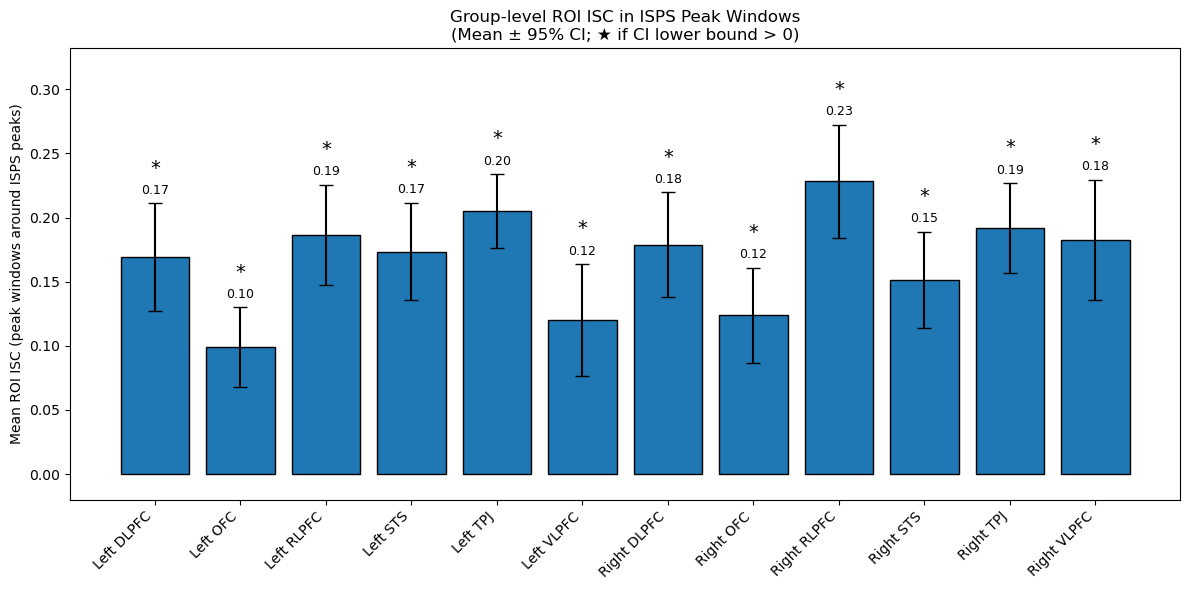

🖼️ Saved group-level ROI ISC peak-window bar plot ➜ C:\Users\pkell\roi_video_corrmats\group_level_ROI_ISC_peak_windows_barplot.png
💾 Saved ROI-level peak-window ISC CSV ➜ C:\Users\pkell\roi_video_corrmats\roi_isc_peak_windows.csv
💾 Saved Video-level peak-window ISC CSV ➜ C:\Users\pkell\roi_video_corrmats\video_isc_peak_windows.csv


In [29]:
# ============================================================
# Peak-window ISC analysis
#   - Uses ISPS peaks CSV per ROI × Trigger
#   - Computes LOO ISC in 9s windows around peaks
#   - Aggregates to ROI- and video-level ISC and plots ROI barplot
# ============================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, sem

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & constants
# -----------------------
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
os.makedirs(save_dir_corrmats, exist_ok=True)

# CSV produced by your ISPS pipeline
peaks_csv_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")

# Sampling rate & window settings
FS = 1.5                  # Hz (same as your pipelines)
HALF_WINDOW_SEC = 4.0     # 4 seconds before/after peak
MIN_SUBJ_FOR_ISC = 3      # require at least this many subjects for ISC

# -----------------------
# Task video durations (s) for odd triggers
# (same as your previous code)
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels) — same as pipelines
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# ============================================================
# fNIRS preprocessing & ROI time series (same as pipelines)
# ============================================================

def individual_analysis(filepath):
    """Load one SNIRF file, enforce durations, drop even triggers, TDDR, SCI-based bads, Hb conversion, resample."""
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)

    # enforce durations for odd triggers (videos)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]

    # drop even-numbered triggers
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)

    # Standard fNIRS preprocessing
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)

    # SCI + hard-drop bad channels
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")

    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(FS)  # consistent sampling
    return raw

def segment_by_trigger(raw):
    """Segment raw into epochs per trigger with tmax from durations dict."""
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(
            raw, these, event_id={trig_str: trig_id},
            tmin=0, tmax=durations[trig_str],
            baseline=None, detrend=None, preload=True, verbose=False
        )
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    """Average channels within an ROI: data_2d is (n_channels, n_times)."""
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

# -----------------------
# Build roi_ts[subj][trig][roi] = 1D np.array
# -----------------------
all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subject][trigger][roi]

print("Loading and preprocessing fNIRS files to build ROI time series...")
for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
rois = list(roi_definitions.keys())
print(f"Built ROI time series for {len(subjects)} subjects.")

# ============================================================
# Load ISPS peaks CSV and prepare peak windows
# ============================================================
if not os.path.exists(peaks_csv_path):
    raise FileNotFoundError(f"ISPS peaks CSV not found at: {peaks_csv_path}")

peaks_df = pd.read_csv(peaks_csv_path)
if "Trigger" not in peaks_df.columns or "ROI" not in peaks_df.columns or "t_idx" not in peaks_df.columns:
    raise ValueError("Peaks CSV must contain columns: 'Trigger', 'ROI', 't_idx'.")

# Normalize trigger representation as strings (to match roi_ts keys)
peaks_df["TriggerStr"] = peaks_df["Trigger"].astype(str)
peaks_df["t_idx"] = peaks_df["t_idx"].astype(int)

# Build mapping ROI -> set of triggers that have peaks
roi_peak_trigs = defaultdict(set)
for _, row in peaks_df.iterrows():
    roi = row["ROI"]
    trig_str = row["TriggerStr"]
    if roi in roi_definitions:  # safeguard in case of extra ROIs
        roi_peak_trigs[roi].add(trig_str)

# Helper: build union peak window mask for a given length & peak indices
def build_peak_window_mask(length, peak_indices, fs=FS, half_window_sec=HALF_WINDOW_SEC):
    """
    length: number of time points in series
    peak_indices: iterable of peak sample indices (int)
    Returns: boolean mask of shape (length,) that is True in the union of all
             [peak - half_window, peak + half_window] windows.
    """
    mask = np.zeros(length, dtype=bool)
    half_samples = int(round(half_window_sec * fs))  # e.g. 4 s * 1.5 Hz = 6 samples
    for p in peak_indices:
        if not np.isfinite(p):
            continue
        p = int(p)
        if p < 0 or p >= length:
            continue
        start = max(0, p - half_samples)
        end = min(length - 1, p + half_samples)
        mask[start:end+1] = True
    return mask

# ============================================================
# Compute peak-window ISC (LOO) for each Subject × ROI × Trigger
# ============================================================

roi_isc_records = []   # list of dicts -> DataFrame (Subject × ROI)
video_isc_records = [] # list of dicts -> DataFrame (Subject × Trigger)

print("Computing peak-window ISC per subject × ROI × video...")

for subj in subjects:
    subj_roi_agg = {"Subject": subj}
    per_trig_roi_vals = defaultdict(list)  # per trigger: list of ISC values across ROIs

    for roi in rois:
        good_trigs = sorted(list(roi_peak_trigs.get(roi, [])), key=lambda x: int(x))
        roi_corrs = []

        for trig in good_trigs:
            # Skip if this subject has no data for this ROI × trigger
            if roi not in roi_ts[subj].get(trig, {}):
                continue

            # Subjects with data for this ROI×trigger
            subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
            S = len(subj_with_data)
            if S < MIN_SUBJ_FOR_ISC:
                continue

            # Align lengths across subjects
            min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)

            # Get peaks for this ROI × trigger
            sub_peaks = peaks_df[(peaks_df["ROI"] == roi) & (peaks_df["TriggerStr"] == trig)]
            peak_indices = sub_peaks["t_idx"].values
            if peak_indices.size == 0:
                continue

            # Build union window mask
            mask = build_peak_window_mask(min_len, peak_indices, fs=FS, half_window_sec=HALF_WINDOW_SEC)
            if mask.sum() < 2:
                continue  # not enough samples to correlate

            # Build windowed data matrix X_window: (S, T_peak)
            X_window = []
            for s in subj_with_data:
                ts = roi_ts[s][trig][roi][:min_len]
                X_window.append(np.asarray(ts, float)[mask])
            X_window = np.stack(X_window, axis=0)  # (S, T_peak)

            # LOO ISC for the current subject in this ROI×trigger window
            if subj not in subj_with_data:
                continue
            i = subj_with_data.index(subj)
            if X_window.shape[1] < 2:
                continue

            X_sum = X_window.sum(axis=0)
            loo_mean = (X_sum - X_window[i]) / (S - 1)
            r, _ = pearsonr(X_window[i], loo_mean)
            if not np.isnan(r):
                roi_corrs.append(r)
                per_trig_roi_vals[trig].append(r)

        # Aggregate across all peak-window triggers for this ROI for this subject
        subj_roi_agg[roi] = float(np.mean(roi_corrs)) if roi_corrs else np.nan

    roi_isc_records.append(subj_roi_agg)

    # Per-video ISC = mean across ROIs for that trigger (using peak windows)
    for trig, vals in per_trig_roi_vals.items():
        if vals:
            video_isc_records.append({
                "Subject": subj,
                "Trigger": trig,
                "ISC": float(np.mean(vals))
            })

# -----------------------
# Build DataFrames
# -----------------------
roi_isc_df_peaks = pd.DataFrame(roi_isc_records)   # Subject × ROI
video_isc_df_peaks = pd.DataFrame(video_isc_records)

print("\n✅ Peak-window ROI-level ISC (averaged across peak-window triggers):")
print(roi_isc_df_peaks.head())

print("\n✅ Peak-window Video-level ISC (mean across ROIs):")
print(video_isc_df_peaks.head())

# ============================================================
# Group-level ROI BAR PLOT (mean±95% CI across subjects)
# ============================================================

roi_cols = [c for c in roi_isc_df_peaks.columns if c != "Subject"]
roi_means, roi_cis, sig_mask, ns = [], [], [], []

for roi in roi_cols:
    vals = roi_isc_df_peaks[roi].dropna().values
    ns.append(len(vals))
    if len(vals) == 0:
        roi_means.append(np.nan)
        roi_cis.append(np.nan)
        sig_mask.append(False)
        continue
    m = np.mean(vals)
    ci95 = 1.96 * sem(vals) if len(vals) > 1 else 0.0
    roi_means.append(m)
    roi_cis.append(ci95)
    sig_mask.append(m - ci95 > 0.0)  # CI lower bound > 0

# Sort ROI names (same L/R grouping trick as before)
roi_order = sorted(roi_cols, key=lambda r: (r.split()[0] not in ['Left','Right'], r))

plt.figure(figsize=(12, 6))
bars = plt.bar(
    roi_order,
    [roi_means[roi_cols.index(r)] for r in roi_order],
    yerr=[roi_cis[roi_cols.index(r)] for r in roi_order],
    capsize=5, edgecolor='black'
)

# Add stars and value labels
for bar, roi in zip(bars, roi_order):
    i = roi_cols.index(roi)
    m, ci, n = roi_means[i], roi_cis[i], ns[i]
    if np.isfinite(m):
        plt.text(
            bar.get_x() + bar.get_width()/2,
            m + (ci if np.isfinite(ci) else 0) + 0.005,
            f"{m:.2f}",
            ha='center', va='bottom', fontsize=9
        )
    if np.isfinite(m) and np.isfinite(ci) and sig_mask[i]:
        x = bar.get_x() + bar.get_width()/2
        y = m + ci + 0.02
        plt.text(x, y, "*", ha='center', va='bottom', fontsize=14)

plt.ylabel("Mean ROI ISC (peak windows around ISPS peaks)")
plt.title("Group-level ROI ISC in ISPS Peak Windows\n(Mean ± 95% CI; ★ if CI lower bound > 0)")
plt.xticks(rotation=45, ha='right')

lower = np.nanmin(np.array(roi_means) - np.array(roi_cis))
upper = np.nanmax(np.array(roi_means) + np.array(roi_cis))
plt.ylim(bottom=min(0, lower) - 0.02, top=upper + 0.06)
plt.tight_layout()

roi_bar_out = os.path.join(save_dir_corrmats, "group_level_ROI_ISC_peak_windows_barplot.png")
plt.savefig(roi_bar_out, dpi=220)
plt.show()
print(f"🖼️ Saved group-level ROI ISC peak-window bar plot ➜ {roi_bar_out}")

# -----------------------
# Optional: save ISC DataFrames
# -----------------------
roi_isc_peaks_csv = os.path.join(save_dir_corrmats, "roi_isc_peak_windows.csv")
video_isc_peaks_csv = os.path.join(save_dir_corrmats, "video_isc_peak_windows.csv")
roi_isc_df_peaks.to_csv(roi_isc_peaks_csv, index=False)
video_isc_df_peaks.to_csv(video_isc_peaks_csv, index=False)
print(f"💾 Saved ROI-level peak-window ISC CSV ➜ {roi_isc_peaks_csv}")
print(f"💾 Saved Video-level peak-window ISC CSV ➜ {video_isc_peaks_csv}")


Loading and preprocessing fNIRS files to build ROI time series...
Dropping 26 bad channels (SCI < 0.5): ['S5_D16 760', 'S7_D7 760', 'S8_D5 760', 'S10_D17 760', 'S12_D9 760', 'S12_D10 760', 'S12_D19 760', 'S14_D11 760', 'S14_D14 760', 'S15_D14 760', 'S16_D12 760', 'S16_D14 760', 'S16_D23 760', 'S5_D16 850', 'S7_D7 850', 'S8_D5 850', 'S10_D17 850', 'S12_D9 850', 'S12_D10 850', 'S12_D19 850', 'S14_D11 850', 'S14_D14 850', 'S15_D14 850', 'S16_D12 850', 'S16_D14 850', 'S16_D23 850']
Dropping 12 bad channels (SCI < 0.5): ['S2_D2 760', 'S10_D17 760', 'S14_D11 760', 'S14_D14 760', 'S14_D21 760', 'S16_D23 760', 'S2_D2 850', 'S10_D17 850', 'S14_D11 850', 'S14_D14 850', 'S14_D21 850', 'S16_D23 850']
Dropping 6 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D16 760', 'S14_D21 760', 'S2_D3 850', 'S5_D16 850', 'S14_D21 850']
Dropping 20 bad channels (SCI < 0.5): ['S2_D3 760', 'S5_D10 760', 'S5_D16 760', 'S7_D7 760', 'S10_D17 760', 'S11_D18 760', 'S12_D10 760', 'S13_D20 760', 'S14_D11 760', 'S14_D21 760

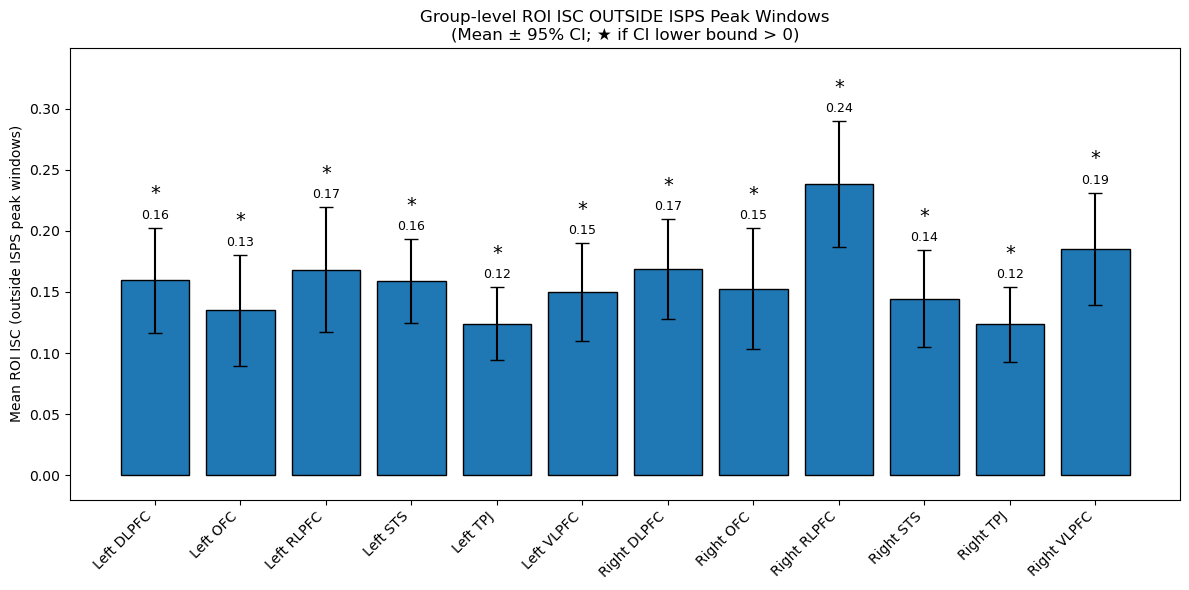

🖼️ Saved group-level ROI ISC outside-peak bar plot ➜ C:\Users\pkell\roi_video_corrmats\group_level_ROI_ISC_outside_peaks_barplot.png
💾 Saved ROI-level outside-peak ISC CSV ➜ C:\Users\pkell\roi_video_corrmats\roi_isc_outside_peaks.csv
💾 Saved Video-level outside-peak ISC CSV ➜ C:\Users\pkell\roi_video_corrmats\video_isc_outside_peaks.csv


In [31]:
# ============================================================
# Outside-peak ISC analysis
#   - Uses ISPS peaks CSV per ROI × Trigger
#   - Computes LOO ISC OUTSIDE the 9s windows around peaks
#   - Aggregates to ROI- and video-level ISC and plots ROI barplot
#   - Saves SAME-style figures/CSVs with "outside_peaks" in filenames
#     so you can directly compare to the peak-window outputs
# ============================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import compress
from scipy.stats import pearsonr, sem

import mne
from mne.preprocessing.nirs import (
    optical_density,
    beer_lambert_law,
    temporal_derivative_distribution_repair,
)

# -----------------------
# Paths & constants
# -----------------------
root = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\fNIRS Data\snirf"
save_dir_corrmats = os.path.join(os.getcwd(), "roi_video_corrmats")
os.makedirs(save_dir_corrmats, exist_ok=True)

# CSV produced by your ISPS pipeline
peaks_csv_path = os.path.join(save_dir_corrmats, "ISPS_peaks_by_trigger_roi_task.csv")

# Sampling rate & window settings
FS = 1.5                  # Hz (same as your pipelines)
HALF_WINDOW_SEC = 4.0     # 4 seconds before/after peak
MIN_SUBJ_FOR_ISC = 3      # require at least this many subjects for ISC

# -----------------------
# Task video durations (s) for odd triggers
# (same as your previous code)
# -----------------------
durations = {
    '1': 60.36, '3': 60.55, '5': 50, '7': 95.35, '9': 86.12, '11': 51.12, '13': 48.56, '15': 58,
    '17': 103.8, '19': 46.59, '21': 83.16, '23': 67.63, '25': 60.36, '27': 67.83, '29': 158,
    '31': 33.23, '33': 35.78, '35': 37, '37': 51.31, '39': 75.49, '41': 129.95, '43': 81.98,
    '45': 145.29, '47': 46.59, '49': 58.19, '51': 94.37, '53': 34.99, '55': 55.44
}

# -----------------------
# ROI definitions (HbO channels) — same as pipelines
# -----------------------
roi_definitions = {
    "Left RLPFC": ['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D2 hbo'],
    "Left VLPFC": ['S3_D1 hbo', 'S3_D3 hbo'],
    "Left DLPFC": ['S2_D3 hbo', 'S4_D3 hbo', 'S4_D2 hbo'],
    "Left OFC": ['S1_D15 hbo'],
    "Left STS": ['S5_D4 hbo','S5_D10 hbo','S11_D4 hbo', 'S11_D10 hbo', 'S12_D9 hbo', 'S12_D10 hbo'],
    "Left TPJ": ['S11_D9 hbo', 'S11_D8 hbo', 'S13_D8 hbo','S13_D9 hbo'],
    "Right RLPFC": ['S6_D5 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D6 hbo'],
    "Right DLPFC": ['S7_D7 hbo','S8_D5 hbo', 'S8_D7 hbo'],
    "Right VLPFC": ['S9_D7 hbo', 'S9_D6 hbo'],
    "Right OFC": ['S6_D15 hbo'],
    "Right STS": ['S10_D13 hbo','S10_D11 hbo','S14_D11 hbo', 'S14_D14 hbo','S15_D11 hbo','S15_D13 hbo'],
    "Right TPJ": ['S15_D12 hbo', 'S15_D14 hbo', 'S16_D12 hbo','S16_D14 hbo']
}

# ============================================================
# fNIRS preprocessing & ROI time series (same as pipelines)
# ============================================================

def individual_analysis(filepath):
    """Load one SNIRF file, enforce durations, drop even triggers, TDDR, SCI-based bads, Hb conversion, resample."""
    file = mne.io.read_raw_snirf(filepath, preload=True, verbose=False)

    # enforce durations for odd triggers (videos)
    for i, desc in enumerate(file.annotations.description):
        if desc in durations:
            file.annotations.duration[i] = durations[desc]

    # drop even-numbered triggers
    even = [str(x) for x in range(2, 57, 2)]
    unwanted = np.nonzero(np.isin(file.annotations.description, even))
    file.annotations.delete(unwanted)

    # Standard fNIRS preprocessing
    raw_od = optical_density(file)
    raw_od1 = temporal_derivative_distribution_repair(raw_od)

    # SCI + hard-drop bad channels
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od1)
    bads = list(compress(raw_od1.ch_names, sci < 0.5))
    raw_od1.info["bads"] = bads
    if bads:
        print(f"Dropping {len(bads)} bad channels (SCI < 0.5): {bads}")
        raw_od1 = raw_od1.copy().drop_channels(bads)
    else:
        print("No bad channels to drop (SCI < 0.5).")

    raw = beer_lambert_law(raw_od1, ppf=0.1)
    raw.resample(FS)  # consistent sampling
    return raw

def segment_by_trigger(raw):
    """Segment raw into epochs per trigger with tmax from durations dict."""
    events, event_ids = mne.events_from_annotations(raw, verbose=False)
    epochs_dict = {}
    for trig_str, trig_id in event_ids.items():
        if trig_str not in durations:
            continue
        these = events[events[:, 2] == trig_id]
        if len(these) == 0:
            continue
        epochs = mne.Epochs(
            raw, these, event_id={trig_str: trig_id},
            tmin=0, tmax=durations[trig_str],
            baseline=None, detrend=None, preload=True, verbose=False
        )
        epochs_dict[trig_str] = epochs
    return epochs_dict

def extract_roi_time_series_np(data_2d, ch_names, roi_chs):
    """Average channels within an ROI: data_2d is (n_channels, n_times)."""
    name_to_idx = {nm: i for i, nm in enumerate(ch_names)}
    idxs = [name_to_idx[ch] for ch in roi_chs if ch in name_to_idx]
    if not idxs:
        return None
    return data_2d[idxs].mean(axis=0)

# -----------------------
# Build roi_ts[subj][trig][roi] = 1D np.array
# -----------------------
all_files = [f for f in os.listdir(root) if f.lower().endswith('.snirf')]
subjects = [os.path.splitext(f)[0][:6] for f in all_files]

subject_epochs = {}
roi_ts = defaultdict(lambda: defaultdict(dict))  # roi_ts[subject][trigger][roi]

print("Loading and preprocessing fNIRS files to build ROI time series...")
for sid, fname in zip(subjects, all_files):
    raw = individual_analysis(os.path.join(root, fname))
    epdict = segment_by_trigger(raw)
    subject_epochs[sid] = epdict
    for trig, epochs in epdict.items():
        dat = np.mean(epochs.get_data(), axis=0)  # (n_channels, n_times)
        ch_names = epochs.ch_names
        for roi, chans in roi_definitions.items():
            ts = extract_roi_time_series_np(dat, ch_names, chans)
            if ts is not None:
                roi_ts[sid][trig][roi] = ts

subjects = list(subject_epochs.keys())
rois = list(roi_definitions.keys())
print(f"Built ROI time series for {len(subjects)} subjects.")

# ============================================================
# Load ISPS peaks CSV and prepare peak windows
# ============================================================
if not os.path.exists(peaks_csv_path):
    raise FileNotFoundError(f"ISPS peaks CSV not found at: {peaks_csv_path}")

peaks_df = pd.read_csv(peaks_csv_path)
if "Trigger" not in peaks_df.columns or "ROI" not in peaks_df.columns or "t_idx" not in peaks_df.columns:
    raise ValueError("Peaks CSV must contain columns: 'Trigger', 'ROI', 't_idx'.")

# Normalize trigger representation as strings (to match roi_ts keys)
peaks_df["TriggerStr"] = peaks_df["Trigger"].astype(str)
peaks_df["t_idx"] = peaks_df["t_idx"].astype(int)

# Build mapping ROI -> set of triggers that have peaks
roi_peak_trigs = defaultdict(set)
for _, row in peaks_df.iterrows():
    roi = row["ROI"]
    trig_str = row["TriggerStr"]
    if roi in roi_definitions:  # safeguard in case of extra ROIs
        roi_peak_trigs[roi].add(trig_str)

# Helper: build union peak window mask for a given length & peak indices
def build_peak_window_mask(length, peak_indices, fs=FS, half_window_sec=HALF_WINDOW_SEC):
    """
    length: number of time points in series
    peak_indices: iterable of peak sample indices (int)
    Returns: boolean mask of shape (length,) that is True in the union of all
             [peak - half_window, peak + half_window] windows.
    """
    mask = np.zeros(length, dtype=bool)
    half_samples = int(round(half_window_sec * fs))  # e.g. 4 s * 1.5 Hz = 6 samples
    for p in peak_indices:
        if not np.isfinite(p):
            continue
        p = int(p)
        if p < 0 or p >= length:
            continue
        start = max(0, p - half_samples)
        end = min(length - 1, p + half_samples)
        mask[start:end+1] = True
    return mask

# ============================================================
# Compute OUTSIDE-PEAK ISC (LOO) for each Subject × ROI × Trigger
#   - uses same ROI×trigger peak sets, but correlates using samples
#     OUTSIDE the union peak windows
# ============================================================

roi_isc_records = []   # list of dicts -> DataFrame (Subject × ROI)
video_isc_records = [] # list of dicts -> DataFrame (Subject × Trigger)

print("Computing outside-peak ISC per subject × ROI × video...")

for subj in subjects:
    subj_roi_agg = {"Subject": subj}
    per_trig_roi_vals = defaultdict(list)  # per trigger: list of ISC values across ROIs

    for roi in rois:
        good_trigs = sorted(list(roi_peak_trigs.get(roi, [])), key=lambda x: int(x))
        roi_corrs = []

        for trig in good_trigs:
            # Skip if this subject has no data for this ROI × trigger
            if roi not in roi_ts[subj].get(trig, {}):
                continue

            # Subjects with data for this ROI×trigger
            subj_with_data = [s for s in subjects if roi in roi_ts[s].get(trig, {})]
            S = len(subj_with_data)
            if S < MIN_SUBJ_FOR_ISC:
                continue

            # Align lengths across subjects
            min_len = min(len(roi_ts[s][trig][roi]) for s in subj_with_data)

            # Get peaks for this ROI × trigger
            sub_peaks = peaks_df[(peaks_df["ROI"] == roi) & (peaks_df["TriggerStr"] == trig)]
            peak_indices = sub_peaks["t_idx"].values
            if peak_indices.size == 0:
                continue

            # Build union peak mask, then invert to get outside-peak mask
            peak_mask = build_peak_window_mask(min_len, peak_indices, fs=FS, half_window_sec=HALF_WINDOW_SEC)
            outside_mask = ~peak_mask

            if outside_mask.sum() < 2:
                continue  # not enough samples to correlate

            # Build outside-window data matrix X_out: (S, T_outside)
            X_out = []
            for s in subj_with_data:
                ts = roi_ts[s][trig][roi][:min_len]
                X_out.append(np.asarray(ts, float)[outside_mask])
            X_out = np.stack(X_out, axis=0)  # (S, T_outside)

            # LOO ISC for the current subject in this ROI×trigger OUTSIDE-peak region
            if subj not in subj_with_data:
                continue
            i = subj_with_data.index(subj)
            if X_out.shape[1] < 2:
                continue

            X_sum = X_out.sum(axis=0)
            loo_mean = (X_sum - X_out[i]) / (S - 1)
            r, _ = pearsonr(X_out[i], loo_mean)
            if not np.isnan(r):
                roi_corrs.append(r)
                per_trig_roi_vals[trig].append(r)

        # Aggregate across all outside-peak triggers for this ROI for this subject
        subj_roi_agg[roi] = float(np.mean(roi_corrs)) if roi_corrs else np.nan

    roi_isc_records.append(subj_roi_agg)

    # Per-video ISC = mean across ROIs for that trigger (using outside-peak samples)
    for trig, vals in per_trig_roi_vals.items():
        if vals:
            video_isc_records.append({
                "Subject": subj,
                "Trigger": trig,
                "ISC": float(np.mean(vals))
            })

# -----------------------
# Build DataFrames
# -----------------------
roi_isc_df_outside = pd.DataFrame(roi_isc_records)   # Subject × ROI
video_isc_df_outside = pd.DataFrame(video_isc_records)

print("\n✅ Outside-peak ROI-level ISC (averaged across outside-peak triggers):")
print(roi_isc_df_outside.head())

print("\n✅ Outside-peak Video-level ISC (mean across ROIs):")
print(video_isc_df_outside.head())

# ============================================================
# Group-level ROI BAR PLOT (mean±95% CI across subjects)
# ============================================================

roi_cols = [c for c in roi_isc_df_outside.columns if c != "Subject"]
roi_means, roi_cis, sig_mask, ns = [], [], [], []

for roi in roi_cols:
    vals = roi_isc_df_outside[roi].dropna().values
    ns.append(len(vals))
    if len(vals) == 0:
        roi_means.append(np.nan)
        roi_cis.append(np.nan)
        sig_mask.append(False)
        continue
    m = np.mean(vals)
    ci95 = 1.96 * sem(vals) if len(vals) > 1 else 0.0
    roi_means.append(m)
    roi_cis.append(ci95)
    sig_mask.append(m - ci95 > 0.0)  # CI lower bound > 0

# Sort ROI names (same L/R grouping trick as before)
roi_order = sorted(roi_cols, key=lambda r: (r.split()[0] not in ['Left','Right'], r))

plt.figure(figsize=(12, 6))
bars = plt.bar(
    roi_order,
    [roi_means[roi_cols.index(r)] for r in roi_order],
    yerr=[roi_cis[roi_cols.index(r)] for r in roi_order],
    capsize=5, edgecolor='black'
)

# Add stars and value labels
for bar, roi in zip(bars, roi_order):
    i = roi_cols.index(roi)
    m, ci, n = roi_means[i], roi_cis[i], ns[i]
    if np.isfinite(m):
        plt.text(
            bar.get_x() + bar.get_width()/2,
            m + (ci if np.isfinite(ci) else 0) + 0.005,
            f"{m:.2f}",
            ha='center', va='bottom', fontsize=9
        )
    if np.isfinite(m) and np.isfinite(ci) and sig_mask[i]:
        x = bar.get_x() + bar.get_width()/2
        y = m + ci + 0.02
        plt.text(x, y, "*", ha='center', va='bottom', fontsize=14)

plt.ylabel("Mean ROI ISC (outside ISPS peak windows)")
plt.title("Group-level ROI ISC OUTSIDE ISPS Peak Windows\n(Mean ± 95% CI; ★ if CI lower bound > 0)")
plt.xticks(rotation=45, ha='right')

lower = np.nanmin(np.array(roi_means) - np.array(roi_cis))
upper = np.nanmax(np.array(roi_means) + np.array(roi_cis))
plt.ylim(bottom=min(0, lower) - 0.02, top=upper + 0.06)
plt.tight_layout()

roi_bar_out = os.path.join(save_dir_corrmats, "group_level_ROI_ISC_outside_peaks_barplot.png")
plt.savefig(roi_bar_out, dpi=220)
plt.show()
print(f"🖼️ Saved group-level ROI ISC outside-peak bar plot ➜ {roi_bar_out}")

# -----------------------
# Save ISC DataFrames (same structure; different filenames)
# -----------------------
roi_isc_outside_csv = os.path.join(save_dir_corrmats, "roi_isc_outside_peaks.csv")
video_isc_outside_csv = os.path.join(save_dir_corrmats, "video_isc_outside_peaks.csv")
roi_isc_df_outside.to_csv(roi_isc_outside_csv, index=False)
video_isc_df_outside.to_csv(video_isc_outside_csv, index=False)
print(f"💾 Saved ROI-level outside-peak ISC CSV ➜ {roi_isc_outside_csv}")
print(f"💾 Saved Video-level outside-peak ISC CSV ➜ {video_isc_outside_csv}")

In [35]:
roi_isc_df_outside

,Subject,Left RLPFC,Left VLPFC,Left DLPFC,Left OFC,Left STS,Left TPJ,Right RLPFC,Right DLPFC,Right VLPFC,Right OFC,Right STS,Right TPJ
0,pid001,0.393103,0.208265,0.207357,0.322523,0.055829,-0.016140,0.364423,0.264032,0.240801,0.300815,0.127628,0.183044
1,pid002,0.199214,0.073659,0.152688,0.145787,0.109246,0.178286,0.163811,0.064440,0.140174,0.246755,0.116844,0.175414
2,pid003,0.369177,0.231418,0.317252,0.284446,0.251679,0.099937,0.327943,0.316032,0.180006,0.165914,0.276483,0.156062
3,pid004,0.318835,0.166154,0.265059,0.251364,-0.034540,0.064341,0.433218,0.335650,0.338502,0.352142,0.239091,0.149206
4,pid005,0.101786,0.061787,0.106747,-0.084769,0.078983,0.065161,0.139324,0.202457,0.219212,0.064301,0.065601,0.051166
5,pid006,0.038019,0.091689,0.016925,-0.131592,0.063321,-0.015310,0.001428,-0.018304,0.071749,-0.015252,0.055482,0.099679
6,pid007,0.294651,0.081368,0.276457,0.306122,0.207695,0.306637,0.389248,0.326462,0.259903,0.473132,0.116036,0.277019
7,pid008,0.339774,0.189931,0.354698,0.247321,0.295845,0.228859,0.499168,0.328569,0.144814,0.396273,0.110856,0.259352
8,pid009,0.295372,0.142460,0.218525,-0.074679,0.142392,0.176076,0.267832,0.186222,0.378854,0.209344,0.081402,0.017807
9,pid010,-0.130179,0.201000,0.038169,0.200541,0.140727,0.155104,0.257392,0.028894,0.207976,0.077387,0.278744,0.149531


In [ ]:
# ============================================================
# Per-video peak-window ISC barplot by trigger group
# ============================================================

# Define trigger groupings (by trigger number)
trigger_groups = {
    "Social":   [1, 3, 5, 7, 21, 23, 25, 27],
    "Positive": [9, 11, 13, 29, 31, 33],
    "Negative": [15, 17, 19, 35, 37, 39],
    "White":    [49, 51, 53, 55],
    "Black":    [41, 43, 45, 47],
}

if "video_isc_df_peaks" not in globals() or video_isc_df_peaks.empty:
    print("⚠️ video_isc_df_peaks is missing or empty; skipping per-video ISC plot.")
else:
    video_plot_df = video_isc_df_peaks.copy()

    # Try to interpret Trigger as an integer trigger number
    video_plot_df["Trigger_int"] = pd.to_numeric(video_plot_df["Trigger"], errors="coerce")

    # If that failed (e.g., Trigger holds video names), try mapping via video_mapping.csv
    if video_plot_df["Trigger_int"].isna().all():
        mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
        if os.path.exists(mapping_csv):
            map_df = pd.read_csv(mapping_csv)
            lower_cols = {c.lower(): c for c in map_df.columns}
            if "video" in lower_cols and "trigger_number" in lower_cols:
                col_video = lower_cols["video"]
                col_trig = lower_cols["trigger_number"]
                map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce")
                map_df = map_df[[col_video, "Trigger_int"]].dropna(subset=["Trigger_int"])
                # Merge on video name (assuming video_isc_df_peaks['Trigger'] holds original video names)
                merged = video_plot_df.merge(
                    map_df,
                    left_on="Trigger",
                    right_on=col_video,
                    how="left"
                )
                video_plot_df["Trigger_int"] = merged["Trigger_int"]
            else:
                print(f"⚠️ Mapping CSV {mapping_csv} missing 'video' or 'trigger_number' columns; "
                      "cannot map video names to trigger numbers.")
        else:
            print(f"⚠️ Mapping CSV not found at {mapping_csv}; cannot map video names to trigger numbers.")

    # Drop rows without valid trigger numbers
    video_plot_df = video_plot_df.dropna(subset=["Trigger_int"]).copy()
    if video_plot_df.empty:
        print("⚠️ No valid trigger numbers found after mapping; skipping per-video ISC plot.")
    else:
        video_plot_df["Trigger_int"] = video_plot_df["Trigger_int"].astype(int)

        # Map each trigger to a condition group
        def _assign_group(trig):
            for g, trig_list in trigger_groups.items():
                if trig in trig_list:
                    return g
            return None  # triggers not in any group

        video_plot_df["Group"] = video_plot_df["Trigger_int"].apply(_assign_group)
        video_plot_df = video_plot_df.dropna(subset=["Group"]).copy()

        if video_plot_df.empty:
            print("⚠️ No triggers matched the specified trigger_groups; skipping per-video ISC plot.")
        else:
            # Barplot: mean ISC per video (trigger), colored by group
            plt.figure(figsize=(12, 5))
            sns.barplot(
                data=video_plot_df,
                x="Trigger_int",
                y="ISC",
                hue="Group",
                estimator=np.mean,
                ci=95,
                dodge=False
            )
            plt.xlabel("Trigger (Video)")
            plt.ylabel("Peak-window ISC (mean across subjects)")
            plt.title("Per-video Peak-window ISC grouped by condition")
            plt.xticks(rotation=45)
            plt.tight_layout()

            pervideo_out = os.path.join(save_dir_corrmats, "per_video_peakISC_by_group.png")
            plt.savefig(pervideo_out, dpi=220)
            plt.show()
            print(f"🖼️ Saved per-video ISC plot by group ➜ {pervideo_out}")


In [33]:
pca_df

,Subject,AQ_Score,EQ_Score,EmQ_Score,Valence_Acc,Arousal_Acc,OverallAcc_SD,PC1,PC1_Group
0,pid008,13,124,19,0.801066,0.561459,0.277049,0.927593,High_PC1
1,pid021,23,114,10,0.521835,0.353910,0.479050,-4.326791,Low_PC1
2,pid023,12,131,8,0.628503,0.464864,0.401016,-1.611859,Low_PC1
3,pid001,18,103,19,0.695283,0.392981,0.321415,-1.707052,Low_PC1
4,pid010,23,126,13,0.732521,0.589955,0.346265,-0.082820,Low_PC1
5,pid009,10,134,27,0.796240,0.539700,0.288278,0.796274,High_PC1
6,pid015,7,148,15,0.775066,0.586787,0.249913,1.910064,High_PC1
7,pid019,15,152,8,0.676342,0.568736,0.342292,0.304982,High_PC1
8,pid030,13,121,14,0.678081,0.524209,0.338985,-0.667999,Low_PC1
9,pid035,15,143,5,0.680978,0.627670,0.286906,1.096820,High_PC1


In [37]:
# ============================================================
# Correlate ROI ISC (PEAK vs OUTSIDE) with PC1
#  - Expects in memory:
#      roi_isc_df_peaks   : columns = ['Subject', ROI...]
#      roi_isc_df_outside : columns = ['Subject', ROI...]
#      pca_df             : columns = ['Subject', 'PC1']
#  - For each ROI:
#      * correlates PEAK ISC vs PC1 and OUTSIDE ISC vs PC1 (Pearson)
#      * saves scatter plots with regression line + r,p in title
#  - Also computes Overall ISC = mean across ROIs per subject
#      * correlates Overall PEAK ISC vs PC1 and Overall OUTSIDE ISC vs PC1
#  - Saves:
#      * one CSV summary of all correlations
#      * per-ROI figures
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

# -----------------------
# Config
# -----------------------
SAVE_DIR = os.path.join(os.getcwd(), "isc_pc1_correlations")
os.makedirs(SAVE_DIR, exist_ok=True)

# If you want Spearman instead, change this block:
CORR_METHOD = "pearson"  # "pearson" only (this chunk); can swap later

# -----------------------
# Helpers
# -----------------------
def _safe_numeric(s):
    return pd.to_numeric(s, errors="coerce")

def _corr(x, y):
    """Return r, p using Pearson; NaNs automatically excluded."""
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return np.nan, np.nan, int(m.sum())
    r, p = pearsonr(x[m], y[m])
    return float(r), float(p), int(m.sum())

def _plot_scatter_with_fit(x, y, title, xlabel, ylabel, out_png):
    m = np.isfinite(x) & np.isfinite(y)
    x2 = x[m].reshape(-1, 1)
    y2 = y[m].reshape(-1, 1)

    plt.figure(figsize=(5.2, 4.6))
    plt.scatter(x2, y2, alpha=0.85, edgecolor="k", linewidth=0.5)

    # regression line (no seaborn)
    if len(x2) >= 2:
        model = LinearRegression().fit(x2, y2)
        xs = np.linspace(float(x2.min()), float(x2.max()), 200).reshape(-1, 1)
        ys = model.predict(xs)
        plt.plot(xs, ys, linewidth=2)

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(out_png, dpi=220)
    plt.close()

# -----------------------
# Merge PC1 into both ISC frames
# -----------------------
# Ensure consistent types
roi_isc_df_peaks = roi_isc_df_peaks.copy()
roi_isc_df_outside = roi_isc_df_outside.copy()
pca_df = pca_df.copy()

roi_isc_df_peaks["Subject"] = roi_isc_df_peaks["Subject"].astype(str)
roi_isc_df_outside["Subject"] = roi_isc_df_outside["Subject"].astype(str)
pca_df["Subject"] = pca_df["Subject"].astype(str)

pca_df["PC1"] = _safe_numeric(pca_df["PC1"])

peaks_m = pd.merge(roi_isc_df_peaks, pca_df[["Subject", "PC1"]], on="Subject", how="inner")
outside_m = pd.merge(roi_isc_df_outside, pca_df[["Subject", "PC1"]], on="Subject", how="inner")

# Identify ROI columns (everything except Subject and PC1)
roi_cols = [c for c in peaks_m.columns if c not in ["Subject", "PC1"]]

# Coerce ROI columns to numeric
for c in roi_cols:
    peaks_m[c] = _safe_numeric(peaks_m[c])
    outside_m[c] = _safe_numeric(outside_m[c])

# -----------------------
# Compute Overall ISC per subject (mean across ROIs)
# -----------------------
peaks_m["ISC_overall"] = peaks_m[roi_cols].mean(axis=1, skipna=True)
outside_m["ISC_overall"] = outside_m[roi_cols].mean(axis=1, skipna=True)

# -----------------------
# Correlations + plots
# -----------------------
summary_rows = []

def _run_one(name, df, isc_col, suffix):
    """
    name: ROI name or 'Overall'
    df: merged dataframe
    isc_col: column in df containing ISC
    suffix: 'PEAK' or 'OUTSIDE'
    """
    x = df["PC1"].to_numpy(dtype=float)
    y = df[isc_col].to_numpy(dtype=float)

    r, p, n = _corr(x, y)
    summary_rows.append({
        "Measure": suffix,
        "Target": name,
        "n": n,
        "r": r,
        "p": p
    })

    title = f"{name} ISC ({suffix}) vs PC1\nr = {r:.3f}, p = {p:.3g}, n = {n}"
    out_png = os.path.join(SAVE_DIR, f"ISC_{suffix}_vs_PC1__{name.replace(' ', '_')}.png")
    _plot_scatter_with_fit(
        x=np.asarray(x, float),
        y=np.asarray(y, float),
        title=title,
        xlabel="PC1 score",
        ylabel=f"ISC ({suffix})",
        out_png=out_png
    )

# Per ROI
for roi in roi_cols:
    _run_one(roi, peaks_m, roi, "PEAK")
    _run_one(roi, outside_m, roi, "OUTSIDE")

# Overall
_run_one("Overall", peaks_m, "ISC_overall", "PEAK")
_run_one("Overall", outside_m, "ISC_overall", "OUTSIDE")

# -----------------------
# Save summary CSV
# -----------------------
summary_df = pd.DataFrame(summary_rows)

# Add BH-FDR within each measure type (PEAK vs OUTSIDE)
def _bh_fdr(pvals):
    p = np.asarray(pvals, float)
    m = np.isfinite(p)
    q = np.full_like(p, np.nan, dtype=float)
    if m.sum() == 0:
        return q
    pv = p[m]
    order = np.argsort(pv)
    pv_sorted = pv[order]
    n = len(pv_sorted)
    # BH q-values
    q_sorted = pv_sorted * n / (np.arange(1, n + 1))
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_sorted = np.clip(q_sorted, 0, 1)
    q_mapped = np.empty_like(q_sorted)
    q_mapped[order] = q_sorted
    q[m] = q_mapped
    return q

summary_df["q_fdr_within_measure"] = np.nan
for meas in ["PEAK", "OUTSIDE"]:
    idx = summary_df["Measure"] == meas
    summary_df.loc[idx, "q_fdr_within_measure"] = _bh_fdr(summary_df.loc[idx, "p"].values)

out_csv = os.path.join(SAVE_DIR, "ISC_vs_PC1_correlations_summary.csv")
summary_df.to_csv(out_csv, index=False)

print(f"✅ Saved per-ROI and overall scatter plots to: {SAVE_DIR}")
print(f"✅ Saved correlation summary CSV to: {out_csv}")

# Show top correlations (by p) for quick inspection
print("\nTop associations (lowest p):")
print(summary_df.sort_values("p").head(12))

✅ Saved per-ROI and overall scatter plots to: C:\Users\pkell\isc_pc1_correlations
✅ Saved correlation summary CSV to: C:\Users\pkell\isc_pc1_correlations\ISC_vs_PC1_correlations_summary.csv

Top associations (lowest p):
    Measure       Target   n         r         p  q_fdr_within_measure
20     PEAK    Right STS  32 -0.321666  0.072610              0.525945
18     PEAK    Right OFC  31  0.301074  0.099791              0.525945
19  OUTSIDE    Right OFC  31  0.275417  0.133714              0.983798
6      PEAK     Left OFC  33  0.246343  0.166980              0.525945
17  OUTSIDE  Right VLPFC  34  0.234303  0.182282              0.983798
10     PEAK     Left TPJ  33 -0.226911  0.204125              0.525945
4      PEAK   Left DLPFC  34 -0.213529  0.225302              0.525945
8      PEAK     Left STS  34 -0.179273  0.310354              0.525945
22     PEAK    Right TPJ  32 -0.174489  0.339506              0.525945
11  OUTSIDE     Left TPJ  33  0.169989  0.344268              0.983798

In [57]:
# ============================================================
# Correlate ROI ISC (PEAK vs OUTSIDE) with Surveys + Performance
#  - Expects in memory:
#      roi_isc_df_peaks   : columns = ['Subject', ROI...]
#      roi_isc_df_outside : columns = ['Subject', ROI...]
#      survey_scores      : columns = ['Subject','AQ_Score','EQ_Score','EmQ_Score']  (at minimum)
#      mean_corr_df       : columns includes ['Subject','Performance']  (overall performance score)
#
#  - For each ROI and each predictor (AQ/EQ/EmQ/Performance):
#      * correlates PEAK ISC vs predictor and OUTSIDE ISC vs predictor (Pearson)
#      * saves scatter plots with regression line + r,p in title
#  - Also computes Overall ISC = mean across ROIs per subject
#      * correlates Overall PEAK ISC vs predictor and Overall OUTSIDE ISC vs predictor
#
#  - Saves:
#      * one CSV summary of all correlations (with BH-FDR within each Measure×Predictor)
#      * per-ROI figures (organized into subfolders per predictor)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

# -----------------------
# Config
# -----------------------
SAVE_DIR = os.path.join(os.getcwd(), "isc_survey_performance_correlations")
os.makedirs(SAVE_DIR, exist_ok=True)

CORR_METHOD = "pearson"  # this chunk uses Pearson

# -----------------------
# Guards
# -----------------------
if "survey_scores" not in globals():
    raise RuntimeError("survey_scores not found in memory. Expected columns: Subject, AQ_Score, EQ_Score, EmQ_Score")
if "mean_corr_df" not in globals():
    raise RuntimeError("mean_corr_df not found in memory. Expected columns: Subject, Performance")

req_surv = {"Subject", "AQ_Score", "EQ_Score", "EmQ_Score"}
miss_surv = sorted(list(req_surv - set(survey_scores.columns)))
if miss_surv:
    raise RuntimeError(f"survey_scores is missing required columns: {miss_surv}")

req_perf = {"Subject", "Performance"}
miss_perf = sorted(list(req_perf - set(mean_corr_df.columns)))
if miss_perf:
    raise RuntimeError(f"mean_corr_df is missing required columns: {miss_perf}")

# -----------------------
# Helpers
# -----------------------
def _safe_numeric(s):
    return pd.to_numeric(s, errors="coerce")

def _corr(x, y):
    """Return r, p using Pearson; NaNs automatically excluded."""
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return np.nan, np.nan, int(m.sum())
    r, p = pearsonr(x[m], y[m])
    return float(r), float(p), int(m.sum())

def _plot_scatter_with_fit(x, y, title, xlabel, ylabel, out_png):
    m = np.isfinite(x) & np.isfinite(y)
    x2 = x[m].reshape(-1, 1)
    y2 = y[m].reshape(-1, 1)

    plt.figure(figsize=(5.2, 4.6))
    plt.scatter(x2, y2, alpha=0.85, edgecolor="k", linewidth=0.5)

    # regression line (no seaborn)
    if len(x2) >= 2:
        model = LinearRegression().fit(x2, y2)
        xs = np.linspace(float(x2.min()), float(x2.max()), 200).reshape(-1, 1)
        ys = model.predict(xs)
        plt.plot(xs, ys, linewidth=2)

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(out_png, dpi=220)
    plt.close()

def _bh_fdr(pvals):
    """Benjamini-Hochberg FDR q-values for an array-like of p-values."""
    p = np.asarray(pvals, float)
    m = np.isfinite(p)
    q = np.full_like(p, np.nan, dtype=float)
    if m.sum() == 0:
        return q
    pv = p[m]
    order = np.argsort(pv)
    pv_sorted = pv[order]
    n = len(pv_sorted)
    q_sorted = pv_sorted * n / (np.arange(1, n + 1))
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_sorted = np.clip(q_sorted, 0, 1)
    q_mapped = np.empty_like(q_sorted)
    q_mapped[order] = q_sorted
    q[m] = q_mapped
    return q

# -----------------------
# Prepare dataframes
# -----------------------
roi_isc_df_peaks = roi_isc_df_peaks.copy()
roi_isc_df_outside = roi_isc_df_outside.copy()

roi_isc_df_peaks["Subject"] = roi_isc_df_peaks["Subject"].astype(str)
roi_isc_df_outside["Subject"] = roi_isc_df_outside["Subject"].astype(str)

surv = survey_scores[["Subject", "AQ_Score", "EQ_Score", "EmQ_Score"]].copy()
surv["Subject"] = surv["Subject"].astype(str)
for c in ["AQ_Score", "EQ_Score", "EmQ_Score"]:
    surv[c] = _safe_numeric(surv[c])

perf = mean_corr_df[["Subject", "Performance"]].copy()
perf["Subject"] = perf["Subject"].astype(str)
perf["Performance"] = _safe_numeric(perf["Performance"])

# Merge predictors into both ISC frames
peaks_m = roi_isc_df_peaks.merge(surv, on="Subject", how="inner").merge(perf, on="Subject", how="inner")
outside_m = roi_isc_df_outside.merge(surv, on="Subject", how="inner").merge(perf, on="Subject", how="inner")

predictors = ["AQ_Score", "EQ_Score", "EmQ_Score", "Performance"]

# Identify ROI columns (everything except Subject + predictors)
roi_cols = [c for c in peaks_m.columns if c not in (["Subject"] + predictors)]

# Coerce ROI columns to numeric
for c in roi_cols:
    peaks_m[c] = _safe_numeric(peaks_m[c])
    outside_m[c] = _safe_numeric(outside_m[c])

# Compute Overall ISC per subject (mean across ROIs)
peaks_m["ISC_overall"] = peaks_m[roi_cols].mean(axis=1, skipna=True)
outside_m["ISC_overall"] = outside_m[roi_cols].mean(axis=1, skipna=True)

# -----------------------
# Correlations + plots
# -----------------------
summary_rows = []

def _run_one(target_name, df, isc_col, suffix, predictor_col):
    """
    target_name: ROI name or 'Overall'
    df: merged dataframe
    isc_col: column in df containing ISC
    suffix: 'PEAK' or 'OUTSIDE'
    predictor_col: AQ_Score / EQ_Score / EmQ_Score / Performance
    """
    x = df[predictor_col].to_numpy(dtype=float)
    y = df[isc_col].to_numpy(dtype=float)

    r, p, n = _corr(x, y)
    summary_rows.append({
        "Measure": suffix,
        "Predictor": predictor_col,
        "Target": target_name,
        "n": n,
        "r": r,
        "p": p
    })

    # Save plots in predictor-specific subfolders
    pred_dir = os.path.join(SAVE_DIR, predictor_col)
    os.makedirs(pred_dir, exist_ok=True)

    title = f"{target_name} ISC ({suffix}) vs {predictor_col}\nr = {r:.3f}, p = {p:.3g}, n = {n}"
    out_png = os.path.join(pred_dir, f"ISC_{suffix}_vs_{predictor_col}__{target_name.replace(' ', '_')}.png")
    _plot_scatter_with_fit(
        x=np.asarray(x, float),
        y=np.asarray(y, float),
        title=title,
        xlabel=predictor_col,
        ylabel=f"ISC ({suffix})",
        out_png=out_png
    )

# Per ROI + Overall, for each predictor
for pred in predictors:
    for roi in roi_cols:
        _run_one(roi, peaks_m, roi, "PEAK", pred)
        _run_one(roi, outside_m, roi, "OUTSIDE", pred)

    _run_one("Overall", peaks_m, "ISC_overall", "PEAK", pred)
    _run_one("Overall", outside_m, "ISC_overall", "OUTSIDE", pred)

# -----------------------
# Save summary CSV + FDR within each Measure×Predictor
# -----------------------
summary_df = pd.DataFrame(summary_rows)

summary_df["q_fdr_within_measure_predictor"] = np.nan
for meas in ["PEAK", "OUTSIDE"]:
    for pred in predictors:
        idx = (summary_df["Measure"] == meas) & (summary_df["Predictor"] == pred)
        summary_df.loc[idx, "q_fdr_within_measure_predictor"] = _bh_fdr(summary_df.loc[idx, "p"].values)

out_csv = os.path.join(SAVE_DIR, "ISC_vs_surveys_performance_correlations_summary.csv")
summary_df.to_csv(out_csv, index=False)

print(f"✅ Saved per-ROI and overall scatter plots to: {SAVE_DIR}")
print(f"✅ Saved correlation summary CSV to: {out_csv}")

# Show top correlations (by p) for quick inspection
print("\nTop associations (lowest p):")
print(summary_df.sort_values("p").head(20))

✅ Saved per-ROI and overall scatter plots to: C:\Users\pkell\isc_survey_performance_correlations
✅ Saved correlation summary CSV to: C:\Users\pkell\isc_survey_performance_correlations\ISC_vs_surveys_performance_correlations_summary.csv

Top associations (lowest p):
    Measure    Predictor       Target   n         r         p  \
46     PEAK     EQ_Score    Right STS  32 -0.518711  0.002353   
72     PEAK    EmQ_Score    Right STS  32  0.444027  0.010903   
2      PEAK     AQ_Score   Left VLPFC  34  0.394699  0.020884   
65  OUTSIDE    EmQ_Score  Right RLPFC  34  0.308976  0.075399   
35  OUTSIDE     EQ_Score     Left STS  34  0.302688  0.081855   
67  OUTSIDE    EmQ_Score  Right DLPFC  34  0.292065  0.093721   
96     PEAK  Performance    Right OFC  31  0.302080  0.098609   
20     PEAK     AQ_Score    Right STS  32  0.287434  0.110678   
58     PEAK    EmQ_Score     Left OFC  33 -0.262438  0.140088   
41  OUTSIDE     EQ_Score  Right DLPFC  34 -0.256473  0.143149   
53  OUTSIDE    EmQ_

In [39]:
import mantel

def corrmean(data):
    return np.tanh(np.nanmean(np.arctanh(data)))
def generate_correlation_map(x, y):
    """Correlate each n with each m.

    Parameters
    ----------
    x : np.array
      Shape N X T.

    y : np.array
      Shape M X T.

    Returns
    -------
    np.array
      N X M array in which each element is a correlation coefficient.

    """
    mu_x = x.mean(1)
    mu_y = y.mean(1)
    n = x.shape[1]
    if n != y.shape[1]:
        raise ValueError('x and y must ' +
                         'have the same number of timepoints.')
    s_x = x.std(1, ddof=n - 1)
    s_y = y.std(1, ddof=n - 1)
    cov = np.dot(x,
                 y.T) - n * np.dot(mu_x[:, np.newaxis],
                                  mu_y[np.newaxis, :])
    return cov / np.dot(s_x[:, np.newaxis], s_y[np.newaxis, :])

def normalize_corr(signal, a = -1, b = 1):
    
    A = signal.min().min()
    B = signal.max().max()
    C = (a-b)/(A-B)
    k = (C*A - a)/C
    return (signal-k)*C


def converging_model_fit(x):
    n = len(x)
    m = len(x.columns)
    
    c = normalize_corr(pd.DataFrame.from_dict({j:[np.mean([n,j])*np.min([n,j])  for n in range(n)] for j in range(m)}))
    x1 = x.copy()
    c1 = c.copy()
    
    # replace diagnal with 0s
    np.fill_diagonal(c1.values, 0)
    np.fill_diagonal(x1.values, 0)
    
    r, p, z = mantel.test(scipy.spatial.distance.squareform(x1),scipy.spatial.distance.squareform(c1), perms=10000, method='spearman')
    
    return(r,p)

def diverging_model_fit(x):
    n = len(x)
    m = len(x.columns)
    
    c = normalize_corr(pd.DataFrame.from_dict({j:[np.mean([n,j])*np.min([n,j]) for n in range(n)] for j in range(m)}))
    c = c.iloc[:, ::-1].iloc[::-1] # flip to diverging
    x1 = x.copy()
    c1 = c.copy()
    
    # replace diagnal with 0s
    np.fill_diagonal(c1.values, 0)
    np.fill_diagonal(x1.values, 0)
    
    r, p, z = mantel.test(scipy.spatial.distance.squareform(x1),scipy.spatial.distance.squareform(c1), perms=10000, method='spearman')
    
    return(r,p)

💾 Saved PC1-ordered brain matrix:
  /Users/pkell/roi_video_corrmats\brain_avg_ordered_by_PC1.npy
  /Users/pkell/roi_video_corrmats\brain_avg_ordered_by_PC1.csv

=== Permutation test: PC1 — model: converging (AnnaK position–similarity) ===
Spearman r = 0.0220  |  95% bootstrap CI [-0.1425, 0.2701]
p(two-sided) = 0.838243  |  MC 95% CI [0.834983, 0.841458]  (N_perm = 50000)
p(one-sided, predicted) = 0.409492  |  MC 95% CI [0.405165, 0.413805]


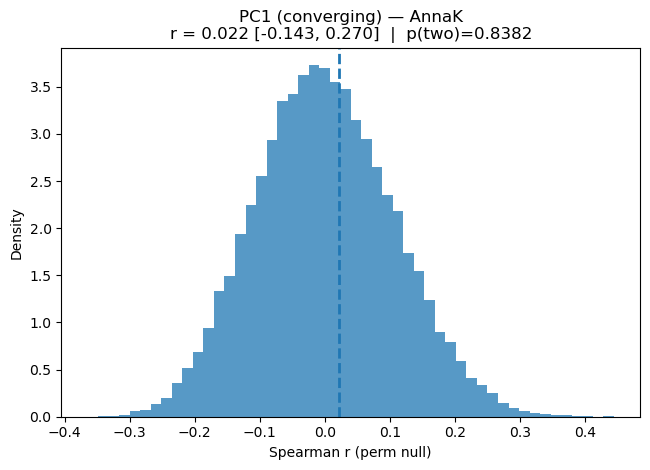

In [51]:
# === IS-RSA with ANNA KARENINA (position) model — PC1 ONLY ===
# Uses:
#   brain SIMILARITY  : averaged pairwise ISC matrix (CSV)
#   behavioral POSITION (AnnaK): pairwise min(score_i, score_j) or mean(score_i, score_j)
# Tests:
#   Spearman correlation between condensed upper triangles (brain vs AnnaK position)
#   Permutation null by shuffling PC1 scores across subjects
#   Bootstrap CI for r via subject-level resampling
# Plots:
#   Null distribution with observed r and p-value
# Saves:
#   PC1-ordered brain matrix (.csv + .npy)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr, beta

# ---------------- Utilities ----------------
def condensed_spearman_from_dfs(X_df, Y_df):
    """Spearman correlation between the condensed upper triangles of two square DFs."""
    xv = squareform(X_df.values, checks=False)
    yv = squareform(Y_df.values, checks=False)
    m = np.isfinite(xv) & np.isfinite(yv)
    return spearmanr(xv[m], yv[m]).correlation

def build_annak_position_rdm(scores, variant="mean"):
    """
    AnnaK behavioral POSITION matrix.
    variant = "mean" uses ((s_i + s_j)/2).
           = "min"  uses min(s_i, s_j).
    """
    s = np.asarray(scores, dtype=float)
    if variant == "min":
        P = np.minimum.outer(s, s)
    else:  # "mean"
        P = (s[:, None] + s[None, :]) / 2.0
    np.fill_diagonal(P, 0.0)
    return pd.DataFrame(P)

def fit_annak_model(brain_sim_df, scores, model_kind="converging", variant="mean"):
    """Spearman r between brain SIMILARITY and AnnaK POSITION matrix."""
    X = brain_sim_df.copy()
    np.fill_diagonal(X.values, 0.0)
    Annak = build_annak_position_rdm(scores, variant=variant)
    np.fill_diagonal(Annak.values, 0.0)
    return condensed_spearman_from_dfs(X, Annak)

def clopper_pearson_ci(k, n, alpha=0.05):
    """Exact binomial CI for p = k/n using Clopper–Pearson."""
    lo = 0.0 if k == 0 else beta.ppf(alpha/2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha/2, k + 1, n - k)
    return lo, hi

def permutation_null_shuffle_scores(brain_sim_df, scores, model_kind="converging",
                                    n_perm=50000, rng=None, alpha=0.05, variant="mean"):
    """
    Shuffle PC1 scores across subjects; return observed r, permutation null, and p-values.
    """
    if rng is None:
        rng = np.random.default_rng(123)
    scores = np.asarray(scores, dtype=float)

    r_true = fit_annak_model(brain_sim_df, scores, model_kind=model_kind, variant=variant)

    n = len(scores)
    r_perm = np.empty(n_perm, float)
    for k in range(n_perm):
        s_perm = scores[rng.permutation(n)]
        r_perm[k] = fit_annak_model(brain_sim_df, s_perm, model_kind=model_kind, variant=variant)

    # two-sided
    count_two = int(np.sum(np.abs(r_perm) >= abs(r_true)))
    p_two = (count_two + 1.0) / (n_perm + 1.0)
    lo_two, hi_two = clopper_pearson_ci(count_two, n_perm, alpha=alpha)

    # one-sided predicted direction
    if model_kind == "converging":
        count_one = int(np.sum(r_perm >= r_true))
    else:
        count_one = int(np.sum(r_perm <= r_true))
    p_one = (count_one + 1.0) / (n_perm + 1.0)
    lo_one, hi_one = clopper_pearson_ci(count_one, n_perm, alpha=alpha)

    return r_true, r_perm, (p_two, (lo_two, hi_two)), (p_one, (lo_one, hi_one))

def bootstrap_r_ci_annak(brain_sim_df, scores, model_kind="converging",
                         B=5000, alpha=0.05, rng=None, variant="mean"):
    """Bootstrap CI for Spearman r via subject-level resampling (with replacement)."""
    if rng is None:
        rng = np.random.default_rng(2025)
    n = brain_sim_df.shape[0]
    r_boot = np.empty(B, dtype=float)

    scores = np.asarray(scores, dtype=float)
    Bmat = brain_sim_df.values

    for b in range(B):
        idx = rng.integers(0, n, size=n)
        B_sub = pd.DataFrame(Bmat[np.ix_(idx, idx)])
        s_sub = scores[idx]
        r_boot[b] = fit_annak_model(B_sub, s_sub, model_kind=model_kind, variant=variant)

    r_hat = fit_annak_model(brain_sim_df, scores, model_kind=model_kind, variant=variant)
    lo, hi = np.nanpercentile(r_boot, [100*alpha/2, 100*(1 - alpha/2)])
    return r_hat, (lo, hi)

def plot_null_dist_and_print(label, model_kind, r_true, r_ci, r_perm, p_two_ci, p_one_ci):
    p_two, (p2_lo, p2_hi) = p_two_ci
    p_one, (p1_lo, p1_hi) = p_one_ci
    print(f"\n=== Permutation test: {label} — model: {model_kind} (AnnaK position–similarity) ===")
    print(f"Spearman r = {r_true:.4f}  |  95% bootstrap CI [{r_ci[0]:.4f}, {r_ci[1]:.4f}]")
    print(f"p(two-sided) = {p_two:.6f}  |  MC 95% CI [{p2_lo:.6f}, {p2_hi:.6f}]  (N_perm = {len(r_perm)})")
    print(f"p(one-sided, predicted) = {p_one:.6f}  |  MC 95% CI [{p1_lo:.6f}, {p1_hi:.6f}]")

    plt.figure(figsize=(6.6, 4.8))
    plt.hist(r_perm, bins=50, density=True, alpha=0.75)
    plt.axvline(r_true, linestyle="--", linewidth=2)
    plt.xlabel("Spearman r (perm null)")
    plt.ylabel("Density")
    plt.title(f"{label} ({model_kind}) — AnnaK\nr = {r_true:.3f} "
              f"[{r_ci[0]:.3f}, {r_ci[1]:.3f}]  |  p(two)={p_two:.4g}")
    plt.tight_layout()
    plt.show()

# ============================================================
# PC1 MODEL — Load averaged brain matrix, reorder by PC1, save, test AnnaK
# ============================================================

# ---- EDIT THESE PATHS IF NEEDED ----
brain_avg_pairwise_path = '/Users/pkell/roi_video_corrmats/brain_avg_pairwiseISC_zavg_pruned.csv'
out_dir = os.path.dirname(brain_avg_pairwise_path)

# Expects pca_df in memory with columns: Subject, PC1
# If not in memory, you can load it here (uncomment and edit path):
# pca_df = pd.read_csv('/Users/pkell/roi_video_corrmats/pca_df.csv')

# Load un-ordered averaged pairwise brain matrix (with labels)
brain_avg_pairwise = pd.read_csv(brain_avg_pairwise_path, index_col=0)
brain_avg_pairwise.index = brain_avg_pairwise.index.astype(str)
brain_avg_pairwise.columns = brain_avg_pairwise.columns.astype(str)

# Align PC1 to brain matrix subjects
_pc1 = pca_df.copy()
_pc1["Subject"] = _pc1["Subject"].astype(str)
_pc1["PC1"] = pd.to_numeric(_pc1["PC1"], errors="coerce")
_pc1 = _pc1.set_index("Subject")

_common = [s for s in brain_avg_pairwise.index if (s in _pc1.index and np.isfinite(_pc1.loc[s, "PC1"]))]

if len(_common) < 3:
    raise RuntimeError(f"Not enough overlapping subjects with PC1 to run AnnaK (n={len(_common)}).")

brain_avg_pairwise = brain_avg_pairwise.loc[_common, _common].astype(float)

pc1_scores = _pc1.loc[_common, "PC1"].astype(float)
pc1_order = pc1_scores.sort_values(ascending=False).index.tolist()

# Reorder matrix high->low PC1 (left-to-right, top-to-bottom)
m_pc1 = brain_avg_pairwise.loc[pc1_order, pc1_order].copy()

# Save ordered matrix (same style as your other ordered outputs)
pc1_npy_path = os.path.join(out_dir, "brain_avg_ordered_by_PC1.npy")
pc1_csv_path = os.path.join(out_dir, "brain_avg_ordered_by_PC1.csv")
np.save(pc1_npy_path, m_pc1.values)
m_pc1.to_csv(pc1_csv_path, index=True)
print(f"💾 Saved PC1-ordered brain matrix:\n  {pc1_npy_path}\n  {pc1_csv_path}")

# Build scores vector aligned to the PC1-ordered matrix
scores_vec = pc1_scores.loc[pc1_order].values.astype(float)

# ---------------- Run AnnaK model + permutation null + bootstrap CI ----------------
ANNAK_VARIANT = "min"         # "min" or "mean"
MODEL_KIND = "converging"     # predicted r > 0
N_PERM = 50000
BOOT_B = 5000
ALPHA = 0.05
rng = np.random.default_rng(2025)

# Bootstrap CI
r_hat, (r_lo, r_hi) = bootstrap_r_ci_annak(
    m_pc1, scores_vec, model_kind=MODEL_KIND,
    B=BOOT_B, alpha=ALPHA, rng=rng, variant=ANNAK_VARIANT
)

# Permutation test (scores shuffled)
r_true, r_perm, p2_ci, p1_ci = permutation_null_shuffle_scores(
    m_pc1, scores_vec, model_kind=MODEL_KIND,
    n_perm=N_PERM, rng=rng, alpha=ALPHA, variant=ANNAK_VARIANT
)

# Plot + print
plot_null_dist_and_print("PC1", MODEL_KIND, r_true, (r_lo, r_hi), r_perm, p2_ci, p1_ci)


=== Permutation test: PC1 — model: converging (distance–distance) ===
Spearman r = 0.0103  |  95% bootstrap CI [-0.0434, 0.2565]
p(two-sided) = 0.893422  |  MC 95% CI [0.890682, 0.896112]  (N_perm = 50000)
p(one-sided, predicted) = 0.433651  |  MC 95% CI [0.429290, 0.437998]


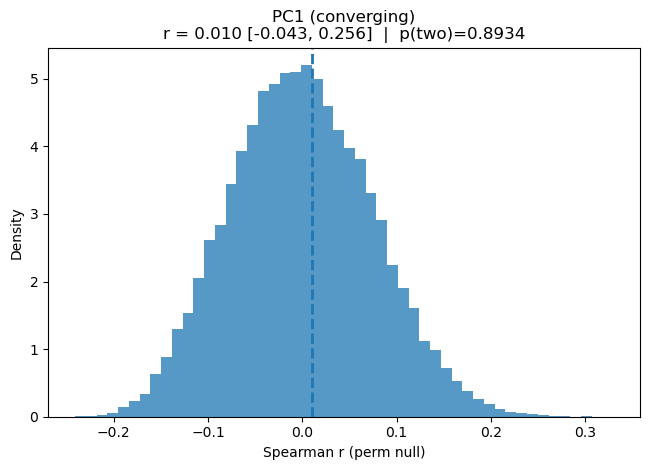

In [43]:
# === IS-RSA with SCORE-DISTANCE models (Nearest Neighbor / distance–distance) — PC1 ONLY ===
# Runs:
#   brain DISTANCE (monotone transform of averaged ISC similarity matrix)
# vs
#   behavioral SCORE DISTANCE (pairwise |PC1_i - PC1_j|)
#
# Uses:
#   - PC1-ordered brain matrix saved previously (brain_avg_ordered_by_PC1.csv)
#   - PC1 scores aligned to that ordering (pulled directly from pca_df)
#
# Outputs:
#   - Observed Spearman r (distance–distance)
#   - Permutation null by shuffling PC1 scores
#   - Bootstrap CI for r
#   - Histogram of null with observed r and p-value

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr, beta

# ---------------- Utilities ----------------
def condensed_spearman_from_dfs(X_df, Y_df):
    """Spearman correlation between the condensed upper triangles of two square DFs."""
    xv = squareform(X_df.values, checks=False)
    yv = squareform(Y_df.values, checks=False)
    m = np.isfinite(xv) & np.isfinite(yv)
    return spearmanr(xv[m], yv[m]).correlation

def build_score_distance_rdm(scores, metric="euclidean"):
    """Make a score-distance (dissimilarity) RDM from a 1D array-like of scores (in matrix order)."""
    s = np.asarray(scores, dtype=float).reshape(-1, 1)
    C = squareform(pdist(s, metric=metric))
    np.fill_diagonal(C, 0.0)
    return pd.DataFrame(C)

def sim_to_dist(brain_sim_df):
    """
    Convert brain SIMILARITY matrix to a DISTANCE matrix with a simple monotone transform.
    Since we use Spearman (rank-based), any monotone decreasing transform is valid.
    Here: dist = (max_offdiag) - sim, with zero diagonal.
    """
    B = brain_sim_df.values.copy()
    mask_off = ~np.eye(B.shape[0], dtype=bool)
    max_off = np.nanmax(B[mask_off])
    D = max_off - B
    np.fill_diagonal(D, 0.0)
    return pd.DataFrame(
        D,
        index=brain_sim_df.index if hasattr(brain_sim_df, "index") else None,
        columns=brain_sim_df.columns if hasattr(brain_sim_df, "columns") else None
    )

def fit_score_distance_model(brain_sim_df, scores, model_kind):
    """
    Returns Spearman r between brain DISTANCE and score DISTANCE.
    'model_kind' is only used later for choosing the one-tailed direction.
    """
    BrainDist = sim_to_dist(brain_sim_df)         # larger = more different brains
    ScoreDist = build_score_distance_rdm(scores)  # larger = more different behavior
    r = condensed_spearman_from_dfs(BrainDist, ScoreDist)
    return r

def clopper_pearson_ci(k, n, alpha=0.05):
    """Exact binomial CI for p = k/n using Clopper–Pearson."""
    lo = 0.0 if k == 0 else beta.ppf(alpha/2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha/2, k + 1, n - k)
    return lo, hi

def permutation_null_shuffle_scores(brain_sim_df, scores, model_kind, n_perm=50000, rng=None, alpha=0.05):
    """
    Shuffle scores; report:
      - r_true
      - r_perm array
      - two-sided p with Clopper–Pearson CI
      - one-sided (predicted-tail) p with Clopper–Pearson CI

    Predicted tail for distance–distance:
      - converging: expect r > 0  -> one-sided uses P(r_perm >= r_true)
      - diverging:  expect r < 0  -> one-sided uses P(r_perm <= r_true)
    """
    if rng is None:
        rng = np.random.default_rng(123)
    scores = np.asarray(scores, dtype=float)

    # observed
    r_true = fit_score_distance_model(brain_sim_df, scores, model_kind)

    # null
    n = len(scores)
    r_perm = np.empty(n_perm, float)
    for k in range(n_perm):
        s_perm = scores[rng.permutation(n)]
        r_perm[k] = fit_score_distance_model(brain_sim_df, s_perm, model_kind)

    # two-sided exceedances
    count_two = int(np.sum(np.abs(r_perm) >= abs(r_true)))
    p_two = (count_two + 1.0) / (n_perm + 1.0)
    lo_two, hi_two = clopper_pearson_ci(count_two, n_perm, alpha=alpha)

    # one-sided exceedances (predicted direction)
    if model_kind == "converging":
        count_one = int(np.sum(r_perm >= r_true))
    else:
        count_one = int(np.sum(r_perm <= r_true))
    p_one = (count_one + 1.0) / (n_perm + 1.0)
    lo_one, hi_one = clopper_pearson_ci(count_one, n_perm, alpha=alpha)

    return r_true, r_perm, (p_two, (lo_two, hi_two)), (p_one, (lo_one, hi_one))

def bootstrap_r_ci(brain_sim_df, scores, model_kind, B=5000, alpha=0.05, rng=None):
    """
    Bootstrap CI for Spearman r via subject-level resampling (with replacement).
    Each bootstrap draw resamples subject indices, subsets both matrices and scores,
    then recomputes distance–distance Spearman r on the bootstrap sample.
    Returns (r_hat, (lo, hi)).
    """
    if rng is None:
        rng = np.random.default_rng(2025)
    n = brain_sim_df.shape[0]
    r_boot = np.empty(B, dtype=float)

    scores = np.asarray(scores, dtype=float)
    Bmat = brain_sim_df.values

    for b in range(B):
        idx = rng.integers(0, n, size=n)
        B_sub = pd.DataFrame(Bmat[np.ix_(idx, idx)])
        s_sub = scores[idx]
        r_boot[b] = fit_score_distance_model(B_sub, s_sub, model_kind)

    r_hat = fit_score_distance_model(brain_sim_df, scores, model_kind)
    lo, hi = np.nanpercentile(r_boot, [100*alpha/2, 100*(1 - alpha/2)])
    return r_hat, (lo, hi)

def plot_null_dist_and_print(label, model_kind, r_true, r_ci, r_perm, p_two_ci, p_one_ci):
    p_two, (p2_lo, p2_hi) = p_two_ci
    p_one, (p1_lo, p1_hi) = p_one_ci
    print(f"\n=== Permutation test: {label} — model: {model_kind} (distance–distance) ===")
    print(f"Spearman r = {r_true:.4f}  |  95% bootstrap CI [{r_ci[0]:.4f}, {r_ci[1]:.4f}]")
    print(f"p(two-sided) = {p_two:.6f}  |  MC 95% CI [{p2_lo:.6f}, {p2_hi:.6f}]  (N_perm = {len(r_perm)})")
    print(f"p(one-sided, predicted) = {p_one:.6f}  |  MC 95% CI [{p1_lo:.6f}, {p1_hi:.6f}]")

    plt.figure(figsize=(6.6, 4.8))
    plt.hist(r_perm, bins=50, density=True, alpha=0.75)
    plt.axvline(r_true, linestyle="--", linewidth=2)
    plt.xlabel("Spearman r (perm null)")
    plt.ylabel("Density")
    plt.title(f"{label} ({model_kind})\nr = {r_true:.3f} "
              f"[{r_ci[0]:.3f}, {r_ci[1]:.3f}]  |  p(two)={p_two:.4g}")
    plt.tight_layout()
    plt.show()

# ============================================================
# PC1 ONLY — Load PC1-ordered brain matrix + aligned PC1 scores
# ============================================================

# ---- EDIT THIS PATH IF NEEDED ----
pc1_matrix_path = '/Users/pkell/roi_video_corrmats/brain_avg_ordered_by_PC1.csv'

# Load PC1-ordered matrix (saved with index column)
m_pc1 = pd.read_csv(pc1_matrix_path, index_col=0)
m_pc1.index = m_pc1.index.astype(str)
m_pc1.columns = m_pc1.columns.astype(str)
m_pc1 = m_pc1.astype(float)

# Build PC1 score vector aligned to matrix order from pca_df
# Expects pca_df in memory with columns: Subject, PC1
_pc1 = pca_df.copy()
_pc1["Subject"] = _pc1["Subject"].astype(str)
_pc1["PC1"] = pd.to_numeric(_pc1["PC1"], errors="coerce")
_pc1 = _pc1.set_index("Subject")

order = m_pc1.index.tolist()
if any(s not in _pc1.index for s in order):
    missing = [s for s in order if s not in _pc1.index]
    raise ValueError(f"Subjects in PC1 matrix missing from pca_df: {missing[:10]} (and {max(0, len(missing)-10)} more)")

scores_vec = _pc1.loc[order, "PC1"].values.astype(float)
if not np.isfinite(scores_vec).all():
    bad = np.where(~np.isfinite(scores_vec))[0]
    raise ValueError(f"Non-finite PC1 scores for {len(bad)} subjects in matrix order.")

# ============================================================
# Run distance–distance model + permutation null + bootstrap CI
# ============================================================
LABEL = "PC1"
MODEL_KIND = "converging"   # predicted r > 0 (farther in PC1 -> farther in brain distance)
N_PERM = 50000
BOOT_B = 5000
ALPHA = 0.05
rng = np.random.default_rng(2025)

# Bootstrap CI
r_hat, (r_lo, r_hi) = bootstrap_r_ci(m_pc1, scores_vec, MODEL_KIND, B=BOOT_B, alpha=ALPHA, rng=rng)

# Permutation test
r_true, r_perm, p2_ci, p1_ci = permutation_null_shuffle_scores(
    m_pc1, scores_vec, MODEL_KIND, n_perm=N_PERM, rng=rng, alpha=ALPHA
)

# Plot + print
plot_null_dist_and_print(LABEL, MODEL_KIND, r_true, (r_lo, r_hi), r_perm, p2_ci, p1_ci)

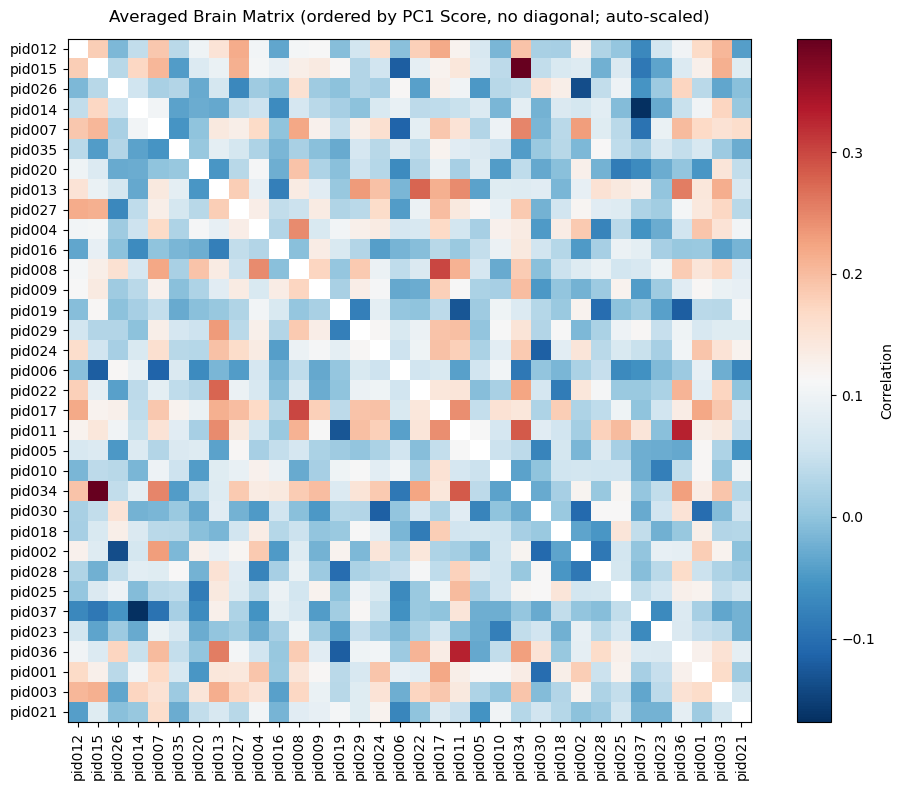

NameError: name 'CSV_EmQ' is not defined

In [53]:
# === Plot correlation matrices from CSVs (auto-scaled per matrix, diagonal hidden) ===
# Fill these paths before running:
CSV_pc1  = r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_PC1.csv"  

SAVE_pc1   = ""  # e.g., r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_AQ_Score_noDiag_autoscale.png"


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def _read_square_csv(path: str) -> pd.DataFrame:
    """
    Reads a square correlation matrix CSV. Handles cases where the first column is row labels.
    Returns a DataFrame with matching index/columns (labels preserved).
    """
    df = pd.read_csv(path, index_col=0)
    # If columns are numeric strings but index are labels, try to realign names
    if df.shape[0] == df.shape[1]:
        try:
            df.columns = df.columns.astype(str)
            df.index   = df.index.astype(str)
        except Exception:
            pass
    else:
        raise ValueError(f"CSV at {path} is not square (shape={df.shape}).")
    return df

def plot_corr_from_csv(csv_path: str,
                       title: str,
                       save_path: str = "",
                       vmin: float = None,
                       vmax: float = None,
                       drop_diagonal: bool = True):
    """
    Plots a correlation matrix from CSV with a red–blue diverging colormap.
    
    Auto-scales the color range to [min, max] of the matrix (after optional diagonal drop)
    if vmin/vmax are not supplied.

    If drop_diagonal=True, the diagonal is set to NaN (rendered as white).
    """
    df = _read_square_csv(csv_path)
    mat = df.to_numpy(dtype=float)

    # Optionally drop (mask) diagonal
    if drop_diagonal:
        mat = mat.copy()
        np.fill_diagonal(mat, np.nan)

    # Compute per-matrix vmin/vmax if not provided (exclude NaNs)
    finite_vals = mat[np.isfinite(mat)]
    if finite_vals.size == 0:
        raise ValueError(f"No finite values in matrix from {csv_path} after masking diagonal.")
    if vmin is None:
        vmin = float(finite_vals.min())
    if vmax is None:
        vmax = float(finite_vals.max())
    if vmin == vmax:
        # Avoid zero-range colorbar; expand slightly
        eps = max(1e-6, abs(vmin) * 1e-3)
        vmin -= eps
        vmax += eps

    # Mask NaNs so they render as 'bad' color (white)
    masked = np.ma.masked_invalid(mat)

    # Colormap: red (positive) ↔ blue (negative)
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad(color="white")

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax,
                   origin="upper", aspect="equal")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Correlation", rotation=90)

    # Ticks/labels
    labels = list(df.columns.astype(str))
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticklabels(list(df.index.astype(str)))

    ax.set_title(title, pad=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"✓ Saved: {save_path}")
    plt.show()

# ---- Run for all four matrices ----
if CSV_pc1:
    plot_corr_from_csv(
        CSV_pc1,
        "Averaged Brain Matrix (ordered by PC1 Score, no diagonal; auto-scaled)",
        SAVE_pc1
    )

if CSV_EmQ:
    plot_corr_from_csv(
        CSV_EmQ,
        "Averaged Brain Matrix (ordered by EmQ_Score, no diagonal; auto-scaled)",
        SAVE_EmQ
    )

if CSV_EQ:
    plot_corr_from_csv(
        CSV_EQ,
        "Averaged Brain Matrix (ordered by EQ_Score, no diagonal; auto-scaled)",
        SAVE_EQ
    )

if CSV_PERF:
    plot_corr_from_csv(
        CSV_PERF,
        "Averaged Brain Matrix (ordered by Performance, no diagonal; auto-scaled)",
        SAVE_PERF
    )



=== Diagnostic 1: PC1 vs mean similarity-to-others (centrality) ===
n = 34  |  Pearson r = 0.087, p = 0.6244


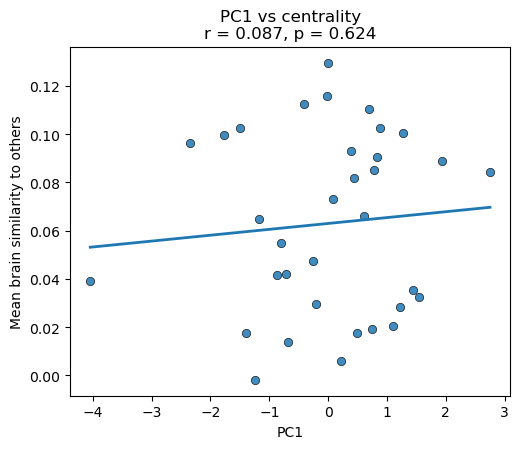


=== Diagnostic 2: High/Low PC1 split (median) ===
Median PC1 = 0.152 | High n=17 | Low n=17
Mean similarity HH (high-high): 0.0609
Mean similarity HL (high-low) : 0.0640
Mean similarity LL (low-low)  : 0.0629
HH - HL = -0.0031
HH - LL = -0.0020

Permutation tests (labels shuffled; group sizes fixed):
p(HH-HL) = 0.5556  (obs=-0.0031)
p(HH-LL) = 0.5329  (obs=-0.0020)


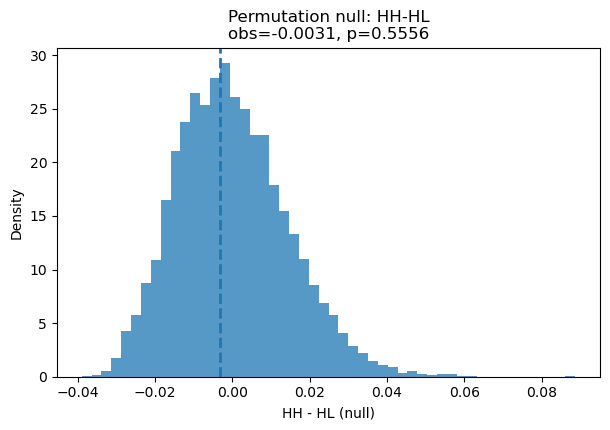

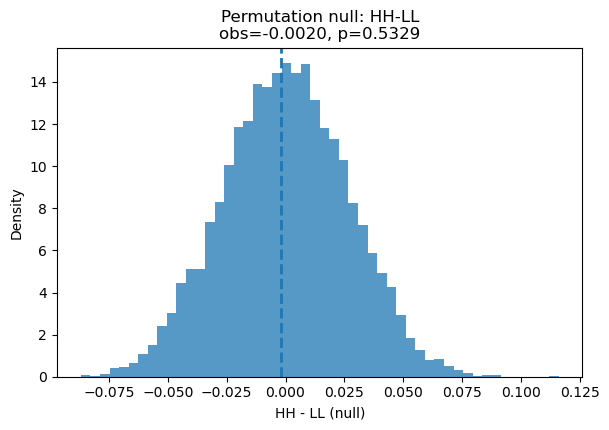

In [55]:
# ============================================================
# DROP-IN DIAGNOSTICS: Why PC1 IS-RSA might be ~0
# Uses:
#   - brain_avg_pairwiseISC_zavg_pruned.csv  (SxS similarity, labeled)
#   - pca_df with columns: Subject, PC1      (subject-level score)
#
# Outputs:
#   (1) PC1 vs "centrality" = mean similarity to others (row-mean off-diagonal)
#   (2) High/Low (median split on PC1): compare HH vs HL vs LL mean similarities
#       + simple permutation test for (HH - HL) and (HH - LL)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ---- EDIT PATH IF NEEDED ----
brain_path = os.path.join(os.getcwd(), "roi_video_corrmats", "brain_avg_pairwiseISC_zavg_pruned.csv")
# brain_path = r"C:\Users\pkell\roi_video_corrmats\brain_avg_pairwiseISC_zavg_pruned.csv"  # alt

# ----------------------------
# Load brain matrix + align PC1
# ----------------------------
B = pd.read_csv(brain_path, index_col=0)
B.index = B.index.astype(str)
B.columns = B.columns.astype(str)
B = B.astype(float)

pc = pca_df[["Subject", "PC1"]].copy()
pc["Subject"] = pc["Subject"].astype(str)
pc["PC1"] = pd.to_numeric(pc["PC1"], errors="coerce")
pc = pc.dropna(subset=["PC1"]).set_index("Subject")

common = [s for s in B.index if s in pc.index]
if len(common) < 6:
    raise RuntimeError(f"Not enough overlapping subjects (n={len(common)}). Check IDs and path.")

B = B.loc[common, common].copy()
pc1 = pc.loc[common, "PC1"].astype(float)

# ----------------------------
# (1) CENTRALITY: row-mean similarity (excluding diagonal)
# ----------------------------
B_vals = B.values.copy()
np.fill_diagonal(B_vals, np.nan)
centrality = np.nanmean(B_vals, axis=1)  # mean similarity to others per subject

x = pc1.values
y = centrality
m = np.isfinite(x) & np.isfinite(y)
r_cent, p_cent = pearsonr(x[m], y[m])

print("\n=== Diagnostic 1: PC1 vs mean similarity-to-others (centrality) ===")
print(f"n = {m.sum()}  |  Pearson r = {r_cent:.3f}, p = {p_cent:.4g}")

plt.figure(figsize=(5.3, 4.6))
plt.scatter(x[m], y[m], alpha=0.85, edgecolor="k", linewidth=0.5)
b1, b0 = np.polyfit(x[m], y[m], 1)
xs = np.linspace(np.min(x[m]), np.max(x[m]), 200)
plt.plot(xs, b1*xs + b0, linewidth=2)
plt.xlabel("PC1")
plt.ylabel("Mean brain similarity to others")
plt.title(f"PC1 vs centrality\nr = {r_cent:.3f}, p = {p_cent:.3g}")
plt.tight_layout()
plt.show()

# ----------------------------
# (2) HIGH/LOW split: HH vs HL vs LL pair means
# ----------------------------
med = float(np.nanmedian(pc1.values))
high = pc1.index[pc1.values >= med].tolist()
low  = pc1.index[pc1.values <  med].tolist()

print("\n=== Diagnostic 2: High/Low PC1 split (median) ===")
print(f"Median PC1 = {med:.3f} | High n={len(high)} | Low n={len(low)}")

# helper to get mean similarity of all pairs between two sets
def mean_pair_block(B_df, A, C):
    sub = B_df.loc[A, C].values.astype(float)
    if A is C or set(A) == set(C):
        # within-block: exclude diagonal by taking upper triangle
        if sub.shape[0] < 2:
            return np.nan
        iu = np.triu_indices(sub.shape[0], k=1)
        vals = sub[iu]
    else:
        vals = sub.ravel()
    vals = vals[np.isfinite(vals)]
    return float(np.mean(vals)) if vals.size else np.nan

HH = mean_pair_block(B, high, high)
LL = mean_pair_block(B, low,  low)
HL = mean_pair_block(B, high, low)

print(f"Mean similarity HH (high-high): {HH:.4f}")
print(f"Mean similarity HL (high-low) : {HL:.4f}")
print(f"Mean similarity LL (low-low)  : {LL:.4f}")
print(f"HH - HL = {HH - HL:.4f}")
print(f"HH - LL = {HH - LL:.4f}")

# ----------------------------
# Permutation test: shuffle PC1 labels (equivalently shuffle who is 'high')
# keeping group sizes fixed; test HH-HL and HH-LL
# ----------------------------
RNG = np.random.default_rng(2025)
N_PERM = 10000

subjects = pc1.index.tolist()
n_high = len(high)

def compute_diffs(high_set):
    low_set = [s for s in subjects if s not in high_set]
    HHp = mean_pair_block(B, high_set, high_set)
    HLp = mean_pair_block(B, high_set, low_set)
    LLp = mean_pair_block(B, low_set,  low_set)
    return (HHp - HLp), (HHp - LLp)

obs_d1, obs_d2 = compute_diffs(high)

null_d1 = np.empty(N_PERM, float)
null_d2 = np.empty(N_PERM, float)

for k in range(N_PERM):
    perm_high = RNG.choice(subjects, size=n_high, replace=False).tolist()
    d1, d2 = compute_diffs(perm_high)
    null_d1[k] = d1
    null_d2[k] = d2

# one-sided p: how often null >= observed (expect HH-HL > 0, HH-LL > 0)
p_d1 = (1 + np.sum(null_d1 >= obs_d1)) / (N_PERM + 1)
p_d2 = (1 + np.sum(null_d2 >= obs_d2)) / (N_PERM + 1)

print("\nPermutation tests (labels shuffled; group sizes fixed):")
print(f"p(HH-HL) = {p_d1:.4g}  (obs={obs_d1:.4f})")
print(f"p(HH-LL) = {p_d2:.4g}  (obs={obs_d2:.4f})")

# plots
plt.figure(figsize=(6.2, 4.4))
plt.hist(null_d1, bins=50, density=True, alpha=0.75)
plt.axvline(obs_d1, linestyle="--", linewidth=2)
plt.xlabel("HH - HL (null)")
plt.ylabel("Density")
plt.title(f"Permutation null: HH-HL\nobs={obs_d1:.4f}, p={p_d1:.4g}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.2, 4.4))
plt.hist(null_d2, bins=50, density=True, alpha=0.75)
plt.axvline(obs_d2, linestyle="--", linewidth=2)
plt.xlabel("HH - LL (null)")
plt.ylabel("Density")
plt.title(f"Permutation null: HH-LL\nobs={obs_d2:.4f}, p={p_d2:.4g}")
plt.tight_layout()
plt.show()

In [ ]:
# ============================
# Median-split comparison on ordered brain matrices
# ============================
# NOTE: Your matrices are ordered from HIGHEST (left/top) to LOWEST (right/bottom).
#       Therefore, the FIRST half of rows/cols is the HIGH group, and the SECOND half is the LOW group.
#       If n is odd, the HIGH group (first half) gets the extra subject.
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# ------------------------------------------------------------
# 🔧 1) Provide the FULL PATHS to your ordered matrices (CSV)
#     These should be the rank-ordered CSVs you saved earlier.
# ------------------------------------------------------------
MATRIX_PATHS = {
    # e.g., r"C:\...\roi_video_corrmats\brain_avg_ordered_by_Performance.csv"
    "Performance": r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_Performance.csv",
    "AQ_Score":    r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_AQ_Score.csv",
    "EQ_Score":    r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_EQ_Score.csv",
    "EmQ_Score":   r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_EmQ_Score.csv",
    "Raw_Bais":   r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_RawBias.csv",
    "BaisZ":   r"C:\Users\pkell\roi_video_corrmats\brain_avg_ordered_by_BiasZ.csv",
}

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def load_square_csv(path: str) -> pd.DataFrame:
    """
    Load a square correlation matrix CSV that has subject IDs as both
    index and columns. Returns a DataFrame with aligned labels.
    """
    df = pd.read_csv(path, index_col=0)
    common = [s for s in df.index if s in df.columns]
    df = df.loc[common, common]
    return df

def split_high_low_indices(n: int):
    """
    Split row/column indices into HIGH (first half, higher scores by order)
    and LOW (second half, lower scores).
    If n is odd, HIGH gets the extra subject.
    """
    half_up = int(np.ceil(n / 2.0))
    high_idx = np.arange(0, half_up)   # first half (higher scores)
    low_idx  = np.arange(half_up, n)   # second half (lower scores)
    return high_idx, low_idx

def summarize_subject_means(M_group: np.ndarray):
    """
    For a group submatrix M_group (square), compute each subject's mean correlation
    to all *other* subjects in the same group (exclude diagonal), then return the
    vector of subject means (NaNs removed).
    """
    M = np.asarray(M_group, dtype=float)
    n = M.shape[0]
    if n < 2:
        return np.array([], dtype=float)
    mask = ~np.eye(n, dtype=bool)
    subj_means = []
    for i in range(n):
        row_vals = M[i, mask[i]]
        row_vals = row_vals[np.isfinite(row_vals)]
        if len(row_vals) > 0:
            subj_means.append(np.mean(row_vals))
    return np.asarray(subj_means, dtype=float)

def cohens_d_from_vectors(a: np.ndarray, b: np.ndarray) -> float:
    """
    Cohen's d for two independent samples with unequal sizes (pooled SD).
    Returns np.nan if not computable.
    """
    a = np.asarray(a, dtype=float); a = a[np.isfinite(a)]
    b = np.asarray(b, dtype=float); b = b[np.isfinite(b)]
    na, nb = len(a), len(b)
    if na < 2 or nb < 2:
        return np.nan
    va = np.var(a, ddof=1); vb = np.var(b, ddof=1)
    sp = np.sqrt(((na-1)*va + (nb-1)*vb) / (na + nb - 2))
    if sp == 0 or not np.isfinite(sp):
        return np.nan
    return (np.mean(a) - np.mean(b)) / sp

def compare_high_vs_low_subject_means(M_df: pd.DataFrame):
    """
    Split subjects by order into HIGH (first half) and LOW (second half).
    Compute per-subject mean r within each group (to others in the same group).
    Perform Welch and equal-var t-tests on these subject-level means and compute Cohen's d.
    Returns a result dict and the subject-mean vectors (for plotting).
    """
    M = M_df.values.astype(float)
    n = M.shape[0]
    if n < 4:
        raise ValueError("Matrix too small for a split (need at least 4).")

    high_idx, low_idx = split_high_low_indices(n)
    M_high = M[np.ix_(high_idx, high_idx)]
    M_low  = M[np.ix_(low_idx, low_idx)]

    # Subject-level mean r within each group
    high_subj_means = summarize_subject_means(M_high)
    low_subj_means  = summarize_subject_means(M_low)

    # Summary stats (subject-level)
    high_mean = float(np.mean(high_subj_means)) if len(high_subj_means) else np.nan
    high_sd   = float(np.std(high_subj_means, ddof=1)) if len(high_subj_means) > 1 else np.nan
    low_mean  = float(np.mean(low_subj_means)) if len(low_subj_means) else np.nan
    low_sd    = float(np.std(low_subj_means, ddof=1)) if len(low_subj_means) > 1 else np.nan

    # T-tests on subject-level means
    if len(high_subj_means) >= 2 and len(low_subj_means) >= 2:
        t_welch, p_welch = ttest_ind(high_subj_means, low_subj_means, equal_var=False, nan_policy='omit')
        t_eq, p_eq       = ttest_ind(high_subj_means, low_subj_means, equal_var=True,  nan_policy='omit')
    else:
        t_welch = p_welch = np.nan
        t_eq = p_eq = np.nan

    d = cohens_d_from_vectors(high_subj_means, low_subj_means)

    return {
        "n_subjects": n,
        "n_high_subj": int(len(high_idx)),
        "n_low_subj": int(len(low_idx)),
        "high_mean": high_mean,
        "high_sd":   high_sd,
        "low_mean":  low_mean,
        "low_sd":    low_sd,
        "t_welch": float(t_welch) if np.isfinite(t_welch) else np.nan,
        "p_welch": float(p_welch) if np.isfinite(p_welch) else np.nan,
        "t_equal_var": float(t_eq) if np.isfinite(t_eq) else np.nan,
        "p_equal_var": float(p_eq) if np.isfinite(p_eq) else np.nan,
        "cohens_d": float(d) if np.isfinite(d) else np.nan,
    }, (high_subj_means, low_subj_means)

def make_boxplot_for_label(label: str, high_vals: np.ndarray, low_vals: np.ndarray,
                           t_val: float, p_val: float):
    """
    Show a box plot comparing HIGH vs LOW *subject-level mean r* for the given label.
    Annotates with equal-variance t and p.
    """
    data = [high_vals, low_vals]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.boxplot(data, labels=["HIGH (first half)", "LOW (second half)"], showmeans=True)
    ax.set_ylabel("Per-subject mean ISC")
    ax.set_title(f"{label}: HIGH vs LOW t={t_val:.3f}, p={p_val:.4f}")
    # Optional: jittered scatter points for visibility
    rng = np.random.default_rng(42)
    for i, vec in enumerate(data, start=1):
        x = np.full_like(vec, i, dtype=float) + (rng.random(len(vec)) - 0.5) * 0.06
        ax.plot(x, vec, 'o', alpha=0.45, markersize=4)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# Main loop across matrices (no files saved)
# ------------------------------------------------------------
rows = []
for label, path in MATRIX_PATHS.items():
    print(f"\n=== {label} ===")
    try:
        M_df = load_square_csv(path)
    except FileNotFoundError:
        print(f"⚠️ File not found: {path}")
        continue
    except Exception as e:
        print(f"⚠️ Could not load {path}: {e}")
        continue

    if M_df.shape[0] != M_df.shape[1]:
        print(f"⚠️ Matrix is not square: {M_df.shape}")
        continue
    if M_df.isna().all().all():
        print("⚠️ Matrix is all NaNs; skipping.")
        continue

    if not np.allclose(M_df.values, M_df.values.T, equal_nan=True):
        print("ℹ️ Warning: matrix not perfectly symmetric. Proceeding with given values.")

    res, (high_means, low_means) = compare_high_vs_low_subject_means(M_df)
    res["label"] = label
    rows.append(res)

    # Console summary (explicit about ordering → HIGH is first half)
    print(f"Subjects: {res['n_subjects']} (HIGH={res['n_high_subj']}, LOW={res['n_low_subj']})")
    print(f"HIGH mean±sd (per-subject) = {res['high_mean']:.4f} ± {res['high_sd'] if np.isfinite(res['high_sd']) else np.nan}")
    print(f"LOW  mean±sd (per-subject) = {res['low_mean']:.4f} ± {res['low_sd'] if np.isfinite(res['low_sd']) else np.nan}")
    print(f"Welch t (subject means) = {res['t_welch']:.3f}, p = {res['p_welch']:.4f}")
    print(f"Equal-var t (subject means) = {res['t_equal_var']:.3f}, p = {res['p_equal_var']:.4f}")
    print(f"Cohen's d (subject means) = {res['cohens_d']:.3f}")

    # 🔳 Box plot for the regular t-test comparison using SUBJECT MEANS
    make_boxplot_for_label(label, high_means, low_means,
                           t_val=res["t_equal_var"], p_val=res["p_equal_var"])

# ------------------------------------------------------------
# Results DataFrame (in-memory) and printout
# ------------------------------------------------------------
if rows:
    results_df = pd.DataFrame(rows)[[
        "label","n_subjects","n_high_subj","n_low_subj",
        "high_mean","high_sd","low_mean","low_sd",
        "t_welch","p_welch","t_equal_var","p_equal_var","cohens_d"
    ]]
    print("\n=== Summary table (HIGH = first half; LOW = second half) — subject-level means ===")
    print(results_df.to_string(index=False))
else:
    results_df = pd.DataFrame(columns=[
        "label","n_subjects","n_high_subj","n_low_subj",
        "high_mean","high_sd","low_mean","low_sd",
        "t_welch","p_welch","t_equal_var","p_equal_var","cohens_d"
    ])
    print("\nNo results — check your file paths in MATRIX_PATHS.")

# `results_df` now holds your complete summary as a DataFrame (subject-level means).


In [ ]:
# ============================================================
# Group-level Stimulus-Type ISC (Mean ± 95% CI) barplot
#   - Averages peak-window ISC within trigger groups
#   - Groups: Social, Positive, Negative, White, Black
# ============================================================

from scipy.stats import sem

# --- Define trigger groupings (if not already defined) ---
if "trigger_groups" not in globals():
    trigger_groups = {
        "Social":   [1, 3, 5, 7, 21, 23, 25, 27],
        "Positive": [9, 11, 13, 29, 31, 33],
        "Negative": [15, 17, 19, 35, 37, 39],
        "White":    [49, 51, 53, 55],
        "Black":    [41, 43, 45, 47],
    }

# --- Check that per-video ISC exists ---
if "video_isc_df_peaks" not in globals() or video_isc_df_peaks.empty:
    print("⚠️ video_isc_df_peaks not found or empty; cannot make stimulus-type plot.")
else:
    df = video_isc_df_peaks.copy()

    # Ensure we have numeric trigger numbers
    df["Trigger_int"] = pd.to_numeric(df["Trigger"], errors="coerce")

    # If Trigger is not numeric (e.g., video names), optionally map via video_mapping.csv
    if df["Trigger_int"].isna().all():
        mapping_csv = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Emotion Perception Data\video_mapping.csv"
        if os.path.exists(mapping_csv):
            map_df = pd.read_csv(mapping_csv)
            lower_cols = {c.lower(): c for c in map_df.columns}
            if "video" in lower_cols and "trigger_number" in lower_cols:
                col_video = lower_cols["video"]
                col_trig = lower_cols["trigger_number"]
                map_df["Trigger_int"] = pd.to_numeric(map_df[col_trig], errors="coerce")
                map_df = map_df[[col_video, "Trigger_int"]].dropna(subset=["Trigger_int"])
                df = df.merge(map_df, left_on="Trigger", right_on=col_video, how="left")
            else:
                print("⚠️ video_mapping.csv missing 'video' or 'trigger_number' columns.")
        else:
            print(f"⚠️ Mapping CSV not found at {mapping_csv}.")
    # After possible merge, keep a clean Trigger_int
    if "Trigger_int_y" in df.columns:
        df["Trigger_int"] = df["Trigger_int_y"]
    df = df.dropna(subset=["Trigger_int"]).copy()
    df["Trigger_int"] = df["Trigger_int"].astype(int)

    if df.empty:
        print("⚠️ No valid triggers after mapping; aborting stimulus-type plot.")
    else:
        # Map each trigger to a stimulus-type group
        def _assign_group(tr):
            for g, tr_list in trigger_groups.items():
                if tr in tr_list:
                    return g
            return None

        df["Group"] = df["Trigger_int"].apply(_assign_group)
        df = df.dropna(subset=["Group"]).copy()

        if df.empty:
            print("⚠️ No triggers matched trigger_groups; aborting stimulus-type plot.")
        else:
            # --- Subject-level mean ISC per stimulus-type group ---
            subj_group = (
                df.groupby(["Subject", "Group"])["ISC"]
                  .mean()
                  .reset_index()
            )

            groups = [g for g in ["Social", "Positive", "Negative", "White", "Black"]
                      if g in subj_group["Group"].unique()]

            means, cis, ns = [], [], []
            for g in groups:
                vals = subj_group.loc[subj_group["Group"] == g, "ISC"].dropna().values
                n = len(vals)
                ns.append(n)
                if n == 0:
                    means.append(np.nan)
                    cis.append(np.nan)
                else:
                    m = float(np.mean(vals))
                    ci = 1.96 * sem(vals) if n > 1 else 0.0
                    means.append(m)
                    cis.append(ci)

            means = np.array(means, float)
            cis = np.array(cis, float)

            # --- Null distribution band (edit these if you have different null stats) ---
            perm_null_mean = 0.0
            perm_null_ci_low = -0.024
            perm_null_ci_high = 0.024

            # Significance: CI entirely above null 95% band
            sig_mask = (means - cis) > perm_null_ci_high

            # --- Plot ---
            fig, ax = plt.subplots(figsize=(9, 4.5))

            # Null band and mean line
            ax.axhspan(perm_null_ci_low, perm_null_ci_high,
                       color="red", alpha=0.12,
                       label=f"Null 95% [{perm_null_ci_low:.3f}, {perm_null_ci_high:.3f}]")
            ax.axhline(perm_null_mean, color="red", linestyle="--",
                       label=f"Permutation null (mean={perm_null_mean:.3f})")

            x = np.arange(len(groups))
            bar_container = ax.bar(
                x, means, yerr=cis, capsize=5, edgecolor="black", alpha=0.9
            )

            # Add value labels and stars
            for i, bar in enumerate(bar_container):
                m, ci = means[i], cis[i]
                if not np.isfinite(m):
                    continue
                top = m + (ci if np.isfinite(ci) else 0)
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    top + 0.005,
                    f"{m:.3f}",
                    ha="center", va="bottom", fontsize=9
                )
                if sig_mask[i]:
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        top + 0.03,
                        "***",
                        ha="center", va="bottom", fontsize=12
                    )

            ax.set_xticks(x)
            ax.set_xticklabels(groups)
            ax.set_ylabel("Mean ISC")
            ax.set_title("Group-level Stimulus-Type Peak Window ISC (Mean ± 95% CI)")
            ax.legend(loc="upper left")

            # Adjust y-limits
            lower = np.nanmin(means - cis)
            upper = np.nanmax(means + cis)
            ax.set_ylim(bottom=min(perm_null_ci_low, lower) - 0.02,
                        top=upper + 0.06)

            plt.tight_layout()
            stimtype_out = os.path.join(
                save_dir_corrmats, "group_level_stimulus_type_ISC_barplot.png"
            )
            plt.savefig(stimtype_out, dpi=220)
            plt.show()
            print(f"🖼️ Saved stimulus-type ISC barplot ➜ {stimtype_out}")
